# NYCGuessr — Project 4, Question 4

**Current metric (staff update received2026-11-17):** `.10 * macro_F1 + .90 * max(0, 1 - mean_haversine_km / 5)`. The denominator changed from10km to5km. Use **`score_current_predictions`** in cells90–94 for all new experiments. The original scorer and earlier experiment sections are frozen **v1 (/10km) history**, retained for faithful replay.

**Current fixed-checkpoint fusion scores under v2:** representative **0.346004**, spatial **0.077237**; mean GPS errors **3.543432 / 5.530323km**. The spatial GPS score is zero because its mean exceeds5km; do not confuse its borough-only composite with GPS progress. Both matched seeds retain positive mean-error improvements, with second-seed spatial uncertainty documented below. These are reused development results, not new Kaggle scores.

**Goals:** first major milestone **.80 under v2** (about1km mean error), stretch **.90** (about.47km at Macro-F1 .85). Latest investigation: SALAD and fixed patch reranking were evaluated and rejected under their predeclared gates; the original fusion/CSV remains selected. Next modeling priority: a small learned candidate reranker using training-only pairs and cached compass/region evidence. Do not blindly halve the soft-label target temperature or rescale losses: the mean-distance objective and .10/.90 weights remain unchanged.

**Ready CSV:** `Kaggle Submissions/nycguessr_fusion40_20261117.csv`,7,908 validated rows. A scoring-only update does not change its predictions or submission contract. **Current public score is unknown pending Kaggle rescoring.** The user's old **.60599** report belongs to v1 and the earlier StreetCLIP CSV; it is not a v2 score for fusion.

All active Q4 code, checks, metrics and progress remain in this notebook; no external imagery, maps or coordinates are permitted. The user approved all pretrained image encoder weights. Real training/extraction/export flags default off; the agent runs and monitors authorized experiments.

The working metric update changes only the denominator, keeping the handout's mean-then-clip aggregation. Source is the supplied staff screenshot; live Kaggle executable scoring was inaccessible.


In [1]:
from pathlib import Path
from collections import defaultdict
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import inspect
import json
import os
import platform
import random
import tempfile
import time
import unittest
import sys

ROOT = Path.cwd().resolve()
assert (ROOT / "Data/train.csv").is_file(), "Set the working directory to the Project 4 root"
(ROOT / "outputs").mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "outputs/.matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as DisplayImage
from PIL import Image, ImageEnhance, __version__ as pillow_version
from scipy.fft import dctn
from scipy.spatial import cKDTree
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

Python: 3.12.6 | PyTorch: 2.11.0 | CUDA: False


## Data contracts, metric and validation splits

The published score is `0.10 * macro_F1 + 0.90 * max(0, 1 - mean_haversine_km / 10)`, including all five boroughs. Radius 6371.0088 km and zero F1 for empty classes are local conventions pending the executable official scorer. Template prediction values are placeholders.

All four directional views remain together. A conservative training-only pHash audit groups possible near duplicates. The representative split is borough stratified by these groups. The separate spatial split holds out one-kilometre blocks and excludes training locations within 200 metres of validation locations. pHash is a heuristic, not proof that all visual overlap is absent.

**2026-11-17 update:** this paragraph describes the original10-km handout metric (v1). The staff announcement reduces the denominator to5km. Current scoring/goals/API and rescored evidence are in cells90–94. Earlier code/results remain explicitly legacy for reproducibility.


In [2]:
# Historical v1 metric implementation below is frozen for artifact replay. Current v2 API is in cells90–94.
BOROUGHS = ("Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island")
DIRECTIONS = ("north", "east", "south", "west")
COLUMNS = ["sample_id", "borough", "latitude", "longitude"]
EARTH_RADIUS_KM = 6371.0088
SEED = 6643


def require(condition: bool, message: str) -> None:
    if not condition:
        raise ValueError(message)


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(path: Path, value: dict) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")


def validate_predictions(frame: pd.DataFrame, expected_ids=None) -> None:
    """Require unique integral IDs, exact labels and finite geographic degrees."""
    require(list(frame.columns) == COLUMNS, f"Expected columns {COLUMNS}")
    require(len(frame) > 0 and not frame.isna().any().any(), "Empty/missing prediction values")
    ids = pd.to_numeric(frame.sample_id, errors="raise").to_numpy(dtype=float)
    require(bool(np.isfinite(ids).all() and (ids == np.floor(ids)).all()), "IDs must be integers")
    require(bool((ids >= 0).all()) and len(set(ids)) == len(ids), "Negative/duplicate IDs")
    require(bool(frame.borough.isin(BOROUGHS).all()), "Unknown or nonexact borough label")
    coordinates = frame[["latitude", "longitude"]].to_numpy(dtype=float)
    require(bool(np.isfinite(coordinates).all()), "Nonfinite coordinates")
    require(bool((np.abs(coordinates) <= [90, 180]).all()), "Coordinates outside valid degrees")
    if expected_ids is not None:
        require(np.array_equal(ids, np.asarray(expected_ids)), "IDs/order differ from template")


def load_data(root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    root = Path(root)
    train = pd.read_csv(root / "Data/train.csv")
    template = pd.read_csv(root / "Data/sample_submission.csv")
    expected = ["sample_id", *(f"image_{d}" for d in DIRECTIONS), "borough", "latitude", "longitude"]
    require(list(train.columns) == expected, "Training schema differs from audited contract")
    validate_predictions(train[COLUMNS])
    validate_predictions(template, np.arange(7908))
    require(len(train) == 11864 and set(train.sample_id) == set(range(11864)), "Training IDs/count")
    for row in train.itertuples(index=False):
        for direction in DIRECTIONS:
            name = getattr(row, f"image_{direction}")
            require(name == f"img_{row.sample_id:06d}_{direction}.jpg", "Image filename/ID mismatch")
            require((root / "Data/train" / name).is_file(), f"Missing training image: {name}")
    return train.set_index("sample_id", drop=False), template


def test_inputs(root: Path, template: pd.DataFrame) -> pd.DataFrame:
    """Construct input filenames only; never expose template placeholders as targets."""
    frame = template[["sample_id"]].copy()
    for direction in DIRECTIONS:
        frame[f"image_{direction}"] = [f"img_{i:06d}_{direction}.jpg" for i in frame.sample_id]
        require(all((Path(root) / "Data/test" / name).is_file() for name in frame[f"image_{direction}"]),
                f"Missing test {direction} image")
    return frame.set_index("sample_id", drop=False)


def haversine_km(actual, predicted) -> np.ndarray:
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    require(actual.shape == predicted.shape and actual.shape[-1] == 2, "Expected matching (...,2) coordinates")
    require(bool(np.isfinite(actual).all() and np.isfinite(predicted).all()), "Nonfinite coordinates")
    a, b = np.deg2rad(actual), np.deg2rad(predicted)
    difference = b - a
    value = np.sin(difference[..., 0] / 2) ** 2
    value += np.cos(a[..., 0]) * np.cos(b[..., 0]) * np.sin(difference[..., 1] / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(value, 0, 1)))


def score_predictions(truth: pd.DataFrame, predictions: pd.DataFrame) -> dict:
    validate_predictions(truth[COLUMNS])
    validate_predictions(predictions)
    require(set(truth.sample_id) == set(predictions.sample_id), "Truth/prediction ID sets differ")
    ordered = predictions.set_index("sample_id").loc[truth.sample_id]
    actual, guessed = truth.borough.to_numpy(), ordered.borough.to_numpy()
    errors = haversine_km(truth[["latitude", "longitude"]], ordered[["latitude", "longitude"]])
    per_borough = {}
    f1s = []
    for borough in BOROUGHS:
        positive, predicted = actual == borough, guessed == borough
        denominator = int(positive.sum() + predicted.sum())
        f1 = float(2 * (positive & predicted).sum() / denominator) if denominator else 0.0
        f1s.append(f1)
        per_borough[borough] = {"count": int(positive.sum()), "f1": f1,
                                "mean_km": float(errors[positive].mean()) if positive.any() else None}
    mean_km = float(errors.mean())
    macro_f1, gps = float(np.mean(f1s)), max(0.0, 1.0 - mean_km / 10)
    return {"score": 0.1 * macro_f1 + 0.9 * gps, "borough_macro_f1": macro_f1,
            "gps_score": gps, "mean_km": mean_km, "median_km": float(np.median(errors)),
            "p90_km": float(np.quantile(errors, .9)), "borough_metrics": per_borough}


def export_submission(predictions: pd.DataFrame, template: pd.DataFrame, path: Path) -> Path:
    validate_predictions(predictions, template.sample_id.to_numpy())
    path = Path(path)
    require(not path.exists(), f"Refusing to overwrite candidate: {path}")
    path.parent.mkdir(parents=True, exist_ok=True)
    predictions.to_csv(path, index=False, float_format="%.8f")
    restored = pd.read_csv(path)
    validate_predictions(restored, template.sample_id.to_numpy())
    require(restored.borough.tolist() == predictions.borough.tolist(), "CSV label round trip failed")
    require(bool(np.allclose(restored[["latitude", "longitude"]], predictions[["latitude", "longitude"]],
                             rtol=0, atol=1e-8)), "CSV coordinate round trip failed")
    return path


def coordinates_xy(coordinates, origin=None):
    """Training-origin local plane in km; evaluation always uses Haversine."""
    points = np.asarray(coordinates, dtype=float)
    origin = points.mean(axis=0) if origin is None else np.asarray(origin, dtype=float)
    scales = np.array([EARTH_RADIUS_KM * np.pi / 180,
                       EARTH_RADIUS_KM * np.pi / 180 * np.cos(np.deg2rad(origin[0]))])
    return (points - origin) * scales, origin, scales


def geographic_prior(training: pd.DataFrame, ids) -> pd.DataFrame:
    xy, origin, scales = coordinates_xy(training[["latitude", "longitude"]])
    center = np.median(xy, axis=0)
    for _ in range(100):
        weights = 1 / np.maximum(np.linalg.norm(xy - center, axis=1), 1e-6)
        updated = np.average(xy, axis=0, weights=weights)
        if np.linalg.norm(updated - center) < 1e-6:
            break
        center = updated
    coordinate = center / scales + origin
    counts = training.borough.value_counts()
    borough = max(BOROUGHS, key=lambda name: counts.get(name, 0))
    return pd.DataFrame({"sample_id": np.asarray(ids), "borough": borough,
                         "latitude": coordinate[0], "longitude": coordinate[1]})[COLUMNS]


def data_fingerprint(root: Path) -> str:
    provenance = json.loads((Path(root) / "DATA_SOURCES.json").read_text())
    value = sha256(Path(root) / "Data/train.csv") + provenance["artifacts"]["raw_file_manifest_sha256"]
    return hashlib.sha256(value.encode()).hexdigest()

In [3]:
def extract_visual_features(root: Path, frame: pd.DataFrame, split="train") -> dict:
    """Label-free 8x8 RGB descriptors plus four 64-bit perceptual hashes/location."""
    root = Path(root)
    ids = frame.sample_id.to_numpy(dtype=np.int64)
    digest = hashlib.sha256((data_fingerprint(root) + inspect.getsource(extract_visual_features)
                             + pillow_version + np.__version__ + split).encode())
    for row in frame.itertuples(index=False):
        for direction in DIRECTIONS:
            path = root / "Data" / split / getattr(row, f"image_{direction}")
            status = path.stat()
            digest.update(f"{path.name}:{status.st_size}:{status.st_mtime_ns}".encode())
    cache = root / "outputs/features" / f"rgb_phash_{split}_{digest.hexdigest()[:16]}.npz"
    if cache.exists():
        with np.load(cache, allow_pickle=False) as saved:
            require(np.array_equal(saved["ids"], ids), "Cached feature IDs differ")
            return {key: saved[key].copy() for key in saved.files}
    descriptors, hashes = [], []
    started = time.monotonic()
    for number, row in enumerate(frame.itertuples(index=False), 1):
        views, view_hashes = [], []
        for direction in DIRECTIONS:
            path = root / "Data" / split / getattr(row, f"image_{direction}")
            with Image.open(path) as image:
                require(image.mode == "RGB", f"Expected RGB input: {path}")
                image.draft("RGB", (64, 64))
                views.append(np.asarray(image.resize((8, 8), Image.Resampling.BILINEAR), dtype=np.float32).ravel() / 255)
                gray = np.asarray(image.convert("L").resize((32, 32), Image.Resampling.BILINEAR), dtype=float)
            low = dctn(gray, norm="ortho")[:8, :8].ravel()
            bits = low > np.median(low[1:])
            bits[0] = False
            view_hashes.append(int.from_bytes(np.packbits(bits).tobytes(), "big"))
        descriptors.append(np.concatenate(views))
        hashes.append(view_hashes)
        if number % 2000 == 0:
            print(f"Visual audit/features: {number}/{len(frame)}, {time.monotonic()-started:.1f}s", flush=True)
    result = {"ids": ids, "features": np.asarray(descriptors, dtype=np.float32),
              "phashes": np.asarray(hashes, dtype=np.uint64)}
    cache.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(cache, **result)
    return result


def component_groups(size: int, edges) -> np.ndarray:
    parents = np.arange(size)

    def find(index):
        while parents[index] != index:
            parents[index] = parents[parents[index]]
            index = parents[index]
        return index

    for first, second in edges:
        a, b = find(first), find(second)
        if a != b:
            parents[max(a, b)] = min(a, b)
    return np.array([find(index) for index in range(size)])


def grouped_holdout(frame: pd.DataFrame, groups: np.ndarray, seed: int) -> tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    grouped = defaultdict(list)
    for position, group in enumerate(groups):
        grouped[int(group)].append(position)
    strata = defaultdict(list)
    for positions in grouped.values():
        labels = frame.iloc[positions].borough.value_counts()
        strata[labels.index[0]].append(positions)
    valid = []
    for borough in BOROUGHS:
        buckets = strata[borough]
        require(len(buckets) >= 2, f"Insufficient independent groups for {borough}")
        target = round(.2 * sum(map(len, buckets)))
        count = 0
        for index in rng.permutation(len(buckets))[:-1]:
            if count >= target:
                break
            valid.extend(buckets[index])
            count += len(buckets[index])
    validation = np.sort(np.asarray(valid, dtype=int))
    training = np.setdiff1d(np.arange(len(frame)), validation)
    require(not set(groups[training]) & set(groups[validation]), "Group leakage")
    require(set(frame.iloc[training].borough) == set(BOROUGHS)
            and set(frame.iloc[validation].borough) == set(BOROUGHS), "A split loses a borough")
    return training, validation


def freeze_splits(root: Path, frame: pd.DataFrame, features: dict, seed=SEED) -> dict:
    path = Path(root) / "outputs/splits.json"
    fingerprint = data_fingerprint(root)
    require(np.array_equal(features["ids"], frame.sample_id), "Visual-audit ID alignment")
    if path.exists():
        saved = json.loads(path.read_text())
        require(saved["data_fingerprint"] == fingerprint and saved["seed"] == seed,
                "Saved splits use different data/seed; preserve and investigate")
        return saved
    xy, origin, scales = coordinates_xy(frame[["latitude", "longitude"]])
    candidates = cKDTree(xy).query_pairs(.25, output_type="ndarray")
    require(len(candidates) < 500000, "Near-duplicate candidate budget exceeded")
    edges = []
    for first, second in candidates:
        distances = [(int(a) ^ int(b)).bit_count() for a, b in
                     zip(features["phashes"][first], features["phashes"][second])]
        if sum(distance <= 4 for distance in distances) >= 3:
            edges.append((int(first), int(second)))
    near_groups = component_groups(len(frame), edges)
    blocks = np.floor(xy).astype(int)  # One-km training-label-derived blocks.
    block_edges = list(edges)
    first_in_block = {}
    for position, block in enumerate(map(tuple, blocks)):
        if block in first_in_block:
            block_edges.append((first_in_block[block], position))
        else:
            first_in_block[block] = position
    spatial_groups = component_groups(len(frame), block_edges)
    splits = {}
    for name, groups in (("representative", near_groups), ("spatial", spatial_groups)):
        training, validation = grouped_holdout(frame, groups, seed)
        excluded = np.array([], dtype=int)
        if name == "spatial":
            distance, _ = cKDTree(xy[validation]).query(xy[training])
            excluded, training = training[distance < .2], training[distance >= .2]
            require(not set(map(tuple, blocks[training])) & set(map(tuple, blocks[validation])), "Block leakage")
        require(set(frame.iloc[training].borough) == set(BOROUGHS), "Training buffer loses borough")
        distance, _ = cKDTree(xy[training]).query(xy[validation])
        splits[name] = {"train_ids": frame.iloc[training].sample_id.astype(int).tolist(),
                        "validation_ids": frame.iloc[validation].sample_id.astype(int).tolist(),
                        "excluded_buffer_ids": frame.iloc[excluded].sample_id.astype(int).tolist(),
                        "minimum_train_validation_distance_km_local": float(distance.min()),
                        "validation_borough_counts": {key: int(value) for key, value in frame.iloc[validation].borough.value_counts().items()}}
    saved = {"seed": seed, "data_fingerprint": fingerprint, "splits": splits,
             "near_duplicate_audit": {"candidate_pairs_within_250m": len(candidates), "accepted_edges": edges,
                 "rule": "At least 3/4 same-direction pHashes within 4 bits, coordinates within 250m; conservative heuristic groups.",
                 "limitations": "Not proof that all visual near duplicates are found; grayscale pHash may group similar scenes."},
             "spatial_block_km": 1.0, "spatial_buffer_km": .2,
             "spatial_origin_deg": origin.tolist(), "spatial_scales_km_per_deg": scales.tolist()}
    save_json(path, saved)
    return saved

In [4]:
def retrieval_predictions(reference: pd.DataFrame, reference_features, query_features, ids, k=5) -> pd.DataFrame:
    require(1 <= k <= len(reference), "Invalid retrieval k")
    mean = np.asarray(reference_features).mean(axis=0)
    std = np.maximum(np.asarray(reference_features).std(axis=0), .03)
    reference_z = (np.asarray(reference_features, dtype=np.float32) - mean) / std
    query_z = (np.asarray(query_features, dtype=np.float32) - mean) / std
    reference_z /= np.maximum(np.linalg.norm(reference_z, axis=1, keepdims=True), 1e-8)
    query_z /= np.maximum(np.linalg.norm(query_z, axis=1, keepdims=True), 1e-8)
    coordinates = reference[["latitude", "longitude"]].to_numpy()
    labels = np.array([BOROUGHS.index(label) for label in reference.borough])
    results = []
    for start in range(0, len(query_z), 256):
        similarities = query_z[start:start + 256] @ reference_z.T
        neighbors = np.argpartition(similarities, -k, axis=1)[:, -k:]
        scores = np.take_along_axis(similarities, neighbors, axis=1)
        weights = np.exp((scores - scores.max(axis=1, keepdims=True)) / .1)
        weights /= weights.sum(axis=1, keepdims=True)
        gps = (coordinates[neighbors] * weights[..., None]).sum(axis=1)
        votes = np.stack([(weights * (labels[neighbors] == index)).sum(axis=1) for index in range(5)], axis=1)
        for index, (point, borough) in enumerate(zip(gps, votes.argmax(axis=1)), start):
            results.append([int(np.asarray(ids)[index]), BOROUGHS[int(borough)], *point.tolist()])
    return pd.DataFrame(results, columns=COLUMNS)


def linear_feature_predictions(reference: pd.DataFrame, reference_features, query_features, ids, alpha=100., std_floor=.03):
    """Bounded ridge for RGB/CNN features; all fitted statistics use training rows only."""
    x = np.asarray(reference_features, dtype=np.float64)
    queries = np.asarray(query_features, dtype=np.float64)
    require(x.ndim == queries.ndim == 2 and x.shape[1] == queries.shape[1], "Feature dimensions differ")
    require(len(x) == len(reference) and len(queries) == len(ids), "Feature/ID alignment differs")
    require(1 <= x.shape[1] <= 2048 and len(x) <= 20000 and len(queries) <= 20000, "Linear-control size cap exceeded")
    require(alpha > 0 and np.isfinite(alpha), "Ridge penalty must be finite and positive")
    require(bool(np.isfinite(x).all() and np.isfinite(queries).all()), "Nonfinite visual features")
    require(std_floor > 0 and np.isfinite(std_floor), "Standard-deviation floor must be positive")
    mean, std = x.mean(axis=0), np.maximum(x.std(axis=0), std_floor)
    x = (x - mean) / std
    xy, origin, scales = coordinates_xy(reference[["latitude", "longitude"]])
    labels = np.array([BOROUGHS.index(label) for label in reference.borough])
    targets = np.column_stack([xy, np.eye(5)[labels]])
    intercept = targets.mean(axis=0)
    gram = x.T @ x
    gram.flat[::len(gram) + 1] += alpha
    coefficients = np.linalg.solve(gram, x.T @ (targets - intercept))
    decoded = np.concatenate([((queries[start:start + 256] - mean) / std) @ coefficients + intercept
                              for start in range(0, len(queries), 256)])
    gps = decoded[:, :2] / scales + origin
    predicted = pd.DataFrame({"sample_id": np.asarray(ids),
                              "borough": np.asarray(BOROUGHS)[decoded[:, 2:].argmax(axis=1)],
                              "latitude": gps[:, 0], "longitude": gps[:, 1]})[COLUMNS]
    validate_predictions(predicted, ids)
    state = dict(mean=mean, std=std, coefficients=coefficients, intercept=intercept,
                 origin=origin, scales=scales, alpha=np.array(alpha))
    return predicted, state


def run_linear_control(root: Path, alpha=100.) -> pd.DataFrame:
    frame, _ = load_data(root)
    visual = extract_visual_features(root, frame)
    splits = json.loads((root / "outputs/splits.json").read_text())
    require(splits["data_fingerprint"] == data_fingerprint(root), "Split/data mismatch")
    positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S")
    results = []
    for split_name, split in splits["splits"].items():
        started = time.monotonic()
        training, validation = frame.loc[split["train_ids"]], frame.loc[split["validation_ids"]]
        prediction, state = linear_feature_predictions(training,
            visual["features"][positions.loc[training.sample_id]],
            visual["features"][positions.loc[validation.sample_id]], validation.sample_id, alpha)
        metrics = score_predictions(validation, prediction)
        run_id = f"{stamp}_{split_name}_rgb_ridge"
        directory = root / "outputs/runs" / run_id
        directory.mkdir(parents=True, exist_ok=False)
        prediction.to_csv(directory / "validation_predictions.csv", index=False)
        np.savez_compressed(directory / "linear_model.npz", **state)
        save_json(directory / "metrics.json", metrics)
        record_run(root, run_id, "rgb_ridge", split_name, metrics,
            {"alpha": alpha, "hyperparameter_search": False, "pretrained_weights": False,
             "hypothesis": "Supervised low-resolution RGB regression improves GPS over unsupervised RGB neighbors.",
             "training_locations": len(training), "validation_locations": len(validation),
             "training_objective": "squared local-plane coordinate and one-hot borough error"},
            time.monotonic() - started, {"directory": str(directory.relative_to(root))},
            "Development control; compare official score and geographic error before retaining.")
        results.append({"run_id": run_id, "split": split_name, "model": "rgb_ridge",
                        **{key: value for key, value in metrics.items() if key != "borough_metrics"}})
    return pd.DataFrame(results)


def record_run(root: Path, run_id: str, model: str, split: str, metrics: dict, config: dict,
               elapsed_seconds: float, artifacts: dict, decision: str) -> dict:
    notebook_path = Path(root) / "NYCGuessr.ipynb"
    notebook = json.loads(notebook_path.read_text())
    code_source = "\n\n".join("".join(cell["source"]) if isinstance(cell["source"], list) else cell["source"]
                               for cell in notebook["cells"] if cell["cell_type"] == "code")
    record = {"run_id": run_id, "timestamp": datetime.now(ZoneInfo("America/New_York")).isoformat(),
              "model": model, "split": split, "seed": SEED, "config": config,
              "data_fingerprint": data_fingerprint(root), "split_sha256": sha256(Path(root) / "outputs/splits.json"),
              "code_sha256": {"NYCGuessr.ipynb_code": hashlib.sha256(code_source.encode()).hexdigest()}, "metrics": metrics,
              "elapsed_seconds": elapsed_seconds, "hardware": platform.platform(),
              "peak_ram_vram": "not measured", "artifacts": artifacts, "decision": decision}
    log = Path(root) / "outputs/experiment_log.jsonl"
    log.parent.mkdir(parents=True, exist_ok=True)
    with log.open("a") as stream:
        stream.write(json.dumps(record, allow_nan=False) + "\n")
    return record


def run_baselines(root: Path) -> pd.DataFrame:
    root = Path(root)
    frame, _ = load_data(root)
    visual = extract_visual_features(root, frame)
    splits = freeze_splits(root, frame, visual)
    positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
    results = []
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S")
    for split_name, split in splits["splits"].items():
        training, validation = frame.loc[split["train_ids"]], frame.loc[split["validation_ids"]]
        for name, k in (("geographic_prior", None), ("rgb_retrieval_k1", 1), ("rgb_retrieval_k5", 5)):
            started = time.monotonic()
            if k is None:
                predicted = geographic_prior(training, validation.sample_id)
            else:
                predicted = retrieval_predictions(training, visual["features"][positions.loc[training.sample_id]],
                                                  visual["features"][positions.loc[validation.sample_id]], validation.sample_id, k)
            metrics = score_predictions(validation, predicted)
            run_id = f"{stamp}_{split_name}_{name}"
            directory = root / "outputs/runs" / run_id
            directory.mkdir(parents=True, exist_ok=False)
            predicted.to_csv(directory / "validation_predictions.csv", index=False)
            save_json(directory / "metrics.json", metrics)
            record_run(root, run_id, name, split_name, metrics,
                       {"hypothesis": "Visual similarity can improve on a label-only geographic prior.", "k": k,
                        "training_locations": len(training), "validation_locations": len(validation),
                        "pretrained_weights": False}, time.monotonic() - started,
                       {"directory": str(directory.relative_to(root))}, "Compare before selecting; development validation only.")
            result = {"run_id": run_id, "split": split_name, "model": name,
                      **{key: value for key, value in metrics.items() if key != "borough_metrics"}}
            results.append(result)
            print(json.dumps(result), flush=True)
    summary = pd.DataFrame(results)
    summary.to_csv(root / "outputs/baseline_metrics.csv", index=False)
    return summary

## Four-view model

A compact residual CNN shares weights across the four views. Ordered fusion predicts borough, training-derived geographic cells, and within-cell offsets. The active decoder averages cell-conditioned coordinates using the predicted cell probabilities. Haversine loss supervises this decoded location directly, with a smaller true-cell offset loss and auxiliary cell/borough losses. Optimization weights differ from score weights.

The first pilot's conditional-only GPS loss decreased while held-out GPS worsened. That result is retained below. The corrected objective lets geographic error update the cell probabilities and shared encoder. Original checkpoints retain their original argmax decoder when reloaded.

Images are loaded lazily, epochs/workers/batches/time are capped, and CUDA mixed precision is enabled only on CUDA. No model downloads occur.

In [5]:
def training_subset(frame: pd.DataFrame, limit=None, seed=SEED) -> pd.DataFrame:
    """Deterministic proportional subset of training IDs; keep every view together."""
    if limit is None:
        return frame
    require(isinstance(limit, int) and 5 <= limit <= len(frame), "Training limit must be between five and the fold size")
    counts = np.array([(frame.borough == name).sum() for name in BOROUGHS])
    require(bool((counts > 0).all()), "Subset source must include every borough")
    if limit == len(frame):
        return frame
    quotas = (limit - 5) * (counts - 1) / (len(frame) - 5)
    allocations = 1 + np.floor(quotas).astype(int)
    remainder = limit - int(allocations.sum())
    allocations[np.argsort(-(quotas - np.floor(quotas)), kind="stable")[:remainder]] += 1
    rng = np.random.default_rng(seed)
    selected = []
    for borough, count in zip(BOROUGHS, allocations):
        candidates = np.sort(frame.loc[frame.borough == borough, "sample_id"].to_numpy())
        selected.extend(rng.choice(candidates, size=int(count), replace=False).tolist())
    return frame.set_index("sample_id", drop=False).loc[sorted(selected)].copy()


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(4)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


def choose_device(name="auto") -> torch.device:
    if name == "auto":
        name = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
    device = torch.device(name)
    require(device.type != "cuda" or torch.cuda.is_available(), "CUDA is unavailable in this session")
    require(device.type != "mps" or torch.backends.mps.is_available(), "MPS is unavailable in this process")
    return device


def fit_geography(frame: pd.DataFrame, cells=64) -> dict:
    """Fit geographic cells using this fold's training coordinates only."""
    xy, origin, scales = coordinates_xy(frame[["latitude", "longitude"]])
    require(1 <= cells <= len(xy), "Invalid geographic cell count")
    centers = [xy[np.random.default_rng(SEED).integers(len(xy))]]
    distance = np.full(len(xy), np.inf)
    for _ in range(1, cells):
        distance = np.minimum(distance, ((xy - centers[-1]) ** 2).sum(axis=1))
        centers.append(xy[distance.argmax()])
    centers = np.asarray(centers)
    for _ in range(30):
        labels = ((xy[:, None] - centers[None]) ** 2).sum(axis=2).argmin(axis=1)
        updated = np.array([xy[labels == cell].mean(axis=0) if (labels == cell).any() else centers[cell]
                            for cell in range(cells)])
        if np.max(np.abs(updated - centers)) < 1e-5:
            break
        centers = updated
    counts = np.array([(frame.borough == name).sum() for name in BOROUGHS], dtype=float)
    require(bool((counts > 0).all()), "Training geography must include all five boroughs")
    weights = 1 / np.sqrt(counts)
    return {"origin": origin.tolist(), "scales": scales.tolist(), "centers": centers.tolist(),
            "borough_weights": (weights / weights.mean()).tolist(), "offset_scale_km": 5.0}


class FourViewDataset(Dataset):
    def __init__(self, root, frame, geography, split="train", image_size=224, augment=False):
        self.root = Path(root) / "Data" / split
        self.frame = frame.reset_index(drop=True)
        self.geography = geography
        self.image_size = image_size
        self.augment = augment
        self.has_targets = all(column in frame.columns for column in COLUMNS)
        if self.has_targets:
            self.coordinates = frame[["latitude", "longitude"]].to_numpy(dtype=np.float32)
            self.xy = (self.coordinates - np.asarray(geography["origin"])) * np.asarray(geography["scales"])
            centers = np.asarray(geography["centers"])
            self.cells = ((self.xy[:, None] - centers[None]) ** 2).sum(axis=2).argmin(axis=1)
            self.boroughs = np.array([BOROUGHS.index(name) for name in frame.borough])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        views = []
        for direction in DIRECTIONS:
            path = self.root / row[f"image_{direction}"]
            with Image.open(path) as source:
                require(source.mode == "RGB", f"Unexpected image mode: {path}")
                source.draft("RGB", (self.image_size * 2, self.image_size * 2))
                image = source.copy()
            if self.augment:
                side = round(min(image.size) * random.uniform(.85, 1))
                left = random.randint(0, image.width - side)
                top = random.randint(0, image.height - side)
                image = image.crop((left, top, left + side, top + side))
                image = ImageEnhance.Brightness(image).enhance(random.uniform(.85, 1.15))
                image = ImageEnhance.Contrast(image).enhance(random.uniform(.85, 1.15))
            image = image.resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
            array = np.asarray(image, dtype=np.float32).transpose(2, 0, 1).copy() / 127.5 - 1
            views.append(torch.from_numpy(array))
        result = {"images": torch.stack(views), "sample_id": int(row.sample_id)}
        if self.has_targets:
            result.update(borough=int(self.boroughs[index]), cell=int(self.cells[index]),
                          coordinates=torch.tensor(self.coordinates[index], dtype=torch.float32))
        return result

In [6]:
class ResidualBlock(nn.Module):
    def __init__(self, channels_in, channels_out, stride=1):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(channels_in, channels_out, 3, stride, 1, bias=False),
                                  nn.GroupNorm(8, channels_out), nn.ReLU(),
                                  nn.Conv2d(channels_out, channels_out, 3, 1, 1, bias=False),
                                  nn.GroupNorm(8, channels_out))
        self.skip = nn.Identity() if channels_in == channels_out and stride == 1 else nn.Sequential(
            nn.Conv2d(channels_in, channels_out, 1, stride, bias=False), nn.GroupNorm(8, channels_out))

    def forward(self, values):
        return F.relu(self.body(values) + self.skip(values))


class FourViewNet(nn.Module):
    def __init__(self, geography, width=32, gps_decoder="posterior_mean"):
        super().__init__()
        require(width >= 8 and width % 8 == 0, "CNN width must be a positive multiple of eight")
        layers = [nn.Conv2d(3, width, 7, 2, 3, bias=False), nn.GroupNorm(8, width),
                  nn.ReLU(), nn.MaxPool2d(3, 2, 1)]
        incoming = width
        for stage, outgoing in enumerate([width, width * 2, width * 4, width * 8]):
            layers.extend([ResidualBlock(incoming, outgoing, 1 if stage == 0 else 2),
                           ResidualBlock(outgoing, outgoing)])
            incoming = outgoing
        self.encoder = nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.fusion = nn.Sequential(nn.Linear(incoming * 4, 256), nn.LayerNorm(256), nn.ReLU(), nn.Dropout(.2))
        cells = len(geography["centers"])
        self.borough_head = nn.Linear(256, 5)
        self.cell_head = nn.Linear(256, cells)
        self.offset_head = nn.Linear(256, cells * 2)
        nn.init.zeros_(self.offset_head.weight)
        nn.init.zeros_(self.offset_head.bias)
        for name in ("origin", "scales", "centers", "borough_weights"):
            self.register_buffer(name, torch.tensor(geography[name], dtype=torch.float32))
        self.offset_scale_km = geography["offset_scale_km"]
        require(gps_decoder in ("argmax", "posterior_mean"), "Unknown GPS decoder")
        self.gps_decoder = gps_decoder

    def forward(self, images):
        require(images.ndim == 5 and images.shape[1:3] == (4, 3), "Expected [locations,4,3,H,W]")
        features = self.encoder(images.flatten(0, 1)).reshape(len(images), -1)
        return self.decode_features(features)

    def decode_features(self, features):
        embedding = self.fusion(features)
        offsets = self.offset_scale_km * torch.tanh(self.offset_head(embedding).reshape(len(features), -1, 2))
        cell_logits = self.cell_head(embedding)
        chosen = cell_logits.argmax(dim=1)
        candidates_xy = self.centers[None] + offsets.float()
        hard_xy = candidates_xy[torch.arange(len(features), device=features.device), chosen]
        mean_xy = (cell_logits.float().softmax(dim=1)[..., None] * candidates_xy).sum(dim=1)
        xy = hard_xy if self.gps_decoder == "argmax" else mean_xy
        return {"borough_logits": self.borough_head(embedding), "cell_logits": cell_logits,
                "offsets": offsets, "coordinates": xy / self.scales + self.origin,
                "coordinates_mean": mean_xy / self.scales + self.origin,
                "embedding": F.normalize(embedding, dim=1)}


def torch_haversine_km(actual, predicted):
    actual, predicted = torch.deg2rad(actual.float()), torch.deg2rad(predicted.float())
    difference = actual - predicted
    value = torch.sin(difference[:, 0] / 2).square()
    value += torch.cos(actual[:, 0]) * torch.cos(predicted[:, 0]) * torch.sin(difference[:, 1] / 2).square()
    return 2 * EARTH_RADIUS_KM * torch.asin(torch.sqrt(value.clamp(1e-16, 1 - 1e-7)))


def training_loss(model, output, batch):
    chosen = batch["cell"]
    predicted_xy = model.centers[chosen] + output["offsets"][torch.arange(len(chosen), device=chosen.device), chosen].float()
    conditional_coordinate = predicted_xy / model.scales + model.origin
    decoded_gps = torch_haversine_km(batch["coordinates"], output["coordinates_mean"]).mean()
    conditional_gps = torch_haversine_km(batch["coordinates"], conditional_coordinate).mean()
    cell = F.cross_entropy(output["cell_logits"], chosen)
    borough = F.cross_entropy(output["borough_logits"], batch["borough"], weight=model.borough_weights)
    # The primary GPS term now reaches cell probabilities and the shared encoder.
    return decoded_gps + .25 * conditional_gps + .5 * cell + .2 * borough


In [7]:
def seed_worker(worker_id):
    seed = torch.initial_seed() % (2 ** 32)
    random.seed(seed)
    np.random.seed(seed)


def make_loader(dataset, batch_size, workers=0, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=workers,
                      worker_init_fn=seed_worker, generator=generator, drop_last=False)


@torch.inference_mode()
def predict_loader(model, loader, device, input_key="images"):
    model.eval()
    rows, embeddings = [], []
    for batch in loader:
        output = model(batch[input_key].to(device))
        labels = output["borough_logits"].argmax(dim=1).cpu().numpy()
        coordinates = output["coordinates"].cpu().numpy()
        for sample_id, label, coordinate in zip(batch["sample_id"].tolist(), labels, coordinates):
            rows.append([sample_id, BOROUGHS[int(label)], *coordinate.tolist()])
        embeddings.append(output["embedding"].cpu().numpy())
    return pd.DataFrame(rows, columns=COLUMNS), np.concatenate(embeddings)


def load_checkpoint(path, root, device):
    saved = torch.load(Path(path), map_location="cpu", weights_only=True)
    require(saved["weights_origin"] == "competition_training_from_scratch", "Unapproved weight provenance")
    require(saved["data_fingerprint"] == data_fingerprint(root), "Checkpoint data provenance mismatch")
    model = FourViewNet(saved["geography"], saved["config"]["width"], saved["config"].get("gps_decoder", "argmax"))
    model.load_state_dict(saved["state_dict"], strict=True)
    return model.to(device), saved

def initialize_training_model(root, training, width, cells, initialization_checkpoint=None):
    """Reuse only competition-trained weights whose source IDs belong to this fold."""
    if initialization_checkpoint is None:
        geography = fit_geography(training, cells)
        return FourViewNet(geography, width), geography, {"initialization": "random", "initialization_checkpoint": None,
                                                       "initialization_sha256": None}
    path = Path(initialization_checkpoint).resolve()
    model, saved = load_checkpoint(path, root, torch.device("cpu"))
    require(not saved["config"]["smoke"] and saved["split"] != "full", "Initialization must be a non-smoke development checkpoint")
    require(saved["split_sha256"] == sha256(root / "outputs/splits.json"), "Initialization split mismatch")
    require(set(saved["train_ids"]) <= set(training.sample_id), "Initialization used IDs outside the target training fold")
    require(saved["config"]["width"] == width and len(saved["geography"]["centers"]) == cells,
            "Initialization architecture/geographic-cell mismatch")
    require(saved["config"].get("loss_version") == "decoded_gps_v2" and model.gps_decoder == "posterior_mean",
            "Initialization requires the decoded-GPS V2 model")
    provenance = {"initialization": "competition_training_warm_start", "initialization_checkpoint": str(path.relative_to(root.resolve())),
                  "initialization_sha256": sha256(path), "initialization_source_epoch": saved["epoch"],
                  "initialization_source_locations": len(saved["train_ids"]),
                  "geography_fit": "Frozen from initialization checkpoint; no held-out labels",
                  "optimizer_initialization": "Fresh AdamW; optimizer state is not resumed"}
    return model, saved["geography"], provenance


In [8]:
def train_model(root: Path, split_name="representative", *, epochs=20, image_size=224,
                width=32, cells=64, batch_size=8, workers=2, max_minutes=60,
                learning_rate=.001, patience=4, device_name="auto", smoke=False,
                selection_path=None, train_limit=None, initialization_checkpoint=None):
    root = Path(root)
    require(1 <= epochs <= 100 and 0 < max_minutes <= 120, "Training budget must be explicit and bounded")
    require(32 <= image_size <= 384 and 1 <= batch_size <= 64 and 0 <= workers <= 8, "Invalid resource settings")
    seed_everything()
    device = choose_device(device_name)
    require(device.type != "cpu" or smoke, "Full CNN training needs an allocated GPU; use --smoke for CPU checks")
    frame, _ = load_data(root)
    split_document = json.loads((root / "outputs/splits.json").read_text())
    require(split_document["data_fingerprint"] == data_fingerprint(root), "Split/data mismatch")
    split = split_document["splits"][split_name]
    training, validation = frame.loc[split["train_ids"]], frame.loc[split["validation_ids"]]
    require(not (smoke and train_limit is not None), "Choose smoke or a measured training subset")
    require(selection_path is None or train_limit is None, "Final refit must use every training location")
    training = training_subset(training, train_limit)
    method = "head"
    schedule_epochs = epochs
    expected_initialization_hash = None
    if selection_path is not None:
        selection = json.loads(Path(selection_path).read_text())
        require(selection.get("ready_for_refit", False), "Selected CNN has not beaten the measured controls with a positive GPS score")
        _, selected = load_checkpoint(root / selection["checkpoint"], root, torch.device("cpu"))
        require(not selected["config"]["smoke"] and selected["config"].get("train_limit") is None,
                "Smoke or reduced-training-fold checkpoints cannot select a final model")
        require(selected["split_sha256"] == sha256(root / "outputs/splits.json"), "Selection/split mismatch")
        epochs, image_size, width, cells = (selected["epoch"], selected["config"]["image_size"],
                                          selected["config"]["width"], selected["config"]["cells"])
        learning_rate = selected["config"]["learning_rate"]
        schedule_epochs = selected["config"].get("schedule_epochs", selected["config"]["epochs"])
        initial_path = selected["config"].get("initialization_checkpoint")
        initialization_checkpoint = root / initial_path if initial_path else None
        expected_initialization_hash = selected["config"].get("initialization_sha256")
        method, split_name = selection["method"], "full"
        training, validation = frame, None
    if smoke:
        require(selection_path is None and initialization_checkpoint is None, "Smoke mode cannot refit or reuse a trained model")
        training = training.groupby("borough", sort=False).head(2)
        validation = validation.groupby("borough", sort=False).head(1)
        epochs, image_size, width, cells, batch_size, workers, schedule_epochs = 1, 64, 8, 4, 2, 0, 1
    model, geography, initialization = initialize_training_model(root, training, width, cells, initialization_checkpoint)
    if expected_initialization_hash is not None:
        require(initialization["initialization_sha256"] == expected_initialization_hash, "Initialization checkpoint bytes changed")
    model = model.to(device)
    config = dict(epochs=epochs, schedule_epochs=schedule_epochs, image_size=image_size, width=width, cells=cells,
                  batch_size=batch_size, workers=workers, max_minutes=max_minutes,
                  learning_rate=learning_rate, patience=patience, device=str(device),
                  smoke=smoke, pretrained_weights=False, seed=SEED, train_limit=train_limit,
                  training_locations=len(training), validation_locations=0 if validation is None else len(validation),
                  training_scope="reduced training fold" if train_limit is not None else "complete training fold",
                  gps_decoder=model.gps_decoder, loss_version="decoded_gps_v2",
                  input_tensor_mib=batch_size * 4 * 3 * image_size ** 2 * 4 / 1024 ** 2,
                  cuda_device_name=torch.cuda.get_device_name(device) if device.type == "cuda" else None,
                  cuda_total_vram_bytes=torch.cuda.get_device_properties(device).total_memory if device.type == "cuda" else None)
    config.update(initialization)
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S")
    suffix = f'_local{train_limit}' if train_limit is not None else ''
    if initialization_checkpoint is not None:
        suffix += '_warm'
    run_id = f"{stamp}_{'smoke_' if smoke else ''}cnn_{split_name}{suffix}"
    directory = root / "outputs/runs" / run_id
    directory.mkdir(parents=True, exist_ok=False)
    save_json(directory / "config.json", config)
    train_loader = make_loader(FourViewDataset(root, training, geography, image_size=image_size, augment=True), batch_size, workers, True)
    valid_loader = None if validation is None else make_loader(FourViewDataset(root, validation, geography, image_size=image_size), batch_size, workers)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=.0001)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=schedule_epochs)
    amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    started = time.monotonic()
    best_score, stale, history = -float("inf"), 0, []
    status = "completed"
    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for batch_index, batch in enumerate(train_loader, start=1):
            if time.monotonic() - started > max_minutes * 60:
                status = "budget_exhausted_during_epoch"
                break
            batch = {key: value.to(device) for key, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=amp):
                output = model(batch["images"])
                loss = training_loss(model, output, batch)
            require(bool(torch.isfinite(loss).item()), "Nonfinite loss; stop and inspect inputs/gradients")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5, error_if_nonfinite=True)
            scaler.step(optimizer)
            scaler.update()
            losses.append(float(loss.detach().cpu()))
            if batch_index == 1 or batch_index % 128 == 0 or batch_index == len(train_loader):
                save_json(directory / "progress.json", {"stage": "training", "epoch": epoch,
                    "batch": batch_index, "batches_per_epoch": len(train_loader),
                    "recent_mean_loss": float(np.mean(losses[-128:])), "elapsed_seconds": time.monotonic() - started})
        if status != "completed":
            break  # Never score/select a partial validation set or incomplete training epoch.
        scheduler.step()
        metrics = {}
        if valid_loader is not None:
            save_json(directory / "progress.json", {"stage": "validation", "epoch": epoch, "elapsed_seconds": time.monotonic() - started})
            predictions, _ = predict_loader(model, valid_loader, device)
            metrics = score_predictions(validation, predictions)
            predictions.to_csv(directory / "validation_latest.csv", index=False)
        score = metrics.get("score", 0)
        improved = valid_loader is None or score > best_score
        if improved:
            best_score, stale = score, 0
            checkpoint = {"state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
                          "config": config, "geography": geography, "epoch": epoch, "split": split_name,
                          "train_ids": training.sample_id.astype(int).tolist(),
                          "validation_ids": [] if validation is None else validation.sample_id.astype(int).tolist(),
                          "data_fingerprint": data_fingerprint(root), "split_sha256": sha256(root / "outputs/splits.json"),
                          "weights_origin": "competition_training_from_scratch", "metrics": metrics,
                          "method": method, "fit_complete": validation is None and epoch == epochs}
            torch.save(checkpoint, directory / "best.pth")
            if valid_loader is not None:
                predictions.to_csv(directory / "validation_best.csv", index=False)
        else:
            stale += 1
        item = {"epoch": epoch, "learning_rate": optimizer.param_groups[0]["lr"], "mean_training_loss": float(np.mean(losses)), "metrics": metrics,
                "elapsed_seconds": time.monotonic() - started, "improved": improved}
        history.append(item)
        save_json(directory / "history.json", {"epochs": history})
        record_run(root, f"{run_id}_epoch{epoch:03d}", "four_view_cnn", f"{'smoke_' if smoke else ''}{split_name}",
                   metrics, {**config, "epoch": epoch, "training_locations": len(training),
                             "validation_locations": 0 if validation is None else len(validation),
                             "hypothesis": "Shared directional visual features with coarse cells and local offsets reduce GPS error."},
                   time.monotonic() - started, {"directory": str(directory.relative_to(root)),
                     "cuda_peak_vram_bytes": torch.cuda.max_memory_allocated() if amp else None},
                   "Implementation smoke only; exclude from model comparisons." if smoke else
                   "Retain checkpoint." if improved else "No validation gain; patience counter advanced.")
        print(json.dumps({"run_id": run_id, **item}), flush=True)
        if valid_loader is not None and stale >= patience:
            status = "early_stopped"
            break
    save_json(directory / "status.json", {"status": status, "completed_epochs": len(history),
              "elapsed_seconds": time.monotonic() - started, "device": str(device),
              "best_checkpoint": str((directory / "best.pth").relative_to(root)) if history else None})
    require(bool(history), "No epoch completed within budget; inspect config/status and increase the allocated budget")
    return directory / "best.pth"

In [9]:
def evaluate_checkpoint(root: Path, checkpoint_path: Path, device_name="auto") -> Path:
    started = time.monotonic()
    root = Path(root)
    device = choose_device(device_name)
    model, saved = load_checkpoint(checkpoint_path, root, device)
    require(saved["split"] != "full" and not saved["config"]["smoke"], "Use a held-out non-smoke checkpoint")
    require(saved["split_sha256"] == sha256(root / "outputs/splits.json"), "Checkpoint/split mismatch")
    frame, _ = load_data(root)
    training, validation = frame.loc[saved["train_ids"]], frame.loc[saved["validation_ids"]]
    geography, config = saved["geography"], saved["config"]
    predicted, query_features = predict_loader(model, make_loader(FourViewDataset(root, validation, geography,
        image_size=config["image_size"]), config["batch_size"], config["workers"]), device)
    _, reference_features = predict_loader(model, make_loader(FourViewDataset(root, training, geography,
        image_size=config["image_size"]), config["batch_size"], config["workers"]), device)
    candidates = {"head": predicted}
    for k in (1, 5):
        candidates[f"retrieval_k{k}"] = retrieval_predictions(training, reference_features, query_features, validation.sample_id, k)
    metrics = {method: score_predictions(validation, prediction) for method, prediction in candidates.items()}
    winner = max(metrics, key=lambda method: metrics[method]["score"])
    path = Path(checkpoint_path).parent / "selection.json"
    controls = pd.read_csv(root / "outputs/baseline_metrics.csv")
    control_score = float(controls.loc[controls.split == saved["split"], "score"].max())
    matched_controls = {}
    if config.get("train_limit") is not None:
        visual = extract_visual_features(root, frame)
        positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
        train_visual = visual["features"][positions.loc[training.sample_id]]
        valid_visual = visual["features"][positions.loc[validation.sample_id]]
        matched_predictions = {
            "geographic_prior": geographic_prior(training, validation.sample_id),
            "rgb_retrieval_k5": retrieval_predictions(training, train_visual, valid_visual, validation.sample_id, k=5),
            "rgb_ridge": linear_feature_predictions(training, train_visual, valid_visual, validation.sample_id, alpha=100.)[0]}
        for name, prediction in matched_predictions.items():
            measured = score_predictions(validation, prediction)
            matched_controls[name] = measured
            prediction.to_csv(path.parent / f"matched_{name}.csv", index=False)
            record_run(root, f"{path.parent.name}_matched_{name}", f"matched_{name}", saved["split"], measured,
                {"train_limit": config["train_limit"], "training_locations": len(training),
                 "validation_locations": len(validation), "pretrained_weights": False,
                 "control_parameters": {"ridge_alpha": 100., "retrieval_k": 5},
                 "runtime_scope": "Shared checkpoint evaluation and matched controls"},
                time.monotonic() - started, {"directory": str(path.parent.relative_to(root))},
                "Matched training-ID control for the reduced local experiment; development validation.")
    ready = (config.get("train_limit") is None and metrics[winner]["score"] > control_score
             and metrics[winner]["gps_score"] > 0)
    save_json(path, {"checkpoint": str(Path(checkpoint_path).resolve().relative_to(root.resolve())),
                    "method": winner, "metrics": metrics, "best_control_score": control_score,
                    "matched_control_metrics": matched_controls, "training_scope": config.get("training_scope", "complete training fold"),
                    "ready_for_refit": ready, "selection_scope": "development validation; not an independent test"})
    for method, prediction in candidates.items():
        prediction.to_csv(path.parent / f"validation_{method}.csv", index=False)
        record_run(root, f"{path.parent.name}_{method}", f"cnn_{method}", saved["split"], metrics[method],
                   {**config, "reference_locations": len(training), "runtime_scope": "Shared encoding/evaluation of all three methods"},
                   time.monotonic() - started, {"selection": str(path.relative_to(root))},
                   "Selected by held-out development score." if method == winner else "Rejected relative to selected method.")
    return path


def generate_submission(root: Path, checkpoint_path: Path, output: Path, device_name="auto") -> Path:
    root = Path(root)
    device = choose_device(device_name)
    model, saved = load_checkpoint(checkpoint_path, root, device)
    require(saved["split"] == "full" and saved["fit_complete"] and not saved["config"]["smoke"],
            "Submission requires a completed all-training-data refit selected by validation")
    frame, template = load_data(root)
    config, geography = saved["config"], saved["geography"]
    test = test_inputs(root, template)
    predictions, query_features = predict_loader(model, make_loader(FourViewDataset(root, test, geography,
        split="test", image_size=config["image_size"]), config["batch_size"], config["workers"]), device)
    if saved["method"] != "head":
        _, reference_features = predict_loader(model, make_loader(FourViewDataset(root, frame, geography,
            image_size=config["image_size"]), config["batch_size"], config["workers"]), device)
        k = int(saved["method"].removeprefix("retrieval_k"))
        predictions = retrieval_predictions(frame, reference_features, query_features, template.sample_id, k)
    return export_submission(predictions, template, output)

def calibrate_frozen_features(root: Path, checkpoint_path: Path, device_name="auto") -> Path:
    """Diagnostic ridge decoder; no CNN updates or submission selection."""
    started = time.monotonic()
    device = choose_device(device_name)
    model, saved = load_checkpoint(checkpoint_path, root, device)
    require(saved["split"] != "full" and not saved["config"]["smoke"], "Calibration needs held-out validation")
    require(saved["split_sha256"] == sha256(root / "outputs/splits.json"), "Checkpoint/split mismatch")
    frame, _ = load_data(root)
    training, validation = frame.loc[saved["train_ids"]], frame.loc[saved["validation_ids"]]
    config, geography = saved["config"], saved["geography"]
    training_predictions, reference_features = predict_loader(model, make_loader(
        FourViewDataset(root, training, geography, image_size=config["image_size"]),
        config["batch_size"], config["workers"]), device)
    _, query_features = predict_loader(model, make_loader(
        FourViewDataset(root, validation, geography, image_size=config["image_size"]),
        config["batch_size"], config["workers"]), device)
    prediction, state = linear_feature_predictions(training, reference_features, query_features,
                                                   validation.sample_id, alpha=100., std_floor=1e-6)
    metrics = score_predictions(validation, prediction)
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S")
    directory = Path(checkpoint_path).parent / f"feature_calibration_{stamp}"
    directory.mkdir(parents=True, exist_ok=False)
    prediction.to_csv(directory / "validation_predictions.csv", index=False)
    np.savez_compressed(directory / "ridge_model.npz", **state)
    # Small learned vectors, never full-resolution image caches.
    np.savez_compressed(directory / "features.npz", reference=reference_features, query=query_features,
                        training_ids=training.sample_id.to_numpy(), validation_ids=validation.sample_id.to_numpy())
    result = {"validation_metrics": metrics, "training_head_metrics": score_predictions(training, training_predictions),
              "checkpoint": str(Path(checkpoint_path).relative_to(root)), "checkpoint_sha256": sha256(checkpoint_path),
              "cnn_weights_updated": False, "ridge_alpha": 100., "std_floor": 1e-6,
              "selection_scope": "development diagnostic; not wired into final export", "ready_for_refit": False}
    save_json(directory / "metrics.json", result)
    record_run(root, f"{Path(checkpoint_path).parent.name}_{directory.name}", "cnn_feature_ridge", saved["split"], metrics,
               {**config, "ridge_alpha": 100., "feature_std_floor": 1e-6, "cnn_weights_updated": False,
                "hypothesis": "A linear decoder recovers location cues not used by the cell-mixture GPS head."},
               time.monotonic() - started, {"directory": str(directory.relative_to(root))},
               "Frozen-feature diagnostic only; compare with matched controls before promoting.")
    return directory / "metrics.json"


def diagnose_tiny_fit(root: Path, device_name="auto", max_steps=400, max_minutes=2.):
    """Training-only memorization check, excluded from held-out model selection."""
    require(1 <= max_steps <= 400 and 0 < max_minutes <= 2, "Tiny-fit diagnostic budget exceeded")
    seed_everything()
    frame, _ = load_data(root)
    splits = json.loads((root / "outputs/splits.json").read_text())
    require(splits["data_fingerprint"] == data_fingerprint(root), "Split/data mismatch")
    training = training_subset(frame.loc[splits["splits"]["representative"]["train_ids"]], 40)
    geography = fit_geography(training, cells=8)
    device = choose_device(device_name)
    model = FourViewNet(geography, width=8).to(device)
    model.fusion[-1].p = 0.  # Remove stochastic regularization for the diagnostic only.
    dataset = FourViewDataset(root, training, geography, image_size=64, augment=False)
    loader = make_loader(dataset, batch_size=8, workers=0, shuffle=True)
    evaluation = make_loader(dataset, batch_size=8, workers=0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=.003, weight_decay=0)
    run_id = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S") + "_tiny_fit_diagnostic"
    directory = root / "outputs/runs" / run_id
    directory.mkdir(parents=True, exist_ok=False)
    config = {"smoke": True, "diagnostic": "training-only memorization", "training_locations": 40,
              "held_out_locations": 0, "image_size": 64, "width": 8, "cells": 8, "batch_size": 8,
              "max_steps": max_steps, "max_minutes": max_minutes, "learning_rate": .003,
              "augmentation": False, "dropout": 0., "pretrained_weights": False}
    save_json(directory / "config.json", config)
    save_json(directory / "training_ids.json", {"sample_ids": training.sample_id.tolist()})
    history, iterator = [], iter(loader)
    started = time.monotonic()
    for step in range(max_steps + 1):
        if step % 40 == 0 or step == max_steps:
            prediction, _ = predict_loader(model, evaluation, device)
            metrics = score_predictions(training, prediction)
            row = {"step": step, "training_metrics": metrics, "elapsed_seconds": time.monotonic() - started}
            history.append(row)
            save_json(directory / "history.json", {"training_only": True, "points": history})
            record_run(root, f"{run_id}_step{step:04d}", "tiny_fit_diagnostic", "training_only", metrics, config,
                       row["elapsed_seconds"], {"directory": str(directory.relative_to(root))},
                       "Implementation diagnostic on training labels; never a validation estimate or submission candidate.")
        if step == max_steps or time.monotonic() - started >= max_minutes * 60:
            break
        try:
            batch = next(iterator)
        except StopIteration:
            iterator = iter(loader)
            batch = next(iterator)
        model.train()
        batch = {key: value.to(device) for key, value in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        loss = training_loss(model, model(batch["images"]), batch)
        require(bool(torch.isfinite(loss).item()), "Nonfinite tiny-fit loss")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5, error_if_nonfinite=True)
        optimizer.step()
    save_json(directory / "status.json", {"completed_steps": step, "elapsed_seconds": time.monotonic() - started,
                                          "training_only": True, "last_measured_step": history[-1]["step"]})
    return directory / "history.json"


## ImageNet transfer components

On 2026-11-14 the user reported TA/instructor confirmation: **"Yes—ImageNet-pretrained weights are allowed"**, then requested continuation. The user later confirmed all pretrained image encoders are allowed (2026-11-15); external datasets and coordinate lookups remain prohibited. The first permitted transfer baseline uses official Torchvision ResNet18 `IMAGENET1K_V1`, frozen in evaluation mode, with its documented 256-resize/224-center-crop/ImageNet normalization. No BatchNorm statistics or backbone weights adapt to Q4.

Cache only `[locations,4,512]` float32 vectors (about 93 MiB for all 11,864 labeled locations). Cache identity includes IDs, four-view order, input manifest, weights SHA, preprocessing, versions and source. Extraction is resumable and capped at 20 minutes per invocation, batch eight. Fit normalization, linear heads, retrieval references, geographic cells and nonlinear heads separately on each frozen split's training fold. The nonlinear head has a 100-epoch/three-minute cap, batch 256, patience 12 and the existing GPS objective; no image-encoder backward pass occurs. This is a frozen-feature transfer stage before considering selective backbone fine-tuning.

Primary implementation references: [Torchvision 0.26 ResNet18 weights/preprocessing](https://docs.pytorch.org/vision/0.26/models/generated/torchvision.models.resnet18.html) and [PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html). The latter distinguishes frozen feature extraction from backbone fine-tuning; both were evaluated here.


In [10]:
def require_imagenet_permission(root):
    policy = json.loads((Path(root) / "DATA_SOURCES.json").read_text()).get("pretrained_policy", {})
    require(policy.get("scope") == "ImageNet-pretrained weights allowed for Q4",
            "ImageNet permission must be recorded before pretrained weights are used")


def load_imagenet_encoder(root, device, allow_download=False):
    """Official ImageNet-1K ResNet18 only; no dataset download or training."""
    require_imagenet_permission(root)
    import torchvision
    from torchvision.models import resnet18, ResNet18_Weights
    from urllib.request import urlopen
    weights = ResNet18_Weights.IMAGENET1K_V1
    directory = Path(root) / "outputs/models"
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / weights.url.rsplit("/", 1)[-1]
    prefix = path.stem.rsplit("-", 1)[-1]
    if not path.exists():
        require(allow_download, "Official ImageNet weights missing; explicitly enable the authorized download")
        temporary = path.with_suffix(".partial")
        started, total = time.monotonic(), 0
        with urlopen(weights.url, timeout=60) as response, temporary.open("wb") as stream:
            while chunk := response.read(1024 * 1024):
                total += len(chunk)
                require(total <= 64 * 1024 ** 2 and time.monotonic() - started < 120,
                        "Weight download exceeded the size/time budget")
                stream.write(chunk)
        require(sha256(temporary).startswith(prefix), "Official weight hash mismatch")
        temporary.replace(path)
    weight_sha = sha256(path)
    require(weight_sha.startswith(prefix), "ImageNet checkpoint bytes do not match official hash")
    model = resnet18(weights=None)
    model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True), strict=True)
    model.fc = nn.Identity()
    model.requires_grad_(False)
    model.eval().to(device)
    preprocess = weights.transforms()
    metadata = {"architecture": "resnet18", "weights": "IMAGENET1K_V1", "url": weights.url,
                "weights_sha256": weight_sha, "weights_file": str(path.relative_to(root)),
                "torch": torch.__version__, "torchvision": torchvision.__version__,
                "pillow": pillow_version, "numpy": np.__version__, "preprocessing": repr(preprocess),
                "feature_dimensions": 512, "backbone_frozen": True, "batchnorm_mode": "eval"}
    return model, preprocess, metadata


class ImageNetViews(Dataset):
    def __init__(self, root, frame, preprocess, split="train"):
        self.directory = Path(root) / "Data" / split
        self.frame = frame.reset_index(drop=True)
        self.preprocess = preprocess

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        views = []
        for direction in DIRECTIONS:
            with Image.open(self.directory / row[f"image_{direction}"]) as image:
                require(image.mode == "RGB", "ImageNet inputs must be RGB")
                views.append(self.preprocess(image))
        return {"images": torch.stack(views), "sample_id": int(row.sample_id)}


def imagenet_cache_spec(root, frame, encoder_metadata, split):
    """Every input/preprocessing/model identity is part of this label-free cache key."""
    return {"data_fingerprint": data_fingerprint(root), "split": split,
            "sample_ids": frame.sample_id.astype(int).tolist(), "directions": list(DIRECTIONS),
            "encoder": encoder_metadata, "dtype": "float32", "shape": [len(frame), 4, 512],
            "extractor_source_sha256": hashlib.sha256((inspect.getsource(ImageNetViews.__init__) + inspect.getsource(ImageNetViews.__getitem__)
                + inspect.getsource(ImageNetViews.__len__) + inspect.getsource(load_imagenet_encoder)
                + inspect.getsource(imagenet_cache_spec) + inspect.getsource(extract_imagenet_features)).encode()).hexdigest()}


@torch.inference_mode()
def extract_imagenet_features(root, frame, split="train", device_name="auto", batch_size=8,
                              max_minutes=20., allow_download=False):
    require(1 <= batch_size <= 16 and 0 < max_minutes <= 30, "Feature-extraction budget exceeded")
    require(0 < len(frame) <= 20000, "Feature-cache row cap exceeded")
    root = Path(root)
    device = choose_device(device_name)
    model, preprocess, encoder_meta = load_imagenet_encoder(root, device, allow_download)
    spec = imagenet_cache_spec(root, frame, encoder_meta, split)
    key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
    directory = root / "outputs/features"
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / f"imagenet_resnet18_{split}_{key[:16]}.npy"
    meta_path = path.with_suffix(".json")
    if path.exists() and meta_path.exists():
        metadata = json.loads(meta_path.read_text())
        require(metadata["cache_key"] == key and metadata["complete"], "Stale ImageNet cache metadata")
        require(metadata["feature_sha256"] == sha256(path), "Cached feature bytes changed")
        features = np.load(path, mmap_mode="r")
        require(list(features.shape) == spec["shape"] and features.dtype == np.float32, "Feature-cache shape/dtype mismatch")
        return features, metadata
    partial = path.with_suffix(".partial.npy")
    progress_path = path.with_suffix(".partial.json")
    completed = 0
    if partial.exists() or progress_path.exists():
        require(partial.exists() and progress_path.exists(), "Incomplete cache bookkeeping; inspect partial files")
        progress = json.loads(progress_path.read_text())
        require(progress["cache_key"] == key, "Partial cache belongs to another extractor")
        completed = progress["completed_rows"]
        require(0 <= completed <= len(frame), "Invalid cache resume position")
        features = np.load(partial, mmap_mode="r+")
        require(list(features.shape) == spec["shape"] and features.dtype == np.float32, "Partial cache dimensions changed")
    else:
        features = np.lib.format.open_memmap(partial, mode="w+", dtype=np.float32, shape=tuple(spec["shape"]))
        save_json(progress_path, {"cache_key": key, "completed_rows": 0})
    loader = make_loader(ImageNetViews(root, frame.iloc[completed:], preprocess, split), batch_size, workers=0)
    started, initial = time.monotonic(), completed
    for batch_index, batch in enumerate(loader, start=1):
        if time.monotonic() - started >= max_minutes * 60:
            features.flush()
            save_json(progress_path, {"cache_key": key, "completed_rows": completed})
            raise RuntimeError("Feature extraction reached its time cap; the validated partial cache can resume")
        images = batch["images"].to(device)
        vectors = model(images.flatten(0, 1)).reshape(len(images), 4, 512).cpu().numpy()
        require(bool(np.isfinite(vectors).all()), "Nonfinite ImageNet features")
        expected = frame.sample_id.iloc[completed:completed + len(images)].to_numpy()
        require(np.array_equal(batch["sample_id"].numpy(), expected), "Feature extraction reordered sample IDs")
        features[completed:completed + len(images)] = vectors
        completed += len(images)
        if batch_index % 16 == 0 or completed == len(frame):
            features.flush()
            elapsed = time.monotonic() - started
            progress = {"cache_key": key, "completed_rows": completed, "total_rows": len(frame),
                        "elapsed_seconds": elapsed, "locations_per_second": (completed - initial) / max(elapsed, 1e-6)}
            save_json(progress_path, progress)
            save_json(directory / "imagenet_resnet18_progress.json", progress)
    features.flush()
    del features
    partial.replace(path)
    metadata = {"cache_key": key, "spec": spec, "complete": True,
                "feature_file": str(path.relative_to(root)), "feature_sha256": sha256(path),
                "bytes": path.stat().st_size, "last_pass_seconds": time.monotonic() - started,
                "resumed_from_row": initial}
    save_json(meta_path, metadata)
    progress_path.unlink()
    return np.load(path, mmap_mode="r"), metadata


In [11]:
class FrozenFeatureHead(FourViewNet):
    """Small trainable four-view fusion head; ImageNet encoder is not in its graph."""
    def __init__(self, geography, feature_mean, feature_std):
        super().__init__(geography, width=8, gps_decoder="posterior_mean")
        self.encoder = nn.Identity()
        self.fusion = nn.Sequential(nn.Linear(4 * 512, 256), nn.LayerNorm(256), nn.ReLU(), nn.Dropout(.2))
        self.register_buffer("feature_mean", torch.as_tensor(feature_mean, dtype=torch.float32))
        self.register_buffer("feature_std", torch.as_tensor(feature_std, dtype=torch.float32))
        require(tuple(self.feature_mean.shape) == tuple(self.feature_std.shape) == (4, 512)
                and bool(torch.isfinite(self.feature_mean).all()) and bool(torch.isfinite(self.feature_std).all())
                and bool((self.feature_std > 0).all()),
                "Expected positive training-only four-view feature scales")

    def forward(self, features):
        require(features.ndim == 3 and tuple(features.shape[1:]) == (4, 512), "Expected [locations,4,512] cached features")
        return self.decode_features(((features - self.feature_mean) / self.feature_std).flatten(1))


class CachedFeatureDataset(Dataset):
    def __init__(self, features, frame, positions, geography):
        self.features = features
        self.frame = frame.reset_index(drop=True)
        self.positions = np.asarray(positions, dtype=int)
        require(len(self.positions) == len(frame), "Feature/target row mismatch")
        self.has_targets = all(column in frame for column in COLUMNS)
        if self.has_targets:
            self.coordinates = frame[["latitude", "longitude"]].to_numpy(dtype=np.float32, copy=True)
            xy = (self.coordinates - np.asarray(geography["origin"])) * np.asarray(geography["scales"])
            self.cells = ((xy[:, None] - np.asarray(geography["centers"])[None]) ** 2).sum(axis=2).argmin(axis=1)
            self.boroughs = np.array([BOROUGHS.index(name) for name in frame.borough])

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = {"features": torch.from_numpy(np.array(self.features[self.positions[index]], copy=True)),
               "sample_id": int(self.frame.sample_id.iloc[index])}
        if self.has_targets:
            row.update(coordinates=torch.from_numpy(self.coordinates[index]),
                       cell=int(self.cells[index]), borough=int(self.boroughs[index]))
        return row


def plain_checkpoint_metadata(value):
    """Torch checkpoints keep tensors and JSON primitives, never version-object subclasses."""
    return json.loads(json.dumps(value, allow_nan=False))


def train_frozen_head(root, frame, features, cache_metadata, split_name, epochs=100, max_minutes=3.,
                      batch_size=256, learning_rate=.001, patience=12, device_name="auto", refit_source=None):
    require(1 <= epochs <= 100 and 0 < max_minutes <= 5 and 1 <= batch_size <= 512, "Frozen-head budget exceeded")
    require_imagenet_permission(root)
    seed_everything()
    device = choose_device(device_name)
    splits = json.loads((root / "outputs/splits.json").read_text())
    require(splits["data_fingerprint"] == data_fingerprint(root), "Frozen-head split/data mismatch")
    require(cache_metadata["spec"]["sample_ids"] == frame.sample_id.astype(int).tolist(), "Frozen-head cache/ID order mismatch")
    require(list(features.shape) == [len(frame), 4, 512], "Frozen-head feature dimensions differ")
    require(cache_metadata["spec"]["data_fingerprint"] == data_fingerprint(root), "Frozen-head cache/input provenance mismatch")
    schedule_epochs = epochs
    if split_name == "full":
        require(refit_source is not None, "Full transfer refit requires a validated source head")
        _, selected = load_frozen_feature_head(root, refit_source, torch.device("cpu"))
        require(selected["split"] == "representative" and not selected["fit_complete"], "Select a representative validation head")
        require(selected["train_ids"] == splits["splits"]["representative"]["train_ids"], "Refit source used a reduced/different fold")
        controls = pd.read_csv(root / "outputs/baseline_metrics.csv")
        require(selected["metrics"]["gps_score"] > 0 and selected["metrics"]["score"] > controls.loc[controls.split == "representative", "score"].max(),
                "Transfer head has not beaten the measured controls with positive GPS score")
        require(selected["config"]["feature_cache_key"] == cache_metadata["cache_key"], "Refit feature cache differs from validation")
        epochs, schedule_epochs = selected["epoch"], selected["config"].get("schedule_epochs", selected["config"]["epochs"])
        batch_size, learning_rate = selected["config"]["batch_size"], selected["config"]["learning_rate"]
        training, validation = frame, None
    else:
        require(refit_source is None, "Refit source is only valid for all-training-data fitting")
        split = splits["splits"][split_name]
        training, validation = frame.loc[split["train_ids"]], frame.loc[split["validation_ids"]]
    positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
    train_positions = positions.loc[training.sample_id].to_numpy()
    valid_positions = None if validation is None else positions.loc[validation.sample_id].to_numpy()
    training_vectors = np.asarray(features[train_positions])  # At most 93 MiB of features, never full images.
    mean, std = training_vectors.mean(axis=0), np.maximum(training_vectors.std(axis=0), .05)
    del training_vectors
    geography = fit_geography(training, cells=64)
    model = FrozenFeatureHead(geography, mean, std).to(device)
    train_loader = make_loader(CachedFeatureDataset(features, training, train_positions, geography), batch_size, shuffle=True)
    valid_loader = None if validation is None else make_loader(CachedFeatureDataset(features, validation, valid_positions, geography), batch_size)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=.0001)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=schedule_epochs)
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S")
    run_id = f"{stamp}_imagenet_head_{split_name}"
    directory = root / "outputs/runs" / run_id
    directory.mkdir(parents=True, exist_ok=False)
    config = {"epochs": epochs, "schedule_epochs": schedule_epochs, "max_minutes": max_minutes, "batch_size": batch_size, "learning_rate": learning_rate,
              "patience": patience, "seed": SEED, "device": str(device), "pretrained_weights": "ImageNet-1K ResNet18 V1",
              "encoder_frozen": True, "trainable_parameters": sum(p.numel() for p in model.parameters()),
              "feature_cache_key": cache_metadata["cache_key"], "feature_cache_sha256": cache_metadata["feature_sha256"],
              "training_locations": len(training), "validation_locations": 0 if validation is None else len(validation),
              "refit_source": str(Path(refit_source).relative_to(root)) if refit_source is not None else None,
              "std_floor": .05, "borough_loss_weight": .2, "loss_version": "decoded_gps_v2"}
    save_json(directory / "config.json", config)
    history, best, stale, status = [], -np.inf, 0, "completed"
    started = time.monotonic()
    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for batch in train_loader:
            if time.monotonic() - started >= max_minutes * 60:
                status = "budget_exhausted_during_epoch"
                break
            batch = {key: value.to(device) for key, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            loss = training_loss(model, model(batch["features"]), batch)
            require(bool(torch.isfinite(loss).item()), "Nonfinite frozen-head loss")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5, error_if_nonfinite=True)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        if status != "completed":
            break
        scheduler.step()
        metrics = {}
        if valid_loader is not None:
            prediction, _ = predict_loader(model, valid_loader, device, input_key="features")
            metrics = score_predictions(validation, prediction)
        improved = valid_loader is None or metrics["score"] > best
        if improved:
            best, stale = metrics.get("score", 0.), 0
            checkpoint = {"state_dict": {k:v.detach().cpu() for k,v in model.state_dict().items()},
                          "geography": geography, "config": config, "epoch": epoch, "split": split_name,
                          "train_ids": training.sample_id.tolist(), "validation_ids": [] if validation is None else validation.sample_id.tolist(),
                          "data_fingerprint": data_fingerprint(root), "split_sha256": sha256(root / "outputs/splits.json"),
                          "weights_origin": "allowed_imagenet1k_backbone_competition_training_head",
                          "encoder_metadata": plain_checkpoint_metadata(cache_metadata["spec"]["encoder"]), "metrics": metrics, "fit_complete": validation is None and epoch == epochs}
            torch.save(checkpoint, directory / "best.pth")
            if valid_loader is not None:
                prediction.to_csv(directory / "validation_best.csv", index=False)
        else:
            stale += 1
        item = {"epoch": epoch, "mean_training_loss": float(np.mean(losses)), "metrics": metrics,
                "elapsed_seconds": time.monotonic() - started, "improved": improved}
        history.append(item)
        save_json(directory / "history.json", {"epochs": history})
        record_run(root, f"{run_id}_epoch{epoch:03d}", "imagenet_frozen_head", split_name, metrics, config,
                   item["elapsed_seconds"], {"directory": str(directory.relative_to(root))},
                   "Retain best held-out head." if improved else "No development score gain.")
        if valid_loader is not None and stale >= patience:
            status = "early_stopped"
            break
    save_json(directory / "status.json", {"status": status, "completed_epochs": len(history),
                                          "elapsed_seconds": time.monotonic() - started, "best_score": float(best) if history else None})
    require(bool(history), "No frozen-head epoch completed within the budget")
    return directory / "best.pth"


def run_imagenet_transfer(root, device_name="auto", allow_download=False, extraction_minutes=20., head_minutes=3.):
    frame, _ = load_data(root)
    features, metadata = extract_imagenet_features(root, frame, device_name=device_name,
                        max_minutes=extraction_minutes, allow_download=allow_download)
    splits = json.loads((root / "outputs/splits.json").read_text())
    require(splits["data_fingerprint"] == data_fingerprint(root), "Transfer split/data mismatch")
    positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
    results = []
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S")
    for split_name, split in splits["splits"].items():
        training, validation = frame.loc[split["train_ids"]], frame.loc[split["validation_ids"]]
        train_vectors = np.asarray(features[positions.loc[training.sample_id]]).reshape(len(training), -1)
        valid_vectors = np.asarray(features[positions.loc[validation.sample_id]]).reshape(len(validation), -1)
        for method in ("ridge", "retrieval_k5"):
            started = time.monotonic()
            if method == "ridge":
                prediction, state = linear_feature_predictions(training, train_vectors, valid_vectors,
                                               validation.sample_id, alpha=100., std_floor=.03)
            else:
                prediction = retrieval_predictions(training, train_vectors, valid_vectors, validation.sample_id, k=5)
            metrics = score_predictions(validation, prediction)
            run_id = f"{stamp}_imagenet_{method}_{split_name}"
            directory = root / "outputs/runs" / run_id
            directory.mkdir(parents=True, exist_ok=False)
            prediction.to_csv(directory / "validation_predictions.csv", index=False)
            if method == "ridge":
                np.savez_compressed(directory / "linear_model.npz", **state)
            save_json(directory / "metrics.json", metrics)
            record_run(root, run_id, f"imagenet_{method}", split_name, metrics,
                {"pretrained_weights": "ImageNet-1K ResNet18 V1", "encoder_frozen": True,
                 "feature_cache_key": metadata["cache_key"], "feature_cache_sha256": metadata["feature_sha256"],
                 "training_locations": len(training), "validation_locations": len(validation),
                 "ridge_alpha": 100., "retrieval_k": 5, "hyperparameter_search": False},
                time.monotonic() - started, {"directory": str(directory.relative_to(root))},
                "Frozen ImageNet transfer baseline; evaluate before promoting.")
            results.append({"split": split_name, "method": method, "run_id": run_id,
                            **{k:v for k,v in metrics.items() if k != "borough_metrics"}})
        del train_vectors, valid_vectors
        checkpoint_path = train_frozen_head(root, frame, features, metadata, split_name,
                                            max_minutes=head_minutes, device_name=device_name)
        saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        results.append({"split": split_name, "method": "frozen_nonlinear_head", "run_id": checkpoint_path.parent.name,
                        **{k:v for k,v in saved["metrics"].items() if k != "borough_metrics"}})
        pd.DataFrame(results).to_csv(root / "outputs/imagenet_transfer_metrics.csv", index=False)
    return pd.DataFrame(results)


## Selective ImageNet fine-tuning

Predeclared follow-up: from the selected representative frozen head, compare one full training epoch of cached head-only continuation against one epoch adapting only ResNet18's **last residual block** plus the head. Keep BatchNorm running statistics fixed, official preprocessing with no image augmentation, seed/order, training/validation IDs, geographic cells and GPS loss. Use batch eight, head learning rate 1e-4, last-block learning rate 1e-5 and a five-minute training cap per method, plus validation overhead. The adapted encoder reads raw competition images; the old fixed feature cache is used only by the frozen control. Partial epochs are excluded. No spatially trained head is initialized from representative-fitted Q4 weights.


Outcome: matched cached head-only continuation trained in **6.74 s** (**7.10 s** including validation), score **0.113385**, mean **9.29377 km**. Last-block fine-tuning trained in **154.61 s** (**190.30 s** including validation), score **0.113833**, Macro-F1 **0.507127**, mean **9.29867 km**. Both lose to the original frozen head (**0.125677**, **9.16297 km**). Reject the one-epoch continuation/fine-tuning pilot and retain the cheaper frozen encoder. This does not establish that all fine-tuning schedules fail.

The actual adapted checkpoint audit verified **94 unchanged encoder tensors**, changes confined to the last residual block's six parameter tensors, unchanged BatchNorm running statistics, and unchanged head normalization/geography. No frozen feature cache was used with the adapted encoder.

**Next controlled experiment:** fit borough-conditioned GPS heads from the cached vectors to test whether explicit borough structure reduces the persistent Staten Island error. Predeclare architecture/loss and compare with the retained head on the same splits. The cached vectors make this possible without another image-encoder pass.


In [12]:
def load_frozen_feature_head(root, path, device):
    require_imagenet_permission(root)
    saved = torch.load(path, map_location="cpu", weights_only=True)
    require(saved["weights_origin"] == "allowed_imagenet1k_backbone_competition_training_head", "Unexpected transfer-head origin")
    require(saved["data_fingerprint"] == data_fingerprint(root), "Transfer checkpoint/data mismatch")
    require(saved["split_sha256"] == sha256(root / "outputs/splits.json"), "Transfer checkpoint/split mismatch")
    state = saved["state_dict"]
    head = FrozenFeatureHead(saved["geography"], state["feature_mean"], state["feature_std"])
    head.load_state_dict(state, strict=True)
    return head.to(device), saved


class SelectiveTransferModel(nn.Module):
    def __init__(self, encoder, head, unfreeze_last_block=True):
        super().__init__()
        self.encoder = encoder
        self.head = head
        self.encoder.requires_grad_(False)
        if unfreeze_last_block:
            self.encoder.layer4[-1].requires_grad_(True)

    def train(self, mode=True):
        super().train(mode)
        for module in self.encoder.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()  # Running statistics never adapt to Q4 or validation images.
        return self

    def forward(self, images):
        require(images.ndim == 5 and tuple(images.shape[1:3]) == (4, 3), "Expected four RGB views")
        features = self.encoder(images.flatten(0, 1)).reshape(len(images), 4, 512)
        return self.head(features)


class FineTuneViews(ImageNetViews):
    def __init__(self, root, frame, preprocess, geography):
        super().__init__(root, frame, preprocess, split="train")
        self.coordinates = frame[["latitude", "longitude"]].to_numpy(dtype=np.float32)
        xy = (self.coordinates - np.asarray(geography["origin"])) * np.asarray(geography["scales"])
        self.cells = ((xy[:, None] - np.asarray(geography["centers"])[None]) ** 2).sum(axis=2).argmin(axis=1)
        self.boroughs = np.array([BOROUGHS.index(name) for name in frame.borough])

    def __getitem__(self, index):
        row = super().__getitem__(index)
        row.update(coordinates=torch.from_numpy(self.coordinates[index]),
                   cell=int(self.cells[index]), borough=int(self.boroughs[index]))
        return row


def run_selective_finetune(root, checkpoint_path, device_name="auto", max_minutes=5.):
    """One full-fold epoch versus a matched cached-head continuation; no cached adapted features."""
    require(0 < max_minutes <= 5, "Selective fine-tuning budget exceeded")
    device = choose_device(device_name)
    source_head, saved = load_frozen_feature_head(root, checkpoint_path, torch.device("cpu"))
    del source_head
    frame, _ = load_data(root)
    splits = json.loads((root / "outputs/splits.json").read_text())
    split = splits["splits"][saved["split"]]
    require(saved["train_ids"] == split["train_ids"] and saved["validation_ids"] == split["validation_ids"],
            "Selective training must retain the complete source training/validation folds")
    training, validation = frame.loc[split["train_ids"]], frame.loc[split["validation_ids"]]
    positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
    key = saved["config"]["feature_cache_key"]
    cache = root / "outputs/features" / f"imagenet_resnet18_train_{key[:16]}.npy"
    require(sha256(cache) == saved["config"]["feature_cache_sha256"], "Source feature cache changed")
    features = np.load(cache, mmap_mode="r")
    source_sha = sha256(checkpoint_path)
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S")
    results = []
    for method in ("head_continuation_control", "last_block_finetune"):
        head, _ = load_frozen_feature_head(root, checkpoint_path, device)
        if method == "head_continuation_control":
            model, input_key, loss_model = head, "features", head
            train_data = CachedFeatureDataset(features, training, positions.loc[training.sample_id], saved["geography"])
            valid_data = CachedFeatureDataset(features, validation, positions.loc[validation.sample_id], saved["geography"])
            parameters = [{"params": model.parameters(), "lr": .0001}]
        else:
            encoder, preprocess, metadata = load_imagenet_encoder(root, device, allow_download=False)
            require(metadata["weights_sha256"] == saved["encoder_metadata"]["weights_sha256"], "Initial encoder identity mismatch")
            model = SelectiveTransferModel(encoder, head).to(device)
            input_key, loss_model = "images", head
            train_data = FineTuneViews(root, training, preprocess, saved["geography"])
            valid_data = FineTuneViews(root, validation, preprocess, saved["geography"])
            parameters = [{"params": model.encoder.layer4[-1].parameters(), "lr": .00001},
                          {"params": model.head.parameters(), "lr": .0001}]
        # Match shuffles/dropout after constructor RNG use, including encoder construction.
        seed_everything()
        train_loader = make_loader(train_data, batch_size=8, shuffle=True)
        valid_loader = make_loader(valid_data, batch_size=8)
        optimizer = torch.optim.AdamW(parameters, weight_decay=.0001)
        run_id = f"{stamp}_{method}_{saved['split']}"
        directory = root / "outputs/runs" / run_id
        directory.mkdir(parents=True, exist_ok=False)
        config = {"epochs": 1, "batch_size": 8, "head_learning_rate": .0001, "encoder_learning_rate": .00001,
                  "max_training_minutes": max_minutes, "pretrained_weights": "ImageNet-1K ResNet18 V1",
                  "initialization_checkpoint": str(Path(checkpoint_path).relative_to(root)), "initialization_sha256": source_sha,
                  "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
                  "encoder_update": "last residual block" if input_key == "images" else "none",
                  "batchnorm_running_statistics": "frozen", "image_augmentation": False,
                  "training_locations": len(training), "validation_locations": len(validation),
                  "seed": SEED, "loss_version": "decoded_gps_v2", "optimizer_initialization": "fresh AdamW"}
        save_json(directory / "config.json", config)
        started, losses, complete = time.monotonic(), [], True
        model.train()
        for index, batch in enumerate(train_loader, 1):
            if time.monotonic() - started >= max_minutes * 60:
                complete = False
                break
            batch = {name:value.to(device) for name,value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            output = model(batch[input_key])
            loss = training_loss(loss_model, output, batch)
            require(bool(torch.isfinite(loss).item()), "Nonfinite selective-transfer loss")
            loss.backward()
            nn.utils.clip_grad_norm_((p for p in model.parameters() if p.requires_grad), 5, error_if_nonfinite=True)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
            if index == 1 or index % 128 == 0 or index == len(train_loader):
                save_json(directory / "progress.json", {"batch": index, "total_batches": len(train_loader),
                    "elapsed_seconds": time.monotonic() - started, "recent_loss": float(np.mean(losses[-128:]))})
        training_seconds = time.monotonic() - started
        if not complete:
            save_json(directory / "status.json", {"status": "budget_exhausted_during_epoch", "completed_epochs": 0,
                                                  "training_seconds": training_seconds, "eligible_for_selection": False})
            continue
        prediction, _ = predict_loader(model, valid_loader, device, input_key=input_key)
        metrics = score_predictions(validation, prediction)
        prediction.to_csv(directory / "validation_predictions.csv", index=False)
        result = {"metrics": metrics, "training_seconds": training_seconds, "total_seconds": time.monotonic() - started,
                  "completed_epochs": 1, "source_epoch": saved["epoch"], "mean_training_loss": float(np.mean(losses))}
        save_json(directory / "metrics.json", result)
        checkpoint = {"state_dict": {k:v.detach().cpu() for k,v in model.state_dict().items()},
                      "geography": saved["geography"], "config": {**saved["config"], **config} if input_key == "features" else config, "epoch": 1, "split": saved["split"],
                      "train_ids": training.sample_id.tolist(), "validation_ids": validation.sample_id.tolist(),
                      "data_fingerprint": data_fingerprint(root), "split_sha256": sha256(root / "outputs/splits.json"),
                      "weights_origin": "allowed_imagenet1k_and_competition_finetuning" if input_key == "images" else
                                        "allowed_imagenet1k_backbone_competition_training_head",
                      "encoder_metadata": plain_checkpoint_metadata(saved["encoder_metadata"]),
                      "metrics": metrics, "fit_complete": False}
        torch.save(checkpoint, directory / "checkpoint.pth")
        # Verify safe checkpoint serialization immediately, before reporting the stage complete.
        torch.load(directory / "checkpoint.pth", weights_only=True, map_location="cpu")
        save_json(directory / "status.json", {"status": "completed", "training_seconds": training_seconds,
                                              "total_seconds": result["total_seconds"], "completed_epochs": 1})
        record_run(root, run_id, method, saved["split"], metrics, config, result["total_seconds"],
                   {"directory": str(directory.relative_to(root))}, "Compare with source head and matched one-epoch control.")
        results.append({"method": method, "run_id": run_id, "training_seconds": training_seconds,
                        **{k:v for k,v in metrics.items() if k != "borough_metrics"}})
        del optimizer, model, head
    summary = pd.DataFrame(results)
    summary.to_csv(root / "outputs/imagenet_selective_metrics.csv", index=False)
    return summary


def load_selective_transfer_model(root, path, device):
    """Reload an adapted encoder without downloading or silently reusing its old cache."""
    require_imagenet_permission(root)
    from torchvision.models import resnet18
    saved = torch.load(path, map_location="cpu", weights_only=True)
    require(saved["weights_origin"] == "allowed_imagenet1k_and_competition_finetuning", "Unexpected adapted-model origin")
    require(saved["data_fingerprint"] == data_fingerprint(root), "Adapted model/data mismatch")
    require(saved["split_sha256"] == sha256(root / "outputs/splits.json"), "Adapted model/split mismatch")
    state = saved["state_dict"]
    encoder = resnet18(weights=None)
    encoder.fc = nn.Identity()
    head = FrozenFeatureHead(saved["geography"], state["head.feature_mean"], state["head.feature_std"])
    model = SelectiveTransferModel(encoder, head)
    model.load_state_dict(state, strict=True)
    return model.to(device).eval(), saved


def generate_frozen_transfer_submission(root, checkpoint_path, output, device_name="auto"):
    device = choose_device(device_name)
    model, saved = load_frozen_feature_head(root, checkpoint_path, device)
    require(saved["split"] == "full" and saved["fit_complete"], "Transfer export requires a completed all-training-data refit")
    frame, template = load_data(root)
    require(set(saved["train_ids"]) == set(frame.sample_id) and not saved["validation_ids"], "Incomplete final training-ID coverage")
    test = test_inputs(root, template)
    features, metadata = extract_imagenet_features(root, test, split="test", device_name=device_name, allow_download=False)
    require(metadata["spec"]["encoder"]["weights_sha256"] == saved["encoder_metadata"]["weights_sha256"], "Test encoder identity mismatch")
    loader = make_loader(CachedFeatureDataset(features, test, np.arange(len(test)), saved["geography"]), saved["config"]["batch_size"])
    prediction, _ = predict_loader(model, loader, device, input_key="features")
    return export_submission(prediction, template, output)


def audit_selective_parameter_changes(root, checkpoint_path):
    """Check actual adapted tensors, frozen BatchNorm buffers and training-only normalizers."""
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    require(saved["weights_origin"] == "allowed_imagenet1k_and_competition_finetuning", "Unexpected audit checkpoint")
    weight_path = root / saved["encoder_metadata"]["weights_file"]
    require(sha256(weight_path) == saved["encoder_metadata"]["weights_sha256"], "Initial ImageNet bytes changed")
    source_path = root / saved["config"]["initialization_checkpoint"]
    require(sha256(source_path) == saved["config"]["initialization_sha256"], "Initial frozen-head bytes changed")
    initial = torch.load(weight_path, weights_only=True, map_location="cpu")
    source = torch.load(source_path, weights_only=True, map_location="cpu")
    changed, frozen_tensors = [], 0
    for name, tensor in initial.items():
        if name.startswith("fc."):
            continue
        actual = saved["state_dict"]["encoder." + name]
        is_buffer = name.endswith(("running_mean", "running_var", "num_batches_tracked"))
        allowed = name.startswith("layer4.1.") and not is_buffer
        if not torch.equal(tensor, actual):
            require(allowed, f"Unexpected encoder update: {name}")
            changed.append(name)
        if not allowed:
            frozen_tensors += 1
    require(bool(changed), "No last-block parameters changed during fine-tuning")
    for name in ("feature_mean", "feature_std", "origin", "scales", "centers", "borough_weights"):
        require(torch.equal(source["state_dict"][name], saved["state_dict"]["head." + name]), f"Frozen training statistic changed: {name}")
    reloaded, _ = load_selective_transfer_model(root, checkpoint_path, torch.device("cpu"))
    require(all(torch.equal(value, reloaded.state_dict()[name]) for name, value in saved["state_dict"].items()),
            "Adapted model strict reload changed tensor values")
    result = {"changed_encoder_tensors": changed, "verified_frozen_encoder_tensors": frozen_tensors,
              "adapted_model_strict_reload": True,
              "all_batchnorm_running_statistics_unchanged": True, "head_normalization_and_geography_unchanged": True,
              "source_checkpoint_sha256": sha256(source_path), "adapted_checkpoint_sha256": sha256(checkpoint_path)}
    save_json(Path(checkpoint_path).parent / "parameter_audit.json", result)
    return result


## Short local run: geographic targets and compass-aware fusion

User authorization (2026-11-16): local GPU training with all data and fewer epochs. Use every fixed training-fold location (9,492 representative; 8,716 spatial), keeping validation/buffer IDs excluded. After comparison, refit the retained method on all 11,864 labels; that stage has no validation score. No test inference or Kaggle upload is enabled.

Hypothesis: distance-smoothed geographic cells plus nearby-positive representation learning and direction-aware fusion improve the existing frozen ResNet18 baseline at low compute cost. Independently implemented concepts from [nyc-guessr, commit 2d38aef](https://github.com/justgoofingaround/nyc-guessr/tree/2d38aefe854e56e3be3b9d5c8de6c66228d02753), especially `geo_heads.py`. No source dataset, fitted weight, prediction or coordinate constant is imported. Original repository has no observed license; this implementation adapts concepts, not copied source blocks.

Predeclared budget: 20 epochs (rather than the proposed 40), five training minutes per fold, width 128, one Transformer layer/four heads, 512 training-derived cells, soft-target distance temperature 1 km, borough loss 0.3, contrastive weight 1/radius 0.15 km/temperature 0.05, feature dropout 0.3, view dropout 0.15. Every location is an anchor once per complete epoch; training-only neighbors add paired exposures. Batch 256, AdamW LR 0.001/weight decay 0.05, OneCycle schedule. Evaluate each fifth completed epoch and preserve the best score/decoder; partial epochs cannot be selected. Final refit uses the selected epoch count and original schedule horizon.

Four fixed decoders: cell posterior mean, top-30-cell geometric median, cell+32-neighbor median (50% mass each, neighbor temperature 0.05), and the mixed GPS with 15-nearest-training-coordinate borough voting. Include a raw-feature 32-neighbor median control. Medians minimize smoothed local-plane distance approximately; actual evaluation always uses Haversine. Normalization, cells, positives and reference banks are fitted separately on each training fold. Exclude equal sample IDs from both contrastive positives and negatives. No-positive batches return zero contrastive loss. Validation reuse and decoder/epoch selection make these development estimates, not untouched test results. This recipe changes several training/model choices; only the decoder comparisons isolate a single component.


In [13]:
class FeatureLayerNorm(nn.LayerNorm):
    """Explicit training reductions avoid observed MPS affine-gradient failures.

    Same biased-variance formula/epsilon/parameters as LayerNorm; native evaluation
    preserves existing checkpoint predictions. Validate forward and backward parity.
    """
    def forward(self, inputs):
        if not self.training:
            return super().forward(inputs)
        centered = inputs - inputs.mean(dim=-1, keepdim=True)
        normalized = centered * torch.rsqrt(centered.square().mean(dim=-1, keepdim=True) + self.eps)
        return normalized * self.weight + self.bias


class CompassGeoHead(nn.Module):
    """Train a small compass-aware head on immutable [N,4,D] encoder features."""
    def __init__(self, geography, mean, std):
        super().__init__()
        for name, value in (("feature_mean", mean), ("feature_std", std)):
            self.register_buffer(name, torch.as_tensor(value, dtype=torch.float32))
        require(self.feature_mean.ndim == 2 and self.feature_mean.shape == self.feature_std.shape
                and self.feature_mean.shape[0] == 4 and 1 <= self.feature_mean.shape[1] <= 4096, "Compass normalization shape")
        channels = self.feature_mean.shape[1]
        require(bool(torch.isfinite(self.feature_mean).all() and torch.isfinite(self.feature_std).all()
                     and (self.feature_std > 0).all()), "Invalid feature normalization")
        for name in ("origin", "scales", "centers", "borough_weights"):
            self.register_buffer(name, torch.tensor(geography[name], dtype=torch.float32))
        self.project = nn.Sequential(FeatureLayerNorm(channels), nn.Dropout(.3), nn.Linear(channels, 128))
        self.compass = nn.Parameter(torch.empty(1, 4, 128))
        self.summary_token = nn.Parameter(torch.empty(1, 1, 128))
        nn.init.normal_(self.compass, std=.02)
        nn.init.normal_(self.summary_token, std=.02)
        layer = nn.TransformerEncoderLayer(128, 4, 256, dropout=.1, activation="gelu",
                                          batch_first=True, norm_first=True)
        self.attention = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
        self.output_norm = nn.LayerNorm(128)
        self.cells = nn.Linear(128, len(self.centers))
        self.boroughs = nn.Linear(128, 5)

    def forward(self, features):
        require(features.ndim == 3 and features.shape[1:] == self.feature_mean.shape, "Expected four ordered feature vectors")
        tokens = self.project((features - self.feature_mean) / self.feature_std) + self.compass
        tokens = torch.cat([self.summary_token.expand(len(tokens), -1, -1), tokens], dim=1)
        hidden = torch.zeros((len(tokens), 5), dtype=torch.bool, device=tokens.device)
        if self.training:
            views = torch.rand((len(tokens), 4), device=tokens.device) < .15
            views[:, 0] &= ~views.all(dim=1)  # Retain at least one compass view.
            hidden[:, 1:] = views
        embedding = self.output_norm(self.attention(tokens, src_key_padding_mask=hidden)[:, 0])
        return {"cell_logits": self.cells(embedding), "borough_logits": self.boroughs(embedding),
                "embedding": F.normalize(embedding, dim=1)}


def geographic_contrastive_loss(embedding, xy_km, sample_ids, radius_km=.15, temperature=.05):
    """Nearby distinct locations are positives; duplicate IDs never become pairs."""
    distinct = sample_ids[:, None] != sample_ids[None, :]
    squared_km = (xy_km[:, None] - xy_km[None, :]).square().sum(dim=-1)
    positive = distinct & (squared_km < radius_km ** 2)
    eligible = positive.any(dim=1)
    if not bool(eligible.any()):
        return embedding.sum() * 0
    log_probability = ((embedding @ embedding.T) / temperature).masked_fill(~distinct, -1e4).log_softmax(dim=1)
    return (-(log_probability * positive).sum(dim=1)[eligible] / positive.sum(dim=1)[eligible]).mean()


def bounded_geometric_median(points, weights, iterations=60):
    """Smoothed Weiszfeld, bounded to 256 queries and at most 128 candidates each."""
    points, weights = np.asarray(points, dtype=float), np.asarray(weights, dtype=float)
    require(points.ndim == 3 and points.shape[-1] == 2 and weights.shape == points.shape[:2], "Median shape")
    require(len(points) <= 256 and points.shape[1] <= 128 and 1 <= iterations <= 100, "Median compute cap")
    require(bool(np.isfinite(points).all() and np.isfinite(weights).all() and (weights >= 0).all()
                 and (weights.sum(axis=1) > 0).all()), "Invalid weighted coordinates")
    weights = weights / weights.sum(axis=1, keepdims=True)
    center = (points * weights[..., None]).sum(axis=1)
    for _ in range(iterations):
        scaled = weights / np.maximum(np.linalg.norm(points - center[:, None], axis=-1), 1e-5)
        updated = (points * scaled[..., None]).sum(axis=1) / scaled.sum(axis=1, keepdims=True)
        if np.max(np.linalg.norm(updated - center, axis=1)) < 1e-6:
            center = updated
            break
        center = updated
    return center


@torch.inference_mode()
def compass_outputs(model, features, device, batch_size=256):
    model.eval()
    cells, boroughs, embeddings = [], [], []
    for start in range(0, len(features), batch_size):
        batch = torch.as_tensor(np.array(features[start:start + batch_size], copy=True), device=device)
        result = model(batch)
        cells.append(result["cell_logits"].softmax(dim=1).cpu().numpy())
        boroughs.append(result["borough_logits"].argmax(dim=1).cpu().numpy())
        embeddings.append(result["embedding"].cpu().numpy())
    return np.concatenate(cells), np.concatenate(boroughs), np.concatenate(embeddings)


def compass_decoders(training, ids, geography, reference_vectors, query_vectors, probabilities=None, boroughs=None):
    """Chunk similarity and local-plane median calculations; bank contains training only."""
    require(len(training) == len(reference_vectors) and len(ids) == len(query_vectors), "Decoder alignment")
    require(len(set(ids) & set(training.sample_id)) == 0, "Decoder reference/query IDs overlap")
    xy, origin, scales = coordinates_xy(training[["latitude", "longitude"]], geography["origin"])
    labels = np.array([BOROUGHS.index(label) for label in training.borough])
    centers = np.asarray(geography["centers"])
    reference_vectors = np.asarray(reference_vectors, dtype=np.float32)
    query_vectors = np.asarray(query_vectors, dtype=np.float32)
    reference_vectors = reference_vectors / np.maximum(np.linalg.norm(reference_vectors, axis=1, keepdims=True), 1e-8)
    query_vectors = query_vectors / np.maximum(np.linalg.norm(query_vectors, axis=1, keepdims=True), 1e-8)
    require(bool(np.isfinite(reference_vectors).all() and np.isfinite(query_vectors).all()), "Invalid decoder features")
    methods = {name: [] for name in (["raw_neighbor_median"] if probabilities is None else
               ["cell_mean", "cell_median", "mixed_median", "mixed_median_geo_borough"])}
    tree = cKDTree(xy)
    for start in range(0, len(ids), 128):
        similarity = query_vectors[start:start + 128] @ reference_vectors.T
        k = min(32, len(training))
        neighbors = np.argsort(-similarity, axis=1, kind="stable")[:, :k]
        similarity = np.take_along_axis(similarity, neighbors, axis=1)
        weight = np.exp((similarity - similarity.max(axis=1, keepdims=True)) / .05)
        weight /= weight.sum(axis=1, keepdims=True)
        if probabilities is None:
            predicted_xy = {"raw_neighbor_median": bounded_geometric_median(xy[neighbors], weight)}
        else:
            p = probabilities[start:start + len(neighbors)]
            top = np.argsort(-p, axis=1, kind="stable")[:, :min(30, len(centers))]
            mass = np.take_along_axis(p, top, axis=1)
            mass /= mass.sum(axis=1, keepdims=True)
            mixed = bounded_geometric_median(np.concatenate([centers[top], xy[neighbors]], axis=1),
                                               np.concatenate([.5 * mass, .5 * weight], axis=1))
            predicted_xy = {"cell_mean": p @ centers, "cell_median": bounded_geometric_median(centers[top], mass),
                            "mixed_median": mixed, "mixed_median_geo_borough": mixed}
        for method, point in predicted_xy.items():
            if boroughs is None or method.endswith("geo_borough"):
                nearest = tree.query(point, k=min(15, len(training)))[1]
                if nearest.ndim == 1:
                    nearest = nearest[:, None]
                voted = np.stack([(labels[nearest] == label).sum(axis=1) for label in range(5)], axis=1).argmax(axis=1)
            else:
                voted = boroughs[start:start + len(point)]
            gps = point / scales + origin
            methods[method].extend([[int(sample_id), BOROUGHS[int(label)], *coordinate]
                                    for sample_id, label, coordinate in zip(np.asarray(ids)[start:start + len(point)], voted, gps)])
    result = {name: pd.DataFrame(rows, columns=COLUMNS) for name, rows in methods.items()}
    for prediction in result.values():
        validate_predictions(prediction, ids)
    return result


def load_compass_head(root, path, device):
    saved = torch.load(path, map_location="cpu", weights_only=True)
    require(saved["weights_origin"] in ("frozen_resnet18_compass_soft_cells", "frozen_streetclip_compass_soft_cells"), "Unexpected compass model origin")
    if saved["weights_origin"] == "frozen_streetclip_compass_soft_cells":
        require_streetclip_permission(root)
        require(saved["encoder_metadata"]["weights_sha256"] == STREETCLIP_WEIGHTS_SHA256
                and saved["encoder_metadata"]["revision"] == STREETCLIP_REVISION, "Unapproved StreetCLIP checkpoint origin")
    require(saved["data_fingerprint"] == data_fingerprint(root), "Compass data mismatch")
    require(saved["split_sha256"] == sha256(root / "outputs/splits.json"), "Compass split mismatch")
    state = saved["state_dict"]
    model = CompassGeoHead(saved["geography"], state["feature_mean"], state["feature_std"])
    model.load_state_dict(state, strict=True)
    return model.to(device), saved


def train_compass_head(root, frame, features, metadata, split_name, epochs=20, max_minutes=5.,
                       device_name="auto", refit_source=None, training_ids=None, experiment_tag="local20", selection_decoder=None, target_temperature_km=1.):
    require(1 <= epochs <= 40 and 0 < max_minutes <= 5, "Bounded cached-head training budget exceeded")
    require(target_temperature_km in (.5, 1.), "Predeclared target temperatures are 0.5 or 1 km")
    encoder = metadata["spec"]["encoder"]
    streetclip = encoder.get("model_id") == "geolocal/StreetCLIP"
    if streetclip:
        require_streetclip_permission(root)
        require(encoder["weights_sha256"] == STREETCLIP_WEIGHTS_SHA256 and encoder["revision"] == STREETCLIP_REVISION, "Unexpected StreetCLIP identity")
    else:
        require_imagenet_permission(root)
        require(encoder.get("architecture") == "resnet18" and encoder.get("weights") == "IMAGENET1K_V1", "Unknown encoder provenance")
    require(experiment_tag.replace('_','').isalnum() and len(experiment_tag) <= 40, "Unsafe experiment tag")
    require(selection_decoder in (None, "mixed_median"), "Unknown fixed selection decoder")
    require(metadata["complete"] and metadata["spec"]["sample_ids"] == frame.sample_id.astype(int).tolist(), "Compass cache alignment")
    require(metadata["spec"]["data_fingerprint"] == data_fingerprint(root), "Compass cache provenance")
    require(features.ndim == 3 and features.shape[:2] == (len(frame), 4) and features.shape[2] in (512,1024), "Compass feature dimensions")
    seed_everything()
    device = choose_device(device_name)
    split_file = json.loads((root / "outputs/splits.json").read_text())
    require(split_file["data_fingerprint"] == data_fingerprint(root), "Compass split provenance")
    schedule_epochs, decoder = epochs, None
    if split_name == "full":
        require(training_ids is None and set(frame.sample_id) == set(range(11864)), "All-label fit requires every training location")
        require(refit_source is not None, "All-label fit needs a validated source")
        _, source = load_compass_head(root, refit_source, torch.device("cpu"))
        require(source["split"] == "representative" and source["train_ids"] == split_file["splits"]["representative"]["train_ids"], "Refit source fold")
        prior = pd.read_csv(root / "outputs/imagenet_transfer_metrics.csv")
        require(source["metrics"]["score"] > prior.loc[prior.split == "representative", "score"].max(), "Compass source must improve retained baseline")
        require(source["config"]["feature_cache_key"] == metadata["cache_key"], "Compass refit cache differs")
        epochs, schedule_epochs, decoder = source["epoch"], source["config"]["schedule_epochs"], source["decoder"]
        target_temperature_km = source["config"].get("target_temperature_km", 1.)
        training, validation = frame, None
    else:
        require(refit_source is None, "Refit source is for full mode only")
        split = split_file["splits"][split_name]
        used_ids = split["train_ids"] if training_ids is None else list(training_ids)
        require(len(used_ids) >= 512 and len(set(used_ids)) == len(used_ids) and set(used_ids) <= set(split["train_ids"]), "Training subset leaks or is too small")
        require(set(used_ids + split["validation_ids"]) <= set(frame.sample_id), "Missing declared training/validation features")
        training, validation = frame.loc[used_ids], frame.loc[split["validation_ids"]]
    positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
    train_vectors = np.array(features[positions.loc[training.sample_id]], dtype=np.float32, copy=True)
    valid_vectors = None if validation is None else np.array(features[positions.loc[validation.sample_id]], dtype=np.float32, copy=True)
    geography = fit_geography(training, cells=512)
    xy = ((training[["latitude", "longitude"]].to_numpy() - geography["origin"]) * geography["scales"]).astype(np.float32)
    mean, std = train_vectors.mean(axis=0), np.maximum(train_vectors.std(axis=0), .05)
    model = CompassGeoHead(geography, mean, std).to(device)
    distance = np.linalg.norm(xy[:, None] - np.asarray(geography["centers"], dtype=np.float32)[None], axis=-1)
    target = np.exp(-(distance - distance.min(axis=1, keepdims=True)) / target_temperature_km)
    target /= target.sum(axis=1, keepdims=True)
    neighbors = cKDTree(xy).query_ball_point(xy, .15)
    neighbors = [np.asarray([j for j in group if j != i], dtype=int) for i, group in enumerate(neighbors)]
    tensors = [torch.as_tensor(array, device=device) for array in (train_vectors, xy, target,
                np.array([BOROUGHS.index(b) for b in training.borough]), training.sample_id.to_numpy(copy=True))]
    x, locations, soft_target, labels, sample_ids = tensors
    optimizer = torch.optim.AdamW(model.parameters(), lr=.001, weight_decay=.05)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=.001,
                         total_steps=schedule_epochs * int(np.ceil(len(training) / 128)), pct_start=.1)
    rng = np.random.default_rng(SEED)
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%dT%H%M%S")
    run_id = f"{stamp}_compass_{experiment_tag}_{split_name}"
    directory = root / "outputs/runs" / run_id
    directory.mkdir(parents=True, exist_ok=False)
    config = {"epochs": epochs, "schedule_epochs": schedule_epochs, "max_minutes": max_minutes,
              "batch_size": 256, "anchors_per_batch": 128, "learning_rate": .001, "weight_decay": .05,
              "seed": SEED, "device": str(device), "training_locations": len(training),
              "validation_locations": 0 if validation is None else len(validation),
              "encoder_frozen": True, "pretrained_weights": "geolocal/StreetCLIP" if streetclip else "ImageNet ResNet18 V1", "cells": 512,
              "feature_dimensions": int(features.shape[2]), "experiment_tag": experiment_tag,
              "training_scope": "predeclared_subset" if training_ids is not None else "full_fold",
              "checkpoint_selection_decoder": selection_decoder,
              "target_temperature_km": target_temperature_km, "feature_norm_training": "explicit_biased_variance_v1", "contrastive_radius_km": .15, "contrastive_temperature": .05,
              "contrastive_weight": 1., "borough_weight": .3, "decoder_search_size": 4,
              "trainable_parameters": sum(v.numel() for v in model.parameters()),
              "feature_cache_key": metadata["cache_key"], "feature_cache_sha256": metadata["feature_sha256"],
              "reference_commit": "2d38aefe854e56e3be3b9d5c8de6c66228d02753",
              "refit_source": None if refit_source is None else str(Path(refit_source).relative_to(root))}
    save_json(directory / "config.json", config)
    (directory / "source_notebook.ipynb").write_bytes((root / "NYCGuessr.ipynb").read_bytes())
    started, best, history, status = time.monotonic(), -np.inf, [], "completed"
    def checkpoint(epoch, metrics, chosen_decoder, complete=False):
        return {"state_dict": {key:value.detach().cpu() for key,value in model.state_dict().items()},
                "geography": geography, "config": config, "epoch": epoch, "split": split_name,
                "decoder": chosen_decoder, "metrics": metrics, "fit_complete": complete,
                "train_ids": training.sample_id.tolist(), "validation_ids": [] if validation is None else validation.sample_id.tolist(),
                "data_fingerprint": data_fingerprint(root), "split_sha256": sha256(root / "outputs/splits.json"),
                "weights_origin": "frozen_streetclip_compass_soft_cells" if streetclip else "frozen_resnet18_compass_soft_cells", "encoder_metadata": plain_checkpoint_metadata(metadata["spec"]["encoder"])}
    if validation is not None:
        raw = compass_decoders(training, validation.sample_id, geography,
                 ((train_vectors - mean) / std).reshape(len(training), -1),
                 ((valid_vectors - mean) / std).reshape(len(validation), -1))
        for name, prediction in raw.items():
            metrics = score_predictions(validation, prediction)
            prediction.to_csv(directory / f"{name}.csv", index=False)
            record_run(root, run_id + "_raw", name, split_name, metrics, config, time.monotonic() - started,
                       {"directory": str(directory.relative_to(root))}, "Fixed raw-feature decoder control.")
    for epoch in range(1, epochs + 1):
        model.train()
        losses, anchors = [], rng.permutation(len(training))
        for start in range(0, len(training), 128):
            if time.monotonic() - started >= max_minutes * 60:
                status = "budget_exhausted_during_epoch"
                break
            a = anchors[start:start + 128]
            paired = np.array([rng.choice(neighbors[i]) if len(neighbors[i]) else (i + rng.integers(1, len(training))) % len(training) for i in a])
            index = torch.as_tensor(np.concatenate([a, paired]), device=device)
            output = model(x[index])
            cell_loss = -(soft_target[index] * output["cell_logits"].log_softmax(dim=1)).sum(dim=1).mean()
            borough_loss = F.cross_entropy(output["borough_logits"], labels[index], weight=model.borough_weights)
            contrastive = geographic_contrastive_loss(output["embedding"], locations[index], sample_ids[index])
            loss = cell_loss + .3 * borough_loss + contrastive
            require(bool(torch.isfinite(loss)), "Nonfinite compass training loss")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            try:
                nn.utils.clip_grad_norm_(model.parameters(), 5, error_if_nonfinite=True)
            except RuntimeError as error:
                gradients = [(name, value.grad.detach().cpu().double()) for name, value in model.named_parameters()
                             if value.grad is not None]
                norm = float(torch.sqrt(sum((gradient.square().sum() for _, gradient in gradients),
                                             torch.tensor(0., dtype=torch.float64))))
                failure = {"status": "gradient_check_failed", "completed_epochs": len(history),
                           "epoch": epoch, "batch_start": start, "elapsed_seconds": time.monotonic() - started,
                           "nonfinite_parameters": [name for name, gradient in gradients if not bool(torch.isfinite(gradient).all())],
                           "cpu_double_gradient_norm": norm if np.isfinite(norm) else None,
                           "sample_ids": sample_ids[index].detach().cpu().tolist(), "error": str(error),
                           "checkpoint_retained": False}
                save_json(directory / "status.json", failure)
                record_run(root, run_id + "_numerical_failure", "compass_training_failure", split_name, {}, config,
                           failure["elapsed_seconds"], {"directory": str(directory.relative_to(root))},
                           "Stopped before optimizer update; do not retain or automatically retry this run.")
                raise
            optimizer.step()
            scheduler.step()
            losses.append(float(loss.detach().cpu()))
        if status != "completed":
            break
        evaluated = {}
        if validation is not None and (epoch % 5 == 0 or epoch == epochs):
            _, _, bank = compass_outputs(model, train_vectors, device)
            probability, borough, queries = compass_outputs(model, valid_vectors, device)
            predictions = compass_decoders(training, validation.sample_id, geography, bank, queries, probability, borough)
            for name, prediction in predictions.items():
                metrics = score_predictions(validation, prediction)
                evaluated[name] = metrics
                record_run(root, f"{run_id}_epoch{epoch:03d}_{name}", "compass_" + name, split_name,
                           metrics, config, time.monotonic() - started, {"directory": str(directory.relative_to(root))},
                           "Development comparison; keep only measured gains over retained method.")
                if (selection_decoder is None or name == selection_decoder) and metrics["score"] > best:
                    best = metrics["score"]
                    torch.save(checkpoint(epoch, metrics, name), directory / "best.pth")
                    prediction.to_csv(directory / "validation_best.csv", index=False)
        if validation is None:
            torch.save(checkpoint(epoch, {}, decoder, complete=epoch == epochs), directory / "best.pth")
        item = {"epoch": epoch, "mean_training_loss": float(np.mean(losses)), "unique_anchor_locations": len(anchors),
                "metrics": evaluated, "elapsed_seconds": time.monotonic() - started}
        history.append(item)
        save_json(directory / "history.json", {"epochs": history})
        print(split_name, "epoch", epoch, "loss", round(item["mean_training_loss"], 4),
              "best score", None if not np.isfinite(best) else round(best, 6), flush=True)
    save_json(directory / "status.json", {"status": status, "completed_epochs": len(history),
              "elapsed_seconds": time.monotonic() - started, "best_score": float(best) if np.isfinite(best) else None})
    require((directory / "best.pth").exists(), "No complete scored compass checkpoint; inspect budget/status")
    _, saved = load_compass_head(root, directory / "best.pth", torch.device("cpu"))
    if validation is None:
        require(saved["fit_complete"], "All-label fit did not finish its selected epoch count")
        record_run(root, run_id, "compass_final_refit", "full", {}, config, time.monotonic() - started,
                   {"directory": str(directory.relative_to(root))}, "All-label refit complete; no held-out score or test inference.")
    return directory / "best.pth"


## Frozen StreetCLIP: bounded local benchmark and encoder comparison

Authorized 2026-11-16: benchmark StreetCLIP and, if feasible, extract training-image features and compare the same 20-epoch head. The user selected a **one-hour aggregate GPU extraction budget**. Benchmark, warm-up and any partial retries count toward it; model download is separately bounded to 15 minutes. No test images, external imagery, captions, maps, tokenizer or reference-repository weights/predictions are used.

Official model: [`geolocal/StreetCLIP`](https://huggingface.co/geolocal/StreetCLIP), revision `e3561ba2ad9bf14c9efd6b0092607b8497efbfea`, CC-BY-NC-4.0. The authors report pretraining on 1.1 million street-level images; only permitted public image-encoder weights are acquired, never their dataset. Use ViT-L/14 vision-only pooled output (1024 channels), official RGB bicubic short-edge resize/center crop at 336, official CLIP mean/std, frozen parameters/evaluation mode. Safe weights-only checkpoint load with exact hash, no remote model code.

Start with 128 labeled locations/512 images, batch two locations/eight views. Cache all global features as float16 `[11864,4,1024]` (97,189,888 payload bytes). The cache is resumable, keyed by raw-input identity, sample IDs/directions, pinned model/config/preprocessing/runtime/source. Enforce finite features, ID order, bounded memory and a single one-hour cumulative limit. Original ResNet18 caches/checkpoints are retained. The head keeps width/loss/cells/epochs/splits/decoders fixed; its input projection grows from 512 to 1024 channels, so report the parameter-count difference. Fit all label-dependent stages inside their training folds.

Preprocessing parity uses the explicit official PIL backend; Transformers 5.23 defaults to a Torchvision tensor backend whose bicubic boundary rounding differs slightly. The extraction uses the verified PIL resize/crop path.


In [14]:
STREETCLIP_REVISION = "e3561ba2ad9bf14c9efd6b0092607b8497efbfea"
STREETCLIP_WEIGHTS_SHA256 = "cf6dc3802a8bf9301560b1aa0cd1fa983b4139f96a1befc43802e387401fe6c0"
STREETCLIP_WEIGHT_BYTES = 1711981793


def require_streetclip_permission(root):
    policy = json.loads((Path(root) / "DATA_SOURCES.json").read_text())["pretrained_policy"]
    require(policy.get("all_pretrained_image_encoders_allowed") is True, "Broader encoder approval must be recorded")


def prepare_streetclip_files(root, allow_download=False):
    """Fetch only pinned public weights/config/card, preserving partial downloads."""
    from urllib.request import Request, urlopen
    require_streetclip_permission(root)
    directory = Path(root) / "outputs/models" / f"streetclip_{STREETCLIP_REVISION[:12]}"
    directory.mkdir(parents=True, exist_ok=True)
    allowed = {"config.json": (4947, "8d3540c4a2804dec78078636efcb7485c844304c"),
               "preprocessor_config.json": (380, "7d1d2146a313d365cc5238e9c1744368cc65931d"),
               "pytorch_model.bin": (STREETCLIP_WEIGHT_BYTES, None), "README.md": (8860, "829016dc890ec2eec4ee8d281d0f6930f786ea0e")}
    started = time.monotonic()
    for name, (size, git_blob) in allowed.items():
        path = directory / name
        if not path.exists():
            require(allow_download, f"StreetCLIP file missing; enable the authorized download: {name}")
            partial = path.with_suffix(path.suffix + ".partial")
            offset = partial.stat().st_size if partial.exists() else 0
            require(offset <= size, "Oversized partial model file")
            if offset < size:
                url = f"https://huggingface.co/geolocal/StreetCLIP/resolve/{STREETCLIP_REVISION}/{name}"
                request = Request(url, headers={"Range": f"bytes={offset}-"} if offset else {})
                with urlopen(request, timeout=45) as response:
                    if offset and response.status != 206:
                        offset = 0
                    if offset:
                        require(response.headers.get("Content-Range", "").startswith(f"bytes {offset}-"), "Incorrect resumed model range")
                    with partial.open("ab" if offset else "wb") as stream:
                        total = offset
                        while chunk := response.read(8 * 1024 * 1024):
                            require(time.monotonic() - started <= 900, "StreetCLIP model-download time cap reached; partial retained")
                            total += len(chunk)
                            require(total <= size, "StreetCLIP model download exceeded pinned size")
                            stream.write(chunk)
                            save_json(directory / "download_progress.json", {"file": name, "bytes": total, "expected_bytes": size,
                                      "elapsed_seconds": time.monotonic() - started})
            require(partial.stat().st_size == size, "Incomplete model download; partial retained")
            require(sha256(partial) == STREETCLIP_WEIGHTS_SHA256 if name == "pytorch_model.bin" else
                    hashlib.sha1(f"blob {size}\0".encode() + partial.read_bytes()).hexdigest() == git_blob,
                    f"Pinned model file hash failed: {name}")
            partial.replace(path)
        require(path.stat().st_size == size, f"Model file size changed: {name}")
        if name == "pytorch_model.bin":
            require(sha256(path) == STREETCLIP_WEIGHTS_SHA256, "StreetCLIP checkpoint hash changed")
        else:
            require(hashlib.sha1(f"blob {size}\0".encode() + path.read_bytes()).hexdigest() == git_blob, "Pinned model configuration changed")
    save_json(directory / "provenance.json", {"model_id": "geolocal/StreetCLIP", "revision": STREETCLIP_REVISION,
              "weights_sha256": STREETCLIP_WEIGHTS_SHA256, "license": "CC-BY-NC-4.0",
              "files": {name: {"bytes": (directory/name).stat().st_size, "sha256": sha256(directory/name)} for name in allowed}})
    return directory


def streetclip_preprocess(directory):
    from torchvision import transforms
    from torchvision.transforms import InterpolationMode
    config = json.loads((Path(directory) / "preprocessor_config.json").read_text())
    require(config["size"] == config["crop_size"] == 336 and config["resample"] == 3, "StreetCLIP preprocessing changed")
    return transforms.Compose([transforms.Resize(336, interpolation=InterpolationMode.BICUBIC, antialias=True),
                               transforms.CenterCrop(336), transforms.ToTensor(),
                               transforms.Normalize(config["image_mean"], config["image_std"])])


def construct_streetclip_vision(raw_config, original_state):
    """Strictly load only official vision tensors; rebuild deterministic meta buffers."""
    from transformers import CLIPVisionConfig, CLIPVisionModel
    config = CLIPVisionConfig(**raw_config)
    config._attn_implementation = "sdpa"
    with torch.device("meta"):
        model = CLIPVisionModel(config)
    visual = {key[len("vision_model."):]: value for key,value in original_state.items() if key.startswith("vision_model.")}
    positions = torch.arange((config.image_size // config.patch_size) ** 2 + 1).reshape(1, -1)
    ignored = []
    if "embeddings.position_ids" in visual:
        require(torch.equal(visual["embeddings.position_ids"], positions), "Unexpected stored patch positions")
        del visual["embeddings.position_ids"]
        ignored.append("embeddings.position_ids")
    model.load_state_dict(visual, strict=True, assign=True)
    if hasattr(model.embeddings, "position_ids"):
        model.embeddings.position_ids = positions
    require(not any(t.is_meta for t in list(model.parameters()) + list(model.buffers())), "Uninitialized model tensor")
    return model, ignored


def load_streetclip_encoder(root, device, allow_download=False):
    import transformers
    from transformers import CLIPVisionConfig, CLIPVisionModel
    directory = prepare_streetclip_files(root, allow_download)
    raw_config = json.loads((directory / "config.json").read_text())["vision_config"]
    require((raw_config["hidden_size"], raw_config["num_hidden_layers"], raw_config["image_size"]) == (1024, 24, 336), "Unexpected encoder architecture")
    state = torch.load(directory / "pytorch_model.bin", map_location="cpu", weights_only=True, mmap=True)
    model, ignored = construct_streetclip_vision(raw_config, state)
    dtype = torch.float16 if device.type in ("mps", "cuda") else torch.float32
    model = model.to(device=device, dtype=dtype).requires_grad_(False).eval()
    require(not any(parameter.requires_grad for parameter in model.parameters()), "StreetCLIP encoder must be frozen")
    metadata = {"model_id": "geolocal/StreetCLIP", "revision": STREETCLIP_REVISION,
                "weights_sha256": STREETCLIP_WEIGHTS_SHA256, "weights_bytes": STREETCLIP_WEIGHT_BYTES,
                "config_sha256": sha256(directory / "config.json"), "preprocess_sha256": sha256(directory / "preprocessor_config.json"),
                "feature_dimensions": 1024, "feature_output": "post_layernorm_pooler_output", "dtype": str(dtype),
                "backbone_frozen": True, "mode": "eval", "attention": "sdpa", "transformers": transformers.__version__,
                "torch": str(torch.__version__), "pillow": pillow_version, "numpy": np.__version__,
                "dropped_deterministic_position_buffers": ignored, "vision_parameters": sum(p.numel() for p in model.parameters())}
    return model, streetclip_preprocess(directory), metadata


def synchronize_device(device):
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize(device)


def streetclip_cache_spec(root, frame, encoder_metadata):
    import torchvision
    source = (inspect.getsource(ImageNetViews.__init__) + inspect.getsource(ImageNetViews.__getitem__)
              + inspect.getsource(streetclip_preprocess) + inspect.getsource(construct_streetclip_vision) + inspect.getsource(load_streetclip_encoder)
              + inspect.getsource(extract_streetclip_features))
    return {"data_fingerprint": data_fingerprint(root), "split": "train", "sample_ids": frame.sample_id.astype(int).tolist(),
            "directions": list(DIRECTIONS), "encoder": plain_checkpoint_metadata(encoder_metadata),
            "dtype": "float16", "shape": [len(frame), 4, 1024], "torchvision": str(torchvision.__version__),
            "source_sha256": hashlib.sha256(source.encode()).hexdigest(), "batch_locations": 2}


@torch.inference_mode()
def extract_streetclip_features(root, frame, device_name="auto", allow_download=False, row_limit=None):
    """Global-only training cache. Aggregate pilot/extraction wall time is at most one hour."""
    import resource
    require(0 < len(frame) <= 20000, "StreetCLIP cache row cap")
    require(row_limit is None or row_limit == 128, "Only the predeclared 128-location pilot is supported")
    device = choose_device(device_name)
    require(device.type in ("mps", "cuda"), "Use an available local GPU for StreetCLIP extraction")
    model, preprocess, encoder = load_streetclip_encoder(root, device, allow_download)
    spec = streetclip_cache_spec(root, frame, encoder)
    key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
    directory = root / "outputs/features"
    path = directory / f"streetclip_train_{key[:16]}.npy"
    metadata_path = path.with_suffix(".json")
    if path.exists() and metadata_path.exists():
        metadata = json.loads(metadata_path.read_text())
        require(metadata["cache_key"] == key and metadata["complete"] and sha256(path) == metadata["feature_sha256"], "StreetCLIP cache identity changed")
        values = np.load(path, mmap_mode="r")
        require(values.shape == tuple(spec["shape"]) and values.dtype == np.float16, "StreetCLIP cache shape/dtype")
        return values, metadata
    budget_path = directory / "streetclip_gpu_budget.json"
    budget = json.loads(budget_path.read_text()) if budget_path.exists() else {"limit_seconds": 3600., "used_seconds": 0.}
    require(budget["limit_seconds"] == 3600. and budget["used_seconds"] < 3600., "The authorized StreetCLIP GPU extraction budget is exhausted")
    partial, progress_path = path.with_suffix(".partial.npy"), path.with_suffix(".partial.json")
    completed = 0
    if partial.exists() or progress_path.exists():
        require(partial.exists() and progress_path.exists(), "Partial StreetCLIP cache bookkeeping missing")
        progress = json.loads(progress_path.read_text())
        require(progress["cache_key"] == key, "Partial StreetCLIP cache belongs to another extractor")
        completed = progress["completed_rows"]
        values = np.load(partial, mmap_mode="r+")
        require(values.shape == tuple(spec["shape"]) and values.dtype == np.float16, "Partial StreetCLIP shape/dtype")
    else:
        values = np.lib.format.open_memmap(partial, mode="w+", dtype=np.float16, shape=tuple(spec["shape"]))
        save_json(progress_path, {"cache_key": key, "completed_rows": 0})
    stop = min(len(frame), row_limit) if row_limit else len(frame)
    initial, started, peak_driver = completed, time.monotonic(), 0
    status = "complete" if stop == len(frame) else "pilot_complete"
    warmup_seconds = 0.
    try:
        if initial == 0:
            tiny = ImageNetViews(root, frame.iloc[:1], preprocess)[0]["images"][:1].to(device=device, dtype=next(model.parameters()).dtype)
            warm_started = time.monotonic()
            warm = model(pixel_values=tiny).pooler_output
            synchronize_device(device)
            require(bool(torch.isfinite(warm).all()), "Nonfinite StreetCLIP warm-up output")
            warmup_seconds = time.monotonic() - warm_started
            del tiny, warm
        measured_started = time.monotonic()
        loader = make_loader(ImageNetViews(root, frame.iloc[completed:stop], preprocess), batch_size=2, workers=0)
        for batch in loader:
            if budget["used_seconds"] + time.monotonic() - started >= 3600.:
                status = "budget_exhausted"
                break
            images = batch["images"].to(device=device, dtype=next(model.parameters()).dtype)
            vectors = model(pixel_values=images.flatten(0, 1)).pooler_output.reshape(len(images), 4, 1024)
            vectors = vectors.float().cpu().numpy()
            require(bool(np.isfinite(vectors).all()), "Nonfinite StreetCLIP features")
            expected = frame.sample_id.iloc[completed:completed + len(images)].to_numpy()
            require(np.array_equal(batch["sample_id"].numpy(), expected), "StreetCLIP feature IDs were reordered")
            values[completed:completed + len(images)] = vectors.astype(np.float16)
            completed += len(images)
            if device.type == "mps":
                peak_driver = max(peak_driver, torch.mps.driver_allocated_memory())
                require(peak_driver <= 8 * 1024 ** 3, "StreetCLIP driver allocation exceeded the eight-GiB cap")
            if completed % 32 == 0 or completed == stop:
                values.flush()
                elapsed = time.monotonic() - measured_started
                progress = {"cache_key": key, "completed_rows": completed, "total_rows": len(frame),
                            "elapsed_seconds": time.monotonic() - started, "locations_per_second": (completed-initial) / max(elapsed,1e-6),
                            "images_per_second": 4*(completed-initial)/max(elapsed,1e-6), "sampled_peak_mps_driver_bytes": peak_driver,
                            "aggregate_budget_used_seconds": budget["used_seconds"] + time.monotonic() - started}
                save_json(progress_path, progress)
                save_json(directory / "streetclip_progress.json", progress)
        synchronize_device(device)
    finally:
        values.flush()
        save_json(progress_path, {"cache_key": key, "completed_rows": completed, "total_rows": len(frame)})
        budget["used_seconds"] += time.monotonic() - started
        save_json(budget_path, budget)
    elapsed = time.monotonic() - started
    rss_bytes = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * (1 if sys.platform == "darwin" else 1024)
    report = {"status": status, "initial_rows": initial, "completed_rows": completed, "elapsed_seconds": elapsed,
              "warmup_seconds": warmup_seconds, "locations_per_second": (completed-initial)/max(elapsed-warmup_seconds,1e-6),
              "sampled_peak_mps_driver_bytes": peak_driver, "process_lifetime_max_rss_bytes": rss_bytes,
              "aggregate_budget_used_seconds": budget["used_seconds"], "cache_key": key, "encoder": encoder}
    if row_limit:
        report["projected_remaining_seconds"] = (len(frame)-completed) / max(report["locations_per_second"],1e-6)
        save_json(root / "outputs/streetclip_benchmark.json", report)
    if completed < len(frame):
        return None, report
    del values
    partial.replace(path)
    metadata = {"cache_key": key, "spec": spec, "complete": True, "feature_file": str(path.relative_to(root)),
                "feature_sha256": sha256(path), "bytes": path.stat().st_size, "extraction": report}
    save_json(metadata_path, metadata)
    progress_path.unlink()
    return np.load(path, mmap_mode="r"), metadata


## Complete StreetCLIP features and expand training folds

Authorized 2026-11-16: reuse the 6,500-location cache, encode the remaining 5,364 labeled locations, then run the same 20-epoch heads on both complete original training folds. A separate **one-hour completion-phase extraction budget** preserves the earlier phase's 45.93-minute accounting. No new downloads, test inference, all-label supervised refit or Kaggle submission is enabled.

The feature-producing functions remain unchanged. Assemble by exact sample-ID mapping from the immutable verified subset cache, with a separate completion memmap/coverage bitmap so the historical 128-row pilot is preserved. Source/target encoder, preprocessing, input manifest and direction order must agree. Extract only uncovered rows at native 336 resolution with the frozen encoder, then verify complete coverage/hash before fitting. Cache data, coverage and cumulative phase time checkpoint every 32 newly encoded rows.

Training expansion: representative 9,492 train / 2,372 validation; spatial 8,716 train / 2,421 validation, preserving 727 buffer exclusions. Fresh heads fit their own training-only normalization, 512 cells, neighbor positives and retrieval banks. Keep 20 epochs, width 128, one layer/four heads, losses, AdamW/OneCycle and the predeclared mixed decoder. More locations also mean more optimizer steps and different training-derived geography; compare this practical expansion without claiming an equal-compute causal ablation. Preserve all previous candidates.


In [15]:
def seed_feature_rows(target, covered, target_ids, source, source_ids):
    """Copy a verified feature shard by ID, rejecting drift in already covered rows."""
    target_ids,source_ids=np.asarray(target_ids),np.asarray(source_ids)
    require(target.ndim==source.ndim==3 and target.shape[1:]==source.shape[1:], 'Feature shard dimensions differ')
    require(len(target)==len(target_ids)==len(covered) and len(source)==len(source_ids), 'Shard row/ID lengths differ')
    require(np.issubdtype(target_ids.dtype,np.integer) and np.issubdtype(source_ids.dtype,np.integer), 'Shard IDs must be integers')
    require(len(set(target_ids))==len(target_ids) and len(set(source_ids))==len(source_ids), 'Duplicate feature shard IDs')
    require(set(source_ids)<=set(target_ids), 'Source feature IDs outside target dataset')
    mapping={int(sample_id):position for position,sample_id in enumerate(target_ids)}
    positions=np.array([mapping[int(sample_id)] for sample_id in source_ids])
    newly_covered=int((~covered[positions]).sum())
    for start in range(0,len(source),256):
        locations=positions[start:start+256]
        vectors=np.asarray(source[start:start+256])
        require(bool(np.isfinite(vectors).all()), 'Nonfinite source features')
        previous=covered[locations]
        if previous.any():
            require(bool(np.allclose(target[locations[previous]],vectors[previous],rtol=0,atol=0)), 'Covered feature rows changed')
        target[locations]=vectors
        covered[locations]=True
    return newly_covered


@torch.inference_mode()
def complete_streetclip_cache(root,frame,device_name='auto'):
    """Reuse the committed subset and encode only missing rows with a new capped budget."""
    require_streetclip_permission(root)
    require(len(frame)==11864 and set(frame.sample_id)==set(range(11864)), 'Full feature cache requires all labeled locations')
    directory=root/'outputs/features'
    source_path=directory/'streetclip_train_1d2ae8ae6d357433.json'
    source_meta=json.loads(source_path.read_text())
    source_file=root/source_meta['feature_file']
    require(source_meta['complete'] and source_meta['spec']['split']=='train', 'Only committed training features can seed completion')
    require(source_meta['feature_sha256']=='f80063c6a2261611e03853a55bf4641843c4307a798ad56d9a08ff176c791811'
            and sha256(source_file)==source_meta['feature_sha256'], 'Source subset feature bytes changed')
    spec=streetclip_cache_spec(root,frame,source_meta['spec']['encoder'])
    for name in ('data_fingerprint','directions','encoder','dtype','torchvision','source_sha256','batch_locations'):
        require(source_meta['spec'][name]==spec[name],f'Feature-producing identity drift: {name}')
    key=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()
    path=directory/f'streetclip_train_{key[:16]}.npy'
    meta_path=path.with_suffix('.json')
    if path.exists() or meta_path.exists():
        require(path.exists() and meta_path.exists(),'Incomplete final-cache bookkeeping')
        metadata=json.loads(meta_path.read_text())
        require(metadata['complete'] and metadata['cache_key']==key and metadata['spec']==spec
                and sha256(path)==metadata['feature_sha256'],'Full StreetCLIP cache changed')
        values=np.load(path,mmap_mode='r')
        require(values.shape==tuple(spec['shape']) and values.dtype==np.float16,'Final feature shape/dtype changed')
        return values,metadata
    partial=path.with_suffix('.completion.partial.npy')
    coverage_path=path.with_suffix('.completion.coverage.npy')
    state_path=path.with_suffix('.completion.json')
    source=np.load(source_file,mmap_mode='r')
    require(source.shape==tuple(source_meta['spec']['shape']) and source.dtype==np.float16,'Source cache shape/dtype changed')
    if any(p.exists() for p in (partial,coverage_path,state_path)):
        require(all(p.exists() for p in (partial,coverage_path,state_path)),'Incomplete completion bookkeeping; inspect saved artifacts')
        state=json.loads(state_path.read_text())
        require(state['cache_key']==key and state['source_sha256']==source_meta['feature_sha256'],'Completion state belongs to another source')
        values=np.load(partial,mmap_mode='r+')
        covered=np.load(coverage_path)
        require(values.shape==tuple(spec['shape']) and values.dtype==np.float16
                and covered.shape==(len(frame),) and covered.dtype==bool,'Completion shape/dtype changed')
    else:
        values=np.lib.format.open_memmap(partial,mode='w+',dtype=np.float16,shape=tuple(spec['shape']))
        covered=np.zeros(len(frame),dtype=bool)
    seed_feature_rows(values,covered,frame.sample_id.to_numpy(),source,source_meta['spec']['sample_ids'])
    budget_path=directory/'streetclip_completion_budget.json'
    budget=json.loads(budget_path.read_text()) if budget_path.exists() else {
        'phase':'full_training_feature_completion_20261116','limit_seconds':3600.,'used_seconds':0.,
        'authorization':'User accepted remaining-cache/full-fold task on 2026-11-16',
        'previous_phase_budget_file':'outputs/features/streetclip_gpu_budget.json'}
    require(budget['limit_seconds']==3600. and 0<=budget['used_seconds']<3600.,'Completion extraction budget exhausted')
    used_before=budget['used_seconds']
    initial_covered=int(covered.sum())
    missing=np.flatnonzero(~covered)
    started=time.monotonic()
    peak_driver=0
    def checkpoint(status):
        values.flush()
        temporary=coverage_path.with_suffix('.tmp.npy')
        np.save(temporary,covered)
        temporary.replace(coverage_path)
        budget['used_seconds']=used_before+time.monotonic()-started
        save_json(budget_path,budget)
        state={'cache_key':key,'source_sha256':source_meta['feature_sha256'],'status':status,
               'reused_locations':len(source),'covered_locations':int(covered.sum()),'total_locations':len(frame),
               'encoded_this_invocation':int(covered.sum())-initial_covered,
               'elapsed_seconds':time.monotonic()-started,'phase_budget_used_seconds':budget['used_seconds'],
               'sampled_peak_mps_driver_bytes':peak_driver}
        encoded=state['encoded_this_invocation']
        state['images_per_second']=4*encoded/max(state['elapsed_seconds'],1e-6)
        save_json(state_path,state)
        save_json(directory/'streetclip_completion_progress.json',state)
        return state
    checkpoint('seeded')
    status='complete'
    try:
        if len(missing):
            device=choose_device(device_name)
            require(device.type in ('mps','cuda'),'Feature completion requires an available GPU')
            model,preprocess,encoder=load_streetclip_encoder(root,device,allow_download=False)
            require(plain_checkpoint_metadata(encoder)==spec['encoder'],'Runtime encoder differs from reusable cache')
            loader=make_loader(ImageNetViews(root,frame.iloc[missing],preprocess),2,workers=0)
            offset=0
            for batch in loader:
                if used_before+time.monotonic()-started>=3595.:
                    status='budget_exhausted'
                    break
                positions=missing[offset:offset+len(batch['sample_id'])]
                require(np.array_equal(batch['sample_id'].numpy(),frame.sample_id.iloc[positions].to_numpy()),'Completion reordered sample IDs')
                images=batch['images'].to(device=device,dtype=next(model.parameters()).dtype)
                vectors=model(pixel_values=images.flatten(0,1)).pooler_output.reshape(len(images),4,1024).float().cpu().numpy().astype(np.float16)
                require(bool(np.isfinite(vectors).all()),'Nonfinite completion features')
                values[positions]=vectors
                covered[positions]=True
                offset+=len(positions)
                if device.type=='mps':
                    peak_driver=max(peak_driver,torch.mps.driver_allocated_memory())
                    require(peak_driver<=8*1024**3,'Completion sampled driver memory exceeded eight GiB')
                if offset%32==0 or offset==len(missing):
                    checkpoint('extracting')
            synchronize_device(device)
    finally:
        report=checkpoint(status if covered.all() else 'incomplete')
    if not covered.all():
        return None,report
    require(int(covered.sum())==11864,'Feature completion coverage failed')
    for start in range(0,len(frame),512):
        require(bool(np.isfinite(values[start:start+512]).all()),'Nonfinite final cache rows')
    positions=pd.Series(np.arange(len(frame)),index=frame.sample_id).loc[source_meta['spec']['sample_ids']].to_numpy()
    require(np.array_equal(values[positions],source),'Reused feature rows changed during completion')
    del values
    partial.replace(path)
    metadata={'cache_key':key,'spec':spec,'complete':True,'feature_file':str(path.relative_to(root)),
              'feature_sha256':sha256(path),'bytes':path.stat().st_size,
              'assembly':{'source_file':str(source_file.relative_to(root)),'source_sha256':source_meta['feature_sha256'],
                          'reused_locations':len(source),'newly_encoded_locations':len(frame)-len(source),
                          'source_code_sha256':hashlib.sha256(inspect.getsource(complete_streetclip_cache).encode()).hexdigest(),
                          'coverage_sha256':sha256(coverage_path),'historical_pilot_preserved':True},
              'completion':report}
    save_json(meta_path,metadata)
    return np.load(path,mmap_mode='r'),metadata


In [16]:
def training_cell_borough_probabilities(training,geography):
    """Training-label-only cell memberships with fixed 0.5-count smoothing per borough."""
    xy,_,_=coordinates_xy(training[['latitude','longitude']],geography['origin'])
    centers=np.asarray(geography['centers'])
    labels=np.array([BOROUGHS.index(name) for name in training.borough])
    counts=np.full((len(centers),5),.5,dtype=float)
    for start in range(0,len(training),512):
        chosen=((xy[start:start+512,None]-centers[None])**2).sum(axis=-1).argmin(axis=1)
        np.add.at(counts,(chosen,labels[start:start+512]),1)
    return counts/counts.sum(axis=1,keepdims=True)


@torch.inference_mode()
def cached_borough_probabilities(model,features,device):
    model.eval();rows=[]
    for start in range(0,len(features),256):
        batch=torch.as_tensor(np.array(features[start:start+256],dtype=np.float32,copy=True),device=device)
        rows.append(model(batch)['borough_logits'].softmax(dim=1).cpu().numpy())
    return np.concatenate(rows)


def borough_conditioned_mixed(training,ids,geography,reference_vectors,query_vectors,probabilities,borough_probabilities):
    """Alpha-1 soft borough weighting changes GPS weights, never the borough prediction."""
    require(not set(ids)&set(training.sample_id),'Reference/query IDs overlap')
    require(borough_probabilities.shape==(len(ids),5) and probabilities.shape==(len(ids),len(geography['centers'])),'Conditioned probability dimensions')
    require(bool(np.isfinite(borough_probabilities).all() and (borough_probabilities>=0).all()
                 and np.allclose(borough_probabilities.sum(axis=1),1,atol=1e-5)),'Invalid borough probabilities')
    xy,origin,scales=coordinates_xy(training[['latitude','longitude']],geography['origin'])
    labels=np.array([BOROUGHS.index(name) for name in training.borough])
    cell_borough=training_cell_borough_probabilities(training,geography)
    centers=np.asarray(geography['centers'])
    bank=np.asarray(reference_vectors,dtype=np.float32)
    query=np.asarray(query_vectors,dtype=np.float32)
    bank=bank/np.maximum(np.linalg.norm(bank,axis=1,keepdims=True),1e-8)
    query=query/np.maximum(np.linalg.norm(query,axis=1,keepdims=True),1e-8)
    rows=[]
    for start in range(0,len(ids),128):
        probability=np.asarray(probabilities[start:start+128],dtype=float)
        borough=np.asarray(borough_probabilities[start:start+128],dtype=float)
        consistency=borough@cell_borough.T
        probability=probability*np.maximum(consistency,1e-6)
        probability/=probability.sum(axis=1,keepdims=True)
        cells=np.argsort(-probability,axis=1,kind='stable')[:,:min(30,len(centers))]
        cell_weights=np.take_along_axis(probability,cells,axis=1)
        cell_weights/=cell_weights.sum(axis=1,keepdims=True)
        similarity=query[start:start+128]@bank.T
        neighbors=np.argsort(-similarity,axis=1,kind='stable')[:,:min(32,len(training))]
        similarity=np.take_along_axis(similarity,neighbors,axis=1)
        weights=np.exp((similarity-similarity.max(axis=1,keepdims=True))/.05)
        consistency=np.take_along_axis(borough,labels[neighbors],axis=1)
        weights*=np.maximum(consistency,1e-6)
        weights/=weights.sum(axis=1,keepdims=True)
        predicted=bounded_geometric_median(np.concatenate([centers[cells],xy[neighbors]],axis=1),
                                          np.concatenate([.5*cell_weights,.5*weights],axis=1))/scales+origin
        rows.extend([[int(sample_id),BOROUGHS[int(label)],*point] for sample_id,label,point in
                     zip(np.asarray(ids)[start:start+len(predicted)],borough.argmax(axis=1),predicted)])
    prediction=pd.DataFrame(rows,columns=COLUMNS)
    validate_predictions(prediction,ids)
    return prediction


def run_borough_decoder_study(root,device_name='auto'):
    frame,_=load_data(root)
    meta=json.loads((root/'outputs/features/streetclip_train_23f1be61d2b2b2cd.json').read_text())
    require(meta['complete'] and sha256(root/meta['feature_file'])==meta['feature_sha256'],'Study requires the verified full cache')
    features=np.load(root/meta['feature_file'],mmap_mode='r')
    positions=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    source_table=pd.read_csv(root/'outputs/streetclip_full20_metrics.csv')
    device=choose_device(device_name);rows=[]
    stamp=datetime.now(ZoneInfo('America/New_York')).strftime('%Y%m%dT%H%M%S')
    for source in source_table.itertuples(index=False):
        checkpoint=root/'outputs/runs'/source.run_id/'best.pth'
        model,saved=load_compass_head(root,checkpoint,device)
        training,truth=frame.loc[saved['train_ids']],frame.loc[saved['validation_ids']]
        train_values=np.array(features[positions.loc[training.sample_id]],dtype=np.float32,copy=True)
        queries=np.array(features[positions.loc[truth.sample_id]],dtype=np.float32,copy=True)
        started=time.monotonic()
        _,_,bank=compass_outputs(model,train_values,device)
        probability,borough,query=compass_outputs(model,queries,device)
        borough_probability=cached_borough_probabilities(model,queries,device)
        require(np.array_equal(borough,borough_probability.argmax(axis=1)),'Borough probability head differs from baseline')
        control=compass_decoders(training,truth.sample_id,saved['geography'],bank,query,probability,borough)['mixed_median']
        alternative=borough_conditioned_mixed(training,truth.sample_id,saved['geography'],bank,query,probability,borough_probability)
        require(control.borough.tolist()==alternative.borough.tolist(),'Decoder ablation changed classification')
        require(abs(score_predictions(truth,control)['score']-saved['metrics']['score'])<1e-7,'Baseline decoder reproduction failed')
        run_id=f'{stamp}_borough_decoder_{source.split}'
        directory=root/'outputs/runs'/run_id;directory.mkdir(parents=True,exist_ok=False)
        (directory/'source_notebook.ipynb').write_bytes((root/'NYCGuessr.ipynb').read_bytes())
        for name,prediction in [('baseline',control),('soft_borough',alternative)]:
            metrics=score_predictions(truth,prediction)
            prediction.to_csv(directory/f'{name}_validation.csv',index=False)
            config={'source_checkpoint':str(checkpoint.relative_to(root)),'source_checkpoint_sha256':sha256(checkpoint),
                    'training_locations':len(training),'validation_locations':len(truth),'encoder_frozen':True,'head_frozen':True,
                    'alpha':0 if name=='baseline' else 1,'cell_borough_smoothing':.5,'borough_probability_floor':1e-6,
                    'cell_mass':.5,'neighbor_mass':.5,'neighbor_k':32,'top_cells':30,'neighbor_temperature':.05,
                    'feature_cache_key':meta['cache_key'],'feature_cache_sha256':meta['feature_sha256']}
            record_run(root,f'{run_id}_{name}','gps_decode_'+name,source.split,metrics,config,time.monotonic()-started,
                       {'directory':str(directory.relative_to(root))},'Controlled GPS-only decoder comparison; classifier unchanged.')
            rows.append({'split':source.split,'method':name,'run_id':run_id,
                         **{k:v for k,v in metrics.items() if k!='borough_metrics'}})
    table=pd.DataFrame(rows);table.to_csv(root/'outputs/borough_decoder_metrics.csv',index=False)
    wins={fold:float(table.loc[(table.split==fold)&(table.method=='soft_borough'),'score'].iloc[0]
                     -table.loc[(table.split==fold)&(table.method=='baseline'),'score'].iloc[0]) for fold in ('representative','spatial')}
    save_json(root/'outputs/borough_decoder_decision.json',{'alpha':1,'score_delta':wins,
              'retain':all(gain>1e-4 for gain in wins.values()),'criterion':'Require score improvement on both fixed development folds; unchanged classifier; no hard borough gate'})
    return table


In [17]:
def diagnostic_neighbors(reference_ids, query_ids, reference_vectors, query_vectors, k=32):
    """Bounded cosine retrieval; equal IDs are excluded even with shuffled row order."""
    reference_ids,query_ids=np.asarray(reference_ids),np.asarray(query_ids)
    bank,query=np.asarray(reference_vectors,dtype=np.float32),np.asarray(query_vectors,dtype=np.float32)
    require(len(set(reference_ids))==len(reference_ids) and len(set(query_ids))==len(query_ids),'Duplicate diagnostic IDs')
    require(bank.ndim==query.ndim==2 and len(bank)==len(reference_ids) and len(query)==len(query_ids)
            and bank.shape[1]==query.shape[1] and 0<len(query)<=128,'Diagnostic feature alignment/chunk cap')
    require(1<=k<=32 and len(bank)>k,'Diagnostic neighbor count exceeds eligible bank')
    require(bool(np.isfinite(bank).all() and np.isfinite(query).all()),'Nonfinite diagnostic vectors')
    bank=bank/np.maximum(np.linalg.norm(bank,axis=1,keepdims=True),1e-8)
    query=query/np.maximum(np.linalg.norm(query,axis=1,keepdims=True),1e-8)
    similarity=query@bank.T
    similarity[query_ids[:,None]==reference_ids[None,:]]=-np.inf
    chosen=np.argsort(-similarity,axis=1,kind='stable')[:,:k]
    scores=np.take_along_axis(similarity,chosen,axis=1)
    require(bool(np.isfinite(scores).all() and (reference_ids[chosen]!=query_ids[:,None]).all()),'Self-match or insufficient bank')
    weights=np.exp((scores-scores.max(axis=1,keepdims=True))/.05)
    weights/=weights.sum(axis=1,keepdims=True)
    return chosen,weights


def nearest_bank_distance(reference,query):
    """Spherical geometry-only coverage; remove same-ID matches, not nearby other IDs."""
    require(len(reference)>=2 and reference.sample_id.is_unique and query.sample_id.is_unique,'Invalid coverage IDs')
    def unit_vectors(frame):
        lat,lon=np.deg2rad(frame[['latitude','longitude']].to_numpy()).T
        return np.stack([np.cos(lat)*np.cos(lon),np.cos(lat)*np.sin(lon),np.sin(lat)],axis=1)
    chord,index=cKDTree(unit_vectors(reference)).query(unit_vectors(query),k=2)
    eligible=reference.sample_id.to_numpy()[index]!=query.sample_id.to_numpy()[:,None]
    require(bool(eligible.any(axis=1).all()),'No distinct coverage candidate')
    distance=np.where(eligible,chord,np.inf).min(axis=1)
    return 2*EARTH_RADIUS_KM*np.arcsin(np.clip(distance/2,0,1))


def diagnostic_prediction_batch(training,query_ids,geography,bank,query,probability,borough):
    """Generate candidates/predictions without query coordinates or borough truth."""
    require(len(query_ids)<=128 and probability.shape==(len(query_ids),len(geography['centers'])),'Diagnostic probability alignment')
    require(bool(np.isfinite(probability).all() and (probability>=0).all()
                 and np.allclose(probability.sum(axis=1),1,atol=1e-5)),'Invalid diagnostic cell probabilities')
    neighbors,weights=diagnostic_neighbors(training.sample_id,query_ids,bank,query)
    xy,origin,scales=coordinates_xy(training[['latitude','longitude']],geography['origin'])
    centers=np.asarray(geography['centers'])
    cells=np.argsort(-probability,axis=1,kind='stable')[:,:min(30,len(centers))]
    mass=np.take_along_axis(probability,cells,axis=1).copy();mass/=mass.sum(axis=1,keepdims=True)
    points={'mixed_median':bounded_geometric_median(np.concatenate([centers[cells],xy[neighbors]],axis=1),
                                                  np.concatenate([.5*mass,.5*weights],axis=1)),
            'cell_median':bounded_geometric_median(centers[cells],mass),
            'neighbor_median':bounded_geometric_median(xy[neighbors],weights)}
    predictions={}
    for name,points_xy in points.items():
        gps=points_xy/scales+origin
        prediction=pd.DataFrame({'sample_id':np.asarray(query_ids),'borough':np.asarray(BOROUGHS)[borough],
                                 'latitude':gps[:,0],'longitude':gps[:,1]})
        validate_predictions(prediction,query_ids);predictions[name]=prediction
    return predictions,{'neighbors':neighbors,'neighbor_weights':weights,'cells':cells,'cell_weights':mass}


def summarize_candidate_rows(rows):
    """All label-dependent measurements are retrospective; never an inference input."""
    out={'locations':len(rows),'mixed_mean_km':float(rows.error_km.mean()),'median_km':float(rows.error_km.median()),
         'p90_km':float(rows.error_km.quantile(.9)),'candidate_best_mean_km':float(rows.combined_best_km.mean()),
         'nearest_bank_mean_km':float(rows.nearest_bank_km.mean()),'nearest_cell_rank_median':float(rows.nearest_cell_rank.median()),
         'nearest_cell_probability_mean':float(rows.nearest_cell_probability.mean()),
         'cell_mass_within_1km_mean':float(rows.cell_mass_within_1km.mean()),
         'mixed_mass_within_1km_mean':float(rows.mixed_mass_within_1km.mean())}
    for name in ('neighbor1','neighbor5','neighbor32','cell1','cell30','combined'):
        for threshold,label in ((.25,'250m'),(.5,'500m'),(1.,'1km')):
            out[f'{name}_recall_{label}']=float((rows[f'{name}_best_km']<=threshold).mean())
    candidate=rows.combined_best_km<=1.;miss=rows.error_km>1.;large=rows.error_km>10.
    out.update(candidate_within_1km_but_prediction_outside_fraction=float((candidate&miss).mean()),
               no_candidate_within_1km_fraction=float((~candidate).mean()),
               fraction_large_errors_with_candidate_within_1km=float(candidate[large].mean()) if large.any() else None,
               wrong_borough_fraction=float(rows.wrong_borough.mean()),
               wrong_borough_error_share=float(rows.loc[rows.wrong_borough,'error_km'].sum()/rows.error_km.sum()) if rows.error_km.sum()>0 else 0.,
               worst_decile_error_share=float(rows.error_km.nlargest(int(np.ceil(len(rows)*.1))).sum()/rows.error_km.sum()) if rows.error_km.sum()>0 else 0.)
    return out


class RetrievalAuditTests(unittest.TestCase):
    def test_shuffled_self_ids_and_ties_are_excluded(self):
        ids=np.array([30,10,20,40]);vectors=np.array([[1.,0.],[1.,0.],[0.,1.],[-1.,0.]])
        chosen,weights=diagnostic_neighbors(ids,[10,20],vectors,vectors[[1,2]],k=2)
        self.assertFalse(bool((ids[chosen]==np.array([10,20])[:,None]).any()))
        np.testing.assert_array_equal(ids[chosen][0],[30,20])
        np.testing.assert_allclose(weights.sum(axis=1),1.,atol=1e-6)
        with self.assertRaises(ValueError):diagnostic_neighbors([10,10,20,40],[10],vectors,vectors[:1],k=2)

    def test_spherical_coverage_excludes_only_equal_ids(self):
        reference=pd.DataFrame({'sample_id':[8,3,4],'latitude':[0.,0.,0.],'longitude':[0.,1.,2.]})
        query=reference.iloc[:1].copy()
        self.assertAlmostEqual(nearest_bank_distance(reference,query)[0],EARTH_RADIUS_KM*np.pi/180,places=8)
        query['sample_id']=99
        self.assertAlmostEqual(nearest_bank_distance(reference,query)[0],0.,places=8)

    def test_diagnostic_mixed_matches_existing_validation_decoder(self):
        frame=example_frame(40);geo=fit_geography(frame,cells=8);rng=np.random.default_rng(SEED)
        bank=rng.normal(size=(40,12)).astype(np.float32);query=rng.normal(size=(3,12)).astype(np.float32)
        p=rng.uniform(size=(3,8)).astype(np.float32);p/=p.sum(axis=1,keepdims=True)
        ids=np.array([100,101,102]);borough=np.array([0,1,2])
        actual,detail=diagnostic_prediction_batch(frame,ids,geo,bank,query,p,borough)
        expected=compass_decoders(frame,ids,geo,bank,query,p,borough)
        for name in ('mixed_median','cell_median'):
            np.testing.assert_allclose(actual[name][['latitude','longitude']],expected[name][['latitude','longitude']],atol=1e-10,rtol=0)
        train_actual,detail=diagnostic_prediction_batch(frame,frame.sample_id.iloc[:3],geo,bank,bank[:3],p,borough)
        self.assertFalse(bool((frame.sample_id.to_numpy()[detail['neighbors']]==frame.sample_id.to_numpy()[:3,None]).any()))


In [18]:
def official_test_frame(template):
    """Use only official template IDs; its prediction columns are placeholders."""
    require(template.sample_id.is_unique and pd.api.types.is_integer_dtype(template.sample_id),'Invalid test IDs')
    frame=template[['sample_id']].copy()
    for direction in DIRECTIONS:
        frame[f'image_{direction}']=[f'img_{int(value):06d}_{direction}.jpg' for value in frame.sample_id]
    return frame


def compass_test_predictions(training,test_ids,geography,reference_vectors,query_vectors,probabilities,boroughs):
    """Disjoint internal keys distinguish train/test samples sharing numeric IDs.

    The ordinary validation decoder retains its overlap rejection. No test labels enter.
    """
    test_ids=np.asarray(test_ids)
    require(len(test_ids)==len(set(test_ids)) and np.issubdtype(test_ids.dtype,np.integer),'Invalid test namespace IDs')
    require(training.sample_id.is_unique and len(training)>0,'Invalid training reference bank')
    keys=np.arange(len(test_ids),dtype=np.int64)+int(training.sample_id.max())+1
    prediction=compass_decoders(training,keys,geography,reference_vectors,query_vectors,probabilities,boroughs)['mixed_median']
    require(prediction.sample_id.tolist()==keys.tolist(),'Namespaced decoder reordered rows')
    prediction['sample_id']=test_ids
    validate_predictions(prediction,test_ids)
    return prediction


class SubmissionStreetCLIPTests(unittest.TestCase):
    def test_template_placeholder_values_cannot_enter_features(self):
        template=example_frame(5);frame=official_test_frame(template)
        altered=template.copy();altered['borough']='Queens';altered['latitude']=0.;altered['longitude']=0.
        pd.testing.assert_frame_equal(frame,official_test_frame(altered))
        self.assertEqual(list(frame.columns),['sample_id',*[f'image_{d}' for d in DIRECTIONS]])
        self.assertEqual(frame.iloc[0].image_north,'img_000000_north.jpg')

    def test_test_namespace_preserves_same_numbered_training_neighbor(self):
        frame=example_frame(40);geo=fit_geography(frame,cells=8);rng=np.random.default_rng(SEED)
        bank=rng.normal(size=(40,12)).astype(np.float32);query=bank[:2].copy()
        probability=rng.uniform(size=(2,8)).astype(np.float32);probability/=probability.sum(axis=1,keepdims=True)
        labels=np.array([0,1]);ids=np.array([1,0])
        actual=compass_test_predictions(frame,ids,geo,bank,query,probability,labels)
        expected=compass_decoders(frame,[1000,1001],geo,bank,query,probability,labels)['mixed_median']
        np.testing.assert_allclose(actual[['latitude','longitude']],expected[['latitude','longitude']],atol=1e-10,rtol=0)
        self.assertEqual(actual.sample_id.tolist(),[1,0])
        with self.assertRaises(ValueError):compass_decoders(frame,ids,geo,bank,query,probability,labels)
        with self.assertRaises(ValueError):compass_test_predictions(frame,[0,0],geo,bank,query,probability,labels)


## Contract and implementation checks

These synthetic checks cover analytical distances, clipping after the mean, ID alignment, all-five-class F1, malformed CSV rejection, grouped splitting, reference/query alignment, four-view gradients and checkpoint reload. A tiny real-data smoke run verifies implementation only and is excluded from model selection.

In [19]:
def example_frame(count=5):
    return pd.DataFrame({"sample_id": np.arange(count),
                         "borough": [BOROUGHS[index % 5] for index in range(count)],
                         "latitude": 40.7 + np.arange(count) * .001,
                         "longitude": -74 + np.arange(count) * .001})[COLUMNS]


class ContractTests(unittest.TestCase):
    def test_analytical_haversine(self):
        np.testing.assert_array_equal(haversine_km([[0, 0]], [[0, 0]]), [0])
        self.assertAlmostEqual(haversine_km([[0, 0]], [[0, 90]])[0], np.pi * EARTH_RADIUS_KM / 2)
        self.assertAlmostEqual(haversine_km([[0, 179]], [[0, -179]])[0], np.pi * EARTH_RADIUS_KM / 90)
        with self.assertRaises(ValueError):
            haversine_km([[np.nan, 0]], [[0, 0]])

    def test_metric_aligns_ids_and_includes_all_classes(self):
        actual = example_frame()
        self.assertAlmostEqual(score_predictions(actual, actual.iloc[::-1])["score"], 1)
        one_class = actual.iloc[:1]
        metrics = score_predictions(one_class, one_class)
        self.assertAlmostEqual(metrics["borough_macro_f1"], .2)
        self.assertAlmostEqual(metrics["score"], .92)

    def test_gps_clips_after_mean(self):
        actual = example_frame(2)
        actual[["latitude", "longitude"]] = 0.0
        prediction = actual.copy()
        prediction.loc[1, "longitude"] = np.rad2deg(15 / EARTH_RADIUS_KM)
        result = score_predictions(actual, prediction)
        self.assertAlmostEqual(result["mean_km"], 7.5)
        self.assertAlmostEqual(result["gps_score"], .25)
        prediction.loc[:, "longitude"] = np.rad2deg(10 / EARTH_RADIUS_KM)
        self.assertAlmostEqual(score_predictions(actual, prediction)["gps_score"], 0)

    def test_invalid_predictions_are_rejected(self):
        actual = example_frame()
        invalid = []
        for column, value in [("sample_id", .5), ("borough", "bronx"),
                              ("latitude", np.nan), ("longitude", np.inf), ("latitude", 91)]:
            frame = actual.copy()
            frame[column] = frame[column].astype(object)
            frame.loc[0, column] = value
            invalid.append(frame)
        frame = actual.copy()
        frame.loc[1, "sample_id"] = 0
        invalid.append(frame)
        invalid.append(actual.assign(extra=1))
        for frame in invalid:
            with self.subTest(frame=frame.to_dict()):
                with self.assertRaises(ValueError):
                    validate_predictions(frame)

    def test_missing_or_duplicate_ids_cannot_be_scored(self):
        actual = example_frame()
        with self.assertRaises(ValueError):
            score_predictions(actual, actual.iloc[:-1])
        duplicate = pd.concat([actual, actual.iloc[:1]])
        with self.assertRaises(ValueError):
            score_predictions(actual, duplicate)

    def test_submission_round_trip_and_no_overwrite(self):
        actual = example_frame()
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "candidate.csv"
            export_submission(actual, actual, path)
            validate_predictions(pd.read_csv(path), actual.sample_id)
            with self.assertRaises(ValueError):
                export_submission(actual, actual, path)
            with self.assertRaises(ValueError):
                export_submission(actual.iloc[::-1], actual, Path(directory) / "wrong_order.csv")

    def test_grouped_split_keeps_related_locations_together(self):
        actual = example_frame(50)
        actual["borough"] = [borough for borough in BOROUGHS for _ in range(10)]
        groups = component_groups(50, [(index, index + 1) for index in range(0, 50, 2)])
        train, valid = grouped_holdout(actual, groups, 6643)
        self.assertFalse(set(groups[train]) & set(groups[valid]))
        self.assertEqual(set(actual.iloc[train].borough), set(BOROUGHS))
        self.assertEqual(set(actual.iloc[valid].borough), set(BOROUGHS))
        np.testing.assert_array_equal(grouped_holdout(actual, groups, 6643)[1], valid)

    def test_prior_uses_only_training_labels(self):
        actual = example_frame(10)
        training = actual.iloc[:5].copy()
        training["borough"] = "Queens"
        prediction = geographic_prior(training, [100, 101])
        self.assertEqual(prediction.sample_id.tolist(), [100, 101])
        self.assertEqual(prediction.borough.tolist(), ["Queens", "Queens"])
        self.assertTrue(prediction.latitude.between(training.latitude.min(), training.latitude.max()).all())

    def test_retrieval_preserves_reference_alignment_and_query_ids(self):
        actual = example_frame()
        features = np.eye(5, dtype=np.float32)
        prediction = retrieval_predictions(actual, features, features[[3, 0]], [90, 91], k=1)
        self.assertEqual(prediction.sample_id.tolist(), [90, 91])
        self.assertEqual(prediction.borough.tolist(), [BOROUGHS[3], BOROUGHS[0]])
        np.testing.assert_allclose(prediction[["latitude", "longitude"]], actual.iloc[[3, 0]][["latitude", "longitude"]])


    def test_linear_control_constant_features_and_query_independence(self):
        reference = example_frame(10)
        reference["borough"] = "Brooklyn"
        features = np.ones((10, 3))
        predicted, state = linear_feature_predictions(reference, features, np.ones((2, 3)), [90, 91])
        np.testing.assert_allclose(predicted[["latitude", "longitude"]],
                                   np.tile(reference[["latitude", "longitude"]].mean(), (2, 1)))
        self.assertEqual(predicted.borough.tolist(), ["Brooklyn", "Brooklyn"])
        other, other_state = linear_feature_predictions(reference, features, np.full((1, 3), 1000.), [92])
        for key in state:
            np.testing.assert_array_equal(state[key], other_state[key])
        self.assertEqual(other.sample_id.tolist(), [92])
        with self.assertRaises(ValueError):
            linear_feature_predictions(reference, features[:-1], np.ones((1, 3)), [0])


    def test_local_subset_is_reproducible_and_preserves_training_membership(self):
        frame = example_frame(100)
        selected = training_subset(frame, limit=25)
        self.assertEqual(len(selected), 25)
        self.assertEqual(set(selected.borough), set(BOROUGHS))
        self.assertTrue(set(selected.sample_id) <= set(frame.sample_id))
        self.assertEqual(len(set(selected.sample_id)), 25)
        pd.testing.assert_frame_equal(selected, training_subset(frame.iloc[::-1], limit=25))
        self.assertTrue((selected.borough.value_counts() == 5).all())
        with self.assertRaises(ValueError):
            training_subset(frame, limit=101)


    def test_warm_start_rejects_out_of_fold_labels_and_preserves_geography(self):
        training = example_frame(20)
        geography = fit_geography(training, cells=4)
        original = FourViewNet(geography, width=8)
        with tempfile.TemporaryDirectory(dir=ROOT / "outputs") as directory:
            fixture_root = Path(directory)
            (fixture_root / "Data").mkdir()
            (fixture_root / "outputs").mkdir()
            training.to_csv(fixture_root / "Data/train.csv", index=False)
            save_json(fixture_root / "DATA_SOURCES.json", {"artifacts": {"raw_file_manifest_sha256": "synthetic_fixture"}})
            save_json(fixture_root / "outputs/splits.json", {"synthetic_fixture": True})
            path = fixture_root / "fixture.pth"
            torch.save({"state_dict": original.state_dict(), "geography": geography,
                        "config": {"width": 8, "smoke": False, "gps_decoder": "posterior_mean", "loss_version": "decoded_gps_v2"},
                        "weights_origin": "competition_training_from_scratch", "data_fingerprint": data_fingerprint(fixture_root),
                        "split_sha256": sha256(fixture_root / "outputs/splits.json"), "split": "representative",
                        "train_ids": training.sample_id.tolist(), "epoch": 1}, path)
            restored, frozen, provenance = initialize_training_model(fixture_root, example_frame(25), 8, 4, path)
            self.assertEqual(frozen, geography)
            self.assertEqual(provenance["initialization_source_locations"], 20)
            for key, value in original.state_dict().items():
                torch.testing.assert_close(value, restored.state_dict()[key])
            with self.assertRaisesRegex(ValueError, "outside the target training fold"):
                initialize_training_model(fixture_root, training.iloc[:-1], 8, 4, path)


class ModelTests(unittest.TestCase):
    def test_four_view_gradients_and_checkpoint_round_trip(self):
        import torch
        seed_everything()
        geography = fit_geography(example_frame(20), cells=4)
        model = FourViewNet(geography, width=8)
        images = torch.rand(2, 4, 3, 64, 64) * 2 - 1
        output = model(images)
        self.assertEqual(output["coordinates"].shape, (2, 2))
        self.assertEqual(output["embedding"].shape, (2, 256))
        batch = {"cell": torch.tensor([0, 1]), "borough": torch.tensor([0, 1]),
                 "coordinates": torch.tensor(example_frame(2)[["latitude", "longitude"]].to_numpy(), dtype=torch.float32)}
        loss = training_loss(model, output, batch)
        self.assertTrue(torch.isfinite(loss))
        loss.backward()
        gradients = [parameter.grad for parameter in model.parameters() if parameter.grad is not None]
        self.assertTrue(gradients and all(torch.isfinite(gradient).all() for gradient in gradients))
        model.eval()
        with tempfile.TemporaryDirectory() as directory:
            checkpoint = Path(directory) / "weights.pth"
            torch.save(model.state_dict(), checkpoint)
            restored = FourViewNet(geography, width=8)
            restored.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
            restored.eval()
            with torch.inference_mode():
                torch.testing.assert_close(model(images)["coordinates"], restored(images)["coordinates"])
                self.assertFalse(torch.allclose(model(images)["embedding"], model(images[:, [1, 0, 2, 3]])["embedding"]))

    def test_dataset_order_and_no_template_targets(self):
        from PIL import Image
        geography = fit_geography(example_frame(10), cells=4)
        with tempfile.TemporaryDirectory() as directory:
            root = Path(directory)
            (root / "Data/test").mkdir(parents=True)
            row = {"sample_id": 0}
            for index, direction in enumerate(DIRECTIONS):
                name = f"img_000000_{direction}.jpg"
                Image.new("RGB", (80, 80), color=(index * 60,) * 3).save(root / "Data/test" / name)
                row[f"image_{direction}"] = name
            dataset = FourViewDataset(root, pd.DataFrame([row]), geography, split="test", image_size=32)
            result = dataset[0]
            self.assertEqual(set(result), {"sample_id", "images"})
            self.assertEqual(tuple(result["images"].shape), (4, 3, 32, 32))
            self.assertTrue(np.all(np.diff(result["images"].mean(dim=(1, 2, 3)).numpy()) > 0))

    def test_external_checkpoint_is_rejected(self):
        import torch
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "unapproved.pth"
            torch.save({"weights_origin": "external_pretrained"}, path)
            with self.assertRaises(ValueError):
                load_checkpoint(path, Path(directory), torch.device("cpu"))

class TransferTests(unittest.TestCase):
    def test_cached_head_gradients_and_feature_order(self):
        seed_everything()
        geography = fit_geography(example_frame(20), cells=4)
        model = FrozenFeatureHead(geography, np.zeros((4, 512)), np.ones((4, 512)))
        vectors = torch.randn(2, 4, 512)
        batch = {"coordinates": torch.tensor(example_frame(2)[["latitude", "longitude"]].to_numpy(), dtype=torch.float32),
                 "cell": torch.tensor([0, 1]), "borough": torch.tensor([0, 1])}
        loss = training_loss(model, model(vectors), batch)
        loss.backward()
        self.assertTrue(torch.isfinite(loss))
        self.assertTrue(all(torch.isfinite(p.grad).all() for p in model.parameters() if p.grad is not None))
        model.eval()
        with torch.inference_mode():
            self.assertFalse(torch.allclose(model(vectors)["embedding"], model(vectors[:, [1, 0, 2, 3]])["embedding"]))
        self.assertFalse(any(key.startswith("encoder.") for key in model.state_dict()))

    def test_cache_spec_tracks_id_order_and_encoder_identity(self):
        frame = example_frame(5)
        spec = imagenet_cache_spec(ROOT, frame, {"weights_sha256": "fixture"}, "train")
        changed = imagenet_cache_spec(ROOT, frame.iloc[::-1], {"weights_sha256": "fixture"}, "train")
        self.assertNotEqual(spec, changed)
        changed = imagenet_cache_spec(ROOT, frame, {"weights_sha256": "other"}, "train")
        self.assertNotEqual(spec, changed)

    def test_cached_dataset_aligns_rows_and_omits_test_targets(self):
        frame = example_frame(5)
        geography = fit_geography(example_frame(10), cells=4)
        features = np.stack([np.full((4, 512), i, dtype=np.float32) for i in range(5)])
        data = CachedFeatureDataset(features, frame.iloc[[3, 0]], [3, 0], geography)
        self.assertEqual(data[0]["sample_id"], 3)
        self.assertEqual(float(data[0]["features"].mean()), 3.)
        test = CachedFeatureDataset(features, frame.iloc[[3]][["sample_id"]], [3], geography)
        self.assertEqual(set(test[0]), {"features", "sample_id"})

    def test_feature_checkpoint_metadata_loads_with_weights_only(self):
        geography = fit_geography(example_frame(10), cells=4)
        model = FrozenFeatureHead(geography, np.zeros((4, 512)), np.ones((4, 512)))
        metadata = plain_checkpoint_metadata({"torch": torch.__version__, "nested": {"torch": torch.__version__}})
        self.assertIs(type(metadata["torch"]), str)
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / "head.pth"
            torch.save({"state_dict": model.state_dict(), "metadata": metadata}, path)
            restored = torch.load(path, weights_only=True, map_location="cpu")
            self.assertEqual(restored["metadata"], metadata)
            replacement = FrozenFeatureHead(geography, np.zeros((4, 512)), np.ones((4, 512)))
            replacement.load_state_dict(restored["state_dict"], strict=True)
            model.eval(); replacement.eval()
            with torch.inference_mode():
                features = torch.randn(2, 4, 512)
                torch.testing.assert_close(model(features)["coordinates"], replacement(features)["coordinates"])

    def test_selective_gradients_and_batchnorm_freezing(self):
        from torchvision.models import resnet18
        seed_everything()
        encoder = resnet18(weights=None)
        encoder.fc = nn.Identity()
        geography = fit_geography(example_frame(10), cells=4)
        head = FrozenFeatureHead(geography, np.zeros((4, 512)), np.ones((4, 512)))
        model = SelectiveTransferModel(encoder, head)
        model.train()
        self.assertTrue(all(not module.training for module in encoder.modules() if isinstance(module, nn.BatchNorm2d)))
        output = model(torch.rand(2, 4, 3, 64, 64))
        batch = {"coordinates": torch.tensor(example_frame(2)[["latitude", "longitude"]].to_numpy(), dtype=torch.float32),
                 "cell": torch.tensor([0, 1]), "borough": torch.tensor([0, 1])}
        training_loss(head, output, batch).backward()
        for name, parameter in encoder.named_parameters():
            expected = name.startswith("layer4.1.")
            self.assertEqual(parameter.requires_grad, expected, name)
            self.assertEqual(parameter.grad is not None, expected, name)
            if parameter.grad is not None:
                self.assertTrue(torch.isfinite(parameter.grad).all())

    def test_full_feature_refit_uses_all_labels_and_preserves_schedule_horizon(self):
        frame = example_frame(100)
        features = np.random.default_rng(6643).normal(size=(100, 4, 512)).astype(np.float32)
        geography = fit_geography(frame.iloc[:80], cells=64)
        source_head = FrozenFeatureHead(geography, np.zeros((4, 512)), np.ones((4, 512)))
        with tempfile.TemporaryDirectory(dir=ROOT / "outputs") as directory:
            root = Path(directory)
            (root / "Data").mkdir(); (root / "outputs").mkdir()
            frame.to_csv(root / "Data/train.csv", index=False)
            save_json(root / "DATA_SOURCES.json", {"artifacts": {"raw_file_manifest_sha256": "synthetic_fixture"},
                      "pretrained_policy": {"scope": "ImageNet-pretrained weights allowed for Q4"}})
            save_json(root / "outputs/splits.json", {"data_fingerprint": data_fingerprint(root),
                "splits": {"representative": {"train_ids": list(range(80)), "validation_ids": list(range(80, 100))}}})
            (root / "NYCGuessr.ipynb").write_text('{"cells": []}')
            pd.DataFrame([{"split": "representative", "score": 0.}]).to_csv(root / "outputs/baseline_metrics.csv", index=False)
            source_path = root / "selected.pth"
            torch.save({"state_dict": source_head.state_dict(), "geography": geography,
                "config": {"epochs": 20, "schedule_epochs": 20, "batch_size": 32, "learning_rate": .001, "feature_cache_key": "fixture"},
                "epoch": 2, "split": "representative", "fit_complete": False, "train_ids": list(range(80)),
                "validation_ids": list(range(80, 100)), "metrics": {"gps_score": 1., "score": 1.},
                "data_fingerprint": data_fingerprint(root), "split_sha256": sha256(root / "outputs/splits.json"),
                "weights_origin": "allowed_imagenet1k_backbone_competition_training_head"}, source_path)
            metadata = {"cache_key": "fixture", "feature_sha256": "fixture", "spec": {"encoder": {"weights": "synthetic_fixture"},
                        "sample_ids": list(range(100)), "data_fingerprint": data_fingerprint(root)}}
            checkpoint = train_frozen_head(root, frame, features, metadata, "full", refit_source=source_path,
                                           device_name="cpu", max_minutes=1.)
            saved = torch.load(checkpoint, weights_only=True, map_location="cpu")
            self.assertTrue(saved["fit_complete"])
            self.assertEqual(saved["train_ids"], list(range(100)))
            self.assertEqual(saved["validation_ids"], [])
            self.assertEqual(saved["config"]["epochs"], 2)
            self.assertEqual(saved["config"]["schedule_epochs"], 20)
            np.testing.assert_allclose(saved["state_dict"]["feature_mean"].numpy(), features.mean(axis=0))


class CompassTests(unittest.TestCase):
    def test_feature_layer_norm_matches_native_cpu_reference(self):
        devices = ['cpu'] + (['mps'] if torch.backends.mps.is_available() else [])
        generator = torch.Generator().manual_seed(SEED)
        for count in (24, 40, 256):
            inputs = torch.randn(count, 4, 1024, generator=generator)
            upstream = torch.randn(count, 4, 1024, generator=generator) / 10
            reference = nn.LayerNorm(1024)
            reference_input = inputs.clone().requires_grad_()
            expected = reference(reference_input)
            (expected * upstream).sum().backward()
            for device in devices:
                actual = FeatureLayerNorm(1024).to(device).train()
                actual.load_state_dict(reference.state_dict(), strict=True)
                actual_input = inputs.detach().to(device).clone().requires_grad_()
                output = actual(actual_input)
                (output * upstream.to(device)).sum().backward()
                torch.testing.assert_close(output.cpu(), expected, atol=2e-5, rtol=2e-5)
                torch.testing.assert_close(actual_input.grad.cpu(), reference_input.grad, atol=2e-5, rtol=2e-5)
                for name in ('weight', 'bias'):
                    gradient = getattr(actual, name).grad.cpu()
                    self.assertTrue(bool(torch.isfinite(gradient).all()))
                    torch.testing.assert_close(gradient, getattr(reference, name).grad, atol=2e-4, rtol=2e-4)
                actual.eval()
                with torch.no_grad():
                    torch.testing.assert_close(actual(inputs.to(device)).cpu(), expected, atol=2e-5, rtol=2e-5)

    def test_geometric_median_resists_outlier(self):
        result = bounded_geometric_median(np.array([[[0., 0.], [0., 0.], [100., 100.]]]), np.array([[.4, .4, .2]]))
        self.assertLess(float(np.linalg.norm(result)), .001)
        with self.assertRaises(ValueError):
            bounded_geometric_median(np.zeros((1, 2, 2)), np.zeros((1, 2)))

    def test_contrastive_excludes_duplicate_ids_and_no_positive_rows(self):
        vectors = F.normalize(torch.randn(3, 8), dim=1).requires_grad_()
        xy = torch.tensor([[0., 0.], [0., 0.], [10., 10.]])
        loss = geographic_contrastive_loss(vectors, xy, torch.tensor([7, 7, 8]))
        self.assertEqual(float(loss.detach()), 0.)
        loss.backward()
        self.assertTrue(bool(torch.isfinite(vectors.grad).all()))
        actual = geographic_contrastive_loss(vectors, xy, torch.tensor([7, 9, 8]))
        self.assertTrue(bool(torch.isfinite(actual)))
        self.assertGreaterEqual(float(actual.detach()), 0.)

    def test_compass_direction_and_safe_checkpoint(self):
        seed_everything()
        geography = fit_geography(example_frame(10), cells=8)
        model = CompassGeoHead(geography, np.zeros((4, 512)), np.ones((4, 512))).eval()
        x = torch.randn(3, 4, 512)
        with torch.no_grad():
            result = model(x)
            self.assertEqual(tuple(result['cell_logits'].shape), (3, 8))
            self.assertFalse(torch.allclose(result['cell_logits'], model(x.flip(1))['cell_logits']))
        model.train()
        model(x)['cell_logits'].square().mean().backward()
        self.assertIsNotNone(model.compass.grad)
        self.assertTrue(bool(torch.isfinite(model.compass.grad).all()))
        with tempfile.TemporaryDirectory() as directory:
            path = Path(directory) / 'head.pth'
            torch.save(model.state_dict(), path)
            restored = CompassGeoHead(geography, np.zeros((4, 512)), np.ones((4, 512)))
            restored.load_state_dict(torch.load(path, weights_only=True), strict=True)

    def test_decoder_rejects_training_query_overlap(self):
        frame = example_frame(10)
        geography = fit_geography(frame, cells=8)
        with self.assertRaises(ValueError):
            compass_decoders(frame, [0], geography, np.ones((10, 4)), np.ones((1, 4)))


class StreetCLIPTests(unittest.TestCase):
    def test_strict_vision_load_rebuilds_meta_buffers(self):
        from transformers import CLIPVisionConfig, CLIPVisionModel
        config = CLIPVisionConfig(hidden_size=32, intermediate_size=64, num_hidden_layers=1,
                                  num_attention_heads=4, image_size=28, patch_size=14)
        config._attn_implementation = "sdpa"
        original = CLIPVisionModel(config).eval()
        state = {'vision_model.' + key:value for key,value in original.state_dict().items()}
        state['vision_model.embeddings.position_ids'] = torch.arange(5).reshape(1,-1)
        state['text_projection.weight'] = torch.ones(2,2)
        loaded, ignored = construct_streetclip_vision(config.to_dict(), state)
        loaded.eval()
        self.assertEqual(ignored, ['embeddings.position_ids'])
        with torch.no_grad():
            x = torch.randn(2,3,28,28)
            torch.testing.assert_close(original(pixel_values=x).pooler_output, loaded(pixel_values=x).pooler_output)
        broken = dict(state)
        del broken['vision_model.embeddings.class_embedding']
        with self.assertRaises(RuntimeError):
            construct_streetclip_vision(config.to_dict(), broken)

    def test_streetclip_preprocess_matches_official_processor(self):
        from transformers.models.clip import CLIPImageProcessorPil
        config = dict(size=336, crop_size=336, resample=3,
                      image_mean=[.48145466,.4578275,.40821073], image_std=[.26862954,.26130258,.27577711])
        with tempfile.TemporaryDirectory() as directory:
            save_json(Path(directory)/'preprocessor_config.json', config)
            image = Image.fromarray(np.random.default_rng(SEED).integers(0,256,size=(480,640,3),dtype=np.uint8))
            expected = CLIPImageProcessorPil(size={'shortest_edge':336},crop_size={'height':336,'width':336},
                        image_mean=config['image_mean'],image_std=config['image_std'],resample=3)(images=image,return_tensors='pt').pixel_values[0]
            actual = streetclip_preprocess(directory)(image)
            torch.testing.assert_close(actual, expected, atol=1e-6, rtol=1e-6)


    def test_compass_accepts_encoder_dimensions_and_rejects_wrong_input(self):
        geography = fit_geography(example_frame(10),cells=8)
        model = CompassGeoHead(geography,np.zeros((4,1024)),np.ones((4,1024))).eval()
        with torch.no_grad():
            self.assertEqual(tuple(model(torch.zeros(2,4,1024))["embedding"].shape),(2,128))
        with self.assertRaises(ValueError):
            model(torch.zeros(2,4,512))


class FeatureCompletionTests(unittest.TestCase):
    def test_noncontiguous_shard_mapping_and_resume(self):
        target=np.zeros((4,4,3),dtype=np.float16);covered=np.zeros(4,dtype=bool)
        source=np.arange(24,dtype=np.float16).reshape(2,4,3)
        self.assertEqual(seed_feature_rows(target,covered,[10,11,12,13],source,[13,10]),2)
        np.testing.assert_array_equal(target[[3,0]],source)
        np.testing.assert_array_equal(covered,[True,False,False,True])
        self.assertEqual(seed_feature_rows(target,covered,[10,11,12,13],source,[13,10]),0)
        target[0]+=1
        with self.assertRaises(ValueError):seed_feature_rows(target,covered,[10,11,12,13],source,[13,10])

    def test_bad_shard_ids_and_nonfinite_features_rejected(self):
        target=np.zeros((4,4,3),dtype=np.float16);covered=np.zeros(4,dtype=bool)
        source=np.zeros((2,4,3),dtype=np.float16)
        for ids in ([10,10],[10,99]):
            with self.assertRaises(ValueError):seed_feature_rows(target,covered,[10,11,12,13],source,ids)
        source[0,0,0]=np.nan
        with self.assertRaises(ValueError):seed_feature_rows(target,covered,[10,11,12,13],source,[10,11])

    def test_full_feature_spec_preserves_existing_pilot_identity(self):
        frame,_=load_data(ROOT)
        metadata=json.loads((ROOT/'outputs/features/streetclip_train_1d2ae8ae6d357433.json').read_text())
        spec=streetclip_cache_spec(ROOT,frame,metadata['spec']['encoder'])
        key=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()
        pilot=json.loads((ROOT/'outputs/features/streetclip_train_23f1be61d2b2b2cd.partial.json').read_text())
        self.assertEqual(key,pilot['cache_key'])


class CachedGeoTests(unittest.TestCase):
    def test_uniform_borough_probabilities_preserve_mixed_decoder(self):
        frame=example_frame(20);geo=fit_geography(frame,cells=8);rng=np.random.default_rng(SEED)
        reference=rng.normal(size=(20,8)).astype(np.float32);query=rng.normal(size=(2,8)).astype(np.float32)
        probabilities=rng.random((2,8));probabilities/=probabilities.sum(axis=1,keepdims=True)
        boro=np.full((2,5),.2)
        base=compass_decoders(frame,[100,101],geo,reference,query,probabilities,np.zeros(2,dtype=int))['mixed_median']
        soft=borough_conditioned_mixed(frame,[100,101],geo,reference,query,probabilities,boro)
        np.testing.assert_allclose(base[['latitude','longitude']],soft[['latitude','longitude']],atol=1e-9,rtol=0)
        self.assertEqual(base.borough.tolist(),soft.borough.tolist())
        np.testing.assert_allclose(training_cell_borough_probabilities(frame,geo).sum(axis=1),1)
        with self.assertRaises(ValueError):
            borough_conditioned_mixed(frame,[100,101],geo,reference,query,probabilities,np.zeros((2,5)))


In [20]:
suite = unittest.TestSuite([unittest.defaultTestLoader.loadTestsFromTestCase(ContractTests),
                            unittest.defaultTestLoader.loadTestsFromTestCase(ModelTests),
                            unittest.defaultTestLoader.loadTestsFromTestCase(TransferTests),
                            unittest.defaultTestLoader.loadTestsFromTestCase(CompassTests),
                            unittest.defaultTestLoader.loadTestsFromTestCase(StreetCLIPTests),
                            unittest.defaultTestLoader.loadTestsFromTestCase(FeatureCompletionTests),
                            unittest.defaultTestLoader.loadTestsFromTestCase(CachedGeoTests),
                            unittest.defaultTestLoader.loadTestsFromTestCase(RetrievalAuditTests),
                            unittest.defaultTestLoader.loadTestsFromTestCase(SubmissionStreetCLIPTests)])
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful(), "Resolve failed contracts before training"

test_analytical_haversine (__main__.ContractTests.test_analytical_haversine) ... 

ok


test_gps_clips_after_mean (__main__.ContractTests.test_gps_clips_after_mean) ... 

ok


test_grouped_split_keeps_related_locations_together (__main__.ContractTests.test_grouped_split_keeps_related_locations_together) ... 

ok


... (69 outputs left out)

ok


test_test_namespace_preserves_same_numbered_training_neighbor (__main__.SubmissionStreetCLIPTests.test_test_namespace_preserves_same_numbered_training_neighbor) ... 

ok


----------------------------------------------------------------------
Ran 38 tests in 3.530s

OK


## Measured baselines and fixed splits

Geographic priors, normalization and retrieval reference banks use training-fold inputs only. Low-resolution RGB retrieval is an inexpensive control. The CNN representation is learned separately.

In [21]:
if not (ROOT / "outputs/baseline_metrics.csv").exists():
    baseline = run_baselines(ROOT)
else:
    baseline = pd.read_csv(ROOT / "outputs/baseline_metrics.csv")
splits = json.loads((ROOT / "outputs/splits.json").read_text())
assert splits["data_fingerprint"] == data_fingerprint(ROOT)
for name, split in splits["splits"].items():
    print(name, "train:", len(split["train_ids"]), "validation:", len(split["validation_ids"]),
          "excluded:", len(split["excluded_buffer_ids"]))
print("Near-duplicate candidate edges:", len(splits["near_duplicate_audit"]["accepted_edges"]))
print(baseline[["split", "model", "score", "borough_macro_f1", "gps_score", "mean_km", "median_km", "p90_km"]].to_string(index=False))
if "rgb_ridge" not in baseline.model.values:
    baseline = pd.concat([baseline, run_linear_control(ROOT, alpha=100.)], ignore_index=True)
    baseline.to_csv(ROOT / "outputs/baseline_metrics.csv", index=False)
print(baseline[["split", "model", "score", "borough_macro_f1", "gps_score", "mean_km"]].to_string(index=False))


representative train: 9492 validation: 2372 excluded: 0
spatial train: 8716 validation: 2421 excluded: 727
Near-duplicate candidate edges: 0
         split            model    score  borough_macro_f1  gps_score   mean_km  median_km    p90_km
representative geographic_prior 0.011283          0.112833        0.0 11.285877  10.092126 18.288465
representative rgb_retrieval_k1 0.032935          0.329351        0.0 13.874941  12.557470 27.169960
representative rgb_retrieval_k5 0.034391          0.343914        0.0 11.118945   9.698033 20.539057
       spatial geographic_prior 0.011075          0.110753        0.0 11.026288  10.060969 17.691461
       spatial rgb_retrieval_k1 0.031014          0.310136        0.0 14.402900  12.713696 27.487077
       spatial rgb_retrieval_k5 0.031849          0.318494        0.0 11.384397  10.166031 20.712463
representative        rgb_ridge 0.036868          0.368675        0.0 10.453832   9.353881 18.278672
       spatial        rgb_ridge 0.034869          0

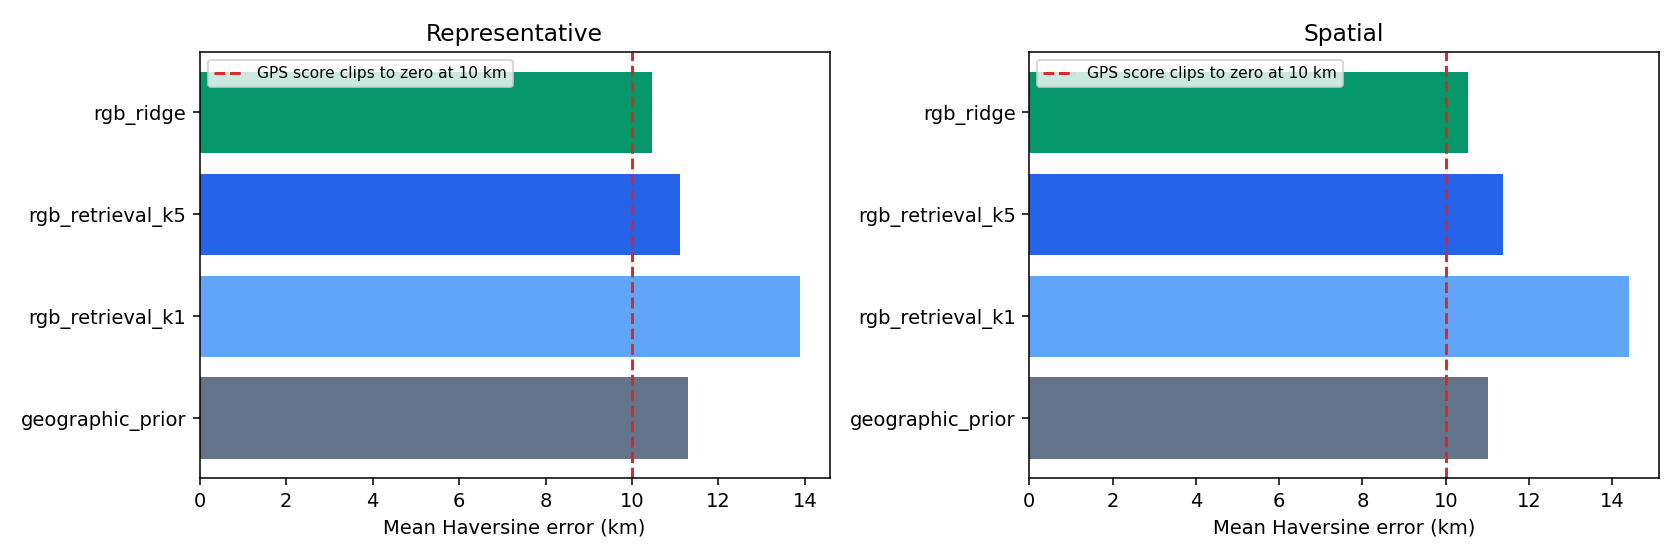

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for index, split in enumerate(("representative", "spatial")):
    subset = baseline[baseline.split == split]
    axes[index].barh(subset.model, subset.mean_km, color=["#64748b", "#60a5fa", "#2563eb", "#059669"])
    axes[index].axvline(10, color="#dc2626", linestyle="--", label="GPS score clips to zero at 10 km")
    axes[index].set(title=split.capitalize(), xlabel="Mean Haversine error (km)")
    axes[index].legend(fontsize=8)
fig.tight_layout()
(ROOT / "outputs/figures").mkdir(exist_ok=True)
fig.savefig(ROOT / "outputs/figures/baseline_summary.png", dpi=140)
display(DisplayImage(filename=str(ROOT / "outputs/figures/baseline_summary.png")))
plt.close(fig)

## Experiment decisions and local progression

**Current retained validation baseline:** frozen StreetCLIP plus Compass fusion on the full training fold, representative score **0.546915**, trained on 9,492 locations. The reduced-training StreetCLIP score was **0.425715**. The earlier full-fold ResNet18 Compass result was **0.173473** and the earlier frozen nonlinear head scored **0.125677**. See the matched StreetCLIP comparison below for fair training-set comparisons. The earlier full-fold warm-start V2 head scored **0.04624**. The fixed validation fold is reused for development; no spatial CNN stress-test result or public-leaderboard score is available.

The first conditional-offset CNN pilot completed two epochs within its five-minute local budget. Validation mean GPS error worsened from **15.48 to 17.30 km** while training loss decreased; borough predictions collapsed to Queens. Its best learned-retrieval score, **0.02255**, was below RGB k=5's **0.03439**. We reject V1 for final fitting.

A decoder-only change on frozen V1 weights reduced error to **11.38 km**, with GPS score still zero. V2 then added direct Haversine supervision of the probability-weighted decoded coordinate. With the same split, seed, resolution 128, width 16, batch 16, five-epoch schedule and five-minute cap, its two completed epochs gave **11.30 then 11.14 km**. Borough Macro-F1 rose to **0.22027**, but GPS remained zero. V2's best learned retrieval scored **0.02885**, still below the RGB control. Reject V2 for final refitting; this short pilot does not establish its fully trained potential.

The inexpensive supervised RGB ridge control used one predeclared penalty **100** and training-fold-only normalization/targets. It achieved **score 0.03687, Macro-F1 0.36868, mean 10.4538 km** on representative validation; spatial validation gave **0.03487, 0.34869, 10.5260 km**. It improves over RGB retrieval but still earns **zero GPS score**. Retain it as the strongest measured control, not as a competitive submission. No hyperparameter search or test-label access was used. Staten Island remains especially poor (representative mean 25.39 km), motivating borough-wise error monitoring in the next full CNN run.

Full-resolution training remains intended for an allocated HPC GPU. Torch scheduling is blocked by the missing project Slurm account; remote environment/data staging are incomplete. The **0.90 target remains unmet**. These comparisons reuse development validation and are not independent test estimates.

**HPC-scale proposal:** once the course allocation is available, run the existing decoded-GPS CNN at 224 pixels/width 32 for at most 20 epochs or 60 training minutes, preserving the representative split and reporting each completed epoch. Inspect the first epochs for borough collapse and GPS improvement before extending compute. A spatial CNN fit must use its own training fold; do not reuse representative-fitted weights as a spatial validation result.

### Local continuation: predeclared experiment

While the TA resolves the Torch allocation, test whether more completed epochs on a reduced training fold improve learning. Use a fixed, borough-proportional **2,048-location subset** drawn solely from representative training IDs, **eight locations/batch**, **128-pixel** images, **width 16**, fresh random initialization, the existing decoded-GPS V2 loss, and at most **20 epochs / eight minutes**, with patience six. Keep all **2,372 validation locations**. Matched priors, RGB retrieval and ridge controls use precisely the same training IDs. This changes training-set size and schedule relative to earlier pilots, so it is a feasibility experiment rather than an isolated architecture ablation. Reduced-fold checkpoints cannot authorize a final refit. The run completed **11 epochs** before its timer interrupted epoch 12. Best head (epoch 10): **score 0.03247, Macro-F1 0.32470, mean 10.4212 km**. Matched RGB ridge: **0.03521, 0.35213, 10.9142 km**. Thus the CNN reduces GPS error but still loses on the clipped composite score. Learned k=5 retrieval scored **0.03334**, mean **11.3253 km**. Every GPS score remains zero. Preserve the checkpoint for diagnostics; do not refit for submission.


**Next predeclared diagnostic:** freeze the selected local checkpoint and fit ridge (penalty 100) to its learned vectors, standardizing each feature using training-fold statistics with a `1e-6` floor. Evaluate on the same validation IDs and report deterministic training-head error to distinguish underfitting from generalization failure. This performed no additional CNN updates. Measured result: **score 0.03377, mean 10.4979 km**, still GPS zero. Reject this decoder as an improvement to the CNN head. Deterministic head error on the 2,048 training locations was **10.1803 km**, close to validation **10.4212 km**; this suggests underfitting rather than a large train/validation gap. This development diagnostic is not connected to final CSV export.


**Tiny-fit diagnostic:** attempt to memorize 40 locations selected solely from the representative training fold. Use width eight, 64 pixels, eight geographic cells, batch eight, no augmentation/dropout, learning rate 0.003 and at most 400 optimizer steps/two minutes. Evaluate only these same 40 training locations, with all four views retained. This checks learnability of the implementation; it is tagged smoke/diagnostic and excluded from held-out comparisons, final selection and CSV export. Completed **400 updates in 20.80 seconds**: training error fell from **12.4461 to 0.8373 km**, and training borough Macro-F1 reached **1.0**. The final **0.92464 training score is memorization evidence only**; it does **not** meet the public-leaderboard target. Finite gradients, the tiny-fit result and the small main-run train/validation gap support further optimization rather than claiming a broken implementation or demonstrated generalization.



### More-data local experiment — predeclared

The user requested improved local score using more data. Expand from 2,048 to **all 9,492 representative training locations** (4.63 times as many), keeping the same **2,372 validation locations**. Initialize from the epoch-10 reduced-fold checkpoint (`20261114T143039_cnn_representative_local2048/best.pth`), whose training IDs are checked as a subset of this fold. Freeze its training-derived geographic cells/origin so learned cell indices retain meaning. Use the same V2 model/loss, width 16, 128-pixel inputs, batch 16, fresh AdamW at **0.0005**, cosine horizon **12 further epochs**, patience four, and a **15-minute** cap plus post-training evaluation overhead. No validation label enters initialization or geography fitting. Batch progress is recorded so long epochs remain observable. This is a staged-training feasibility experiment: data size, additional updates, batch size and learning-rate schedule change together; do not attribute gains solely to more data. Final refitting must replay the same initialization checkpoint and schedule horizon rather than silently starting from random weights. Completed **seven full epochs in 900.02 seconds**, stopping during epoch eight. Best checkpoint: warm-stage epoch six, **score 0.04624, Macro-F1 0.38185, GPS score 0.00895, mean 9.9105 km, median 8.3117 km, p90 18.2430 km**. The head beats the previous full-fold RGB ridge score **0.03687**, with the first positive held-out GPS score. Learned k=1 and k=5 retrieval scored **0.03497 / 0.03625**, with mean errors **13.5960 / 10.7414 km**. Preserve the head as the best measured development method so far. The 0.90 target remains unmet; spatial stress validation of this staged method has not been run.


**Final fixed decoder comparison:** apply the existing frozen-feature ridge diagnostic (penalty 100, training-fold standard deviation floor 1e-6) to the selected full-fold checkpoint. This reuses the method specification tested on the smaller model; no hyperparameter search or CNN updates occur. Measured result: **score 0.03750, Macro-F1 0.37501, GPS score zero, mean 10.0699 km**. Reject it as an improvement to the head. The result remains a development diagnostic and is not connected to final export. Deterministic head training error is **9.7883 km** versus validation **9.9105 km**. Staten Island still has **zero borough F1**, training/validation mean errors **27.8534 / 28.0964 km**, despite 669 training examples. This suggests persistent underfitting of that borough rather than a large overall train/validation gap; the cause is not established.


**Next controlled local experiment:** test stronger borough auxiliary supervision on the same full training fold, preserving GPS loss, architecture and validation IDs. Hypothesis: the current 0.2 borough-loss weight provides insufficient shared-feature supervision for poorly learned boroughs. Predeclare the new weight, initialization and small budget; compare with continued training at the existing weight to distinguish the objective change from extra updates. Do not claim this cause or proposed fix is established by the current results.


In [54]:
PREVIOUS_CHECKPOINT = os.environ.get("NYCGUESSR_COMPARE_CHECKPOINT", "")
if PREVIOUS_CHECKPOINT:
    device = choose_device(os.environ.get("NYCGUESSR_DEVICE", "auto"))
    comparison_model, previous = load_checkpoint(ROOT / PREVIOUS_CHECKPOINT, ROOT, device)
    assert previous["split"] != "full" and not previous["config"]["smoke"]
    comparison_model.gps_decoder = "posterior_mean"
    comparison_frame, _ = load_data(ROOT)
    held_out = comparison_frame.loc[previous["validation_ids"]]
    started = time.monotonic()
    comparison, _ = predict_loader(comparison_model,
        make_loader(FourViewDataset(ROOT, held_out, previous["geography"], image_size=previous["config"]["image_size"]),
                    previous["config"]["batch_size"], 0), device)
    comparison_metrics = score_predictions(held_out, comparison)
    record_run(ROOT, f"{Path(PREVIOUS_CHECKPOINT).parent.name}_decoder_only", "cnn_decoder_only_control",
               previous["split"], comparison_metrics, {"training_changed": False, "decoder": "posterior_mean"},
               time.monotonic() - started, {"checkpoint": PREVIOUS_CHECKPOINT},
               "Compare decoder-only change separately from the new training objective.")
    print("Decoder-only control:", comparison_metrics)
    del comparison_model


In [55]:
RUN_TRAINING = os.environ.get("NYCGUESSR_RUN_TRAINING", "0") == "1"
TRAIN_SPLIT = os.environ.get("NYCGUESSR_SPLIT", "representative")
GPU_BUDGET_MINUTES = float(os.environ.get("NYCGUESSR_MAX_MINUTES", "60"))
EPOCHS = int(os.environ.get("NYCGUESSR_EPOCHS", "20"))
DEVICE = os.environ.get("NYCGUESSR_DEVICE", "auto")
IMAGE_SIZE = int(os.environ.get("NYCGUESSR_IMAGE_SIZE", "224"))
WIDTH = int(os.environ.get("NYCGUESSR_WIDTH", "32"))
BATCH_SIZE = int(os.environ.get("NYCGUESSR_BATCH_SIZE", "8"))
WORKERS = int(os.environ.get("NYCGUESSR_WORKERS", "0"))
TRAIN_LIMIT = int(os.environ["NYCGUESSR_TRAIN_LIMIT"]) if os.environ.get("NYCGUESSR_TRAIN_LIMIT") else None
EXISTING_CHECKPOINT = os.environ.get("NYCGUESSR_CHECKPOINT")
INITIALIZATION_CHECKPOINT = os.environ.get("NYCGUESSR_INITIALIZATION_CHECKPOINT")
LEARNING_RATE = float(os.environ.get("NYCGUESSR_LEARNING_RATE", ".001"))
RUN_SMOKE = os.environ.get("NYCGUESSR_SMOKE", "0") == "1"
if RUN_SMOKE:
    smoke_checkpoint = train_model(ROOT, smoke=True, workers=0, max_minutes=2)
    print("Smoke checkpoint (not a performance estimate):", smoke_checkpoint)
checkpoint = EXISTING_CHECKPOINT
selection = None
if RUN_TRAINING:
    assert choose_device(DEVICE).type in ("cuda", "mps"), "Use an available GPU; full CPU training is disabled"
    checkpoint = train_model(ROOT, TRAIN_SPLIT, epochs=EPOCHS, image_size=IMAGE_SIZE, width=WIDTH,
                             cells=64, batch_size=BATCH_SIZE, workers=WORKERS,
                             max_minutes=GPU_BUDGET_MINUTES, device_name=DEVICE, train_limit=TRAIN_LIMIT,
                             patience=int(os.environ.get("NYCGUESSR_PATIENCE", "4")), learning_rate=LEARNING_RATE,
                             initialization_checkpoint=ROOT / INITIALIZATION_CHECKPOINT if INITIALIZATION_CHECKPOINT else None)
if checkpoint is not None:
    selection = evaluate_checkpoint(ROOT, Path(checkpoint), device_name=DEVICE)
    print(Path(selection).read_text())
else:
    print("Training disabled. Saved pilot results appear in the tracker below; configure an allocated HPC GPU for the full run.")
CALIBRATE_CHECKPOINT = os.environ.get("NYCGUESSR_CALIBRATE_CHECKPOINT")
if CALIBRATE_CHECKPOINT:
    calibration_report = calibrate_frozen_features(ROOT, ROOT / CALIBRATE_CHECKPOINT, device_name=DEVICE)
    print(calibration_report.read_text())

RUN_FIT_DIAGNOSTIC = os.environ.get("NYCGUESSR_FIT_DIAGNOSTIC", "0") == "1"
if RUN_FIT_DIAGNOSTIC:
    tiny_fit_report = diagnose_tiny_fit(ROOT, device_name=DEVICE)
    print(tiny_fit_report.read_text())


Training disabled. Saved pilot results appear in the tracker below; configure an allocated HPC GPU for the full run.


## Permitted ImageNet transfer experiment

Hypothesis: fixed ImageNet representations improve geolocation and reduce repeated training cost compared with the scratch CNN. Compare fixed ridge (penalty 100), k=5 retrieval and an ordered four-view nonlinear head on both existing splits. The feature pass uses no Q4 labels; each learned stage uses only its own training IDs. Downloads, extraction and training are disabled by default. No test data or submission is needed for this experiment. Measured results: one-time extraction **168.87 s**, **97,190,016 bytes (~92.69 MiB)**, **70.25 locations/s**. Subsequent cached rerun completed both folds' baselines/head fits in **22.12 s**. Representative nonlinear head: best **epoch 7**, early-stopped after 19, **9.70 s** total head fit; score **0.125677**, Macro-F1 **0.503440**, GPS score **0.083703**, mean/median/p90 **9.16297/7.22868/18.94064 km**. Spatial head: best **epoch 2**, early-stopped after 14, **6.73 s**; score **0.110306**, Macro-F1 **0.476462**, mean/median/p90 **9.30378/7.84433/18.09371 km**. These use independently fitted heads, feature statistics, geography and training references; the common ImageNet encoder was frozen before seeing Q4 labels. Both splits are development evidence after this comparison, not untouched tests.

Fixed ImageNet ridge/retrieval scored only **0.04366/0.04388** representative and **0.04404/0.04140** spatial. The nonlinear head is retained. It improves over scratch CNN **0.04624**, but the **0.90 target remains unmet**. Staten Island representative F1 improved from zero to **0.32484**, while mean error remains **24.1493 km**; this is still a major failure.

The first trial exposed two notebook/metadata issues: class-source inspection and a TorchVersion object in checkpoint metadata. They were fixed, covered by cache and weights-only reload checks, and the full experiment was rerun from the verified cache. The superseded trial remains documented under its run folder; canonical selected runs are listed in `outputs/imagenet_transfer_metrics.csv`.


In [56]:
RUN_IMAGENET_TRANSFER = os.environ.get("NYCGUESSR_RUN_IMAGENET_TRANSFER", "0") == "1"
ALLOW_IMAGENET_DOWNLOAD = os.environ.get("NYCGUESSR_ALLOW_IMAGENET_DOWNLOAD", "0") == "1"
if RUN_IMAGENET_TRANSFER:
    imagenet_results = run_imagenet_transfer(ROOT, device_name=os.environ.get("NYCGUESSR_DEVICE", "auto"),
                        allow_download=ALLOW_IMAGENET_DOWNLOAD,
                        extraction_minutes=float(os.environ.get("NYCGUESSR_EXTRACTION_MINUTES", "20")),
                        head_minutes=float(os.environ.get("NYCGUESSR_HEAD_MINUTES", "3")))
    print(imagenet_results.to_string(index=False))
elif (ROOT / "outputs/imagenet_transfer_metrics.csv").exists():
    print(pd.read_csv(ROOT / "outputs/imagenet_transfer_metrics.csv").to_string(index=False))
else:
    print("ImageNet transfer experiment is disabled; no weights are downloaded automatically.")


         split                method                                               run_id    score  borough_macro_f1  gps_score   mean_km  median_km    p90_km
representative                 ridge        20261114T165240_imagenet_ridge_representative 0.043663          0.436629   0.000000 10.819641   9.375521 20.008884
representative          retrieval_k5 20261114T165240_imagenet_retrieval_k5_representative 0.043878          0.438778   0.000000 10.255331   8.687218 19.796570
representative frozen_nonlinear_head         20261114T165241_imagenet_head_representative 0.125677          0.503440   0.083703  9.162969   7.228682 18.940638
       spatial                 ridge               20261114T165240_imagenet_ridge_spatial 0.044037          0.440369   0.000000 10.950067   9.929899 19.732514
       spatial          retrieval_k5        20261114T165240_imagenet_retrieval_k5_spatial 0.041396          0.413959   0.000000 10.399347   9.011126 19.658964
       spatial frozen_nonlinear_head          

In [57]:
RUN_SELECTIVE_FINETUNE = os.environ.get("NYCGUESSR_RUN_SELECTIVE_FINETUNE", "0") == "1"
if RUN_SELECTIVE_FINETUNE:
    selected_feature_head = os.environ.get("NYCGUESSR_FEATURE_HEAD_CHECKPOINT")
    assert selected_feature_head, "Provide the exact validated frozen-head checkpoint"
    selective_results = run_selective_finetune(ROOT, ROOT / selected_feature_head,
                                device_name=os.environ.get("NYCGUESSR_DEVICE", "auto"), max_minutes=5.)
    print(selective_results.to_string(index=False))
elif (ROOT / "outputs/imagenet_selective_metrics.csv").exists():
    print(pd.read_csv(ROOT / "outputs/imagenet_selective_metrics.csv").to_string(index=False))

    for candidate in pd.read_csv(ROOT / "outputs/imagenet_selective_metrics.csv").itertuples(index=False):
        if candidate.method == "last_block_finetune":
            print("Adaptation audit:", audit_selective_parameter_changes(ROOT, ROOT / "outputs/runs" / candidate.run_id / "checkpoint.pth"))


                   method                                                   run_id  training_seconds    score  borough_macro_f1  gps_score  mean_km  median_km    p90_km
head_continuation_control 20261114T165759_head_continuation_control_representative          6.735920 0.113385          0.498239   0.070623 9.293767   7.482186 18.881289
      last_block_finetune       20261114T165759_last_block_finetune_representative        154.611954 0.113833          0.507127   0.070133 9.298668   7.172486 19.499614
Adaptation audit: {'changed_encoder_tensors': ['layer4.1.conv1.weight', 'layer4.1.bn1.weight', 'layer4.1.bn1.bias', 'layer4.1.conv2.weight', 'layer4.1.bn2.weight', 'layer4.1.bn2.bias'], 'verified_frozen_encoder_tensors': 94, 'adapted_model_strict_reload': True, 'all_batchnorm_running_statistics_unchanged': True, 'head_normalization_and_geography_unchanged': True, 'source_checkpoint_sha256': '0642a08dfe2bc598612a1f69dff663d10f34e3cd8855052a2c0685045f9ef4f7', 'adapted_checkpoint_sha256': '2

         split                                         run_id  epoch      decoder    score  borough_macro_f1  gps_score  mean_km  median_km    p90_km
representative 20261116T131621_compass_local20_representative     20 mixed_median 0.173473          0.547141   0.131954 8.680456   5.816619 19.250590
       spatial        20261116T131653_compass_local20_spatial     20    cell_mean 0.144900          0.534745   0.101584 8.984159   8.158286 16.920053


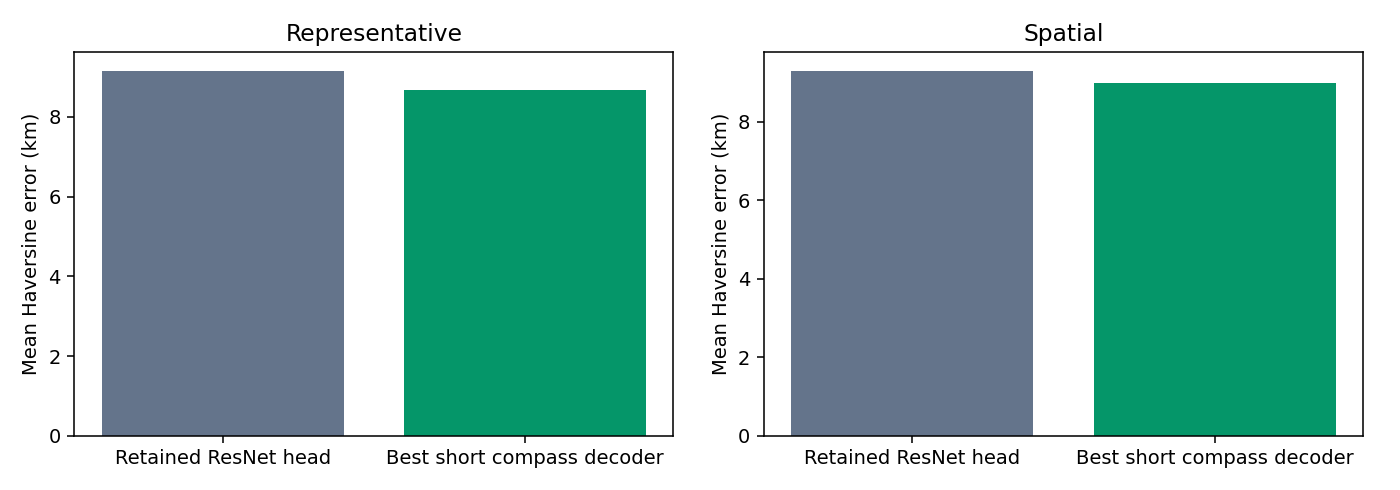

In [27]:
RUN_LOCAL_SHORT = os.environ.get("NYCGUESSR_RUN_LOCAL_SHORT", "0") == "1"
RUN_LOCAL_ALL_LABELS = os.environ.get("NYCGUESSR_LOCAL_ALL_LABELS", "0") == "1"
if RUN_LOCAL_SHORT:
    full_frame, _ = load_data(ROOT)
    cached, cache_info = extract_imagenet_features(ROOT, full_frame, device_name=DEVICE, allow_download=False)
    rows, candidates = [], {}
    for fold in ("representative", "spatial"):
        path = train_compass_head(ROOT, full_frame, cached, cache_info, fold, epochs=20, max_minutes=5., device_name=DEVICE)
        _, fitted = load_compass_head(ROOT, path, torch.device("cpu"))
        candidates[fold] = path
        rows.append({"split": fold, "run_id": path.parent.name, "epoch": fitted["epoch"], "decoder": fitted["decoder"],
                     **{k:v for k,v in fitted["metrics"].items() if k != "borough_metrics"}})
    save_json(ROOT / "outputs/local20_selection.json", {"checkpoints": {k:str(v.relative_to(ROOT)) for k,v in candidates.items()}})
    pd.DataFrame(rows).to_csv(ROOT / "outputs/local20_metrics.csv", index=False)
if (ROOT / "outputs/local20_metrics.csv").exists():
    short_results = pd.read_csv(ROOT / "outputs/local20_metrics.csv")
    print(short_results.to_string(index=False))
    old_results = pd.read_csv(ROOT / "outputs/imagenet_transfer_metrics.csv")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for axis, fold in zip(axes, ("representative", "spatial")):
        old = old_results.loc[(old_results.split == fold) & (old_results.method == "frozen_nonlinear_head")].iloc[0]
        new = short_results.loc[short_results.split == fold].iloc[0]
        axis.bar(["Retained ResNet head", "Best short compass decoder"], [old.mean_km, new.mean_km], color=['#64748b', '#059669'])
        axis.set(title=fold.capitalize(), ylabel="Mean Haversine error (km)")
    fig.tight_layout()
    fig.savefig(ROOT / "outputs/figures/local20_summary.png", dpi=140)
    display(DisplayImage(filename=str(ROOT / "outputs/figures/local20_summary.png")))
    plt.close(fig)
if RUN_LOCAL_ALL_LABELS:
    require((ROOT / "outputs/local20_metrics.csv").exists(), "Compare development results before all-label refit")
    full_frame, _ = load_data(ROOT)
    cached, cache_info = extract_imagenet_features(ROOT, full_frame, device_name=DEVICE, allow_download=False)
    row = pd.read_csv(ROOT / "outputs/local20_metrics.csv").query("split == 'representative'").iloc[0]
    old = pd.read_csv(ROOT / "outputs/imagenet_transfer_metrics.csv")
    best_old = old.query("split == 'representative' and method == 'frozen_nonlinear_head'").iloc[0]
    if row.score > best_old.score:
        source = ROOT / "outputs/runs" / row.run_id / "best.pth"
        final_path = train_compass_head(ROOT, full_frame, cached, cache_info, "full", max_minutes=5., device_name=DEVICE, refit_source=source)
        _, final_state = load_compass_head(ROOT, final_path, torch.device("cpu"))
    else:
        source = ROOT / "outputs/runs" / best_old.run_id / "best.pth"
        final_path = train_frozen_head(ROOT, full_frame, cached, cache_info, "full", max_minutes=3., device_name=DEVICE, refit_source=source)
        _, final_state = load_frozen_feature_head(ROOT, final_path, torch.device("cpu"))
    require(final_state["fit_complete"] and set(final_state["train_ids"]) == set(full_frame.sample_id), "Incomplete final fit")
    save_json(ROOT / "outputs/local_all_labels_fit.json", {"checkpoint": str(final_path.relative_to(ROOT)),
        "checkpoint_sha256": sha256(final_path), "source_checkpoint": str(source.relative_to(ROOT)),
        "training_locations": len(final_state["train_ids"]), "epochs": final_state["epoch"],
        "fit_complete": True, "held_out_metrics": None, "test_inference_performed": False})
    print("All-label fit:", (ROOT / "outputs/local_all_labels_fit.json").read_text())


Artifact audit: {
  "folds": [
    {
      "split": "representative",
      "train": 9492,
      "validation": 2372,
      "selected_decoder": "mixed_median",
      "checkpoint_sha256": "445b673d3e88e3e00488306f7c4227831bba48dd8a58689c857c44a825010d33",
      "csv_score_verified": true
    },
    {
      "split": "spatial",
      "train": 8716,
      "validation": 2421,
      "selected_decoder": "cell_mean",
      "checkpoint_sha256": "5cb52b28eb5f02582c37518534ba1e7240daaa5d7e51c7b68ca783b62c1c12f6",
      "csv_score_verified": true
    }
  ],
  "all_label_fit_complete": true,
  "all_label_locations": 11864,
  "all_label_epochs": 20,
  "all_label_fit_seconds": 26.523201917065307,
  "all_label_checkpoint": "outputs/runs/20261116T131721_compass_local20_full/best.pth",
  "all_label_checkpoint_sha256": "8a763ed6d46247e0329859a8fb130052ab206d1609205757231dc761597f7609",
  "common_decoder": "mixed_median",
  "held_out_metrics_for_full_fit": null,
  "test_inference_performed": false,
  "trai

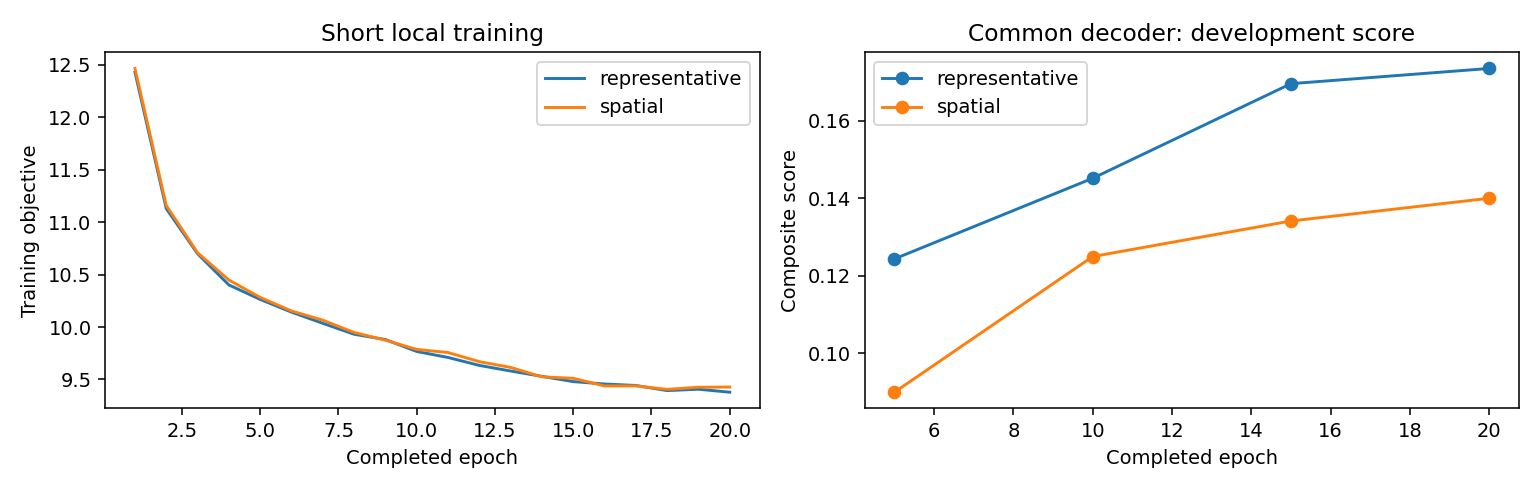

In [28]:
def audit_short_local_training(root):
    """Check actual artifacts, fold isolation, scored CSVs and all-label completion."""
    frame, _ = load_data(root)
    split_state = json.loads((root / "outputs/splits.json").read_text())["splits"]
    selection = json.loads((root / "outputs/local20_selection.json").read_text())["checkpoints"]
    final = json.loads((root / "outputs/local_all_labels_fit.json").read_text())
    data_rows, common_rows = [], []
    _, representative = load_compass_head(root, root / selection["representative"], torch.device("cpu"))
    common_decoder = representative["decoder"]
    for fold, relative_path in selection.items():
        path = root / relative_path
        model, saved = load_compass_head(root, path, torch.device("cpu"))
        frozen = split_state[fold]
        require(saved["train_ids"] == frozen["train_ids"] and saved["validation_ids"] == frozen["validation_ids"], "Checkpoint IDs changed")
        require(not (set(saved["train_ids"]) & set(saved["validation_ids"]) or set(saved["train_ids"]) & set(frozen["excluded_buffer_ids"])), "Fold leakage")
        cache_paths = list((root / "outputs/features").glob(f'imagenet_resnet18_train_{saved["config"]["feature_cache_key"][:16]}.npy'))
        require(len(cache_paths) == 1 and sha256(cache_paths[0]) == saved["config"]["feature_cache_sha256"], "Feature artifact changed")
        features = np.load(cache_paths[0], mmap_mode="r")
        positions = pd.Series(np.arange(len(frame)), index=frame.sample_id).loc[saved["train_ids"]].to_numpy()
        values = np.asarray(features[positions])
        np.testing.assert_allclose(model.feature_mean.numpy(), values.mean(axis=0), rtol=0, atol=1e-6)
        np.testing.assert_allclose(model.feature_std.numpy(), np.maximum(values.std(axis=0), .05), rtol=0, atol=1e-6)
        np.testing.assert_allclose(saved["geography"]["origin"], frame.loc[saved["train_ids"], ["latitude", "longitude"]].mean(), rtol=0, atol=1e-10)
        prediction = pd.read_csv(path.parent / "validation_best.csv")
        metrics = score_predictions(frame.loc[saved["validation_ids"]], prediction)
        for name in ("score", "borough_macro_f1", "gps_score", "mean_km", "median_km", "p90_km"):
            require(abs(metrics[name] - saved["metrics"][name]) < 1e-9, f"Scored CSV mismatch: {name}")
        history = json.loads((path.parent / "history.json").read_text())["epochs"]
        require(len(history) == 20 and all(row["unique_anchor_locations"] == len(saved["train_ids"]) for row in history), "Incomplete full-fold epoch")
        source = json.loads((path.parent / "source_notebook.ipynb").read_text())
        code = "\n\n".join("".join(cell["source"]) for cell in source["cells"] if cell["cell_type"] == "code")
        source_hash = hashlib.sha256(code.encode()).hexdigest()
        records = [json.loads(line) for line in (root / "outputs/experiment_log.jsonl").read_text().splitlines()]
        logs = [row for row in records if row["run_id"].startswith(path.parent.name)]
        require(bool(logs) and all(row["code_sha256"]["NYCGuessr.ipynb_code"] == source_hash for row in logs), "Run/source hash mismatch")
        at_selected_epoch = next(row for row in history if row["epoch"] == saved["epoch"])
        common_metrics = at_selected_epoch["metrics"][common_decoder]
        common_rows.append({"split": fold, "epoch": saved["epoch"], "decoder": common_decoder,
                            **{k:v for k,v in common_metrics.items() if k != "borough_metrics"}})
        data_rows.append({"split": fold, "train": len(saved["train_ids"]), "validation": len(saved["validation_ids"]),
                          "selected_decoder": saved["decoder"], "checkpoint_sha256": sha256(path), "csv_score_verified": True})
    model, full = load_compass_head(root, root / final["checkpoint"], torch.device("cpu"))
    require(sha256(root / final["checkpoint"]) == final["checkpoint_sha256"], "Final checkpoint bytes changed")
    require(full["fit_complete"] and full["split"] == "full" and full["epoch"] == 20 and full["validation_ids"] == [], "Final fit incomplete")
    require(full["train_ids"] == frame.sample_id.tolist() and full["metrics"] == {}, "Final fit rows/metric contract")
    require(full["decoder"] == common_decoder and full["config"]["schedule_epochs"] == 20, "Final decode/schedule differs")
    np.testing.assert_allclose(model.feature_mean.numpy(), np.asarray(features).mean(axis=0), rtol=0, atol=1e-6)
    np.testing.assert_allclose(model.feature_std.numpy(), np.maximum(np.asarray(features).std(axis=0), .05), rtol=0, atol=1e-6)
    np.testing.assert_allclose(full["geography"]["origin"], frame[["latitude", "longitude"]].mean(), rtol=0, atol=1e-10)
    full_history = json.loads((root / final["checkpoint"]).parent.joinpath("history.json").read_text())["epochs"]
    require(len(full_history) == 20 and all(row["unique_anchor_locations"] == 11864 for row in full_history), "All-label epochs did not cover every location")
    full_status = json.loads((root / final["checkpoint"]).parent.joinpath("status.json").read_text())
    report = {"folds": data_rows, "all_label_fit_complete": True, "all_label_locations": 11864, "all_label_epochs": 20,
              "all_label_fit_seconds": full_status["elapsed_seconds"], "all_label_checkpoint": final["checkpoint"],
              "all_label_checkpoint_sha256": final["checkpoint_sha256"], "common_decoder": common_decoder,
              "held_out_metrics_for_full_fit": None, "test_inference_performed": False,
              "training_data_sha256": sha256(root / "Data/train.csv"), "split_sha256": sha256(root / "outputs/splits.json"),
              "input_manifest_sha256": sha256(root / "outputs/input_manifest.jsonl")}
    save_json(root / "outputs/local20_artifact_audit.json", report)
    pd.DataFrame(common_rows).to_csv(root / "outputs/local20_common_decoder_metrics.csv", index=False)
    return report, pd.DataFrame(common_rows)


if (ROOT / "outputs/local_all_labels_fit.json").exists():
    artifact_audit, fixed_decoder_results = audit_short_local_training(ROOT)
    print("Artifact audit:", json.dumps(artifact_audit, indent=2))
    print("Same decoder on both independently fitted folds:")
    print(fixed_decoder_results.to_string(index=False))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    checkpoints = json.loads((ROOT / "outputs/local20_selection.json").read_text())["checkpoints"]
    for fold, relative_path in checkpoints.items():
        history = json.loads((ROOT / relative_path).parent.joinpath("history.json").read_text())["epochs"]
        axes[0].plot([row["epoch"] for row in history], [row["mean_training_loss"] for row in history], label=fold)
        scored = [row for row in history if row["metrics"]]
        axes[1].plot([row["epoch"] for row in scored], [row["metrics"][artifact_audit["common_decoder"]]["score"] for row in scored], marker='o', label=fold)
    axes[0].set(title="Short local training", xlabel="Completed epoch", ylabel="Training objective")
    axes[1].set(title="Common decoder: development score", xlabel="Completed epoch", ylabel="Composite score")
    for axis in axes:
        axis.legend()
    fig.tight_layout()
    fig.savefig(ROOT / "outputs/figures/local20_learning.png", dpi=140)
    display(DisplayImage(filename=str(ROOT / "outputs/figures/local20_learning.png")))
    plt.close(fig)


## Measured short local outcome — 2026-11-16

Completed all 20 epochs on local MPS for each fold: representative **31.83 s**, spatial **25.81 s**. Representative score **0.173473**, Macro-F1 **0.547141**, GPS score **0.131954**, mean/median/p90 **8.68046/5.81662/19.25059 km**, using the fixed mixed-cell/neighbor median and borough head. Earlier frozen head: **0.125677**, mean **9.16297 km**. Retain the new method for this development comparison, while preserving every earlier checkpoint. Representative p90 worsens from **18.94064 to 19.25059 km**, despite better mean and median; Staten Island remains difficult (**23.2004 km** mean).

With exactly the same mixed decoder on independently fitted spatial weights: **score 0.139982**, Macro-F1 **0.534745**, GPS score **0.096119**, mean/median/p90 **9.03881/6.91978/19.30385 km**. This improves earlier spatial score **0.110306**, mean **9.30378 km**, though tail error worsens. The spatial fold's separately selected best decoder is cell mean (**0.144900**, **8.98416 km**); do not present that different decoder as the production mixed method's result. Median/geographic-vote decoding is not universally superior.

The final fresh all-label head completed **20 epochs on all 11,864 locations in 26.52 s**, encoder frozen, 266,757 trainable parameters. Its checkpoint is `outputs/runs/20261116T131721_compass_local20_full/best.pth`, SHA-256 `8a763ed6d46247e0329859a8fb130052ab206d1609205757231dc761597f7609`. It preserves the original 20-epoch schedule and selected mixed decoder, recomputes cells/normalization on all labels, and has **no held-out performance estimate**. The complete fresh-kernel training notebook ran 24 code cells/25 checks without errors in **91.82 s**. Times use cached features and exclude the earlier one-time ImageNet extraction; peak RAM/VRAM was not measured.

No external weights/data, dependency install, test-image pass, test prediction CSV, Kaggle upload or HPC job was used in this task. The new Compass checkpoint is not yet connected to the legacy final-CSV exporter; any later implementation must distinguish overlapping numeric train/test IDs by dataset namespace. Current validation decoders explicitly require disjoint training/validation IDs. This score is far below the 0.90 target. The next useful comparison is a stronger approved pretrained encoder under a bounded local extraction benchmark, rather than assuming more epochs fix weak representations. This is a hypothesis, not an automatically enabled download or experiment.

Reproduce this run by setting `NYCGUESSR_DEVICE=mps`, `NYCGUESSR_RUN_LOCAL_SHORT=1`, `NYCGUESSR_LOCAL_ALL_LABELS=1` before running this notebook. All three training stages are capped; these two execution flags default to zero. Run-specific notebook snapshots and structured logs preserve the exact original training code. Later edits only fix warnings, embed figures and add artifact verification; final default execution reuses saved results without retraining.


In [29]:
@torch.inference_mode()
def benchmark_streetclip_batches(root, frame, device_name="auto"):
    """Two bounded batching trials; all GPU trial/warm-up time debits the same budget."""
    device = choose_device(device_name)
    model, preprocess, encoder = load_streetclip_encoder(root, device, allow_download=False)
    budget_path = root / "outputs/features/streetclip_gpu_budget.json"
    budget = json.loads(budget_path.read_text())
    started, rows = time.monotonic(), []
    try:
        for batch_size in (4, 8):
            require(budget["used_seconds"] + time.monotonic()-started < 3600, "Extraction budget exhausted")
            loader = make_loader(ImageNetViews(root, frame.iloc[:32], preprocess), batch_size, workers=0)
            warm = next(iter(loader))["images"].to(device=device,dtype=next(model.parameters()).dtype)
            result = model(pixel_values=warm.flatten(0,1)).pooler_output
            synchronize_device(device)
            require(bool(torch.isfinite(result).all()), "Nonfinite larger-batch warm-up")
            del warm,result
            measured, peak, count = time.monotonic(), 0, 0
            for batch in loader:
                image = batch["images"].to(device=device,dtype=next(model.parameters()).dtype)
                result = model(pixel_values=image.flatten(0,1)).pooler_output
                require(bool(torch.isfinite(result).all()), "Nonfinite larger-batch output")
                synchronize_device(device)
                count += len(image)*4
                if device.type == "mps":
                    peak=max(peak,torch.mps.driver_allocated_memory())
                    require(peak <= 8*1024**3, "Larger batch exceeded sampled eight-GiB memory cap")
            elapsed = time.monotonic()-measured
            rows.append({"batch_locations":batch_size,"images":count,"seconds":elapsed,
                         "images_per_second":count/elapsed,"sampled_peak_mps_driver_bytes":peak})
            print('Batch benchmark:',rows[-1],flush=True)
            del image,result
            if device.type == "mps":torch.mps.empty_cache()
    finally:
        budget['used_seconds']+=time.monotonic()-started
        save_json(budget_path,budget)
    save_json(root/'outputs/streetclip_batch_benchmark.json',{'trials':rows,'aggregate_budget_used_seconds':budget['used_seconds'],
              'encoder':encoder})
    return rows


if os.environ.get('NYCGUESSR_STREETCLIP_BATCH_BENCHMARK','0') == '1':
    batch_frame,_=load_data(ROOT)
    print(benchmark_streetclip_batches(ROOT,batch_frame,DEVICE))


In [30]:
RUN_STREETCLIP_BENCHMARK = os.environ.get("NYCGUESSR_STREETCLIP_BENCHMARK", "0") == "1"
RUN_STREETCLIP_EXTRACTION = os.environ.get("NYCGUESSR_STREETCLIP_EXTRACTION", "0") == "1"
ALLOW_STREETCLIP_DOWNLOAD = os.environ.get("NYCGUESSR_ALLOW_STREETCLIP_DOWNLOAD", "0") == "1"
if RUN_STREETCLIP_BENCHMARK or RUN_STREETCLIP_EXTRACTION:
    street_frame, _ = load_data(ROOT)
    street_features, street_report = extract_streetclip_features(ROOT, street_frame, device_name=DEVICE,
            allow_download=ALLOW_STREETCLIP_DOWNLOAD, row_limit=128 if RUN_STREETCLIP_BENCHMARK else None)
    print(json.dumps(street_report, indent=2))
elif (ROOT / "outputs/streetclip_benchmark.json").exists():
    print("Saved StreetCLIP benchmark:", (ROOT / "outputs/streetclip_benchmark.json").read_text())


Saved StreetCLIP benchmark: {
  "status": "pilot_complete",
  "initial_rows": 0,
  "completed_rows": 128,
  "elapsed_seconds": 53.507257124991156,
  "warmup_seconds": 0.6923945840680972,
  "locations_per_second": 2.4235602222919828,
  "sampled_peak_mps_driver_bytes": 2230042624,
  "process_lifetime_max_rss_bytes": 1471037440,
  "aggregate_budget_used_seconds": 53.507126459036954,
  "cache_key": "23f1be61d2b2b2cdc3a675292f89c4e0eeb7be3829401ff4569234e75f25a087",
  "encoder": {
    "model_id": "geolocal/StreetCLIP",
    "revision": "e3561ba2ad9bf14c9efd6b0092607b8497efbfea",
    "weights_sha256": "cf6dc3802a8bf9301560b1aa0cd1fa983b4139f96a1befc43802e387401fe6c0",
    "weights_bytes": 1711981793,
    "config_sha256": "87df4b0f5aa5567c637b3403bb9c53e07427070874fd6fe816a0eed2fb0144e1",
    "preprocess_sha256": "da9f43b1a0d67c29629316528ae2c09275fc530fc7cbbd51ba90c51e2cf5e81a",
    "feature_dimensions": 1024,
    "feature_output": "post_layernorm_pooler_output",
    "dtype": "torch.float16",

## Budget realignment: complete validation, matched training subsets

The 128-location benchmark measured 9.70 images/s; batches of 4/8 locations gave 9.78/9.67 images/s. A full 47,456-image native-336 pass projects to roughly 81 minutes, outside the user's one-hour aggregate extraction budget. Keep native resolution and all four views. Predeclare **6,500 locations**: the union of both full validation sets (4,286 IDs), plus 2,214 borough-proportional locations sampled only from the intersection of the two training folds. Each head uses exactly the original training IDs available in that selected set; exclusions/validation IDs remain out of its training. Compare both encoders on these identical training IDs and original complete validation sets, 20 epochs, fixed mixed decoder for checkpoint selection. This is a reduced-training experiment, not all-training-data StreetCLIP fitting. All subset IDs and counts are persisted before extraction.

Reuse the strict verified ResNet18 cache for the matched control. StreetCLIP's input projection accepts 1024 rather than 512 features, while hidden width/loss/hyperparameters stay unchanged. Record this parameter-count difference. A complete subset cache is distinct from the incomplete full-data pilot cache; incomplete features cannot enter training. Preserve all existing full-training model checkpoints. Download/extraction/head-comparison flags default off.


         split          encoder                                                  run_id  epoch      decoder  training_locations  validation_locations    score  borough_macro_f1  gps_score  mean_km  median_km    p90_km
representative resnet18_matched 20261116T142831_compass_resnet18_matched_representative     20 mixed_median                4128                  2372 0.103119          0.505208   0.058442 9.415576   7.006121 20.140576
representative       streetclip       20261116T142848_compass_streetclip_representative     20 mixed_median                4128                  2372 0.425715          0.692864   0.396031 6.039685   3.314792 15.676792
       spatial resnet18_matched        20261116T142901_compass_resnet18_matched_spatial     20 mixed_median                3926                  2421 0.095326          0.485686   0.051952 9.480476   7.676750 19.177880
       spatial       streetclip              20261116T142914_compass_streetclip_spatial     20 mixed_median                3926 

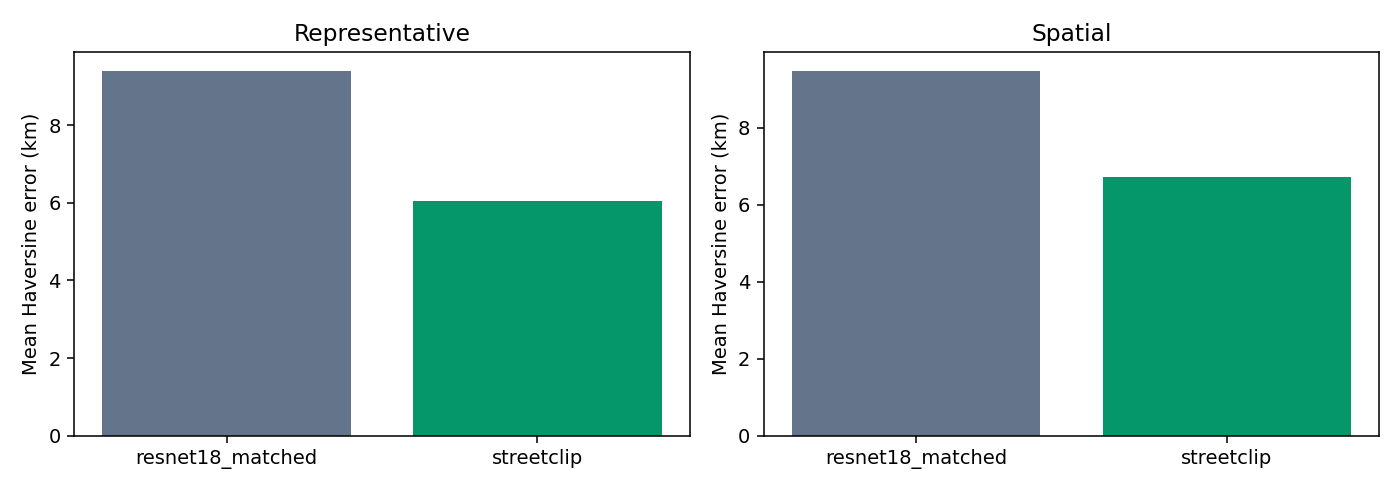

In [31]:
def streetclip_comparison_subset(root, full_frame):
    splits = json.loads((root / "outputs/splits.json").read_text())["splits"]
    validation = set(splits["representative"]["validation_ids"]) | set(splits["spatial"]["validation_ids"])
    common_training = set(splits["representative"]["train_ids"]) & set(splits["spatial"]["train_ids"])
    extra = training_subset(full_frame.loc[sorted(common_training)], 6500-len(validation))
    selected = sorted(validation | set(extra.sample_id))
    ids_by_fold = {name:[i for i in split["train_ids"] if i in set(selected)] for name,split in splits.items()}
    require(len(selected) == 6500 and all(set(split["validation_ids"]) <= set(selected) for split in splits.values()), "Incomplete comparison subset")
    record = {"seed":SEED,"sample_ids":selected,"train_ids":ids_by_fold,
              "validation_ids":{name:split["validation_ids"] for name,split in splits.items()},
              "data_fingerprint":data_fingerprint(root),"split_sha256":sha256(root / "outputs/splits.json"),
              "scope":"6500 locations; complete fixed validations and matched reduced training folds"}
    path=root/'outputs/streetclip_comparison_subset.json'
    if path.exists():require(json.loads(path.read_text()) == record,"Comparison subset drift")
    else:save_json(path,record)
    return full_frame.loc[selected], record


RUN_STREETCLIP_COMPARISON = os.environ.get('NYCGUESSR_STREETCLIP_COMPARISON','0') == '1'
if RUN_STREETCLIP_COMPARISON:
    full_frame,_=load_data(ROOT)
    comparison_frame,comparison_ids=streetclip_comparison_subset(ROOT,full_frame)
    print('Comparison training counts:',{name:len(ids) for name,ids in comparison_ids['train_ids'].items()},flush=True)
    street_features,street_meta=extract_streetclip_features(ROOT,comparison_frame,device_name=DEVICE,allow_download=False)
    require(street_features is not None and street_meta.get('complete'), 'Extraction reached the one-hour limit; partial retained and comparison not fitted')
    resnet_features,resnet_meta=extract_imagenet_features(ROOT,full_frame,device_name=DEVICE,allow_download=False)
    results=[]
    for fold in ('representative','spatial'):
        for encoder,feature_frame,vectors,metadata in (('resnet18_matched',full_frame,resnet_features,resnet_meta),
                                                      ('streetclip',comparison_frame,street_features,street_meta)):
            path=train_compass_head(ROOT,feature_frame,vectors,metadata,fold,epochs=20,max_minutes=5.,device_name=DEVICE,
                    training_ids=comparison_ids['train_ids'][fold],experiment_tag=encoder,selection_decoder='mixed_median')
            _,saved=load_compass_head(ROOT,path,torch.device('cpu'))
            results.append({'split':fold,'encoder':encoder,'run_id':path.parent.name,'epoch':saved['epoch'],
                            'decoder':saved['decoder'],'training_locations':len(saved['train_ids']),
                            'validation_locations':len(saved['validation_ids']),
                            **{key:value for key,value in saved['metrics'].items() if key!='borough_metrics'}})
            pd.DataFrame(results).to_csv(ROOT/'outputs/streetclip_comparison_metrics.csv',index=False)
            print('Encoder comparison:',results[-1],flush=True)
if (ROOT/'outputs/streetclip_comparison_metrics.csv').exists():
    comparison_results=pd.read_csv(ROOT/'outputs/streetclip_comparison_metrics.csv')
    print(comparison_results.to_string(index=False))
    if len(comparison_results)==4:
        fig,axes=plt.subplots(1,2,figsize=(10,3.5))
        for axis,fold in zip(axes,('representative','spatial')):
            rows=comparison_results.loc[comparison_results.split==fold]
            axis.bar(rows.encoder,rows.mean_km,color=['#64748b','#059669'])
            axis.set(title=fold.capitalize(),ylabel='Mean Haversine error (km)')
        fig.tight_layout()
        fig.savefig(ROOT/'outputs/figures/streetclip_comparison.png',dpi=140)
        display(DisplayImage(filename=str(ROOT/'outputs/figures/streetclip_comparison.png')))
        plt.close(fig)


StreetCLIP artifact/model audit: {
  "models": [
    {
      "split": "representative",
      "encoder": "resnet18_matched",
      "training_locations": 4128,
      "validation_locations": 2372,
      "parameters": 266757,
      "checkpoint_sha256": "7a1f631577303abb9534d1a740784ffe1e4737423e554beb9e2d1c99f449fb30",
      "metrics_reproduced": true,
      "actual_model_predictions_reproduced": true
    },
    {
      "split": "representative",
      "encoder": "streetclip",
      "training_locations": 4128,
      "validation_locations": 2372,
      "parameters": 333317,
      "checkpoint_sha256": "db9c1e2eb4627bcfec7a0fcd0bcc35e6fa0d6ee584cd9e33c7b0a20af5891153",
      "metrics_reproduced": true,
      "actual_model_predictions_reproduced": true
    },
    {
      "split": "spatial",
      "encoder": "resnet18_matched",
      "training_locations": 3926,
      "validation_locations": 2421,
      "parameters": 266757,
      "checkpoint_sha256": "26d3b4b5a4b40755e0b5c7bb1ce3211a0dd575fb63

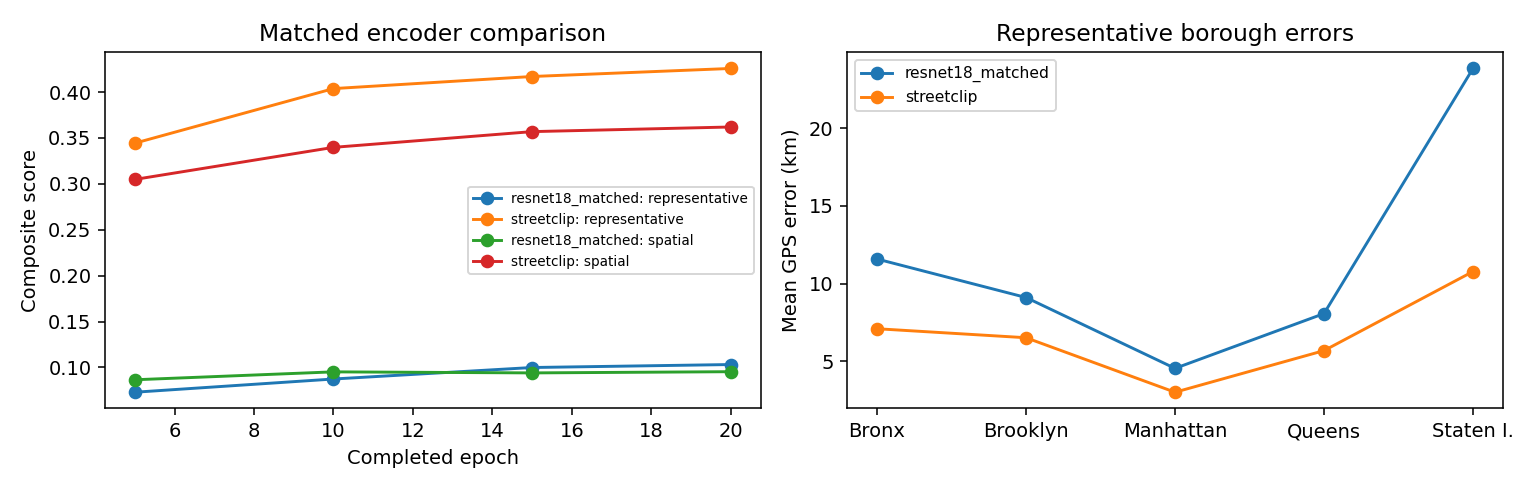

In [32]:
def audit_streetclip_comparison(root, device_name="auto"):
    """Verify matched folds, actual saved-model predictions, caches and provenance."""
    table = pd.read_csv(root/'outputs/streetclip_comparison_metrics.csv')
    require(len(table)==4, 'Expected both encoders on both folds')
    subset = json.loads((root/'outputs/streetclip_comparison_subset.json').read_text())
    full_frame,_=load_data(root)
    splits=json.loads((root/'outputs/splits.json').read_text())['splits']
    records=[json.loads(line) for line in (root/'outputs/experiment_log.jsonl').read_text().splitlines()]
    device=choose_device(device_name)
    verified,raw_rows,borough_rows=[],[],[]
    for row in table.itertuples(index=False):
        directory=root/'outputs/runs'/row.run_id
        model,saved=load_compass_head(root,directory/'best.pth',device)
        require(saved['train_ids']==subset['train_ids'][row.split], 'Matched training IDs drifted')
        require(saved['validation_ids']==splits[row.split]['validation_ids'], 'Full validation IDs drifted')
        require(not set(saved['train_ids']) & (set(saved['validation_ids']) | set(splits[row.split]['excluded_buffer_ids'])), 'Fold/buffer leakage')
        require(saved['decoder']=='mixed_median' and saved['config']['checkpoint_selection_decoder']=='mixed_median', 'Comparison changed decoder selection')
        require(saved['config']['training_scope']=='predeclared_subset' and saved['config']['epochs']==20, 'Comparison scope changed')
        key=saved['config']['feature_cache_key']
        metadata_files=list((root/'outputs/features').glob(f'*train_{key[:16]}.json'))
        require(len(metadata_files)==1, 'Missing/ambiguous cache metadata')
        metadata=json.loads(metadata_files[0].read_text())
        path=root/metadata['feature_file']
        require(metadata['complete'] and metadata['cache_key']==key and sha256(path)==metadata['feature_sha256']==saved['config']['feature_cache_sha256'], 'Cache bytes/identity changed')
        values=np.load(path,mmap_mode='r')
        positions=pd.Series(np.arange(len(metadata['spec']['sample_ids'])),index=metadata['spec']['sample_ids'])
        train_vectors=np.array(values[positions.loc[saved['train_ids']]],dtype=np.float32,copy=True)
        valid_vectors=np.array(values[positions.loc[saved['validation_ids']]],dtype=np.float32,copy=True)
        np.testing.assert_allclose(model.feature_mean.cpu().numpy(),train_vectors.mean(axis=0),atol=1e-6,rtol=0)
        np.testing.assert_allclose(model.feature_std.cpu().numpy(),np.maximum(train_vectors.std(axis=0),.05),atol=1e-6,rtol=0)
        np.testing.assert_allclose(saved['geography']['origin'],full_frame.loc[saved['train_ids'],['latitude','longitude']].mean(),atol=1e-10,rtol=0)
        truth=full_frame.loc[saved['validation_ids']]
        cached_prediction=pd.read_csv(directory/'validation_best.csv')
        scored=score_predictions(truth,cached_prediction)
        for name in ('score','borough_macro_f1','gps_score','mean_km','median_km','p90_km'):
            require(abs(scored[name]-getattr(row,name))<1e-9 and abs(scored[name]-saved['metrics'][name])<1e-9,'Metric/CSV mismatch')
        _,_,bank=compass_outputs(model,train_vectors,device)
        probabilities,boroughs,query=compass_outputs(model,valid_vectors,device)
        regenerated=compass_decoders(full_frame.loc[saved['train_ids']],truth.sample_id,saved['geography'],
                                   bank,query,probabilities,boroughs)['mixed_median']
        require(regenerated.borough.tolist()==cached_prediction.borough.tolist(),'Reloaded model changed borough predictions')
        np.testing.assert_allclose(regenerated[['latitude','longitude']],cached_prediction[['latitude','longitude']],atol=1e-6,rtol=0)
        history=json.loads((directory/'history.json').read_text())['epochs']
        require(len(history)==20 and all(x['unique_anchor_locations']==len(saved['train_ids']) for x in history),'Incomplete training coverage')
        source=json.loads((directory/'source_notebook.ipynb').read_text())
        source_code='\n\n'.join(''.join(c['source']) for c in source['cells'] if c['cell_type']=='code')
        source_hash=hashlib.sha256(source_code.encode()).hexdigest()
        logs=[item for item in records if item['run_id'].startswith(row.run_id)]
        require(bool(logs) and all(item['code_sha256']['NYCGuessr.ipynb_code']==source_hash for item in logs),'Run/source hash mismatch')
        raw_prediction=pd.read_csv(directory/'raw_neighbor_median.csv')
        raw_metrics=score_predictions(truth,raw_prediction)
        raw_rows.append({'split':row.split,'encoder':row.encoder,**{k:v for k,v in raw_metrics.items() if k!='borough_metrics'}})
        for borough,metrics in saved['metrics']['borough_metrics'].items():
            borough_rows.append({'split':row.split,'encoder':row.encoder,'borough':borough,**metrics})
        verified.append({'split':row.split,'encoder':row.encoder,'training_locations':len(saved['train_ids']),
                         'validation_locations':len(saved['validation_ids']),'parameters':saved['config']['trainable_parameters'],
                         'checkpoint_sha256':sha256(directory/'best.pth'),'metrics_reproduced':True,'actual_model_predictions_reproduced':True})
    budget=json.loads((root/'outputs/features/streetclip_gpu_budget.json').read_text())
    require(budget['used_seconds']<=budget['limit_seconds']==3600.,'Extraction exceeded selected budget')
    report={'models':verified,'extraction_seconds_total':budget['used_seconds'],'extraction_limit_seconds':3600,
            'training_data_sha256':sha256(root/'Data/train.csv'),'split_sha256':sha256(root/'outputs/splits.json'),
            'input_manifest_sha256':sha256(root/'outputs/input_manifest.jsonl'),'test_inference_performed':False,
            'all_label_streetclip_fit_performed':False,'scope':'Matched reduced training; complete fixed validation sets'}
    save_json(root/'outputs/streetclip_artifact_audit.json',report)
    pd.DataFrame(raw_rows).to_csv(root/'outputs/streetclip_raw_control_metrics.csv',index=False)
    pd.DataFrame(borough_rows).to_csv(root/'outputs/streetclip_borough_metrics.csv',index=False)
    return report,pd.DataFrame(borough_rows)


if (ROOT/'outputs/streetclip_comparison_metrics.csv').exists():
    street_audit,street_boroughs=audit_streetclip_comparison(ROOT,DEVICE)
    print('StreetCLIP artifact/model audit:',json.dumps(street_audit,indent=2))
    print('Raw feature controls:',pd.read_csv(ROOT/'outputs/streetclip_raw_control_metrics.csv').to_string(index=False))
    print('Borough results:',street_boroughs.to_string(index=False))
    table=pd.read_csv(ROOT/'outputs/streetclip_comparison_metrics.csv')
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    for row in table.itertuples(index=False):
        history=json.loads((ROOT/'outputs/runs'/row.run_id/'history.json').read_text())['epochs']
        scored=[item for item in history if item['metrics']]
        axes[0].plot([item['epoch'] for item in scored],[item['metrics']['mixed_median']['score'] for item in scored],
                     marker='o',label=f'{row.encoder}: {row.split}')
    axes[0].set(xlabel='Completed epoch',ylabel='Composite score',title='Matched encoder comparison')
    axes[0].legend(fontsize=7)
    for encoder in ('resnet18_matched','streetclip'):
        rows=street_boroughs.loc[(street_boroughs.split=='representative') & (street_boroughs.encoder==encoder)].set_index('borough').loc[list(BOROUGHS)]
        axes[1].plot(np.arange(5),rows.mean_km,marker='o',label=encoder)
    axes[1].set(xticks=np.arange(5),xticklabels=['Bronx','Brooklyn','Manhattan','Queens','Staten I.'],ylabel='Mean GPS error (km)',title='Representative borough errors')
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(ROOT/'outputs/figures/streetclip_learning_boroughs.png',dpi=140)
    display(DisplayImage(filename=str(ROOT/'outputs/figures/streetclip_learning_boroughs.png')))
    plt.close(fig)


## StreetCLIP measured outcome and decision — 2026-11-16

**Retain frozen StreetCLIP + the compass head as the best validated candidate.** This is a reduced-training experiment: 4,128 representative / 3,926 spatial training locations, with all original 2,372 / 2,421 validation locations. The ResNet18 controls use precisely the same training IDs, normalization policy, 20 epochs, hidden width, losses and fixed mixed-decoder selection. The input projection differs (512 vs 1024 channels; **266,757 vs 333,317 trainable parameters**), so this is a practical encoder comparison with a documented capacity difference.

| Split | Encoder | Score | Borough Macro-F1 | GPS score | Mean / median / p90 km |
|---|---|---:|---:|---:|---|
| Representative | ResNet18 matched | 0.103119 | 0.505208 | 0.058442 | 9.41558 / 7.00612 / 20.14058 |
| Representative | StreetCLIP | **0.425715** | **0.692864** | **0.396031** | **6.03969 / 3.31479 / 15.67679** |
| Spatial | ResNet18 matched | 0.095326 | 0.485686 | 0.051952 | 9.48048 / 7.67675 / 19.17788 |
| Spatial | StreetCLIP | **0.361942** | **0.672840** | **0.327398** | **6.72602 / 4.24773 / 15.63508** |

Both StreetCLIP heads selected epoch 20. Raw-feature StreetCLIP neighbor controls scored **0.267332 representative / 0.227471 spatial**, below the trained heads; retain the head. Geographic borough voting raises the alternative diagnostic score slightly (0.429155 / 0.364533), but the predeclared matched comparison retains `mixed_median` with the classifier's borough output. Do not silently substitute a different decoder into these headline results.

StreetCLIP improves every borough's mean error against its matched controls. Representative Staten Island mean remains **10.7756 km**, Bronx **7.08635 km**, Brooklyn **6.50671 km**, Queens **5.67561 km**, Manhattan **2.99348 km**. This is still far from the 0.90 target. Previously used development splits remain development estimates; no Kaggle/private-leaderboard estimate is available.

Native-resolution subset extraction took **2,670.48 s (44.51 min)**, about **9.74 images/s**. Including all benchmarks/warm-ups, the extraction clock was **2,755.87 s (45.93 min)**, below the one-hour cap. Main-pass sampled peak MPS driver allocation was **2.08 GiB**; this is a sampled driver measurement, not an exact RAM/VRAM peak. The complete cache is `outputs/features/streetclip_train_1d2ae8ae6d357433.npy`, **53,248,128 bytes**, SHA-256 `f80063c6a2261611e03853a55bf4641843c4307a798ad56d9a08ff176c791811`. The 128-row full-data pilot remains a separate incomplete cache and cannot authorize full-data fitting.

The four head runs took **16.64 / 12.81 / 12.99 / 12.02 s**, respectively (including their raw controls/evaluations). Actual training notebook: **2,735.17 s**, 29 code cells, 28 checks, zero errors. All active code remains here. Strict artifact verification regenerated actual model predictions, reproduced CSV metrics, checked cache/model/source hashes, train-only statistics and original split/buffer membership for all four models. Final training/extraction-disabled fresh-kernel run passed **30 code cells / 28 checks / zero errors / nine embedded figures in 10.65 s**. Later changes to this section are Markdown/provenance only.

Selected representative checkpoint: `outputs/runs/20261116T142848_compass_streetclip_representative/best.pth`, SHA-256 `db9c1e2eb4627bcfec7a0fcd0bcc35e6fa0d6ee584cd9e33c7b0a20af5891153`. Spatial counterpart: `outputs/runs/20261116T142914_compass_streetclip_spatial/best.pth`. Original full-training ResNet18 checkpoints are preserved. **No all-label StreetCLIP refit, test feature extraction, test CSV or Kaggle upload occurred.** The legacy exporter is not yet wired to StreetCLIP; a final fit must first obtain all 11,864 labeled-location features and preserve train/test namespaces for overlapping numeric IDs.

Next proposed action: reuse this cache, encode the remaining **5,364** labeled locations (rough estimate **37 additional GPU minutes** at measured throughput, requiring a new budget), then repeat the same full-fold 20-epoch comparison before all-label refitting. No further extraction/model download is enabled automatically. Reproduce the current subset experiment with `NYCGUESSR_DEVICE=mps` and `NYCGUESSR_STREETCLIP_COMPARISON=1`; all extraction/training/download flags default off. Prior source snapshots preserve the original training implementation; a subsequent harmless change copies read-only pandas IDs before converting to tensors.


Full-fold StreetCLIP:          split                                                   run_id  epoch      decoder  training_locations  validation_locations    score  borough_macro_f1  gps_score  mean_km  median_km    p90_km
representative 20261116T161715_compass_streetclip_full20_representative     20 mixed_median                9492                  2372 0.546915          0.783055   0.520678 4.793223   2.269179 13.490731
       spatial        20261116T161747_compass_streetclip_full20_spatial     20 mixed_median                8716                  2421 0.421108          0.738176   0.385878 6.141217   3.608386 15.000633


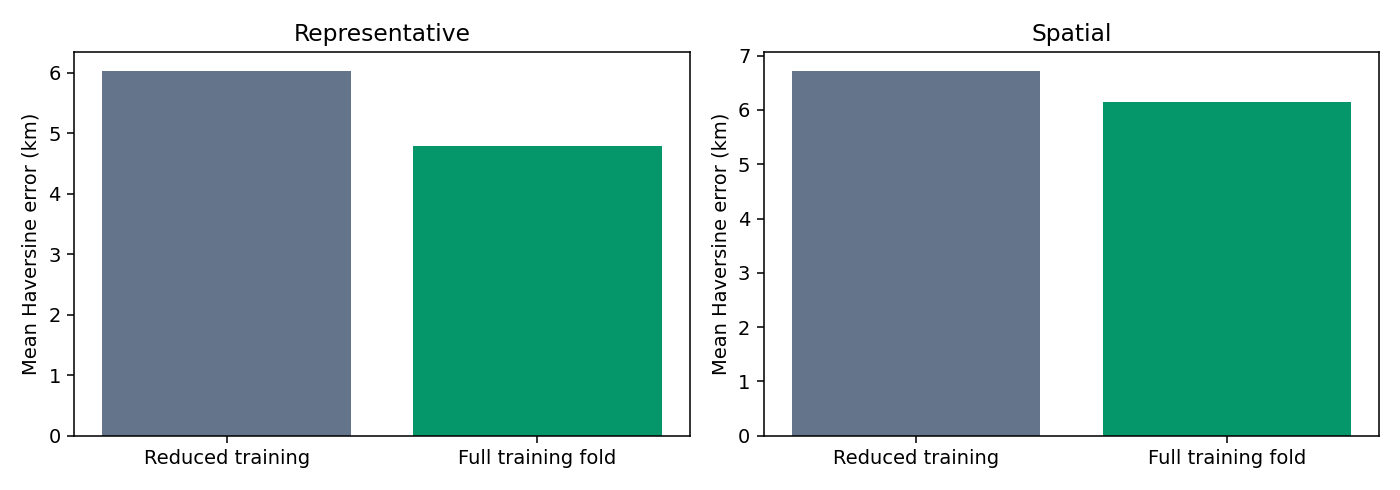

In [33]:
RUN_STREETCLIP_FULL20=os.environ.get('NYCGUESSR_STREETCLIP_FULL20','0')=='1'
if RUN_STREETCLIP_FULL20:
    complete_frame,_=load_data(ROOT)
    complete_features,complete_metadata=complete_streetclip_cache(ROOT,complete_frame,DEVICE)
    require(complete_features is not None and complete_metadata.get('complete'),'Completion reached its cap; incomplete cache retained, no model fitted')
    full_results=[]
    for fold in ('representative','spatial'):
        checkpoint=train_compass_head(ROOT,complete_frame,complete_features,complete_metadata,fold,epochs=20,max_minutes=5.,
                                       device_name=DEVICE,experiment_tag='streetclip_full20',selection_decoder='mixed_median')
        _,saved=load_compass_head(ROOT,checkpoint,torch.device('cpu'))
        full_results.append({'split':fold,'run_id':checkpoint.parent.name,'epoch':saved['epoch'],'decoder':saved['decoder'],
                             'training_locations':len(saved['train_ids']),'validation_locations':len(saved['validation_ids']),
                             **{key:value for key,value in saved['metrics'].items() if key!='borough_metrics'}})
        pd.DataFrame(full_results).to_csv(ROOT/'outputs/streetclip_full20_metrics.csv',index=False)
        print('Full-training-fold result:',full_results[-1],flush=True)
if (ROOT/'outputs/streetclip_full20_metrics.csv').exists():
    full_results=pd.read_csv(ROOT/'outputs/streetclip_full20_metrics.csv')
    smaller=pd.read_csv(ROOT/'outputs/streetclip_comparison_metrics.csv').query("encoder == 'streetclip'")
    print('Full-fold StreetCLIP:',full_results.to_string(index=False))
    fig,axes=plt.subplots(1,2,figsize=(10,3.5))
    for axis,fold in zip(axes,('representative','spatial')):
        old=smaller.loc[smaller.split==fold].iloc[0];new=full_results.loc[full_results.split==fold].iloc[0]
        axis.bar(['Reduced training','Full training fold'],[old.mean_km,new.mean_km],color=['#64748b','#059669'])
        axis.set(title=fold.capitalize(),ylabel='Mean Haversine error (km)')
    fig.tight_layout()
    fig.savefig(ROOT/'outputs/figures/streetclip_full20_comparison.png',dpi=140)
    display(DisplayImage(filename=str(ROOT/'outputs/figures/streetclip_full20_comparison.png')))
    plt.close(fig)


Full cache/model artifact audit: {
  "models": [
    {
      "split": "representative",
      "training_locations": 9492,
      "validation_locations": 2372,
      "checkpoint": "outputs/runs/20261116T161715_compass_streetclip_full20_representative/best.pth",
      "checkpoint_sha256": "1aa503c12dcf506d0af8d11dbe6bbde304fcf7cd1364fea9d2029630335e7e81",
      "metrics_and_model_predictions_reproduced": true,
      "source_log_hash_verified": true
    },
    {
      "split": "spatial",
      "training_locations": 8716,
      "validation_locations": 2421,
      "checkpoint": "outputs/runs/20261116T161747_compass_streetclip_full20_spatial/best.pth",
      "checkpoint_sha256": "3ee90936dcd4d43f7b1af9db59f6d28eeaf4d34ad7bdcfcea87ab42c4c3ede28",
      "metrics_and_model_predictions_reproduced": true,
      "source_log_hash_verified": true
    }
  ],
  "cache_file": "outputs/features/streetclip_train_23f1be61d2b2b2cd.npy",
  "cache_sha256": "b9be80acd9d389f34b558321403d9f4d5ef4e54e100f31800d05

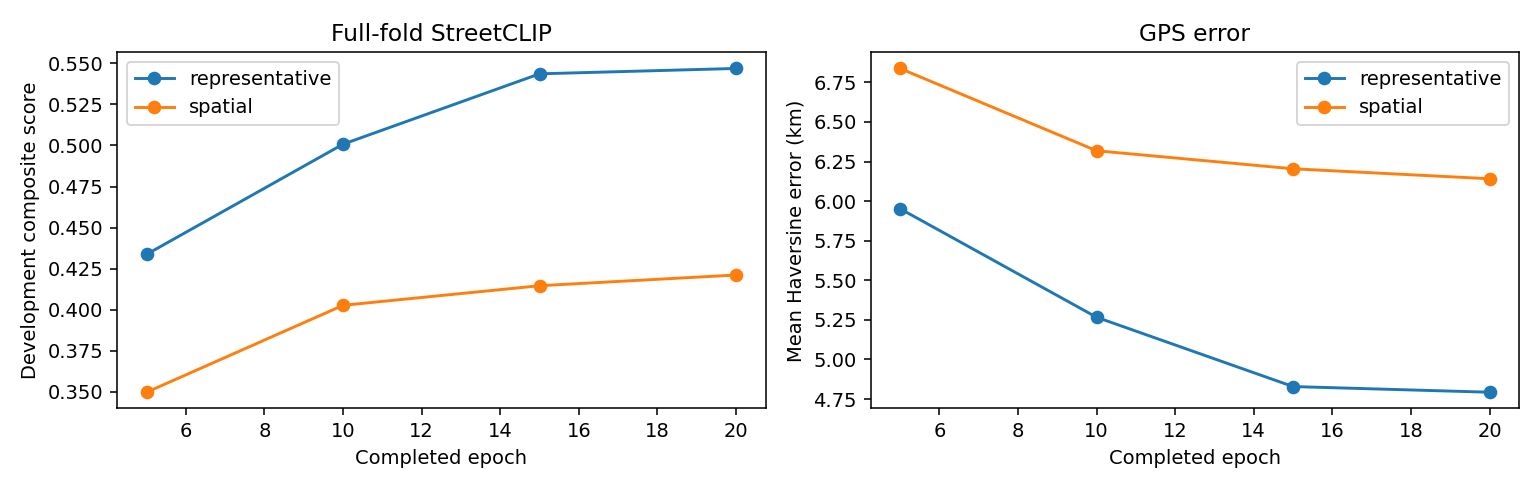

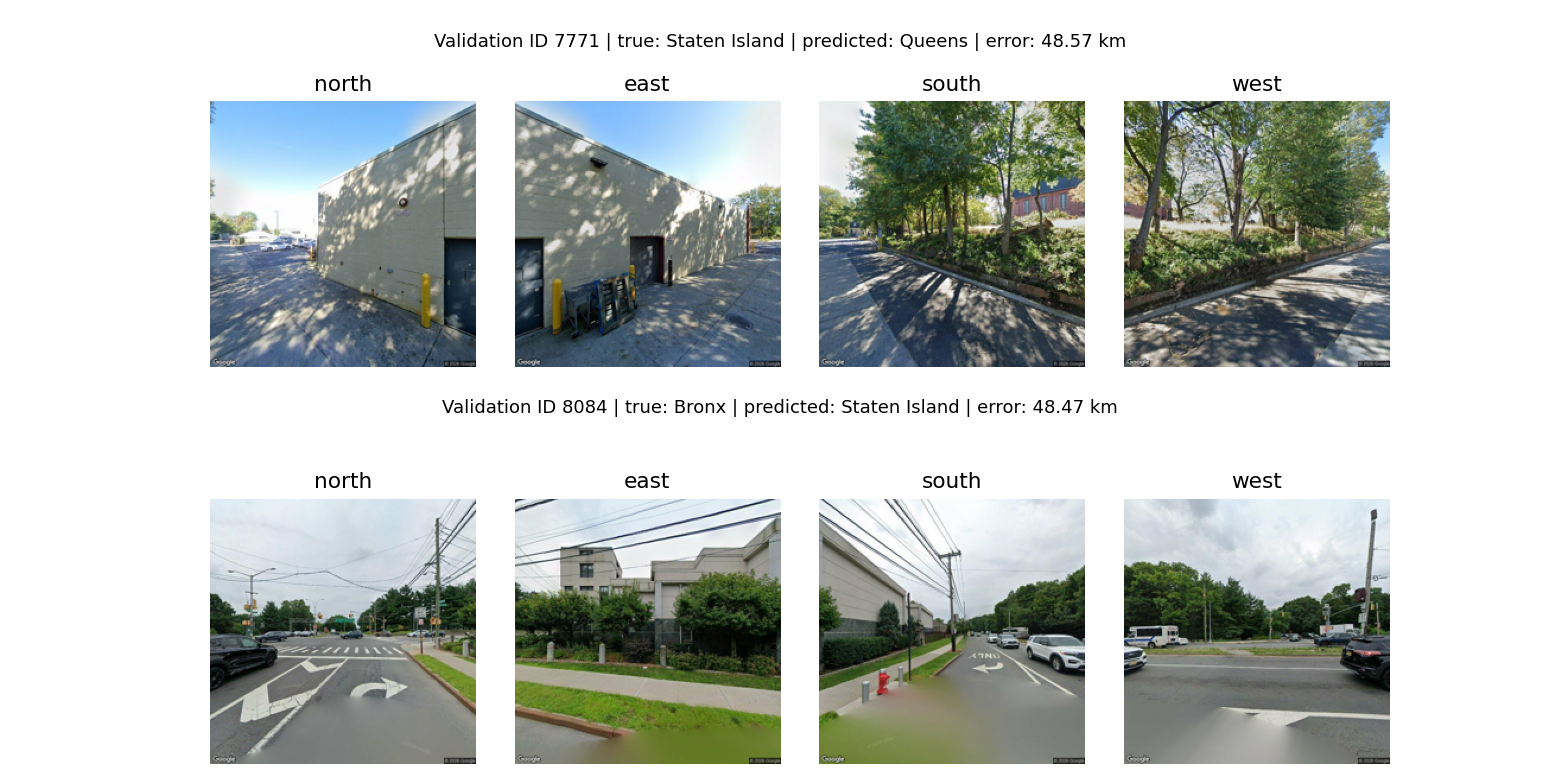

In [34]:
def audit_streetclip_full20(root,device_name='auto'):
    frame,_=load_data(root)
    meta=json.loads((root/'outputs/features/streetclip_train_23f1be61d2b2b2cd.json').read_text())
    path=root/meta['feature_file']
    expected_spec=streetclip_cache_spec(root,frame,meta['spec']['encoder'])
    require(meta['complete'] and meta['spec']==expected_spec and meta['cache_key']==hashlib.sha256(json.dumps(expected_spec,sort_keys=True).encode()).hexdigest(),'Full feature identity mismatch')
    require(sha256(path)==meta['feature_sha256'],'Full feature bytes changed')
    values=np.load(path,mmap_mode='r')
    require(values.shape==(11864,4,1024) and values.dtype==np.float16,'Full feature shape/dtype mismatch')
    coverage_path=path.with_suffix('.completion.coverage.npy')
    coverage=np.load(coverage_path)
    require(coverage.shape==(11864,) and coverage.dtype==bool and coverage.all()
            and sha256(coverage_path)==meta['assembly']['coverage_sha256'],'Coverage checkpoint mismatch')
    require(hashlib.sha256(inspect.getsource(complete_streetclip_cache).encode()).hexdigest()==meta['assembly']['source_code_sha256'],'Completion source hash differs')
    source_meta=json.loads((root/'outputs/features/streetclip_train_1d2ae8ae6d357433.json').read_text())
    require(sha256(root/source_meta['feature_file'])==meta['assembly']['source_sha256']==source_meta['feature_sha256'],'Reused source changed')
    positions=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    reused=positions.loc[source_meta['spec']['sample_ids']].to_numpy()
    np.testing.assert_array_equal(values[reused],np.load(root/source_meta['feature_file'],mmap_mode='r'))
    require(meta['assembly']['reused_locations']==6500 and meta['assembly']['newly_encoded_locations']==5364,'Unexpected re-encoding count')
    require((root/'outputs/features/streetclip_train_23f1be61d2b2b2cd.partial.npy').exists(),'Historical pilot missing')
    previous_budget=json.loads((root/'outputs/features/streetclip_gpu_budget.json').read_text())
    completion_budget=json.loads((root/'outputs/features/streetclip_completion_budget.json').read_text())
    require(abs(previous_budget['used_seconds']-2755.870640582987)<1e-6,'Previous budget record changed')
    require(completion_budget['limit_seconds']==3600. and completion_budget['used_seconds']<=3600.,'Completion exceeded phase budget')
    splits=json.loads((root/'outputs/splits.json').read_text())['splits']
    table=pd.read_csv(root/'outputs/streetclip_full20_metrics.csv')
    require(set(table.split)=={'representative','spatial'} and len(table)==2,'Missing full-fold result')
    logs=[json.loads(s) for s in (root/'outputs/experiment_log.jsonl').read_text().splitlines()]
    device=choose_device(device_name)
    verified,borough_rows,raw_rows=[],[],[]
    for row in table.itertuples(index=False):
        directory=root/'outputs/runs'/row.run_id
        model,saved=load_compass_head(root,directory/'best.pth',device)
        split=splits[row.split]
        require(saved['train_ids']==split['train_ids'] and saved['validation_ids']==split['validation_ids'],'Full fold IDs changed')
        require(not set(saved['train_ids']) & (set(saved['validation_ids'])|set(split['excluded_buffer_ids'])),'Fold/buffer leakage')
        require(saved['config']['training_scope']=='full_fold' and saved['config']['checkpoint_selection_decoder']==saved['decoder']=='mixed_median','Training scope/selection changed')
        require(saved['config']['feature_cache_key']==meta['cache_key'] and saved['config']['feature_cache_sha256']==meta['feature_sha256'],'Model/cache mismatch')
        training=frame.loc[saved['train_ids']];truth=frame.loc[saved['validation_ids']]
        train_vectors=np.array(values[positions.loc[training.sample_id]],dtype=np.float32,copy=True)
        valid_vectors=np.array(values[positions.loc[truth.sample_id]],dtype=np.float32,copy=True)
        np.testing.assert_allclose(model.feature_mean.cpu().numpy(),train_vectors.mean(axis=0),atol=1e-6,rtol=0)
        np.testing.assert_allclose(model.feature_std.cpu().numpy(),np.maximum(train_vectors.std(axis=0),.05),atol=1e-6,rtol=0)
        np.testing.assert_allclose(saved['geography']['origin'],training[['latitude','longitude']].mean(),atol=1e-10,rtol=0)
        prediction=pd.read_csv(directory/'validation_best.csv')
        scored=score_predictions(truth,prediction)
        for name in ('score','borough_macro_f1','gps_score','mean_km','median_km','p90_km'):
            require(abs(scored[name]-getattr(row,name))<1e-9 and abs(scored[name]-saved['metrics'][name])<1e-9,'Full-fold metric/CSV mismatch')
        _,_,bank=compass_outputs(model,train_vectors,device)
        probability,borough,query=compass_outputs(model,valid_vectors,device)
        regenerated=compass_decoders(training,truth.sample_id,saved['geography'],bank,query,probability,borough)['mixed_median']
        require(regenerated.borough.tolist()==prediction.borough.tolist(),'Reload changed full-fold borough outputs')
        np.testing.assert_allclose(regenerated[['latitude','longitude']],prediction[['latitude','longitude']],atol=1e-6,rtol=0)
        history=json.loads((directory/'history.json').read_text())['epochs']
        require(len(history)==20 and all(r['unique_anchor_locations']==len(training) for r in history),'Incomplete full-fold epochs')
        archive=json.loads((directory/'source_notebook.ipynb').read_text())
        code='\n\n'.join(''.join(c['source']) for c in archive['cells'] if c['cell_type']=='code')
        source_hash=hashlib.sha256(code.encode()).hexdigest()
        run_logs=[item for item in logs if item['run_id'].startswith(row.run_id)]
        require(bool(run_logs) and all(item['code_sha256']['NYCGuessr.ipynb_code']==source_hash for item in run_logs),'Full-fold source/log mismatch')
        raw=score_predictions(truth,pd.read_csv(directory/'raw_neighbor_median.csv'))
        raw_rows.append({'split':row.split,**{k:v for k,v in raw.items() if k!='borough_metrics'}})
        for name,item in scored['borough_metrics'].items():borough_rows.append({'split':row.split,'borough':name,**item})
        verified.append({'split':row.split,'training_locations':len(training),'validation_locations':len(truth),
                         'checkpoint':str((directory/'best.pth').relative_to(root)),'checkpoint_sha256':sha256(directory/'best.pth'),
                         'metrics_and_model_predictions_reproduced':True,'source_log_hash_verified':True})
    report={'models':verified,'cache_file':meta['feature_file'],'cache_sha256':meta['feature_sha256'],
            'reused_locations':6500,'newly_encoded_locations':5364,'coverage':11864,
            'previous_phase_seconds':previous_budget['used_seconds'],'completion_phase_seconds':completion_budget['used_seconds'],
            'training_data_sha256':sha256(root/'Data/train.csv'),'split_sha256':sha256(root/'outputs/splits.json'),
            'input_manifest_sha256':sha256(root/'outputs/input_manifest.jsonl'),
            'all_label_supervised_refit_performed':False,'test_feature_extraction_performed':False,'kaggle_submission_performed':False}
    save_json(root/'outputs/streetclip_full20_artifact_audit.json',report)
    pd.DataFrame(borough_rows).to_csv(root/'outputs/streetclip_full20_borough_metrics.csv',index=False)
    pd.DataFrame(raw_rows).to_csv(root/'outputs/streetclip_full20_raw_control_metrics.csv',index=False)
    return report


if (ROOT/'outputs/streetclip_full20_metrics.csv').exists():
    full20_audit=audit_streetclip_full20(ROOT,DEVICE)
    print('Full cache/model artifact audit:',json.dumps(full20_audit,indent=2))
    print('Borough metrics:',pd.read_csv(ROOT/'outputs/streetclip_full20_borough_metrics.csv').to_string(index=False))
    results=pd.read_csv(ROOT/'outputs/streetclip_full20_metrics.csv')
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    for row in results.itertuples(index=False):
        history=json.loads((ROOT/'outputs/runs'/row.run_id/'history.json').read_text())['epochs']
        scored=[r for r in history if r['metrics']]
        axes[0].plot([r['epoch'] for r in scored],[r['metrics']['mixed_median']['score'] for r in scored],marker='o',label=row.split)
        axes[1].plot([r['epoch'] for r in scored],[r['metrics']['mixed_median']['mean_km'] for r in scored],marker='o',label=row.split)
    axes[0].set(title='Full-fold StreetCLIP',xlabel='Completed epoch',ylabel='Development composite score')
    axes[1].set(title='GPS error',xlabel='Completed epoch',ylabel='Mean Haversine error (km)')
    for axis in axes:axis.legend()
    fig.tight_layout();fig.savefig(ROOT/'outputs/figures/streetclip_full20_learning.png',dpi=140)
    display(DisplayImage(filename=str(ROOT/'outputs/figures/streetclip_full20_learning.png')));plt.close(fig)
    frame,_=load_data(ROOT)
    row=results.loc[results.split=='representative'].iloc[0]
    predicted=pd.read_csv(ROOT/'outputs/runs'/row.run_id/'validation_best.csv').set_index('sample_id')
    truth=frame.loc[predicted.index]
    errors=haversine_km(truth[['latitude','longitude']],predicted[['latitude','longitude']])
    worst=np.argsort(-errors)[:2]
    examples=[]
    fig,axes=plt.subplots(2,4,figsize=(12,6))
    for r,index in enumerate(worst):
        sample=truth.iloc[index];guess=predicted.iloc[index]
        examples.append({'sample_id':int(sample.sample_id),'actual_borough':sample.borough,'predicted_borough':guess.borough,'error_km':float(errors[index])})
        for c,direction in enumerate(DIRECTIONS):
            with Image.open(ROOT/'Data/train'/sample[f'image_{direction}']) as im:axes[r,c].imshow(im.resize((224,224)))
            axes[r,c].axis('off');axes[r,c].set_title(direction)
        fig.text(.5,.94-r*.47,f'Validation ID {int(sample.sample_id)} | true: {sample.borough} | predicted: {guess.borough} | error: {errors[index]:.2f} km',ha='center',fontsize=10)
    fig.subplots_adjust(top=.87,bottom=.02,hspace=.5,wspace=.03)
    fig.savefig(ROOT/'outputs/figures/streetclip_full20_largest_errors.png',dpi=130)
    display(DisplayImage(filename=str(ROOT/'outputs/figures/streetclip_full20_largest_errors.png')));plt.close(fig)
    save_json(ROOT/'outputs/streetclip_full20_error_examples.json',{'examples':examples,'scope':'Labeled held-out development examples; no test lookups'})


## Full-training-fold outcome — 2026-11-16

The full-fold 20-epoch StreetCLIP model became the baseline at this stage; the later 40-epoch study below supersedes it. All 11,864 labeled locations now have frozen native-336 features. Reused 6,500 committed cache rows **bit for bit**; encoded only 5,364 missing locations. The completion phase used **2,355.11 s (39.25 min)** under its separate one-hour cap; the prior phase budget remains 2,755.87 s. Full cache: `outputs/features/streetclip_train_23f1be61d2b2b2cd.npy`, **97,190,016 bytes**, SHA-256 `b9be80acd9d389f34b558321403d9f4d5ef4e54e100f31800d05426f7ae2f2e8`. Coverage, immutable source identity, finite values and the historical pilot were checked.

| Split | Training locations | Score, reduced → full | Mean GPS km, reduced → full | Full Macro-F1 | Full GPS score | Full median / p90 km |
|---|---:|---:|---:|---:|---:|---|
| Representative | 9,492 | 0.425715 → **0.546915** | 6.03969 → **4.79322** | 0.783055 | 0.520678 | 2.26918 / 13.49073 |
| Spatial | 8,716 | 0.361942 → **0.421108** | 6.72602 → **6.14122** | 0.738176 | 0.385878 | 3.60839 / 15.00063 |

Both fresh heads completed 20 epochs, selected epoch 20 with the fixed mixed decoder, and retained original full validation IDs/buffer exclusions. Training/evaluation took **30.91 / 28.73 s**; the full execution took **2,430.33 s**, 32 code cells, 31 checks, zero errors. More training data also means more optimizer steps and newly fitted cells/neighbors; this is a practical expansion, not an equal-compute ablation. Spatial performance remains weaker. Spatial Staten Island mean error **11.5553 km** is slightly worse than the reduced model's 11.4327 km despite overall gains; avoid claiming every borough improved.

Representative checkpoint: `outputs/runs/20261116T161715_compass_streetclip_full20_representative/best.pth`, SHA `1aa503c12dcf506d0af8d11dbe6bbde304fcf7cd1364fea9d2029630335e7e81`. Spatial checkpoint: `outputs/runs/20261116T161747_compass_streetclip_full20_spatial/best.pth`. All prior candidates are preserved. The largest inspected validation errors are cross-borough mistakes: ID 7771, Staten Island predicted Queens, **48.57 km**; ID 8084, Bronx predicted Staten Island, **48.47 km**. Their four views are shown above, using only supplied labeled validation images.

Final training/extraction-disabled fresh-kernel run passed **33 code cells / 31 checks / zero errors / 12 embedded figures in 15.38 s**. Actual saved-model predictions and scores were reproduced; full original fold IDs, training-only fitted statistics, source/log hashes, complete coverage, exact cached-row reuse and distinct phase budgets passed audit. Files: `outputs/streetclip_full20_metrics.csv`, `outputs/streetclip_full20_artifact_audit.json`, `outputs/streetclip_full20_borough_metrics.csv`, `outputs/notebook_streetclip_full20_execution.json`, `outputs/notebook_streetclip_full20_final_verification.json`. No all-label supervised StreetCLIP fit, test feature pass, test prediction CSV or Kaggle upload has occurred. The 0.90 goal remains unmet.


In [35]:
def diagnose_geo_gradients(root):
    """At most one training epoch per case; inspect actual gradients before clipping."""
    frame,_=load_data(root)
    path=root/'outputs/runs/20261116T161715_compass_streetclip_full20_representative/best.pth'
    saved=torch.load(path,map_location='cpu',weights_only=True)
    training=frame.loc[saved['train_ids']]
    features=np.load(root/'outputs/features/streetclip_train_23f1be61d2b2b2cd.npy',mmap_mode='r')
    vectors=np.array(features[training.sample_id.to_numpy()],dtype=np.float32,copy=True)
    geo=saved['geography'];xy=((training[['latitude','longitude']].to_numpy()-geo['origin'])*geo['scales']).astype(np.float32)
    distances=np.linalg.norm(xy[:,None]-np.asarray(geo['centers'],dtype=np.float32)[None],axis=-1)
    neighbors=cKDTree(xy).query_ball_point(xy,.15)
    neighbors=[np.array([j for j in group if j!=i],dtype=int) for i,group in enumerate(neighbors)]
    rng=np.random.default_rng(SEED);anchors=rng.permutation(len(training));batches=[]
    for start in range(0,len(training),128):
        a=anchors[start:start+128]
        paired=np.array([rng.choice(neighbors[i]) if len(neighbors[i]) else (i+rng.integers(1,len(training)))%len(training) for i in a])
        batches.append(np.concatenate([a,paired]))
    rows=[]
    for device_name,tau in [('mps',1.),('mps',.5),('cpu',.5)]:
        seed_everything();device=choose_device(device_name)
        model=CompassGeoHead(geo,saved['state_dict']['feature_mean'],saved['state_dict']['feature_std']).to(device).train()
        q=np.exp(-(distances-distances.min(axis=1,keepdims=True))/tau);q/=q.sum(axis=1,keepdims=True)
        inputs=[torch.as_tensor(x,device=device) for x in (vectors,xy,q,np.array([BOROUGHS.index(v) for v in training.borough]),training.sample_id.to_numpy(copy=True))]
        x,locations,target,labels,ids=inputs
        optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.05)
        scheduler=torch.optim.lr_scheduler.OneCycleLR(optimizer,max_lr=.001,total_steps=20*int(np.ceil(len(training)/128)),pct_start=.1)
        for step,batch in enumerate(batches,1):
            index=torch.as_tensor(batch,device=device);optimizer.zero_grad(set_to_none=True)
            output=model(x[index])
            components={'cell':-(target[index]*output['cell_logits'].log_softmax(dim=1)).sum(dim=1).mean(),
                        'borough':.3*F.cross_entropy(output['borough_logits'],labels[index],weight=model.borough_weights),
                        'contrastive':geographic_contrastive_loss(output['embedding'],locations[index],ids[index])}
            loss=sum(components.values());loss.backward(retain_graph=True)
            bad=[name for name,p in model.named_parameters() if p.grad is not None and not bool(torch.isfinite(p.grad).all())]
            norm_cpu=float(torch.sqrt(sum((p.grad.detach().cpu().double().square().sum() for p in model.parameters() if p.grad is not None),torch.tensor(0.,dtype=torch.float64))))
            row={'device':device_name,'tau':tau,'step':step,'loss':float(loss.detach().cpu()),'nonfinite_parameters':bad,'cpu_double_gradient_norm':norm_cpu if np.isfinite(norm_cpu) else None}
            if bad:
                failures={}
                for name,value in components.items():
                    optimizer.zero_grad(set_to_none=True);value.backward(retain_graph=True)
                    failures[name]=[key for key,p in model.named_parameters() if p.grad is not None and not bool(torch.isfinite(p.grad).all())]
                row['component_nonfinite_parameters']=failures
                rows.append(row);break
            try:nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True)
            except RuntimeError as error:row['clip_error']=str(error);rows.append(row);break
            optimizer.step();scheduler.step();rows.append(row)
        del model,inputs,optimizer,scheduler
        if device.type=='mps':torch.mps.empty_cache()
    save_json(root/'outputs/cached_geo_gradient_explicit_norm_diagnostic.json',{'cases':rows,'max_updates_per_case':int(np.ceil(len(training)/128)),'scope':'Implementation diagnostic, not a validation experiment'})
    return rows

if os.environ.get('NYCGUESSR_GEOGRAD_DIAGNOSTIC','0')=='1':
    print('Gradient diagnostic:',json.dumps(diagnose_geo_gradients(ROOT),indent=2))


In [36]:
RUN_CACHED_GEO_STUDY=os.environ.get('NYCGUESSR_CACHED_GEO_STUDY','0')=='1'
if RUN_CACHED_GEO_STUDY:
    # Borough study is already complete; never repeat a finished validation study needlessly.
    if not (ROOT/'outputs/borough_decoder_metrics.csv').exists():
        run_borough_decoder_study(ROOT,DEVICE)
    frame,_=load_data(ROOT)
    metadata=json.loads((ROOT/'outputs/features/streetclip_train_23f1be61d2b2b2cd.json').read_text())
    require(metadata['complete'] and sha256(ROOT/metadata['feature_file'])==metadata['feature_sha256'],'Verified full cache required')
    values=np.load(ROOT/metadata['feature_file'],mmap_mode='r')
    require(not (ROOT/'outputs/streetclip_normfix_target_metrics.csv').exists(),'Matched study already exists; inspect results before rerunning')
    rows=[];study_started=time.monotonic()
    for fold in ('representative','spatial'):
        for tau,tag in ((1.,'normfix_tau10'),(.5,'normfix_tau05')):
            remaining=600.-(time.monotonic()-study_started)
            require(remaining>0,'Ten-minute aggregate study budget exhausted')
            path=train_compass_head(ROOT,frame,values,metadata,fold,epochs=20,max_minutes=min(5.,remaining/60.),device_name=DEVICE,
                    experiment_tag=tag,selection_decoder='mixed_median',target_temperature_km=tau)
            _,saved=load_compass_head(ROOT,path,torch.device('cpu'))
            rows.append({'split':fold,'run_id':path.parent.name,'epoch':saved['epoch'],'target_temperature_km':tau,
                         'decoder':saved['decoder'],'training_locations':len(saved['train_ids']),'validation_locations':len(saved['validation_ids']),
                         **{k:v for k,v in saved['metrics'].items() if k!='borough_metrics'}})
            pd.DataFrame(rows).to_csv(ROOT/'outputs/streetclip_normfix_target_metrics.csv',index=False)
    table=pd.DataFrame(rows)
    delta={fold:float(group.loc[group.target_temperature_km==.5,'score'].iloc[0]-group.loc[group.target_temperature_km==1.,'score'].iloc[0])
           for fold,group in table.groupby('split')}
    save_json(ROOT/'outputs/streetclip_normfix_target_decision.json',{
        'retained':all(value>1e-4 for value in delta.values()),'score_delta_vs_matched_control':delta,
        'criterion':'Improve by more than 0.0001 on both fixed development folds; no automatic combining with borough weighting',
        'seconds':time.monotonic()-study_started,'all_label_refit_performed':False,'test_inference_performed':False})
    print('Matched target comparison:',table.to_string(index=False))
if (ROOT/'outputs/borough_decoder_metrics.csv').exists():
    print('Saved borough decoder study:',pd.read_csv(ROOT/'outputs/borough_decoder_metrics.csv').to_string(index=False))
    print('Decoder decision:',(ROOT/'outputs/borough_decoder_decision.json').read_text())
if (ROOT/'outputs/streetclip_normfix_target_metrics.csv').exists():
    print('Saved matched targets:',pd.read_csv(ROOT/'outputs/streetclip_normfix_target_metrics.csv').to_string(index=False))
    if (ROOT/'outputs/streetclip_normfix_target_decision.json').exists():
        print('Matched target decision:',(ROOT/'outputs/streetclip_normfix_target_decision.json').read_text())


Saved borough decoder study:          split       method                                         run_id    score  borough_macro_f1  gps_score  mean_km  median_km    p90_km
representative     baseline 20261116T164402_borough_decoder_representative 0.546915          0.783055   0.520678 4.793223   2.269179 13.490731
representative soft_borough 20261116T164402_borough_decoder_representative 0.532976          0.783055   0.505190 4.948100   2.188641 14.351920
       spatial     baseline        20261116T164402_borough_decoder_spatial 0.421108          0.738176   0.385878 6.141217   3.608386 15.000633
       spatial soft_borough        20261116T164402_borough_decoder_spatial 0.412643          0.738176   0.376473 6.235268   3.534059 15.651050
Decoder decision: {
  "alpha": 1,
  "score_delta": {
    "representative": -0.013938884284681485,
    "spatial": -0.00846462972417783
  },
  "retain": false,
  "criterion": "Require score improvement on both fixed development folds; unchanged classifier; n

In [37]:
RUN_CACHED_LONG40=os.environ.get('NYCGUESSR_CACHED_LONG40','0')=='1'
if RUN_CACHED_LONG40:
    frame,_=load_data(ROOT)
    metadata=json.loads((ROOT/'outputs/features/streetclip_train_23f1be61d2b2b2cd.json').read_text())
    require(metadata['complete'] and sha256(ROOT/metadata['feature_file'])==metadata['feature_sha256'],'Verified full cache required')
    values=np.load(ROOT/metadata['feature_file'],mmap_mode='r')
    require(not (ROOT/'outputs/streetclip_long40_metrics.csv').exists(),'40-epoch study already exists; inspect before rerunning')
    rows=[]
    for fold in ('representative','spatial'):
        path=train_compass_head(ROOT,frame,values,metadata,fold,epochs=40,max_minutes=1.,device_name=DEVICE,
                experiment_tag='normfix_tau10_long40',selection_decoder='mixed_median',target_temperature_km=1.)
        _,saved=load_compass_head(ROOT,path,torch.device('cpu'))
        status=json.loads((path.parent/'status.json').read_text())
        require(status['status']=='completed' and status['completed_epochs']==40,'Incomplete 40-epoch comparison; retain prior baseline')
        rows.append({'split':fold,'run_id':path.parent.name,'epoch':saved['epoch'],'target_temperature_km':1.,
                     'decoder':saved['decoder'],'training_locations':len(saved['train_ids']),'validation_locations':len(saved['validation_ids']),
                     **{k:v for k,v in saved['metrics'].items() if k!='borough_metrics'}})
        pd.DataFrame(rows).to_csv(ROOT/'outputs/streetclip_long40_metrics.csv',index=False)
    print('40-epoch comparison:',pd.DataFrame(rows).to_string(index=False))
if (ROOT/'outputs/streetclip_long40_metrics.csv').exists():
    print('Saved 40-epoch heads:',pd.read_csv(ROOT/'outputs/streetclip_long40_metrics.csv').to_string(index=False))


Saved 40-epoch heads:          split                                                      run_id  epoch  target_temperature_km      decoder  training_locations  validation_locations    score  borough_macro_f1  gps_score  mean_km  median_km    p90_km
representative 20261116T165854_compass_normfix_tau10_long40_representative     40                    1.0 mixed_median                9492                  2372 0.582646          0.799951   0.558501 4.414989   1.874957 12.469612
       spatial        20261116T165950_compass_normfix_tau10_long40_spatial     35                    1.0 mixed_median                8716                  2421 0.436519          0.754140   0.401228 5.987724   3.371754 14.696982


Cached geographic study audit: {
  "models": [
    {
      "stage": "matched20",
      "split": "representative",
      "target_temperature_km": 1.0,
      "checkpoint": "outputs/runs/20261116T165534_compass_normfix_tau10_representative/best.pth",
      "checkpoint_sha256": "62ca582740afe744744578617c74358213e7bc6afc51abf5961736773aad2e91",
      "selected_epoch": 20,
      "completed_epochs": 20,
      "fit_seconds": 29.423476874944754,
      "model_predictions_reproduced": true,
      "training_statistics_and_source_hash_verified": true
    },
    {
      "stage": "matched20",
      "split": "representative",
      "target_temperature_km": 0.5,
      "checkpoint": "outputs/runs/20261116T165604_compass_normfix_tau05_representative/best.pth",
      "checkpoint_sha256": "79a2500e93a68278eee0d16900854dc2c193035b2512d3a6affa752b6b4d2150",
      "selected_epoch": 20,
      "completed_epochs": 20,
      "fit_seconds": 29.084704749984667,
      "model_predictions_reproduced": true,
      "tr

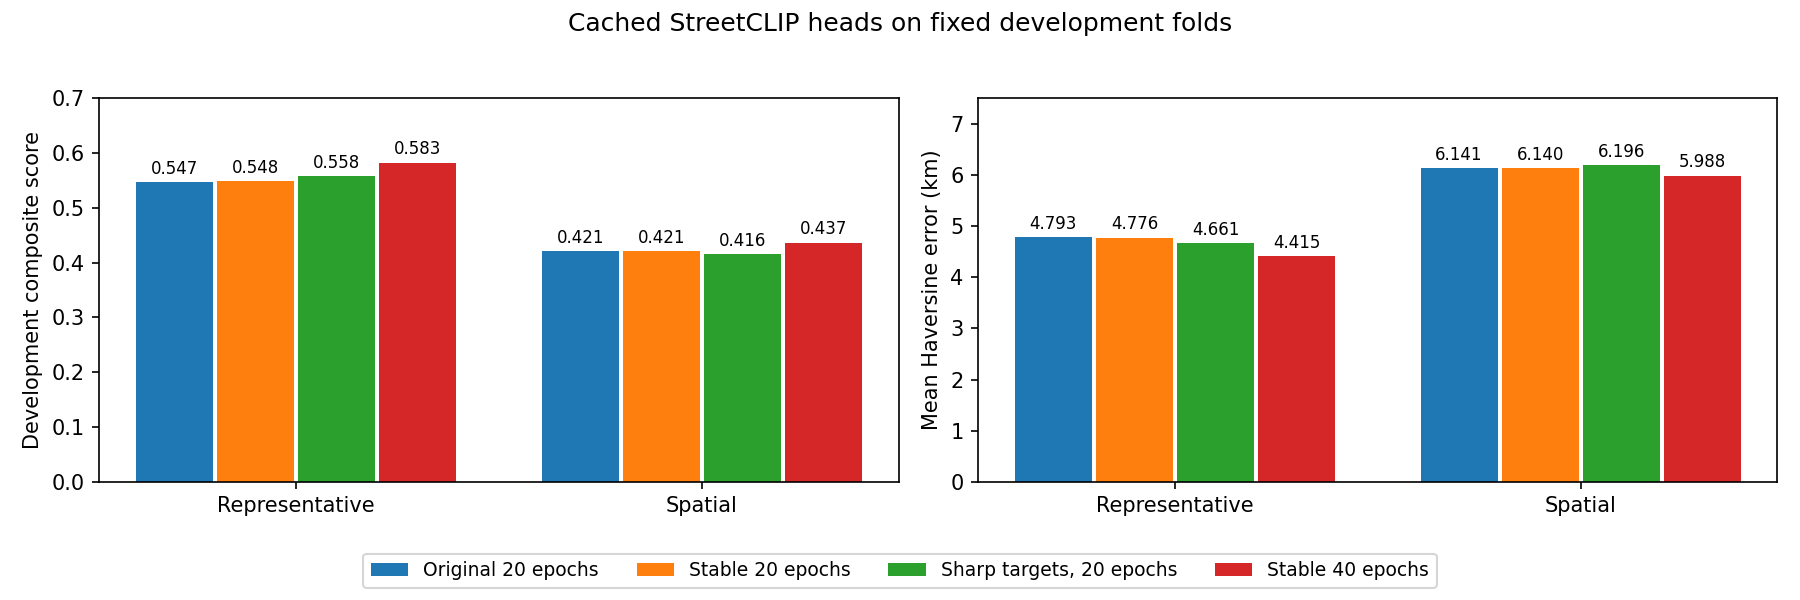

In [38]:
def audit_cached_geo_studies(root, device_name='auto'):
    """Reload every actual study checkpoint; verify folds, statistics, bytes and predictions."""
    frame,_=load_data(root)
    meta=json.loads((root/'outputs/features/streetclip_train_23f1be61d2b2b2cd.json').read_text())
    require(meta['complete'] and sha256(root/meta['feature_file'])==meta['feature_sha256'],'Study cache changed')
    values=np.load(root/meta['feature_file'],mmap_mode='r')
    splits=json.loads((root/'outputs/splits.json').read_text())['splits']
    original=pd.read_csv(root/'outputs/streetclip_full20_metrics.csv').set_index('split')
    matched=pd.read_csv(root/'outputs/streetclip_normfix_target_metrics.csv')
    longer=pd.read_csv(root/'outputs/streetclip_long40_metrics.csv')
    require(len(matched)==4 and len(longer)==2,'Incomplete cached-head study')
    require(not matched.duplicated(['split','target_temperature_km']).any() and not longer.split.duplicated().any(),'Duplicate trial rows')
    require(set(matched.split)==set(longer.split)=={'representative','spatial'} and set(matched.target_temperature_km)=={.5,1.},'Study design changed')
    logs=[json.loads(s) for s in (root/'outputs/experiment_log.jsonl').read_text().splitlines()]
    device=choose_device(device_name)
    verified=[];borough_rows=[];configs={};geographies={};fit_seconds=0.
    metric_names=('score','borough_macro_f1','gps_score','mean_km','median_km','p90_km')
    for stage,table,epochs in [('matched20',matched,20),('long40',longer,40)]:
        for row in table.itertuples(index=False):
            directory=root/'outputs/runs'/row.run_id
            model,saved=load_compass_head(root,directory/'best.pth',device)
            config=saved['config'];split=splits[row.split]
            require(saved['train_ids']==split['train_ids'] and saved['validation_ids']==split['validation_ids'],'Study fold IDs changed')
            require(not set(saved['train_ids'])&(set(saved['validation_ids'])|set(split['excluded_buffer_ids'])),'Study fold/buffer leakage')
            require(config['epochs']==config['schedule_epochs']==epochs and config['target_temperature_km']==row.target_temperature_km,'Study schedule/target mismatch')
            require(saved['decoder']==config['checkpoint_selection_decoder']=='mixed_median' and saved['epoch']==row.epoch,'Study selection changed')
            require(config['feature_norm_training']=='explicit_biased_variance_v1' and config['feature_cache_key']==meta['cache_key']
                    and config['feature_cache_sha256']==meta['feature_sha256'],'Study normalization/cache mismatch')
            truth,training=frame.loc[saved['validation_ids']],frame.loc[saved['train_ids']]
            train_vectors=np.array(values[training.sample_id.to_numpy()],dtype=np.float32,copy=True)
            valid_vectors=np.array(values[truth.sample_id.to_numpy()],dtype=np.float32,copy=True)
            np.testing.assert_allclose(model.feature_mean.cpu().numpy(),train_vectors.mean(axis=0),atol=1e-6,rtol=0)
            np.testing.assert_allclose(model.feature_std.cpu().numpy(),np.maximum(train_vectors.std(axis=0),.05),atol=1e-6,rtol=0)
            np.testing.assert_allclose(saved['geography']['origin'],training[['latitude','longitude']].mean(),atol=1e-10,rtol=0)
            if row.split in geographies:require(saved['geography']==geographies[row.split],'Geography differs between controlled studies')
            geographies[row.split]=saved['geography']
            prediction=pd.read_csv(directory/'validation_best.csv');scored=score_predictions(truth,prediction)
            for name in metric_names:
                require(abs(scored[name]-getattr(row,name))<1e-9 and abs(scored[name]-saved['metrics'][name])<1e-9,'Study checkpoint/CSV metric mismatch')
            _,_,bank=compass_outputs(model,train_vectors,device)
            probability,borough,query=compass_outputs(model,valid_vectors,device)
            actual=compass_decoders(training,truth.sample_id,saved['geography'],bank,query,probability,borough)['mixed_median']
            require(actual.borough.tolist()==prediction.borough.tolist(),'Reloaded study borough predictions differ')
            np.testing.assert_allclose(actual[['latitude','longitude']],prediction[['latitude','longitude']],atol=1e-6,rtol=0)
            history=json.loads((directory/'history.json').read_text())['epochs']
            status=json.loads((directory/'status.json').read_text())
            require(status['status']=='completed' and status['completed_epochs']==len(history)==epochs,'Incomplete study training')
            require(all(item['unique_anchor_locations']==len(training) for item in history),'Missing training anchors')
            require(saved['epoch']==max((item['epoch'] for item in history if item['metrics']),key=lambda epoch:history[epoch-1]['metrics']['mixed_median']['score']),'Checkpoint not selected by fixed decoder')
            archive=json.loads((directory/'source_notebook.ipynb').read_text())
            code='\n\n'.join(''.join(c['source']) for c in archive['cells'] if c['cell_type']=='code')
            source_hash=hashlib.sha256(code.encode()).hexdigest()
            run_logs=[item for item in logs if item['run_id'].startswith(row.run_id)]
            require(bool(run_logs) and all(item['code_sha256']['NYCGuessr.ipynb_code']==source_hash for item in run_logs),'Study source/log mismatch')
            configs[(stage,row.split,row.target_temperature_km)]=config
            fit_seconds+=status['elapsed_seconds']
            verified.append({'stage':stage,'split':row.split,'target_temperature_km':row.target_temperature_km,
                             'checkpoint':str((directory/'best.pth').relative_to(root)),'checkpoint_sha256':sha256(directory/'best.pth'),
                             'selected_epoch':saved['epoch'],'completed_epochs':epochs,'fit_seconds':status['elapsed_seconds'],
                             'model_predictions_reproduced':True,'training_statistics_and_source_hash_verified':True})
            borough_rows.extend({'stage':stage,'split':row.split,'target_temperature_km':row.target_temperature_km,'borough':name,**result}
                                for name,result in scored['borough_metrics'].items())
    for fold in ('representative','spatial'):
        a,b=configs[('matched20',fold,1.)],configs[('matched20',fold,.5)]
        ignored={'target_temperature_km','experiment_tag'}
        require({k:v for k,v in a.items() if k not in ignored}=={k:v for k,v in b.items() if k not in ignored},'Matched target control differs beyond declared settings')
        b=configs[('long40',fold,1.)];ignored={'epochs','schedule_epochs','max_minutes','experiment_tag'}
        require({k:v for k,v in a.items() if k not in ignored}=={k:v for k,v in b.items() if k not in ignored},'Longer control differs beyond declared schedule/budget')
    decoder=pd.read_csv(root/'outputs/borough_decoder_metrics.csv')
    for row in decoder.itertuples(index=False):
        directory=root/'outputs/runs'/row.run_id
        truth=frame.loc[splits[row.split]['validation_ids']]
        prediction=pd.read_csv(directory/f'{row.method}_validation.csv')
        scored=score_predictions(truth,prediction)
        require(all(abs(scored[name]-getattr(row,name))<1e-9 for name in metric_names),'Decoder CSV scores differ')
        source_prediction=pd.read_csv(directory/'baseline_validation.csv')
        require(prediction.borough.tolist()==source_prediction.borough.tolist(),'GPS-only study changed borough labels')
    control=matched.loc[matched.target_temperature_km==1.].set_index('split')
    long=longer.set_index('split')
    deltas={fold:{'score_vs_original20':float(long.loc[fold,'score']-original.loc[fold,'score']),
                  'score_vs_repaired20':float(long.loc[fold,'score']-control.loc[fold,'score']),
                  'mean_km_vs_original20':float(long.loc[fold,'mean_km']-original.loc[fold,'mean_km'])} for fold in ('representative','spatial')}
    retained=all(item['score_vs_original20']>1e-4 and item['score_vs_repaired20']>1e-4 for item in deltas.values())
    report={'models':verified,'successful_head_fit_seconds':fit_seconds,'retained_longer_training':retained,'deltas':deltas,
            'criterion':'Complete 40 epochs; improve composite >0.0001 on both fixed folds versus both original and repaired 20-epoch controls',
            'sharper_targets_retained':False,'soft_borough_weighting_retained':False,
            'cache_sha256':meta['feature_sha256'],'split_sha256':sha256(root/'outputs/splits.json'),
            'training_data_sha256':sha256(root/'Data/train.csv'),'all_label_refit_performed':False,
            'test_feature_extraction_performed':False,'kaggle_submission_performed':False,
            'scope':'Reused development validation, not untouched test or leaderboard evidence'}
    save_json(root/'outputs/cached_geo_study_artifact_audit.json',report)
    save_json(root/'outputs/streetclip_long40_decision.json',{'retained':retained,'deltas':deltas,'criterion':report['criterion']})
    pd.DataFrame(borough_rows).to_csv(root/'outputs/cached_geo_study_borough_metrics.csv',index=False)
    return report


if (ROOT/'outputs/streetclip_long40_metrics.csv').exists():
    study_audit=audit_cached_geo_studies(ROOT,DEVICE)
    print('Cached geographic study audit:',json.dumps(study_audit,indent=2))
    original=pd.read_csv(ROOT/'outputs/streetclip_full20_metrics.csv').assign(method='Original 20 epochs')
    matched=pd.read_csv(ROOT/'outputs/streetclip_normfix_target_metrics.csv')
    matched['method']=np.where(matched.target_temperature_km==1.,'Stable 20 epochs','Sharp targets, 20 epochs')
    longer=pd.read_csv(ROOT/'outputs/streetclip_long40_metrics.csv').assign(method='Stable 40 epochs')
    comparison=pd.concat([original,matched,longer],ignore_index=True)
    comparison.to_csv(ROOT/'outputs/cached_geo_study_comparison.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    methods=list(comparison.method.unique())
    for i,method in enumerate(methods):
        rows=comparison.loc[comparison.method==method].set_index('split').loc[['representative','spatial']]
        x=np.arange(2)+(i-1.5)*.2
        for axis,metric in zip(axes,('score','mean_km')):
            bars=axis.bar(x,rows[metric],width=.19,label=method)
            axis.bar_label(bars,fmt='%.3f',fontsize=8,padding=2)
    for axis in axes:axis.set_xticks(range(2),['Representative','Spatial'])
    axes[0].set(ylabel='Development composite score',ylim=(0,.7))
    axes[1].set(ylabel='Mean Haversine error (km)',ylim=(0,7.5))
    fig.legend(*axes[0].get_legend_handles_labels(),fontsize=9,ncol=4,loc='lower center',bbox_to_anchor=(.5,.005))
    fig.suptitle('Cached StreetCLIP heads on fixed development folds')
    fig.tight_layout(rect=(0,.1,1,.97));fig.savefig(ROOT/'outputs/figures/cached_geo_comparison.png',dpi=150)
    display(DisplayImage(filename=str(ROOT/'outputs/figures/cached_geo_comparison.png')));plt.close(fig)


## Cached-feature realignment and retained result — 2026-11-16

Three hypotheses were tested with fixed original folds, training-only fitted statistics/banks, all four views and the completed StreetCLIP cache. No further encoder extraction/download was needed.

| Change | Representative score | Spatial score | Decision |
|---|---:|---:|---|
| Original 20 epochs, 1-km targets | 0.546915 | 0.421108 | Preserve historical baseline |
| Soft borough GPS weighting, original fixed heads | 0.532976 | 0.412643 | Reject: both worsen |
| Repaired normalization, 20 epochs, 1-km targets | 0.548497 | 0.421150 | Matched control |
| Same repaired implementation, 0.5-km targets | 0.557800 | 0.415520 | Reject: spatial worsens |
| **Repaired implementation, 40 epochs, 1-km targets** | **0.582646** | **0.436519** | **Retain: improves both controls on both folds** |

The original sharper-target run and a fresh 1-km control stopped before the first complete epoch on a nonfinite-gradient guard. The second failure identified only the input LayerNorm scale gradient (`project.0.weight`) as nonfinite on the final 40-example paired batch. A 225-update diagnostic did not reproduce it; no backend root cause is proved. Keep these failures visible in their run statuses. The input normalization now uses the equivalent explicit biased-variance formula for training, with unchanged epsilon/state keys and native evaluation for old-checkpoint compatibility. CPU-reference output/input/affine-gradient checks pass on CPU and MPS for batch sizes 24, 40 and 256. The six subsequent heads completed without a nonfinite update; the guard remains enabled. Formula reference: [PyTorch LayerNorm documentation](https://docs.pytorch.org/docs/main/generated/torch.nn.LayerNorm.html).

The two longer fits completed all 40 epochs in **55.43 / 51.25 seconds** under their one-minute caps. Representative selected epoch 40; spatial selected **35**, using the same fixed mixed decoder. The OneCycle horizon also expanded, so describe this as a practical longer-training comparison. Against the repaired 20-epoch controls, score gains are **+0.034149 / +0.015369**. Against the original baseline, mean GPS falls **4.793223→4.414989 km / 6.141217→5.987724 km**. New GPS scores are **0.558501 / 0.401228**, median errors **1.874957 / 3.371754 km**, p90 **12.469612 / 14.696982 km**. Successful head fitting totaled **217.79 seconds** across six models; earlier failed/diagnostic work is separately documented and total bounded head work remained inside the ten-minute allowance.

All representative borough mean errors improve. Spatial performance remains uneven: Staten Island **11.5553→11.9593 km**, Manhattan **2.6685→2.7879 km**, Queens **5.7974→5.8123 km** worsen despite the aggregate gain; Bronx/Brooklyn improve. Reusing these development folds and trying multiple variants creates selection optimism. No confidence interval, untouched-test gain or leaderboard improvement is claimed.

Selected representative checkpoint: `outputs/runs/20261116T165854_compass_normfix_tau10_long40_representative/best.pth`, SHA-256 `b81144fcaf8aac8467ffe7074401b16403eacd6aa8db63169f15eb891e6ecd10`. Spatial: `outputs/runs/20261116T165950_compass_normfix_tau10_long40_spatial/best.pth`, SHA `dcc84f8493a3bcd34771eb1d4a4379330fba93cb210eab4f3a57add7f1584a52`. Previous candidates/cache bytes remain preserved.

Fresh-kernel, training/extraction-disabled verification passed **38 code cells / 33 checks / zero errors / 13 embedded figures**. It strictly reloaded all six actual new checkpoints, reproduced saved predictions/scores, verified exact full-fold and buffer IDs, training-only normalization/geography, matched configurations, complete epoch coverage and archived source/log hashes. Evidence: `outputs/cached_geo_study_artifact_audit.json`, `outputs/cached_geo_study_comparison.csv`, `outputs/cached_geo_study_borough_metrics.csv`, `outputs/streetclip_long40_decision.json`, `outputs/notebook_cached_geo_final_verification.json`. Rejected and failed trials remain recorded. No test inference, all-label supervised StreetCLIP refit, Kaggle submission, HPC action or dependency change occurred.

**Next proposed task:** compare training and validation GPS errors by borough for this fixed candidate, excluding self-matches from any training retrieval diagnostic, to decide whether the next model change should address head underfitting or representation/generalization. Do not run more search automatically in this task.


## Retained-model retrieval and generalization audit

Hypothesis: distant errors can arise from missing nearby candidates, weak ranking/probability weights, or imperfect coordinate aggregation. This diagnostic holds both retained models and the original mixed decoder fixed. All train/validation locations are evaluated; equal IDs are excluded from retrieval and geographic coverage. Training remains in-sample because the fitted head/geography saw those labels. Validation truth is used only **after** predictions/candidates exist to measure distances, coverage and probability mass; it never selects inference candidates or weights. Candidate minimum distances are diagnostic bounds for selecting from that finite candidate set, not attainable model scores or bounds on continuous coordinate prediction.

The audit is capped at ten minutes with chunks of 128 and at most 32 neighbors plus 30 cells. It does not train models or extract images. The explicit execution flag defaults off; ordinary reruns validate and display stored artifacts.


Retained model, training/validation diagnostics:          split      scope          method    score  borough_macro_f1  gps_score  mean_km  median_km    p90_km
representative      train    mixed_median 0.762389          0.902304   0.746843 2.531572   1.108548  5.807237
representative      train     cell_median 0.752253          0.902304   0.735580 2.644197   1.259306  5.702902
representative      train neighbor_median 0.747243          0.902304   0.730013 2.699865   1.071034  6.745090
representative validation    mixed_median 0.582646          0.799951   0.558501 4.414989   1.874957 12.469612
representative validation     cell_median 0.557058          0.799951   0.530070 4.699300   2.082141 13.276771
representative validation neighbor_median 0.587822          0.799951   0.564252 4.357481   1.771977 12.303926
       spatial      train    mixed_median 0.786578          0.913484   0.772478 2.275224   0.962557  5.286650
       spatial      train     cell_median 0.774080          0.913484   

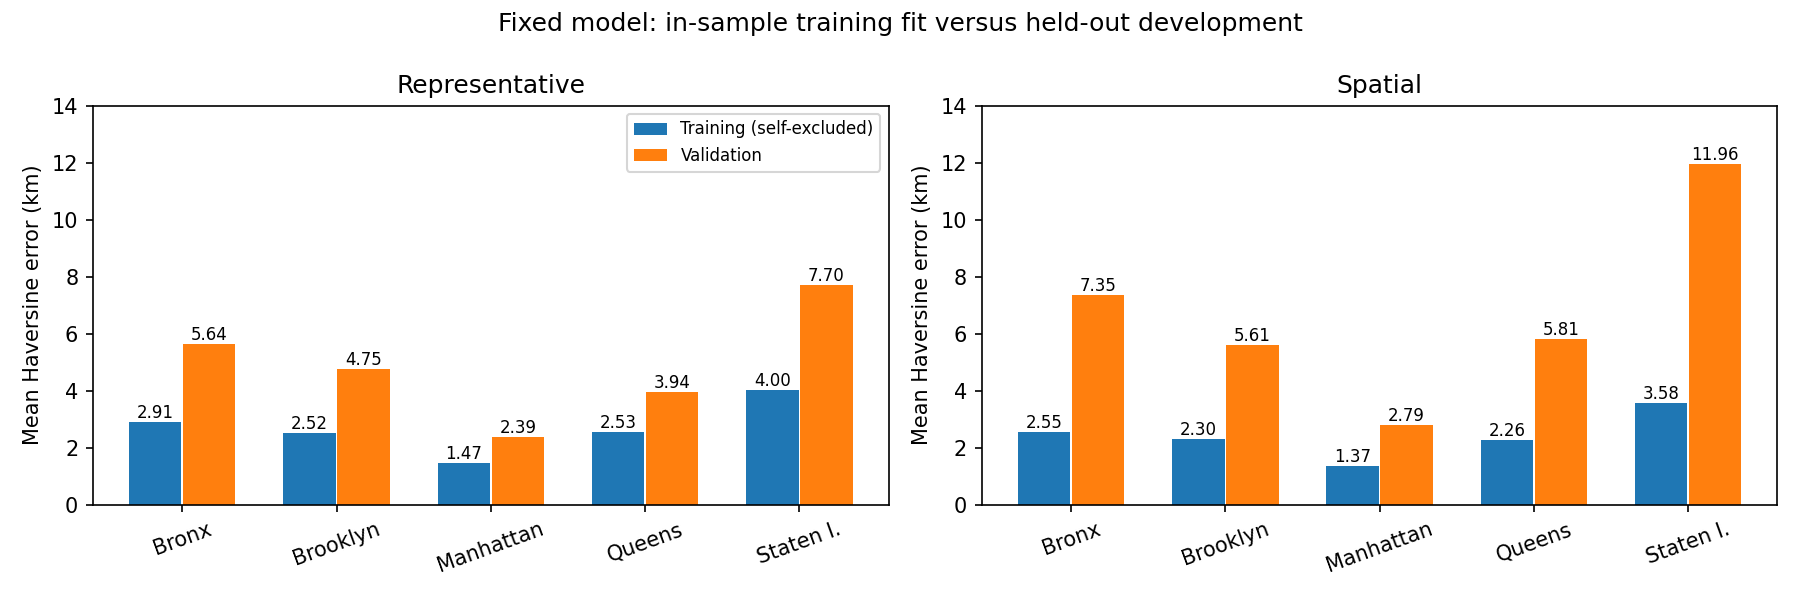

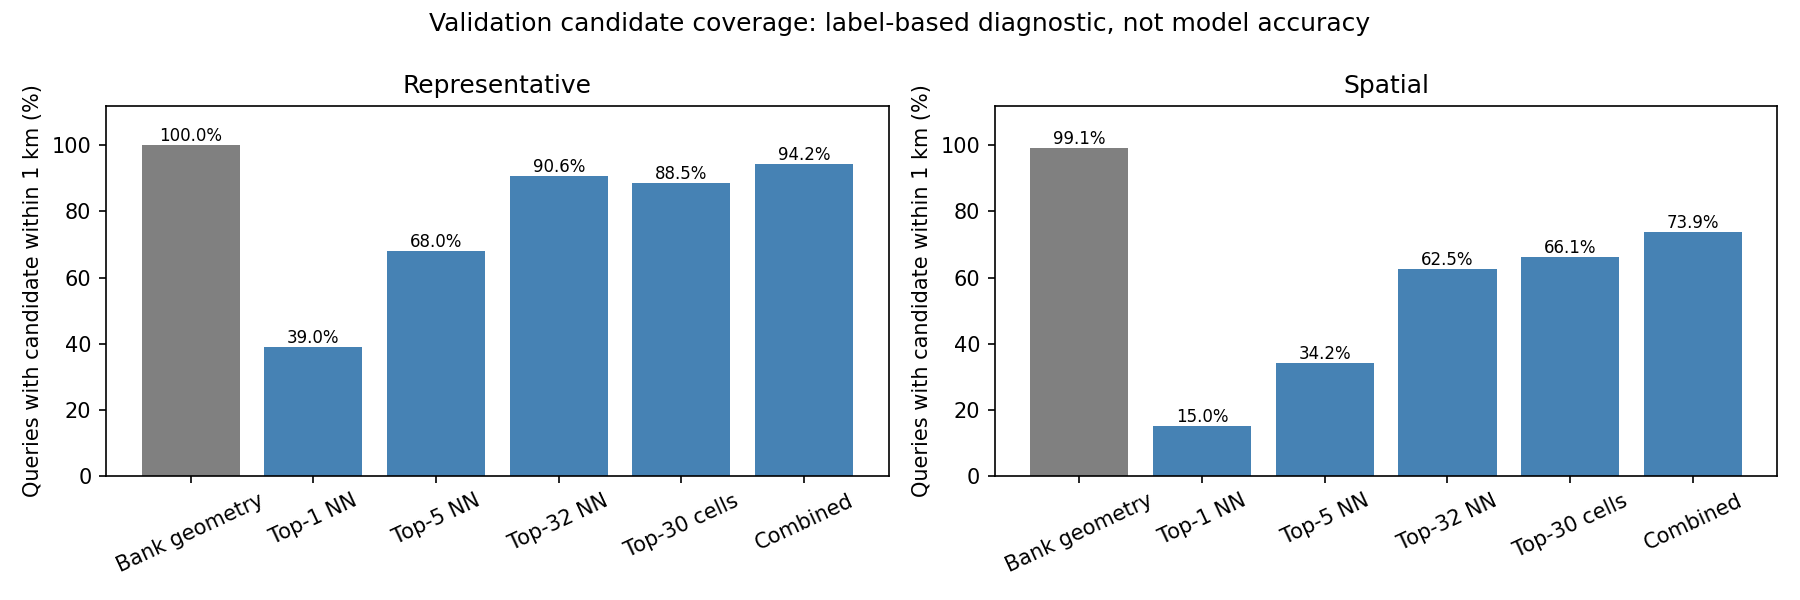

In [39]:
def run_retrieval_generalization_audit(root,device_name='auto',max_seconds=600.):
    require(0<max_seconds<=600,'Audit wall-clock limit exceeded')
    require(not (root/'outputs/retrieval_audit_latest.json').exists(),'Audit already exists; inspect before starting another')
    started=time.monotonic();frame,_=load_data(root)
    meta=json.loads((root/'outputs/features/streetclip_train_23f1be61d2b2b2cd.json').read_text())
    require(meta['complete'] and sha256(root/meta['feature_file'])==meta['feature_sha256'],'Audit cache identity mismatch')
    features=np.load(root/meta['feature_file'],mmap_mode='r')
    positions=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    fixed=json.loads((root/'outputs/splits.json').read_text())['splits']
    models=pd.read_csv(root/'outputs/streetclip_long40_metrics.csv')
    source_audit=json.loads((root/'outputs/cached_geo_study_artifact_audit.json').read_text())
    trusted={item['checkpoint']:item['checkpoint_sha256'] for item in source_audit['models'] if item['stage']=='long40'}
    device=choose_device(device_name)
    run_id=datetime.now(ZoneInfo('America/New_York')).strftime('%Y%m%dT%H%M%S')+'_retrieval_generalization_audit'
    directory=root/'outputs/runs'/run_id;directory.mkdir(exist_ok=False)
    source_path=directory/'source_notebook.ipynb';source_path.write_bytes((root/'NYCGuessr.ipynb').read_bytes())
    config={'query_chunk_size':128,'neighbor_k':32,'top_cells':30,'neighbor_temperature':.05,'cell_mass':.5,
            'neighbor_mass':.5,'thresholds_km':[.25,.5,1.],'same_id_excluded':True,'max_seconds':max_seconds,
            'model_training':False,'encoder_extraction':False,'oracle_use':'retrospective measurement only',
            'training_scope':'In-sample head/cell fit; self-excluded bank, not leave-one-out model fitting',
            'feature_cache_key':meta['cache_key'],'feature_cache_sha256':meta['feature_sha256']}
    save_json(directory/'config.json',config)
    summaries=[];metrics_rows=[];borough_rows=[];checkpoints=[]
    for model_row in models.itertuples(index=False):
        checkpoint=root/'outputs/runs'/model_row.run_id/'best.pth';rel=str(checkpoint.relative_to(root))
        checkpoint_hash=sha256(checkpoint);require(trusted.get(rel)==checkpoint_hash,'Retained audit checkpoint changed')
        model,saved=load_compass_head(root,checkpoint,device)
        split=fixed[model_row.split]
        require(saved['train_ids']==split['train_ids'] and saved['validation_ids']==split['validation_ids'],'Audit fold changed')
        require(not set(saved['train_ids'])&(set(saved['validation_ids'])|set(split['excluded_buffer_ids'])),'Audit fold/buffer leakage')
        training=frame.loc[saved['train_ids']];validation=frame.loc[saved['validation_ids']]
        train_values=np.array(features[positions.loc[training.sample_id]],dtype=np.float32,copy=True)
        train_probability,train_borough,bank=compass_outputs(model,train_values,device)
        valid_values=np.array(features[positions.loc[validation.sample_id]],dtype=np.float32,copy=True)
        valid_probability,valid_borough,valid_query=compass_outputs(model,valid_values,device)
        geography=saved['geography'];centers=np.asarray(geography['centers'])
        center_gps=centers/np.asarray(geography['scales'])+np.asarray(geography['origin'])
        reference_gps=training[['latitude','longitude']].to_numpy()
        for scope,truth,probability,borough,query in [('train',training,train_probability,train_borough,bank),
                                                   ('validation',validation,valid_probability,valid_borough,valid_query)]:
            predictions={name:[] for name in ('mixed_median','cell_median','neighbor_median')};measurements=[]
            coverage=nearest_bank_distance(training,truth)
            for start in range(0,len(truth),128):
                require(time.monotonic()-started<max_seconds,'Diagnostic wall-clock cap reached; no partial audit retained')
                stop=min(start+128,len(truth));chunk=truth.iloc[start:stop]
                # Query labels are deliberately absent from prediction/candidate construction.
                output,details=diagnostic_prediction_batch(training,chunk.sample_id,geography,bank,query[start:stop],
                                                           probability[start:stop],borough[start:stop])
                for name,prediction in output.items():predictions[name].append(prediction)
                actual=chunk[['latitude','longitude']].to_numpy()
                neighbor_gps=reference_gps[details['neighbors']]
                neighbor_distance=haversine_km(np.broadcast_to(actual[:,None,:],neighbor_gps.shape),neighbor_gps)
                all_center_gps=np.broadcast_to(center_gps[None,:,:],(len(chunk),len(center_gps),2))
                center_distance=haversine_km(np.broadcast_to(actual[:,None,:],all_center_gps.shape),all_center_gps)
                picked_distance=np.take_along_axis(center_distance,details['cells'],axis=1)
                nearest_cell=center_distance.argmin(axis=1)
                ranks=np.argsort(np.argsort(-probability[start:stop],axis=1,kind='stable'),axis=1,kind='stable')+1
                prediction=output['mixed_median']
                errors=haversine_km(actual,prediction[['latitude','longitude']])
                rows={'sample_id':chunk.sample_id.to_numpy(),'borough':chunk.borough.to_numpy(),
                      'predicted_borough':prediction.borough.to_numpy(),'wrong_borough':prediction.borough.to_numpy()!=chunk.borough.to_numpy(),
                      'error_km':errors,'nearest_bank_km':coverage[start:stop],
                      'neighbor1_best_km':neighbor_distance[:,0],'neighbor5_best_km':neighbor_distance[:,:5].min(axis=1),
                      'neighbor32_best_km':neighbor_distance.min(axis=1),'cell1_best_km':picked_distance[:,0],
                      'cell30_best_km':picked_distance.min(axis=1),'combined_best_km':np.minimum(neighbor_distance.min(axis=1),picked_distance.min(axis=1)),
                      'nearest_cell_rank':ranks[np.arange(len(chunk)),nearest_cell],
                      'nearest_cell_probability':probability[start:stop][np.arange(len(chunk)),nearest_cell],
                      'cell_mass_within_1km':(probability[start:stop]*(center_distance<=1.)).sum(axis=1),
                      'mixed_mass_within_1km':.5*(details['neighbor_weights']*(neighbor_distance<=1.)).sum(axis=1)
                                               +.5*(details['cell_weights']*(picked_distance<=1.)).sum(axis=1),
                      'self_matches':(training.sample_id.to_numpy()[details['neighbors']]==chunk.sample_id.to_numpy()[:,None]).sum(axis=1)}
                measurements.append(pd.DataFrame(rows))
            diagnostics=pd.concat(measurements,ignore_index=True)
            require(len(diagnostics)==len(truth) and diagnostics.sample_id.tolist()==truth.sample_id.tolist(),'Audit query coverage/order')
            require(not diagnostics.self_matches.any(),'Training query leaked into retrieval bank')
            require(bool((diagnostics.nearest_bank_km<=diagnostics.neighbor32_best_km+1e-8).all()),'Candidate coverage inconsistent')
            for a,b in [('neighbor1','neighbor5'),('neighbor5','neighbor32'),('cell1','cell30')]:
                require(bool((diagnostics[a+'_best_km']+1e-8>=diagnostics[b+'_best_km']).all()),'Candidate recall not monotonic')
            for name in ('cell_mass_within_1km','mixed_mass_within_1km'):
                require(bool(diagnostics[name].between(-1e-6,1+1e-6).all()),'Invalid geographic probability mass')
            diagnostics.to_csv(directory/f'{model_row.split}_{scope}_queries.csv',index=False)
            summary={'split':model_row.split,'scope':scope,**summarize_candidate_rows(diagnostics)}
            summary['nearest_bank_recall_1km']=float((diagnostics.nearest_bank_km<=1.).mean());summaries.append(summary)
            for method,chunks in predictions.items():
                prediction=pd.concat(chunks,ignore_index=True);scored=score_predictions(truth,prediction)
                prediction.to_csv(directory/f'{model_row.split}_{scope}_{method}.csv',index=False)
                metrics_rows.append({'split':model_row.split,'scope':scope,'method':method,**{k:v for k,v in scored.items() if k!='borough_metrics'}})
                if method=='mixed_median':
                    if scope=='validation':
                        expected=pd.read_csv(checkpoint.parent/'validation_best.csv')
                        require(prediction.sample_id.tolist()==expected.sample_id.tolist() and prediction.borough.tolist()==expected.borough.tolist(),'Audit changed retained validation IDs/boroughs')
                        np.testing.assert_allclose(prediction[['latitude','longitude']],expected[['latitude','longitude']],atol=1e-6,rtol=0)
                        require(abs(scored['score']-saved['metrics']['score'])<1e-7,'Audit changed retained score')
                    for name,part in diagnostics.groupby('borough',sort=False):
                        borough_rows.append({'split':model_row.split,'scope':scope,'borough':name,
                                             'borough_f1':scored['borough_metrics'][name]['f1'],**summarize_candidate_rows(part)})
                record_run(root,f'{run_id}_{model_row.split}_{scope}_{method}','retained_head_diagnostic_'+method,
                           model_row.split,scored,{**config,'query_scope':scope,'source_checkpoint':rel,'source_checkpoint_sha256':checkpoint_hash},
                           time.monotonic()-started,{'directory':str(directory.relative_to(root))},
                           'Diagnostic only; training is in-sample with self-matches excluded. No model or decoder selection.')
            print('Audited',model_row.split,scope,'mean GPS',round(summary['mixed_mean_km'],4),
                  'top32 recall@1km',round(summary['neighbor32_recall_1km'],4),flush=True)
        require(sha256(checkpoint)==checkpoint_hash,'Read-only audit changed checkpoint')
        checkpoints.append({'split':model_row.split,'checkpoint':rel,'sha256':checkpoint_hash})
        del model,train_values,valid_values
    pd.DataFrame(summaries).to_csv(directory/'candidate_summary.csv',index=False)
    pd.DataFrame(metrics_rows).to_csv(directory/'prediction_metrics.csv',index=False)
    pd.DataFrame(borough_rows).to_csv(directory/'borough_summary.csv',index=False)
    archive=json.loads(source_path.read_text());code='\n\n'.join(''.join(c['source']) for c in archive['cells'] if c['cell_type']=='code')
    report={'run_id':run_id,'directory':str(directory.relative_to(root)),'elapsed_seconds':time.monotonic()-started,
            'status':'completed','checkpoints':checkpoints,'source_code_sha256':hashlib.sha256(code.encode()).hexdigest(),
            'data_fingerprint':data_fingerprint(root),'split_sha256':sha256(root/'outputs/splits.json'),
            'feature_file':meta['feature_file'],'feature_sha256':meta['feature_sha256'],
            'self_matches':0,'all_queries_completed':True,'validation_predictions_reproduced':True,
            'training_performed':False,'encoder_extraction_performed':False,'test_inference_performed':False,
            'oracle_scope':'True query coordinates used only to measure coverage/recall/probability mass after prediction',
            'artifacts_sha256':{str(file.relative_to(root)):sha256(file) for file in sorted(directory.iterdir()) if file.is_file()}}
    require(report['elapsed_seconds']<max_seconds,'Audit completion exceeded cap')
    save_json(root/'outputs/retrieval_audit_latest.json',report)
    return report


def verify_retrieval_audit(root):
    report=json.loads((root/'outputs/retrieval_audit_latest.json').read_text())
    require(report['status']=='completed' and report['self_matches']==0 and report['all_queries_completed'],'Incomplete retrieval audit')
    require(report['data_fingerprint']==data_fingerprint(root) and report['split_sha256']==sha256(root/'outputs/splits.json'),'Audit data/split drift')
    require(sha256(root/report['feature_file'])==report['feature_sha256'],'Audit cache changed')
    for item in report['checkpoints']:require(sha256(root/item['checkpoint'])==item['sha256'],'Audited checkpoint changed')
    for path,digest in report['artifacts_sha256'].items():require(sha256(root/path)==digest,'Diagnostic artifact changed: '+path)
    logs=[json.loads(line) for line in (root/'outputs/experiment_log.jsonl').read_text().splitlines()]
    rows=[item for item in logs if item['run_id'].startswith(report['run_id'])]
    require(len(rows)==12 and all(item['code_sha256']['NYCGuessr.ipynb_code']==report['source_code_sha256'] for item in rows),'Diagnostic source/log mismatch')
    import ast
    directory=root/report['directory']
    archive=json.loads((directory/'source_notebook.ipynb').read_text())
    archived={node.name:ast.dump(node,include_attributes=False) for cell in archive['cells'] if cell['cell_type']=='code'
              for node in ast.parse(''.join(cell['source'])).body if isinstance(node,ast.FunctionDef)}
    for function in (diagnostic_neighbors,nearest_bank_distance,diagnostic_prediction_batch,summarize_candidate_rows,run_retrieval_generalization_audit):
        require(ast.dump(ast.parse(inspect.getsource(function)).body[0],include_attributes=False)==archived[function.__name__],
                'Audit producer changed; cached results cannot be presented as current execution')
    frame,_=load_data(root);splits=json.loads((root/'outputs/splits.json').read_text())['splits']
    table=pd.read_csv(directory/'prediction_metrics.csv');summary=pd.read_csv(directory/'candidate_summary.csv')
    require(len(table)==12 and len(summary)==4,'Incomplete diagnostic tables')
    for fold in ('representative','spatial'):
        for scope in ('train','validation'):
            ids=splits[fold][scope+'_ids'];truth=frame.loc[ids]
            queries=pd.read_csv(directory/f'{fold}_{scope}_queries.csv')
            require(queries.sample_id.tolist()==ids and not queries.self_matches.any(),'Saved audit IDs/self exclusions changed')
            actual_summary=summarize_candidate_rows(queries)
            saved_summary=summary.loc[(summary.split==fold)&(summary.scope==scope)].iloc[0]
            for name,value in actual_summary.items():
                # Original probability reductions are float32; CSV reload uses float64.
                tolerance=1e-7 if name in ('mixed_mass_within_1km_mean','cell_mass_within_1km_mean','nearest_cell_probability_mean') else 1e-8
                if value is not None:require(abs(saved_summary[name]-value)<tolerance,'Saved candidate summary mismatch: '+name)
            for method in ('mixed_median','cell_median','neighbor_median'):
                prediction=pd.read_csv(directory/f'{fold}_{scope}_{method}.csv')
                actual=score_predictions(truth,prediction)
                saved=table.loc[(table.split==fold)&(table.scope==scope)&(table.method==method)].iloc[0]
                for name in ('score','borough_macro_f1','gps_score','mean_km','median_km','p90_km'):
                    require(abs(actual[name]-saved[name])<1e-9,'Saved diagnostic metric mismatch')
                if method=='mixed_median':
                    ordered=prediction.set_index('sample_id').loc[ids]
                    np.testing.assert_allclose(queries.error_km,haversine_km(truth[['latitude','longitude']],ordered[['latitude','longitude']]),atol=1e-9,rtol=0)
    return report


RUN_RETRIEVAL_AUDIT=os.environ.get('NYCGUESSR_RETRIEVAL_AUDIT','0')=='1'
if RUN_RETRIEVAL_AUDIT:
    run_retrieval_generalization_audit(ROOT,DEVICE)
if (ROOT/'outputs/retrieval_audit_latest.json').exists():
    retrieval_audit=verify_retrieval_audit(ROOT)
    directory=ROOT/retrieval_audit['directory']
    diagnostic_metrics=pd.read_csv(directory/'prediction_metrics.csv')
    candidate_summary=pd.read_csv(directory/'candidate_summary.csv')
    borough_summary=pd.read_csv(directory/'borough_summary.csv')
    print('Retained model, training/validation diagnostics:',diagnostic_metrics.to_string(index=False))
    print('Candidate diagnostics:',candidate_summary.to_string(index=False))
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for axis,fold in zip(axes,('representative','spatial')):
        for i,scope in enumerate(('train','validation')):
            rows=borough_summary.loc[(borough_summary.split==fold)&(borough_summary.scope==scope)].set_index('borough').loc[list(BOROUGHS)]
            bars=axis.bar(np.arange(5)+(i-.5)*.35,rows.mixed_mean_km,width=.34,label='Training (self-excluded)' if scope=='train' else 'Validation')
            axis.bar_label(bars,fmt='%.2f',fontsize=8)
        axis.set(title=fold.capitalize(),ylabel='Mean Haversine error (km)',xticks=np.arange(5),xticklabels=['Bronx','Brooklyn','Manhattan','Queens','Staten I.'])
        axis.tick_params(axis='x',rotation=20);axis.set_ylim(0,max(14,axis.get_ylim()[1]*1.1))
    axes[0].legend(fontsize=8);fig.suptitle('Fixed model: in-sample training fit versus held-out development')
    fig.tight_layout();fig.savefig(ROOT/'outputs/figures/retrieval_audit_borough_errors.png',dpi=150)
    display(DisplayImage(filename=str(ROOT/'outputs/figures/retrieval_audit_borough_errors.png')));plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    names=['nearest_bank','neighbor1','neighbor5','neighbor32','cell30','combined']
    labels=['Bank geometry','Top-1 NN','Top-5 NN','Top-32 NN','Top-30 cells','Combined']
    for axis,fold in zip(axes,('representative','spatial')):
        row=candidate_summary.loc[(candidate_summary.split==fold)&(candidate_summary.scope=='validation')].iloc[0]
        bars=axis.bar(np.arange(len(names)),[100*row[name+'_recall_1km'] for name in names],color=['gray']+['steelblue']*5)
        axis.bar_label(bars,fmt='%.1f%%',fontsize=8);axis.set(title=fold.capitalize(),ylabel='Queries with candidate within 1 km (%)',ylim=(0,112),xticks=np.arange(len(names)),xticklabels=labels)
        axis.tick_params(axis='x',rotation=25)
    fig.suptitle('Validation candidate coverage: label-based diagnostic, not model accuracy')
    fig.tight_layout();fig.savefig(ROOT/'outputs/figures/retrieval_audit_candidate_recall.png',dpi=150)
    display(DisplayImage(filename=str(ROOT/'outputs/figures/retrieval_audit_candidate_recall.png')));plt.close(fig)


## Retrieval audit findings and next decision — 2026-11-16

The fixed-model audit completed **23,001 query evaluations** across both training/validation folds in **16.56 seconds** with no head training or image extraction. All retrieval banks contained only the relevant training fold; same-ID self-matches were excluded. The retained validation predictions/scores were reproduced exactly within numerical tolerance.

| Measurement | Representative | Spatial |
|---|---:|---:|
| Training mixed mean GPS error, self-excluded retrieval | **2.5316 km** | **2.2752 km** |
| Validation mixed mean GPS error | **4.4150 km** | **5.9877 km** |
| Validation mean minus training mean | 1.8834 km | 3.7125 km |
| Validation top-1 neighbor within 1 km | 38.95% | 15.04% |
| Validation any top-5 neighbor within 1 km | 68.00% | 34.24% |
| Validation any top-32 neighbor within 1 km | **90.64%** | **62.54%** |
| Validation any top-30 cell center within 1 km | 88.49% | 66.13% |
| Validation combined candidate pool contains a point within 1 km | **94.18%** | **73.90%** |
| Actual bank contains a distinct training location within 1 km (geometry only) | 100.00% | 99.09% |
| Mean distance to geographically closest bank point (geometry only) | 0.1256 km | 0.4319 km |

Training scores **0.762389 / 0.786578**, Macro-F1 **0.902304 / 0.913484** and GPS errors above are **in-sample fit diagnostics**. Excluding retrieval self-matches does not undo exposure to query labels in head training or geographic cells. They are not leave-one-out validation or leaderboard estimates. Nonzero training error alone does not distinguish limited capacity, optimization, regularization, objective mismatch or representation quality.

The top-32 versus top-1 gap supports prioritizing ranking/discrimination. In representative validation, **220 of 305 (72.13%)** predictions more than 10 km wrong already contain a combined candidate within 1 km; spatial validation has **169 of 430 (39.30%)**. Useful candidates can receive too little mass: the average mixed candidate weight within 1 km of truth is **20.52% / 8.23%**. These truth-dependent quantities measure a failure mode; they are not calibrated confidence scores or deployable rules. Selecting the geographically closest candidate would require the unknown answer.

For illustration, representative validation ID **8084** has a top-ranked neighbor only **0.100 km** from the true location, but the final mixture is **47.904 km** away. Another extreme, ID **7771**, has no combined candidate closer than **17.908 km**. Both candidate weighting and candidate omission occur; neither one explains every failure. The best candidate's mean distance **0.4412 / 1.2156 km** is an oracle over a fixed finite pool, not an achievable model score or a bound on continuous coordinate inference.

The spatial deterioration is substantial even though a training coordinate within 1 km exists for 99.09% of queries. Its lower candidate recall and larger fit/validation gap suggest geographic generalization needs attention; these diagnostics do not prove that changing the frozen encoder is necessary. Spatial Staten Island is the clearest borough concern: training mean **3.5826 km**, validation **11.9593 km**, top-32 recall within 1 km **51.18%**. Corresponding representative Staten Island values are **4.0040 / 7.6971 km**, recall **89.82%**. Aggregate evidence should drive experiments rather than hand-fixing specific examples.

Decoder-only controls are mixed: neighbor-only GPS improves representative **4.4150→4.3575 km**, but worsens spatial **5.9877→6.1153 km**. Cell-only is worse on both (**4.6993 / 6.0943 km**). **Keep the validated mixed decoder and both existing checkpoints.** No post-hoc decoder replacement or new best-score claim was made.

**Single recommended next experiment:** a controlled cached-feature head comparison that adds geographically distant, visually confusable training negatives to the current paired sampler. Use only training-fold labels/features for mining; mix ordinary and difficult negatives, preserve nearby positives and the same loss/schedule/decoder, and compare against a matched control on both fixed folds. Measure top-1/top-32 recall and mean/p90 GPS alongside the composite. This tests whether stronger geographic discrimination improves ranking and generalization cheaply before a new encoder pass. No such training was started in this audit, and improvement is not guaranteed.

Evidence: `outputs/retrieval_audit_latest.json` points to `outputs/runs/20261116T173009_retrieval_generalization_audit/`, containing per-query measurements, 12 prediction CSVs, aggregate/borough tables, config and source snapshot. Producer/source and artifact/checkpoint/cache hashes, exact IDs, zero self-matches, saved score/summary round trips and existing validation predictions were verified. A CSV verification initially flagged the expected float32 probability-mean versus float64 reload difference (maximum **2.50e-8**); only those three probability-summary tolerances were adjusted to 1e-7, while GPS/score checks remain tight and prediction bytes remain unchanged.

Initial audit execution passed **40 code cells / 36 tests / zero errors in 40.98 s**. Final training/extraction/audit-disabled restart-and-run-all passed **40 code cells / 36 tests / zero errors / 15 figures in 41.51 s**. Both new scientific figures were visually inspected. The complete feature cache, retained model predictions and source inputs are unchanged. No final all-label refit, test inference, Kaggle upload, dependency change or HPC action occurred.


## Experiment tracker

Every completed epoch records the score, Macro-F1, GPS score, mean/median/p90 error, borough-wise errors, config, data/split/notebook-source hashes and runtime. Smoke runs are excluded here. We retain the best validation checkpoint and stop after four non-improving epochs or the time limit. Incomplete epochs are not selected.

After training we compare the head with k=1 and k=5 retrieval using embeddings from the training fold only. This is development selection and does not create an untouched test estimate.
The 2,048-location continuation uses the same validation IDs and separately logged matched training-ID controls. The training-only memorization check is excluded from this performance table and has a separately labeled curve. Its score cannot be compared with the leaderboard target.

The full-fold curve begins from the earlier 2,048-location checkpoint, so its epoch index restarts for the warm stage. It is not a from-scratch, equal-budget ablation.


                                                                                       run_id                                    model          split  training_locations  train_limit                  initialization    score  borough_macro_f1  gps_score   mean_km
                                              20261114T130120_representative_geographic_prior                         geographic_prior representative              9492.0          NaN               historical/random 0.011283          0.112833   0.000000 11.285877
                                              20261114T130120_representative_rgb_retrieval_k1                         rgb_retrieval_k1 representative              9492.0          NaN               historical/random 0.032935          0.329351   0.000000 13.874941
                                              20261114T130120_representative_rgb_retrieval_k5                         rgb_retrieval_k5 representative              9492.0          NaN               historical/ran

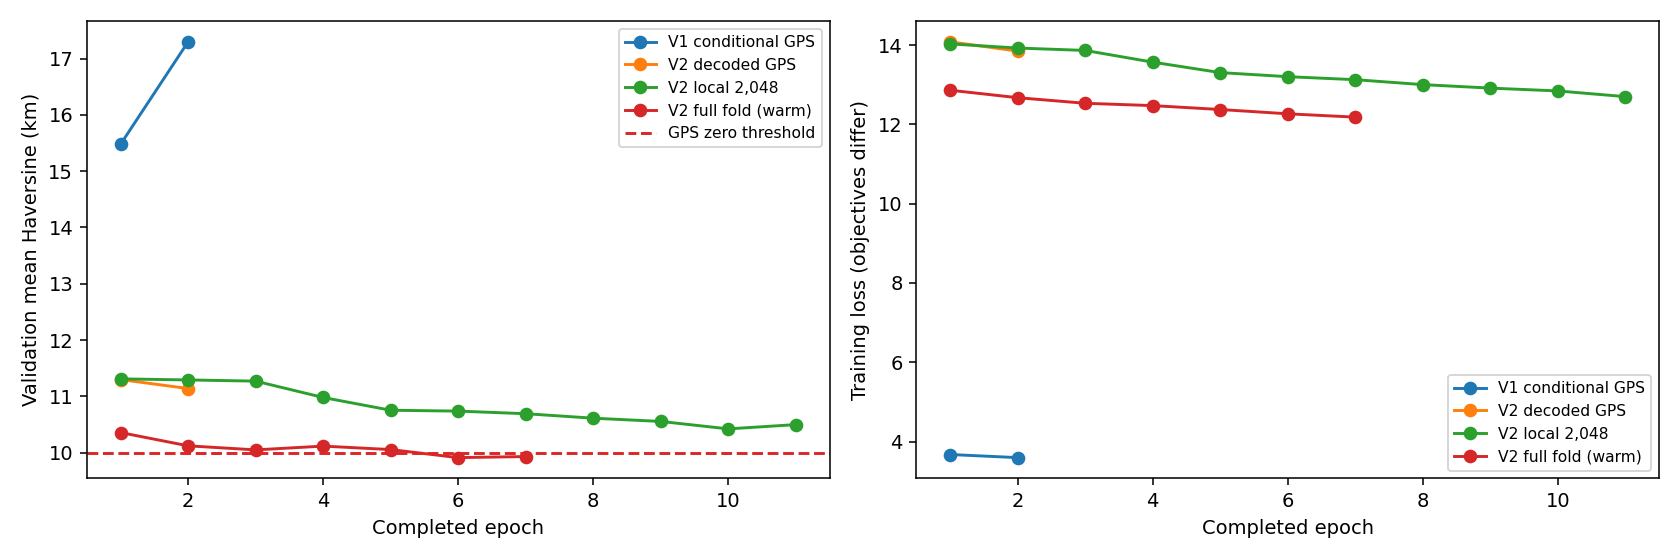

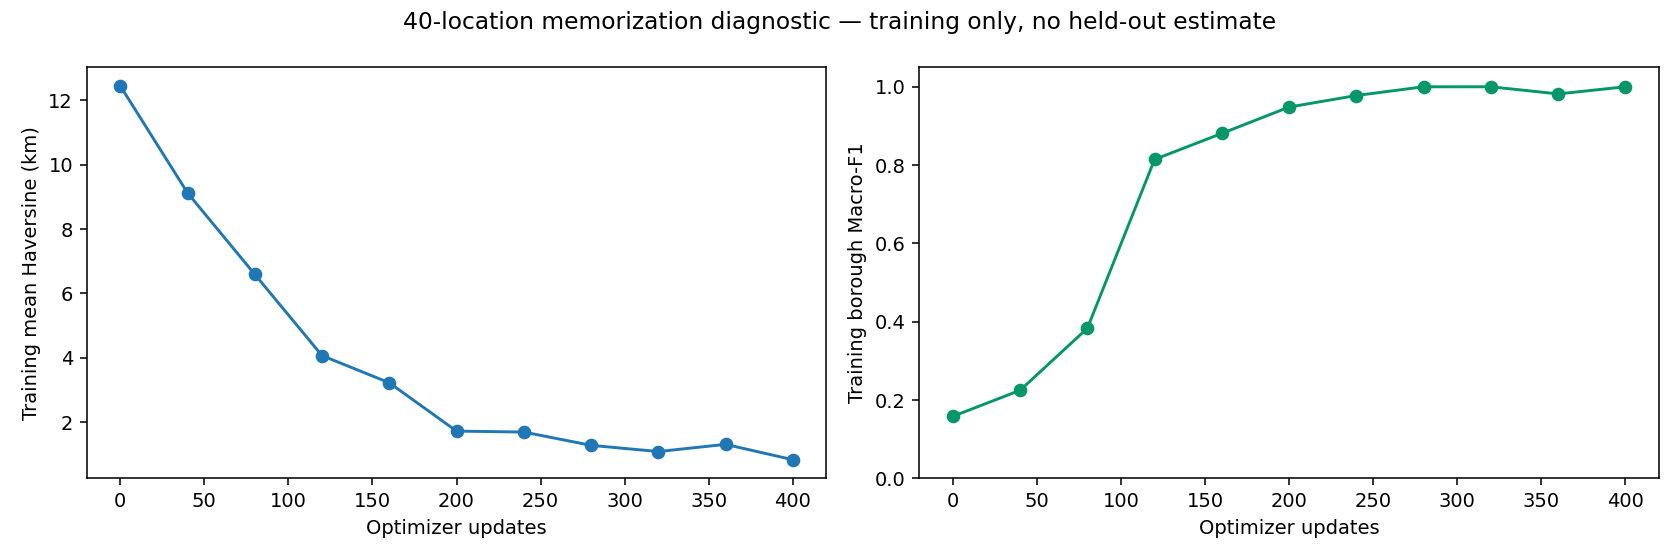

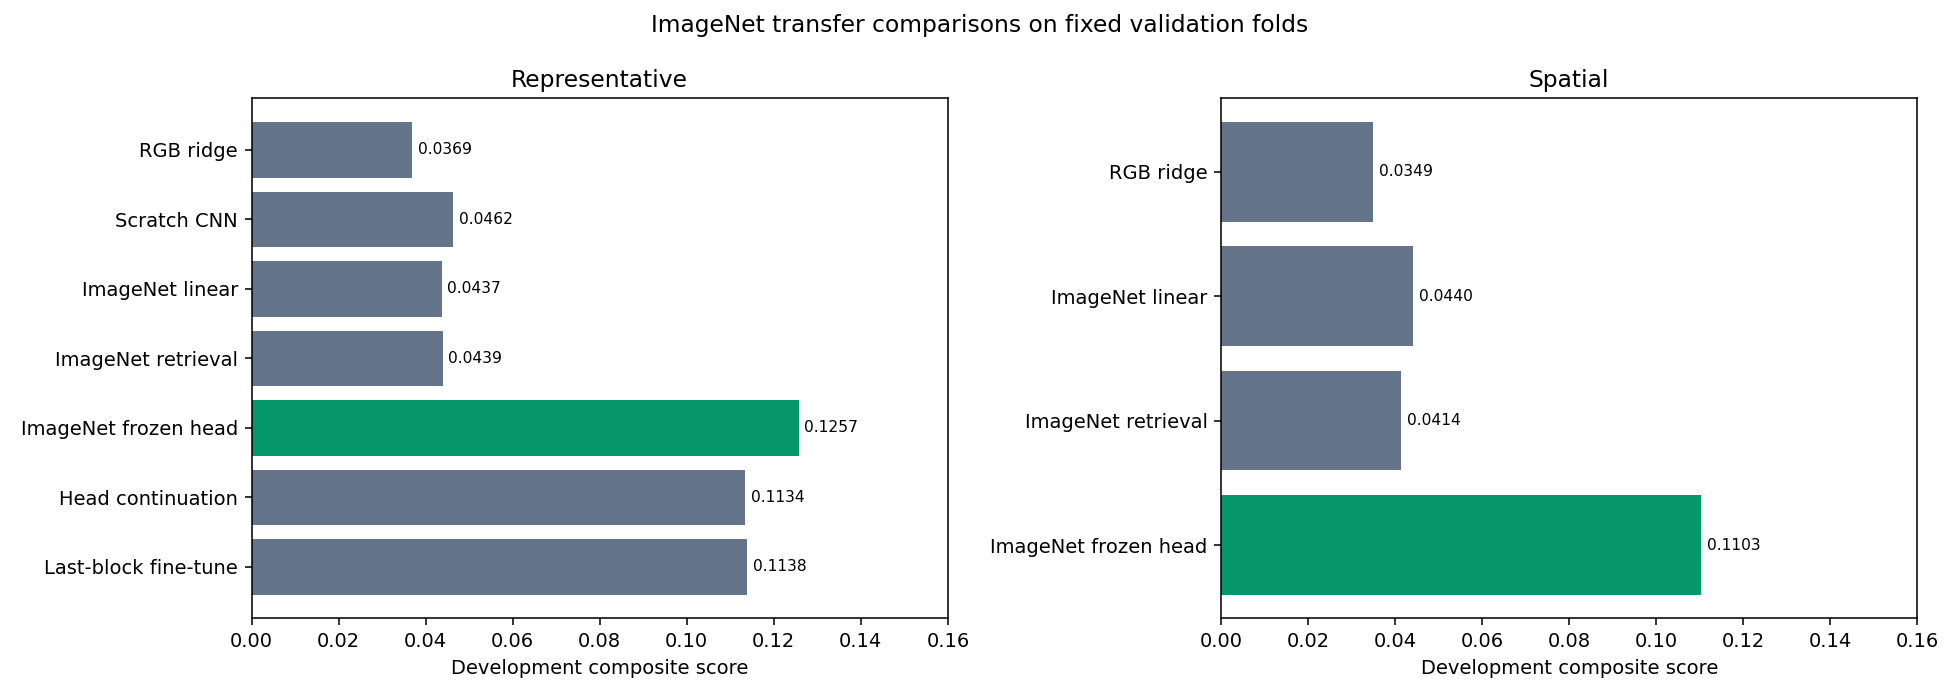

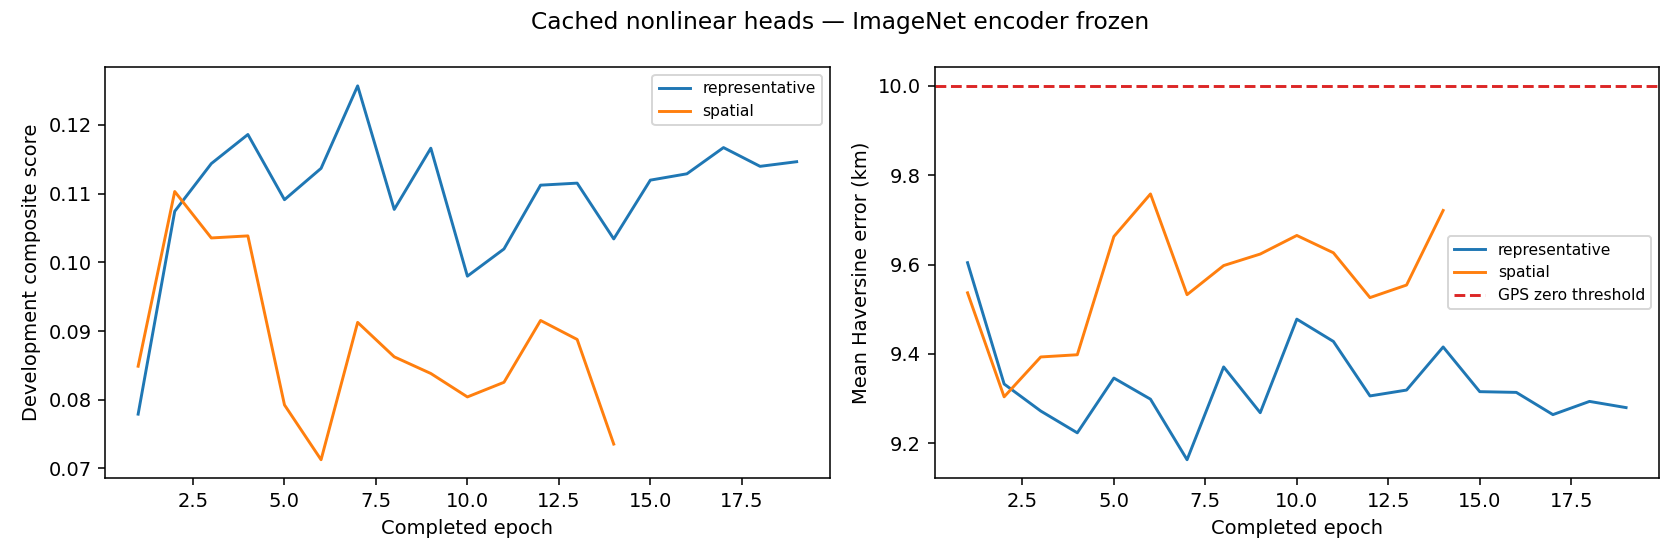

In [40]:
records = [json.loads(line) for line in (ROOT / "outputs/experiment_log.jsonl").read_text().splitlines()]
measured = [{"run_id": row["run_id"], "model": row["model"], "split": row["split"],
             "training_locations": row.get("config", {}).get("training_locations"),
             "train_limit": row.get("config", {}).get("train_limit"),
             "initialization": row.get("config", {}).get("initialization", "historical/random"),
             **{key: row["metrics"].get(key) for key in ("score", "borough_macro_f1", "gps_score", "mean_km")}}
            for row in records if "model" in row and not row.get("config", {}).get("smoke", False)]
print(pd.DataFrame(measured).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run_id, label in (("20261114T133917_cnn_representative", "V1 conditional GPS"),
                      ("20261114T135115_cnn_representative", "V2 decoded GPS"),
                      ("20261114T143039_cnn_representative_local2048", "V2 local 2,048"),
                      ("20261114T153649_cnn_representative_warm", "V2 full fold (warm)")):
    history_path = ROOT / "outputs/runs" / run_id / "history.json"
    if history_path.exists():
        history = json.loads(history_path.read_text())["epochs"]
        axes[0].plot([row["epoch"] for row in history], [row["metrics"]["mean_km"] for row in history], "o-", label=label)
        axes[1].plot([row["epoch"] for row in history], [row["mean_training_loss"] for row in history], "o-", label=label)
axes[0].axhline(10, color="#dc2626", linestyle="--", label="GPS zero threshold")
axes[0].set(xlabel="Completed epoch", ylabel="Validation mean Haversine (km)")
axes[1].set(xlabel="Completed epoch", ylabel="Training loss (objectives differ)")
for axis in axes:
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / "outputs/figures/cnn_pilot_progress.png", dpi=140)
display(DisplayImage(filename=str(ROOT / "outputs/figures/cnn_pilot_progress.png")))
plt.close(fig)

# The tiny-fit curve is training-only and must never share a validation legend.
tiny_path = ROOT / "outputs/runs/20261114T150754_tiny_fit_diagnostic/history.json"
if tiny_path.exists():
    points = json.loads(tiny_path.read_text())["points"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    steps = [point["step"] for point in points]
    axes[0].plot(steps, [point["training_metrics"]["mean_km"] for point in points], "o-")
    axes[0].set(xlabel="Optimizer updates", ylabel="Training mean Haversine (km)")
    axes[1].plot(steps, [point["training_metrics"]["borough_macro_f1"] for point in points], "o-", color="#059669")
    axes[1].set(xlabel="Optimizer updates", ylabel="Training borough Macro-F1", ylim=(0, 1.05))
    fig.suptitle("40-location memorization diagnostic — training only, no held-out estimate")
    fig.tight_layout()
    fig.savefig(ROOT / "outputs/figures/tiny_fit_diagnostic.png", dpi=140)
    display(DisplayImage(filename=str(ROOT / "outputs/figures/tiny_fit_diagnostic.png")))
    plt.close(fig)


if (ROOT / "outputs/imagenet_transfer_metrics.csv").exists():
    transfer = pd.read_csv(ROOT / "outputs/imagenet_transfer_metrics.csv")
    selective = pd.read_csv(ROOT / "outputs/imagenet_selective_metrics.csv") if (ROOT / "outputs/imagenet_selective_metrics.csv").exists() else pd.DataFrame()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for axis, split_name in zip(axes, ("representative", "spatial")):
        rows = [("RGB ridge", float(baseline[(baseline.split == split_name) & (baseline.model == "rgb_ridge")].score.iloc[0]))]
        if split_name == "representative":
            old_selection = ROOT / "outputs/runs/20261114T153649_cnn_representative_warm/selection.json"
            if old_selection.exists():
                rows.append(("Scratch CNN", json.loads(old_selection.read_text())["metrics"]["head"]["score"]))
        labels = {"ridge": "ImageNet linear", "retrieval_k5": "ImageNet retrieval", "frozen_nonlinear_head": "ImageNet frozen head"}
        for row in transfer[transfer.split == split_name].itertuples(index=False):
            rows.append((labels[row.method], row.score))
        if split_name == "representative" and not selective.empty:
            for row in selective.itertuples(index=False):
                rows.append(("Head continuation" if row.method == "head_continuation_control" else "Last-block fine-tune", row.score))
        names, values = zip(*rows)
        colors = ["#059669" if name == "ImageNet frozen head" else "#64748b" for name in names]
        bars = axis.barh(names, values, color=colors)
        axis.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
        axis.set(title=split_name.capitalize(), xlabel="Development composite score", xlim=(0, min(1., max(.16, max(values) * 1.25))))
        axis.invert_yaxis()
    fig.suptitle("ImageNet transfer comparisons on fixed validation folds")
    fig.tight_layout()
    fig.savefig(ROOT / "outputs/figures/imagenet_transfer_comparison.png", dpi=140)
    display(DisplayImage(filename=str(ROOT / "outputs/figures/imagenet_transfer_comparison.png")))
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for row in transfer[transfer.method == "frozen_nonlinear_head"].itertuples(index=False):
        history = json.loads((ROOT / "outputs/runs" / row.run_id / "history.json").read_text())["epochs"]
        steps = [point["epoch"] for point in history]
        axes[0].plot(steps, [point["metrics"]["score"] for point in history], label=row.split)
        axes[1].plot(steps, [point["metrics"]["mean_km"] for point in history], label=row.split)
    axes[0].set(xlabel="Completed epoch", ylabel="Development composite score")
    axes[1].set(xlabel="Completed epoch", ylabel="Mean Haversine error (km)")
    axes[1].axhline(10, color="#dc2626", linestyle="--", label="GPS zero threshold")
    for axis in axes:
        axis.legend(fontsize=8)
    fig.suptitle("Cached nonlinear heads — ImageNet encoder frozen")
    fig.tight_layout()
    fig.savefig(ROOT / "outputs/figures/imagenet_head_learning_curves.png", dpi=140)
    display(DisplayImage(filename=str(ROOT / "outputs/figures/imagenet_head_learning_curves.png")))
    plt.close(fig)


## Final fit and submission CSV

The user requested a Kaggle CSV on 2026-11-16. The retained representative StreetCLIP configuration has now been refitted from fresh initialization on all **11,864 labeled locations**, completing **40 epochs in 53.72 seconds**, with 1-km geographic targets, unchanged losses and mixed decoding. Its final fit has no held-out score; source development scores remain **0.582646 / 0.436519**. No hard-negative experiment was included.

All **7,908 test locations / 31,632 images** were verified against the original input hashes and encoded with the same frozen model/native-336 preprocessing. The separate resumable test pass took **4,088.44 seconds (68.14 minutes)** within its 75-minute cap. Cache: `outputs/features/streetclip_test_f1901b97eac036c7.npy`, `[7908,4,1024]` float16, SHA `b6870dc542cdfd23cc701572da74fe5b239dec0088eee90679a539c9bcb39695`. Previous extraction budgets/caches remain intact. Template prediction placeholders were never inputs or targets.

**Ready CSV:** `Kaggle Submissions/nycguessr_streetclip40_20261116.csv` — **7,908 rows**, headers `sample_id,borough,latitude,longitude`, official template ID order, **302,382 bytes**, SHA `c065fb05a3f31c9195f4132f726c2f6c7d1b52195b831dcc59dbe877e33dc35f`. Predictions use the full official training bank. Internal namespace keys distinguish test IDs from identical numeric training IDs while preserving the ordinary validation overlap guard.

Final checkpoint: `outputs/runs/20261116T174151_compass_submission40_full/best.pth`, SHA `8991cb2d59eb8cc77272b37644b8af94cdbd5817001af8652791c7e4e91fe4f1`. Provenance and exact validation are in `outputs/streetclip_submission_manifest.json` and `outputs/streetclip_submission_verification.json`. The latter strictly reloads the final head and regenerates every prediction from verified caches. Coordinates are checked against training-derived candidate extents; no external maps, manual edits, quota matching or clipping are used.

The user reports uploading this candidate and obtaining **0.60599 on the public leaderboard**. Record this separately from the two development scores and the all-label refit, which has no held-out score. This result has not been independently verified through Kaggle; its exact submission timestamp and submission ID are unknown. The agent did not perform the upload. Historical generation manifests correctly describe the state before the user reported this result. All final-run flags default off. The new StreetCLIP workflow refuses to overwrite a CSV and reuses a verified complete refit/cache when resuming. Legacy CNN/ImageNet export flags below remain disabled and do not select the current candidate.

Actual final training/extraction-disabled restart-and-run-all passed **42 code cells / 38 checks / zero errors / 15 figures in 31.13 seconds**. All 7,908 test predictions were regenerated from the saved checkpoint/caches; boroughs match exactly and maximum coordinate difference from the eight-decimal CSV is **4.9997e-9 degrees**. Initial submission generation executed in **4,187.38 seconds (69.79 minutes)** with zero notebook errors. Test cache size is **64,782,464 bytes**; sampled peak MPS driver allocation was **1,514,881,024 bytes (~1.41 GiB)**, not an exact whole-system peak. Evidence: `outputs/notebook_submission_execution.json`, `outputs/notebook_submission_final_verification.json`, `outputs/streetclip_submission_verification.json`.


### Next experiment — original outline (implemented in cells 65–75)

**Baseline:** user-reported public score **0.60599**, associated with the CSV and SHA above. Representative development score **0.582646104**, mean error **4.414989 km**; spatial development score **0.436518798**, mean error **5.987724 km**. Preserve the exact current candidate and all historical evidence. The current frozen StreetCLIP encoder already uses a 24-layer ViT-L/14 at 336 pixels; the next hypothesis concerns different visual representations and spatial information, not introducing a ViT for the first time.

**Hypothesis:** DINOv2 ViT-B/14 features may complement StreetCLIP, and retaining coarse spatial patch features may improve recognition of geographically useful structures lost in a single global descriptor. This is untested. Official reference: https://github.com/facebookresearch/dinov2 (86M-parameter ViT-B/14; global and patch features). All pretrained image encoders are allowed under the user's recorded course clarification; external images, maps, coordinates and test labels remain prohibited.

Original proposed stages (now implemented in cells 65–75; use that run guide):

1. **V1 — Setup and preflight.** Verify existing data/split hashes, detect MPS/CUDA, record environment and resource limits, and load a pinned approved encoder with exact preprocessing/provenance. Preserve the current StreetCLIP feature-producing code.
2. **V2 — GPU benchmark.** Use warm-up and synchronized timing; benchmark bounded batch sizes and input-loading options. Check float16 features against float32 before choosing the fastest stable configuration. Record images/second, memory and estimated full-pass time. Keep a configurable time limit and memory headroom; never disable allocation guards to force utilization.
3. **V3 — Training-image feature cache.** Encode all 11,864 labeled locations lazily, retaining one CLS vector plus four 2x2 pooled patch-region vectors per directional image. Store resumable float16 arrays with coverage/identity hashes, progress, ETA and phase time accounting; do not retain every dense patch token. Test-image extraction is deferred until model selection.
4. **V4 — Controlled head experiments.** Compare preserved StreetCLIP against DINO global-only, then DINO global-plus-region features, with original representative/spatial folds, fixed seed, comparable head width/depth, losses, 40-epoch schedule and decoder. Region and compass position encodings distinguish tokens. Fit all statistics, cells and retrieval banks on training folds only. Report parameter/compute differences; encoder comparison is not a pure architectural ablation. Try complementary StreetCLIP/DINO fusion only if the measured results justify a separately logged experiment.
5. **V5 — Validation and progress dashboard.** Track composite score, all-five-class Macro-F1, GPS score, mean/median/p90 Haversine km, borough errors, >10/>20-km error rates, top-1/5/32 retrieval recall within 0.25/0.5/1 km, train/validation gaps, losses, runtime, throughput, memory, seed, split/model/source hashes and retain/reject decisions. Exclude training self-matches and label training diagnostics as in-sample. Require meaningful gains on both fixed folds before replacing the baseline; assess uncertainty before escalating compute. Hard-negative training or unfreezing final encoder blocks would be later separate experiments, not simultaneous changes.
6. **V6 — Selected model and CSV.** Only after validation selects an improvement, refit on all labels, extract any missing test features, validate all 7,908 rows and export a new versioned CSV. Kaggle upload remains a separate explicitly authorized action.

**Workflow preference:** all new active code, checks, metric dashboards and progress logging belong in this notebook. The user launches the relevant labeled cells; subsequent assistant handoffs should give the exact cell numbers/names and concise outcomes. Do not autonomously start long training/extraction runs. The outline below was subsequently implemented in cells 65–75. Follow the new run guide there. Real encoder benchmark, extraction and training remain user-run; no DINO performance result is claimed.


In [41]:
def verify_official_test_inputs(root,frame):
    """Verify supplied test image bytes without decoding/loading them into RAM."""
    expected={str(Path('Data/test')/row[f'image_{direction}']) for _,row in frame.iterrows() for direction in DIRECTIONS}
    require(len(expected)==31632,'Test four-view count differs')
    manifest=root/'outputs/input_manifest.jsonl'
    provenance=json.loads((root/'DATA_SOURCES.json').read_text())
    require(sha256(manifest)==provenance['artifacts']['raw_file_manifest_sha256'],'Original input manifest changed')
    entries=[json.loads(line) for line in manifest.read_text().splitlines()]
    selected=sorted([entry for entry in entries if entry['path'] in expected],key=lambda item:item['path'])
    require(len(selected)==len(expected) and {item['path'] for item in selected}==expected,'Missing/duplicate test manifest entries')
    for item in selected:
        path=root/item['path']
        require(path.is_file() and path.stat().st_size==item['bytes'] and sha256(path)==item['sha256'],'Test input changed: '+item['path'])
    digest=hashlib.sha256(json.dumps(selected,sort_keys=True).encode()).hexdigest()
    report={'test_images':len(selected),'locations':len(frame),'test_manifest_sha256':digest,
            'input_manifest_sha256':sha256(manifest),'template_sha256':sha256(root/'Data/sample_submission.csv'),
            'all_test_image_hashes_verified':True,'template_predictions_used':False}
    save_json(root/'outputs/streetclip_test_input_audit.json',report)
    return report


@torch.inference_mode()
def extract_streetclip_test_features(root,frame,train_metadata,device_name='auto'):
    """One separately authorized 75-minute cumulative, resumable test-image pass."""
    require(len(frame)==7908 and set(frame.sample_id)==set(range(7908)),'Full official test IDs required')
    require(list(frame.columns)==['sample_id',*[f'image_{d}' for d in DIRECTIONS]],'Test frame must not contain target placeholders')
    integrity=verify_official_test_inputs(root,frame)
    spec=streetclip_cache_spec(root,frame,train_metadata['spec']['encoder'])
    spec.update(split='test',test_manifest_sha256=integrity['test_manifest_sha256'],template_sha256=integrity['template_sha256'],
                test_pipeline_sha256=hashlib.sha256((inspect.getsource(extract_streetclip_test_features)+inspect.getsource(official_test_frame)).encode()).hexdigest())
    key=hashlib.sha256(json.dumps(spec,sort_keys=True).encode()).hexdigest()
    directory=root/'outputs/features';path=directory/f'streetclip_test_{key[:16]}.npy';meta_path=path.with_suffix('.json')
    if path.exists() or meta_path.exists():
        require(path.exists() and meta_path.exists(),'Incomplete test cache metadata')
        meta=json.loads(meta_path.read_text())
        require(meta['complete'] and meta['spec']==spec and meta['cache_key']==key and sha256(path)==meta['feature_sha256'],'Test cache identity mismatch')
        values=np.load(path,mmap_mode='r');require(values.shape==(7908,4,1024) and values.dtype==np.float16,'Test cache shape/dtype mismatch')
        return values,meta
    partial=path.with_suffix('.partial.npy');state_path=path.with_suffix('.partial.json')
    budget_path=directory/'streetclip_test_budget.json'
    budget=json.loads(budget_path.read_text()) if budget_path.exists() else {
        'phase':'first_streetclip_test_csv_20261116','limit_seconds':4500.,'used_seconds':0.,
        'authorization':'User requested Kaggle submission CSV on 2026-11-16; necessary bounded test inference'}
    require(budget['limit_seconds']==4500. and 0<=budget['used_seconds']<4495.,'Test extraction phase budget exhausted')
    completed=0
    if partial.exists() or state_path.exists():
        require(partial.exists() and state_path.exists(),'Incomplete partial test cache bookkeeping')
        state=json.loads(state_path.read_text());require(state['cache_key']==key,'Partial test extractor identity differs')
        completed=state['completed_rows'];require(isinstance(completed,int) and 0<=completed<=7908,'Invalid partial coverage')
        values=np.load(partial,mmap_mode='r+');require(values.shape==(7908,4,1024) and values.dtype==np.float16,'Partial test shape/dtype')
        for start in range(0,completed,512):require(bool(np.isfinite(values[start:min(start+512,completed)]).all()),'Nonfinite committed test cache')
    else:values=np.lib.format.open_memmap(partial,mode='w+',dtype=np.float16,shape=(7908,4,1024))
    used_before=budget['used_seconds'];initial=completed;started=time.monotonic();peak_driver=0;status='extracting'
    def checkpoint(status):
        values.flush();elapsed=time.monotonic()-started
        budget['used_seconds']=used_before+elapsed;save_json(budget_path,budget)
        state={'cache_key':key,'status':status,'completed_rows':completed,'total_rows':7908,
               'initial_rows':initial,'elapsed_seconds':elapsed,'aggregate_budget_used_seconds':budget['used_seconds'],
               'images_per_second':4*(completed-initial)/max(elapsed,1e-6),'sampled_peak_mps_driver_bytes':peak_driver}
        save_json(state_path,state);save_json(directory/'streetclip_test_progress.json',state)
        return state
    checkpoint('starting')
    device=choose_device(device_name)
    require(device.type in ('mps','cuda'),'Test extraction requires available GPU')
    try:
        model,preprocess,encoder=load_streetclip_encoder(root,device,allow_download=False)
        require(plain_checkpoint_metadata(encoder)==train_metadata['spec']['encoder'],'Test/train encoder differs')
        loader=make_loader(ImageNetViews(root,frame.iloc[completed:],preprocess,split='test'),2,workers=0)
        for batch in loader:
            if used_before+time.monotonic()-started>=4495.:
                status='budget_exhausted';break
            expected=frame.sample_id.iloc[completed:completed+len(batch['sample_id'])].to_numpy()
            require(np.array_equal(expected,batch['sample_id'].numpy()),'Test extraction reordered IDs')
            images=batch['images'].to(device=device,dtype=next(model.parameters()).dtype)
            vectors=model(pixel_values=images.flatten(0,1)).pooler_output.reshape(len(images),4,1024).float().cpu().numpy().astype(np.float16)
            require(bool(np.isfinite(vectors).all()),'Nonfinite test features')
            values[completed:completed+len(images)]=vectors;completed+=len(images)
            if device.type=='mps':
                peak_driver=max(peak_driver,torch.mps.driver_allocated_memory())
                require(peak_driver<=8*1024**3,'Test extraction driver memory exceeded eight GiB')
            if completed%32==0 or completed==7908:checkpoint('extracting')
        synchronize_device(device)
        status='complete' if completed==7908 else status
        del model
    finally:report=checkpoint(status if completed==7908 else 'incomplete')
    require(completed==7908,'Test extraction incomplete; resume this same cache/budget before exporting')
    for start in range(0,7908,512):require(bool(np.isfinite(values[start:start+512]).all()),'Nonfinite final test cache')
    del values
    partial.replace(path)
    meta={'cache_key':key,'spec':spec,'complete':True,'feature_file':str(path.relative_to(root)),
          'feature_sha256':sha256(path),'bytes':path.stat().st_size,'extraction':report}
    save_json(meta_path,meta)
    if device.type=='mps':torch.mps.empty_cache()
    return np.load(path,mmap_mode='r'),meta


def prepare_streetclip_submission(root,device_name='auto'):
    """Refit the selected config, extract official test features, and create one audited CSV."""
    started=time.monotonic();training,template=load_data(root)
    candidate_path=root/'Kaggle Submissions/nycguessr_streetclip40_20261116.csv'
    require(not candidate_path.exists(),'Submission candidate already exists; verify its provenance rather than overwrite')
    source=root/'outputs/runs/20261116T165854_compass_normfix_tau10_long40_representative/best.pth'
    source_hash='b81144fcaf8aac8467ffe7074401b16403eacd6aa8db63169f15eb891e6ecd10'
    require(sha256(source)==source_hash,'Selected representative source changed')
    metadata=json.loads((root/'outputs/features/streetclip_train_23f1be61d2b2b2cd.json').read_text())
    values=np.load(root/metadata['feature_file'],mmap_mode='r')
    require(metadata['complete'] and sha256(root/metadata['feature_file'])==metadata['feature_sha256'],'Full training cache mismatch')
    expected_spec=streetclip_cache_spec(root,training,metadata['spec']['encoder'])
    require(metadata['spec']==expected_spec,'Training feature producer changed')
    pointer=root/'outputs/streetclip_submission_refit.json'
    if pointer.exists():
        refit=json.loads(pointer.read_text());checkpoint=root/refit['checkpoint']
        require(refit['source_sha256']==source_hash and sha256(checkpoint)==refit['checkpoint_sha256'],'Existing final refit changed')
    else:
        checkpoint=train_compass_head(root,training,values,metadata,'full',epochs=40,max_minutes=5.,device_name=device_name,
                   refit_source=source,experiment_tag='submission40',selection_decoder='mixed_median',target_temperature_km=1.)
        refit={'source_checkpoint':str(source.relative_to(root)),'source_sha256':source_hash,
               'checkpoint':str(checkpoint.relative_to(root)),'checkpoint_sha256':sha256(checkpoint)}
        save_json(pointer,refit)
    _,saved=load_compass_head(root,checkpoint,torch.device('cpu'))
    require(saved['split']=='full' and saved['fit_complete'] and saved['train_ids']==training.sample_id.tolist()
            and saved['validation_ids']==[] and saved['metrics']=={},'Incomplete or held-out-fold refit')
    require(saved['epoch']==saved['config']['schedule_epochs']==40 and saved['config']['target_temperature_km']==1.
            and saved['decoder']=='mixed_median' and saved['config']['feature_norm_training']=='explicit_biased_variance_v1','Refit differs from selected configuration')
    history=json.loads((checkpoint.parent/'history.json').read_text())['epochs']
    require(len(history)==40 and all(item['unique_anchor_locations']==11864 for item in history),'Final refit missed training anchors')
    test_frame=official_test_frame(template)
    test_values,test_metadata=extract_streetclip_test_features(root,test_frame,metadata,device_name)
    require(test_metadata['spec']['split']=='test' and test_metadata['spec']['sample_ids']==template.sample_id.tolist(),'Test cache namespace/order')
    for name in ('encoder','directions','dtype','torchvision','source_sha256','batch_locations'):
        require(metadata['spec'][name]==test_metadata['spec'][name],'Test/train feature contract differs: '+name)
    device=choose_device(device_name);model,saved=load_compass_head(root,checkpoint,device)
    train_vectors=np.array(values,dtype=np.float32,copy=True)
    np.testing.assert_allclose(model.feature_mean.cpu().numpy(),train_vectors.mean(axis=0),atol=1e-6,rtol=0)
    np.testing.assert_allclose(model.feature_std.cpu().numpy(),np.maximum(train_vectors.std(axis=0),.05),atol=1e-6,rtol=0)
    np.testing.assert_allclose(saved['geography']['origin'],training[['latitude','longitude']].mean(),atol=1e-10,rtol=0)
    _,_,bank=compass_outputs(model,train_vectors,device)
    probability,borough,queries=compass_outputs(model,np.array(test_values,dtype=np.float32,copy=True),device)
    prediction=compass_test_predictions(training,template.sample_id.to_numpy(),saved['geography'],bank,queries,probability,borough)
    require(prediction.sample_id.tolist()==template.sample_id.tolist(),'Submission template order changed')
    export_submission(prediction,template,candidate_path)
    restored=pd.read_csv(candidate_path)
    require(list(restored.columns)==COLUMNS and len(restored)==7908,'Final CSV shape/header')
    # Geometric medians must lie in the training-derived candidate extent; no external map bounds.
    center_gps=np.asarray(saved['geography']['centers'])/saved['geography']['scales']+saved['geography']['origin']
    support=np.concatenate([training[['latitude','longitude']].to_numpy(),center_gps])
    require(bool((restored[['latitude','longitude']].to_numpy()>=support.min(axis=0)-1e-7).all()
                 and (restored[['latitude','longitude']].to_numpy()<=support.max(axis=0)+1e-7).all()),'Submission outside training-derived candidate bounds')
    record={'status':'ready_for_manual_kaggle_upload','csv':str(candidate_path.relative_to(root)),'csv_sha256':sha256(candidate_path),
            'csv_bytes':candidate_path.stat().st_size,'rows':len(restored),'headers':list(restored.columns),'template_order_verified':True,
            'template_sha256':sha256(root/'Data/sample_submission.csv'),**refit,
            'training_feature_file':metadata['feature_file'],'training_feature_sha256':metadata['feature_sha256'],
            'test_feature_file':test_metadata['feature_file'],'test_feature_sha256':test_metadata['feature_sha256'],
            'test_cache_metadata':str(Path(test_metadata['feature_file']).with_suffix('.json')),
            'training_locations':11864,'final_epoch':40,'final_fit_held_out_score':None,
            'source_development_scores':{'representative':.5826461040287263,'spatial':.43651879782223524},
            'public_leaderboard_score':None,'kaggle_uploaded':False,
            'borough_counts':restored.borough.value_counts().to_dict(),
            'coordinate_ranges':{column:[float(restored[column].min()),float(restored[column].max())] for column in ('latitude','longitude')},
            'elapsed_seconds':time.monotonic()-started,'source_notebook_sha256':sha256(root/'NYCGuessr.ipynb')}
    save_json(root/'outputs/streetclip_submission_manifest.json',record)
    record_run(root,checkpoint.parent.name+'_submission','streetclip_submission','test',{},record,record['elapsed_seconds'],
               {'csv':record['csv'],'manifest':'outputs/streetclip_submission_manifest.json'},'Valid local CSV; public score unmeasured; Kaggle upload not performed.')
    return record


def verify_streetclip_submission(root):
    record=json.loads((root/'outputs/streetclip_submission_manifest.json').read_text())
    for path,key in ((record['csv'],'csv_sha256'),(record['checkpoint'],'checkpoint_sha256'),
                     (record['training_feature_file'],'training_feature_sha256'),(record['test_feature_file'],'test_feature_sha256')):
        require(sha256(root/path)==record[key],'Submission artifact changed: '+path)
    template=pd.read_csv(root/'Data/sample_submission.csv');prediction=pd.read_csv(root/record['csv'])
    require(sha256(root/'Data/sample_submission.csv')==record['template_sha256'],'Official submission template changed')
    validate_predictions(prediction,template.sample_id)
    require(len(prediction)==7908 and prediction.sample_id.tolist()==template.sample_id.tolist(),'CSV template order/count mismatch')
    require(prediction.borough.value_counts().to_dict()==record['borough_counts'],'CSV borough counts differ')
    training,_=load_data(root);device=choose_device(DEVICE)
    model,saved=load_compass_head(root,root/record['checkpoint'],device)
    require(saved['split']=='full' and saved['fit_complete'] and saved['epoch']==40 and saved['validation_ids']==[]
            and saved['train_ids']==training.sample_id.tolist() and saved['metrics']=={},'Invalid final fit scope')
    history=json.loads((root/record['checkpoint']).parent.joinpath('history.json').read_text())['epochs']
    require(len(history)==40 and all(item['unique_anchor_locations']==11864 for item in history),'Incomplete final training coverage')
    train_values=np.array(np.load(root/record['training_feature_file'],mmap_mode='r'),dtype=np.float32,copy=True)
    test_values=np.array(np.load(root/record['test_feature_file'],mmap_mode='r'),dtype=np.float32,copy=True)
    require(train_values.shape==(11864,4,1024) and test_values.shape==(7908,4,1024)
            and np.isfinite(train_values).all() and np.isfinite(test_values).all(),'Submission feature coverage/finiteness')
    np.testing.assert_allclose(model.feature_mean.cpu().numpy(),train_values.mean(axis=0),atol=1e-6,rtol=0)
    np.testing.assert_allclose(model.feature_std.cpu().numpy(),np.maximum(train_values.std(axis=0),.05),atol=1e-6,rtol=0)
    np.testing.assert_allclose(saved['geography']['origin'],training[['latitude','longitude']].mean(),atol=1e-10,rtol=0)
    test_meta=json.loads((root/record['test_cache_metadata']).read_text())
    train_meta=json.loads((root/Path(record['training_feature_file']).with_suffix('.json')).read_text())
    test_frame=official_test_frame(template)
    expected_spec=streetclip_cache_spec(root,test_frame,train_meta['spec']['encoder'])
    integrity=json.loads((root/'outputs/streetclip_test_input_audit.json').read_text())
    expected_spec.update(split='test',test_manifest_sha256=integrity['test_manifest_sha256'],template_sha256=record['template_sha256'],
                         test_pipeline_sha256=hashlib.sha256((inspect.getsource(extract_streetclip_test_features)+inspect.getsource(official_test_frame)).encode()).hexdigest())
    require(test_meta['complete'] and test_meta['spec']==expected_spec and test_meta['feature_sha256']==record['test_feature_sha256'],'Test feature source/namespace mismatch')
    budget=json.loads((root/'outputs/features/streetclip_test_budget.json').read_text())
    require(budget['limit_seconds']==4500. and budget['used_seconds']<=4500.,'Test extraction exceeded phase cap')
    require(abs(json.loads((root/'outputs/features/streetclip_gpu_budget.json').read_text())['used_seconds']-2755.870640582987)<1e-6,'Original extraction budget changed')
    require(abs(json.loads((root/'outputs/features/streetclip_completion_budget.json').read_text())['used_seconds']-2355.105243582977)<1e-6,'Completion phase budget changed')
    _,_,bank=compass_outputs(model,train_values,device)
    probability,borough,query=compass_outputs(model,test_values,device)
    regenerated=compass_test_predictions(training,template.sample_id.to_numpy(),saved['geography'],bank,query,probability,borough)
    require(regenerated.borough.tolist()==prediction.borough.tolist(),'Reloaded final checkpoint changed borough predictions')
    np.testing.assert_allclose(regenerated[['latitude','longitude']],prediction[['latitude','longitude']],atol=1e-8,rtol=0)
    archive=json.loads((root/record['checkpoint']).parent.joinpath('source_notebook.ipynb').read_text())
    source_code='\n\n'.join(''.join(c['source']) for c in archive['cells'] if c['cell_type']=='code')
    source_hash=hashlib.sha256(source_code.encode()).hexdigest()
    logs=[json.loads(line) for line in (root/'outputs/experiment_log.jsonl').read_text().splitlines()]
    run_id=(root/record['checkpoint']).parent.name
    run_logs=[item for item in logs if item['run_id'] in (run_id,run_id+'_submission')]
    require(len(run_logs)==2 and all(item['code_sha256']['NYCGuessr.ipynb_code']==source_hash for item in run_logs),'Final refit/submission source log mismatch')
    save_json(root/'outputs/streetclip_submission_verification.json',{
        'rows':7908,'csv_sha256':record['csv_sha256'],'model_predictions_reproduced':True,
        'max_coordinate_roundtrip_difference_deg':float(np.max(np.abs(regenerated[['latitude','longitude']].to_numpy()-prediction[['latitude','longitude']].to_numpy()))),
        'full_refit_epochs_verified':40,'training_locations':11864,'template_order_and_columns_verified':True,
        'cache_namespaces_and_source_verified':True,'training_only_statistics_verified':True,'source_log_hash_verified':True,
        'test_extraction_seconds':budget['used_seconds'],'original_budgets_unchanged':True,'kaggle_uploaded':False})
    return record


RUN_STREETCLIP_SUBMISSION=os.environ.get('NYCGUESSR_STREETCLIP_SUBMISSION','0')=='1'
if RUN_STREETCLIP_SUBMISSION:
    print('Final StreetCLIP CSV:',json.dumps(prepare_streetclip_submission(ROOT,DEVICE),indent=2))
if (ROOT/'outputs/streetclip_submission_manifest.json').exists():
    print('Verified submission:',json.dumps(verify_streetclip_submission(ROOT),indent=2))


Verified submission: {
  "status": "ready_for_manual_kaggle_upload",
  "csv": "Kaggle Submissions/nycguessr_streetclip40_20261116.csv",
  "csv_sha256": "c065fb05a3f31c9195f4132f726c2f6c7d1b52195b831dcc59dbe877e33dc35f",
  "csv_bytes": 302382,
  "rows": 7908,
  "headers": [
    "sample_id",
    "borough",
    "latitude",
    "longitude"
  ],
  "template_order_verified": true,
  "template_sha256": "f08128dc0aac717cf9d624aa96816d6b8a49866d05d477006560ef878dd34450",
  "source_checkpoint": "outputs/runs/20261116T165854_compass_normfix_tau10_long40_representative/best.pth",
  "source_sha256": "b81144fcaf8aac8467ffe7074401b16403eacd6aa8db63169f15eb891e6ecd10",
  "checkpoint": "outputs/runs/20261116T174151_compass_submission40_full/best.pth",
  "checkpoint_sha256": "8991cb2d59eb8cc77272b37644b8af94cdbd5817001af8652791c7e4e91fe4f1",
  "training_feature_file": "outputs/features/streetclip_train_23f1be61d2b2b2cd.npy",
  "training_feature_sha256": "b9be80acd9d389f34b558321403d9f4d5ef4e54e100f31800

In [42]:
RUN_FINAL_REFIT = False
RUN_TEST_INFERENCE = False
final_checkpoint = None
if RUN_FINAL_REFIT:
    assert selection is not None, "Evaluate and select a validated checkpoint first"
    assert torch.cuda.is_available(), "Use an allocated HPC GPU session"
    final_checkpoint = train_model(ROOT, max_minutes=GPU_BUDGET_MINUTES,
                                   selection_path=selection, device_name="cuda")
if RUN_TEST_INFERENCE:
    assert final_checkpoint is not None, "Complete the all-training-data fit first"
    candidate = generate_submission(ROOT, final_checkpoint,
                                   ROOT / "Kaggle Submissions/cnn_initial.csv")
    print("Validated candidate:", candidate)

RUN_TRANSFER_FINAL_REFIT = False
RUN_TRANSFER_TEST_INFERENCE = False
transfer_final_checkpoint = None
if RUN_TRANSFER_FINAL_REFIT:
    transfer_source = ROOT / os.environ["NYCGUESSR_FEATURE_HEAD_CHECKPOINT"]
    full_frame, _ = load_data(ROOT)
    full_features, full_cache = extract_imagenet_features(ROOT, full_frame, device_name="auto", allow_download=False)
    transfer_final_checkpoint = train_frozen_head(ROOT, full_frame, full_features, full_cache, "full",
                                                refit_source=transfer_source, device_name="auto")
if RUN_TRANSFER_TEST_INFERENCE:
    assert transfer_final_checkpoint is not None, "Finish the selected transfer head's full refit first"
    print(generate_frozen_transfer_submission(ROOT, transfer_final_checkpoint,
                                             ROOT / "Kaggle Submissions/imagenet_transfer.csv"))


## Reproduction and AI assistance

Run this notebook from the Project 4 root using the pinned `requirements.txt` environment. Default restart-and-run-all performs inline checks, reloads saved artifacts and renders measured results. It does not train real models, extract encoder features, download weights or export predictions. The final verification record contains the executable source hash, actual elapsed time and cell/check counts.

The public StreetCLIP revision, weight hash, explicit PIL preprocessing, cache identity and allowed-weight clarification are recorded in `DATA_SOURCES.json`. Existing caches must pass their hashes before use. Original run folders archive the exact notebook source/configuration/history for each historical experiment; current source contains the later numerical repair, so do not claim an old native-normalization training run was reproduced simply by using current code. Failed runs have explicit status and no retained checkpoint.

The recorded cached studies were enabled by `NYCGUESSR_CACHED_GEO_STUDY=1` or `NYCGUESSR_CACHED_LONG40=1`, with `NYCGUESSR_DEVICE=mps`; both default off and guard against overwriting completed study tables. Use a newly documented experiment identity for a future study. Historical scratch/ImageNet/benchmark/full-cache flags also remain off. Original image extraction and completion budgets are separate immutable phase records; do not reset them to authorize more work. HPC access remains unresolved; no work runs on gateway/login nodes.

All active solution code stays in this one notebook. The original all-question input audit is historical setup, not a runtime helper. `outputs/` stores derived splits, features, logs, source snapshots, checkpoints, validation CSVs, figures and audits. No project helper module or second active notebook is imported.

OpenAI Codex assisted with implementation and evaluation. The actual shareable full chat-history link or PDF remains required for course delivery; this note does not replace it.

The retrieval/generalization audit ran once with `NYCGUESSR_RETRIEVAL_AUDIT=1`, which defaults off. Normal reruns verify and display its stored results. Audit generation refuses to overwrite an existing pointer; a future diagnostic must be separately versioned. All true-query-coordinate uses in this audit are retrospective evaluation only.

The submission workflow ran with `NYCGUESSR_STREETCLIP_SUBMISSION=1`; this flag defaults off. Ordinary reruns verify the existing CSV/checkpoint/caches and regenerate lightweight head predictions for comparison. They do not retrain, re-encode images, overwrite the CSV or upload it. The three extraction-phase budget files remain distinct. The final supervised model has no held-out score; development metrics belong to its source fold-specific models.


## DINOv2 experiment — run guide (V1–V6)

**Current public baseline: 0.60599, reported by the user; not independently verified.**
Current development controls: representative **0.582646104 / 4.414989 km** and spatial
**0.436518798 / 5.987724 km**. StreetCLIP is already a ViT-L/14. The new hypothesis is
that DINOv2 features, particularly coarse spatial patch regions, improve localization.
This section is implemented but has not been trained or benchmarked on real weights yet.

**Saved outputs are not live kernel state.** After opening the notebook or restarting
the kernel, run the setup again. Cell numbers here are notebook positions (also shown
in the `# Cell ...` comments), not the changing `[execution count]` beside a cell.

**Fresh kernel:** select the project's `.venv` kernel, run **cells 2–26** once (imports
and definitions only), then **66–70** (definitions, inline checks and V1 preflight).
Do not run the historical training sections. In each action cell below, change only
its `RUN_DINO_... = False` switch to `True`, run that cell, then set it back to `False`.
Run **71 → 72 → 73 → 74**, in that order. Cell **75** is optional and refuses to export
unless the new model passes the two-fold selection rule. Default Run All launches no
new downloads, extraction or training. If restarting during extraction, repeat setup
and resume cell 72; completed rows are reused. Completed heads are reused by cell 73;
interrupted heads resume at the last complete epoch. Failed numerical runs require
investigation and a new study tag, not an automatic retry.

The benchmark downloads only the pinned encoder's three allowlisted files (~346 MB
weights). No external dataset, map or geolocation lookup is used. DINOv2-B/14 is frozen;
the small compass head trains in float32. Input is **336×336**, using the official
224-crop/256-resize recipe scaled to 336/384; positional embeddings are interpolated
by the model. This deliberate resolution choice is recorded. Each image supplies
one CLS descriptor plus 2×2 pooled patch descriptors; directions stay grouped.

Compare DINO global-only against global-plus-spatial using the same training folds,
losses, head width/depth, 40-epoch OneCycle schedule and mixed geographic decoder.
The spatial head sees more tokens, so parameter counts and runtime are logged.
StreetCLIP is an existing measured control, not a newly retrained equal-compute arm.
Select by both development folds, never by the public score. Fusion, hard-negative
mining and encoder fine-tuning are deferred until these measurements justify them.

Each stage writes its own progress/identity records under `outputs/dinov2/` when you
run it. Cache ledgers retain elapsed time across interruptions; changing a limit in
cell 66 is an explicit budget extension, not a reset. GPU allocation is sampled, not
a claim of exact whole-system peak or guaranteed 100% utilization. Extraction uses
bounded CPU thread prefetch rather than notebook-unsafe multiprocessing workers.

References: [official DINOv2](https://github.com/facebookresearch/dinov2),
[pinned checkpoint](https://huggingface.co/facebook/dinov2-base/tree/f9e44c814b77203eaa57a6bdbbd535f21ede1415).

Validation runs every five completed epochs and at the final epoch; losses and elapsed time are logged every epoch. No score is invented for unscored epochs.

**Implementation verification — 2026-11-17:** 38 existing checks plus 10 new checks passed in 5.80 seconds across the targeted setup/check cells. The tiny offline encoder/head smoke and checkpoint recovery ran on **MPS**. Synthetic extraction interruption, exact covered-row reuse, completed-cache reuse, corruption rejection, threaded four-view order, training-only normalization and strict head reload were checked. The saved outputs in cells 69–75 are from this verification. This was not a full-notebook rerun or a real DINOv2 experiment; model weights have not been downloaded and no new validation score exists.

**Setup-error repair — 2026-11-17:** VS Code's Jupyter log showed `DINO_HOME`
undefined in cell 71 and `dino_dashboard` undefined in cell 74. Action cells 70–75
now check their required kernel variables before touching paths or invoking functions.
Missing setup produces an explicit “Not run” message and the correct run order;
it never fabricates a benchmark or silently starts downloads/training.

Setup repair verified: **12 affected tests passed** in a fresh process, including MPS smoke checks; setup/disabled-stage checks completed in **10.96 seconds**. No encoder download, real feature extraction or full training was started. The encoder/head definitions and existing StreetCLIP code were preserved.

**Later workflow update:** the user restored autonomous execution/monitoring on2026-11-17. The completed monitored fusion study and current development candidate are in cells76–84; the original DINO-only results and their user-run instructions above are historical.


In [20]:
# Cell 66 — Configuration and shared utilities (no downloads or training).
import ast
import gc
import io
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

DINO_CONFIG = {
    "device": "auto",                 # MPS on this Mac; CUDA on an allocated NVIDIA GPU.
    "image_size": 336,
    "benchmark_seconds": 240,
    "train_cache_minutes": 60,
    "test_cache_minutes": 60,
    "head_minutes": 10,                # Per head, cumulative across resumes.
    "epochs": 40,
    "study_tag": "global_spatial_v1",
    "minimum_score_gain": 0.002,       # Predeclared practical gain on BOTH fixed folds.
    "max_gpu_gib": 8.0,                # Also capped at 70% of recommended device memory.
    "seed": 6643,
}
DINO_MODEL_ID = "facebook/dinov2-base"
DINO_REVISION = "f9e44c814b77203eaa57a6bdbbd535f21ede1415"
DINO_WEIGHTS_SHA = "d73036b56966966d07975d696bde331762f37297e2f095de8cea0040c3aa0841"
DINO_BASELINES = {
    "representative": {"score": 0.5826461040287263, "mean_km": 4.414988718948573,
        "path": "outputs/runs/20261116T165854_compass_normfix_tau10_long40_representative/best.pth",
        "sha256": "b81144fcaf8aac8467ffe7074401b16403eacd6aa8db63169f15eb891e6ecd10"},
    "spatial": {"score": 0.43651879782223524, "mean_km": 5.987724112317863,
        "path": "outputs/runs/20261116T165950_compass_normfix_tau10_long40_spatial/best.pth",
        "sha256": "dcc84f8493a3bcd34771eb1d4a4379330fba93cb210eab4f3a57add7f1584a52"},
}
DINO_HOME = ROOT / "outputs/dinov2"

def dino_json(path, value):
    """Replace small ledgers atomically; never expose a half-written coverage file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    os.replace(temporary, path)

def dino_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()

def dino_definitions_hash(names):
    """Hash definitions, not mutable run switches, outputs or Markdown."""
    found = {}
    document = json.loads((ROOT / "NYCGuessr.ipynb").read_text())
    for cell in document["cells"]:
        if cell["cell_type"] == "code":
            for node in ast.parse("".join(cell["source"])).body:
                if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names:
                    require(node.name not in found, f"Duplicate definition: {node.name}")
                    found[node.name] = ast.dump(node, include_attributes=False)
    require(set(found) == set(names), f"Missing source definitions: {set(names) - set(found)}")
    return dino_hash(found)

def dino_device():
    device = choose_device(DINO_CONFIG["device"])
    require(device.type in ("mps", "cuda"), "GPU unavailable: select the project kernel; do not silently extract on CPU.")
    return device

def dino_sync(device):
    if device.type == "mps": torch.mps.synchronize()
    elif device.type == "cuda": torch.cuda.synchronize(device)

def dino_release(device):
    gc.collect()
    if device.type == "mps": torch.mps.empty_cache()
    elif device.type == "cuda": torch.cuda.empty_cache()

def dino_memory(device):
    if device.type == "mps":
        return {"allocated_bytes": torch.mps.current_allocated_memory(),
                "driver_bytes": torch.mps.driver_allocated_memory(),
                "recommended_bytes": torch.mps.recommended_max_memory()}
    if device.type == "cuda":
        return {"allocated_bytes": torch.cuda.memory_allocated(device),
                "driver_bytes": torch.cuda.memory_reserved(device),
                "recommended_bytes": torch.cuda.get_device_properties(device).total_memory}
    return {"allocated_bytes": 0, "driver_bytes": 0, "recommended_bytes": 0}

def dino_memory_guard(device):
    memory = dino_memory(device)
    limit = min(DINO_CONFIG["max_gpu_gib"] * 2**30, .70 * memory["recommended_bytes"])
    require(memory["driver_bytes"] < limit, "GPU allocation cap reached; reduce batch size and close unused kernels.")
    return memory["driver_bytes"]

def dino_event(stage, **details):
    DINO_HOME.mkdir(parents=True, exist_ok=True)
    record = {"timestamp": datetime.now(ZoneInfo("America/New_York")).isoformat(),
              "stage": stage, **details}
    with (DINO_HOME / "progress.jsonl").open("a") as stream:
        stream.write(json.dumps(record, allow_nan=False) + "\n")

def dino_identity():
    import transformers
    return {"model_id": DINO_MODEL_ID, "revision": DINO_REVISION, "weights_sha256": DINO_WEIGHTS_SHA,
            "image_size": DINO_CONFIG["image_size"], "torch": str(torch.__version__),
            "transformers": transformers.__version__, "pillow": pillow_version,
            "feature_source": dino_definitions_hash(["dino_image", "dino_pool", "dino_encode", "dino_encoder"])}

def dino_preflight():
    require(all(name in globals() for name in ["load_data", "FeatureLayerNorm", "diagnostic_prediction_batch",
            "compass_test_predictions"]), "Run cells 2–26 first.")
    policy = json.loads((ROOT / "DATA_SOURCES.json").read_text())["pretrained_policy"]
    require(policy.get("all_pretrained_image_encoders_allowed") is True, "Missing recorded pretrained-encoder permission.")
    require(DINO_CONFIG["image_size"] == 336 and DINO_CONFIG["epochs"] == 40, "This controlled study uses 336 pixels and 40 epochs.")
    require(DINO_CONFIG["study_tag"].replace("_", "").isalnum(), "Use a simple study tag.")
    frame, template = load_data(ROOT)
    splits = json.loads((ROOT / "outputs/splits.json").read_text())
    require(splits["data_fingerprint"] == data_fingerprint(ROOT) and splits["seed"] == SEED, "Split identity mismatch.")
    require(sha256(ROOT / "outputs/splits.json") == "01edd72611d17b928f7d5b835e2ee26c8ec2848652b3065ced9abc06102a509d", "Original folds changed.")
    manifest_path = ROOT / "outputs/input_manifest.jsonl"
    require(sha256(manifest_path) == "e878c8ce10ce2032c4790184e0344fbf6bd95a3ad206fe45f7a8b39671610d7a", "Raw manifest changed.")
    require(sha256(ROOT / "Data/train.csv") == "ad1de9fda09d83ab41e4879f5738e40956ea02aee0d5072b630a1fbd3d5e069b", "Training labels changed.")
    for baseline in DINO_BASELINES.values():
        require(sha256(ROOT / baseline["path"]) == baseline["sha256"], "Baseline checkpoint changed.")
    manifest = {r["path"]: r["sha256"] for r in map(json.loads, manifest_path.read_text().splitlines())}
    device = dino_device()
    info = {"device": str(device), "platform": platform.platform(), "encoder": dino_identity(),
            "memory": dino_memory(device), "split_sha256": sha256(ROOT / "outputs/splits.json"),
            "train_locations": len(frame), "public_score": .60599, "public_score_source": "user_report",
            "config": DINO_CONFIG}
    dino_json(DINO_HOME / "preflight.json", info)
    print(f"Ready: {device}; {len(frame):,} training locations; frozen DINOv2-B/14, 336 px.")
    print("Next: enable/run cell 71 for the weight download and GPU benchmark.")
    return frame, template, splits, manifest


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [21]:
# Cell 67 — Frozen encoder, benchmark and resumable feature cache definitions.
def dino_encoder(device, precision="float32", allow_download=False):
    from huggingface_hub import hf_hub_download
    from transformers import Dinov2Model
    directory = ROOT / "outputs/models" / ("dinov2_" + DINO_REVISION[:12])
    for name in ("config.json", "preprocessor_config.json", "model.safetensors"):
        if not (directory / name).is_file():
            require(allow_download, "Run cell 71 to download the pinned encoder first.")
            hf_hub_download(DINO_MODEL_ID, filename=name, revision=DINO_REVISION, local_dir=directory)
    require(sha256(directory / "model.safetensors") == DINO_WEIGHTS_SHA, "DINOv2 weight checksum mismatch.")
    config = json.loads((directory / "config.json").read_text())
    require((config["hidden_size"], config["patch_size"], config["num_hidden_layers"]) == (768, 14, 12), "Unexpected DINO architecture.")
    preprocessing = json.loads((directory / "preprocessor_config.json").read_text())
    require(preprocessing["crop_size"] == {"height": 224, "width": 224}
            and preprocessing["size"] == {"shortest_edge": 256}
            and preprocessing["image_mean"] == [.485, .456, .406]
            and preprocessing["image_std"] == [.229, .224, .225]
            and preprocessing["resample"] == 3, "Unexpected official preprocessing.")
    require(precision in ("float16", "float32"), "Unknown encoder precision.")
    model = Dinov2Model.from_pretrained(directory, local_files_only=True, use_safetensors=True,
                                      attn_implementation="sdpa", dtype=torch.float32)
    model.requires_grad_(False).eval()
    return model.to(device=device, dtype=getattr(torch, precision))

def dino_image(path, expected_sha, size=336):
    """One bounded decode; bytes are verified against the official input manifest."""
    raw = Path(path).read_bytes()
    require(hashlib.sha256(raw).hexdigest() == expected_sha, f"Image changed: {path}")
    with Image.open(io.BytesIO(raw)) as source:
        image = source.convert("RGB")
        width, height = image.size
        shortest = round(size * 256 / 224)
        new_size = (shortest, int(shortest * height / width)) if width <= height else (int(shortest * width / height), shortest)
        image = image.resize(new_size, Image.Resampling.BICUBIC)
        left, top = (image.width - size) // 2, (image.height - size) // 2
        pixels = np.asarray(image.crop((left, top, left + size, top + size)), dtype=np.float32) / 255.
    pixels = (pixels - np.array([.485, .456, .406], np.float32)) / np.array([.229, .224, .225], np.float32)
    return np.ascontiguousarray(pixels.transpose(2, 0, 1))

def dino_pool(hidden, grid_size):
    """CLS followed by top-left, top-right, bottom-left, bottom-right patch means."""
    require(hidden.ndim == 3 and hidden.shape[1] == 1 + grid_size**2 and grid_size % 2 == 0, "Patch layout mismatch.")
    patches = hidden[:, 1:].reshape(len(hidden), grid_size, grid_size, -1)
    half = grid_size // 2
    regions = [patches[:, r:r+half, c:c+half].mean(dim=(1, 2)) for r in (0, half) for c in (0, half)]
    return torch.stack([hidden[:, 0], *regions], dim=1)

@torch.inference_mode()
def dino_encode(model, pixels, device):
    inputs = torch.as_tensor(pixels, device=device, dtype=next(model.parameters()).dtype)
    hidden = model(pixel_values=inputs).last_hidden_state
    features = dino_pool(hidden, pixels.shape[-1] // 14).float()
    require(bool(torch.isfinite(features).all()), "Nonfinite encoder features.")
    return features.cpu().numpy()

def dino_batches(frame, positions, namespace, batch_size, workers, manifest):
    """At most two batches queued; threads avoid macOS notebook spawn/pickle issues."""
    require(namespace in ("train", "test") and 1 <= batch_size <= 16 and workers in (0, 2, 4), "Input-loader bounds.")
    require(frame.sample_id.is_unique, "Duplicate cache IDs.")
    def tasks(index):
        return [(ROOT / "Data" / namespace / frame.iloc[i][f"image_{d}"],
                 manifest[f"Data/{namespace}/{frame.iloc[i][f'image_{d}']}"], DINO_CONFIG["image_size"])
                for i in index for d in DIRECTIONS]
    chunks = [positions[i:i+batch_size] for i in range(0, len(positions), batch_size)]
    if not workers:
        for index in chunks:
            yield index, np.stack([dino_image(*args) for args in tasks(index)])
        return
    with ThreadPoolExecutor(max_workers=workers) as pool:
        pending = None
        for k, index in enumerate(chunks):
            if pending is None: pending = [pool.submit(dino_image, *args) for args in tasks(index)]
            pixels = np.stack([job.result() for job in pending])
            pending = ([pool.submit(dino_image, *args) for args in tasks(chunks[k+1])]
                       if k+1 < len(chunks) else None)
            yield index, pixels

def dino_benchmark(frame, manifest):
    device = dino_device()
    existing = DINO_HOME / "benchmark.json"
    identity = {**dino_identity(), "device": str(device), "platform": platform.platform()}
    if existing.exists():
        report = json.loads(existing.read_text())
        require(report["identity"] == identity, "Benchmark identity changed; archive it explicitly before rebenchmarking.")
        display(pd.DataFrame(report["trials"]))
        return report
    model = dino_encoder(device, allow_download=True)
    started = time.monotonic()
    precision = "float32"
    trials = []
    sample = frame.sample(n=64, random_state=SEED).reset_index(drop=True)
    try:
        pixels = next(dino_batches(sample, np.arange(2), "train", 2, 0, manifest))[1]
        reference = dino_encode(model, pixels, device)
        model.half()
        try:
            half = dino_encode(model, pixels, device)
            cosine = (reference * half).sum(-1) / np.maximum(np.linalg.norm(reference, axis=-1) * np.linalg.norm(half, axis=-1), 1e-9)
            relative_rms = float(np.linalg.norm(reference-half) / max(np.linalg.norm(reference), 1e-9))
            parity = {"minimum_cosine": float(cosine.min()), "relative_rms": relative_rms}
            if cosine.min() >= .995 and relative_rms <= .03: precision = "float16"
        except (RuntimeError, ValueError) as error:
            parity = {"fp16_error": str(error)[:500]}
        if precision == "float32":
            del model
            dino_release(device)
            model = dino_encoder(device, precision="float32")  # Restore original full-precision weights.
        for workers in (0, 2, 4):
            for batch_size in (2, 4, 8, 16):
                if time.monotonic() - started > DINO_CONFIG["benchmark_seconds"]: break
                try:
                    # Warm up this shape, then measure two real batches including decode/transfer.
                    warm = next(dino_batches(sample, np.arange(batch_size), "train", batch_size, workers, manifest))[1]
                    dino_encode(model, warm, device)
                    dino_sync(device)
                    begin = time.monotonic()
                    peak = 0
                    for _, images in dino_batches(sample, np.arange(2*batch_size), "train", batch_size, workers, manifest):
                        dino_encode(model, images, device)
                        peak = max(peak, dino_memory_guard(device))
                    dino_sync(device)
                    seconds = time.monotonic() - begin
                    trials.append({"batch_locations": batch_size, "loader_threads": workers, "status": "ok",
                                   "images_per_second": 8*batch_size / seconds, "sampled_driver_bytes": peak})
                except (RuntimeError, ValueError) as error:
                    if "memory" not in str(error).lower() and "allocation cap" not in str(error).lower(): raise
                    trials.append({"batch_locations": batch_size, "loader_threads": workers,
                                   "status": "memory_limit", "error": str(error)[:200]})
                    dino_release(device)
                    break
        successful = [t for t in trials if t["status"] == "ok"]
        require(bool(successful), "No safe benchmark configuration; reduce batch size or free GPU memory.")
        best = max(successful, key=lambda t: t["images_per_second"])
        report = {"identity": identity, "precision": precision, "precision_check": parity,
                  "trials": trials, "best": best, "elapsed_seconds": time.monotonic()-started,
                  "estimated_train_minutes": len(frame)*4/best["images_per_second"]/60,
                  "note": "Short benchmark estimate; sustained thermal/I/O throughput may differ."}
        dino_json(existing, report)
        dino_event("benchmark_completed", **report)
        display(pd.DataFrame(trials))
        print(f"Selected {best['batch_locations']} locations/batch, {best['loader_threads']} loading threads, {precision}.")
        print(f"Training-image extraction estimate: {report['estimated_train_minutes']:.1f} minutes.")
        return report
    finally:
        del model
        dino_release(device)

def dino_cache_paths(namespace, frame, benchmark):
    require(namespace in ("train", "test"), "Unknown feature namespace.")
    spec = {"namespace": namespace, "sample_ids": frame.sample_id.astype(int).tolist(),
            "encoder": benchmark["identity"], "precision": benchmark["precision"],
            "data_fingerprint": data_fingerprint(ROOT),
            "template_sha256": sha256(ROOT / "Data/sample_submission.csv") if namespace == "test" else None,
            "shape": [len(frame), 4, 5, 768], "dtype": "float16"}
    key = dino_hash(spec)
    base = DINO_HOME / "features" / f"{namespace}_{key[:16]}"
    return base.with_suffix(".npy"), base.with_suffix(".json"), spec

def dino_read_cache(namespace, frame, benchmark):
    path, ledger_path, spec = dino_cache_paths(namespace, frame, benchmark)
    require(path.is_file() and ledger_path.is_file(), f"Run feature extraction for {namespace} first.")
    ledger = json.loads(ledger_path.read_text())
    require(ledger["spec"] == spec and ledger["complete"], "Incomplete or mismatched feature cache.")
    require(ledger["covered"] == [True]*len(frame) and sha256(path) == ledger["sha256"], "Cache coverage/checksum mismatch.")
    data = np.load(path, mmap_mode="r")
    require(list(data.shape) == spec["shape"] and data.dtype == np.float16, "Invalid cached feature dimensions.")
    for start in range(0, len(data), 128):
        require(bool(np.isfinite(data[start:start+128]).all()), "Cache contains invalid features.")
    return data, ledger

def dino_commit_cache(data, path, ledger, index, values, elapsed_seconds):
    require(values.shape == (len(index), *data.shape[1:]) and bool(np.isfinite(values).all()), "Invalid feature batch.")
    converted = values.astype(np.float16)
    require(bool(np.isfinite(converted).all()), "Features overflowed float16 cache storage.")
    data[index] = converted
    data.flush()  # Coverage is committed only after corresponding bytes are durable.
    for i in index: ledger["covered"][int(i)] = True
    ledger["elapsed_seconds"] = elapsed_seconds
    dino_json(path, ledger)

def dino_extract(namespace, frame, manifest, benchmark):
    device = dino_device()
    require(benchmark["identity"] == {**dino_identity(), "device": str(device), "platform": platform.platform()}, "Rerun matching benchmark.")
    path, ledger_path, spec = dino_cache_paths(namespace, frame, benchmark)
    if ledger_path.exists():
        ledger = json.loads(ledger_path.read_text())
        require(ledger["spec"] == spec, "Partial cache identity mismatch.")
        if ledger["complete"]: return dino_read_cache(namespace, frame, benchmark)
        require(path.exists(), "Coverage ledger exists but array is missing.")
        data = np.load(path, mmap_mode="r+")
        require(list(data.shape) == spec["shape"] and data.dtype == np.float16, "Partial cache shape changed.")
    else:
        require(not path.exists(), "Orphan cache array; inspect before removing or recovering it.")
        path.parent.mkdir(parents=True, exist_ok=True)
        data = np.lib.format.open_memmap(path, mode="w+", dtype=np.float16, shape=tuple(spec["shape"]))
        ledger = {"spec": spec, "covered": [False]*len(frame), "complete": False, "elapsed_seconds": 0.,
                  "sampled_peak_driver_bytes": 0, "batch_locations": benchmark["best"]["batch_locations"]}
        dino_json(ledger_path, ledger)
    require(len(ledger["covered"]) == len(frame) and all(type(v) is bool for v in ledger["covered"]), "Invalid coverage ledger.")
    limit = DINO_CONFIG[f"{namespace}_cache_minutes"] * 60
    used = float(ledger["elapsed_seconds"])
    require(used < limit, "Cache time budget exhausted. Review progress; explicitly raise its limit in cell 66 to continue.")
    missing = np.flatnonzero(~np.asarray(ledger["covered"]))
    batch_size = int(ledger["batch_locations"])
    workers = benchmark["best"]["loader_threads"]
    model = dino_encoder(device, precision=benchmark["precision"])
    started = time.monotonic()
    ledger["status"] = "running"
    try:
        with tqdm(total=len(frame), initial=len(frame)-len(missing), desc=f"DINO {namespace}", unit="location") as bar:
            failures = 0
            while len(missing):
                try:
                    for index, pixels in dino_batches(frame, missing, namespace, batch_size, workers, manifest):
                        if used + time.monotonic() - started >= limit:
                            ledger["status"] = "budget_paused"
                            return None
                        values = dino_encode(model, pixels, device).reshape(len(index), 4, 5, 768)
                        peak = dino_memory_guard(device)
                        ledger["sampled_peak_driver_bytes"] = max(ledger["sampled_peak_driver_bytes"], peak)
                        ledger["batch_locations"] = batch_size
                        dino_commit_cache(data, ledger_path, ledger, index, values, used+time.monotonic()-started)
                        bar.update(len(index))
                        bar.set_postfix(gpu_GiB=round(peak/2**30, 2), remaining_min=round(max(0,limit-ledger['elapsed_seconds'])/60, 1))
                    break
                except RuntimeError as error:
                    if "out of memory" not in str(error).lower() or batch_size == 1 or failures >= 4: raise
                    failures += 1
                    batch_size = max(1, batch_size//2)
                    dino_release(device)
                    missing = np.flatnonzero(~np.asarray(ledger["covered"]))
                    dino_event("cache_oom_retry", namespace=namespace, batch_locations=batch_size, retry=failures)
        require(all(ledger["covered"]), "Cannot commit an incomplete cache.")
        ledger.update(complete=True, status="complete", sha256=sha256(path))
    except BaseException as error:
        ledger["status"] = "interrupted" if isinstance(error, KeyboardInterrupt) else "failed"
        ledger["last_error"] = str(error)[:500]
        raise
    finally:
        data.flush()
        ledger["elapsed_seconds"] = used + time.monotonic()-started
        dino_json(ledger_path, ledger)
        dino_event("cache_progress", namespace=namespace, complete=ledger["complete"], covered=sum(ledger["covered"]),
                   elapsed_seconds=ledger["elapsed_seconds"], status=ledger["status"])
        del model, data
        dino_release(device)
    print(f"Verified {namespace} cache: {path.name}; {ledger['elapsed_seconds']/60:.1f} cumulative minutes.")
    return dino_read_cache(namespace, frame, benchmark)


In [22]:
# Cell 68 — Small head, controlled fitting, diagnostics and selection definitions.
class DinoGeoHead(nn.Module):
    """One 128-wide transformer; either 4 global tokens or 20 global/region tokens."""
    def __init__(self, geography, mean, std):
        super().__init__()
        require(mean.ndim == 3 and mean.shape[:2] in ((4, 1), (4, 5)) and mean.shape == std.shape, "DINO normalization shape.")
        require(bool(np.isfinite(mean).all() and np.isfinite(std).all() and (std > 0).all()), "Invalid normalization.")
        for name, value in (("feature_mean", mean), ("feature_std", std), ("borough_weights", geography["borough_weights"])):
            self.register_buffer(name, torch.as_tensor(value, dtype=torch.float32))
        self.project = nn.Sequential(FeatureLayerNorm(mean.shape[-1]), nn.Dropout(.3), nn.Linear(mean.shape[-1], 128))
        self.compass = nn.Parameter(torch.empty(1, 4, 1, 128))
        self.region = nn.Parameter(torch.zeros(1, 1, mean.shape[1], 128), requires_grad=mean.shape[1] > 1)
        self.summary_token = nn.Parameter(torch.empty(1, 1, 128))
        nn.init.normal_(self.compass, std=.02)
        nn.init.normal_(self.summary_token, std=.02)
        layer = nn.TransformerEncoderLayer(128, 4, 256, dropout=.1, activation="gelu", batch_first=True, norm_first=True)
        self.attention = nn.TransformerEncoder(layer, 1, enable_nested_tensor=False)
        self.output_norm = nn.LayerNorm(128)
        self.cells = nn.Linear(128, len(geography["centers"]))
        self.boroughs = nn.Linear(128, 5)

    def forward(self, features):
        require(features.ndim == 4 and features.shape[1:] == self.feature_mean.shape, "Expected [batch,4,regions,channels].")
        tokens = self.project((features.float()-self.feature_mean)/self.feature_std) + self.compass + self.region
        batch, _, regions, _ = tokens.shape
        tokens = torch.cat([self.summary_token.expand(batch, -1, -1), tokens.reshape(batch, 4*regions, 128)], dim=1)
        hidden = torch.zeros((batch, 1+4*regions), dtype=torch.bool, device=tokens.device)
        if self.training:
            views = torch.rand((batch, 4), device=tokens.device) < .15
            views[:, 0] &= ~views.all(dim=1)
            hidden[:, 1:] = views.repeat_interleave(regions, dim=1)
        embedding = self.output_norm(self.attention(tokens, src_key_padding_mask=hidden)[:, 0])
        return {"cell_logits": self.cells(embedding), "borough_logits": self.boroughs(embedding),
                "embedding": F.normalize(embedding, dim=1)}

def dino_study_identity(ledger):
    return {"cache_spec_sha256": dino_hash(ledger["spec"]), "cache_sha256": ledger["sha256"],
            "split_sha256": sha256(ROOT / "outputs/splits.json"), "data_fingerprint": data_fingerprint(ROOT),
            "epochs": DINO_CONFIG["epochs"], "seed": DINO_CONFIG["seed"], "tag": DINO_CONFIG["study_tag"],
            "minimum_score_gain": DINO_CONFIG["minimum_score_gain"],
            "source": dino_definitions_hash(["DinoGeoHead", "dino_fit", "dino_evaluate", "dino_diagnostics",
                "FeatureLayerNorm", "fit_geography", "geographic_contrastive_loss", "compass_outputs",
                "compass_decoders", "bounded_geometric_median", "score_predictions", "diagnostic_prediction_batch",
                "diagnostic_neighbors", "coordinates_xy", "haversine_km",
                "dino_statistics", "dino_select_features", "dino_load_head"])}

def dino_select_features(features, positions, variant):
    require(variant in ("global", "spatial"), "Unknown experiment variant.")
    # Copy only this fold. Keep storage float16; normalize and train heads in float32.
    data = np.array(features[positions], copy=True)
    return data[:, :, :1] if variant == "global" else data

def dino_statistics(features):
    """Streaming float64 moments; inputs must be training-fold rows only."""
    total = np.zeros(features.shape[1:], np.float64)
    square = total.copy()
    for start in range(0, len(features), 128):
        batch = features[start:start+128].astype(np.float64)
        total += batch.sum(axis=0)
        square += (batch*batch).sum(axis=0)
    mean = total / len(features)
    std = np.sqrt(np.maximum(square/len(features)-mean*mean, 0))
    return mean.astype(np.float32), np.maximum(std, .05).astype(np.float32)

@torch.inference_mode()
def dino_evaluate(model, training, validation, train_x, valid_x, geography, device):
    _, _, bank = compass_outputs(model, train_x, device)
    probability, borough, query = compass_outputs(model, valid_x, device)
    prediction = compass_decoders(training, validation.sample_id, geography, bank, query, probability, borough)["mixed_median"]
    metrics = score_predictions(validation, prediction)
    errors = haversine_km(validation[["latitude", "longitude"]], prediction[["latitude", "longitude"]])
    metrics.update(fraction_over_10km=float((errors > 10).mean()), fraction_over_20km=float((errors > 20).mean()))
    return metrics, prediction

def dino_load_head(path, identity, device):
    saved = torch.load(path, map_location="cpu", weights_only=True)
    require(saved["identity"] == identity, "Head source/cache/split mismatch.")
    state = saved["state_dict"]
    model = DinoGeoHead(saved["geography"], state["feature_mean"].numpy(), state["feature_std"].numpy())
    model.load_state_dict(state, strict=True)
    return model.to(device), saved

def dino_torch_save(path, value):
    temporary = path.with_name(path.name + ".tmp")
    torch.save(value, temporary)
    os.replace(temporary, path)

class DinoBudgetPause(Exception):
    pass

def dino_fit(frame, features, ledger, splits, variant, split_name, directory, full_epochs=None):
    """Fixed loss/optimizer/decoder; epoch-boundary resume and bounded total fitting time."""
    identity = dino_study_identity(ledger)
    directory.mkdir(parents=True, exist_ok=True)
    status_path = directory / "status.json"
    status = json.loads(status_path.read_text()) if status_path.exists() else {"elapsed_seconds": 0., "status": "new"}
    require(status["status"] != "failed", f"Investigate failed run before changing study_tag: {directory}")
    device = dino_device()
    if status["status"] == "completed":
        require(sha256(directory / "best.pth") == status["best_sha256"], "Saved head hash mismatch.")
        _, saved = dino_load_head(directory / "best.pth", identity, torch.device("cpu"))
        require(saved["variant"] == variant and saved["split"] == split_name, "Wrong completed run.")
        return directory / "best.pth"
    used = status["elapsed_seconds"]
    require(used < DINO_CONFIG["head_minutes"]*60, "Head time budget exhausted; explicitly extend head_minutes to resume.")
    full = split_name == "full"
    require(full == (full_epochs is not None), "Full fit needs selected epoch count.")
    training = frame if full else frame.loc[splits["splits"][split_name]["train_ids"]]
    validation = None if full else frame.loc[splits["splits"][split_name]["validation_ids"]]
    require(full or not set(training.sample_id) & set(validation.sample_id), "Validation leakage.")
    positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
    train_x = dino_select_features(features, positions.loc[training.sample_id].to_numpy(), variant)
    valid_x = None if full else dino_select_features(features, positions.loc[validation.sample_id].to_numpy(), variant)
    seed_everything(DINO_CONFIG["seed"])
    geography = fit_geography(training, cells=512)
    mean, std = dino_statistics(train_x)
    model = DinoGeoHead(geography, mean, std).to(device)
    xy = ((training[["latitude", "longitude"]].to_numpy()-geography["origin"])*geography["scales"]).astype(np.float32)
    distance = np.linalg.norm(xy[:, None]-np.asarray(geography["centers"], np.float32)[None], axis=-1)
    target = np.exp(-(distance-distance.min(axis=1, keepdims=True)))  # 1-km soft target.
    target /= target.sum(axis=1, keepdims=True)
    neighbors = cKDTree(xy).query_ball_point(xy, .15)
    neighbors = [np.asarray([j for j in group if j != i], dtype=int) for i, group in enumerate(neighbors)]
    x = torch.as_tensor(train_x, device=device)
    coordinates = torch.as_tensor(xy, device=device)
    soft_target = torch.as_tensor(target, device=device)
    labels = torch.tensor([BOROUGHS.index(b) for b in training.borough], device=device)
    sample_ids = torch.as_tensor(training.sample_id.to_numpy(copy=True), device=device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=.001, weight_decay=.05)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=.001,
                        total_steps=DINO_CONFIG["epochs"]*int(np.ceil(len(training)/128)), pct_start=.1)
    rng = np.random.default_rng(DINO_CONFIG["seed"])
    epochs = full_epochs if full else DINO_CONFIG["epochs"]
    require(1 <= epochs <= 40, "Epoch limit.")
    history, best, start_epoch = [], -1., 1
    if (directory / "last.pth").exists():
        last = torch.load(directory / "last.pth", map_location="cpu", weights_only=True)
        require(last["identity"] == identity and last["variant"] == variant and last["split"] == split_name, "Resume identity mismatch.")
        model.load_state_dict(last["state_dict"], strict=True)
        optimizer.load_state_dict(last["optimizer"])
        scheduler.load_state_dict(last["scheduler"])
        rng.bit_generator.state = last["numpy_rng"]
        torch.set_rng_state(last["torch_rng"])
        if device.type == "mps": torch.mps.set_rng_state(last["gpu_rng"])
        elif device.type == "cuda": torch.cuda.set_rng_state(last["gpu_rng"], device)
        history, best, start_epoch = last["history"], last["best_score"], last["epoch"]+1
    config = {"identity": identity, "variant": variant, "split": split_name, "epochs": epochs,
              "schedule_epochs": 40, "cells": 512, "width": 128, "layers": 1, "heads": 4,
              "anchors_per_batch": 128, "target_km": 1., "learning_rate": .001, "weight_decay": .05,
              "contrastive_temperature": .05, "positive_radius_km": .15, "borough_weight": .3,
              "decoder": "mixed_median", "precision": "float32_head", "train_locations": len(training),
              "validation_locations": 0 if full else len(validation),
              "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad)}
    if (directory / "config.json").exists():
        require(json.loads((directory / "config.json").read_text()) == config, "Run configuration changed.")
    else:
        dino_json(directory / "config.json", config)
        (directory / "source_notebook.ipynb").write_bytes((ROOT / "NYCGuessr.ipynb").read_bytes())
    def checkpoint(epoch, metrics):
        return {"identity": identity, "variant": variant, "split": split_name, "epoch": epoch,
                "state_dict": {k:v.detach().cpu() for k,v in model.state_dict().items()},
                "geography": geography, "metrics": metrics, "train_ids": training.sample_id.tolist(),
                "validation_ids": [] if full else validation.sample_id.tolist()}
    started = time.monotonic()
    status["status"] = "running"
    try:
        with tqdm(range(start_epoch, epochs+1), total=epochs, initial=start_epoch-1, desc=f"{variant}/{split_name}", unit="epoch") as bar:
            for epoch in bar:
                epoch_start = time.monotonic()
                model.train()
                losses = []
                anchors = rng.permutation(len(training))
                for start in range(0, len(training), 128):
                    if used+time.monotonic()-started >= DINO_CONFIG["head_minutes"]*60: raise DinoBudgetPause()
                    a = anchors[start:start+128]
                    paired = np.array([rng.choice(neighbors[i]) if len(neighbors[i]) else (i+rng.integers(1,len(training)))%len(training) for i in a])
                    index = torch.as_tensor(np.concatenate([a, paired]), device=device)
                    output = model(x[index])
                    cell_loss = -(soft_target[index]*output["cell_logits"].log_softmax(dim=1)).sum(dim=1).mean()
                    borough_loss = F.cross_entropy(output["borough_logits"], labels[index], weight=model.borough_weights)
                    contrastive = geographic_contrastive_loss(output["embedding"], coordinates[index], sample_ids[index])
                    loss = cell_loss+.3*borough_loss+contrastive
                    require(bool(torch.isfinite(loss)), "Nonfinite loss; stopping without retry.")
                    optimizer.zero_grad(set_to_none=True)
                    loss.backward()
                    nn.utils.clip_grad_norm_(model.parameters(), 5, error_if_nonfinite=True)
                    optimizer.step()
                    scheduler.step()
                    losses.append([float(v.detach().cpu()) for v in (loss, cell_loss, borough_loss, contrastive)])
                metrics = {}
                if not full and (epoch % 5 == 0 or epoch == epochs):
                    metrics, prediction = dino_evaluate(model, training, validation, train_x, valid_x, geography, device)
                    if metrics["score"] > best:
                        best = metrics["score"]
                        dino_torch_save(directory / "best.pth", checkpoint(epoch, metrics))
                        prediction.to_csv(directory / "validation_best.csv", index=False)
                if full: dino_torch_save(directory / "best.pth", checkpoint(epoch, {}))
                means = np.mean(losses, axis=0)
                memory = dino_memory_guard(device)
                item = {"epoch": epoch, "loss": float(means[0]), "cell_loss": float(means[1]),
                        "borough_loss": float(means[2]), "contrastive_loss": float(means[3]), "metrics": metrics,
                        "seconds": time.monotonic()-epoch_start, "cumulative_seconds": used+time.monotonic()-started,
                        "sampled_driver_bytes": memory, "unique_anchor_locations": len(anchors)}
                history.append(item)
                last = {**checkpoint(epoch, metrics), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                        "numpy_rng": rng.bit_generator.state, "torch_rng": torch.get_rng_state(),
                        "gpu_rng": torch.mps.get_rng_state() if device.type == "mps" else torch.cuda.get_rng_state(device),
                        "history": history, "best_score": best}
                dino_torch_save(directory / "last.pth", last)
                dino_json(directory / "history.json", history)
                dino_event("head_epoch", variant=variant, split=split_name, directory=str(directory.relative_to(ROOT)), **item)
                bar.set_postfix(loss=round(means[0],3), best_score=round(best,5) if best >= 0 else "pending")
        status.update(status="completed", completed_epochs=epochs, best_sha256=sha256(directory / "best.pth"))
    except DinoBudgetPause:
        status["status"] = "budget_paused"
        print("Budget reached. Last complete epoch is preserved; review or extend head_minutes explicitly.")
    except KeyboardInterrupt:
        status["status"] = "interrupted"
        raise
    except Exception as error:
        status.update(status="failed", error=str(error)[:1000])
        raise
    finally:
        status["elapsed_seconds"] = used+time.monotonic()-started
        status["completed_epochs"] = len(history)
        dino_json(status_path, status)
        del model, optimizer, x, coordinates, soft_target, labels, sample_ids
        dino_release(device)
    return directory / "best.pth" if status["status"] == "completed" else None

@torch.inference_mode()
def dino_diagnostics(path, identity, frame, features, variant, directory):
    device = dino_device()
    model, saved = dino_load_head(path, identity, device)
    positions = pd.Series(np.arange(len(frame)), index=frame.sample_id)
    training = frame.loc[saved["train_ids"]]
    train_x = dino_select_features(features, positions.loc[training.sample_id].to_numpy(), variant)
    train_p, train_b, bank = compass_outputs(model, train_x, device)
    rows, summaries = [], []
    try:
        for scope, ids in (("train_in_sample_self_excluded", saved["train_ids"]), ("validation", saved["validation_ids"])):
            query_frame = frame.loc[ids]
            if scope.startswith("train"):
                probability, borough, query = train_p, train_b, bank
            else:
                query_x = dino_select_features(features, positions.loc[ids].to_numpy(), variant)
                probability, borough, query = compass_outputs(model, query_x, device)
            predictions = []
            scope_rows = []
            for start in range(0, len(query), 128):
                truth = query_frame.iloc[start:start+128]
                predicted, detail = diagnostic_prediction_batch(training, truth.sample_id, saved["geography"], bank,
                         query[start:start+128], probability[start:start+128], borough[start:start+128])
                prediction = predicted["mixed_median"]
                predictions.append(prediction)
                errors = haversine_km(truth[["latitude", "longitude"]], prediction[["latitude", "longitude"]])
                candidates = training[["latitude", "longitude"]].to_numpy()[detail["neighbors"]]
                actual = truth[["latitude", "longitude"]].to_numpy()
                distances = haversine_km(np.repeat(actual, candidates.shape[1], axis=0), candidates.reshape(-1,2)).reshape(len(truth),-1)
                for j, row in enumerate(truth.itertuples()):
                    item = {"scope": scope, "sample_id": int(row.sample_id), "borough": row.borough, "error_km": float(errors[j])}
                    for k in (1,5,32): item[f"neighbor{k}_best_km"] = float(distances[j,:k].min())
                    scope_rows.append(item)
            predictions = pd.concat(predictions, ignore_index=True)
            metrics = score_predictions(query_frame, predictions)
            per_query = pd.DataFrame(scope_rows)
            metrics.update(fraction_over_10km=float((per_query.error_km>10).mean()), fraction_over_20km=float((per_query.error_km>20).mean()))
            for k in (1,5,32):
                for threshold in (.25,.5,1.): metrics[f"recall_top{k}_{threshold}km"] = float((per_query[f"neighbor{k}_best_km"]<=threshold).mean())
            summaries.append({"scope": scope, **metrics})
            rows.extend(scope_rows)
            predictions.to_csv(directory / f"diagnostic_{scope}.csv", index=False)
        pd.DataFrame(rows).to_csv(directory / "diagnostic_queries.csv", index=False)
        dino_json(directory / "diagnostics.json", summaries)
        return summaries
    finally:
        del model
        dino_release(device)

def dino_study(frame, splits, features, ledger):
    identity = dino_study_identity(ledger)
    directory = DINO_HOME / ("study_" + dino_hash(identity)[:16])
    directory.mkdir(parents=True, exist_ok=True)
    dino_json(directory / "identity.json", identity)
    records = []
    for variant in ("global", "spatial"):
        for split_name in ("representative", "spatial"):
            run = directory / f"{variant}_{split_name}"
            checkpoint = dino_fit(frame, features, ledger, splits, variant, split_name, run)
            if checkpoint is None: return None
            _, saved = dino_load_head(checkpoint, identity, torch.device("cpu"))
            if not (run / "diagnostics.json").exists(): dino_diagnostics(checkpoint, identity, frame, features, variant, run)
            validation = next(r for r in json.loads((run / "diagnostics.json").read_text()) if r["scope"] == "validation")
            require(abs(validation["score"]-saved["metrics"]["score"]) < 1e-7, "Reloaded validation differs from selected checkpoint.")
            records.append({"variant": variant, "split": split_name, "epoch": saved["epoch"],
                            "checkpoint": str(checkpoint.relative_to(ROOT)), "checkpoint_sha256": sha256(checkpoint), **saved["metrics"]})
    eligible = []
    for variant in ("global", "spatial"):
        pair = [r for r in records if r["variant"] == variant]
        if all(r["score"] >= DINO_BASELINES[r["split"]]["score"] + DINO_CONFIG["minimum_score_gain"]
               and r["mean_km"] < DINO_BASELINES[r["split"]]["mean_km"] for r in pair): eligible.append(variant)
    selected = max(eligible, key=lambda v: np.mean([r["score"]-DINO_BASELINES[r["split"]]["score"] for r in records if r["variant"]==v])) if eligible else None
    decision = {"identity": identity, "directory": str(directory.relative_to(ROOT)), "records": records,
                "selected_variant": selected, "rule": "At least +0.002 composite and lower mean GPS error on both fixed folds.",
                "decision": "retain_streetclip" if selected is None else "candidate_for_full_refit",
                "public_score_baseline": .60599, "public_score_source": "user_report", "new_public_score": None}
    dino_json(directory / "decision.json", decision)
    dino_json(DINO_HOME / "latest_study.json", {"decision": str((directory / "decision.json").relative_to(ROOT)), "sha256": sha256(directory / "decision.json")})
    dino_event("study_completed", **decision)
    return decision

def dino_latest_decision():
    pointer = json.loads((DINO_HOME / "latest_study.json").read_text())
    path = ROOT / pointer["decision"]
    require(sha256(path) == pointer["sha256"], "Decision record changed.")
    return json.loads(path.read_text())

def dino_dashboard():
    pointer = DINO_HOME / "latest_study.json"
    if not pointer.exists():
        print("No complete DINO study yet. Current public baseline: 0.60599 (user report).")
        for status_path in sorted(DINO_HOME.glob("study_*/*/status.json")):
            print(status_path.parent.name, json.loads(status_path.read_text()))
        return
    decision = dino_latest_decision()
    table = pd.DataFrame(decision["records"])
    table["delta_score"] = [r.score-DINO_BASELINES[r.split]["score"] for r in table.itertuples()]
    display(table[["variant","split","epoch","score","delta_score","borough_macro_f1","gps_score","mean_km","median_km","p90_km","fraction_over_10km","fraction_over_20km"]])
    fig, axes = plt.subplots(1, 3, figsize=(15,4))
    diagnostics = []
    for record in decision["records"]:
        run = (ROOT / record["checkpoint"]).parent
        history = json.loads((run / "history.json").read_text())
        label = record["variant"]+"/"+record["split"]
        axes[0].plot([h["epoch"] for h in history],[h["loss"] for h in history],label=label)
        scored = [h for h in history if h["metrics"]]
        axes[1].plot([h["epoch"] for h in scored],[h["metrics"]["score"] for h in scored],label=label)
        summaries = json.loads((run / "diagnostics.json").read_text())
        for item in summaries: diagnostics.append({"model":label, **item})
        axes[2].plot([1,5,32],[summaries[1][f"recall_top{k}_1.0km"] for k in (1,5,32)],marker="o",label=label)
    for axis, title in zip(axes,("Training loss", "Validation composite", "Recall within 1 km")):
        axis.set_title(title); axis.grid(alpha=.2)
    axes[0].set_xlabel("Epoch"); axes[1].set_xlabel("Epoch"); axes[2].set_xlabel("Retrieved candidates")
    axes[2].legend(fontsize=8); fig.tight_layout(); plt.show()
    display(pd.DataFrame(diagnostics).drop(columns=["borough_metrics"]))
    borough_rows = [{"variant":r["variant"], "split":r["split"], "borough":b, **m}
                    for r in decision["records"] for b,m in r["borough_metrics"].items()]
    display(pd.DataFrame(borough_rows))
    print("Decision:", decision["decision"], "| selected variant:", decision["selected_variant"])
    print("Training diagnostics are in-sample with self-matches excluded. Both validation folds have been reused for development.")

def dino_submission(frame, template, splits, manifest, benchmark, features, ledger):
    decision = dino_latest_decision()
    identity = dino_study_identity(ledger)
    require(decision["identity"] == identity, "Selection belongs to different features/code/config.")
    variant = decision["selected_variant"]
    require(variant in ("global", "spatial"), "No improvement passed both folds: retain the existing StreetCLIP submission.")
    source = next(r for r in decision["records"] if r["variant"]==variant and r["split"]=="representative")
    require(sha256(ROOT / source["checkpoint"]) == source["checkpoint_sha256"], "Selected source head changed.")
    directory = ROOT / decision["directory"] / (variant+"_full")
    checkpoint = dino_fit(frame, features, ledger, splits, variant, "full", directory, full_epochs=source["epoch"])
    if checkpoint is None: return None
    test = official_test_frame(template)
    extracted = dino_extract("test", test, manifest, benchmark)
    if extracted is None: return None
    test_features, test_ledger = extracted
    device = dino_device()
    model, saved = dino_load_head(checkpoint, identity, device)
    try:
        require(saved["train_ids"] == frame.sample_id.tolist() and saved["validation_ids"] == [], "Full refit scope mismatch.")
        train_x = dino_select_features(features, np.arange(len(frame)), variant)
        test_x = dino_select_features(test_features, np.arange(len(test)), variant)
        _, _, bank = compass_outputs(model, train_x, device)
        probability, borough, query = compass_outputs(model, test_x, device)
        prediction = compass_test_predictions(frame, template.sample_id, saved["geography"], bank, query, probability, borough)
        csv = ROOT / "Kaggle Submissions" / f"nycguessr_dinov2_{variant}_{dino_hash(identity)[:12]}.csv"
        if csv.exists():
            previous = pd.read_csv(csv)
            validate_predictions(previous, template.sample_id)
            require(previous.borough.tolist() == prediction.borough.tolist(), "Existing CSV labels differ.")
            np.testing.assert_allclose(previous[["latitude","longitude"]],prediction[["latitude","longitude"]],rtol=0,atol=1e-8)
        else: export_submission(prediction, template, csv)
        report = {"csv": str(csv.relative_to(ROOT)), "csv_sha256": sha256(csv), "rows": len(prediction),
                  "identity": identity, "checkpoint": str(checkpoint.relative_to(ROOT)), "checkpoint_sha256": sha256(checkpoint),
                  "test_features_sha256": test_ledger["sha256"], "source_validation": source,
                  "full_fit_held_out_score": None, "public_score": None, "uploaded": False}
        dino_json(directory / "submission.json", report)
        dino_event("submission_csv_created", **report)
        print("Validated CSV (not uploaded):", csv)
        return report
    finally:
        del model
        dino_release(device)


In [24]:
# Cell 69 — Fast synthetic checks. No real weights, real-data training or downloads.
class DinoTests(unittest.TestCase):
    def test_region_order_and_cls(self):
        hidden = torch.arange(17, dtype=torch.float32).reshape(1,17,1)
        result = dino_pool(hidden,4).squeeze().numpy()
        np.testing.assert_allclose(result, [0,3.5,5.5,11.5,13.5])
        with self.assertRaises(ValueError): dino_pool(hidden,3)

    def test_training_only_streaming_statistics(self):
        values = np.random.default_rng(1).normal(size=(11,4,5,8)).astype(np.float16)
        mean,std = dino_statistics(values[:7])
        np.testing.assert_allclose(mean,values[:7].astype(np.float64).mean(0),atol=1e-7)
        np.testing.assert_allclose(std,np.maximum(values[:7].astype(np.float64).std(0),.05),atol=1e-7)
        values[7:] = 100
        np.testing.assert_array_equal(mean,dino_statistics(values[:7])[0])

    def test_cache_commit_coverage_and_finite_guard(self):
        with tempfile.TemporaryDirectory() as temporary:
            folder=Path(temporary)
            data=np.lib.format.open_memmap(folder/'data.npy',mode='w+',dtype=np.float16,shape=(3,4,5,2))
            ledger={'covered':[False]*3,'elapsed_seconds':0.}
            dino_commit_cache(data,folder/'ledger.json',ledger,np.array([2,0]),np.ones((2,4,5,2)),2.)
            restored=json.loads((folder/'ledger.json').read_text())
            self.assertEqual(restored['covered'],[True,False,True])
            np.testing.assert_array_equal(np.load(folder/'data.npy')[[2,0]],1.)
            with self.assertRaises(ValueError):
                dino_commit_cache(data,folder/'ledger.json',ledger,np.array([1]),np.full((1,4,5,2),np.nan),3.)
            self.assertFalse(json.loads((folder/'ledger.json').read_text())['covered'][1])

    def test_cpu_head_backward_and_strict_reload(self):
        seed_everything()
        geography={'centers':[[0.,0.],[1.,1.]],'borough_weights':[1.]*5}
        for regions in (1,5):
            mean=np.zeros((4,regions,16),np.float32);std=np.ones_like(mean)
            head=DinoGeoHead(geography,mean,std)
            output=head(torch.randn(3,4,regions,16))
            loss=F.cross_entropy(output['cell_logits'],torch.tensor([0,1,0]))+.3*output['borough_logits'].square().mean()
            loss.backward()
            nn.utils.clip_grad_norm_(head.parameters(),5,error_if_nonfinite=True)
            self.assertEqual(output['embedding'].shape,(3,128))
            copy_head=DinoGeoHead(geography,mean,std);copy_head.load_state_dict(head.state_dict(),strict=True)
            head.eval();copy_head.eval();inputs=torch.randn(2,4,regions,16)
            torch.testing.assert_close(head(inputs)['embedding'],copy_head(inputs)['embedding'])

    def test_namespace_and_template_placeholders(self):
        benchmark={'identity':{'test':'synthetic'},'precision':'float16'}
        frame=pd.DataFrame({'sample_id':[0,1]})
        first=dino_cache_paths('train',frame,benchmark)[2]
        second=dino_cache_paths('test',frame,benchmark)[2]
        self.assertNotEqual(dino_hash(first),dino_hash(second))
        self.assertNotEqual(dino_hash(first),dino_hash(dino_cache_paths('train',frame.iloc[::-1],benchmark)[2]))
        template=pd.DataFrame({'sample_id':[0,1],'borough':['Queens']*2,'latitude':[0.,0.],'longitude':[0.,0.]})
        inputs=official_test_frame(template)
        self.assertEqual(list(inputs.columns),['sample_id',*[f'image_{d}' for d in DIRECTIONS]])

    def test_global_selection_keeps_all_four_views(self):
        data=np.arange(3*4*5*2).reshape(3,4,5,2).astype(np.float16)
        selected=dino_select_features(data,np.array([2,0]),'global')
        np.testing.assert_array_equal(selected,data[[2,0],:,:1])
        with self.assertRaises(ValueError):dino_select_features(data,[0],'unknown')

    def test_offline_transformers_and_gpu_smoke(self):
        # Tiny random encoder verifies the installed API/SDPA/position interpolation.
        # This is an implementation check, never a trained-model performance result.
        from transformers import Dinov2Config, Dinov2Model
        device=choose_device('auto')
        config=Dinov2Config(hidden_size=32,num_hidden_layers=1,num_attention_heads=4,
                            intermediate_size=64,image_size=28,patch_size=14)
        model=Dinov2Model(config).eval().to(device)
        pixels=np.random.default_rng(2).normal(size=(2,3,56,56)).astype(np.float32)
        features=dino_encode(model,pixels,device)
        self.assertEqual(features.shape,(2,5,32))
        self.assertTrue(np.isfinite(features).all())
        geography={'centers':[[0.,0.],[1.,1.]],'borough_weights':[1.]*5}
        head=DinoGeoHead(geography,np.zeros((4,5,32),np.float32),np.ones((4,5,32),np.float32)).to(device)
        output=head(torch.randn(3,4,5,32,device=device))
        output['cell_logits'].square().mean().backward()
        nn.utils.clip_grad_norm_(head.parameters(),5,error_if_nonfinite=True)
        print('Tiny offline encoder/head check device:',device)
        del model,head
        dino_release(device)


    def test_threaded_loader_order_and_image_hash(self):
        from unittest.mock import patch
        with tempfile.TemporaryDirectory() as temporary:
            folder=Path(temporary);(folder/'Data/train').mkdir(parents=True)
            rows=[];manifest={}
            for sample_id in (9,2):
                row={'sample_id':sample_id}
                for orientation,direction in enumerate(DIRECTIONS):
                    name=f'img_{sample_id:06d}_{direction}.jpg'
                    target=folder/'Data/train'/name
                    Image.new('RGB',(40,40),(sample_id*10,orientation*50,25)).save(target)
                    manifest[f'Data/train/{name}']=sha256(target)
                    row[f'image_{direction}']=name
                rows.append(row)
            frame=pd.DataFrame(rows)
            with patch.dict(globals(),ROOT=folder):
                sequential=list(dino_batches(frame,np.array([1,0]),'train',1,0,manifest))
                threaded=list(dino_batches(frame,np.array([1,0]),'train',1,2,manifest))
                for (i,a),(j,b) in zip(sequential,threaded):
                    np.testing.assert_array_equal(i,j);np.testing.assert_array_equal(a,b)
                self.assertEqual(sequential[0][1].shape,(4,3,336,336))
                self.assertLess(float(sequential[0][1][0,0].mean()),float(sequential[1][1][0,0].mean()))
                with self.assertRaises(ValueError):dino_image(folder/'Data/train'/rows[0]['image_north'],'wrong')

    def test_training_interrupt_resume_and_completed_run_reuse(self):
        from unittest.mock import patch
        device=choose_device('auto')
        if device.type not in ('mps','cuda'):self.skipTest('Resume smoke requires a GPU; CPU contracts still run.')
        rng=np.random.default_rng(42)
        frame=pd.DataFrame({'sample_id':np.arange(50),'borough':[BOROUGHS[i%5] for i in range(50)],
                            'latitude':40.7+rng.normal(0,.01,50),'longitude':-73.95+rng.normal(0,.01,50)})
        frame=frame.set_index('sample_id',drop=False)
        features=rng.normal(size=(50,4,5,16)).astype(np.float16)
        splits={'splits':{'representative':{'train_ids':list(range(40)),'validation_ids':list(range(40,50))}}}
        original_save=dino_torch_save;original_geo=fit_geography;original_progress=tqdm
        source=(ROOT/'NYCGuessr.ipynb').read_bytes()
        interrupted=[False]
        def save_then_interrupt(path,value):
            original_save(path,value)
            if path.name=='last.pth' and value['epoch']==1 and not interrupted[0]:
                interrupted[0]=True
                raise KeyboardInterrupt('synthetic interruption after durable epoch checkpoint')
        with tempfile.TemporaryDirectory() as temporary:
            folder=Path(temporary);(folder/'NYCGuessr.ipynb').write_bytes(source)
            run=folder/'run'
            with patch.dict(globals(),ROOT=folder,DINO_HOME=folder/'logs',
                            DINO_CONFIG={**DINO_CONFIG,'epochs':2,'head_minutes':1},
                            dino_study_identity=lambda ledger:{'synthetic_test':True},
                            fit_geography=lambda data,cells:original_geo(data,cells=8),
                            tqdm=lambda *a,**kw:original_progress(*a,**{**kw,'disable':True})):
                with patch.dict(globals(),dino_torch_save=save_then_interrupt):
                    with self.assertRaises(KeyboardInterrupt):
                        dino_fit(frame,features,{},splits,'spatial','representative',run)
                self.assertEqual(json.loads((run/'status.json').read_text())['status'],'interrupted')
                checkpoint=dino_fit(frame,features,{},splits,'spatial','representative',run)
                status=json.loads((run/'status.json').read_text())
                self.assertEqual(status['completed_epochs'],2)
                self.assertEqual(status['status'],'completed')
                history=json.loads((run/'history.json').read_text())
                self.assertEqual([h['epoch'] for h in history],[1,2])
                digest=sha256(checkpoint)
                self.assertEqual(dino_fit(frame,features,{},splits,'spatial','representative',run),checkpoint)
                self.assertEqual(sha256(checkpoint),digest)
                saved=torch.load(checkpoint,map_location='cpu',weights_only=True)
                self.assertEqual(saved['train_ids'],list(range(40)))
                self.assertEqual(saved['validation_ids'],list(range(40,50)))
                reproduced=dino_diagnostics(checkpoint,{'synthetic_test':True},frame,features,'spatial',run)
                self.assertAlmostEqual(reproduced[1]['score'],saved['metrics']['score'],places=7)



    def test_extraction_interrupt_resume_complete_and_corruption(self):
        from unittest.mock import patch
        device=choose_device('auto')
        if device.type not in ('mps','cuda'):self.skipTest('Extraction orchestration check needs GPU API access.')
        original_progress=tqdm
        frame=pd.DataFrame({'sample_id':[30,4,88,2,19,27]})
        identity={'synthetic_encoder':True,'device':str(device),'platform':platform.platform()}
        benchmark={'identity':identity,'precision':'float16','best':{'batch_locations':2,'loader_threads':0}}
        calls=[];interrupt_once=[True]
        def batches(frame,positions,namespace,batch_size,workers,manifest):
            for start in range(0,len(positions),batch_size):
                index=positions[start:start+batch_size]
                yield index,np.repeat(index,4)
        def encoder_output(model,pixels,device):
            if len(calls)==1 and interrupt_once[0]:
                interrupt_once[0]=False
                raise KeyboardInterrupt('synthetic extraction interruption')
            calls.append(pixels.tolist())
            return np.broadcast_to(pixels[:,None,None],(len(pixels),5,768)).astype(np.float32)
        with tempfile.TemporaryDirectory() as temporary:
            folder=Path(temporary)
            with patch.dict(globals(),ROOT=folder,DINO_HOME=folder/'outputs/dinov2',
                            data_fingerprint=lambda root:'synthetic-data',
                            dino_identity=lambda:{'synthetic_encoder':True},
                            dino_encoder=lambda *args,**kwargs:object(),dino_encode=encoder_output,
                            dino_batches=batches,
                            tqdm=lambda *a,**kw:original_progress(*a,**{**kw,'disable':True})):
                with self.assertRaises(KeyboardInterrupt):dino_extract('train',frame,{},benchmark)
                array,ledger_path,spec=dino_cache_paths('train',frame,benchmark)
                partial=json.loads(ledger_path.read_text())
                self.assertEqual(partial['covered'],[True,True,False,False,False,False])
                self.assertFalse(partial['complete'])
                with self.assertRaises(ValueError):dino_read_cache('train',frame,benchmark)
                features,complete=dino_extract('train',frame,{},benchmark)
                self.assertTrue(complete['complete'])
                self.assertGreaterEqual(complete['elapsed_seconds'],partial['elapsed_seconds'])
                self.assertEqual(len(calls),3)  # The already committed first batch was never encoded again.
                np.testing.assert_array_equal(features[:,0,0,0],np.arange(6))
                dino_extract('train',frame,{},benchmark)
                self.assertEqual(len(calls),3)  # Complete cache reuse performs no encoder work.
                del features
                corrupted=np.load(array,mmap_mode='r+');corrupted[0,0,0,0]=99;corrupted.flush();del corrupted
                with self.assertRaises(ValueError):dino_read_cache('train',frame,benchmark)



    def test_action_cells_cold_kernel_and_enabled_without_setup(self):
        import contextlib
        document=json.loads((ROOT/'NYCGuessr.ipynb').read_text())
        for number in range(70,76):
            source=''.join(document['cells'][number-1]['source'])
            for enabled in (False,True):
                tree=ast.parse(source)
                if enabled:
                    for node in tree.body:
                        if isinstance(node,ast.Assign) and any(isinstance(t,ast.Name) and t.id.startswith('RUN_DINO_') for t in node.targets):
                            node.value=ast.Constant(value=True)
                    ast.fix_missing_locations(tree)
                stream=io.StringIO()
                with contextlib.redirect_stdout(stream):
                    exec(compile(tree,f'<isolated DINO cell {number}>','exec'),{})
                self.assertTrue(stream.getvalue(),f'Cell {number} must explain its prerequisites or disabled state.')
                if number in (70,71,74) or enabled:self.assertIn('Not run:',stream.getvalue())

    def test_benchmark_action_ready_and_missing_preflight(self):
        import contextlib
        document=json.loads((ROOT/'NYCGuessr.ipynb').read_text())
        source=''.join(document['cells'][70]['source']).replace('RUN_DINO_BENCHMARK = False','RUN_DINO_BENCHMARK = True',1)
        calls=[]
        frame=object();manifest=object();result={'synthetic_benchmark':True}
        def benchmark(actual_frame,actual_manifest):
            self.assertIs(actual_frame,frame);self.assertIs(actual_manifest,manifest)
            calls.append(True)
            return result
        with tempfile.TemporaryDirectory() as temporary:
            namespace={'dino_benchmark':benchmark,'DINO_HOME':Path(temporary),'DINO_FRAME':frame,
                       'DINO_MANIFEST':manifest,'json':json}
            exec(compile(source,'<ready benchmark action>','exec'),namespace)
            self.assertIs(namespace['DINO_BENCHMARK'],result)
            self.assertEqual(len(calls),1)
            del namespace['DINO_FRAME']
            stream=io.StringIO()
            with contextlib.redirect_stdout(stream):exec(compile(source,'<missing preflight>','exec'),namespace)
            self.assertEqual(len(calls),1)
            self.assertIn('DINO_FRAME',stream.getvalue())


dino_test_result = unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(DinoTests))
require(dino_test_result.wasSuccessful(), 'Fix the failed inline checks before GPU work.')


test_action_cells_cold_kernel_and_enabled_without_setup (__main__.DinoTests.test_action_cells_cold_kernel_and_enabled_without_setup) ... 

ok


test_benchmark_action_ready_and_missing_preflight (__main__.DinoTests.test_benchmark_action_ready_and_missing_preflight) ... 

ok


test_cache_commit_coverage_and_finite_guard (__main__.DinoTests.test_cache_commit_coverage_and_finite_guard) ... 

ok


... (17 outputs left out)

ok


test_training_only_streaming_statistics (__main__.DinoTests.test_training_only_streaming_statistics) ... 

ok


----------------------------------------------------------------------
Ran 12 tests in 1.526s

OK


In [25]:
# Cell 70 — V1: preflight. Run after cells 2–26 and 66–69 in this kernel.
_dino_missing = [name for name in ("dino_preflight", "dino_encoder", "DinoGeoHead", "ROOT",
                 "load_data", "FeatureLayerNorm", "diagnostic_prediction_batch", "compass_test_predictions")
                 if name not in globals()]
if _dino_missing:
    print("Not run: execute cells 2–26, then 66–69, before this cell. Missing:", ", ".join(_dino_missing))
else:
    DINO_FRAME, DINO_TEMPLATE, DINO_SPLITS, DINO_MANIFEST = dino_preflight()


Ready: mps; 11,864 training locations; frozen DINOv2-B/14, 336 px.
Next: enable/run cell 71 for the weight download and GPU benchmark.


In [69]:
# Cell 71 — V2: enable to download the approved weights and benchmark the local GPU.
RUN_DINO_BENCHMARK = True
_dino_missing = [name for name in ("dino_benchmark", "DINO_HOME", "DINO_FRAME", "DINO_MANIFEST", "json")
                 if name not in globals()]
if _dino_missing:
    print("Not run: execute cells 2–26, then 66–70 in this kernel. Missing:", ", ".join(_dino_missing))
    print("Then set RUN_DINO_BENCHMARK=True in this cell and run it again.")
elif RUN_DINO_BENCHMARK:
    DINO_BENCHMARK = dino_benchmark(DINO_FRAME, DINO_MANIFEST)
elif (DINO_HOME / 'benchmark.json').exists():
    DINO_BENCHMARK = json.loads((DINO_HOME / 'benchmark.json').read_text())
    print('Saved benchmark loaded; no GPU benchmark rerun.')
else:
    print('Set RUN_DINO_BENCHMARK=True in this cell, run it, then restore False.')


,batch_locations,loader_threads,status,images_per_second,sampled_driver_bytes,error
0,2,0,ok,25.184716,1.728872e+09,NaN
1,4,0,ok,24.467476,2.240610e+09,NaN
2,8,0,ok,25.567682,4.337795e+09,NaN
3,16,0,ok,25.025983,6.690832e+09,NaN
4,2,2,ok,26.653044,6.946685e+09,NaN
5,4,2,ok,27.240409,7.458390e+09,NaN
6,8,2,ok,27.279720,6.434980e+09,NaN
7,16,2,ok,26.590399,7.714243e+09,NaN
8,2,4,ok,26.575505,7.970095e+09,NaN
9,4,4,ok,27.865428,8.481800e+09,NaN


In [70]:
# Cell 72 — V3: all training-image features; resumes verified covered rows.
RUN_DINO_TRAIN_CACHE = True
_dino_missing = [name for name in ("dino_extract", "DINO_FRAME", "DINO_MANIFEST", "DINO_BENCHMARK")
                 if name not in globals()]
if not RUN_DINO_TRAIN_CACHE:
    print('Enable RUN_DINO_TRAIN_CACHE here to extract or resume training-image features.')
elif _dino_missing:
    print("Not run: execute cells 2–26, then 66–70, and complete/load the benchmark in cell 71. Missing:", ", ".join(_dino_missing))
else:
    dino_cache_result = dino_extract('train', DINO_FRAME, DINO_MANIFEST, DINO_BENCHMARK)
    if dino_cache_result is not None:
        DINO_FEATURES, DINO_LEDGER = dino_cache_result
        print('Training cache complete. Next: cell 73.')
    else:
        print('Cache paused; inspect its budget ledger before continuing. Do not train on partial features.')


DINO train: 100%|██████████| 11864/11864 [28:10<00:00,  7.02location/s, gpu_GiB=3.33, remaining_min=31.8]


Verified train cache: train_51ac09b98e135c24.npy; 28.2 cumulative minutes.
Training cache complete. Next: cell 73.


spatial/spatial: 100%|██████████| 40/40 [01:02<00:00,  1.56s/epoch, best_score=0.416, loss=5.86] 


,variant,split,epoch,score,delta_score,borough_macro_f1,gps_score,mean_km,median_km,p90_km,fraction_over_10km,fraction_over_20km
0,global,representative,40,0.540684,-0.041962,0.763286,0.515951,4.840490,1.910758,14.083026,0.147976,0.051012
1,global,spatial,40,0.372732,-0.063787,0.692876,0.337161,6.628394,3.681041,16.573056,0.213548,0.066501
2,spatial,representative,30,0.599688,0.017042,0.789586,0.578588,4.214116,1.552266,12.419192,0.126897,0.037521
3,spatial,spatial,35,0.415543,-0.020976,0.725393,0.381115,6.188846,3.261341,15.628883,0.190417,0.060719


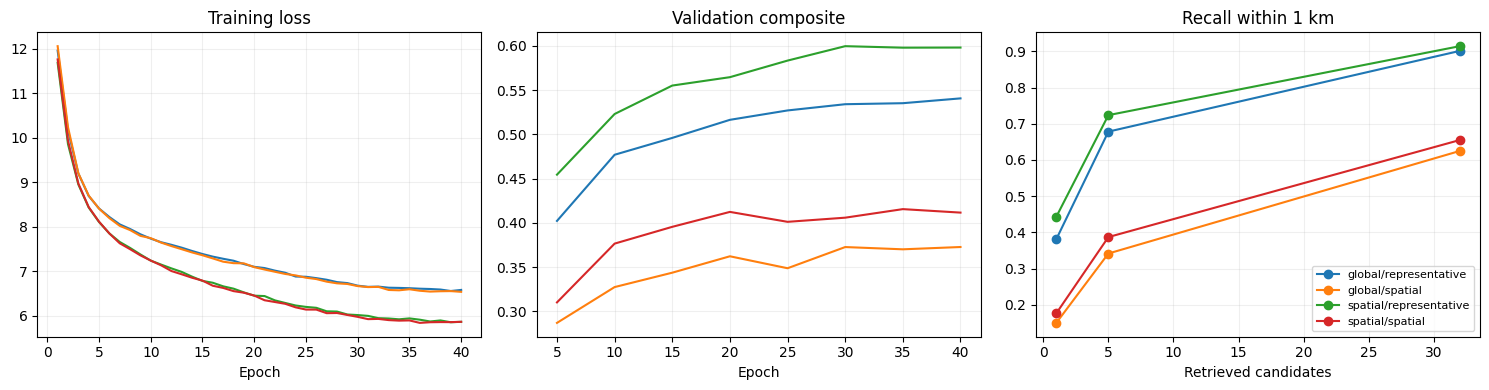

,model,scope,score,borough_macro_f1,gps_score,mean_km,median_km,p90_km,fraction_over_10km,fraction_over_20km,recall_top1_0.25km,recall_top1_0.5km,recall_top1_1.0km,recall_top5_0.25km,recall_top5_0.5km,recall_top5_1.0km,recall_top32_0.25km,recall_top32_0.5km,recall_top32_1.0km
0,global/representative,train_in_sample_self_excluded,0.727168,0.868990,0.711410,2.885897,1.080941,7.305929,0.068689,0.020122,0.288243,0.405183,0.526233,0.565213,0.695322,0.804994,0.828382,0.909397,0.956911
1,global/representative,validation,0.540684,0.763286,0.515951,4.840490,1.910758,14.083026,0.147976,0.051012,0.169056,0.261383,0.381113,0.381956,0.541737,0.678331,0.685497,0.822513,0.901349
2,global/spatial,train_in_sample_self_excluded,0.755505,0.880160,0.741655,2.583451,0.916906,6.544436,0.060693,0.017554,0.319986,0.438848,0.560464,0.607618,0.735200,0.827329,0.858077,0.926572,0.962024
3,global/spatial,validation,0.372732,0.692876,0.337161,6.628394,3.681041,16.573056,0.213548,0.066501,0.008261,0.049979,0.149938,0.017761,0.133003,0.341594,0.043784,0.278397,0.624948
4,spatial/representative,train_in_sample_self_excluded,0.788385,0.900678,0.775908,2.240919,0.822453,5.162324,0.046566,0.015065,0.329014,0.455225,0.587547,0.623578,0.755162,0.849979,0.861357,0.931837,0.969237
5,spatial/representative,validation,0.599688,0.789586,0.578588,4.214116,1.552266,12.419192,0.126897,0.037521,0.207420,0.320826,0.443086,0.436762,0.591062,0.723862,0.717116,0.853288,0.914418
6,spatial/spatial,train_in_sample_self_excluded,0.833080,0.924178,0.822958,1.770423,0.644818,4.074460,0.032584,0.007458,0.379302,0.514456,0.641005,0.690913,0.804153,0.887104,0.899151,0.948600,0.974989
7,spatial/spatial,validation,0.415543,0.725393,0.381115,6.188846,3.261341,15.628883,0.190417,0.060719,0.009087,0.057414,0.176373,0.023544,0.147460,0.387030,0.051632,0.314333,0.655101


,variant,split,borough,count,f1,mean_km
0,global,representative,Bronx,353,0.653521,6.018976
1,global,representative,Brooklyn,564,0.740933,4.562535
2,global,representative,Manhattan,356,0.845946,2.571406
3,global,representative,Queens,932,0.821207,4.581473
4,global,representative,Staten Island,167,0.754821,9.570779
5,global,spatial,Bronx,370,0.547789,9.423641
6,global,spatial,Brooklyn,601,0.669449,5.535204
7,global,spatial,Manhattan,353,0.836842,2.942179
8,global,spatial,Queens,927,0.758127,6.221937
9,global,spatial,Staten Island,170,0.652174,14.280072


Decision: retain_streetclip | selected variant: None
Training diagnostics are in-sample with self-matches excluded. Both validation folds have been reused for development.


In [71]:
# Cell 73 — V4: four controlled fits (global/spatial features × two validation folds).
RUN_DINO_HEAD_STUDY = True
_dino_missing = [name for name in ("dino_read_cache", "dino_study", "dino_dashboard", "DINO_FRAME",
                                  "DINO_SPLITS", "DINO_BENCHMARK") if name not in globals()]
if not RUN_DINO_HEAD_STUDY:
    print('Enable RUN_DINO_HEAD_STUDY here after cell 72 completes.')
elif _dino_missing:
    print("Not run: execute setup (2–26, 66–70), load cell 71, and complete cell 72. Missing:", ", ".join(_dino_missing))
else:
    DINO_FEATURES, DINO_LEDGER = dino_read_cache('train', DINO_FRAME, DINO_BENCHMARK)
    DINO_DECISION = dino_study(DINO_FRAME, DINO_SPLITS, DINO_FEATURES, DINO_LEDGER)
    if DINO_DECISION is not None: dino_dashboard()


,variant,split,epoch,score,delta_score,borough_macro_f1,gps_score,mean_km,median_km,p90_km,fraction_over_10km,fraction_over_20km
0,global,representative,40,0.540684,-0.041962,0.763286,0.515951,4.840490,1.910758,14.083026,0.147976,0.051012
1,global,spatial,40,0.372732,-0.063787,0.692876,0.337161,6.628394,3.681041,16.573056,0.213548,0.066501
2,spatial,representative,30,0.599688,0.017042,0.789586,0.578588,4.214116,1.552266,12.419192,0.126897,0.037521
3,spatial,spatial,35,0.415543,-0.020976,0.725393,0.381115,6.188846,3.261341,15.628883,0.190417,0.060719


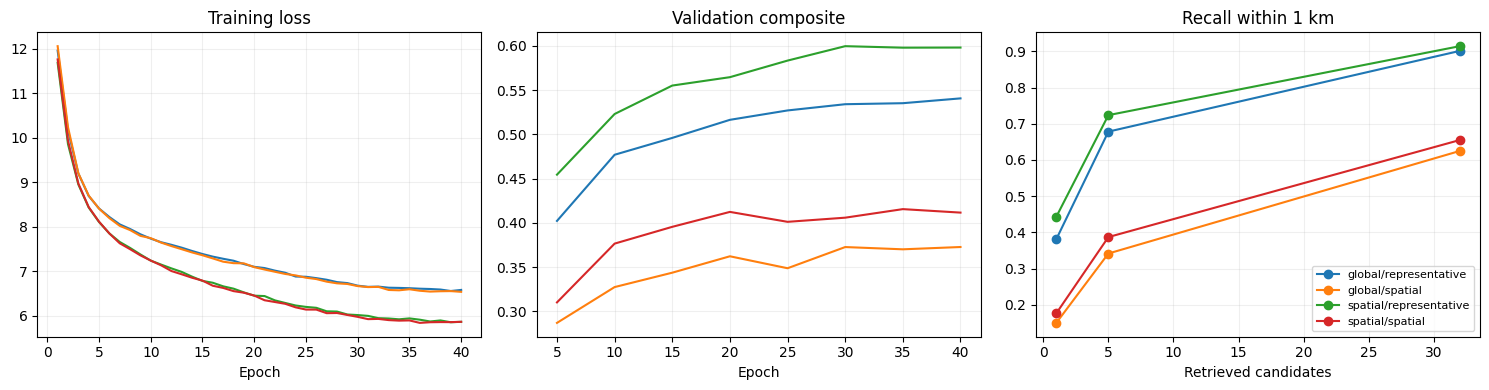

,model,scope,score,borough_macro_f1,gps_score,mean_km,median_km,p90_km,fraction_over_10km,fraction_over_20km,recall_top1_0.25km,recall_top1_0.5km,recall_top1_1.0km,recall_top5_0.25km,recall_top5_0.5km,recall_top5_1.0km,recall_top32_0.25km,recall_top32_0.5km,recall_top32_1.0km
0,global/representative,train_in_sample_self_excluded,0.727168,0.868990,0.711410,2.885897,1.080941,7.305929,0.068689,0.020122,0.288243,0.405183,0.526233,0.565213,0.695322,0.804994,0.828382,0.909397,0.956911
1,global/representative,validation,0.540684,0.763286,0.515951,4.840490,1.910758,14.083026,0.147976,0.051012,0.169056,0.261383,0.381113,0.381956,0.541737,0.678331,0.685497,0.822513,0.901349
2,global/spatial,train_in_sample_self_excluded,0.755505,0.880160,0.741655,2.583451,0.916906,6.544436,0.060693,0.017554,0.319986,0.438848,0.560464,0.607618,0.735200,0.827329,0.858077,0.926572,0.962024
3,global/spatial,validation,0.372732,0.692876,0.337161,6.628394,3.681041,16.573056,0.213548,0.066501,0.008261,0.049979,0.149938,0.017761,0.133003,0.341594,0.043784,0.278397,0.624948
4,spatial/representative,train_in_sample_self_excluded,0.788385,0.900678,0.775908,2.240919,0.822453,5.162324,0.046566,0.015065,0.329014,0.455225,0.587547,0.623578,0.755162,0.849979,0.861357,0.931837,0.969237
5,spatial/representative,validation,0.599688,0.789586,0.578588,4.214116,1.552266,12.419192,0.126897,0.037521,0.207420,0.320826,0.443086,0.436762,0.591062,0.723862,0.717116,0.853288,0.914418
6,spatial/spatial,train_in_sample_self_excluded,0.833080,0.924178,0.822958,1.770423,0.644818,4.074460,0.032584,0.007458,0.379302,0.514456,0.641005,0.690913,0.804153,0.887104,0.899151,0.948600,0.974989
7,spatial/spatial,validation,0.415543,0.725393,0.381115,6.188846,3.261341,15.628883,0.190417,0.060719,0.009087,0.057414,0.176373,0.023544,0.147460,0.387030,0.051632,0.314333,0.655101


,variant,split,borough,count,f1,mean_km
0,global,representative,Bronx,353,0.653521,6.018976
1,global,representative,Brooklyn,564,0.740933,4.562535
2,global,representative,Manhattan,356,0.845946,2.571406
3,global,representative,Queens,932,0.821207,4.581473
4,global,representative,Staten Island,167,0.754821,9.570779
5,global,spatial,Bronx,370,0.547789,9.423641
6,global,spatial,Brooklyn,601,0.669449,5.535204
7,global,spatial,Manhattan,353,0.836842,2.942179
8,global,spatial,Queens,927,0.758127,6.221937
9,global,spatial,Staten Island,170,0.652174,14.280072


Decision: retain_streetclip | selected variant: None
Training diagnostics are in-sample with self-matches excluded. Both validation folds have been reused for development.


In [72]:
# Cell 74 — V5: read-only results dashboard; setup must be loaded in this kernel.
_dino_missing = [name for name in ("dino_dashboard", "DINO_HOME", "DINO_BASELINES", "json", "pd", "plt")
                 if name not in globals()]
if _dino_missing:
    print("Not run: execute cells 2–26, then 66–70, before opening the dashboard. Missing:", ", ".join(_dino_missing))
else:
    dino_dashboard()


In [73]:
# Cell 75 — V6: optional, validation-gated full refit/test extraction/new CSV. No upload.
RUN_DINO_SUBMISSION = False
_dino_missing = [name for name in ("dino_read_cache", "dino_submission", "DINO_FRAME", "DINO_TEMPLATE",
                                  "DINO_SPLITS", "DINO_MANIFEST", "DINO_BENCHMARK") if name not in globals()]
if not RUN_DINO_SUBMISSION:
    print('Leave disabled until a completed study passes both folds. Existing StreetCLIP CSV is preserved.')
elif _dino_missing:
    print("Not run: execute setup (2–26, 66–70), load cell 71 and complete the study first. Missing:", ", ".join(_dino_missing))
else:
    DINO_FEATURES, DINO_LEDGER = dino_read_cache('train', DINO_FRAME, DINO_BENCHMARK)
    DINO_SUBMISSION = dino_submission(DINO_FRAME, DINO_TEMPLATE, DINO_SPLITS,
                                     DINO_MANIFEST, DINO_BENCHMARK, DINO_FEATURES, DINO_LEDGER)


Leave disabled until a completed study passes both folds. Existing StreetCLIP CSV is preserved.


## Monitored local study — StreetCLIP + spatial DINOv2 (2026-11-17)

The user approved autonomous execution and monitoring again. All active implementation
and progress remain here; ordinary reruns reload evidence. This supersedes the earlier
user-run-cell preference. Original model/caches/source remain intact.

**Predeclared sequence:** (1) compare eight official training images on CPU FP32,
MPS FP32 and their stored features; (2) equal candidate-mass fusion, with StreetCLIP
borough predictions held fixed; (3) learn a small compass/region-aware fusion head;
(4) compare 32 appended random negatives against 32 mined distant visual look-alikes,
holding the remaining sampler, losses, model and schedule fixed. Existing standard
fusion uses 128 anchors + 128 nearby partners; both negative arms add exactly 32 rows.
Mine only within each training fold, using immutable pretrained features, exclude
same IDs and locations within 2 km. Keep positives (<150 m), 1-km cell targets,
40-epoch OneCycle, LR .001, width128, depth1 and the fixed mixed median decoder.

**Selection:** require at least +.002 composite and reduced mean GPS error on BOTH
original folds over the retained StreetCLIP controls. Do not select a decoder using
query coordinates. Retain/reject hard-negative mining against its random control
on both folds, not against a different batch composition. Repeat a promising selected
head and a matched StreetCLIP control at seed6644 before a robust-gain claim.
Spatial block bootstrap estimates uncertainty using the existing training-derived
1-km grid; it remains a reused development estimate, not private-leaderboard evidence.

Bounded work: <=3 minutes per head and <=20 cumulative minutes of new head fitting
in this study, <=5 minutes of parity work and <=10 minutes of diagnostics/mining.
All arrays are feature arrays; image decoding is limited to the eight-image parity
check. No new full-image pass or model download is needed. Report fp16 parity failure
without disabling guards; keep existing DINO features FP32-produced/FP16-stored.
SALAD/BoQ and encoder fine-tuning remain conditional next phases after this decision.
No Kaggle upload is part of this study. The public baseline is user-reported .60599.

Environment switches: `NYCGUESSR_FUSION_PRECISION=1` runs the small numerical audit;
`NYCGUESSR_FUSION_STUDY=1` runs the bounded study. Both default off. Outputs are
under `outputs/fusion/`; exact sources/configs, caches, IDs, checkpoints, losses,
validation/borough/tail metrics, self-excluded training diagnostics and decisions are logged.


In [23]:
# Cell 77 — Fusion inputs and numerical audit; preserve existing feature producers.
FUSION_HOME=ROOT/'outputs/fusion'
FUSION_CONFIG={'epochs':40,'head_seconds':180.,'aggregate_head_seconds':1200.,
               'negative_rows':32,'hard_distance_km':2.,'minimum_gain':.002,
               'seeds':[6643,6644],'tag':'cross_encoder_v1'}

def fusion_sources():
    frame,template=load_data(ROOT)
    split_path=ROOT/'outputs/splits.json'
    require(sha256(split_path)=='01edd72611d17b928f7d5b835e2ee26c8ec2848652b3065ced9abc06102a509d','Fixed folds changed.')
    splits=json.loads(split_path.read_text())
    benchmark=json.loads((DINO_HOME/'benchmark.json').read_text())
    dino,ledger=dino_read_cache('train',frame,benchmark)
    street_path=ROOT/'outputs/features/streetclip_train_23f1be61d2b2b2cd.npy'
    require(sha256(street_path)=='b9be80acd9d389f34b558321403d9f4d5ef4e54e100f31800d05426f7ae2f2e8','StreetCLIP cache changed.')
    street=np.load(street_path,mmap_mode='r')
    require(street.shape==(len(frame),4,1024) and dino.shape==(len(frame),4,5,768),'Fusion feature shapes.')
    require(ledger['spec']['sample_ids']==frame.sample_id.tolist(),'Feature ID order mismatch.')
    pointer=json.loads((DINO_HOME/'latest_study.json').read_text())
    require(sha256(ROOT/pointer['decision'])==pointer['sha256'],'DINO decision changed.')
    decision=json.loads((ROOT/pointer['decision']).read_text())
    for record in decision['records']:
        require(sha256(ROOT/record['checkpoint'])==record['checkpoint_sha256'],'DINO checkpoint changed.')
    for control in DINO_BASELINES.values():
        require(sha256(ROOT/control['path'])==control['sha256'],'StreetCLIP checkpoint changed.')
    return frame,splits,street,dino,ledger,decision

def fusion_precision_audit(frame,ledger):
    identity={'encoder':dino_identity(),'cache_sha256':ledger['sha256'],
              'sample_ids':[0,137],'directions':list(DIRECTIONS),'tolerance_cosine':.995,'tolerance_relative_rms':.03}
    path=FUSION_HOME/'precision.json'
    if path.exists():
        report=json.loads(path.read_text())
        require(report['identity']==identity and report['passed'],'Numerical audit identity/failure requires inspection.')
        return report
    manifest={r['path']:r['sha256'] for r in map(json.loads,(ROOT/'outputs/input_manifest.jsonl').read_text().splitlines())}
    sample=frame.loc[identity['sample_ids']]
    pixels=next(dino_batches(sample,np.arange(2),'train',2,0,manifest))[1]
    device=dino_device()
    started=time.monotonic()
    seed_everything()
    model=dino_encoder(torch.device('cpu'),precision='float32')
    try:
        cpu=dino_encode(model,pixels,torch.device('cpu'))
        model=model.to(device)
        gpu=dino_encode(model,pixels,device)
        cache_path,_,_=dino_cache_paths('train',frame,json.loads((DINO_HOME/'benchmark.json').read_text()))
        cache=np.load(cache_path,mmap_mode='r')
        positions=pd.Series(np.arange(len(frame)),index=frame.sample_id).loc[sample.sample_id].to_numpy()
        cached=np.asarray(cache[positions],np.float32).reshape(8,5,768)
        comparisons={}
        for name,actual in [('mps_fp32_vs_cpu_fp32',gpu),('stored_features_vs_cpu_fp32',cached)]:
            cosine=(actual*cpu).sum(-1)/np.maximum(np.linalg.norm(actual,axis=-1)*np.linalg.norm(cpu,axis=-1),1e-9)
            comparisons[name]={'minimum_cosine':float(cosine.min()),
                               'relative_rms':float(np.linalg.norm(actual-cpu)/max(np.linalg.norm(cpu),1e-9))}
        passed=all(r['minimum_cosine']>=.995 and r['relative_rms']<=.03 for r in comparisons.values())
        benchmark=json.loads((DINO_HOME/'benchmark.json').read_text())
        report={'identity':identity,'passed':passed,'comparisons':comparisons,
                'historical_fp16_check':benchmark['precision_check'],'encoder_precision':'float32',
                'elapsed_seconds':time.monotonic()-started,'peak_sampled_driver_bytes':dino_memory_guard(device)}
        dino_json(path,report)
        require(report['elapsed_seconds']<=300,'Numerical-audit budget exceeded.')
        require(passed,'CPU/GPU/cache parity failed. Stop; preserve evidence and investigate before training.')
        return report
    finally:
        del model
        dino_release(device)


In [24]:
# Cell 78 — Fusion model and fixed candidate combination.
class FusionGeoHead(nn.Module):
    def __init__(self,geography,street_mean,street_std,dino_mean,dino_std):
        super().__init__()
        for name,value in [('street_mean',street_mean),('street_std',street_std),('dino_mean',dino_mean),('dino_std',dino_std),
                           ('borough_weights',geography['borough_weights'])]:
            self.register_buffer(name,torch.as_tensor(value,dtype=torch.float32))
        self.street_project=nn.Sequential(FeatureLayerNorm(street_mean.shape[-1]),nn.Dropout(.3),nn.Linear(street_mean.shape[-1],128))
        self.dino_project=nn.Sequential(FeatureLayerNorm(dino_mean.shape[-1]),nn.Dropout(.3),nn.Linear(dino_mean.shape[-1],128))
        self.compass=nn.Parameter(torch.empty(1,4,1,128))
        self.region=nn.Parameter(torch.zeros(1,1,6,128))
        self.summary_token=nn.Parameter(torch.empty(1,1,128))
        nn.init.normal_(self.compass,std=.02);nn.init.normal_(self.summary_token,std=.02)
        layer=nn.TransformerEncoderLayer(128,4,256,dropout=.1,activation='gelu',batch_first=True,norm_first=True)
        self.attention=nn.TransformerEncoder(layer,1,enable_nested_tensor=False)
        self.output_norm=nn.LayerNorm(128)
        self.cells=nn.Linear(128,len(geography['centers']))
        self.boroughs=nn.Linear(128,5)

    def forward(self,street,dino):
        s=self.street_project((street.float()-self.street_mean)/self.street_std).unsqueeze(2)
        d=self.dino_project((dino.float()-self.dino_mean)/self.dino_std)
        tokens=torch.cat([s,d],dim=2)+self.compass+self.region
        batch=len(tokens)
        tokens=torch.cat([self.summary_token.expand(batch,-1,-1),tokens.reshape(batch,24,128)],dim=1)
        hidden=torch.zeros((batch,25),dtype=torch.bool,device=tokens.device)
        if self.training:
            dropped=torch.rand((batch,4),device=tokens.device)<.15
            dropped[:,0]&=~dropped.all(dim=1)
            hidden[:,1:]=dropped.repeat_interleave(6,dim=1)
        embedding=self.output_norm(self.attention(tokens,src_key_padding_mask=hidden)[:,0])
        return {'cell_logits':self.cells(embedding),'borough_logits':self.boroughs(embedding),'embedding':F.normalize(embedding,dim=1)}

@torch.inference_mode()
def fusion_outputs(model,street,dino,device,street_only=False):
    model.eval();probabilities=[];boroughs=[];vectors=[]
    for start in range(0,len(street),256):
        s=torch.as_tensor(np.array(street[start:start+256],copy=True),device=device)
        if street_only:out=model(s)
        else:
            d=torch.as_tensor(np.array(dino[start:start+256],copy=True),device=device)
            out=model(s,d)
        probabilities.append(out['cell_logits'].softmax(1).cpu().numpy())
        boroughs.append(out['borough_logits'].softmax(1).cpu().numpy())
        vectors.append(out['embedding'].cpu().numpy())
    return np.concatenate(probabilities),np.concatenate(boroughs),np.concatenate(vectors)

def fusion_candidate_batch(training,geography,bank,queries,probability,ids):
    require(len(ids)<=128 and len(set(ids)&set(training.sample_id))==0,'Candidate bank/query leakage.')
    nearest,weights=diagnostic_neighbors(training.sample_id,ids,bank,queries)
    xy,origin,scales=coordinates_xy(training[['latitude','longitude']],geography['origin'])
    top=np.argsort(-probability,axis=1,kind='stable')[:,:30]
    mass=np.take_along_axis(probability,top,axis=1).copy();mass/=mass.sum(1,keepdims=True)
    points=np.concatenate([np.asarray(geography['centers'])[top],xy[nearest]],axis=1)
    gps=points/scales+origin
    return gps,np.concatenate([.5*mass,.5*weights],axis=1)

def fusion_score(truth,prediction):
    metrics=score_predictions(truth,prediction)
    ordered=prediction.set_index('sample_id').loc[truth.sample_id]
    errors=haversine_km(truth[['latitude','longitude']],ordered[['latitude','longitude']])
    metrics.update(fraction_over_10km=float((errors>10).mean()),fraction_over_20km=float((errors>20).mean()))
    return metrics

def fusion_candidate_control(frame,splits,street,dino,decision,directory):
    records=[];device=dino_device()
    for split_name in ('representative','spatial'):
        split=splits['splits'][split_name];training=frame.loc[split['train_ids']];validation=frame.loc[split['validation_ids']]
        street_model,street_saved=load_compass_head(ROOT,ROOT/DINO_BASELINES[split_name]['path'],device)
        dino_record=next(r for r in decision['records'] if r['variant']=='spatial' and r['split']==split_name)
        saved=torch.load(ROOT/dino_record['checkpoint'],map_location='cpu',weights_only=True)
        dino_model,dino_saved=dino_load_head(ROOT/dino_record['checkpoint'],saved['identity'],device)
        require(street_saved['train_ids']==dino_saved['train_ids']==split['train_ids'],'Expert training banks differ.')
        position=pd.Series(np.arange(len(frame)),index=frame.sample_id)
        tr=position.loc[training.sample_id].to_numpy();va=position.loc[validation.sample_id].to_numpy()
        try:
            s_train=np.array(street[tr],copy=True);s_valid=np.array(street[va],copy=True)
            d_train=np.array(dino[tr],copy=True);d_valid=np.array(dino[va],copy=True)
            _,_,sbank=fusion_outputs(street_model,s_train,None,device,street_only=True)
            sp,sboro,squery=fusion_outputs(street_model,s_valid,None,device,street_only=True)
            _,_,dbank=compass_outputs(dino_model,d_train,device)
            dp,_,dquery=compass_outputs(dino_model,d_valid,device)
            predictions=[]
            for start in range(0,len(validation),128):
                ids=validation.sample_id.iloc[start:start+128].to_numpy()
                a,wa=fusion_candidate_batch(training,street_saved['geography'],sbank,squery[start:start+128],sp[start:start+128],ids)
                b,wb=fusion_candidate_batch(training,dino_saved['geography'],dbank,dquery[start:start+128],dp[start:start+128],ids)
                points=np.concatenate([a,b],axis=1)
                xy,origin,scales=coordinates_xy(training[['latitude','longitude']],street_saved['geography']['origin'])
                gps=bounded_geometric_median((points-origin)*scales,np.concatenate([.5*wa,.5*wb],axis=1))/scales+origin
                predictions.append(pd.DataFrame({'sample_id':ids,'borough':np.asarray(BOROUGHS)[sboro[start:start+len(ids)].argmax(1)],
                                                  'latitude':gps[:,0],'longitude':gps[:,1]}))
            prediction=pd.concat(predictions,ignore_index=True)
            metrics=fusion_score(validation,prediction)
            prediction.to_csv(directory/f'candidate_equal_{split_name}.csv',index=False)
            records.append({'variant':'candidate_equal','split':split_name,'seed':6643,**metrics})
        finally:
            del street_model,dino_model
            dino_release(device)
    dino_json(directory/'candidate_control.json',records)
    return records

def fusion_mine_negatives(training,street,dino):
    """Frozen-feature cosine look-alikes, only training IDs and >2-km true distances."""
    require(training.sample_id.is_unique and len(training)>32,'Invalid mining bank.')
    pooled=np.concatenate([np.asarray(street.mean(1),np.float32),np.asarray(dino.mean((1,2)),np.float32)],axis=1)
    pooled/=np.maximum(np.linalg.norm(pooled,axis=1,keepdims=True),1e-8)
    candidates=[];coordinates=training[['latitude','longitude']].to_numpy()
    for start in range(0,len(training),128):
        query=pooled[start:start+128]
        similarity=query@pooled.T
        distance=haversine_km(np.repeat(coordinates[start:start+len(query)],len(training),axis=0),
                              np.tile(coordinates,(len(query),1))).reshape(len(query),len(training))
        similarity[distance<=FUSION_CONFIG['hard_distance_km']]=-np.inf
        nearest=np.argsort(-similarity,axis=1,kind='stable')[:,:16]
        require(bool(np.isfinite(np.take_along_axis(similarity,nearest,axis=1)).all()),'Not enough distant mining candidates.')
        candidates.append(nearest)
    return np.concatenate(candidates)

def fusion_model_load(path,identity,device):
    saved=torch.load(path,map_location='cpu',weights_only=True)
    require(saved['identity']==identity,'Fusion checkpoint source/cache mismatch.')
    state=saved['state_dict']
    if saved['variant']=='street_repeat':
        model=CompassGeoHead(saved['geography'],state['feature_mean'],state['feature_std'])
    else:
        model=FusionGeoHead(saved['geography'],*(state[k] for k in ('street_mean','street_std','dino_mean','dino_std')))
    model.load_state_dict(state,strict=True)
    return model.to(device),saved

def fusion_bootstrap(truth,prediction,control,splits,seed=6643):
    """Paired 1-km block bootstrap of development-score gain; no model fitting."""
    candidate=prediction.set_index('sample_id').loc[truth.sample_id]
    baseline=control.set_index('sample_id').loc[truth.sample_id]
    origin=np.asarray(splits['spatial_origin_deg']);scales=np.asarray(splits['spatial_scales_km_per_deg'])
    xy=(truth[['latitude','longitude']].to_numpy()-origin)*scales
    block=np.floor(xy).astype(int)
    _,labels=np.unique(block,axis=0,return_inverse=True)
    groups=[np.flatnonzero(labels==k) for k in np.unique(labels)]
    actual=np.array([BOROUGHS.index(b) for b in truth.borough]);a=np.array([BOROUGHS.index(b) for b in candidate.borough]);b=np.array([BOROUGHS.index(b) for b in baseline.borough])
    ea=haversine_km(truth[['latitude','longitude']],candidate[['latitude','longitude']]);eb=haversine_km(truth[['latitude','longitude']],baseline[['latitude','longitude']])
    def score(index,predicted,errors):
        f1=[]
        for borough in range(5):
            positive=actual[index]==borough;guess=predicted[index]==borough
            denominator=int(positive.sum()+guess.sum())
            f1.append(float(2*(positive&guess).sum()/denominator) if denominator else 0.)
        return .1*np.mean(f1)+.9*max(0.,1-errors[index].mean()/10)
    rng=np.random.default_rng(seed);deltas=[]
    for _ in range(400):
        index=np.concatenate([groups[i] for i in rng.integers(len(groups),size=len(groups))])
        deltas.append(score(index,a,ea)-score(index,b,eb))
    return {'score_gain_95pct_interval':np.quantile(deltas,[.025,.975]).tolist(),'blocks':len(groups),'replicates':400,
            'interpretation':'Reused development data; block-resampling uncertainty, not independent test evidence.'}


In [28]:
# Cell 79 — Bounded controlled head training and tracking.
def fusion_fit(frame,splits,street,dino,identity,directory,variant,split_name,seed,study_budget):
    directory.mkdir(parents=True,exist_ok=True)
    status_path=directory/'status.json'
    if status_path.exists():
        status=json.loads(status_path.read_text())
        require(status['status']=='complete','Partial/failed run retained; inspect before a separately tagged retry.')
        require(sha256(directory/'best.pth')==status['checkpoint_sha256'],'Selected checkpoint changed.')
        return directory/'best.pth'
    require(study_budget['head_seconds']<FUSION_CONFIG['aggregate_head_seconds'],'Aggregate head budget exhausted.')
    training=frame.loc[splits['splits'][split_name]['train_ids']]
    validation=frame.loc[splits['splits'][split_name]['validation_ids']]
    require(not set(training.sample_id)&set(validation.sample_id),'Fold leakage.')
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    tr=position.loc[training.sample_id].to_numpy();va=position.loc[validation.sample_id].to_numpy()
    train_s=np.array(street[tr],copy=True);valid_s=np.array(street[va],copy=True)
    train_d=np.array(dino[tr],copy=True);valid_d=np.array(dino[va],copy=True)
    sm,ss=dino_statistics(train_s);dm,ds=dino_statistics(train_d)
    seed_everything(seed);rng=np.random.default_rng(seed);device=dino_device()
    geography=fit_geography(training,cells=512)
    street_only=variant=='street_repeat'
    model=CompassGeoHead(geography,sm,ss).to(device) if street_only else FusionGeoHead(geography,sm,ss,dm,ds).to(device)
    train_gps=training[['latitude','longitude']].to_numpy()
    xy=((train_gps-geography['origin'])*geography['scales']).astype(np.float32)
    distances=np.linalg.norm(xy[:,None]-np.asarray(geography['centers'],np.float32)[None],axis=-1)
    target=np.exp(-(distances-distances.min(1,keepdims=True)));target/=target.sum(1,keepdims=True)
    neighbors=cKDTree(xy).query_ball_point(xy,.15)
    neighbors=[np.asarray([j for j in group if j!=i],dtype=int) for i,group in enumerate(neighbors)]
    negative_bank=None
    if variant=='fusion_hard':
        mining_started=time.monotonic();negative_bank=fusion_mine_negatives(training,train_s,train_d)
        require(time.monotonic()-mining_started<=600,'Mining budget exceeded.')
        np.save(directory/'hard_negative_positions.npy',negative_bank)
        dino_json(directory/'hard_negative_provenance.json',{'train_ids':training.sample_id.tolist(),
            'minimum_distance_km':FUSION_CONFIG['hard_distance_km'],'source':'frozen training-only features',
            'seconds':time.monotonic()-mining_started,'sha256':sha256(directory/'hard_negative_positions.npy')})
    s=torch.as_tensor(train_s,device=device);d=torch.as_tensor(train_d,device=device)
    coordinates=torch.as_tensor(xy,device=device);soft=torch.as_tensor(target,device=device)
    labels=torch.tensor([BOROUGHS.index(b) for b in training.borough],device=device)
    ids=torch.as_tensor(training.sample_id.to_numpy(copy=True),device=device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.05)
    scheduler=torch.optim.lr_scheduler.OneCycleLR(optimizer,max_lr=.001,total_steps=40*int(np.ceil(len(training)/128)),pct_start=.1)
    config={'variant':variant,'split':split_name,'seed':seed,'identity':identity,'epochs':40,'anchors':128,'positive_partners':128,
            'extra_negatives':32 if variant in ('fusion_random','fusion_hard') else 0,'width':128,'layers':1,'heads':4,
            'target_km':1.,'contrastive_temperature':.05,'positive_radius_km':.15,'borough_weight':.3,
            'trainable_parameters':sum(p.numel() for p in model.parameters()),'head_precision':'float32',
            'training_locations':len(training),'validation_locations':len(validation),'decoder':'mixed_median'}
    dino_json(directory/'config.json',config)
    (directory/'source_notebook.ipynb').write_bytes((ROOT/'NYCGuessr.ipynb').read_bytes())
    started=time.monotonic();history=[];best=-1.;status={'status':'running'}
    def checkpoint(epoch,metrics):
        return {'identity':identity,'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'variant':variant,
                'config':config,'geography':geography,'epoch':epoch,'metrics':metrics,'split':split_name,'seed':seed,
                'train_ids':training.sample_id.tolist(),'validation_ids':validation.sample_id.tolist()}
    try:
        for epoch in tqdm(range(1,41),desc=f'{variant}/{split_name}/s{seed}',unit='epoch'):
            epoch_start=time.monotonic();model.train();losses=[];anchors=rng.permutation(len(training))
            for start in range(0,len(training),128):
                elapsed=time.monotonic()-started
                require(elapsed<FUSION_CONFIG['head_seconds'] and study_budget['head_seconds']+elapsed<FUSION_CONFIG['aggregate_head_seconds'],'Controlled head budget exceeded.')
                a=anchors[start:start+128]
                paired=np.array([rng.choice(neighbors[i]) if len(neighbors[i]) else (i+rng.integers(1,len(training)))%len(training) for i in a])
                batch=[a,paired]
                if variant in ('fusion_random','fusion_hard'):
                    source=a[:min(32,len(a))]
                    if variant=='fusion_hard':extra=np.array([rng.choice(negative_bank[i]) for i in source])
                    else:
                        extra=[]
                        for i in source:
                            for attempt in range(100):
                                j=int(rng.integers(len(training)))
                                if j!=i and haversine_km(train_gps[i:i+1],train_gps[j:j+1])[0]>2:break
                            else:raise ValueError('Could not sample a distant random negative.')
                            extra.append(j)
                        extra=np.asarray(extra)
                    batch.append(extra)
                index=torch.as_tensor(np.concatenate(batch),device=device)
                output=model(s[index]) if street_only else model(s[index],d[index])
                cell_loss=-(soft[index]*output['cell_logits'].log_softmax(1)).sum(1).mean()
                borough_loss=F.cross_entropy(output['borough_logits'],labels[index],weight=model.borough_weights)
                contrastive=geographic_contrastive_loss(output['embedding'],coordinates[index],ids[index])
                loss=cell_loss+.3*borough_loss+contrastive
                require(bool(torch.isfinite(loss)),'Nonfinite fusion loss.')
                optimizer.zero_grad(set_to_none=True);loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True)
                optimizer.step();scheduler.step()
                losses.append([float(v.detach().cpu()) for v in (loss,cell_loss,borough_loss,contrastive)])
            metrics={}
            if epoch%5==0:
                _,_,bank=fusion_outputs(model,train_s,train_d,device,street_only)
                probability,borough,query=fusion_outputs(model,valid_s,valid_d,device,street_only)
                prediction=compass_decoders(training,validation.sample_id,geography,bank,query,probability,borough.argmax(1))['mixed_median']
                metrics=fusion_score(validation,prediction)
                if metrics['score']>best:
                    best=metrics['score'];dino_torch_save(directory/'best.pth',checkpoint(epoch,metrics))
                    prediction.to_csv(directory/'validation_best.csv',index=False)
            means=np.mean(losses,axis=0)
            item={'epoch':epoch,'loss':float(means[0]),'cell_loss':float(means[1]),'borough_loss':float(means[2]),
                  'contrastive_loss':float(means[3]),'metrics':metrics,'seconds':time.monotonic()-epoch_start,
                  'elapsed_seconds':time.monotonic()-started,'driver_bytes':dino_memory_guard(device),'unique_anchor_locations':len(anchors)}
            history.append(item);dino_json(directory/'history.json',history)
            if epoch%5==0:print(f"{variant} {split_name} epoch {epoch}: score={metrics['score']:.6f}, mean={metrics['mean_km']:.3f} km",flush=True)
        status={'status':'complete','completed_epochs':len(history),'checkpoint_sha256':sha256(directory/'best.pth')}
    except BaseException as error:
        status={'status':'failed','completed_epochs':len(history),'error':str(error),'checkpoint_selected':False}
        raise
    finally:
        elapsed=time.monotonic()-started
        study_budget['head_seconds']+=elapsed
        dino_json(directory.parent/'budget.json',study_budget)
        status['elapsed_seconds']=elapsed;dino_json(status_path,status)
        del model,optimizer,s,d,coordinates,soft,labels,ids
        dino_release(device)
    return directory/'best.pth'

def fusion_diagnostics(path,identity,frame,street,dino,directory):
    model,saved=fusion_model_load(path,identity,dino_device());device=dino_device()
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    training=frame.loc[saved['train_ids']];tr=position.loc[training.sample_id].to_numpy()
    train_s=np.array(street[tr],copy=True);train_d=np.array(dino[tr],copy=True)
    street_only=saved['variant']=='street_repeat'
    summaries=[]
    try:
        tp,tb,bank=fusion_outputs(model,train_s,train_d,device,street_only)
        for scope,query_ids in [('train_in_sample_self_excluded',saved['train_ids']),('validation',saved['validation_ids'])]:
            truth=frame.loc[query_ids]
            if scope.startswith('train'):probability,borough,query=tp,tb.argmax(1),bank
            else:
                va=position.loc[query_ids].to_numpy()
                probability,borough,query=fusion_outputs(model,street[va],dino[va],device,street_only);borough=borough.argmax(1)
            predictions=[];rows=[]
            for start in range(0,len(truth),128):
                batch=truth.iloc[start:start+128]
                predicted,details=diagnostic_prediction_batch(training,batch.sample_id,saved['geography'],bank,query[start:start+128],probability[start:start+128],borough[start:start+128])
                prediction=predicted['mixed_median'];predictions.append(prediction)
                errors=haversine_km(batch[['latitude','longitude']],prediction[['latitude','longitude']])
                candidates=training[['latitude','longitude']].to_numpy()[details['neighbors']]
                distance=haversine_km(np.repeat(batch[['latitude','longitude']].to_numpy(),candidates.shape[1],axis=0),candidates.reshape(-1,2)).reshape(len(batch),-1)
                for j,row in enumerate(batch.itertuples()):
                    item={'sample_id':int(row.sample_id),'borough':row.borough,'error_km':float(errors[j])}
                    for k in (1,5,32):item[f'neighbor{k}_best_km']=float(distance[j,:k].min())
                    rows.append(item)
            prediction=pd.concat(predictions,ignore_index=True)
            metrics=fusion_score(truth,prediction);queries=pd.DataFrame(rows)
            for k in (1,5,32):
                for radius in (.25,.5,1.):metrics[f'recall_top{k}_{radius}km']=float((queries[f'neighbor{k}_best_km']<=radius).mean())
            prediction.to_csv(directory/f'diagnostic_{scope}.csv',index=False);queries.to_csv(directory/f'queries_{scope}.csv',index=False)
            summaries.append({'scope':scope,**metrics})
        require(abs(summaries[1]['score']-saved['metrics']['score'])<1e-7,'Strict reload did not reproduce validation score.')
        dino_json(directory/'diagnostics.json',summaries)
        return summaries
    finally:
        del model
        dino_release(device)

def fusion_study(frame,splits,street,dino,ledger,dino_decision):
    require(json.loads((FUSION_HOME/'precision.json').read_text())['passed'],'Run and pass the numerical audit first.')
    identity={'config':FUSION_CONFIG,'street_sha256':'b9be80acd9d389f34b558321403d9f4d5ef4e54e100f31800d05426f7ae2f2e8',
              'dino_sha256':ledger['sha256'],'split_sha256':sha256(ROOT/'outputs/splits.json'),
              'data_fingerprint':data_fingerprint(ROOT),
              'source':dino_definitions_hash(['FusionGeoHead','fusion_fit','fusion_outputs','fusion_candidate_batch','fusion_mine_negatives',
                  'fusion_model_load','fusion_diagnostics','fusion_bootstrap','fusion_score','fusion_study',
                  'FeatureLayerNorm','CompassGeoHead','geographic_contrastive_loss','fit_geography','dino_statistics','compass_decoders',
                  'diagnostic_prediction_batch','diagnostic_neighbors','bounded_geometric_median'])}
    directory=FUSION_HOME/('study_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True)
    dino_json(directory/'identity.json',identity)
    budget_path=directory/'budget.json'
    budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'head_seconds':0.,'limit_seconds':FUSION_CONFIG['aggregate_head_seconds']}
    records=[]
    if (directory/'candidate_control.json').exists():records=json.loads((directory/'candidate_control.json').read_text())
    else:records=fusion_candidate_control(frame,splits,street,dino,dino_decision,directory)
    for variant in ('fusion_standard','fusion_random','fusion_hard'):
        for split in ('representative','spatial'):
            run=directory/f'{variant}_{split}_s6643'
            path=fusion_fit(frame,splits,street,dino,identity,run,variant,split,6643,budget)
            model,saved=fusion_model_load(path,identity,torch.device('cpu'));del model
            if not (run/'diagnostics.json').exists():fusion_diagnostics(path,identity,frame,street,dino,run)
            record={'variant':variant,'split':split,'seed':6643,'epoch':saved['epoch'],'checkpoint':str(path.relative_to(ROOT)),
                    'checkpoint_sha256':sha256(path),**saved['metrics']}
            validation=frame.loc[saved['validation_ids']]
            control=pd.read_csv((ROOT/DINO_BASELINES[split]['path']).parent/'validation_best.csv')
            record['bootstrap']=fusion_bootstrap(validation,pd.read_csv(run/'validation_best.csv'),control,splits)
            records.append(record)
            dino_json(directory/'metrics_in_progress.json',records)
    hard_keep=all(next(r for r in records if r['variant']=='fusion_hard' and r['split']==split)['score']>
                  next(r for r in records if r['variant']=='fusion_random' and r['split']==split)['score']+.0001
                  for split in ('representative','spatial'))
    eligible=[]
    for variant in ('candidate_equal','fusion_standard','fusion_random','fusion_hard'):
        if variant=='fusion_hard' and not hard_keep:continue
        pair=[r for r in records if r['variant']==variant]
        if len(pair)==2 and all(r['score']>=DINO_BASELINES[r['split']]['score']+.002 and r['mean_km']<DINO_BASELINES[r['split']]['mean_km'] for r in pair):eligible.append(variant)
    selected=max(eligible,key=lambda variant:np.mean([r['score']-DINO_BASELINES[r['split']]['score'] for r in records if r['variant']==variant])) if eligible else None
    repeat_pass=None
    if selected is not None and selected!='candidate_equal':
        for variant in ('street_repeat',selected):
            for split in ('representative','spatial'):
                run=directory/f'{variant}_{split}_s6644'
                path=fusion_fit(frame,splits,street,dino,identity,run,variant,split,6644,budget)
                model,saved=fusion_model_load(path,identity,torch.device('cpu'));del model
                if not (run/'diagnostics.json').exists():fusion_diagnostics(path,identity,frame,street,dino,run)
                records.append({'variant':variant,'split':split,'seed':6644,'epoch':saved['epoch'],
                                'checkpoint':str(path.relative_to(ROOT)),'checkpoint_sha256':sha256(path),**saved['metrics']})
        repeat_pass=all(next(r for r in records if r['variant']==selected and r['split']==split and r['seed']==6644)['score']>
                        next(r for r in records if r['variant']=='street_repeat' and r['split']==split)['score']+.002 for split in ('representative','spatial'))
        if not repeat_pass:selected=None
    result={'identity':identity,'directory':str(directory.relative_to(ROOT)),'records':records,'selected_variant':selected,
            'hard_negative_beats_matched_random_both_folds':hard_keep,'repeat_seed_passed':repeat_pass,
            'decision':'retain_streetclip' if selected is None else 'retain_fusion_development_candidate',
            'public_baseline':.60599,'new_public_score':None,'head_seconds':budget['head_seconds']}
    dino_json(directory/'decision.json',result)
    dino_json(FUSION_HOME/'latest.json',{'decision':str((directory/'decision.json').relative_to(ROOT)),'sha256':sha256(directory/'decision.json')})
    record_run(ROOT,directory.name,'streetclip_dino_fusion','both_development_folds',{},FUSION_CONFIG,budget['head_seconds'],
               {'decision':str((directory/'decision.json').relative_to(ROOT))},result['decision'])
    return result


In [29]:
# Cell 80 — Numerical, inference and leakage regression checks.
class FusionTests(unittest.TestCase):
    def test_fusion_backprop_reload_and_four_view_grouping(self):
        seed_everything()
        geo={'centers':[[0.,0.],[1.,1.]],'borough_weights':[1.]*5}
        model=FusionGeoHead(geo,np.zeros((4,16),np.float32),np.ones((4,16),np.float32),
                            np.zeros((4,5,8),np.float32),np.ones((4,5,8),np.float32))
        s=torch.randn(3,4,16);d=torch.randn(3,4,5,8)
        out=model(s,d);out['cell_logits'].square().mean().backward()
        nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True)
        self.assertEqual(out['embedding'].shape,(3,128))
        restored=FusionGeoHead(geo,np.zeros((4,16),np.float32),np.ones((4,16),np.float32),
                               np.zeros((4,5,8),np.float32),np.ones((4,5,8),np.float32))
        restored.load_state_dict(model.state_dict(),strict=True);model.eval();restored.eval()
        torch.testing.assert_close(model(s,d)['embedding'],restored(s,d)['embedding'])

    def test_candidate_control_preserves_single_expert_decoder(self):
        frame=example_frame(40);geo=fit_geography(frame,cells=32);rng=np.random.default_rng(1)
        bank=rng.normal(size=(40,12)).astype(np.float32);query=rng.normal(size=(2,12)).astype(np.float32)
        p=rng.uniform(size=(2,32)).astype(np.float32);p/=p.sum(1,keepdims=True);ids=np.array([100,101])
        points,weights=fusion_candidate_batch(frame,geo,bank,query,p,ids)
        xy=(points-np.asarray(geo['origin']))*np.asarray(geo['scales'])
        actual=bounded_geometric_median(xy,weights)/np.asarray(geo['scales'])+np.asarray(geo['origin'])
        expected=compass_decoders(frame,ids,geo,bank,query,p,np.array([0,1]))['mixed_median']
        np.testing.assert_allclose(actual,expected[['latitude','longitude']],rtol=0,atol=1e-10)
        with self.assertRaises(ValueError):fusion_candidate_batch(frame,geo,bank,query,p,[0,1])

    def test_hard_mining_is_training_only_and_geographically_distant(self):
        rng=np.random.default_rng(2);count=45
        frame=pd.DataFrame({'sample_id':np.arange(count)*3,'latitude':40.5+np.arange(count)*.01,'longitude':np.full(count,-74.)})
        street=rng.normal(size=(count,4,16)).astype(np.float16);dino=rng.normal(size=(count,4,5,8)).astype(np.float16)
        nearest=fusion_mine_negatives(frame,street,dino)
        distance=haversine_km(np.repeat(frame[['latitude','longitude']].to_numpy(),16,axis=0),
                              frame[['latitude','longitude']].to_numpy()[nearest].reshape(-1,2))
        self.assertTrue(bool((distance>2).all()));self.assertEqual(nearest.shape,(count,16))
        self.assertTrue(bool((nearest!=np.arange(count)[:,None]).all()))

fusion_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(FusionTests))
require(fusion_tests.wasSuccessful(),'Resolve fusion contracts before real runs.')


test_candidate_control_preserves_single_expert_decoder (__main__.FusionTests.test_candidate_control_preserves_single_expert_decoder) ... 

ok


test_fusion_backprop_reload_and_four_view_grouping (__main__.FusionTests.test_fusion_backprop_reload_and_four_view_grouping) ... 

ok


test_hard_mining_is_training_only_and_geographically_distant (__main__.FusionTests.test_hard_mining_is_training_only_and_geographically_distant) ... 

ok


----------------------------------------------------------------------
Ran 3 tests in 0.022s

OK


In [30]:
# Cell 81 — Monitored actions. Real numerical audit/study are disabled by default.
RUN_FUSION_PRECISION=os.environ.get('NYCGUESSR_FUSION_PRECISION','0')=='1'
RUN_FUSION_STUDY=os.environ.get('NYCGUESSR_FUSION_STUDY','0')=='1'
if RUN_FUSION_PRECISION or RUN_FUSION_STUDY:
    FUSION_FRAME,FUSION_SPLITS,FUSION_STREET,FUSION_DINO,FUSION_LEDGER,FUSION_DINO_DECISION=fusion_sources()
    FUSION_PARITY=fusion_precision_audit(FUSION_FRAME,FUSION_LEDGER)
    display(pd.DataFrame(FUSION_PARITY['comparisons']).T)
    if RUN_FUSION_STUDY:
        FUSION_RESULT=fusion_study(FUSION_FRAME,FUSION_SPLITS,FUSION_STREET,FUSION_DINO,FUSION_LEDGER,FUSION_DINO_DECISION)
else:
    print('Numerical audit and fusion fitting disabled; display saved evidence below.')


Numerical audit and fusion fitting disabled; display saved evidence below.


,variant,split,seed,score,gain_vs_original,mean_km,median_km,p90_km,borough_macro_f1,fraction_over_10km,fraction_over_20km
0,candidate_equal,representative,6643,0.647699,0.065053,3.692175,1.509198,10.009037,0.799951,0.100759,0.024030
1,candidate_equal,spatial,6643,0.495043,0.058524,5.337459,2.900721,12.715906,0.754140,0.148699,0.039240
2,fusion_standard,representative,6643,0.653520,0.070874,3.665401,1.244374,10.420903,0.834065,0.103288,0.032884
3,fusion_standard,spatial,6643,0.469191,0.032672,5.632637,2.837766,14.419022,0.761284,0.160677,0.054110
4,fusion_random,representative,6643,0.664913,0.082267,3.543432,1.170501,10.405028,0.838217,0.103288,0.030776
5,fusion_random,spatial,6643,0.479508,0.042989,5.530323,2.805487,14.019978,0.772372,0.154069,0.052045
6,fusion_hard,representative,6643,0.658470,0.075824,3.611462,1.218819,10.491076,0.835015,0.105396,0.032884
7,fusion_hard,spatial,6643,0.467660,0.031142,5.654899,2.790411,14.723407,0.766013,0.163982,0.055349
8,street_repeat,representative,6644,0.575984,-0.006662,4.479652,1.953331,12.879401,0.791524,0.130270,0.040051
9,street_repeat,spatial,6644,0.448624,0.012105,5.841517,3.298173,14.701201,0.743608,0.175134,0.048327


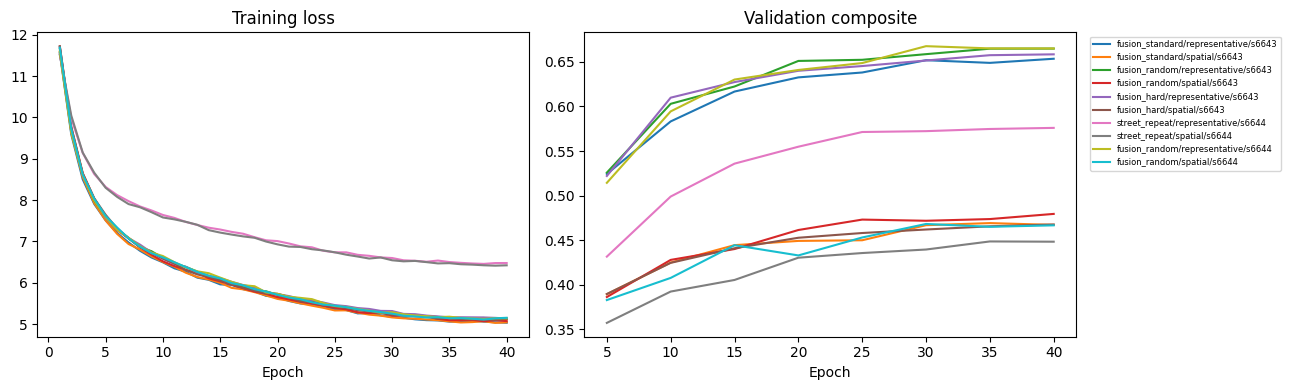

,variant,split,seed,borough,count,f1,mean_km
0,candidate_equal,representative,6643,Bronx,353,0.709677,4.871452
1,candidate_equal,representative,6643,Brooklyn,564,0.760181,3.867804
2,candidate_equal,representative,6643,Manhattan,356,0.879892,2.177598
3,candidate_equal,representative,6643,Queens,932,0.854486,3.371055
4,candidate_equal,representative,6643,Staten Island,167,0.795518,5.627102
5,candidate_equal,spatial,6643,Bronx,370,0.656552,7.112782
6,candidate_equal,spatial,6643,Brooklyn,601,0.701847,4.796115
7,candidate_equal,spatial,6643,Manhattan,353,0.853846,2.663330
8,candidate_equal,spatial,6643,Queens,927,0.810486,4.996626
9,candidate_equal,spatial,6643,Staten Island,170,0.747967,10.798627


Decision: retain_fusion_development_candidate | selected: fusion_random | seed repeat: True
New head fitting: 1068.45 seconds; public score remains user-reported .60599.


In [31]:
# Cell 82 — Saved results, curves, metrics and next decision.
def fusion_dashboard():
    pointer=FUSION_HOME/'latest.json'
    if not pointer.exists():
        print('Fusion study not yet completed. Public baseline: .60599 (user report).')
        return
    value=json.loads(pointer.read_text());require(sha256(ROOT/value['decision'])==value['sha256'],'Decision changed.')
    report=json.loads((ROOT/value['decision']).read_text())
    table=pd.DataFrame(report['records'])
    table['gain_vs_original']=[r.score-DINO_BASELINES[r.split]['score'] for r in table.itertuples()]
    display(table[['variant','split','seed','score','gain_vs_original','mean_km','median_km','p90_km','borough_macro_f1','fraction_over_10km','fraction_over_20km']])
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    borough_rows=[]
    for row in report['records']:
        borough_rows.extend([{'variant':row['variant'],'split':row['split'],'seed':row['seed'],'borough':b,**m} for b,m in row['borough_metrics'].items()])
        if 'checkpoint' not in row:continue
        folder=(ROOT/row['checkpoint']).parent
        history=json.loads((folder/'history.json').read_text())
        label=f"{row['variant']}/{row['split']}/s{row['seed']}"
        axes[0].plot([h['epoch'] for h in history],[h['loss'] for h in history],label=label)
        scored=[h for h in history if h['metrics']]
        axes[1].plot([h['epoch'] for h in scored],[h['metrics']['score'] for h in scored],label=label)
    axes[0].set(title='Training loss',xlabel='Epoch');axes[1].set(title='Validation composite',xlabel='Epoch')
    axes[1].legend(fontsize=6,loc='upper left',bbox_to_anchor=(1.02,1))
    fig.tight_layout();plt.show()
    display(pd.DataFrame(borough_rows))
    print('Decision:',report['decision'],'| selected:',report['selected_variant'],'| seed repeat:',report['repeat_seed_passed'])
    print('New head fitting:',round(report['head_seconds'],2),'seconds; public score remains user-reported .60599.')
    return report

FUSION_SAVED_RESULT=fusion_dashboard()


## Fusion outcome and artifact verification

The read-only audit below reloads every selected checkpoint, reproduces scores from
saved predictions, checks exact training/validation IDs and training-only normalization,
confirms the original feature hashes and verifies the compute ledger. Intervals from
the paired block bootstrap describe reused development data. No public-score estimate
is inferred from these experiments. Final all-label refit/test inference is a separate
stage; the previously submitted StreetCLIP CSV stays the public baseline.

### Monitored study completed — 2026-11-17

Retain **StreetCLIP + spatial DINOv2 learned fusion with 32 ordinary distant negatives** as the new development candidate (`fusion_random`). The baseline sampler still has 128 anchors and 128 nearby partners; the random/hard arms append 32 rows. This is a practical sampler comparison, not a pure number-of-examples ablation.

| Method / seed | Representative score | Spatial score | Representative mean km | Spatial mean km |
|---|---:|---:|---:|---:|
| Existing StreetCLIP / 6643 | .582646104 | .436518798 | 4.414989 | 5.987724 |
| Equal candidate fusion / 6643 | .647699366 | .495042634 | 3.692175 | 5.337459 |
| Learned standard fusion / 6643 | .653520396 | .469191058 | 3.665401 | 5.632637 |
| Learned fusion + random negatives / 6643 | **.664912829** | **.479508151** | **3.543432** | **5.530323** |
| Learned fusion + mined negatives / 6643 | .658469982 | .467660362 | 3.611462 | 5.654899 |
| Matched StreetCLIP control / 6644 | .575983659 | .448624287 | 4.479652 | 5.841517 |
| Learned fusion + random negatives / 6644 | **.667630293** | **.468218635** | **3.512208** | **5.645370** |

All ten new heads completed 40 epochs. Primary selected checkpoints are epoch40; second-seed selected checkpoints epoch30 after all40 completed. Fusion passes the predeclared >=.002 gain and lower mean error on both original folds, and repeats point gains over matching seed6644 controls. Candidate fusion has the best spatial score; the learned model wins the predeclared average-gain selection. Hard mining loses against random negatives on both folds and is rejected.

Primary learned-fusion gains are +.082266725 / +.042989353 over the original baseline. Second-seed matched gains are +.091646634 / +.019594348. The latter spatial gain has a paired 1-km-block bootstrap 95% interval **[-.005648, .048100]**: its sign remains uncertain. Primary gains have development intervals [.058086,.103860] / [.012470,.075253]. These are reused-development, post-selection diagnostics; no private/public inference is warranted.

Eight-image CPU FP32 / MPS FP32 minimum cosine **.99999988**, relative RMS **7.71e-6**; stored-cache / CPU cosine **.99999982**, RMS **.0002085**. The historical FP16 mismatch is retained; DINO stays FP32-produced. No root cause of that mismatch is claimed.

New head fitting **1068.4496 seconds (17.81 minutes)**, under the20-minute cap; each head under3 minutes. Sampled peak head MPS driver allocation **1167458304 bytes (~1.09 GiB)**, not a whole-system peak. Study notebook execution **1258.07 seconds**, zero cell errors. Training-disabled targeted fresh-kernel verification passed **53 checks**,32 code cells,zero errors in15.98 seconds; subsequent read-only audit additionally checked matched-seed intervals. This was a targeted stage execution, not a full restart-and-run-all of every historical notebook cell.

Strict loading/scoring audit verified10 checkpoints, exact fold IDs and727 spatial exclusions, training-only feature statistics, self-excluded training retrieval diagnostics, finite outputs, all40 complete epochs, cache/checkpoint hashes, mined negative distances>2km, replayed validation predictions and the original CSV checksum. New curves were visually inspected.

Decision: `outputs/fusion/study_8ff4561c2d7cdd27/decision.json`. Verification: `outputs/fusion/study_8ff4561c2d7cdd27/verification.json`. Primary checkpoints and complete loss/metric/borough/recall/history/source records are linked there. New learned fusion has **not** been refitted on all labels or run on test images. **Public Kaggle baseline remains user-reported .60599** for the original StreetCLIP CSV. No new weights, datasets, dependencies, test features, CSV, submission, HPC action, commit or push occurred.

Single next proposed task: refit the selected fusion configuration on all official training labels, encode the missing DINO test features with the verified FP32 pipeline, and generate a separately validated candidate CSV. The fixed candidate ensemble remains available for a later separately declared comparison. SALAD/BoQ and encoder fine-tuning remain conditional future experiments; they were not implemented or run in this bounded stage.


In [1]:
# Cell 84 — Read-only audit of all completed monitored fusion experiments.
def verify_fusion_study():
    pointer=FUSION_HOME/'latest.json'
    if not pointer.exists():
        print('No completed fusion study to verify yet.')
        return
    link=json.loads(pointer.read_text())
    require(sha256(ROOT/link['decision'])==link['sha256'],'Decision hash mismatch.')
    result=json.loads((ROOT/link['decision']).read_text())
    frame,splits,street,dino,ledger,_=fusion_sources()
    require(result['identity']['dino_sha256']==ledger['sha256'],'Study DINO identity mismatch.')
    names=['FusionGeoHead','fusion_fit','fusion_outputs','fusion_candidate_batch','fusion_mine_negatives',
           'fusion_model_load','fusion_diagnostics','fusion_bootstrap','fusion_score','fusion_study',
           'FeatureLayerNorm','CompassGeoHead','geographic_contrastive_loss','fit_geography','dino_statistics',
           'compass_decoders','diagnostic_prediction_batch','diagnostic_neighbors','bounded_geometric_median']
    require(dino_definitions_hash(names)==result['identity']['source'],'Study executable definitions changed.')
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    statistics={}
    for split_name in ('representative','spatial'):
        ids=splits['splits'][split_name]['train_ids'];index=position.loc[ids].to_numpy()
        statistics[split_name]=(*dino_statistics(street[index]),*dino_statistics(dino[index]))
    reviewed=[];runtimes=[];sampled_peak=0
    directory=ROOT/result['directory']
    for record in result['records']:
        split=record['split'];truth=frame.loc[splits['splits'][split]['validation_ids']]
        if 'checkpoint' not in record:
            prediction=pd.read_csv(directory/f"candidate_equal_{split}.csv")
        else:
            path=ROOT/record['checkpoint'];run=path.parent
            require(sha256(path)==record['checkpoint_sha256'],'Selected head checksum mismatch.')
            model,saved=fusion_model_load(path,result['identity'],torch.device('cpu'))
            require(saved['train_ids']==splits['splits'][split]['train_ids'] and saved['validation_ids']==truth.sample_id.tolist(),'Fold ID drift.')
            means=statistics[split]
            state=saved['state_dict']
            if record['variant']=='street_repeat':
                checked=[('feature_mean',means[0]),('feature_std',means[1])]
            else:checked=list(zip(('street_mean','street_std','dino_mean','dino_std'),means))
            for name,expected in checked:np.testing.assert_allclose(state[name].numpy(),expected,rtol=0,atol=1e-6)
            status=json.loads((run/'status.json').read_text());history=json.loads((run/'history.json').read_text())
            require(status['status']=='complete' and status['completed_epochs']==40 and len(history)==40,'Incomplete head was selected.')
            require(all(h['unique_anchor_locations']==len(saved['train_ids']) for h in history),'Anchor coverage mismatch.')
            require(status['elapsed_seconds']<180,'Per-head time cap exceeded.')
            runtimes.append(status['elapsed_seconds']);sampled_peak=max(sampled_peak,max(h['driver_bytes'] for h in history))
            prediction=pd.read_csv(run/'validation_best.csv')
            reloaded=pd.read_csv(run/'diagnostic_validation.csv')
            require(prediction.sample_id.tolist()==reloaded.sample_id.tolist() and prediction.borough.tolist()==reloaded.borough.tolist(),'Reloaded predictions differ.')
            np.testing.assert_allclose(prediction[['latitude','longitude']],reloaded[['latitude','longitude']],rtol=0,atol=1e-7)
            if record['variant']=='fusion_hard':
                mining=json.loads((run/'hard_negative_provenance.json').read_text())
                require(mining['train_ids']==saved['train_ids'] and sha256(run/'hard_negative_positions.npy')==mining['sha256'],'Mining provenance mismatch.')
                nearest=np.load(run/'hard_negative_positions.npy')
                gps=frame.loc[saved['train_ids'],['latitude','longitude']].to_numpy()
                distance=haversine_km(np.repeat(gps,nearest.shape[1],axis=0),gps[nearest].reshape(-1,2))
                require(bool((distance>2).all()),'Hard negative is geographically ambiguous or a self-match.')
            del model
        metrics=fusion_score(truth,prediction)
        for name in ('score','borough_macro_f1','gps_score','mean_km','median_km','p90_km'):
            require(abs(metrics[name]-record[name])<1e-7,f'Saved score drift: {name}')
        control=pd.read_csv((ROOT/DINO_BASELINES[split]['path']).parent/'validation_best.csv')
        interval=fusion_bootstrap(truth,prediction,control,splits)
        reviewed.append({'variant':record['variant'],'split':split,'seed':record['seed'],
                         'score':record['score'],'delta_vs_original':record['score']-DINO_BASELINES[split]['score'],**interval})
    matched=[]
    for split_name in ('representative','spatial'):
        selected=next((r for r in result['records'] if r['variant']==result['selected_variant'] and r['seed']==6644 and r['split']==split_name),None)
        control=next((r for r in result['records'] if r['variant']=='street_repeat' and r['split']==split_name),None)
        if selected is not None and control is not None:
            a=pd.read_csv((ROOT/selected['checkpoint']).parent/'validation_best.csv')
            b=pd.read_csv((ROOT/control['checkpoint']).parent/'validation_best.csv')
            truth=frame.loc[splits['splits'][split_name]['validation_ids']]
            matched.append({'split':split_name,'seed':6644,'point_score_gain':selected['score']-control['score'],
                            **fusion_bootstrap(truth,a,b,splits)})
    budget=json.loads((directory/'budget.json').read_text())
    require(abs(sum(runtimes)-budget['head_seconds'])<1e-5 and budget['head_seconds']<=1200,'Aggregate budget mismatch.')
    baseline_csv=ROOT/'Kaggle Submissions/nycguessr_streetclip40_20261116.csv'
    require(sha256(baseline_csv)=='c065fb05a3f31c9195f4132f726c2f6c7d1b52195b831dcc59dbe877e33dc35f','Original submission changed.')
    report={'status':'passed','decision_sha256':link['sha256'],'checkpoints_verified':len(runtimes),
            'head_seconds':budget['head_seconds'],'sampled_peak_head_driver_bytes':sampled_peak,'comparisons':reviewed,
            'selected_variant':result['selected_variant'],'second_seed_passed':result['repeat_seed_passed'],
            'matched_second_seed_intervals':matched,
            'train_folds_and_spatial_buffer_preserved':True,'training_only_statistics_verified':True,
            'cached_feature_checksums_verified':True,'baseline_submission_unchanged':True,
            'new_public_score':None,'kaggle_upload_performed':False}
    dino_json(directory/'verification.json',report)
    display(pd.DataFrame(reviewed))
    display(pd.DataFrame(matched))
    print(f"Verified {len(runtimes)} completed heads; {budget['head_seconds']:.2f} seconds new fitting; original CSV unchanged.")
    return report

FUSION_VERIFICATION=verify_fusion_study()


            variant  ...                                     interpretation
0   candidate_equal  ...  Reused development data; block-resampling unce...
1   candidate_equal  ...  Reused development data; block-resampling unce...
2   fusion_standard  ...  Reused development data; block-resampling unce...
3   fusion_standard  ...  Reused development data; block-resampling unce...
4     fusion_random  ...  Reused development data; block-resampling unce...
5     fusion_random  ...  Reused development data; block-resampling unce...
6       fusion_hard  ...  Reused development data; block-resampling unce...
7       fusion_hard  ...  Reused development data; block-resampling unce...
8     street_repeat  ...  Reused development data; block-resampling unce...
9     street_repeat  ...  Reused development data; block-resampling unce...
10    fusion_random  ...  Reused development data; block-resampling unce...
11    fusion_random  ...  Reused development data; block-resampling unce...

[12 rows x 

## Selected fusion: all-label refit and submission — 2026-11-17

The user requests a submission CSV. Refit the preselected `fusion_random` configuration
from seed6643 on all11,864 labeled locations:40 epochs, the same40-epoch OneCycle
schedule,128 anchors +128 nearby partners +32 ordinary distant negatives, unchanged
losses/normalization/model and mixed-median decoder. Do not add mined negatives or
choose the second seed because it has a larger representative score. The final refit
has no held-out score; source development scores are .664912829/.479508151.

Fit cap: five cumulative minutes with durable epoch checkpoints. Feature extraction:
reuse the exact existing frozen DINOv2 FP32 encoder/preprocessing; all31,632 official
test image bytes are checked against the supplied manifest while decoding. Reuse
the verified complete StreetCLIP test cache. DINO test namespace/coverage/budget are
separate from training; test prediction placeholders never enter features or targets.
Existing60-minute DINO test budget remains cumulative across resumes. Actual MPS
driver allocation is capped by the existing guard. No download or dependency change.

Final inference uses explicit disjoint internal test keys because numeric test/train
IDs overlap. Export only exact official template IDs/headers/order,7,908 rows, finite
coordinates and valid boroughs; check training-derived coordinate extents without
clipping. Refuse overwrite of a conflicting CSV, validate read-back, reload the strict
checkpoint and reproduce all predictions. Save source/data/model/cache/CSV hashes.
No Kaggle upload is requested. `NYCGUESSR_FUSION_SUBMISSION=1` enables generation;
ordinary reruns verify the finished candidate without extraction or retraining.


### Submission generated and verified

**CSV:** `Kaggle Submissions/nycguessr_fusion40_20261117.csv`, **7,908 rows**, **302,110 bytes**, exact headers/template order; SHA-256 `075d86f3a426872c50f2b970d01b6cdb51319f6f102837dbd445a1019740ed3b`. It has not been uploaded; its public score is unknown. The previous .60599 is the user's report for the earlier StreetCLIP CSV.

The fresh selected seed6643 head completed **40 epochs on all11,864 training locations in 127.40 seconds**. Checkpoint `outputs/fusion/submission_20261117/full40.pth`, SHA `34acaf8c4ad1bd2c80314f4b320ad1bce066e6e06c77d69d314c5602cc959199`. The full fit has no held-out score. Source development scores remain **.664912829 representative / .479508151 spatial**. No hyperparameter selection or hard-negative mining was added during the refit.

All31,632 test image byte hashes matched the original official manifest. DINO test extraction completed in **1687.63 seconds (28.13 minutes)** under the cumulative60-minute budget; slower than the earlier short benchmark, with no numerical failures or OOM retries. Test cache: `outputs/dinov2/features/test_78de04b778ab6bd6.npy`, float16 storage `[7908,4,5,768]`, **242,933,888 bytes**, SHA `a82a19cd8de9b15e4b092e76c1ad7e25875abf2300ac19b0878d574b93307234`. Encoder inference remained FP32. Sampled MPS driver maximum **3,602,382,848 bytes (~3.35 GiB)**, not a whole-system peak. The complete existing StreetCLIP train/test caches and original DINO training cache were preserved.

Strict checkpoint reload reproduced all7,908 boroughs exactly and GPS values to **5e-09 degrees**, consistent with eight-decimal CSV serialization. Full refit scope/epochs, training-only statistics, all-view coverage, train/test namespace separation, complete cache hashes, exact template schema/order, valid coordinates and training-derived extents passed. Template prediction placeholders are never inputs. Original CSV hash remains unchanged.

Predicted borough counts (outputs, not imposed quotas): Queens3020, Brooklyn1909, Manhattan1271, Bronx1125, Staten Island583. Latitude 40.50289422–40.90806355; longitude -74.24409694–-73.70626018. No clipping, external map data or manual prediction edits.

Initial targeted generation: **33 code cells /55 checks /zero errors /1853.47 seconds**. Final fresh-kernel, training/extraction/export-disabled targeted verification: **33 code cells /55 checks /zero errors /22.92 seconds**. This is not a full execution of every historical experiment cell. Actual outputs are saved in the notebook.

Provenance and complete contracts: `outputs/fusion/submission_20261117/manifest.json`, `verification.json`, `fit_config.json`, `fit_history.json`, `fit_status.json`, `source_notebook.ipynb`, and the two notebook execution records. All real-run flags remain disabled by default. No new dependencies/weights/external data, HPC work, Kaggle upload, messages, commits or pushes. Single next action: manual Kaggle upload of this exact candidate and record its measured public score.


In [25]:
# Cell 86 — All-label selected-model fitting, test inference and export helpers.
FUSION_SUBMISSION_HOME=FUSION_HOME/'submission_20261117'
FUSION_SUBMISSION_CSV=ROOT/'Kaggle Submissions/nycguessr_fusion40_20261117.csv'

def fusion_submission_source():
    link=json.loads((FUSION_HOME/'latest.json').read_text())
    require(sha256(ROOT/link['decision'])==link['sha256'],'Fusion decision checksum changed.')
    selected=json.loads((ROOT/link['decision']).read_text())
    require(selected['selected_variant']=='fusion_random' and selected['repeat_seed_passed'],
            'This export requires the selected, second-seed-checked ordinary-negative fusion.')
    source=next(r for r in selected['records'] if r['variant']=='fusion_random' and r['split']=='representative' and r['seed']==6643)
    require(source['epoch']==40 and sha256(ROOT/source['checkpoint'])==source['checkpoint_sha256'],'Selected source changed.')
    return selected,source,link['sha256']

def fusion_refit_identity(selected,source,decision_sha):
    return {'study_identity':selected['identity'],'decision_sha256':decision_sha,'source_sha256':source['checkpoint_sha256'],
            'train_ids':list(range(11864)),'epochs':40,'schedule_epochs':40,'seed':6643,'variant':'fusion_random',
            'source':dino_definitions_hash(['fusion_full_refit','fusion_distant_random','FusionGeoHead',
                'fusion_outputs','fusion_namespaced_prediction','geographic_contrastive_loss','dino_statistics',
                'fit_geography','FeatureLayerNorm','compass_decoders','bounded_geometric_median'])}

def fusion_distant_random(rng,anchors,coordinates,minimum_km=2.,count=32):
    """Match the selected head's bounded ordinary-negative sampler exactly."""
    extra=[]
    for i in anchors[:min(count,len(anchors))]:
        for _ in range(100):
            j=int(rng.integers(len(coordinates)))
            if j!=i and haversine_km(coordinates[i:i+1],coordinates[j:j+1])[0]>minimum_km:break
        else:raise ValueError('Could not draw a geographically distant ordinary negative.')
        extra.append(j)
    return np.asarray(extra,dtype=np.int64)

def fusion_full_refit(frame,street,dino,selected,source,decision_sha,max_seconds=300.):
    require(frame.sample_id.tolist()==list(range(11864)),'All-label refit must include all official train IDs once.')
    directory=FUSION_SUBMISSION_HOME;directory.mkdir(parents=True,exist_ok=True)
    identity=fusion_refit_identity(selected,source,decision_sha)
    status_path=directory/'fit_status.json';checkpoint_path=directory/'full40.pth'
    status=json.loads(status_path.read_text()) if status_path.exists() else {'status':'new','elapsed_seconds':0.}
    if status['status']=='complete':
        require(sha256(checkpoint_path)==status['checkpoint_sha256'],'Final refit checksum changed.')
        saved=torch.load(checkpoint_path,map_location='cpu',weights_only=True)
        require(saved['refit_identity']==identity and saved['fit_complete'],'Completed refit identity mismatch.')
        return checkpoint_path
    require(status['status']!='failed','Inspect the failed final refit before any new retry.')
    used=float(status['elapsed_seconds']);require(used<max_seconds,'Final fit budget exhausted; review before explicitly extending.')
    seed_everything(6643);rng=np.random.default_rng(6643);device=dino_device()
    geography=fit_geography(frame,cells=512)
    sm,ss=dino_statistics(street);dm,ds=dino_statistics(dino)
    model=FusionGeoHead(geography,sm,ss,dm,ds).to(device)
    gps=frame[['latitude','longitude']].to_numpy()
    xy=((gps-geography['origin'])*geography['scales']).astype(np.float32)
    distance=np.linalg.norm(xy[:,None]-np.asarray(geography['centers'],np.float32)[None],axis=-1)
    target=np.exp(-(distance-distance.min(1,keepdims=True)));target/=target.sum(1,keepdims=True)
    nearby=cKDTree(xy).query_ball_point(xy,.15)
    nearby=[np.asarray([j for j in group if j!=i],dtype=int) for i,group in enumerate(nearby)]
    s=torch.as_tensor(np.array(street,copy=True),device=device)
    d=torch.as_tensor(np.array(dino,copy=True),device=device)
    locations=torch.as_tensor(xy,device=device);soft=torch.as_tensor(target,device=device)
    labels=torch.tensor([BOROUGHS.index(b) for b in frame.borough],device=device)
    ids=torch.as_tensor(frame.sample_id.to_numpy(copy=True),device=device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.05)
    scheduler=torch.optim.lr_scheduler.OneCycleLR(optimizer,max_lr=.001,total_steps=40*int(np.ceil(len(frame)/128)),pct_start=.1)
    start_epoch=1;history=[]
    resume_path=directory/'last_epoch.pth'
    if resume_path.exists():
        last=torch.load(resume_path,map_location='cpu',weights_only=True)
        require(last['refit_identity']==identity,'Resume source/config changed.')
        model.load_state_dict(last['state_dict'],strict=True);optimizer.load_state_dict(last['optimizer']);scheduler.load_state_dict(last['scheduler'])
        rng.bit_generator.state=last['numpy_rng'];torch.set_rng_state(last['torch_rng'])
        if device.type=='mps':torch.mps.set_rng_state(last['gpu_rng'])
        else:torch.cuda.set_rng_state(last['gpu_rng'],device)
        start_epoch=last['epoch']+1;history=last['history']
    config={'refit_identity':identity,'selection_source':source,'train_locations':11864,'validation_locations':0,
            'epochs':40,'schedule_epochs':40,'anchors':128,'nearby_partners':128,'ordinary_negatives':32,
            'target_km':1.,'positive_radius_km':.15,'learning_rate':.001,'weight_decay':.05,
            'contrastive_temperature':.05,'borough_weight':.3,'decoder':'mixed_median','head_precision':'float32'}
    if (directory/'fit_config.json').exists():require(json.loads((directory/'fit_config.json').read_text())==config,'Final configuration changed.')
    else:
        dino_json(directory/'fit_config.json',config)
        (directory/'source_notebook.ipynb').write_bytes((ROOT/'NYCGuessr.ipynb').read_bytes())
    started=time.monotonic();status['status']='running'
    try:
        for epoch in tqdm(range(start_epoch,41),total=40,initial=start_epoch-1,desc='Fusion all-label refit',unit='epoch'):
            model.train();epoch_start=time.monotonic();losses=[];anchors=rng.permutation(len(frame))
            for start in range(0,len(frame),128):
                if used+time.monotonic()-started>=max_seconds:raise DinoBudgetPause()
                a=anchors[start:start+128]
                paired=np.array([rng.choice(nearby[i]) if len(nearby[i]) else (i+rng.integers(1,len(frame)))%len(frame) for i in a])
                extra=fusion_distant_random(rng,a,gps)
                index=torch.as_tensor(np.concatenate([a,paired,extra]),device=device)
                output=model(s[index],d[index])
                cell_loss=-(soft[index]*output['cell_logits'].log_softmax(1)).sum(1).mean()
                borough_loss=F.cross_entropy(output['borough_logits'],labels[index],weight=model.borough_weights)
                contrastive=geographic_contrastive_loss(output['embedding'],locations[index],ids[index])
                loss=cell_loss+.3*borough_loss+contrastive
                require(bool(torch.isfinite(loss)),'Nonfinite final fusion loss.')
                optimizer.zero_grad(set_to_none=True);loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True)
                optimizer.step();scheduler.step()
                losses.append([float(v.detach().cpu()) for v in (loss,cell_loss,borough_loss,contrastive)])
            mean=np.mean(losses,axis=0)
            history.append({'epoch':epoch,'loss':float(mean[0]),'cell_loss':float(mean[1]),'borough_loss':float(mean[2]),
                            'contrastive_loss':float(mean[3]),'unique_anchor_locations':len(anchors),
                            'seconds':time.monotonic()-epoch_start,'driver_bytes':dino_memory_guard(device)})
            saved={'identity':selected['identity'],'refit_identity':identity,'variant':'fusion_random','split':'full','seed':6643,
                   'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'geography':geography,'epoch':epoch,
                   'train_ids':frame.sample_id.tolist(),'validation_ids':[],'metrics':{},'fit_complete':epoch==40,
                   'history':history,'config':config}
            last={**saved,'optimizer':optimizer.state_dict(),'scheduler':scheduler.state_dict(),
                  'numpy_rng':rng.bit_generator.state,'torch_rng':torch.get_rng_state(),
                  'gpu_rng':torch.mps.get_rng_state() if device.type=='mps' else torch.cuda.get_rng_state(device)}
            dino_torch_save(resume_path,last);dino_json(directory/'fit_history.json',history)
            if epoch==40:dino_torch_save(checkpoint_path,saved)
        status.update(status='complete',checkpoint_sha256=sha256(checkpoint_path))
    except DinoBudgetPause:
        status['status']='budget_paused'
        print('Refit time budget reached; last complete epoch preserved. No CSV generated.')
    except KeyboardInterrupt:
        status['status']='interrupted';raise
    except Exception as error:
        status.update(status='failed',error=str(error));raise
    finally:
        status.update(elapsed_seconds=used+time.monotonic()-started,completed_epochs=len(history))
        dino_json(status_path,status)
        del model,optimizer,s,d,locations,soft,labels,ids
        dino_release(device)
    return checkpoint_path if status['status']=='complete' else None

@torch.inference_mode()
def fusion_namespaced_prediction(model,geography,training,template,train_s,train_d,test_s,test_d,device):
    require(training.sample_id.is_unique and template.sample_id.is_unique,'Duplicate inference IDs.')
    require(len(train_s)==len(train_d)==len(training) and len(test_s)==len(test_d)==len(template),'Feature/ID misalignment.')
    # The ordinary validation decoder keeps its strict overlap guard.
    keys=np.arange(len(template),dtype=np.int64)+int(training.sample_id.max())+1
    _,_,bank=fusion_outputs(model,train_s,train_d,device)
    probability,borough,queries=fusion_outputs(model,test_s,test_d,device)
    predicted=compass_decoders(training,keys,geography,bank,queries,probability,borough.argmax(1))['mixed_median']
    require(predicted.sample_id.tolist()==keys.tolist(),'Final decoder reordered IDs.')
    predicted['sample_id']=template.sample_id.to_numpy()
    validate_predictions(predicted,template.sample_id.to_numpy())
    return predicted

def fusion_test_street_cache(template):
    path=ROOT/'outputs/features/streetclip_test_f1901b97eac036c7.npy'
    require(sha256(path)=='b6870dc542cdfd23cc701572da74fe5b239dec0088eee90679a539c9bcb39695','StreetCLIP test cache changed.')
    features=np.load(path,mmap_mode='r')
    metadata=json.loads(path.with_suffix('.json').read_text())
    require(features.shape==(7908,4,1024) and metadata['complete'] and metadata['spec']['sample_ids']==template.sample_id.tolist(),
            'StreetCLIP test cache incomplete or IDs reordered.')
    return features

def fusion_generate_submission():
    frame,splits,street,dino,ledger,_=fusion_sources()
    selected,source,decision_sha=fusion_submission_source()
    _,template=load_data(ROOT)
    checkpoint=fusion_full_refit(frame,street,dino,selected,source,decision_sha)
    if checkpoint is None:return
    benchmark=json.loads((DINO_HOME/'benchmark.json').read_text())
    require(benchmark['precision']=='float32','Final DINO inference must use the verified FP32 encoder.')
    manifest_path=ROOT/'outputs/input_manifest.jsonl'
    require(sha256(manifest_path)=='e878c8ce10ce2032c4790184e0344fbf6bd95a3ad206fe45f7a8b39671610d7a','Raw manifest changed.')
    manifest={r['path']:r['sha256'] for r in map(json.loads,manifest_path.read_text().splitlines())}
    test=official_test_frame(template)
    extracted=dino_extract('test',test,manifest,benchmark)
    if extracted is None:
        print('Test cache paused; resume this same cell. No prediction from partial features.');return
    test_dino,test_ledger=extracted
    test_street=fusion_test_street_cache(template)
    device=dino_device();model,saved=fusion_model_load(checkpoint,selected['identity'],device)
    try:
        require(saved['fit_complete'] and saved['epoch']==40 and saved['train_ids']==frame.sample_id.tolist()
                and saved['validation_ids']==[],'Final head scope/epoch mismatch.')
        prediction=fusion_namespaced_prediction(model,saved['geography'],frame,template,street,dino,test_street,test_dino,device)
        lower=frame[['latitude','longitude']].min().to_numpy();upper=frame[['latitude','longitude']].max().to_numpy()
        require(bool(((prediction[['latitude','longitude']].to_numpy()>=lower-1e-8)&
                      (prediction[['latitude','longitude']].to_numpy()<=upper+1e-8)).all()),'Predictions exceed training-derived candidate extents.')
        if FUSION_SUBMISSION_CSV.exists():
            previous=pd.read_csv(FUSION_SUBMISSION_CSV);validate_predictions(previous,template.sample_id.to_numpy())
            require(previous.borough.tolist()==prediction.borough.tolist(),'Existing candidate boroughs conflict.')
            np.testing.assert_allclose(previous[['latitude','longitude']],prediction[['latitude','longitude']],rtol=0,atol=1e-8)
        else:export_submission(prediction,template,FUSION_SUBMISSION_CSV)
        restored=pd.read_csv(FUSION_SUBMISSION_CSV)
        require(list(restored.columns)==list(template.columns) and restored.sample_id.tolist()==template.sample_id.tolist(),'CSV schema/order mismatch.')
        report={'status':'ready_for_manual_kaggle_upload','csv':str(FUSION_SUBMISSION_CSV.relative_to(ROOT)),
                'csv_sha256':sha256(FUSION_SUBMISSION_CSV),'csv_bytes':FUSION_SUBMISSION_CSV.stat().st_size,'rows':len(restored),
                'headers':list(restored.columns),'decision_sha256':decision_sha,'source_checkpoint':source['checkpoint'],
                'source_checkpoint_sha256':source['checkpoint_sha256'],'checkpoint':str(checkpoint.relative_to(ROOT)),
                'checkpoint_sha256':sha256(checkpoint),'refit_identity':saved['refit_identity'],'full_fit_held_out_score':None,
                'train_cache_sha256':ledger['sha256'],'test_dino_sha256':test_ledger['sha256'],
                'test_dino_spec':test_ledger['spec'],'test_dino_seconds':test_ledger['elapsed_seconds'],
                'test_dino_sampled_peak_driver_bytes':test_ledger['sampled_peak_driver_bytes'],
                'street_test_sha256':'b6870dc542cdfd23cc701572da74fe5b239dec0088eee90679a539c9bcb39695',
                'source_development_scores':{r['split']:r['score'] for r in selected['records'] if r['variant']=='fusion_random' and r['seed']==6643},
                'borough_counts':restored.borough.value_counts().to_dict(),
                'latitude_range':[float(restored.latitude.min()),float(restored.latitude.max())],
                'longitude_range':[float(restored.longitude.min()),float(restored.longitude.max())],
                'public_score':None,'kaggle_uploaded':False}
        dino_json(FUSION_SUBMISSION_HOME/'manifest.json',report)
        record_run(ROOT,'fusion_full40_submission_20261117','fusion_submission','test',{},
                   {'source':source,'refit_identity':saved['refit_identity']},test_ledger['elapsed_seconds'],
                   {'manifest':str((FUSION_SUBMISSION_HOME/'manifest.json').relative_to(ROOT))},'Validated local CSV; no Kaggle upload or new public score.')
        print('Generated:',FUSION_SUBMISSION_CSV,'| rows:',len(restored))
        return report
    finally:
        del model
        dino_release(device)


In [31]:
# Cell 87 — Full-refit sampler and final test-namespace regression checks.
class FusionSubmissionTests(unittest.TestCase):
    def test_random_negatives_match_selected_sampler_rng_and_distance(self):
        count=60;coordinates=np.stack([40.4+np.arange(count)*.01,np.full(count,-74.)],axis=1)
        anchors=np.arange(10);rng=np.random.default_rng(6643)
        actual=fusion_distant_random(rng,anchors,coordinates)
        expected=[];reference=np.random.default_rng(6643)
        for i in anchors:
            for attempt in range(100):
                j=int(reference.integers(count))
                if j!=i and haversine_km(coordinates[i:i+1],coordinates[j:j+1])[0]>2:break
            expected.append(j)
        np.testing.assert_array_equal(actual,expected)
        self.assertTrue(bool((haversine_km(coordinates[anchors],coordinates[actual])>2).all()))

    def test_namespaced_fusion_keeps_overlapping_numeric_ids(self):
        from unittest.mock import patch
        training=example_frame(40);geo=fit_geography(training,cells=32);rng=np.random.default_rng(4)
        bank=rng.normal(size=(40,12)).astype(np.float32);queries=bank[:2].copy()
        p=rng.uniform(size=(2,32)).astype(np.float32);p/=p.sum(1,keepdims=True)
        borough=np.eye(5,dtype=np.float32)[[0,1]]
        template=example_frame(2);s=np.zeros((40,4,2));ts=np.zeros((2,4,2));d=np.zeros((40,4,5,2));td=np.zeros((2,4,5,2))
        with patch.dict(globals(),fusion_outputs=lambda model,a,b,device:(np.zeros((40,32)),np.zeros((40,5)),bank) if len(a)==40 else (p,borough,queries)):
            prediction=fusion_namespaced_prediction(None,geo,training,template,s,d,ts,td,torch.device('cpu'))
            changed=template.copy();changed['borough']='Queens';changed['latitude']=0.;changed['longitude']=0.
            ignored=fusion_namespaced_prediction(None,geo,training,changed,s,d,ts,td,torch.device('cpu'))
        expected=compass_decoders(training,[40,41],geo,bank,queries,p,np.array([0,1]))['mixed_median']
        np.testing.assert_allclose(prediction[['latitude','longitude']],expected[['latitude','longitude']],rtol=0,atol=1e-10)
        pd.testing.assert_frame_equal(prediction,ignored)
        self.assertEqual(prediction.sample_id.tolist(),[0,1])
        with self.assertRaises(ValueError):compass_decoders(training,[0,1],geo,bank,queries,p,np.array([0,1]))

fusion_submission_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(FusionSubmissionTests))
require(fusion_submission_tests.wasSuccessful(),'Resolve final inference contracts before export.')


test_namespaced_fusion_keeps_overlapping_numeric_ids (__main__.FusionSubmissionTests.test_namespaced_fusion_keeps_overlapping_numeric_ids) ... 

ok


test_random_negatives_match_selected_sampler_rng_and_distance (__main__.FusionSubmissionTests.test_random_negatives_match_selected_sampler_rng_and_distance) ... 

ok


----------------------------------------------------------------------
Ran 2 tests in 0.020s

OK


In [32]:
# Cell 88 — Explicitly enabled, resumable fusion CSV generation. No Kaggle upload.
RUN_FUSION_SUBMISSION=os.environ.get('NYCGUESSR_FUSION_SUBMISSION','0')=='1'
if RUN_FUSION_SUBMISSION:
    FUSION_CSV_RESULT=fusion_generate_submission()
else:
    print('Fusion refit/extraction/export disabled; completed artifacts are verified below when present.')


Fusion refit/extraction/export disabled; completed artifacts are verified below when present.


In [33]:
# Cell 89 — Strict checkpoint/cache/CSV replay, without image extraction or fitting.
def verify_fusion_submission():
    manifest_path=FUSION_SUBMISSION_HOME/'manifest.json'
    if not manifest_path.exists():
        print('No completed fusion submission manifest yet.');return
    report=json.loads(manifest_path.read_text())
    frame,_,street,dino,ledger,_=fusion_sources();_,template=load_data(ROOT)
    selected,source,decision_sha=fusion_submission_source()
    require(report['decision_sha256']==decision_sha and report['source_checkpoint_sha256']==source['checkpoint_sha256'],'Submission selection drift.')
    require(report['refit_identity']==fusion_refit_identity(selected,source,decision_sha),'Final refit implementation changed.')
    path=ROOT/report['checkpoint'];require(sha256(path)==report['checkpoint_sha256'],'Final checkpoint changed.')
    device=dino_device();model,saved=fusion_model_load(path,selected['identity'],device)
    try:
        require(saved['fit_complete'] and saved['epoch']==40 and saved['train_ids']==frame.sample_id.tolist()
                and saved['validation_ids']==[] and saved['metrics']=={},'Invalid all-label final fit.')
        history=json.loads((FUSION_SUBMISSION_HOME/'fit_history.json').read_text())
        require(len(history)==40 and all(h['unique_anchor_locations']==11864 for h in history),'Final epoch/anchor coverage incomplete.')
        status=json.loads((FUSION_SUBMISSION_HOME/'fit_status.json').read_text())
        require(status['status']=='complete' and status['elapsed_seconds']<=300,'Final fit incomplete or over budget.')
        for names,features in [(('street_mean','street_std'),street),(('dino_mean','dino_std'),dino)]:
            moments=dino_statistics(features)
            for name,expected in zip(names,moments):np.testing.assert_allclose(saved['state_dict'][name].numpy(),expected,rtol=0,atol=1e-6)
        benchmark=json.loads((DINO_HOME/'benchmark.json').read_text())
        test_dino,test_ledger=dino_read_cache('test',official_test_frame(template),benchmark)
        require(test_ledger['sha256']==report['test_dino_sha256'] and test_ledger['spec']==report['test_dino_spec'],'Test DINO provenance mismatch.')
        require(test_ledger['elapsed_seconds']<=DINO_CONFIG['test_cache_minutes']*60,'Test feature time budget exceeded.')
        test_street=fusion_test_street_cache(template)
        csv=ROOT/report['csv'];require(sha256(csv)==report['csv_sha256'],'CSV checksum mismatch.')
        restored=pd.read_csv(csv);validate_predictions(restored,template.sample_id.to_numpy())
        require(list(restored.columns)==list(template.columns) and restored.sample_id.tolist()==template.sample_id.tolist(),'CSV contract mismatch.')
        prediction=fusion_namespaced_prediction(model,saved['geography'],frame,template,street,dino,test_street,test_dino,device)
        require(restored.borough.tolist()==prediction.borough.tolist(),'Reloaded model boroughs differ from CSV.')
        difference=float(np.abs(restored[['latitude','longitude']].to_numpy()-prediction[['latitude','longitude']].to_numpy()).max())
        require(difference<=1e-8,'Reloaded model coordinates differ from CSV.')
        require(sha256(ROOT/'Kaggle Submissions/nycguessr_streetclip40_20261116.csv')=='c065fb05a3f31c9195f4132f726c2f6c7d1b52195b831dcc59dbe877e33dc35f','Original CSV changed.')
        audit={'status':'passed','csv':report['csv'],'rows':len(restored),'csv_sha256':report['csv_sha256'],
               'all_predictions_reproduced_from_checkpoint':True,'maximum_coordinate_difference_deg':difference,
               'full_refit_epochs':40,'training_locations':11864,'training_only_statistics_verified':True,
               'test_namespaces_and_cache_hashes_verified':True,'test_images_verified_against_original_manifest':31632,
               'refit_seconds':status['elapsed_seconds'],'test_feature_seconds':test_ledger['elapsed_seconds'],
               'source_development_scores':report['source_development_scores'],'public_score':None,'uploaded':False}
        dino_json(FUSION_SUBMISSION_HOME/'verification.json',audit)
        display(pd.DataFrame([audit]))
        print('Verified all7,908 predictions from the saved final head and hashed feature caches.')
        print('Ready CSV:',report['csv'])
        return audit
    finally:
        del model
        dino_release(device)

FUSION_CSV_VERIFICATION=verify_fusion_submission()


,status,csv,rows,csv_sha256,all_predictions_reproduced_from_checkpoint,maximum_coordinate_difference_deg,full_refit_epochs,training_locations,training_only_statistics_verified,test_namespaces_and_cache_hashes_verified,test_images_verified_against_original_manifest,refit_seconds,test_feature_seconds,source_development_scores,public_score,uploaded
0,passed,Kaggle Submissions/nycguessr_fusion40_20261117...,7908,075d86f3a426872c50f2b970d01b6cdb51319f6f102837...,True,4.999976e-09,40,11864,True,True,31632,127.395596,1687.625446,"{'representative': 0.6649128291912187, 'spatia...",None,False


Verified all7,908 predictions from the saved final head and hashed feature caches.
Ready CSV: Kaggle Submissions/nycguessr_fusion40_20261117.csv


## Current scoring contract — staff update: 5 km (metric v2)

**Source:** user-supplied screenshot of TA Dipesh Kumar's announcement, received
2026-11-17 (the screenshot does not show the posting date). It explicitly reduces
the GPS threshold from10km to5km, keeps borough evaluation unchanged and says
all submissions are being rescored. The instructor's reply says they tested rankings;
that is an empirical statement, not a guarantee for every possible set of predictions.
The invitation remains inaccessible through our web check. The working interpretation
is that the threshold alone changes: keep the handout's weights and **clip after
averaging Haversine distances**, not per sample. No executable Kaggle scorer was obtained.

`score_v2 = .10 * macro_F1 + .90 * max(0, 1 - mean_haversine_km / 5)`

**Current API:** `score_current_predictions(truth, predictions)` and
`CURRENT_METRIC_VERSION = "mean_haversine_5km_v2"`. For an explicit historical
comparison use `score_predictions_versioned(..., "mean_haversine_10km_v1")`.
The early `score_predictions` definition and all earlier training/audit sections are
**frozen v1 replay code**, retained verbatim to preserve checkpoint/source hashes,
cache identity and historical results. They are not the scorer for new experiments.
Every new training/selection/log/checkpoint must record v2 and call the current API;
do not invoke a historical trainer as a new v2 experiment without migrating its metric
identity and checkpoint-selection code. This migration never silently rebinds a scorer
under an archived audit or rewrites old histories/checkpoints.

**Goals:** first major target **.80 under v2**, approximately the old.90 distance
ambition; keep **.90 as a stretch target**. At Macro-F1 .85, .80 requires mean error
<=1.028km and .90 requires <=.472km. Track distance milestones3/2/1/.5km, plus
the spatial stress-test milestone **mean <5km**. A >5km spatial mean has zero GPS
score even while the distance loss improves; always report raw errors and tail rates.

**Prospective selection rule:** require representative v2 composite gain >=.002 AND
mean-error reduction >=.05km, plus spatial mean-error reduction >=.05km. Repeat
promising comparisons with a matched second-seed control and block-bootstrap mean
error differences. The spatial composite stays in reports but cannot be the sole
gate when its GPS term is clipped to zero. Do not select borough-only gains as GPS
progress on this stress test. This is an explicitly updated development guard, not a
change to Kaggle's published score. Existing folds and727 spatial exclusions stay fixed.

**Approach:** keep the validated fusion/feature caches and mean-distance objective;
changing the denominator does not change which prediction minimizes mean GPS error.
Prioritize the large-error tail and local place matching: benchmark one task-oriented
DINOv2-SALAD encoder, compare against current frozen features, then test a bounded
top-candidate patch/view-consistency reranker using competition training images only.
Use candidate consensus before continuous coordinate refinement. Keep borough F1 as
a component metric. No automatic1km→.5km soft-target change: that previous ablation
failed the both-fold test, and the scoring cutoff is not a training-target temperature.
Further encoder fine-tuning follows only after the place-recognition pilot justifies it.

The rescore below evaluates saved predictions; it does not refit models, change test
predictions or submit again. Exact saved test CSVs remain valid under the new metric.
The old public .60599 is v1 evidence only; current public score is pending Kaggle's rescore.


### Metric migration executed — 2026-11-17

Rescored **18 fixed saved validation predictions** and reviewed scored epoch histories without retraining or rewriting original artifacts. All16 referenced checkpoints replayed their archived v1 scores and retained their SHA-256 hashes. Existing selected fusion remains appropriate under the prospective v2 guard: representative score gain and lower mean distance on both folds at both seeds. The updated five-test suite passed in a fresh kernel; the targeted metric section execution took **5.87s**,28 code cells,zero errors. Its figure was visually inspected.

| Fixed method / seed6643 | v2 representative score | v2 spatial score | Mean GPS km, representative / spatial |
|---|---:|---:|---|
| StreetCLIP | .185297 | .075414 | 4.414989 / 5.987724 |
| DINOv2 spatial | .220418 | .072539 | 4.214116 / 6.188846 |
| Equal candidate fusion | .315404 | .075414 | 3.692175 / 5.337459 |
| Learned fusion + ordinary negatives | **.346004** | **.077237** | **3.543432 / 5.530323** |

The worst10% of learned-fusion representative queries contribute **53.5% of total GPS error**, supporting a tail-reduction/place-recognition priority. At seed6644 fusion scores **.351532/.076302** under v2. Mean-error reductions vs matching controls are .967445/.196148km; the spatial mean-reduction block interval **[-.067479,.495167]km** crosses zero, so uncertainty remains even though the clipped composite gain can appear positive.

Historical v2 epoch reviews identify a different highest-composite spatial epoch for two StreetCLIP controls (40 instead of35); their mean GPS errors are slightly worse. The matching checkpoint weights were not saved. These are aggregate-history diagnostics, not reconstructed or newly selected models. Source epochs for the current fusion candidate remain unchanged.

Rescore source: `outputs/metric_v2/rescore_3469bcfd7119ce8e/rescore.json`; table: `outputs/metric_v2/rescore_3469bcfd7119ce8e/comparison.csv`; goals: `outputs/metric_v2/rescore_3469bcfd7119ce8e/goals.csv`. All experiment histories, cache producer definitions and both submission CSV bytes remain unchanged. No training, feature extraction, downloads, dependency changes, messages or uploads occurred. Next task: bounded SALAD place-recognition encoder pilot using only permitted pretrained weights and competition data.


In [26]:
# Cell 91 — Versioned current metric and explicitly retained v1 replay.
CURRENT_METRIC_VERSION='mean_haversine_5km_v2'
METRIC_VERSIONS={
    'mean_haversine_10km_v1':{'gps_normalizer_km':10.,'borough_weight':.10,'gps_weight':.90,'aggregation':'clip_after_mean'},
    'mean_haversine_5km_v2':{'gps_normalizer_km':5.,'borough_weight':.10,'gps_weight':.90,'aggregation':'clip_after_mean'},
}
METRIC_HOME=ROOT/'outputs/metric_v2'
CURRENT_SCORE_GOALS={'primary_score':.80,'stretch_score':.90,'illustrative_macro_f1':.85,
                     'mean_error_milestones_km':[3.,2.,1.,.5],'spatial_floor_exit_km':5.,
                     'selection_minimum_representative_score_gain':.002,'selection_minimum_mean_error_reduction_km':.05}

def compose_geolocation_score(macro_f1,mean_error_km,metric_version=CURRENT_METRIC_VERSION):
    require(metric_version in METRIC_VERSIONS,'Unknown metric version; never silently change the GPS denominator.')
    require(np.isfinite(macro_f1) and 0<=macro_f1<=1 and np.isfinite(mean_error_km) and mean_error_km>=0,'Invalid metric summary.')
    specification=METRIC_VERSIONS[metric_version]
    gps=max(0.,1-float(mean_error_km)/specification['gps_normalizer_km'])
    return {'score':specification['borough_weight']*float(macro_f1)+specification['gps_weight']*gps,
            'gps_score':gps,'metric_version':metric_version,'gps_normalizer_km':specification['gps_normalizer_km']}

def score_predictions_versioned(truth,predictions,metric_version):
    """Reuse tested ID alignment/F1/distances; explicitly replace only composite/GPS."""
    legacy=score_predictions(truth,predictions)  # Frozen v1 primitive, never overwritten.
    return {**legacy,**compose_geolocation_score(legacy['borough_macro_f1'],legacy['mean_km'],metric_version)}

def score_current_predictions(truth,predictions):
    return score_predictions_versioned(truth,predictions,CURRENT_METRIC_VERSION)

def required_mean_error_km(target_score,macro_f1,metric_version=CURRENT_METRIC_VERSION):
    specification=METRIC_VERSIONS[metric_version]
    require(0<=macro_f1<=1 and specification['borough_weight']*macro_f1<target_score<=specification['borough_weight']*macro_f1+specification['gps_weight'],
            'Target must exceed the borough-only floor and be attainable at this Macro-F1.')
    return specification['gps_normalizer_km']*(1-(target_score-specification['borough_weight']*macro_f1)/specification['gps_weight'])

def passes_current_development_guard(candidate,control):
    """Official representative score plus raw-distance guard on BOTH fixed folds."""
    require(set(candidate)==set(control)=={'representative','spatial'},'Both original validation folds are required.')
    require(all(r['metric_version']==CURRENT_METRIC_VERSION for r in [*candidate.values(),*control.values()]),'Mixed metric versions in model selection.')
    rep=candidate['representative']['score']-control['representative']['score']>=.002
    distance=all(control[s]['mean_km']-candidate[s]['mean_km']>=.05 for s in candidate)
    return bool(rep and distance)

def current_metric_bootstrap(truth,candidate,control,splits,seed=6643,replicates=400):
    """Paired 1-km block bootstrap, including unclipped mean-error improvement."""
    require(100<=replicates<=1000,'Bounded bootstrap replicate count.')
    a=candidate.set_index('sample_id').loc[truth.sample_id];b=control.set_index('sample_id').loc[truth.sample_id]
    ea=haversine_km(truth[['latitude','longitude']],a[['latitude','longitude']]);eb=haversine_km(truth[['latitude','longitude']],b[['latitude','longitude']])
    xy=(truth[['latitude','longitude']].to_numpy()-np.asarray(splits['spatial_origin_deg']))*np.asarray(splits['spatial_scales_km_per_deg'])
    _,labels=np.unique(np.floor(xy).astype(int),axis=0,return_inverse=True)
    groups=[np.flatnonzero(labels==i) for i in np.unique(labels)]
    actual=truth.borough.to_numpy();pa=a.borough.to_numpy();pb=b.borough.to_numpy();rng=np.random.default_rng(seed)
    def f1(index,predicted):
        values=[]
        for name in BOROUGHS:
            positive=actual[index]==name;guess=predicted[index]==name;den=int(positive.sum()+guess.sum())
            values.append(float(2*(positive&guess).sum()/den) if den else 0.)
        return float(np.mean(values))
    score_deltas=[];distance_reductions=[]
    for _ in range(replicates):
        index=np.concatenate([groups[i] for i in rng.integers(len(groups),size=len(groups))])
        sa=compose_geolocation_score(f1(index,pa),float(ea[index].mean()))['score']
        sb=compose_geolocation_score(f1(index,pb),float(eb[index].mean()))['score']
        score_deltas.append(sa-sb);distance_reductions.append(float((eb[index]-ea[index]).mean()))
    return {'score_gain_interval_95':np.quantile(score_deltas,[.025,.975]).tolist(),
            'mean_error_reduction_km_interval_95':np.quantile(distance_reductions,[.025,.975]).tolist(),
            'blocks':len(groups),'replicates':replicates,'metric_version':CURRENT_METRIC_VERSION,
            'scope':'Paired reused-development block bootstrap; not independent test evidence.'}


In [27]:
# Cell 92 — Current metric regression tests. No image extraction or fitting.
class MetricV2Tests(unittest.TestCase):
    def test_known_errors_boundary_and_legacy(self):
        self.assertAlmostEqual(compose_geolocation_score(.8,2.5)['gps_score'],.5)
        self.assertAlmostEqual(compose_geolocation_score(.8,2.5)['score'],.53)
        for error in (5.,6.,100.):self.assertAlmostEqual(compose_geolocation_score(.8,error)['score'],.08)
        self.assertAlmostEqual(compose_geolocation_score(.8,2.5,'mean_haversine_10km_v1')['score'],.755)
        with self.assertRaises(ValueError):compose_geolocation_score(.8,1.,'unversioned')

    def test_mean_first_clipping_and_id_alignment(self):
        truth=example_frame(5)[COLUMNS].copy();truth['latitude']=0.;truth['longitude']=0.
        prediction=truth.copy();prediction.loc[4,'longitude']=np.rad2deg(20./EARTH_RADIUS_KM)
        scored=score_current_predictions(truth,prediction.iloc[::-1])
        self.assertAlmostEqual(scored['mean_km'],4.,places=10)
        self.assertAlmostEqual(scored['gps_score'],.2,places=10)
        self.assertAlmostEqual(scored['score'],.28,places=10)
        self.assertEqual(scored['metric_version'],CURRENT_METRIC_VERSION)
        self.assertAlmostEqual(score_predictions(truth,prediction)['gps_score'],.6,places=10)

    def test_macro_f1_and_coordinate_metrics_do_not_change(self):
        truth=example_frame(7)[COLUMNS];prediction=truth.copy();prediction['borough']='Queens';prediction['latitude']+=.01
        old=score_predictions(truth,prediction);new=score_current_predictions(truth,prediction)
        for key in ('borough_macro_f1','mean_km','median_km','p90_km','borough_metrics'):self.assertEqual(new[key],old[key])
        pd.testing.assert_frame_equal(prediction,truth.assign(borough='Queens',latitude=truth.latitude+.01))

    def test_goal_translation(self):
        self.assertAlmostEqual(required_mean_error_km(.90,.9),.5)
        self.assertAlmostEqual(required_mean_error_km(.90,.9,'mean_haversine_10km_v1'),1.)
        self.assertAlmostEqual(required_mean_error_km(.80,.85),1.0277777777777777)

    def test_spatial_score_floor_cannot_select_worse_gps(self):
        def row(f1,error):return {'mean_km':error,**compose_geolocation_score(f1,error)}
        control={'representative':row(.8,4.4),'spatial':row(.75,6.)}
        better={'representative':row(.8,3.5),'spatial':row(.75,5.4)}
        self.assertEqual(better['spatial']['score'],control['spatial']['score'])
        self.assertTrue(passes_current_development_guard(better,control))
        worse={'representative':row(.8,3.5),'spatial':row(.9,6.2)}
        self.assertGreater(worse['spatial']['score'],control['spatial']['score'])
        self.assertFalse(passes_current_development_guard(worse,control))
        with self.assertRaises(ValueError):passes_current_development_guard({'representative':better['representative']},control)

metric_v2_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(MetricV2Tests))
require(metric_v2_tests.wasSuccessful(),'Resolve the current metric contract before model selection.')


test_goal_translation (__main__.MetricV2Tests.test_goal_translation) ... 

ok


test_known_errors_boundary_and_legacy (__main__.MetricV2Tests.test_known_errors_boundary_and_legacy) ... 

ok


test_macro_f1_and_coordinate_metrics_do_not_change (__main__.MetricV2Tests.test_macro_f1_and_coordinate_metrics_do_not_change) ... 

ok


test_mean_first_clipping_and_id_alignment (__main__.MetricV2Tests.test_mean_first_clipping_and_id_alignment) ... 

ok


test_spatial_score_floor_cannot_select_worse_gps (__main__.MetricV2Tests.test_spatial_score_floor_cannot_select_worse_gps) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.021s

OK


In [26]:
# Cell 93 — Rescore fixed saved predictions and epoch summaries; preserve originals.
def metric_v2_inventory():
    records=[]
    for split,control in DINO_BASELINES.items():
        records.append({'model':'streetclip','split':split,'seed':6643,'epoch':40 if split=='representative' else 35,
                        'prediction':str((ROOT/control['path']).parent.relative_to(ROOT)/'validation_best.csv'),
                        'checkpoint':control['path']})
    pointer=json.loads((DINO_HOME/'latest_study.json').read_text())
    require(sha256(ROOT/pointer['decision'])==pointer['sha256'],'DINO decision hash changed.')
    for r in json.loads((ROOT/pointer['decision']).read_text())['records']:
        records.append({'model':'dinov2_'+r['variant'],'split':r['split'],'seed':6643,'epoch':r['epoch'],
                        'prediction':str(Path(r['checkpoint']).parent/'validation_best.csv'),'checkpoint':r['checkpoint']})
    pointer=json.loads((FUSION_HOME/'latest.json').read_text())
    require(sha256(ROOT/pointer['decision'])==pointer['sha256'],'Fusion decision hash changed.')
    decision=json.loads((ROOT/pointer['decision']).read_text())
    for r in decision['records']:
        prediction=(Path(r['checkpoint']).parent/'validation_best.csv') if 'checkpoint' in r else Path(decision['directory'])/f"candidate_equal_{r['split']}.csv"
        records.append({'model':r['variant'],'split':r['split'],'seed':r['seed'],'epoch':r.get('epoch'),
                        'prediction':str(prediction),'checkpoint':r.get('checkpoint')})
    return records

def metric_v2_rescore():
    started=time.monotonic()
    frame,_=load_data(ROOT);splits=json.loads((ROOT/'outputs/splits.json').read_text())
    inventory=metric_v2_inventory()
    identity={'metric_version':CURRENT_METRIC_VERSION,'contract':METRIC_VERSIONS[CURRENT_METRIC_VERSION],
              'train_sha256':sha256(ROOT/'Data/train.csv'),'split_sha256':sha256(ROOT/'outputs/splits.json'),
              'sources':{r['prediction']:sha256(ROOT/r['prediction']) for r in inventory},
              'source_code':dino_definitions_hash(['compose_geolocation_score','score_predictions_versioned','score_current_predictions',
                  'required_mean_error_km','passes_current_development_guard','current_metric_bootstrap','metric_v2_inventory','metric_v2_rescore',
                  'score_predictions','haversine_km'])}
    directory=METRIC_HOME/('rescore_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True)
    result_path=directory/'rescore.json'
    if result_path.exists():
        report=json.loads(result_path.read_text());require(report['identity']==identity,'Metric rescore identity mismatch.')
        return report
    rows=[];histories=[];checkpoints_before={};epoch_sources={}
    for record in inventory:
        truth=frame.loc[splits['splits'][record['split']]['validation_ids']]
        prediction=pd.read_csv(ROOT/record['prediction'])
        current=score_current_predictions(truth,prediction)
        legacy=score_predictions_versioned(truth,prediction,'mean_haversine_10km_v1')
        ordered=prediction.set_index('sample_id').loc[truth.sample_id]
        errors=haversine_km(truth[['latitude','longitude']],ordered[['latitude','longitude']])
        row={**record,**current,'legacy_score':legacy['score'],'legacy_gps_score':legacy['gps_score'],
             'fraction_over_5km':float((errors>5).mean()),'fraction_over_10km':float((errors>10).mean()),
             'fraction_over_20km':float((errors>20).mean()),
             'worst_decile_error_share':float(np.sort(errors)[-int(np.ceil(len(errors)*.1)):].sum()/errors.sum()),
             'prediction_sha256':identity['sources'][record['prediction']]}
        for radius in (.25,.5,1.,2.):row[f'fraction_within_{radius}km']=float((errors<=radius).mean())
        rows.append(row)
        if record['checkpoint'] is not None:
            checkpoint=ROOT/record['checkpoint'];checkpoints_before[record['checkpoint']]=sha256(checkpoint)
            saved=torch.load(checkpoint,map_location='cpu',weights_only=True)
            require(abs(saved['metrics']['score']-legacy['score'])<1e-7 and abs(saved['metrics']['mean_km']-legacy['mean_km'])<1e-7,'Legacy score replay differs from the archived checkpoint.')
            history_path=checkpoint.parent/'history.json';epoch_sources[str(history_path.relative_to(ROOT))]=sha256(history_path)
            history=json.loads(history_path.read_text());history=history.get('epochs',[]) if isinstance(history,dict) else history
            scored=[]
            for item in history:
                metrics=item.get('metrics',{})
                if 'mixed_median' in metrics:metrics=metrics['mixed_median']
                if 'mean_km' not in metrics:continue
                value={**compose_geolocation_score(metrics['borough_macro_f1'],metrics['mean_km']),
                       'epoch':item['epoch'],'mean_km':metrics['mean_km'],'borough_macro_f1':metrics['borough_macro_f1']}
                scored.append(value)
            if scored:
                best=max(scored,key=lambda r:r['score'])
                histories.append({k:record[k] for k in ('model','split','seed')}|{'retained_checkpoint_epoch':record['epoch'],
                    'highest_v2_score_epoch_in_history':best['epoch'],'highest_v2_score_in_history':best['score'],
                    'history_best_mean_km':best['mean_km'],'checkpoint_available_for_v2_history_best':best['epoch']==record['epoch'],
                    'v2_epoch_summaries':scored})
    lookup={(r['model'],r['split'],r['seed']):r for r in rows}
    candidate={s:lookup[('fusion_random',s,6643)] for s in ('representative','spatial')}
    control={s:lookup[('streetclip',s,6643)] for s in ('representative','spatial')}
    repeat={s:lookup[('fusion_random',s,6644)] for s in ('representative','spatial')}
    repeat_control={s:lookup[('street_repeat',s,6644)] for s in ('representative','spatial')}
    intervals=[]
    for seed,a,b in [(6643,candidate,control),(6644,repeat,repeat_control)]:
        for split in a:
            truth=frame.loc[splits['splits'][split]['validation_ids']]
            intervals.append({'model':'fusion_random','split':split,'seed':seed,
                **current_metric_bootstrap(truth,pd.read_csv(ROOT/a[split]['prediction']),pd.read_csv(ROOT/b[split]['prediction']),splits)})
    goals=[]
    for f1 in (.8,.85,.9):
        for target in (.8,.9):goals.append({'macro_f1':f1,'target_v2_score':target,'required_mean_error_km':required_mean_error_km(target,f1)})
    report={'identity':identity,'records':rows,'epoch_review':histories,'history_sources':epoch_sources,'goals':goals,
            'current_candidate_passes_distance_guard':passes_current_development_guard(candidate,control),
            'second_seed_passes_distance_guard':passes_current_development_guard(repeat,repeat_control),
            'intervals':intervals,'checkpoints_preserved':checkpoints_before,
            'selected_current_development_method':'fusion_random','selection_scope':'Fixed v1-selected saved predictions rescored under v2; no retraining/epoch reconstruction.',
            'elapsed_seconds':time.monotonic()-started,'current_public_score':None,'legacy_public_score':.60599,'public_rescore_status':'pending_user_report',
            'source':'User-supplied staff screenshot; denominator-only update; unchanged mean-then-clip aggregation from handout.'}
    for path,digest in checkpoints_before.items():require(sha256(ROOT/path)==digest,'Checkpoint changed during rescore.')
    for path,digest in identity['sources'].items():require(sha256(ROOT/path)==digest,'Saved prediction changed during rescore.')
    dino_json(result_path,report)
    flat=[{k:v for k,v in row.items() if k!='borough_metrics'} for row in rows]
    pd.DataFrame(flat).to_csv(directory/'comparison.csv',index=False)
    pd.DataFrame(goals).to_csv(directory/'goals.csv',index=False)
    dino_json(METRIC_HOME/'latest.json',{'report':str(result_path.relative_to(ROOT)),'sha256':sha256(result_path)})
    record_run(ROOT,directory.name,'metric_v2_rescore','fixed_saved_validation',{},
               {'metric_version':CURRENT_METRIC_VERSION,'goals':CURRENT_SCORE_GOALS},time.monotonic()-started,
               {'report':str(result_path.relative_to(ROOT))},'Rescoring only; historical predictions/checkpoints preserved.')
    return report

CURRENT_METRIC_REPORT=metric_v2_rescore()


,model,split,seed,legacy_score,score,gps_score,borough_macro_f1,mean_km,median_km,p90_km,fraction_over_5km,fraction_over_10km
0,streetclip,representative,6643,0.582646,0.185297,0.117002,0.799951,4.414989,1.874957,12.469612,0.250000,0.128583
1,streetclip,spatial,6643,0.436519,0.075414,0.000000,0.754140,5.987724,3.371754,14.696982,0.380421,0.177613
2,dinov2_global,representative,6643,0.540684,0.105040,0.031902,0.763286,4.840490,1.910758,14.083026,0.261383,0.147976
3,dinov2_global,spatial,6643,0.372732,0.069288,0.000000,0.692876,6.628394,3.681041,16.573056,0.419248,0.213548
4,dinov2_spatial,representative,6643,0.599688,0.220418,0.157177,0.789586,4.214116,1.552266,12.419192,0.235245,0.126897
5,dinov2_spatial,spatial,6643,0.415543,0.072539,0.000000,0.725393,6.188846,3.261341,15.628883,0.381660,0.190417
6,candidate_equal,representative,6643,0.647699,0.315404,0.261565,0.799951,3.692175,1.509198,10.009037,0.212479,0.100759
7,candidate_equal,spatial,6643,0.495043,0.075414,0.000000,0.754140,5.337459,2.900721,12.715906,0.344899,0.148699
8,fusion_standard,representative,6643,0.653520,0.323634,0.266920,0.834065,3.665401,1.244374,10.420903,0.192664,0.103288
9,fusion_standard,spatial,6643,0.469191,0.076128,0.000000,0.761284,5.632637,2.837766,14.419022,0.353986,0.160677


,macro_f1,target_v2_score,required_mean_error_km
0,0.80,0.8,1.000000
1,0.80,0.9,0.444444
2,0.85,0.8,1.027778
3,0.85,0.9,0.472222
4,0.90,0.8,1.055556
5,0.90,0.9,0.500000


,model,split,seed,score_gain_interval_95,mean_error_reduction_km_interval_95,blocks,replicates,metric_version,scope
0,fusion_random,representative,6643,"[0.11313886726422892, 0.203061049207456]","[0.6117035278566668, 1.1036852381873885]",617,400,mean_haversine_5km_v2,Paired reused-development block bootstrap; not...
1,fusion_random,spatial,6643,"[8.283321365315859e-05, 0.004345073050373906]","[0.1342822357838234, 0.8032379437624335]",159,400,mean_haversine_5km_v2,Paired reused-development block bootstrap; not...
2,fusion_random,representative,6644,"[0.1353572590320668, 0.2216033219060191]","[0.7308189035932654, 1.202388707835897]",617,400,mean_haversine_5km_v2,Paired reused-development block bootstrap; not...
3,fusion_random,spatial,6644,"[0.0002946635699356916, 0.0037897710748806177]","[-0.06747873309463612, 0.49516710441488665]",159,400,mean_haversine_5km_v2,Paired reused-development block bootstrap; not...


,model,split,seed,retained_checkpoint_epoch,highest_v2_score_epoch_in_history,highest_v2_score_in_history,history_best_mean_km,checkpoint_available_for_v2_history_best
0,streetclip,representative,6643,40,40,0.185297,4.414989,True
1,streetclip,spatial,6643,35,40,0.075700,6.002806,False
2,dinov2_global,representative,6643,40,40,0.105040,4.840490,True
3,dinov2_global,spatial,6643,40,40,0.069288,6.628394,True
4,dinov2_spatial,representative,6643,30,30,0.220418,4.214116,True
5,dinov2_spatial,spatial,6643,35,35,0.072539,6.188846,True
6,fusion_standard,representative,6643,40,40,0.323634,3.665401,True
7,fusion_standard,spatial,6643,35,35,0.076128,5.632637,True
8,fusion_random,representative,6643,40,40,0.346004,3.543432,True
9,fusion_random,spatial,6643,40,40,0.077237,5.530323,True


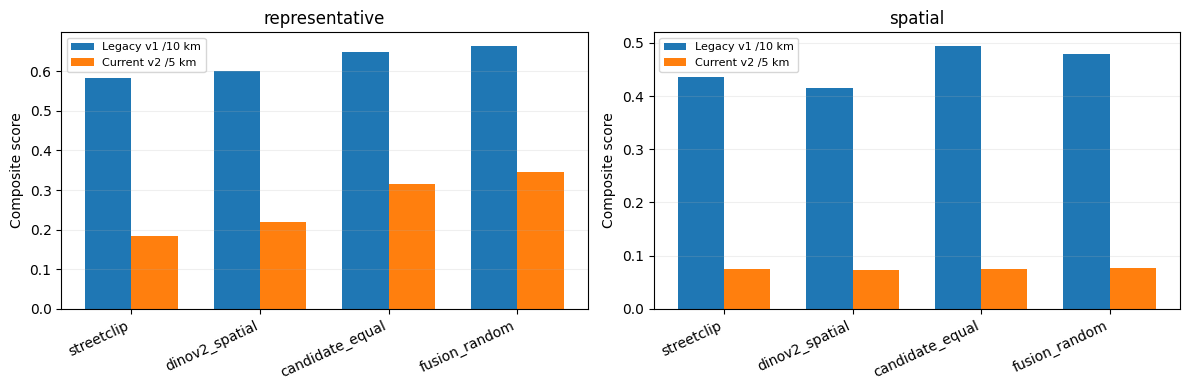

Current metric: mean_haversine_5km_v2 | Primary goal .80; stretch .90.
Current fusion passes representative-score + both-fold mean-distance guard: True
Second matched seed passes the same guard: True
Spatial GPS terms are zero for means >=5 km; use raw distance and its uncertainty for progress.
Historical public .60599 cannot be converted exactly from the composite alone; await the rescored Kaggle result.
Existing submission CSVs remain valid. Next experiment: bounded task-oriented place-recognition encoder pilot (SALAD).


In [27]:
# Cell 94 — Current-metric progress dashboard and revised priorities.
current_table=pd.DataFrame(CURRENT_METRIC_REPORT['records'])
display(current_table[['model','split','seed','legacy_score','score','gps_score','borough_macro_f1','mean_km','median_km','p90_km','fraction_over_5km','fraction_over_10km']])
display(pd.DataFrame(CURRENT_METRIC_REPORT['goals']))
display(pd.DataFrame(CURRENT_METRIC_REPORT['intervals']))
epoch_review=pd.DataFrame([{k:v for k,v in r.items() if k!='v2_epoch_summaries'} for r in CURRENT_METRIC_REPORT['epoch_review']])
display(epoch_review)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for split,axis in zip(('representative','spatial'),axes):
    subset=current_table[(current_table.split==split)&(current_table.seed==6643)&
                         current_table.model.isin(['streetclip','dinov2_spatial','candidate_equal','fusion_random'])]
    x=np.arange(len(subset))
    axis.bar(x-.18,subset.legacy_score,width=.36,label='Legacy v1 /10 km')
    axis.bar(x+.18,subset.score,width=.36,label='Current v2 /5 km')
    axis.set_xticks(x,subset.model,rotation=25,ha='right');axis.set_title(split);axis.set_ylabel('Composite score')
    axis.legend(fontsize=8);axis.grid(axis='y',alpha=.2)
fig.tight_layout();plt.show()
print('Current metric:',CURRENT_METRIC_VERSION,'| Primary goal .80; stretch .90.')
print('Current fusion passes representative-score + both-fold mean-distance guard:',CURRENT_METRIC_REPORT['current_candidate_passes_distance_guard'])
print('Second matched seed passes the same guard:',CURRENT_METRIC_REPORT['second_seed_passes_distance_guard'])
print('Spatial GPS terms are zero for means >=5 km; use raw distance and its uncertainty for progress.')
print('Historical public .60599 cannot be converted exactly from the composite alone; await the rescored Kaggle result.')
print('Existing submission CSVs remain valid. Next experiment: bounded task-oriented place-recognition encoder pilot (SALAD).')


## SALAD place-recognition pilot — 2026-11-18

The user approved implementing the next experiment with autonomous execution and
monitoring. Hypothesis: a DINOv2 encoder fine-tuned for place recognition plus SALAD
aggregation retrieves NYC training locations more precisely than our frozen global
StreetCLIP/DINOv2 controls. Use the pretrained image encoder/aggregator weights only;
no external image dataset, gallery, map, coordinates or test lookup is obtained.

**Predeclared pilot:** per original fold, borough-stratified1,024 training-gallery
locations and256 validation queries, seed6643, four compass views together. Compare
SALAD with existing StreetCLIP and DINOv2 CLS descriptors on identical IDs and a
fixed top5 soft-cosine-weighted geographic median / weighted borough vote decoder.
Report top1/5/32 recall at250m/500m/1km, current5-km composite, F1, mean/median/p90,
tails, runtime and resource use. A small-gallery score is not a full-fold estimate.
Also test one fixed reranking rule: .7 global +.3 symmetric region-match cosine on
top32 candidates, with the same decoder; do not sweep weights on validation.

**Pilot gate:** lower mean GPS error by at least.05km against BOTH matched frozen
controls on BOTH folds, and representative v2 composite no worse than those controls.
Expand extraction only after this gate; then compare on complete original folds
against full-gallery frozen controls and the selected supervised fusion. The pilot
does not authorize an automatic best-public-score claim or Kaggle upload.

Bounds: approved352-MB checkpoint download <=5minutes, benchmark/parity <=5minutes,
pilot extraction <=20 cumulative GPU minutes. Conditional full-cache completion
has a separate45-minute cumulative budget. Cache only descriptors and four pooled
regions per view with durable coverage/identity ledgers; never all decoded images.
MPS is the local accelerator, with8-GiB/recommended-memory guards and bounded batches.
No dependency installation or Lightning/xformers/CUDA requirement is introduced.

Architecture and weights: Izquierdo & Civera, CVPR2024,
[official SALAD](https://github.com/serizba/salad), pinned code revision
`6aede13a3f6c25750bf7fde10209c06cb73060bb`, official releasev1.0.0. The compatibility
implementation retains upstream attribution and license references; preserve the
archived license/source notices when packaging derived code. Only allowlisted source
text and the encoder checkpoint are fetched. Reference repository code is inspected,
not executed. Numerical checks compare original-parameter reference math with the
converted backbone/aggregation and CPU/MPS outputs before real feature extraction.


In [27]:
# Cell 96 — Official SALAD provenance and bounded weight-only download.
SALAD_COMMIT='6aede13a3f6c25750bf7fde10209c06cb73060bb'
SALAD_URL='https://github.com/serizba/salad/releases/download/v1.0.0/dino_salad.ckpt'
SALAD_WEIGHT_BYTES=352040378
SALAD_MODEL_HOME=ROOT/'outputs/models/salad_v1_6aede13a'
SALAD_HOME=ROOT/'outputs/salad'
SALAD_CONFIG={'seed':6643,'image_size':322,'pilot_gallery':1024,'pilot_queries':256,
              'benchmark_seconds':300,'pilot_gpu_seconds':1200,'full_gpu_seconds':2700,
              'max_driver_gib':8.,'rerank_weight':.3,'top_candidates':32,'decode_neighbors':5,
              'temperature':.05,'minimum_mean_improvement_km':.05,'metric_version':CURRENT_METRIC_VERSION}

def salad_prepare(allow_download=False):
    import urllib.request
    policy=json.loads((ROOT/'DATA_SOURCES.json').read_text())['pretrained_policy']
    require(policy.get('all_pretrained_image_encoders_allowed') is True,'Encoder-weight permission is missing.')
    path=SALAD_MODEL_HOME/'dino_salad.ckpt';manifest=SALAD_MODEL_HOME/'provenance.json'
    if manifest.exists():
        provenance=json.loads(manifest.read_text())
        require(path.stat().st_size==SALAD_WEIGHT_BYTES and sha256(path)==provenance['weights_sha256'],'SALAD checkpoint changed.')
        return path,provenance
    require(allow_download,'Enable the SALAD prepare stage to obtain the approved official checkpoint.')
    SALAD_MODEL_HOME.mkdir(parents=True,exist_ok=True)
    started=time.monotonic()
    if not path.exists():
        temporary=path.with_suffix('.partial')
        request=urllib.request.Request(SALAD_URL,headers={'User-Agent':'NYCGuessr-research/1.0'})
        with urllib.request.urlopen(request,timeout=30) as response,temporary.open('wb') as stream:
            size=0
            with tqdm(total=SALAD_WEIGHT_BYTES,unit='B',unit_scale=True,desc='Official SALAD checkpoint') as bar:
                while block:=response.read(1024*1024):
                    require(time.monotonic()-started<300,'Checkpoint download exceeded five minutes; partial preserved.')
                    size+=len(block);require(size<=SALAD_WEIGHT_BYTES,'Unexpected checkpoint payload size.')
                    stream.write(block);bar.update(len(block))
        require(temporary.stat().st_size==SALAD_WEIGHT_BYTES,'Incomplete SALAD checkpoint.')
        os.replace(temporary,path)
    require(path.stat().st_size==SALAD_WEIGHT_BYTES,'Unexpected official checkpoint size.')
    sources={}
    for name in ('LICENSE','README.md','hubconf.py','models/backbones/dinov2.py','models/aggregators/salad.py','eval.py'):
        url=f'https://raw.githubusercontent.com/serizba/salad/{SALAD_COMMIT}/{name}'
        with urllib.request.urlopen(url,timeout=20) as response:data=response.read(200000)
        require(len(data)<200000,'Upstream source-text size cap exceeded.')
        sources[name]={'url':url,'sha256':hashlib.sha256(data).hexdigest(),'text':data.decode('utf-8')}
    dino_json(SALAD_MODEL_HOME/'upstream_source.json',sources)
    state=torch.load(path,map_location='cpu',weights_only=True,mmap=True)
    require(isinstance(state,dict) and all(isinstance(v,torch.Tensor) for v in state.values()),'Checkpoint is not a plain safe state dictionary.')
    provenance={'model':'DINOv2-SALAD','upstream_commit':SALAD_COMMIT,'release':'v1.0.0','url':SALAD_URL,
                'weights_bytes':path.stat().st_size,'weights_sha256':sha256(path),'remote_release_digest':None,
                'checksum_basis':'Recorded from first official release download; no digest was supplied by release metadata.',
                'pretraining':'Public image encoder/aggregation pretrained on GSV-Cities; weights only, no dataset download.',
                'upstream_source':'outputs/models/salad_v1_6aede13a/upstream_source.json',
                'license_reference':f'https://github.com/serizba/salad/blob/{SALAD_COMMIT}/LICENSE',
                'state_keys':len(state),'download_seconds':time.monotonic()-started}
    dino_json(manifest,provenance)
    print('Safe checkpoint verified:',len(state),'tensor keys;',provenance['weights_sha256'])
    return path,provenance


In [7]:
# Cell 97 — SALAD checkpoint preparation; no external datasets or model fitting.
RUN_SALAD_PREPARE=os.environ.get('NYCGUESSR_SALAD_PREPARE','0')=='1'
if RUN_SALAD_PREPARE:
    SALAD_WEIGHT_PATH,SALAD_PROVENANCE=salad_prepare(allow_download=True)
else:
    print('SALAD download disabled by default.')


Official SALAD checkpoint:   0%|          | 0.00/352M [00:00<?, ?B/s]

Official SALAD checkpoint:   1%|          | 4.19M/352M [00:00<00:09, 37.5MB/s]

Official SALAD checkpoint:   3%|▎         | 9.44M/352M [00:00<00:07, 44.0MB/s]

Official SALAD checkpoint:   4%|▍         | 14.7M/352M [00:00<00:07, 44.1MB/s]

Official SALAD checkpoint:   6%|▌         | 19.9M/352M [00:00<00:08, 40.3MB/s]

Official SALAD checkpoint:   7%|▋         | 24.1M/352M [00:00<00:08, 38.5MB/s]

... (75 outputs left out)

Official SALAD checkpoint:  98%|█████████▊| 346M/352M [00:09<00:00, 37.9MB/s]

Official SALAD checkpoint:  99%|█████████▉| 350M/352M [00:09<00:00, 38.2MB/s]

Official SALAD checkpoint: 100%|██████████| 352M/352M [00:09<00:00, 38.4MB/s]

Safe checkpoint verified: 188 tensor keys; 6b3f1720954293e83da6966c5cfcfc6713200d7fefadcca76fc51aeb80b3cada


In [28]:
# Cell 98 — Native PyTorch compatibility model; no Lightning/xformers/remote code.
# Architecture/weights: Izquierdo & Civera, CVPR2024; pinned SALAD source/license
# archived by salad_prepare. Keep attribution and upstream notices when distributing.
class SaladScale(nn.Module):
    def __init__(self,channels):
        super().__init__();self.gamma=nn.Parameter(torch.ones(channels))
    def forward(self,x):return x*self.gamma

class SaladAttention(nn.Module):
    def __init__(self,channels=768,heads=12):
        super().__init__();self.heads=heads;self.qkv=nn.Linear(channels,channels*3);self.proj=nn.Linear(channels,channels)
    def forward(self,x):
        batch,tokens,channels=x.shape
        q,k,v=self.qkv(x).reshape(batch,tokens,3,self.heads,channels//self.heads).permute(2,0,3,1,4).unbind(0)
        hidden=F.scaled_dot_product_attention(q,k,v,dropout_p=0.)
        return self.proj(hidden.transpose(1,2).reshape(batch,tokens,channels))

class SaladMlp(nn.Module):
    def __init__(self,channels):
        super().__init__();self.fc1=nn.Linear(channels,4*channels);self.fc2=nn.Linear(4*channels,channels)
    def forward(self,x):return self.fc2(F.gelu(self.fc1(x)))

class SaladBlock(nn.Module):
    def __init__(self,channels=768,heads=12):
        super().__init__();self.norm1=nn.LayerNorm(channels,eps=1e-6);self.attn=SaladAttention(channels,heads)
        self.ls1=SaladScale(channels);self.norm2=nn.LayerNorm(channels,eps=1e-6);self.mlp=SaladMlp(channels);self.ls2=SaladScale(channels)
    def forward(self,x):
        x=x+self.ls1(self.attn(self.norm1(x)))
        return x+self.ls2(self.mlp(self.norm2(x)))

def salad_position(embedding,grid,dtype):
    original=int((embedding.shape[1]-1)**.5)
    if grid==original:return embedding.to(dtype)
    # Preserve original DINOv2's +.1 interpolation offset, not a different HF recipe.
    patches=embedding[:,1:].float().reshape(1,original,original,-1).permute(0,3,1,2)
    resized=F.interpolate(patches,scale_factor=((grid+.1)/original,(grid+.1)/original),mode='bicubic',align_corners=False)
    require(resized.shape[-2:]==(grid,grid),'Unexpected positional interpolation grid.')
    return torch.cat([embedding[:,:1].float(),resized.permute(0,2,3,1).reshape(1,grid*grid,-1)],1).to(dtype)

class SaladViT(nn.Module):
    def __init__(self):
        super().__init__();self.cls_token=nn.Parameter(torch.zeros(1,1,768));self.pos_embed=nn.Parameter(torch.zeros(1,1370,768))
        self.mask_token=nn.Parameter(torch.zeros(1,768));self.patch_embed=nn.Module();self.patch_embed.proj=nn.Conv2d(3,768,14,14)
        self.blocks=nn.ModuleList([SaladBlock() for _ in range(12)]);self.norm=nn.LayerNorm(768,eps=1e-6)
    def forward(self,pixels):
        grid=pixels.shape[-1]//14
        patches=self.patch_embed.proj(pixels).flatten(2).transpose(1,2)
        tokens=torch.cat([self.cls_token.expand(len(pixels),-1,-1),patches],1)
        tokens=tokens+salad_position(self.pos_embed,grid,tokens.dtype)
        for block in self.blocks:tokens=block(tokens)
        return self.norm(tokens)

def salad_transport(scores,dustbin,iterations=3):
    """Original SALAD dustbin transport; stable FP32, no batch-dimension squeeze."""
    scores=scores.float();batch,clusters,patches=scores.shape
    require(1<=iterations<=20 and patches>clusters,'SALAD transport dimensions/iteration cap.')
    augmented=torch.cat([scores,dustbin.float().expand(batch,1,patches)],1)
    normalizer=-float(np.log(patches+clusters))
    row=torch.full((batch,clusters+1),normalizer,device=scores.device)
    row[:,-1]+=float(np.log(patches-clusters))
    column=torch.full((batch,patches),normalizer,device=scores.device)
    u=torch.zeros_like(row);v=torch.zeros_like(column)
    for _ in range(iterations):
        u=row-torch.logsumexp(augmented+v[:,None,:],dim=2)
        v=column-torch.logsumexp(augmented+u[:,:,None],dim=1)
    return (augmented+u[:,:,None]+v[:,None,:]-normalizer).exp()[:,:clusters]

class SaladAggregation(nn.Module):
    def __init__(self,channels=768,clusters=64,cluster_dim=128,token_dim=256):
        super().__init__();self.dust_bin=nn.Parameter(torch.tensor(1.))
        self.token_features=nn.Sequential(nn.Linear(channels,512),nn.ReLU(),nn.Linear(512,token_dim))
        self.cluster_features=nn.Sequential(nn.Conv2d(channels,512,1),nn.Dropout(.3),nn.ReLU(),nn.Conv2d(512,cluster_dim,1))
        self.score=nn.Sequential(nn.Conv2d(channels,512,1),nn.Dropout(.3),nn.ReLU(),nn.Conv2d(512,clusters,1))
    def forward(self,hidden,grid):
        patches=hidden[:,1:].transpose(1,2).reshape(len(hidden),-1,grid,grid)
        local=self.cluster_features(patches).flatten(2).float()
        probability=salad_transport(self.score(patches).flatten(2),self.dust_bin)
        # Matrix multiplication replaces the upstream large repeated 4D product.
        aggregated=torch.bmm(local,probability.transpose(1,2))
        token=self.token_features(hidden[:,0]).float()
        descriptor=torch.cat([F.normalize(token,dim=1),F.normalize(aggregated,dim=1).flatten(1)],1)
        return F.normalize(descriptor,dim=1)

def salad_regions(hidden,grid):
    """Four disjoint regions; odd23-patch grids split11/12, without overlap."""
    patches=hidden[:,1:].float().reshape(len(hidden),grid,grid,-1)
    half=grid//2
    regions=[patches[:,a:b,c:d].mean((1,2)) for a,b in [(0,half),(half,grid)] for c,d in [(0,half),(half,grid)]]
    return F.normalize(torch.stack(regions,1),dim=-1)

class SaladEncoder(nn.Module):
    def __init__(self):
        super().__init__();self.backbone=nn.Module();self.backbone.model=SaladViT();self.aggregator=SaladAggregation()
    def forward(self,pixels):
        grid=pixels.shape[-1]//14;hidden=self.backbone.model(pixels)
        return self.aggregator(hidden,grid),salad_regions(hidden,grid)

def salad_load(device,precision='float32'):
    path,provenance=salad_prepare()
    state=torch.load(path,map_location='cpu',weights_only=True,mmap=True)
    model=SaladEncoder();model.load_state_dict(state,strict=True)
    require(len(state)==188 and sum(p.numel() for p in model.parameters())<100000000,'Unexpected SALAD checkpoint architecture.')
    return model.eval().requires_grad_(False).to(device=device,dtype=getattr(torch,precision))

def salad_image(path,expected_sha,size=322):
    raw=Path(path).read_bytes();require(hashlib.sha256(raw).hexdigest()==expected_sha,f'Official image changed: {path}')
    with Image.open(io.BytesIO(raw)) as source:
        image=source.convert('RGB').resize((size,size),Image.Resampling.BILINEAR)
        array=np.asarray(image,dtype=np.float32)/255.
    array=(array-np.array([.485,.456,.406],np.float32))/np.array([.229,.224,.225],np.float32)
    return np.ascontiguousarray(array.transpose(2,0,1))

def salad_batches(frame,positions,batch_size,workers,manifest):
    require(1<=batch_size<=16 and workers in (0,2,4),'Loader bounds.')
    def load(index,pool=None):
        args=[(ROOT/'Data/train'/frame.iloc[i][f'image_{direction}'],manifest[f"Data/train/{frame.iloc[i][f'image_{direction}']}"],322)
              for i in index for direction in DIRECTIONS]
        if pool is None:return np.stack([salad_image(*a) for a in args])
        return [pool.submit(salad_image,*a) for a in args]
    chunks=[positions[start:start+batch_size] for start in range(0,len(positions),batch_size)]
    if workers==0:
        for index in chunks:yield index,load(index)
    else:
        with ThreadPoolExecutor(max_workers=workers) as pool:
            pending=None
            for k,index in enumerate(chunks):
                if pending is None:pending=load(index,pool)
                pixels=np.stack([p.result() for p in pending])
                pending=load(chunks[k+1],pool) if k+1<len(chunks) else None
                yield index,pixels

@torch.inference_mode()
def salad_encode(model,pixels,device):
    x=torch.as_tensor(pixels,device=device,dtype=next(model.parameters()).dtype)
    global_features,regions=model(x)
    require(bool(torch.isfinite(global_features).all() and torch.isfinite(regions).all()),'Nonfinite SALAD descriptors.')
    return global_features.float().cpu().numpy(),regions.float().cpu().numpy()

@torch.inference_mode()
def salad_original_reference(model,pixels):
    """Independent original-parameter CPU math; explicit attention and repeated OT sum.

    Use only two images. This numerical check does not load/execute upstream code.
    """
    require(len(pixels)<=2 and pixels.device.type=='cpu','Reference CPU/two-image bound.')
    state=model.state_dict();prefix='backbone.model.'
    x=F.conv2d(pixels,state[prefix+'patch_embed.proj.weight'],state[prefix+'patch_embed.proj.bias'],stride=14).flatten(2).transpose(1,2)
    x=torch.cat([state[prefix+'cls_token'].expand(len(x),-1,-1),x],1);grid=pixels.shape[-1]//14
    position=state[prefix+'pos_embed'];patch_position=position[:,1:].reshape(1,37,37,768).permute(0,3,1,2)
    patch_position=F.interpolate(patch_position,scale_factor=((grid+.1)/37,(grid+.1)/37),mode='bicubic',align_corners=False)
    x=x+torch.cat([position[:,:1],patch_position.permute(0,2,3,1).reshape(1,grid*grid,768)],1)
    for i in range(12):
        p=prefix+f'blocks.{i}.'
        normalized=F.layer_norm(x,(768,),state[p+'norm1.weight'],state[p+'norm1.bias'],1e-6)
        qkv=F.linear(normalized,state[p+'attn.qkv.weight'],state[p+'attn.qkv.bias']).reshape(len(x),len(x[0]),3,12,64)
        q,k,v=qkv.permute(2,0,3,1,4).unbind(0)
        attended=(((q*.125)@k.transpose(-1,-2)).softmax(-1)@v).transpose(1,2).reshape_as(x)
        x=x+F.linear(attended,state[p+'attn.proj.weight'],state[p+'attn.proj.bias'])*state[p+'ls1.gamma']
        normalized=F.layer_norm(x,(768,),state[p+'norm2.weight'],state[p+'norm2.bias'],1e-6)
        x=x+F.linear(F.gelu(F.linear(normalized,state[p+'mlp.fc1.weight'],state[p+'mlp.fc1.bias'])),state[p+'mlp.fc2.weight'],state[p+'mlp.fc2.bias'])*state[p+'ls2.gamma']
    x=F.layer_norm(x,(768,),state[prefix+'norm.weight'],state[prefix+'norm.bias'],1e-6)
    patches=x[:,1:].transpose(1,2).reshape(len(x),768,grid,grid);agg=model.aggregator
    features=agg.cluster_features(patches).flatten(2);scores=agg.score(patches).flatten(2)
    batch,clusters,count=scores.shape;normalizer=-float(np.log(count+clusters))
    matrix=torch.cat([scores,agg.dust_bin.expand(batch,1,count)],1)
    row=torch.full((batch,clusters+1),normalizer);row[:,-1]+=float(np.log(count-clusters))
    col=torch.full((batch,count),normalizer);u=torch.zeros_like(row);v=torch.zeros_like(col)
    for _ in range(3):
        u=row-torch.logsumexp(matrix+v.unsqueeze(1),2)
        v=col-torch.logsumexp(matrix+u.unsqueeze(2),1)
    mass=(matrix+u.unsqueeze(2)+v.unsqueeze(1)-normalizer).exp()[:,:clusters]
    local=(features[:,:,None,:]*mass[:,None,:,:]).sum(-1)
    token=F.normalize(agg.token_features(x[:,0]),dim=-1)
    output=F.normalize(torch.cat([token,F.normalize(local,dim=1).flatten(1)],1),dim=-1)
    return output,salad_regions(x,grid)


In [29]:
# Cell 99 — Correctness checks and bounded MPS precision/throughput benchmark.
def salad_identity(provenance,precision):
    return {'model':'DINOv2-SALAD','weights_sha256':provenance['weights_sha256'],'upstream_commit':SALAD_COMMIT,
            'image_size':322,'interpolation':'bilinear_full_image','position_interpolation_offset':.1,
            'precision':precision,'transport_precision':'float32','torch':str(torch.__version__),'pillow':pillow_version,
            'source':dino_definitions_hash(['SaladEncoder','SaladViT','SaladBlock','SaladAttention','SaladMlp','SaladScale',
                'SaladAggregation','salad_transport','salad_position','salad_regions','salad_image','salad_encode','salad_load'])}

def salad_benchmark():
    directory=SALAD_HOME;directory.mkdir(parents=True,exist_ok=True)
    path,provenance=salad_prepare();device=dino_device()
    if (directory/'benchmark.json').exists():
        report=json.loads((directory/'benchmark.json').read_text())
        require(report['identity']==salad_identity(provenance,report['precision']),'Benchmark source/weight identity drift.')
        return report
    seed_everything();frame,_=load_data(ROOT)
    manifest={r['path']:r['sha256'] for r in map(json.loads,(ROOT/'outputs/input_manifest.jsonl').read_text().splitlines())}
    sample=frame.sample(n=64,random_state=6643).reset_index(drop=True)
    pixels=next(salad_batches(sample,np.arange(1),1,0,manifest))[1][:2]
    model=salad_load(torch.device('cpu'));started=time.monotonic()
    with torch.inference_mode():
        reference,ref_regions=salad_original_reference(model,torch.from_numpy(pixels))
        standard,regions=salad_encode(model,pixels,torch.device('cpu'))
    np.testing.assert_allclose(standard,reference.numpy(),atol=3e-5,rtol=3e-4)
    np.testing.assert_allclose(regions,ref_regions.numpy(),atol=3e-5,rtol=3e-4)
    model=model.to(device)
    gpu,gpu_regions=salad_encode(model,pixels,device)
    def difference(actual,expected):
        cosine=(actual*expected).sum(-1)/np.maximum(np.linalg.norm(actual,axis=-1)*np.linalg.norm(expected,axis=-1),1e-9)
        return {'minimum_cosine':float(cosine.min()),'relative_rms':float(np.linalg.norm(actual-expected)/max(np.linalg.norm(expected),1e-9))}
    parity={'cpu_optimized_vs_original':difference(standard,reference.numpy()),'mps_fp32_vs_cpu':difference(gpu,standard),
            'mps_regions_vs_cpu':difference(gpu_regions,regions)}
    require(all(v['minimum_cosine']>.999 and v['relative_rms']<.01 for v in parity.values()),'SALAD CPU/MPS/reference parity failed.')
    model.half();precision='float32'
    try:
        half,half_regions=salad_encode(model,pixels,device)
        parity['mps_half_vs_fp32']=difference(half,gpu);parity['mps_half_regions_vs_fp32']=difference(half_regions,gpu_regions)
        if all(parity[k]['minimum_cosine']>.995 and parity[k]['relative_rms']<.03 for k in ('mps_half_vs_fp32','mps_half_regions_vs_fp32')):precision='float16'
    except (RuntimeError,ValueError) as error:parity['mps_half_error']=str(error)[:300]
    if precision=='float32':
        del model;dino_release(device);model=salad_load(device,'float32')
    trials=[]
    try:
        for batch_size in (1,2,4,8):
            if time.monotonic()-started>SALAD_CONFIG['benchmark_seconds']:break
            for workers in (0,4):
                try:
                    warm=next(salad_batches(sample,np.arange(batch_size),batch_size,workers,manifest))[1]
                    salad_encode(model,warm,device);dino_sync(device)
                    begin=time.monotonic();peak=0
                    for _,images in salad_batches(sample,np.arange(batch_size*2),batch_size,workers,manifest):
                        salad_encode(model,images,device);peak=max(peak,dino_memory_guard(device))
                    dino_sync(device);seconds=time.monotonic()-begin
                    trials.append({'batch_locations':batch_size,'loader_threads':workers,'images_per_second':8*batch_size/seconds,'driver_bytes':peak,'status':'ok'})
                except (RuntimeError,ValueError) as error:
                    if 'memory' not in str(error).lower() and 'allocation cap' not in str(error).lower():raise
                    trials.append({'batch_locations':batch_size,'loader_threads':workers,'status':'memory_limit'});dino_release(device)
                    break
        good=[r for r in trials if r['status']=='ok'];require(bool(good),'No safe SALAD benchmark batch.')
        best=max(good,key=lambda r:r['images_per_second'])
        report={'identity':salad_identity(provenance,precision),'precision':precision,'parity':parity,'trials':trials,'best':best,
                'device':str(device),'elapsed_seconds':time.monotonic()-started,'estimated_full_train_minutes':11864*4/best['images_per_second']/60}
        require(report['elapsed_seconds']<=300,'Benchmark exceeded its time bound.')
        dino_json(directory/'benchmark.json',report);display(pd.DataFrame(trials));display(pd.DataFrame(parity).T)
        print('Chosen:',precision,best,'estimated full train minutes',round(report['estimated_full_train_minutes'],1))
        return report
    finally:
        del model;dino_release(device)

class SaladTests(unittest.TestCase):
    def test_transport_batch1_and_matrix_aggregation(self):
        torch.manual_seed(4)
        for batch in (1,2):
            scores=torch.randn(batch,3,9);p=salad_transport(scores,torch.tensor(1.))
            self.assertEqual(p.shape,(batch,3,9));self.assertTrue(bool(torch.isfinite(p).all()))
            features=torch.randn(batch,5,9)
            actual=torch.bmm(features,p.transpose(1,2));expected=(features[:,:,None,:]*p[:,None,:,:]).sum(-1)
            torch.testing.assert_close(actual,expected,atol=1e-6,rtol=1e-5)
        with self.assertRaises(ValueError):salad_transport(torch.randn(1,9,3),torch.tensor(1.))

    def test_odd_patch_grid_regions_cover_disjoint_positions(self):
        hidden=torch.arange(1+23*23,dtype=torch.float32).reshape(1,-1,1).repeat(1,1,2)
        result=salad_regions(hidden,23)
        self.assertEqual(result.shape,(1,4,2));self.assertTrue(bool(torch.isfinite(result).all()))
        np.testing.assert_allclose(np.linalg.norm(result.numpy(),axis=-1),1.,atol=1e-6)

    def test_preprocessing_matches_upstream_torchvision(self):
        import torchvision.transforms as T
        with tempfile.TemporaryDirectory() as temporary:
            path=Path(temporary)/'image.jpg';Image.new('RGB',(640,640),(51,102,153)).save(path)
            actual=salad_image(path,sha256(path))
            transform=T.Compose([T.Resize((322,322),interpolation=T.InterpolationMode.BILINEAR),T.ToTensor(),T.Normalize([.485,.456,.406],[.229,.224,.225])])
            with Image.open(path) as image:expected=transform(image.convert('RGB')).numpy()
            np.testing.assert_allclose(actual,expected,rtol=0,atol=1e-6)
            with self.assertRaises(ValueError):salad_image(path,'wrong')

salad_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(SaladTests))
require(salad_tests.wasSuccessful(),'Resolve SALAD compatibility tests before extraction.')


test_odd_patch_grid_regions_cover_disjoint_positions (__main__.SaladTests.test_odd_patch_grid_regions_cover_disjoint_positions) ... 

ok


test_preprocessing_matches_upstream_torchvision (__main__.SaladTests.test_preprocessing_matches_upstream_torchvision) ... 

ok


test_transport_batch1_and_matrix_aggregation (__main__.SaladTests.test_transport_batch1_and_matrix_aggregation) ... 

ok


----------------------------------------------------------------------
Ran 3 tests in 0.774s

OK


In [30]:
# Cell 100 — Explicit SALAD benchmark/parity action; defaults off.
RUN_SALAD_BENCHMARK=os.environ.get('NYCGUESSR_SALAD_BENCHMARK','0')=='1'
if RUN_SALAD_BENCHMARK:
    SALAD_BENCHMARK=salad_benchmark()
elif (SALAD_HOME/'benchmark.json').exists():
    SALAD_BENCHMARK=json.loads((SALAD_HOME/'benchmark.json').read_text())
    print('Saved SALAD benchmark loaded.')
else:print('SALAD real-weight benchmark disabled.')


Saved SALAD benchmark loaded.


In [31]:
# Cell 101 — Fixed pilot IDs, immutable features and resumable bounded extraction.
def salad_plan():
    frame,_=load_data(ROOT);splits=json.loads((ROOT/'outputs/splits.json').read_text())
    require(sha256(ROOT/'outputs/splits.json')=='01edd72611d17b928f7d5b835e2ee26c8ec2848652b3065ced9abc06102a509d','Original folds changed.')
    plan={'seed':6643,'split_sha256':sha256(ROOT/'outputs/splits.json'),'folds':{}}
    for name,split in splits['splits'].items():
        gallery=training_subset(frame.loc[split['train_ids']],limit=1024,seed=6643).sample_id.tolist()
        query=training_subset(frame.loc[split['validation_ids']],limit=256,seed=6643).sample_id.tolist()
        require(set(gallery)<=set(split['train_ids']) and set(query)<=set(split['validation_ids']) and not set(gallery)&set(query),'Pilot leaks original folds.')
        plan['folds'][name]={'train_ids':gallery,'validation_ids':query}
    plan['union_ids']=sorted(set(i for split in plan['folds'].values() for ids in split.values() for i in ids))
    path=SALAD_HOME/'pilot_ids.json'
    if path.exists():require(json.loads(path.read_text())==plan,'Pilot IDs changed; do not silently reselect.')
    else:dino_json(path,plan)
    return frame,splits,plan

def salad_cache_paths(frame,benchmark):
    spec={'encoder':benchmark['identity'],'sample_ids':frame.sample_id.astype(int).tolist(),
          'data_fingerprint':data_fingerprint(ROOT),'global_shape':[len(frame),4,8448],
          'region_shape':[len(frame),4,4,768],'dtype':'float16','regions':'disjoint_2x2_11_12_patch_bins'}
    key=dino_hash(spec)[:16];directory=SALAD_HOME/'features';directory.mkdir(parents=True,exist_ok=True)
    return directory/f'global_{key}.npy',directory/f'regions_{key}.npy',directory/f'coverage_{key}.json',spec

def salad_open_cache(frame,benchmark,required_ids=None):
    global_path,region_path,ledger_path,spec=salad_cache_paths(frame,benchmark)
    require(ledger_path.exists() and global_path.exists() and region_path.exists(),'SALAD cache not yet created.')
    ledger=json.loads(ledger_path.read_text());require(ledger['spec']==spec,'Cache producer/data identity changed.')
    require(len(ledger['covered'])==len(frame),'Cache coverage length mismatch.')
    positions=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    index=np.arange(len(frame)) if required_ids is None else positions.loc[required_ids].to_numpy()
    require(bool(np.asarray(ledger['covered'])[index].all()),'Required SALAD rows are incomplete.')
    global_features=np.load(global_path,mmap_mode='r');regions=np.load(region_path,mmap_mode='r')
    require(list(global_features.shape)==spec['global_shape'] and list(regions.shape)==spec['region_shape']
            and global_features.dtype==regions.dtype==np.float16,'Cache dimensions/dtype mismatch.')
    for start in range(0,len(index),64):
        for values in (global_features[index[start:start+64]],regions[index[start:start+64]]):
            require(bool(np.isfinite(values).all()),'Cached descriptors are nonfinite.')
            require(bool(np.allclose(np.linalg.norm(values.astype(np.float32),axis=-1),1.,atol=.01)),'Cached descriptors are not unit-normalized.')
    if ledger.get('complete'):
        require(sha256(global_path)==ledger['global_sha256'] and sha256(region_path)==ledger['region_sha256'],'Complete SALAD cache checksum changed.')
    return global_features,regions,ledger

def salad_extract(frame,target_ids,phase):
    require(phase in ('pilot','full'),'Unknown bounded extraction phase.')
    benchmark=json.loads((SALAD_HOME/'benchmark.json').read_text());_,provenance=salad_prepare()
    require(benchmark['identity']==salad_identity(provenance,benchmark['precision']),'Benchmark producer changed.')
    global_path,region_path,ledger_path,spec=salad_cache_paths(frame,benchmark)
    if ledger_path.exists():
        ledger=json.loads(ledger_path.read_text());require(ledger['spec']==spec,'Partial cache identity changed.')
        global_features=np.load(global_path,mmap_mode='r+');regions=np.load(region_path,mmap_mode='r+')
    else:
        require(not global_path.exists() and not region_path.exists(),'Orphan cache data requires inspection.')
        global_features=np.lib.format.open_memmap(global_path,mode='w+',dtype=np.float16,shape=tuple(spec['global_shape']))
        regions=np.lib.format.open_memmap(region_path,mode='w+',dtype=np.float16,shape=tuple(spec['region_shape']))
        ledger={'spec':spec,'covered':[False]*len(frame),'complete':False,'sampled_peak_driver_bytes':0}
        dino_json(ledger_path,ledger)
    positions=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    target=positions.loc[list(target_ids)].to_numpy();require(len(set(target))==len(target),'Duplicate extraction targets.')
    missing=target[~np.asarray(ledger['covered'])[target]]
    if not len(missing):
        del global_features,regions
        return salad_open_cache(frame,benchmark,target_ids)
    budget_path=SALAD_HOME/f'{phase}_budget.json'
    budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'spec_sha256':dino_hash(spec),'seconds':0.,'phase':phase}
    require(budget['spec_sha256']==dino_hash(spec),'Phase budget belongs to a different producer.')
    used=budget['seconds'];limit=SALAD_CONFIG[phase+'_gpu_seconds'];require(used<limit,'Phase budget exhausted; review before extending.')
    manifest_path=ROOT/'outputs/input_manifest.jsonl'
    require(sha256(manifest_path)=='e878c8ce10ce2032c4790184e0344fbf6bd95a3ad206fe45f7a8b39671610d7a','Original raw manifest changed.')
    manifest={r['path']:r['sha256'] for r in map(json.loads,manifest_path.read_text().splitlines())}
    device=dino_device();model=salad_load(device,benchmark['precision'])
    batch=benchmark['best']['batch_locations'];workers=benchmark['best']['loader_threads'];started=time.monotonic()
    status='running';processed=0
    def commit():
        global_features.flush();regions.flush()
        budget['seconds']=used+time.monotonic()-started;budget['status']=status
        dino_json(ledger_path,ledger);dino_json(budget_path,budget)
    try:
        with tqdm(total=len(target),initial=len(target)-len(missing),desc=f'SALAD {phase}',unit='location') as bar:
            for index,pixels in salad_batches(frame,missing,batch,workers,manifest):
                if used+time.monotonic()-started>=limit:status='budget_paused';return None
                output,local=salad_encode(model,pixels,device)
                global_features[index]=output.reshape(len(index),4,8448).astype(np.float16)
                regions[index]=local.reshape(len(index),4,4,768).astype(np.float16)
                for i in index:ledger['covered'][int(i)]=True
                processed+=len(index);bar.update(len(index))
                ledger['sampled_peak_driver_bytes']=max(ledger['sampled_peak_driver_bytes'],dino_memory_guard(device))
                if processed%16<batch:commit()
        status='complete'
        if all(ledger['covered']):
            global_features.flush();regions.flush()
            ledger.update(complete=True,global_sha256=sha256(global_path),region_sha256=sha256(region_path))
    except BaseException as error:
        status='interrupted' if isinstance(error,KeyboardInterrupt) else 'failed';budget['error']=str(error)[:500]
        raise
    finally:
        commit();del model,global_features,regions;dino_release(device)
    print(f'{phase}: {processed} new locations; {budget["seconds"]:.2f} cumulative seconds.')
    return salad_open_cache(frame,benchmark,target_ids)


In [32]:
# Cell 102 — Same-compass retrieval, fixed decoder and patch-consistency reranking.
def salad_region_scores(query_regions,reference_regions):
    """Symmetric best regional matches within each corresponding compass view."""
    a=np.asarray(query_regions,np.float32);b=np.asarray(reference_regions,np.float32)
    require(a.ndim==4 and b.ndim==5 and a.shape[1:]==b.shape[2:] and len(a)==len(b),'Region query/candidate alignment.')
    a/=np.maximum(np.linalg.norm(a,axis=-1,keepdims=True),1e-8)
    b/=np.maximum(np.linalg.norm(b,axis=-1,keepdims=True),1e-8)
    matches=np.einsum('qvrc,qkvsc->qkvrs',a,b,optimize=True)
    return .5*(matches.max(-1).mean((-1,-2))+matches.max(-2).mean((-1,-2)))

def salad_decode(training,ids,neighbors,similarity):
    require(not set(ids)&set(training.sample_id),'Reference/query ID leakage.')
    require(neighbors.shape==similarity.shape and len(neighbors)==len(ids),'Decoder alignment.')
    index=neighbors[:,:5];scores=similarity[:,:5]
    weights=np.exp((scores-scores.max(1,keepdims=True))/.05);weights/=weights.sum(1,keepdims=True)
    xy,origin,scales=coordinates_xy(training[['latitude','longitude']])
    predicted=bounded_geometric_median(xy[index],weights)/scales+origin
    labels=np.array([BOROUGHS.index(b) for b in training.borough])
    votes=np.stack([((labels[index]==b)*weights).sum(1) for b in range(5)],1).argmax(1)
    return pd.DataFrame({'sample_id':np.asarray(ids),'borough':np.asarray(BOROUGHS)[votes],
                         'latitude':predicted[:,0],'longitude':predicted[:,1]})

@torch.inference_mode()
def salad_retrieval(training,query,gallery,query_features,gallery_regions=None,query_regions=None,rerank=False):
    require(not set(training.sample_id)&set(query.sample_id),'Retrieval split leakage.')
    require(gallery.shape[0]==len(training) and query_features.shape[0]==len(query)
            and gallery.shape[1:]==query_features.shape[1:] and gallery.shape[1]==4,'Four-view retrieval shape/ID mismatch.')
    device=dino_device()
    bank=torch.as_tensor(np.array(gallery,dtype=np.float32,copy=True),device=device)
    bank=F.normalize(bank,dim=-1).reshape(len(bank),-1)/2.
    predictions=[];rows=[];peak=dino_memory_guard(device)
    try:
        for start in range(0,len(query),32):
            truth=query.iloc[start:start+32]
            features=torch.as_tensor(np.array(query_features[start:start+32],dtype=np.float32,copy=True),device=device)
            vectors=F.normalize(features,dim=-1).reshape(len(features),-1)/2.
            similarity=(vectors@bank.T).cpu().numpy()
            neighbors=np.argsort(-similarity,axis=1,kind='stable')[:,:min(32,len(training))]
            scores=np.take_along_axis(similarity,neighbors,1)
            if rerank:
                require(gallery_regions is not None and query_regions is not None,'Reranking needs matching region descriptors.')
                region=salad_region_scores(np.array(query_regions[start:start+32],copy=True),np.array(gallery_regions[neighbors],copy=True))
                scores=.7*scores+.3*region
                order=np.argsort(-scores,axis=1,kind='stable');neighbors=np.take_along_axis(neighbors,order,1);scores=np.take_along_axis(scores,order,1)
            prediction=salad_decode(training,truth.sample_id,neighbors,scores);predictions.append(prediction)
            actual=truth[['latitude','longitude']].to_numpy();candidates=training[['latitude','longitude']].to_numpy()[neighbors]
            distance=haversine_km(np.repeat(actual,candidates.shape[1],axis=0),candidates.reshape(-1,2)).reshape(len(truth),-1)
            error=haversine_km(actual,prediction[['latitude','longitude']])
            for j,row in enumerate(truth.itertuples()):
                item={'sample_id':int(row.sample_id),'borough':row.borough,'error_km':float(error[j])}
                for k in (1,5,32):item[f'top{k}_best_km']=float(distance[j,:k].min())
                rows.append(item)
            peak=max(peak,dino_memory_guard(device))
        prediction=pd.concat(predictions,ignore_index=True);per_query=pd.DataFrame(rows)
        metrics=score_current_predictions(query,prediction)
        for k in (1,5,32):
            for radius in (.25,.5,1.):metrics[f'recall_top{k}_{radius}km']=float((per_query[f'top{k}_best_km']<=radius).mean())
        for limit in (5,10,20):metrics[f'fraction_over_{limit}km']=float((per_query.error_km>limit).mean())
        metrics['sampled_peak_driver_bytes']=peak
        return prediction,metrics,per_query
    finally:
        del bank;dino_release(device)

def salad_evaluate(frame,splits,plan,global_features,regions,scope):
    require(scope in ('pilot','full'),'Unknown comparison scope.')
    require(CURRENT_METRIC_VERSION==SALAD_CONFIG['metric_version']=='mean_haversine_5km_v2','New retrieval evaluation must use v2.')
    street_path=ROOT/'outputs/features/streetclip_train_23f1be61d2b2b2cd.npy'
    dino_path=ROOT/'outputs/dinov2/features/train_51ac09b98e135c24.npy'
    require(sha256(street_path)=='b9be80acd9d389f34b558321403d9f4d5ef4e54e100f31800d05426f7ae2f2e8','StreetCLIP control cache changed.')
    require(sha256(dino_path)=='a28d92f3db2d5205ed1ecc20e398dfc1e34ceba89493ac7affd751dd1346f370','DINO control cache changed.')
    street=np.load(street_path,mmap_mode='r');dino=np.load(dino_path,mmap_mode='r')
    folds=plan['folds'] if scope=='pilot' else splits['splits']
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id);records=[]
    directory=SALAD_HOME/scope;directory.mkdir(parents=True,exist_ok=True)
    sources={'config':SALAD_CONFIG,'scope':scope,'folds':folds,'metric_version':CURRENT_METRIC_VERSION,
             'benchmark':json.loads((SALAD_HOME/'benchmark.json').read_text())['identity'],
             'source':dino_definitions_hash(['salad_decode','salad_region_scores','salad_retrieval','salad_evaluate'])}
    result_path=directory/'comparison.json'
    if result_path.exists():
        saved=json.loads(result_path.read_text());require(saved['identity']==sources,'Comparison identity changed.');return saved
    for split_name,split in folds.items():
        training=frame.loc[split['train_ids']];query=frame.loc[split['validation_ids']]
        tr=position.loc[training.sample_id].to_numpy();va=position.loc[query.sample_id].to_numpy()
        coverage=nearest_bank_distance(training,query)
        for model in ('streetclip','dinov2_cls','salad','salad_rerank'):
            if model=='streetclip':gallery=np.array(street[tr],copy=True);queries=np.array(street[va],copy=True)
            elif model=='dinov2_cls':gallery=np.array(dino[tr,:,0],copy=True);queries=np.array(dino[va,:,0],copy=True)
            else:gallery=np.array(global_features[tr],copy=True);queries=np.array(global_features[va],copy=True)
            started=time.monotonic()
            prediction,metrics,rows=salad_retrieval(training,query,gallery,queries,
                    np.array(regions[tr],copy=True) if model=='salad_rerank' else None,
                    np.array(regions[va],copy=True) if model=='salad_rerank' else None,rerank=model=='salad_rerank')
            path=directory/f'{model}_{split_name}.csv';prediction.to_csv(path,index=False)
            rows.to_csv(directory/f'{model}_{split_name}_queries.csv',index=False)
            record={'model':model,'split':split_name,'scope':scope,'training_locations':len(training),'validation_locations':len(query),
                    'prediction':str(path.relative_to(ROOT)),'prediction_sha256':sha256(path),
                    'gallery_nearest_mean_km':float(coverage.mean()),'gallery_coverage_1km':float((coverage<=1.).mean()),
                    'elapsed_seconds':time.monotonic()-started,**metrics}
            records.append(record)
            dino_json(directory/'in_progress.json',records)
            print(f"{scope} {model} {split_name}: v2={metrics['score']:.5f}, mean={metrics['mean_km']:.3f}km, top1@1km={metrics['recall_top1_1.0km']:.3f}",flush=True)
            del gallery,queries
    eligible=[]
    for name in ('salad','salad_rerank'):
        passed=True
        for split_name in folds:
            candidate=next(r for r in records if r['model']==name and r['split']==split_name)
            for baseline in ('streetclip','dinov2_cls'):
                control=next(r for r in records if r['model']==baseline and r['split']==split_name)
                passed &= control['mean_km']-candidate['mean_km']>=.05
                if split_name=='representative':passed &= candidate['score']>=control['score']
        if passed:eligible.append(name)
    chosen=min(eligible,key=lambda name:np.mean([r['mean_km'] for r in records if r['model']==name])) if eligible else None
    result={'identity':sources,'records':records,'eligible_variants':eligible,'selected_variant':chosen,
            'gate_passed':chosen is not None,'selection':'Lower mean >=.05km vs both frozen controls on both folds; nonworse representative v2 score.',
            'scope_warning':'Subset-gallery pilot; do not compare its score directly with full-fold fusion.' if scope=='pilot' else 'Complete original folds; frozen retrieval, no Q4 head training.'}
    dino_json(result_path,result)
    record_run(ROOT,'salad_'+scope+'_20261118','salad_frozen_retrieval','both_'+scope,{},
               {'metric_version':CURRENT_METRIC_VERSION,'config':SALAD_CONFIG},sum(r['elapsed_seconds'] for r in records),
               {'comparison':str(result_path.relative_to(ROOT))},'Pilot gate passed.' if chosen else 'Pilot gate failed; preserve controls.')
    return result


In [33]:
# Cell 103 — Pilot split/decoder/reranker regression checks.
class SaladRetrievalTests(unittest.TestCase):
    def test_same_compass_and_region_alignment(self):
        rng=np.random.default_rng(3);q=rng.normal(size=(2,4,4,12)).astype(np.float32)
        q/=np.linalg.norm(q,axis=-1,keepdims=True)
        exact=np.stack([q,q[:,:,::-1]],axis=1)
        score=salad_region_scores(q,exact)
        np.testing.assert_allclose(score,1.,atol=1e-6)
        shuffled=salad_region_scores(q,exact[:,:,::-1])
        self.assertTrue(bool((shuffled<score).any()))

    def test_fixed_decoder_rejects_id_overlap_and_preserves_units(self):
        frame=example_frame(40);neighbors=np.array([[0,1,2,3,4],[5,6,7,8,9]])
        scores=np.array([[1.,0.,0.,0.,0.],[1.,0.,0.,0.,0.]])
        prediction=salad_decode(frame,[100,101],neighbors,scores)
        validate_predictions(prediction,[100,101])
        np.testing.assert_allclose(prediction[['latitude','longitude']],frame.iloc[[0,5]][['latitude','longitude']],atol=1e-6,rtol=0)
        with self.assertRaises(ValueError):salad_decode(frame,[0,1],neighbors,scores)

    def test_pilot_sampling_is_deterministic_and_inside_original_folds(self):
        frame,_=load_data(ROOT);splits=json.loads((ROOT/'outputs/splits.json').read_text())
        for split in splits['splits'].values():
            a=training_subset(frame.loc[split['train_ids']],1024,6643)
            b=training_subset(frame.loc[split['train_ids']],1024,6643)
            self.assertEqual(a.sample_id.tolist(),b.sample_id.tolist())
            self.assertFalse(bool(set(a.sample_id)&set(split['validation_ids'])))
            self.assertEqual(len(a),1024);self.assertEqual(set(a.borough),set(BOROUGHS))

salad_retrieval_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(SaladRetrievalTests))
require(salad_retrieval_tests.wasSuccessful(),'Resolve pilot contracts before extraction.')


test_fixed_decoder_rejects_id_overlap_and_preserves_units (__main__.SaladRetrievalTests.test_fixed_decoder_rejects_id_overlap_and_preserves_units) ... 

ok


test_pilot_sampling_is_deterministic_and_inside_original_folds (__main__.SaladRetrievalTests.test_pilot_sampling_is_deterministic_and_inside_original_folds) ... 

ok


test_same_compass_and_region_alignment (__main__.SaladRetrievalTests.test_same_compass_and_region_alignment) ... 

ok


----------------------------------------------------------------------
Ran 3 tests in 0.501s

OK


In [34]:
# Cell 104 — Explicitly enabled pilot and conditional full-cache completion.
RUN_SALAD_PILOT=os.environ.get('NYCGUESSR_SALAD_PILOT','0')=='1'
RUN_SALAD_FULL=os.environ.get('NYCGUESSR_SALAD_FULL','0')=='1'
if RUN_SALAD_PILOT or RUN_SALAD_FULL:
    SALAD_FRAME,SALAD_SPLITS,SALAD_PLAN=salad_plan()
    if RUN_SALAD_FULL:
        require((SALAD_HOME/'pilot/comparison.json').exists(),'Run the fixed pilot first.')
        require(json.loads((SALAD_HOME/'pilot/comparison.json').read_text())['gate_passed'],'Pilot gate failed; do not expand automatically.')
        extracted=salad_extract(SALAD_FRAME,SALAD_FRAME.sample_id.tolist(),'full')
        if extracted is not None:
            SALAD_FULL_RESULT=salad_evaluate(SALAD_FRAME,SALAD_SPLITS,SALAD_PLAN,*extracted[:2],'full')
    else:
        extracted=salad_extract(SALAD_FRAME,SALAD_PLAN['union_ids'],'pilot')
        if extracted is not None:
            SALAD_PILOT_RESULT=salad_evaluate(SALAD_FRAME,SALAD_SPLITS,SALAD_PLAN,*extracted[:2],'pilot')
else:print('SALAD extraction and retrieval stages disabled; saved results are displayed below.')


SALAD extraction and retrieval stages disabled; saved results are displayed below.


,model,split,scope,score,mean_km,median_km,p90_km,borough_macro_f1,recall_top1_0.5km,recall_top1_1.0km,recall_top5_1.0km,recall_top32_1.0km,fraction_over_10km
0,streetclip,representative,pilot,0.049565,9.097262,5.966249,20.009972,0.495653,0.050781,0.109375,0.273438,0.597656,0.332031
1,dinov2_cls,representative,pilot,0.047545,10.392617,8.046620,21.785535,0.475450,0.058594,0.105469,0.246094,0.546875,0.414062
2,salad,representative,pilot,0.047982,9.392115,6.464583,20.629795,0.479817,0.066406,0.113281,0.320312,0.566406,0.343750
3,salad_rerank,representative,pilot,0.046467,9.427851,6.592904,22.118497,0.464667,0.074219,0.117188,0.308594,0.566406,0.328125
4,streetclip,spatial,pilot,0.039910,10.174629,8.757899,19.671731,0.399101,0.015625,0.035156,0.128906,0.347656,0.445312
5,dinov2_cls,spatial,pilot,0.047146,9.568085,7.227856,19.654016,0.471459,0.003906,0.058594,0.144531,0.332031,0.375000
6,salad,spatial,pilot,0.044750,9.482312,7.829878,18.442609,0.447505,0.031250,0.070312,0.171875,0.378906,0.367188
7,salad_rerank,spatial,pilot,0.042299,9.083006,7.409385,18.503490,0.422991,0.027344,0.066406,0.160156,0.378906,0.367188


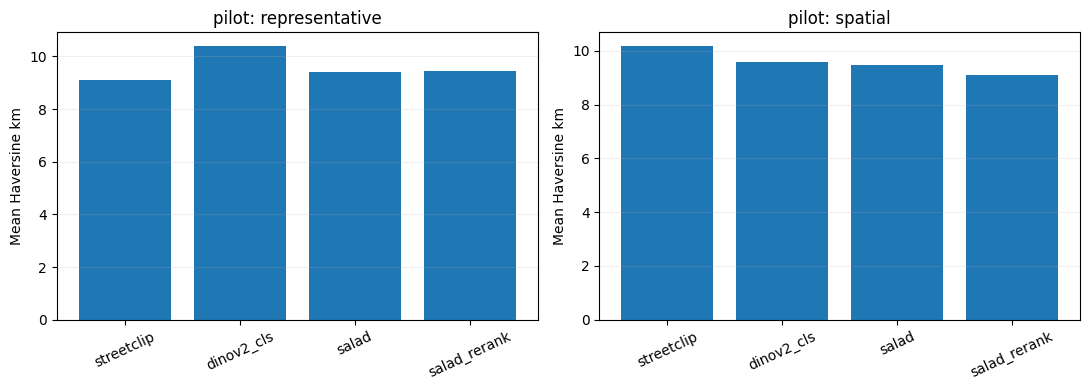

pilot gate: False selected: None | Subset-gallery pilot; do not compare its score directly with full-fold fusion.


In [35]:
# Cell 105 — Saved pilot/full metrics and progress; no inference or fitting.
def salad_dashboard():
    for scope in ('pilot','full'):
        path=SALAD_HOME/scope/'comparison.json'
        if not path.exists():continue
        result=json.loads(path.read_text());table=pd.DataFrame(result['records'])
        display(table[['model','split','scope','score','mean_km','median_km','p90_km','borough_macro_f1',
                       'recall_top1_0.5km','recall_top1_1.0km','recall_top5_1.0km','recall_top32_1.0km','fraction_over_10km']])
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        for split,axis in zip(('representative','spatial'),axes):
            rows=table[table.split==split]
            axis.bar(rows.model,rows.mean_km);axis.set_title(f'{scope}: {split}');axis.set_ylabel('Mean Haversine km')
            axis.tick_params(axis='x',rotation=25);axis.grid(axis='y',alpha=.2)
        fig.tight_layout();plt.show()
        print(scope,'gate:',result['gate_passed'],'selected:',result['selected_variant'],'|',result['scope_warning'])

salad_dashboard()


## Bounded realignment: view-pooling ablation

The fixed compass-aligned pilot failed the expansion gate: SALAD mean errors
9.392/9.482km vs StreetCLIP9.097/10.175km and DINOv2-CLS10.393/9.568km.
The fixed regional reranker gives9.428/9.083km and also fails the representative
requirement. These subset-gallery results do not establish full-gallery performance.
No full extraction is authorized by this failed gate; preserve its comparison.

Predeclare one additional cached ablation before running it: normalize each image
descriptor, average the four directional descriptors, renormalize and apply the exact
same retrieval/decoder. Compare all three encoders on the unchanged pilot IDs. This
tests view fusion while holding encoders and data fixed; no new images, fitting or
weight search. Use the same both-fold mean-error/representative-score gate, record
separate evidence, and keep results labeled reused development. Ten-minute CPU/GPU
evaluation bound. Do not automatically promote a pooled result from these small
galleries to a full-model score. If this also fails, retain the existing fusion and
stop expansion in this task.


In [36]:
# Cell 107 — Fixed orientation-invariant pooling ablation, cached features only.
def salad_pooled_views(features):
    values=np.array(features,dtype=np.float32,copy=True)
    values/=np.maximum(np.linalg.norm(values,axis=-1,keepdims=True),1e-8)
    pooled=values.mean(1,keepdims=True)
    # Existing retrieval normalizes these identical four tokens; exactly pooled cosine.
    return np.repeat(pooled,4,axis=1)

def salad_pooling_ablation():
    started=time.monotonic();frame,splits,plan=salad_plan()
    benchmark=json.loads((SALAD_HOME/'benchmark.json').read_text())
    global_features,_,_=salad_open_cache(frame,benchmark,plan['union_ids'])
    street=np.load(ROOT/'outputs/features/streetclip_train_23f1be61d2b2b2cd.npy',mmap_mode='r')
    dino=np.load(ROOT/'outputs/dinov2/features/train_51ac09b98e135c24.npy',mmap_mode='r')
    identity={'metric_version':CURRENT_METRIC_VERSION,'plan':plan,'pooling':'mean_of_unit_view_descriptors',
              'source':dino_definitions_hash(['salad_pooled_views','salad_pooling_ablation','salad_retrieval','salad_decode']),
              'encoder':benchmark['identity']}
    directory=SALAD_HOME/'pooled_pilot';directory.mkdir(parents=True,exist_ok=True);path=directory/'comparison.json'
    if path.exists():
        report=json.loads(path.read_text());require(report['identity']==identity,'Pooling ablation identity changed.');return report
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id);records=[]
    for split_name,split in plan['folds'].items():
        training=frame.loc[split['train_ids']];query=frame.loc[split['validation_ids']]
        tr=position.loc[training.sample_id].to_numpy();va=position.loc[query.sample_id].to_numpy()
        for name,source in [('streetclip',street),('dinov2_cls',dino),('salad',global_features)]:
            require(time.monotonic()-started<600,'Cached pooling ablation evaluation cap exceeded.')
            a=np.array(source[tr,:,0],copy=True) if name=='dinov2_cls' else np.array(source[tr],copy=True)
            b=np.array(source[va,:,0],copy=True) if name=='dinov2_cls' else np.array(source[va],copy=True)
            prediction,metrics,queries=salad_retrieval(training,query,salad_pooled_views(a),salad_pooled_views(b))
            output=directory/f'{name}_{split_name}.csv';prediction.to_csv(output,index=False)
            queries.to_csv(directory/f'{name}_{split_name}_queries.csv',index=False)
            records.append({'model':name,'split':split_name,'scope':'pooled_pilot','prediction':str(output.relative_to(ROOT)),
                            'prediction_sha256':sha256(output),**metrics})
            print(name,split_name,'pooled mean',round(metrics['mean_km'],4),'v2',round(metrics['score'],5),flush=True)
            del a,b
    passed=True
    for split_name in plan['folds']:
        candidate=next(r for r in records if r['model']=='salad' and r['split']==split_name)
        for baseline in ('streetclip','dinov2_cls'):
            control=next(r for r in records if r['model']==baseline and r['split']==split_name)
            passed &= control['mean_km']-candidate['mean_km']>=.05
            if split_name=='representative':passed &= candidate['score']>=control['score']
    result={'identity':identity,'records':records,'gate_passed':bool(passed),'elapsed_seconds':time.monotonic()-started,
            'scope_warning':'Cached pilot ablation; reused validation; no full-gallery score or new model fit.'}
    dino_json(path,result)
    return result

class SaladPoolingTests(unittest.TestCase):
    def test_unit_view_pooling_is_compass_permutation_invariant(self):
        rng=np.random.default_rng(42);features=rng.normal(size=(3,4,16)).astype(np.float32)
        actual=salad_pooled_views(features);permuted=salad_pooled_views(features[:,[2,0,3,1]])
        np.testing.assert_allclose(actual,permuted,atol=1e-7)
        for i in range(1,4):np.testing.assert_array_equal(actual[:,0],actual[:,i])

pooling_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(SaladPoolingTests))
require(pooling_tests.wasSuccessful(),'Resolve pooling math before evaluation.')
RUN_SALAD_POOLING=os.environ.get('NYCGUESSR_SALAD_POOLING','0')=='1'
if RUN_SALAD_POOLING:
    SALAD_POOLING_RESULT=salad_pooling_ablation()
    display(pd.DataFrame(SALAD_POOLING_RESULT['records'])[['model','split','score','mean_km','median_km','p90_km','recall_top1_1.0km','recall_top32_1.0km']])
    print('Separate pooled-view pilot gate:',SALAD_POOLING_RESULT['gate_passed'])
else:print('Cached pooled-view ablation disabled by default.')


test_unit_view_pooling_is_compass_permutation_invariant (__main__.SaladPoolingTests.test_unit_view_pooling_is_compass_permutation_invariant) ... 

ok


----------------------------------------------------------------------
Ran 1 test in 0.001s

OK


Cached pooled-view ablation disabled by default.


## Full-fold cached fusion reranking — controlled realignment

SALAD failed both the compass-aligned and separately declared pooled pilot gates;
keep full SALAD extraction disabled. The next already-approved step is candidate
reranking. Test it on our proven trained fusion using complete existing DINO region
caches, rather than extrapolating a failed small-gallery encoder comparison.

Predeclare one alpha=.3 regional/global similarity mix on the fusion head's top32
training neighbors, hold its cell probabilities, top30 cells,50/50 cell/neighbor
mixture, borough predictions and geographic median fixed. Compare alpha0 as an
exact original-decoder replay. Patch matching uses symmetric regional cosine within
each compass view. Query labels are evaluation-only. No image extraction/fitting.
Require representative v2 gain>=.002 and >=.05km mean-error reduction on both fixed
folds at both matched seeds; otherwise reject. Ten-minute total evaluation bound.
No additional alpha search or full encoder expansion is part of this task after this.


In [37]:
# Cell 109 — Original-decoder replay and one fixed region-consistency weighting.
def fusion_patch_predictions(training,query_ids,geography,bank,query,probability,borough,gallery_regions,query_regions,alpha=.3):
    require(alpha in (0.,.3),'Only predeclared alpha0/.3 comparisons are allowed.')
    require(not set(query_ids)&set(training.sample_id),'Patch reranker reference/query leakage.')
    require(len(query_ids)==len(query)==len(probability)==len(query_regions),'Patch query alignment.')
    bank=np.asarray(bank,np.float32);query=np.asarray(query,np.float32)
    bank=bank/np.maximum(np.linalg.norm(bank,axis=1,keepdims=True),1e-8)
    query=query/np.maximum(np.linalg.norm(query,axis=1,keepdims=True),1e-8)
    xy,origin,scales=coordinates_xy(training[['latitude','longitude']],geography['origin']);centers=np.asarray(geography['centers'])
    predictions=[]
    for start in range(0,len(query_ids),128):
        cosine=query[start:start+128]@bank.T
        neighbors=np.argsort(-cosine,axis=1,kind='stable')[:,:min(32,len(training))]
        scores=np.take_along_axis(cosine,neighbors,axis=1)
        if alpha:
            local=[]
            for a in range(0,len(neighbors),32):
                local.append(salad_region_scores(np.array(query_regions[start+a:start+a+32],copy=True),
                              np.array(gallery_regions[neighbors[a:a+32]],copy=True)))
            scores=(1-alpha)*scores+alpha*np.concatenate(local)
        weights=np.exp((scores-scores.max(1,keepdims=True))/.05);weights/=weights.sum(1,keepdims=True)
        p=probability[start:start+len(neighbors)];top=np.argsort(-p,axis=1,kind='stable')[:,:30]
        mass=np.take_along_axis(p,top,axis=1);mass/=mass.sum(1,keepdims=True)
        median=bounded_geometric_median(np.concatenate([centers[top],xy[neighbors]],1),np.concatenate([.5*mass,.5*weights],1))
        gps=median/scales+origin
        predictions.append(pd.DataFrame({'sample_id':np.asarray(query_ids)[start:start+len(neighbors)],
                'borough':np.asarray(BOROUGHS)[borough[start:start+len(neighbors)]],'latitude':gps[:,0],'longitude':gps[:,1]}))
    result=pd.concat(predictions,ignore_index=True);validate_predictions(result,query_ids)
    return result

def run_fusion_patch_rerank():
    started=time.monotonic();frame,splits,street,dino,_,_=fusion_sources()
    pointer=json.loads((FUSION_HOME/'latest.json').read_text());decision=json.loads((ROOT/pointer['decision']).read_text())
    identity={'metric_version':CURRENT_METRIC_VERSION,'alpha':.3,'source_decision_sha256':pointer['sha256'],
              'source':dino_definitions_hash(['fusion_patch_predictions','run_fusion_patch_rerank','salad_region_scores']),
              'scope':'complete original folds, seed6643/6644, unchanged trained heads'}
    directory=SALAD_HOME/'fusion_patch_rerank';directory.mkdir(parents=True,exist_ok=True);path=directory/'comparison.json'
    if path.exists():
        report=json.loads(path.read_text());require(report['identity']==identity,'Fusion rerank source changed.');return report
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id);records=[];device=dino_device()
    for seed in (6643,6644):
        for split_name in ('representative','spatial'):
            require(time.monotonic()-started<600,'Full-fold cached reranker evaluation budget exceeded.')
            source=next(r for r in decision['records'] if r['variant']=='fusion_random' and r['seed']==seed and r['split']==split_name)
            require(sha256(ROOT/source['checkpoint'])==source['checkpoint_sha256'],'Source fusion checkpoint changed.')
            model,saved=fusion_model_load(ROOT/source['checkpoint'],decision['identity'],device)
            training=frame.loc[saved['train_ids']];truth=frame.loc[saved['validation_ids']]
            require(saved['train_ids']==splits['splits'][split_name]['train_ids'] and saved['validation_ids']==splits['splits'][split_name]['validation_ids'],'Original split drift.')
            tr=position.loc[training.sample_id].to_numpy();va=position.loc[truth.sample_id].to_numpy()
            try:
                _,_,bank=fusion_outputs(model,street[tr],dino[tr],device)
                probability,borough,query=fusion_outputs(model,street[va],dino[va],device)
                original=pd.read_csv((ROOT/source['checkpoint']).parent/'validation_best.csv')
                for alpha in (0.,.3):
                    predicted=fusion_patch_predictions(training,truth.sample_id,saved['geography'],bank,query,probability,borough.argmax(1),
                                np.array(dino[tr,:,1:],copy=True),np.array(dino[va,:,1:],copy=True),alpha)
                    if alpha==0.:
                        require(predicted.borough.tolist()==original.borough.tolist(),'Alpha0 borough replay drift.')
                        np.testing.assert_allclose(predicted[['latitude','longitude']],original[['latitude','longitude']],rtol=0,atol=1e-7)
                    output=directory/f'alpha{alpha}_{split_name}_s{seed}.csv';predicted.to_csv(output,index=False)
                    metrics=score_current_predictions(truth,predicted)
                    record={'alpha':alpha,'split':split_name,'seed':seed,'prediction':str(output.relative_to(ROOT)),
                            'prediction_sha256':sha256(output),'source_checkpoint':source['checkpoint'],**metrics}
                    if alpha:
                        record['bootstrap']=current_metric_bootstrap(truth,predicted,original,splits)
                    records.append(record)
                    dino_json(directory/'in_progress.json',records)
                    print(f'Fusion region alpha{alpha} {split_name} seed{seed}: v2={metrics["score"]:.6f}, mean={metrics["mean_km"]:.4f}km',flush=True)
            finally:
                del model;dino_release(device)
    seed_pass={}
    for seed in (6643,6644):
        candidate={r['split']:r for r in records if r['seed']==seed and r['alpha']==.3}
        control={r['split']:r for r in records if r['seed']==seed and r['alpha']==0.}
        seed_pass[str(seed)]=passes_current_development_guard(candidate,control)
    result={'identity':identity,'records':records,'seed_pass':seed_pass,'retained':all(seed_pass.values()),
            'decision':'retain_patch_reranker' if all(seed_pass.values()) else 'retain_original_fusion',
            'elapsed_seconds':time.monotonic()-started,'training_or_extraction':False,'new_public_score':None}
    dino_json(path,result)
    return result

class FusionPatchTests(unittest.TestCase):
    def test_zero_alpha_is_existing_decoder_and_overlap_stays_rejected(self):
        frame=example_frame(40);geo=fit_geography(frame,cells=32);rng=np.random.default_rng(19)
        bank=rng.normal(size=(40,12)).astype(np.float32);query=rng.normal(size=(3,12)).astype(np.float32)
        p=rng.uniform(size=(3,32)).astype(np.float32);p/=p.sum(1,keepdims=True);ids=np.array([100,101,102]);borough=np.array([0,1,2])
        regions=rng.normal(size=(40,4,4,8)).astype(np.float32);qregions=rng.normal(size=(3,4,4,8)).astype(np.float32)
        actual=fusion_patch_predictions(frame,ids,geo,bank,query,p,borough,regions,qregions,0.)
        expected=compass_decoders(frame,ids,geo,bank,query,p,borough)['mixed_median']
        np.testing.assert_allclose(actual[['latitude','longitude']],expected[['latitude','longitude']],rtol=0,atol=1e-10)
        with self.assertRaises(ValueError):fusion_patch_predictions(frame,[0,1,2],geo,bank,query,p,borough,regions,qregions,.3)

fusion_patch_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(FusionPatchTests))
require(fusion_patch_tests.wasSuccessful(),'Resolve reranker replay/parity before real evaluation.')


test_zero_alpha_is_existing_decoder_and_overlap_stays_rejected (__main__.FusionPatchTests.test_zero_alpha_is_existing_decoder_and_overlap_stays_rejected) ... 

ok


----------------------------------------------------------------------
Ran 1 test in 0.011s

OK


In [38]:
# Cell 110 — Explicit final cached reranking experiment, disabled by default.
RUN_FUSION_PATCH=os.environ.get('NYCGUESSR_FUSION_PATCH','0')=='1'
if RUN_FUSION_PATCH:
    FUSION_PATCH_RESULT=run_fusion_patch_rerank()
else:print('Full-fold fusion patch experiment disabled.')


Full-fold fusion patch experiment disabled.


In [39]:
# Cell 111 — Saved reranker result, with complete-fold v2 scores.
path=SALAD_HOME/'fusion_patch_rerank/comparison.json'
if path.exists():
    result=json.loads(path.read_text());display(pd.DataFrame(result['records'])[['alpha','split','seed','score','mean_km','median_km','p90_km','borough_macro_f1']])
    print('Retained:',result['retained'],'| per-seed gates:',result['seed_pass'],'|',result['decision'])
    print('No fitting/image extraction; original submission CSV and all checkpoints preserved.')


,alpha,split,seed,score,mean_km,median_km,p90_km,borough_macro_f1
0,0.0,representative,6643,0.346004,3.543432,1.170501,10.405028,0.838217
1,0.3,representative,6643,0.343808,3.555633,1.214028,10.478618,0.838217
2,0.0,spatial,6643,0.077237,5.530323,2.805487,14.019978,0.772372
3,0.3,spatial,6643,0.077237,5.542445,2.835173,13.920754,0.772372
4,0.0,representative,6644,0.351532,3.512208,1.197510,10.084168,0.837290
5,0.3,representative,6644,0.351404,3.512919,1.202746,10.003619,0.837290
6,0.0,spatial,6644,0.076302,5.645370,2.834758,14.215357,0.763019
7,0.3,spatial,6644,0.076302,5.641442,2.787171,14.097986,0.763019


Retained: False | per-seed gates: {'6643': False, '6644': False} | retain_original_fusion
No fitting/image extraction; original submission CSV and all checkpoints preserved.


## SALAD and reranking: final evidence review

The numerical implementation passed, but the compass-aligned SALAD pilot and the
separately predeclared pooled-view pilot failed the both-fold expansion gate. The
fixed regional reranker on SALAD did not rescue the representative comparison.
The subsequent cached-region reranker on complete-fold trained fusion also failed
both-seed retention. Keep the original fusion/CSV; do not spend the conditional
full-extraction budget or claim a new full-data SALAD score. This is a bounded
negative experiment, not evidence that every SALAD or fine-tuned transformer setup
would fail. Small-gallery controls differ from our supervised complete-fold model.

The audit below checks immutable identities, partial-cache coverage, sampled input
hashes, all saved scores, checkpoint/CSV preservation, numeric-parity evidence and
budget use. Pilot intervals are retrospective reused-development diagnostics.


### Completed monitored study — 2026-11-18

**Decision: retain the original learned StreetCLIP/DINOv2 fusion and existing CSV. No new score gain was retained.** The official352,040,378-byte SALAD checkpoint loaded188 tensor keys strictly, SHA `6b3f1720954293e83da6966c5cfcfc6713200d7fefadcca76fc51aeb80b3cada`. Source revision and source/license text are archived in `outputs/models/salad_v1_6aede13a/upstream_source.json`; preserve those license notices in any distributed derivative code package. No external image dataset, gallery, map or coordinates were downloaded, and no new dependencies were installed.

Native PyTorch SALAD with original+.1 positional interpolation and matrix-product aggregation agreed with independent original-parameter CPU math (RMS8.67e-6). MPS FP32 descriptor cosine>=.9999989; MPS FP16-vs-FP32 cosine>=.9999919, RMS.00393. This permits mixed precision for this validated SALAD implementation only; it does not retroactively approve the earlier failed DINO FP16 path. Short benchmark selected1 location/batch,4 input threads,32.91 images/s. Sustained pilot extraction was about23.69 images/s.

Fixed pilot:1,024 training-gallery locations and256 queries per original fold, **2,374 unique locations /9,496 checked official training images**. All four directions stay together. Extraction took **400.81s (6.68min)**, below20 minutes; sampled peak encoder MPS driver allocation **1.35GiB**. Only the pilot rows are committed in the memory-mapped full-sized feature arrays; the complete-cache flag remains false. Never train on uncovered rows. The conditional45-minute full-extraction budget was not spent.

| Frozen retrieval / small gallery | Compass-aligned mean km, rep / spatial | Pooled-view mean km, rep / spatial |
|---|---|---|
| StreetCLIP | 9.0973 /10.1746 | 8.1202 /9.6070 |
| DINOv2 CLS | 10.3926 /9.5681 | 9.2988 /9.4664 |
| SALAD | 9.3921 /9.4823 | 8.7159 /9.0857 |
| SALAD +fixed region rerank | 9.4279 /9.0830 | not run |

SALAD/its reranker improve some spatial errors but do not beat both matched controls on both folds. Pooling was a separately predeclared cached ablation, not a silent change to the failed original gate. Its gate also failed. All pilot GPS composite terms are clipped to zero because means exceed5km. These are small-gallery frozen-retrieval results, not comparable to our full-gallery supervised fusion scores. Pilot bootstrap intervals are in the audit; they are reused-development diagnostics and do not establish that all SALAD configurations are inferior.

Full-fold fixed fusion patch reranker: alpha0 replay exactly reproduces the original decoder. Alpha.3 gives seed6643 mean errors **3.5556 /5.5424km**, compared with **3.5434 /5.5303km**; representative v2 score **.343808** vs **.346004**. Seed6644 gives **3.5129 /5.6414km** vs **3.5122 /5.6454km**, representative v2 **.351404** vs **.351532**. Both seeds fail the current retention guard; reject this fixed weighting. No original head, cell probabilities, borough outputs, model weights or CSV bytes were changed.

The final extraction/fitting-disabled targeted fresh-kernel execution passed **13 checks**,40 code cells,zero errors in **8.18s**; a subsequent read-only audit also passed. This is not a full historical Run All. Input/weight/cache producer identities, original folds/buffer, committed pilot rows, unit norms, all saved scores, original10 fusion checkpoints and both CSV hashes were verified. The pilot comparison figure was visually inspected.

Evidence: `outputs/salad/pilot/comparison.json`, `pooled_pilot/comparison.json`, `fusion_patch_rerank/comparison.json`, `benchmark.json`, `verification.json`, separate phase execution records and persistent `pilot_budget.json`. Full data extraction, Q4 model fitting, test predictions and Kaggle upload were not performed. Current retained v2 development scores remain **.346004 representative /.077237 spatial**; current public score remains unknown.

**Single next proposed task:** train a small candidate reranker using training-fold-only geographic positive/negative pairs and existing cached compass/region features. Learn which evidence predicts a useful neighbor, then test it on the complete original folds at both seeds. The fixed heuristics above were rejected; no learned reranker or encoder fine-tuning was started in this study.


In [1]:
# Cell 113 — Read-only audit; no encoder execution, extraction or model training.
def verify_salad_experiments():
    started=time.monotonic();frame,splits,plan=salad_plan();path,provenance=salad_prepare()
    benchmark=json.loads((SALAD_HOME/'benchmark.json').read_text())
    require(benchmark['identity']==salad_identity(provenance,benchmark['precision']),'Encoder source identity drift.')
    require(benchmark['elapsed_seconds']<=300,'Benchmark time cap exceeded.')
    global_features,regions,ledger=salad_open_cache(frame,benchmark,plan['union_ids'])
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id);index=position.loc[plan['union_ids']].to_numpy()
    require(np.flatnonzero(ledger['covered']).tolist()==sorted(index.tolist()),'Unexpected extraction outside the pilot.')
    require(not ledger['complete'],'Do not call a partial pilot cache complete.')
    budget=json.loads((SALAD_HOME/'pilot_budget.json').read_text())
    require(budget['status']=='complete' and budget['seconds']<=1200,'Pilot budget/status mismatch.')
    require(not (SALAD_HOME/'full_budget.json').exists(),'Failed pilot unexpectedly spent full-extraction budget.')
    subsets={'global_sha256':hashlib.sha256(np.ascontiguousarray(global_features[index]).tobytes()).hexdigest(),
             'regions_sha256':hashlib.sha256(np.ascontiguousarray(regions[index]).tobytes()).hexdigest()}
    reviewed=[];intervals=[]
    for scope in ('pilot','pooled_pilot'):
        result=json.loads((SALAD_HOME/scope/'comparison.json').read_text())
        require(result['gate_passed'] is False,'This audit describes the rejected pilot; review changed evidence explicitly.')
        for record in result['records']:
            csv=ROOT/record['prediction'];require(sha256(csv)==record['prediction_sha256'],'Prediction CSV changed.')
            truth=frame.loc[plan['folds'][record['split']]['validation_ids']]
            measured=score_current_predictions(truth,pd.read_csv(csv))
            for name in ('score','mean_km','median_km','p90_km','borough_macro_f1'):
                require(abs(record[name]-measured[name])<1e-7,f'Saved pilot score drift: {name}')
            reviewed.append({'scope':scope,'model':record['model'],'split':record['split'],'score':measured['score'],'mean_km':measured['mean_km']})
        candidate_names=('salad','salad_rerank') if scope=='pilot' else ('salad',)
        for model in candidate_names:
            for split in ('representative','spatial'):
                a=next(r for r in result['records'] if r['model']==model and r['split']==split)
                truth=frame.loc[plan['folds'][split]['validation_ids']]
                for control in ('streetclip','dinov2_cls'):
                    b=next(r for r in result['records'] if r['model']==control and r['split']==split)
                    intervals.append({'scope':scope,'model':model,'control':control,'split':split,
                        **current_metric_bootstrap(truth,pd.read_csv(ROOT/a['prediction']),pd.read_csv(ROOT/b['prediction']),splits)})
    rerank=json.loads((SALAD_HOME/'fusion_patch_rerank/comparison.json').read_text())
    require(rerank['retained'] is False and rerank['elapsed_seconds']<=600,'Reranker decision/budget drift.')
    for r in rerank['records']:
        csv=ROOT/r['prediction'];require(sha256(csv)==r['prediction_sha256'],'Fusion rerank prediction changed.')
        truth=frame.loc[splits['splits'][r['split']]['validation_ids']]
        score=score_current_predictions(truth,pd.read_csv(csv))
        require(abs(score['score']-r['score'])<1e-7 and abs(score['mean_km']-r['mean_km'])<1e-7,'Full-fold score replay failed.')
    required_files={
        'Data/train.csv':'ad1de9fda09d83ab41e4879f5738e40956ea02aee0d5072b630a1fbd3d5e069b',
        'outputs/splits.json':'01edd72611d17b928f7d5b835e2ee26c8ec2848652b3065ced9abc06102a509d',
        'outputs/features/streetclip_train_23f1be61d2b2b2cd.npy':'b9be80acd9d389f34b558321403d9f4d5ef4e54e100f31800d05426f7ae2f2e8',
        'outputs/dinov2/features/train_51ac09b98e135c24.npy':'a28d92f3db2d5205ed1ecc20e398dfc1e34ceba89493ac7affd751dd1346f370',
        'Kaggle Submissions/nycguessr_streetclip40_20261116.csv':'c065fb05a3f31c9195f4132f726c2f6c7d1b52195b831dcc59dbe877e33dc35f',
        'Kaggle Submissions/nycguessr_fusion40_20261117.csv':'075d86f3a426872c50f2b970d01b6cdb51319f6f102837dbd445a1019740ed3b'}
    for name,digest in required_files.items():require(sha256(ROOT/name)==digest,f'Original artifact changed: {name}')
    pointer=json.loads((FUSION_HOME/'latest.json').read_text());require(sha256(ROOT/pointer['decision'])==pointer['sha256'],'Fusion decision changed.')
    fusion=json.loads((ROOT/pointer['decision']).read_text())
    for r in fusion['records']:
        if 'checkpoint' in r:require(sha256(ROOT/r['checkpoint'])==r['checkpoint_sha256'],'Original fusion checkpoint changed.')
    report={'status':'passed','metric_version':CURRENT_METRIC_VERSION,'weights_sha256':provenance['weights_sha256'],
            'pilot_locations':len(index),'pilot_image_hashes_checked_during_decode':4*len(index),
            'partial_cache_subset_hashes':subsets,'pilot_extraction_seconds':budget['seconds'],
            'sampled_peak_encoder_driver_bytes':ledger['sampled_peak_driver_bytes'],
            'frozen_pilot_reviews':reviewed,'pilot_uncertainty':intervals,'all_full_fold_reranker_scores_replayed':True,
            'failed_pilot_not_expanded':True,'original_fusion_and_CSVs_preserved':True,
            'decision':'retain_original_fusion','current_full_fold_v2_scores':{r['split']:r['score'] for r in rerank['records'] if r['alpha']==0. and r['seed']==6643},
            'new_public_score':None,'elapsed_seconds':time.monotonic()-started}
    dino_json(SALAD_HOME/'verification.json',report)
    display(pd.DataFrame(reviewed));display(pd.DataFrame(intervals))
    print('Verified: rejected SALAD pilots and fixed fusion reranker; retain original fusion and both CSVs.')
    return report

SALAD_FINAL_VERIFICATION=verify_salad_experiments()


           scope         model           split     score    mean_km
0          pilot    streetclip  representative  0.049565   9.097262
1          pilot    dinov2_cls  representative  0.047545  10.392617
2          pilot         salad  representative  0.047982   9.392115
3          pilot  salad_rerank  representative  0.046467   9.427851
4          pilot    streetclip         spatial  0.039910  10.174629
5          pilot    dinov2_cls         spatial  0.047146   9.568085
6          pilot         salad         spatial  0.044750   9.482312
7          pilot  salad_rerank         spatial  0.042299   9.083006
8   pooled_pilot    streetclip  representative  0.056905   8.120153
9   pooled_pilot    dinov2_cls  representative  0.057870   9.298757
10  pooled_pilot         salad  representative  0.052699   8.715902
11  pooled_pilot    streetclip         spatial  0.046217   9.607009
12  pooled_pilot    dinov2_cls         spatial  0.043421   9.466436
13  pooled_pilot         salad         spatial  

## Learned candidate reranker — monitored study, 2026-11-18

The user approved **"Ok continue with that"** after the proposed training-only
candidate reranker. Hypothesis: learn which global/view/region and candidate-consensus
cues identify a geographically useful neighbor, instead of another fixed similarity mix.

**Leakage boundary:** within each original training fold, select2,048 borough-stratified
meta-training query locations (seed6643), and fit a fresh40-epoch fusion teacher on
the remaining original training locations only. Teacher normalization/cells/positive
pairs/boro weights use that inner gallery alone. The meta queries are unseen by this
teacher. Generate top32 candidates from its inner gallery; query coordinates are used
only afterward to form training-distance targets. The reranker does not see absolute
coordinates, sample IDs or query truth as input features. All four images stay together.
This is one training-only held-out-query teacher, not complete out-of-fold coverage.

Train a small39→64→32→1 MLP for30 fixed epochs on those cached candidate features,
with per-feature statistics fitted to meta-training rows only. Its zero-initialized
output adds a bounded±4 residual to the original cosine/.05 neighbor logits; zero
residual exactly preserves baseline. Fixed loss: 1-km soft geographic target CE
+ .25 expected candidate distance/5km +.001 residual-square penalty. Keep the
512-cell predictions, borough outputs, top30 cells,50/50 cell/neighbor mass and
geographic median unchanged. The5-km metric is evaluation-only; no per-sample
clipping is introduced into the distance loss.

Evaluate only the final30-epoch reranker on complete original validation folds using
the original full-training-fold fusion heads/banks. Repeat at seeds6643/6644, with
the same meta query IDs. Outer validation is never used to fit features, targets,
teacher parameters or select a training epoch. Compare zero-residual replay and
learned residual; use current v2 representative score gain>=.002 and mean-error
reduction>=.05km on BOTH folds at BOTH seeds. Report block-bootstrap raw-distance
uncertainty, all-five F1, mean/median/p90, tails and candidate recall. Reject on failure;
no coefficient/architecture search or another encoder pass in this bounded study.

Bounds:180s per teacher,60s per reranker,20 cumulative minutes of new fitting, and
10 minutes of pair construction/evaluation per outer fit. Feature tensors are bounded
candidate arrays, not full-resolution images. All work stays in this notebook, MPS
FP32 for fitting; original weights/caches/CSVs remain immutable. No downloads,
dependency changes, test predictions or Kaggle upload are part of this experiment.


In [28]:
# Cell 115 — Training-only plans and explicit candidate feature contracts.
LEARNED_RERANK_HOME=ROOT/'outputs/learned_rerank'
LEARNED_RERANK_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'meta_queries':2048,'teacher_epochs':40,
    'reranker_epochs':30,'teacher_seconds':180.,'reranker_seconds':60.,'aggregate_fit_seconds':1200.,
    'pair_seconds':600.,'seed_for_meta_ids':6643,'seeds':[6643,6644],'candidate_count':32,
    'residual_bound':4.,'learning_rate':.001,'weight_decay':.01,'batch_queries':128,'tag':'heldout_teacher_v1'}

def learned_rerank_plan(frame,splits,split_name):
    outer=splits['splits'][split_name]
    meta=training_subset(frame.loc[outer['train_ids']],limit=2048,seed=6643).sample_id.tolist()
    meta_set=set(meta)
    gallery=[i for i in outer['train_ids'] if i not in meta_set]
    require(set(meta).isdisjoint(gallery) and set(meta+gallery)==set(outer['train_ids']),'Inner partition drift.')
    require(set(meta+gallery).isdisjoint(outer['validation_ids']),'Outer validation leaked into inner training.')
    return {'split':split_name,'teacher_train_ids':gallery,'meta_query_ids':meta,
            'outer_train_ids':outer['train_ids'],'outer_validation_ids':outer['validation_ids']}

def unit_features(x):
    x=np.asarray(x,dtype=np.float32)
    return x/np.maximum(np.linalg.norm(x,axis=-1,keepdims=True),1e-8)

def rerank_pair_features(training,query_ids,geography,bank,queries,probabilities,borough_prob,
                         gallery_street,query_street,gallery_dino,query_dino):
    """Inputs contain no query coordinates/borough labels. Gallery labels are permitted."""
    require(len(query_ids)<=32 and len(query_ids)==len(queries)==len(probabilities)==len(borough_prob),'Pair query/chunk cap.')
    require(training.sample_id.is_unique and not set(training.sample_id)&set(query_ids),'Pair gallery/query ID leakage.')
    require(len(bank)==len(training)==len(gallery_street)==len(gallery_dino),'Pair gallery alignment.')
    bank=unit_features(bank);queries=unit_features(queries)
    cosine=queries@bank.T
    neighbors=np.argsort(-cosine,axis=1,kind='stable')[:,:32]
    score=np.take_along_axis(cosine,neighbors,1)
    features=[score[:,:,None],(score-score[:,:1])[:,:,None],
              np.broadcast_to((np.log1p(np.arange(32))/np.log(33))[None,:,None],(len(query_ids),32,1))]
    street=unit_features(np.array(gallery_street[neighbors],copy=True));qs=unit_features(query_street)
    features.append(np.einsum('qvc,qkvc->qkv',qs,street,optimize=True))
    dino=unit_features(np.array(gallery_dino[neighbors],copy=True));qd=unit_features(query_dino)
    features.append(np.einsum('qvc,qkvc->qkv',qd[:,:,0],dino[:,:,:,0],optimize=True))
    local=np.einsum('qvrc,qkvrc->qkvr',qd[:,:,1:],dino[:,:,:,1:],optimize=True)
    features.append(local.reshape(len(query_ids),32,16))
    matching=np.einsum('qvrc,qkvsc->qkvrs',qd[:,:,1:],dino[:,:,:,1:],optimize=True)
    features.append(.5*(matching.max(-1).mean(-1)+matching.max(-2).mean(-1)))
    label=np.array([BOROUGHS.index(b) for b in training.borough])
    features.append(np.take_along_axis(borough_prob[:,None,:],np.broadcast_to(label[neighbors][:,:,None],(len(query_ids),32,1)),2))
    xy,_,_=coordinates_xy(training[['latitude','longitude']],geography['origin'])
    points=xy[neighbors]
    pair_distance=np.linalg.norm(points[:,:,None,:]-points[:,None,:,:],axis=-1)
    weight=np.exp((score-score.max(1,keepdims=True))/.05);weight/=weight.sum(1,keepdims=True)
    off_diagonal=~np.eye(32,dtype=bool)[None]
    for radius in (.5,1.,2.):
        agreement=((pair_distance<=radius)*off_diagonal*weight[:,None,:]).sum(2)/np.maximum(1-weight,1e-6)
        features.append(agreement[:,:,None])
    consensus=(pair_distance*weight[:,None,:]).sum(2)
    features.append((np.log1p(consensus)/np.log(51))[:,:,None])
    center_distance=np.linalg.norm(points[:,:,None,:]-np.asarray(geography['centers'])[None,None,:,:],axis=-1)
    features.append(((center_distance<=1.)*probabilities[:,None,:]).sum(2)[:,:,None])
    entropy=-(probabilities*np.log(np.maximum(probabilities,1e-12))).sum(1)/np.log(probabilities.shape[1])
    neighbor_entropy=-(weight*np.log(np.maximum(weight,1e-12))).sum(1)/np.log(32)
    for value in (entropy,neighbor_entropy):features.append(np.broadcast_to(value[:,None,None],(len(query_ids),32,1)))
    result=np.concatenate(features,axis=-1).astype(np.float32)
    require(result.shape==(len(query_ids),32,39) and bool(np.isfinite(result).all()),'Pair feature schema/finite mismatch.')
    return result,neighbors,score

def learned_rerank_identity():
    return {'config':LEARNED_RERANK_CONFIG,'data_fingerprint':data_fingerprint(ROOT),
            'split_sha256':sha256(ROOT/'outputs/splits.json'),
            'street_cache_sha256':'b9be80acd9d389f34b558321403d9f4d5ef4e54e100f31800d05426f7ae2f2e8',
            'dino_cache_sha256':'a28d92f3db2d5205ed1ecc20e398dfc1e34ceba89493ac7affd751dd1346f370',
            'source':dino_definitions_hash(['learned_rerank_plan','rerank_pair_features','unit_features',
                'fit_rerank_teacher','build_learned_pair_bundle','PairResidualReranker','fit_pair_reranker',
                'decode_learned_bundle','run_learned_reranker','compose_geolocation_score','score_current_predictions',
                'score_predictions_versioned','FusionGeoHead','FeatureLayerNorm','fusion_outputs','fusion_distant_random'])}


In [29]:
# Cell 116 — Fresh inner-gallery teacher; meta query labels excluded from fitting.
def fit_rerank_teacher(frame,street,dino,plan,seed,directory,identity,budget):
    directory.mkdir(parents=True,exist_ok=True);status_path=directory/'teacher_status.json';path=directory/'teacher.pth'
    if status_path.exists():
        status=json.loads(status_path.read_text());require(status['status']=='complete','Inspect an interrupted/failed teacher before retry.')
        require(sha256(path)==status['checkpoint_sha256'],'Teacher checkpoint changed.')
        return path
    training=frame.loc[plan['teacher_train_ids']]
    require(set(training.sample_id).isdisjoint(plan['meta_query_ids']+plan['outer_validation_ids']),'Teacher query/validation leakage.')
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id);index=position.loc[training.sample_id].to_numpy()
    s=np.array(street[index],copy=True);d=np.array(dino[index],copy=True)
    sm,ss=dino_statistics(s);dm,ds=dino_statistics(d)
    seed_everything(seed);rng=np.random.default_rng(seed);device=dino_device();geo=fit_geography(training,cells=512)
    model=FusionGeoHead(geo,sm,ss,dm,ds).to(device)
    gps=training[['latitude','longitude']].to_numpy();xy=((gps-geo['origin'])*geo['scales']).astype(np.float32)
    distance=np.linalg.norm(xy[:,None]-np.asarray(geo['centers'],np.float32)[None],axis=-1)
    target=np.exp(-(distance-distance.min(1,keepdims=True)));target/=target.sum(1,keepdims=True)
    near=cKDTree(xy).query_ball_point(xy,.15);near=[np.asarray([j for j in group if j!=i],dtype=int) for i,group in enumerate(near)]
    xs=torch.as_tensor(s,device=device);xd=torch.as_tensor(d,device=device);loc=torch.as_tensor(xy,device=device)
    soft=torch.as_tensor(target,device=device);labels=torch.tensor([BOROUGHS.index(b) for b in training.borough],device=device)
    ids=torch.as_tensor(training.sample_id.to_numpy(copy=True),device=device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.05)
    scheduler=torch.optim.lr_scheduler.OneCycleLR(optimizer,max_lr=.001,total_steps=40*int(np.ceil(len(training)/128)),pct_start=.1)
    config={'identity':identity,'plan':plan,'seed':seed,'epochs':40,'scope':'inner_gallery_only_no_meta_query_labels',
            'metric_version':CURRENT_METRIC_VERSION,'optimizer':'AdamW/.001/.05','schedule':'OneCycle40',
            'loss':'1km cellCE +.3boroughCE +geoContrastive','sampler':'128anchors+128nearby+32ordinary_distant',
            'teacher_training_locations':len(training),'meta_query_locations':len(plan['meta_query_ids'])}
    dino_json(directory/'teacher_config.json',config)
    started=time.monotonic();history=[];status={'status':'running'}
    try:
        for epoch in tqdm(range(1,41),desc=f'teacher/{plan["split"]}/s{seed}',unit='epoch'):
            model.train();losses=[];anchors=rng.permutation(len(training))
            for start in range(0,len(training),128):
                elapsed=time.monotonic()-started
                require(elapsed<180 and budget['fit_seconds']+elapsed<1200,'Teacher/aggregate fitting time cap exceeded.')
                a=anchors[start:start+128]
                paired=np.array([rng.choice(near[i]) if len(near[i]) else (i+rng.integers(1,len(training)))%len(training) for i in a])
                extra=fusion_distant_random(rng,a,gps)
                idx=torch.as_tensor(np.concatenate([a,paired,extra]),device=device)
                out=model(xs[idx],xd[idx])
                loss=-(soft[idx]*out['cell_logits'].log_softmax(1)).sum(1).mean()+.3*F.cross_entropy(out['borough_logits'],labels[idx],weight=model.borough_weights)
                loss=loss+geographic_contrastive_loss(out['embedding'],loc[idx],ids[idx])
                require(bool(torch.isfinite(loss)),'Nonfinite inner-teacher loss.')
                optimizer.zero_grad(set_to_none=True);loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True)
                optimizer.step();scheduler.step();losses.append(float(loss.detach().cpu()))
            history.append({'epoch':epoch,'loss':float(np.mean(losses)),'unique_anchor_locations':len(anchors),
                            'elapsed_seconds':time.monotonic()-started,'driver_bytes':dino_memory_guard(device)})
            dino_json(directory/'teacher_history.json',history)
        saved={'identity':identity,'variant':'fusion_random','split':plan['split'],'seed':seed,'geography':geo,'epoch':40,
               'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'train_ids':training.sample_id.tolist(),
               'meta_query_ids':plan['meta_query_ids'],'metrics':{},'config':config,'fit_complete':True}
        dino_torch_save(path,saved)
        status.update(status='complete',checkpoint_sha256=sha256(path))
    except BaseException as error:
        status.update(status='failed',error=str(error));raise
    finally:
        elapsed=time.monotonic()-started;budget['fit_seconds']+=elapsed;status.update(elapsed_seconds=elapsed,completed_epochs=len(history))
        dino_json(directory/'teacher_status.json',status);dino_json(directory.parent/'fit_budget.json',budget)
        del model,optimizer,xs,xd,loc,soft,labels,ids;dino_release(device)
    return path

def build_learned_pair_bundle(frame,street,dino,reference_ids,query_ids,model,geography,device):
    """Build features first; query truth is used only in a separate target array."""
    started=time.monotonic();training=frame.loc[reference_ids];truth=frame.loc[query_ids]
    require(not set(reference_ids)&set(query_ids),'Meta pairs have a self/reference overlap.')
    position=pd.Series(np.arange(len(frame)),index=frame.sample_id)
    tr=position.loc[reference_ids].to_numpy();q=position.loc[query_ids].to_numpy()
    gs=np.array(street[tr],copy=True);gd=np.array(dino[tr],copy=True);qs=np.array(street[q],copy=True);qd=np.array(dino[q],copy=True)
    _,_,bank=fusion_outputs(model,gs,gd,device);prob,boro,query=fusion_outputs(model,qs,qd,device)
    pairs=[];neighbors=[];cosines=[]
    for start in range(0,len(query_ids),32):
        require(time.monotonic()-started<600,'Pair construction/evaluation time cap exceeded.')
        x,n,c=rerank_pair_features(training,query_ids[start:start+32],geography,bank,query[start:start+32],
            prob[start:start+32],boro[start:start+32],gs,qs[start:start+32],gd,qd[start:start+32])
        pairs.append(x);neighbors.append(n);cosines.append(c)
    neighbors=np.concatenate(neighbors)
    candidate_gps=training[['latitude','longitude']].to_numpy()[neighbors]
    distances=haversine_km(np.repeat(truth[['latitude','longitude']].to_numpy(),32,axis=0),candidate_gps.reshape(-1,2)).reshape(len(truth),32).astype(np.float32)
    return {'features':np.concatenate(pairs),'neighbors':neighbors,'cosine':np.concatenate(cosines),
            'probability':prob,'borough':boro.argmax(1),'distance_km':distances,'query_ids':np.asarray(query_ids),
            'reference_ids':np.asarray(reference_ids),'geography':geography,'construction_seconds':time.monotonic()-started}


In [30]:
# Cell 117 — Zero-initialized residual MLP and fixed-epoch training/decoder.
class PairResidualReranker(nn.Module):
    def __init__(self,mean,std):
        super().__init__();self.register_buffer('feature_mean',torch.as_tensor(mean,dtype=torch.float32))
        self.register_buffer('feature_std',torch.as_tensor(std,dtype=torch.float32))
        self.net=nn.Sequential(nn.Linear(len(mean),64),nn.GELU(),nn.Dropout(.1),nn.Linear(64,32),nn.GELU(),nn.Linear(32,1))
        nn.init.zeros_(self.net[-1].weight);nn.init.zeros_(self.net[-1].bias)
    def forward(self,features):
        x=((features-self.feature_mean)/self.feature_std).clamp(-8,8)
        return 4*torch.tanh(self.net(x).squeeze(-1)/4)

def fit_pair_reranker(bundle,plan,seed,directory,identity,budget):
    path=directory/'reranker.pth';status_path=directory/'reranker_status.json'
    require(set(bundle['query_ids'])==set(plan['meta_query_ids']) and set(bundle['reference_ids'])==set(plan['teacher_train_ids']),
            'Reranker training pairs do not match the training-only inner plan.')
    require(set(bundle['query_ids']).isdisjoint(plan['outer_validation_ids']),'Validation targets entered reranker fitting.')
    if status_path.exists():
        status=json.loads(status_path.read_text());require(status['status']=='complete' and sha256(path)==status['sha256'],'Inspect incomplete/changed reranker.')
        return path
    values=bundle['features'];mean=values.astype(np.float64).mean((0,1)).astype(np.float32)
    std=np.maximum(values.astype(np.float64).std((0,1)),.05).astype(np.float32)
    seed_everything(seed);rng=np.random.default_rng(seed);device=dino_device();model=PairResidualReranker(mean,std).to(device)
    x=torch.as_tensor(values,device=device);base=torch.as_tensor((bundle['cosine']-bundle['cosine'].max(1,keepdims=True))/.05,device=device)
    distance=torch.as_tensor(bundle['distance_km'],device=device)
    target=F.softmax(-(distance-distance.min(1,keepdim=True).values),dim=1)
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.01)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=30,eta_min=5e-5)
    started=time.monotonic();history=[];status={'status':'running'}
    try:
        for epoch in range(1,31):
            model.train();losses=[];order=rng.permutation(len(values))
            for start in range(0,len(order),128):
                elapsed=time.monotonic()-started
                require(elapsed<60 and budget['fit_seconds']+elapsed<1200,'Reranker/aggregate fitting cap exceeded.')
                index=torch.as_tensor(order[start:start+128],device=device)
                residual=model(x[index]);logits=base[index]+residual
                ce=-(target[index]*F.log_softmax(logits,dim=1)).sum(1).mean()
                expected=(F.softmax(logits,dim=1)*distance[index]).sum(1).mean()/5
                penalty=residual.square().mean()
                loss=ce+.25*expected+.001*penalty
                require(bool(torch.isfinite(loss)),'Nonfinite learned reranker loss.')
                optimizer.zero_grad(set_to_none=True);loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True);optimizer.step()
                losses.append([float(v.detach().cpu()) for v in (loss,ce,expected,penalty)])
            scheduler.step();averages=np.mean(losses,axis=0)
            history.append({'epoch':epoch,'loss':float(averages[0]),'target_ce':float(averages[1]),
                            'expected_distance_over5':float(averages[2]),'residual_square':float(averages[3]),
                            'elapsed_seconds':time.monotonic()-started,'driver_bytes':dino_memory_guard(device)})
            dino_json(directory/'reranker_history.json',history)
        saved={'identity':identity,'seed':seed,'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
               'feature_dimensions':39,'plan':plan,'epochs':30,'metric_version':CURRENT_METRIC_VERSION,
               'training_query_ids':bundle['query_ids'].tolist(),'training_reference_ids':bundle['reference_ids'].tolist(),
               'training_pair_hash':hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest(),
               'training_target_hash':hashlib.sha256(np.ascontiguousarray(bundle['distance_km']).tobytes()).hexdigest()}
        dino_torch_save(path,saved);status.update(status='complete',sha256=sha256(path))
    except BaseException as error:
        status.update(status='failed',error=str(error));raise
    finally:
        elapsed=time.monotonic()-started;budget['fit_seconds']+=elapsed;status.update(elapsed_seconds=elapsed,completed_epochs=len(history))
        dino_json(status_path,status);dino_json(directory.parent/'fit_budget.json',budget)
        del model,optimizer,x,base,distance,target;dino_release(device)
    return path

@torch.inference_mode()
def decode_learned_bundle(training,bundle,reranker=None,device=None):
    require(training.sample_id.tolist()==bundle['reference_ids'].tolist(),'Decoder bank identity mismatch.')
    require(not set(training.sample_id)&set(bundle['query_ids']),'Learned decoder query/reference overlap.')
    geo=bundle['geography'];xy,origin,scales=coordinates_xy(training[['latitude','longitude']],geo['origin'])
    centers=np.asarray(geo['centers']);predictions=[]
    if reranker is not None:reranker.eval()
    for start in range(0,len(bundle['query_ids']),128):
        cosine=bundle['cosine'][start:start+128];logits=(cosine-cosine.max(1,keepdims=True))/.05
        if reranker is not None:
            features=torch.as_tensor(bundle['features'][start:start+128],device=device)
            logits=logits+reranker(features).cpu().numpy()
        weight=np.exp(logits-logits.max(1,keepdims=True));weight/=weight.sum(1,keepdims=True)
        p=bundle['probability'][start:start+len(weight)];top=np.argsort(-p,axis=1,kind='stable')[:,:30]
        mass=np.take_along_axis(p,top,1);mass/=mass.sum(1,keepdims=True)
        neighbors=bundle['neighbors'][start:start+len(weight)]
        point=bounded_geometric_median(np.concatenate([centers[top],xy[neighbors]],1),np.concatenate([.5*mass,.5*weight],1))
        gps=point/scales+origin
        predictions.append(pd.DataFrame({'sample_id':bundle['query_ids'][start:start+len(weight)],
                    'borough':np.asarray(BOROUGHS)[bundle['borough'][start:start+len(weight)]],'latitude':gps[:,0],'longitude':gps[:,1]}))
    prediction=pd.concat(predictions,ignore_index=True);validate_predictions(prediction,bundle['query_ids'])
    return prediction


In [31]:
# Cell 118 — Leakage/identity/baseline regression checks.
class LearnedRerankTests(unittest.TestCase):
    def test_pair_features_ignore_query_truth_and_use39_columns(self):
        training=example_frame(40);geo=fit_geography(training,cells=32);rng=np.random.default_rng(7)
        bank=rng.normal(size=(40,12)).astype(np.float32);query=rng.normal(size=(2,12)).astype(np.float32)
        p=rng.uniform(size=(2,32)).astype(np.float32);p/=p.sum(1,keepdims=True);boro=np.full((2,5),.2,np.float32)
        gs=rng.normal(size=(40,4,16));qs=rng.normal(size=(2,4,16));gd=rng.normal(size=(40,4,5,8));qd=rng.normal(size=(2,4,5,8))
        x,neighbors,score=rerank_pair_features(training,[100,101],geo,bank,query,p,boro,gs,qs,gd,qd)
        self.assertEqual(x.shape,(2,32,39));self.assertTrue(np.isfinite(x).all())
        self.assertFalse(bool(set(training.sample_id)&{100,101}))
        with self.assertRaises(ValueError):rerank_pair_features(training,[0,1],geo,bank,query,p,boro,gs,qs,gd,qd)

    def test_zero_initialized_residual_is_neutral_and_has_finite_gradients(self):
        model=PairResidualReranker(np.zeros(39,np.float32),np.ones(39,np.float32));x=torch.randn(5,32,39)
        np.testing.assert_array_equal(model(x).detach().numpy(),0.)
        (model(x)-1).square().mean().backward();nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True)
        self.assertTrue(bool(torch.isfinite(model.net[-1].weight.grad).all()))

    def test_teacher_plan_excludes_meta_and_outer_validation_ids(self):
        frame,_=load_data(ROOT);splits=json.loads((ROOT/'outputs/splits.json').read_text())
        for name in splits['splits']:
            p=learned_rerank_plan(frame,splits,name)
            self.assertEqual(len(p['meta_query_ids']),2048)
            self.assertEqual(set(p['teacher_train_ids'])|set(p['meta_query_ids']),set(p['outer_train_ids']))
            self.assertFalse(bool(set(p['teacher_train_ids'])&set(p['meta_query_ids'])))
            self.assertFalse(bool(set(p['outer_validation_ids'])&set(p['meta_query_ids']+p['teacher_train_ids'])))

learned_rerank_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(LearnedRerankTests))
require(learned_rerank_tests.wasSuccessful(),'Resolve learned-reranker contracts before fitting.')


test_pair_features_ignore_query_truth_and_use39_columns (__main__.LearnedRerankTests.test_pair_features_ignore_query_truth_and_use39_columns) ... 

ok


test_teacher_plan_excludes_meta_and_outer_validation_ids (__main__.LearnedRerankTests.test_teacher_plan_excludes_meta_and_outer_validation_ids) ... 

ok


test_zero_initialized_residual_is_neutral_and_has_finite_gradients (__main__.LearnedRerankTests.test_zero_initialized_residual_is_neutral_and_has_finite_gradients) ... 

ok


----------------------------------------------------------------------
Ran 3 tests in 0.506s

OK


In [31]:
# Cell 119 — Bounded monitored study and exact v2 controls.
def run_learned_reranker():
    frame,splits,street,dino,_,_=fusion_sources();identity=learned_rerank_identity()
    directory=LEARNED_RERANK_HOME/('study_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True)
    result_path=directory/'decision.json'
    if result_path.exists():
        result=json.loads(result_path.read_text());require(result['identity']==identity,'Completed learned study identity changed.');return result
    dino_json(directory/'identity.json',identity)
    budget_path=directory/'fit_budget.json';budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'fit_seconds':0.,'limit_seconds':1200.}
    source_pointer=json.loads((FUSION_HOME/'latest.json').read_text())
    require(sha256(ROOT/source_pointer['decision'])==source_pointer['sha256'],'Baseline fusion decision changed.')
    sources=json.loads((ROOT/source_pointer['decision']).read_text())
    records=[];device=dino_device()
    for seed in (6643,6644):
        for split_name in ('representative','spatial'):
            run=directory/f'{split_name}_s{seed}';run.mkdir(parents=True,exist_ok=True)
            plan=learned_rerank_plan(frame,splits,split_name);dino_json(run/'plan.json',plan)
            teacher_path=fit_rerank_teacher(frame,street,dino,plan,seed,run,identity,budget)
            teacher,saved=fusion_model_load(teacher_path,identity,device)
            try:training_bundle=build_learned_pair_bundle(frame,street,dino,plan['teacher_train_ids'],plan['meta_query_ids'],teacher,saved['geography'],device)
            finally:del teacher;dino_release(device)
            require(saved['train_ids']==plan['teacher_train_ids'] and set(saved['train_ids']).isdisjoint(training_bundle['query_ids']),'Meta query labels entered teacher.')
            np.savez(run/'training_pairs.npz',features=training_bundle['features'],distance_km=training_bundle['distance_km'],
                     cosine=training_bundle['cosine'],neighbors=training_bundle['neighbors'],query_ids=training_bundle['query_ids'],reference_ids=training_bundle['reference_ids'])
            reranker_path=fit_pair_reranker(training_bundle,plan,seed,run,identity,budget)
            source=next(r for r in sources['records'] if r['variant']=='fusion_random' and r['seed']==seed and r['split']==split_name)
            require(sha256(ROOT/source['checkpoint'])==source['checkpoint_sha256'],'Evaluation source head changed.')
            base,base_saved=fusion_model_load(ROOT/source['checkpoint'],sources['identity'],device)
            try:validation_bundle=build_learned_pair_bundle(frame,street,dino,plan['outer_train_ids'],plan['outer_validation_ids'],base,base_saved['geography'],device)
            finally:del base;dino_release(device)
            rerank_saved=torch.load(reranker_path,map_location='cpu',weights_only=True)
            require(rerank_saved['identity']==identity and rerank_saved['training_query_ids']==plan['meta_query_ids'],'Learned checkpoint identity drift.')
            state=rerank_saved['state_dict'];reranker=PairResidualReranker(state['feature_mean'],state['feature_std']).to(device)
            reranker.load_state_dict(state,strict=True)
            truth=frame.loc[plan['outer_validation_ids']]
            original=pd.read_csv((ROOT/source['checkpoint']).parent/'validation_best.csv')
            try:
                for method,model in [('original',None),('learned',reranker)]:
                    prediction=decode_learned_bundle(frame.loc[plan['outer_train_ids']],validation_bundle,model,device)
                    if method=='original':
                        require(prediction.borough.tolist()==original.borough.tolist(),'Original class replay mismatch.')
                        np.testing.assert_allclose(prediction[['latitude','longitude']],original[['latitude','longitude']],rtol=0,atol=2e-7)
                    path=run/f'validation_{method}.csv';prediction.to_csv(path,index=False)
                    metrics=score_current_predictions(truth,prediction)
                    errors=haversine_km(truth[['latitude','longitude']],prediction[['latitude','longitude']])
                    metrics.update(fraction_over_5km=float((errors>5).mean()),fraction_over_10km=float((errors>10).mean()),fraction_over_20km=float((errors>20).mean()))
                    record={'method':method,'split':split_name,'seed':seed,'prediction':str(path.relative_to(ROOT)),
                            'prediction_sha256':sha256(path),'reranker':str(reranker_path.relative_to(ROOT)),
                            'reranker_sha256':sha256(reranker_path),'teacher_sha256':sha256(teacher_path),
                            'source_checkpoint':source['checkpoint'],'source_sha256':source['checkpoint_sha256'],**metrics}
                    if method=='learned':record['bootstrap']=current_metric_bootstrap(truth,prediction,original,splits)
                    records.append(record);dino_json(directory/'metrics_in_progress.json',records)
                    print(method,split_name,'seed',seed,'v2',round(metrics['score'],6),'mean',round(metrics['mean_km'],4),'km',flush=True)
                # In-sample reranker diagnostic only: never compared to leaderboard targets.
                train_prediction=decode_learned_bundle(frame.loc[plan['teacher_train_ids']],training_bundle,reranker,device)
                train_metrics=score_current_predictions(frame.loc[plan['meta_query_ids']],train_prediction)
                dino_json(run/'reranker_training_diagnostic.json',{'scope':'Teacher-unseen queries used to FIT reranker; in-sample for reranker',**train_metrics})
            finally:del reranker;dino_release(device)
    seed_pass={}
    for seed in (6643,6644):
        candidate={r['split']:r for r in records if r['method']=='learned' and r['seed']==seed}
        control={r['split']:r for r in records if r['method']=='original' and r['seed']==seed}
        seed_pass[str(seed)]=passes_current_development_guard(candidate,control)
    report={'identity':identity,'records':records,'seed_pass':seed_pass,'retained':all(seed_pass.values()),
            'decision':'retain_learned_reranker' if all(seed_pass.values()) else 'retain_original_fusion',
            'fit_seconds':budget['fit_seconds'],'directory':str(directory.relative_to(ROOT)),
            'scope':'Training-only teacher/meta queries; complete outer validation evaluated only after fixed fitting.',
            'new_public_score':None,'test_inference':False}
    dino_json(result_path,report);dino_json(LEARNED_RERANK_HOME/'latest.json',{'decision':str(result_path.relative_to(ROOT)),'sha256':sha256(result_path)})
    record_run(ROOT,directory.name,'learned_pair_reranker','both_outer_folds',{},
               {'metric_version':CURRENT_METRIC_VERSION,'config':LEARNED_RERANK_CONFIG},budget['fit_seconds'],
               {'decision':str(result_path.relative_to(ROOT))},report['decision'])
    return report

RUN_LEARNED_RERANK=os.environ.get('NYCGUESSR_LEARNED_RERANK','0')=='1'
if RUN_LEARNED_RERANK:LEARNED_RERANK_RESULT=run_learned_reranker()
else:print('Learned candidate reranker fitting/evaluation disabled by default.')


Learned candidate reranker fitting/evaluation disabled by default.


,method,split,seed,score,mean_km,median_km,p90_km,borough_macro_f1,fraction_over_10km,fraction_over_20km
0,original,representative,6643,0.346004,3.543432,1.170501,10.405028,0.838217,0.103288,0.030776
1,learned,representative,6643,0.334822,3.605552,1.184723,10.564907,0.838217,0.107083,0.032462
2,original,spatial,6643,0.077237,5.530323,2.805487,14.019978,0.772372,0.154069,0.052045
3,learned,spatial,6643,0.077237,5.619461,2.851469,14.105695,0.772372,0.160264,0.052458
4,original,representative,6644,0.351532,3.512208,1.197510,10.084168,0.837290,0.101180,0.030354
5,learned,representative,6644,0.346185,3.541910,1.214220,10.112968,0.837290,0.101602,0.030776
6,original,spatial,6644,0.076302,5.645370,2.834758,14.215357,0.763019,0.164808,0.050392
7,learned,spatial,6644,0.076302,5.689019,2.837410,14.148644,0.763019,0.164808,0.051219


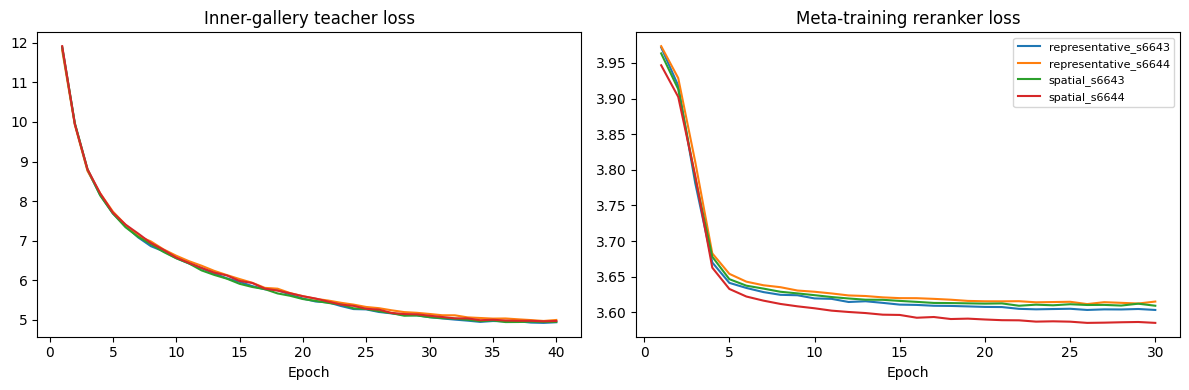

Retained: False | gates: {'6643': False, '6644': False} | retain_original_fusion
Total new fitting: 309.26 seconds; no encoder extraction or test inference.


In [33]:
# Cell 120 — Saved learned-reranker results and training progress.
def learned_rerank_dashboard():
    pointer=LEARNED_RERANK_HOME/'latest.json'
    if not pointer.exists():print('No completed learned candidate study yet.');return
    link=json.loads(pointer.read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Learned decision checksum changed.')
    report=json.loads((ROOT/link['decision']).read_text());table=pd.DataFrame(report['records'])
    display(table[['method','split','seed','score','mean_km','median_km','p90_km','borough_macro_f1','fraction_over_10km','fraction_over_20km']])
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for directory in sorted((ROOT/report['directory']).glob('*_s*')):
        if not (directory/'teacher_history.json').exists():continue
        teacher=json.loads((directory/'teacher_history.json').read_text());reranker=json.loads((directory/'reranker_history.json').read_text())
        axes[0].plot([r['epoch'] for r in teacher],[r['loss'] for r in teacher],label=directory.name)
        axes[1].plot([r['epoch'] for r in reranker],[r['loss'] for r in reranker],label=directory.name)
    axes[0].set(title='Inner-gallery teacher loss',xlabel='Epoch');axes[1].set(title='Meta-training reranker loss',xlabel='Epoch')
    axes[1].legend(fontsize=8);fig.tight_layout();plt.show()
    print('Retained:',report['retained'],'| gates:',report['seed_pass'],'|',report['decision'])
    print('Total new fitting:',round(report['fit_seconds'],2),'seconds; no encoder extraction or test inference.')
    return report

LEARNED_RERANK_SAVED=learned_rerank_dashboard()


In [34]:
# Cell 121 — Strict artifact checks; all replay uses cached features, never test images.
def audit_learned_reranker(replay=False):
    import platform,sys
    started=time.monotonic()
    pointer=LEARNED_RERANK_HOME/'latest.json'
    require(pointer.exists(),'Finish the bounded learned-reranker study before auditing.')
    link=json.loads(pointer.read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Decision checksum drift.')
    result=json.loads((ROOT/link['decision']).read_text());identity=learned_rerank_identity()
    require(result['identity']==identity,'Learned source/config/data identity drift.')
    frame,splits,street,dino,_,_=fusion_sources();directory=ROOT/result['directory'];checks=[];diagnostics=[]
    def check(condition,message):
        require(bool(condition),message);checks.append(message)
    check(len(result['records'])==8,'Eight complete original/learned validation records')
    check(identity['config']['metric_version']==CURRENT_METRIC_VERSION,'Current v2 metric in identity')
    fit_sum=0.;peak=0
    for seed in (6643,6644):
        for split_name in ('representative','spatial'):
            run=directory/f'{split_name}_s{seed}';plan=learned_rerank_plan(frame,splits,split_name)
            check(json.loads((run/'plan.json').read_text())==plan,f'{run.name}: fixed outer and inner ID plan')
            teacher=torch.load(run/'teacher.pth',map_location='cpu',weights_only=True)
            head=torch.load(run/'reranker.pth',map_location='cpu',weights_only=True)
            check(teacher['identity']==head['identity']==identity,f'{run.name}: checkpoint identities')
            check(teacher['train_ids']==plan['teacher_train_ids'] and teacher['meta_query_ids']==plan['meta_query_ids'],f'{run.name}: teacher excludes query/validation labels')
            check(head['training_query_ids']==plan['meta_query_ids'] and head['training_reference_ids']==plan['teacher_train_ids'],f'{run.name}: reranker uses only inner training pairs')
            for stage,epochs,limit,key in [('teacher',40,180,'checkpoint_sha256'),('reranker',30,60,'sha256')]:
                status=json.loads((run/f'{stage}_status.json').read_text());history=json.loads((run/f'{stage}_history.json').read_text())
                check(status['status']=='complete' and status['completed_epochs']==epochs and len(history)==epochs,f'{run.name}: {stage} fixed epochs complete')
                check(status[key]==sha256(run/f'{stage}.pth'),f'{run.name}: {stage} file hash')
                check(status['elapsed_seconds']<=limit,f'{run.name}: {stage} time cap')
                check(np.isfinite([h['loss'] for h in history]).all(),f'{run.name}: {stage} finite losses')
                if stage=='teacher':check(all(h['unique_anchor_locations']==len(plan['teacher_train_ids']) for h in history),f'{run.name}: complete teacher anchor coverage')
                fit_sum+=status['elapsed_seconds'];peak=max(peak,max(h['driver_bytes'] for h in history))
            with np.load(run/'training_pairs.npz') as saved:
                values=saved['features'];distance=saved['distance_km'];neighbors=saved['neighbors'];saved_cosine=saved['cosine']
                check(saved['query_ids'].tolist()==plan['meta_query_ids'] and saved['reference_ids'].tolist()==plan['teacher_train_ids'],f'{run.name}: pair source alignment')
                check(head['training_pair_hash']==hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest() and head['training_target_hash']==hashlib.sha256(np.ascontiguousarray(distance).tobytes()).hexdigest(),f'{run.name}: training feature/target hashes')
                check(values.shape==(2048,32,39) and np.isfinite(values).all(),f'{run.name}: finite bounded training pair schema')
                expected_mean=values.astype(np.float64).mean((0,1)).astype(np.float32)
                expected_std=np.maximum(values.astype(np.float64).std((0,1)),.05).astype(np.float32)
                check(np.array_equal(head['state_dict']['feature_mean'].numpy(),expected_mean) and np.array_equal(head['state_dict']['feature_std'].numpy(),expected_std),f'{run.name}: normalization from meta training pairs only')
                true_gps=frame.loc[plan['meta_query_ids'],['latitude','longitude']].to_numpy()
                candidate_gps=frame.loc[plan['teacher_train_ids'],['latitude','longitude']].to_numpy()[neighbors]
                expected_distance=haversine_km(np.repeat(true_gps,32,axis=0),candidate_gps.reshape(-1,2)).reshape(2048,32).astype(np.float32)
                check(np.array_equal(distance,expected_distance),f'{run.name}: training-only GPS targets')
            # This measures the fitted ranking proxy, not held-out geolocation.
            fitted=PairResidualReranker(head['state_dict']['feature_mean'],head['state_dict']['feature_std'])
            fitted.load_state_dict(head['state_dict'],strict=True);fitted.eval();residual=[]
            with torch.inference_mode():
                for start in range(0,len(values),128):residual.append(fitted(torch.as_tensor(values[start:start+128])).numpy())
            residual=np.concatenate(residual);base=(saved_cosine-saved_cosine.max(1,keepdims=True))/.05
            proxy={}
            for method,logits in [('original',base),('learned',base+residual)]:
                weights=np.exp(logits-logits.max(1,keepdims=True));weights/=weights.sum(1,keepdims=True)
                proxy[method+'_expected_candidate_distance_km']=float((weights*distance).sum(1).mean())
            diagnostics.append({'kind':'in_sample_meta_ranking_proxy','seed':seed,'split':split_name,'diagnostic_only':True,**proxy})
            del fitted,residual
            train_position=frame.index.get_indexer(plan['teacher_train_ids'])
            sm,ss=dino_statistics(street[train_position]);dm,ds=dino_statistics(dino[train_position])
            for name,expected in [('street_mean',sm),('street_std',ss),('dino_mean',dm),('dino_std',ds)]:
                check(np.array_equal(teacher['state_dict'][name].numpy(),expected),f'{run.name}: {name} from inner gallery only')
            expected_geo=fit_geography(frame.loc[plan['teacher_train_ids']],cells=512)
            for key in ('origin','scales','centers','borough_weights'):
                check(np.array_equal(np.asarray(teacher['geography'][key]),np.asarray(expected_geo[key])),f'{run.name}: training-only geography {key}')
            records={r['method']:r for r in result['records'] if r['seed']==seed and r['split']==split_name}
            check(all(sha256(ROOT/r['source_checkpoint'])==r['source_sha256'] for r in records.values()),f'{run.name}: original source head checksums')
            truth=frame.loc[plan['outer_validation_ids']]
            for method,record in records.items():
                prediction=pd.read_csv(ROOT/record['prediction']);validate_predictions(prediction,truth.sample_id)
                check(sha256(ROOT/record['prediction'])==record['prediction_sha256'],f'{run.name}: {method} predictions intact')
                metrics=score_current_predictions(truth,prediction)
                check(all(np.isclose(record[k],metrics[k],rtol=0,atol=1e-10) for k in ('score','mean_km','median_km','p90_km','borough_macro_f1')),f'{run.name}: {method} v2 metrics replay')
            if replay:
                device=dino_device();source=records['original']
                source_link=json.loads((FUSION_HOME/'latest.json').read_text());source_result=json.loads((ROOT/source_link['decision']).read_text())
                base,base_saved=fusion_model_load(ROOT/source['source_checkpoint'],source_result['identity'],device)
                try:bundle=build_learned_pair_bundle(frame,street,dino,plan['outer_train_ids'],plan['outer_validation_ids'],base,base_saved['geography'],device)
                finally:del base;dino_release(device)
                model=PairResidualReranker(head['state_dict']['feature_mean'],head['state_dict']['feature_std']).to(device);model.load_state_dict(head['state_dict'],strict=True)
                try:
                    for method,network in [('original',None),('learned',model)]:
                        actual=decode_learned_bundle(frame.loc[plan['outer_train_ids']],bundle,network,device)
                        saved_prediction=pd.read_csv(ROOT/records[method]['prediction'])
                        check(actual.borough.tolist()==saved_prediction.borough.tolist() and np.allclose(actual[['latitude','longitude']],saved_prediction[['latitude','longitude']],rtol=0,atol=2e-7),f'{run.name}: all {method} GPS/borough predictions replayed')
                finally:del model;dino_release(device)
                nearest=bundle['distance_km'].min(1)
                diagnostics.append({'kind':'validation_candidate_coverage','seed':seed,'split':split_name,'queries':len(truth),'diagnostic_only':True,
                    'oracle_top32_mean_km':float(nearest.mean()),'oracle_top32_median_km':float(np.median(nearest)),
                    **{f'top32_recall_within_{r}km':float((nearest<=r).mean()) for r in (.25,.5,1.)}})
                del bundle
    ledger=json.loads((directory/'fit_budget.json').read_text())
    check(np.isclose(fit_sum,ledger['fit_seconds'],rtol=0,atol=1e-8) and fit_sum<=1200,'Aggregate fit ledger and twenty-minute cap')
    for seed in (6643,6644):
        candidate={r['split']:r for r in result['records'] if r['method']=='learned' and r['seed']==seed}
        control={r['split']:r for r in result['records'] if r['method']=='original' and r['seed']==seed}
        check(result['seed_pass'][str(seed)]==passes_current_development_guard(candidate,control),f'Seed {seed}: predeclared distance/score guard replay')
    check(result['retained']==all(result['seed_pass'].values()),'Final retention decision uses both seeds')
    for path,digest in [('Kaggle Submissions/nycguessr_fusion40_20261117.csv','075d86f3a426872c50f2b970d01b6cdb51319f6f102837dbd445a1019740ed3b'),('Kaggle Submissions/nycguessr_streetclip40_20261116.csv','c065fb05a3f31c9195f4132f726c2f6c7d1b52195b831dcc59dbe877e33dc35f')]:
        check(sha256(ROOT/path)==digest,f'Existing submission preserved: {path}')
    verification={'status':'passed','metric_version':CURRENT_METRIC_VERSION,'checks_passed':len(checks),'checks':checks,
                  'all_validation_predictions_replayed':bool(replay),'fit_seconds':fit_sum,'sampled_peak_driver_bytes':peak,
                  'decision_sha256':link['sha256'],'diagnostics':diagnostics,'test_inference':False,'elapsed_seconds':time.monotonic()-started,
                  'runtime':{'python':sys.version.split()[0],'torch':torch.__version__,'numpy':np.__version__,'platform':platform.platform(),'device':str(dino_device())}}
    dino_json(directory/('verification_replay.json' if replay else 'verification.json'),verification)
    print('Learned-reranker artifact checks passed:',len(checks),'Full replay:',replay)
    if diagnostics:display(pd.DataFrame(diagnostics))
    return verification

RUN_LEARNED_AUDIT=os.environ.get('NYCGUESSR_LEARNED_AUDIT','0')=='1'
if RUN_LEARNED_AUDIT:LEARNED_RERANK_VERIFICATION=audit_learned_reranker(replay=os.environ.get('NYCGUESSR_LEARNED_REPLAY','0')=='1')
else:print('Learned-reranker artifact/replay audit disabled by default.')


Learned-reranker artifact/replay audit disabled by default.


## Learned reranker result — rejected, 2026-11-18

All four fixed teacher/reranker fits completed on **MPS**. Each teacher used only its inner training gallery for 40 epochs; each residual MLP used 2,048 teacher-unseen training queries for 30 epochs. Outer validation labels were used only after fitting. No encoder/image extraction, external data, downloads, test inference or submission change occurred.

| Seed | Validation | Original v2 | Reranker v2 | Original mean km | Reranker mean km |
|---|---|---:|---:|---:|---:|
| 6643 | Representative | .346004 | .334822 | 3.543432 | 3.605552 |
| 6643 | Spatial | .077237 | .077237 | 5.530323 | 5.619461 |
| 6644 | Representative | .351532 | .346185 | 3.512208 | 3.541910 |
| 6644 | Spatial | .076302 | .076302 | 5.645370 | 5.689019 |

**Decision: retain the original fusion model and existing CSV.** Both seeds fail the predeclared score/distance guard. Unchanged spatial scores reflect GPS clipping above 5 km, not unchanged errors. Borough predictions were intentionally held fixed. Full F1, mean/median/p90, borough-wise errors, >5/10/20-km tails and paired block-bootstrap intervals are saved in the decision report and displayed above. Primary mean-error-reduction 95% intervals are **[-.10499, -.02035] km** representative and **[-.14635, -.04110] km** spatial; these indicate deterioration on reused development data, not independent-test evidence.

The saved training ranking proxy improves (representative expected candidate distance 4.984→4.806 km; spatial 4.889→4.815 km), but final decoded GPS error worsens. These proxy values are **in-sample reranker diagnostics**. A loss/decoder mismatch or teacher-to-final-head shift is a hypothesis, not an established cause.

Validation candidate coverage is informative: seed 6643 top-32 candidates include a location within 1 km for **91.99% / 67.08%** of representative/spatial queries. Oracle nearest-candidate mean errors are **.547 / 1.519 km**; seed 6644 gives **.519 / 1.549 km**. These use validation truth for diagnosis only; an oracle is not a valid predictor, achievable score claim or mathematical lower bound on an interpolated coordinate decoder. Candidate coverage suggests testing selection/decoding before another expensive encoder pass.

**Single next proposed experiment:** keep the candidate bank, features, teacher partitions and model fixed, and replace the pair-ranking proxy with a differentiable final-coordinate distance objective. This tests objective alignment directly. Do not treat this proposal as implemented or start an unbounded search.

Fitting used **309.2587 s (5.15 min)** under the 20-minute cap; complete study execution **397.2470 s**. Sampled peak MPS driver allocation **1.08 GiB** (not a continuous peak measurement). All eight fits completed their fixed epochs with finite losses. **8 inline tests and 140 artifact checks passed**, including training-only statistics/geography/IDs/targets, budgets, hashes, guard decisions, both unchanged CSVs, and all four original/learned validation predictions replayed after strict checkpoint reload. Full replay was a **34-code-cell targeted fresh-kernel execution, 49.89 s, zero errors**, not a historical Run All.

Evidence: `outputs/learned_rerank/latest.json`, its linked `decision.json`, per-run plans/configs/histories/pairs/checkpoints, `verification_replay.json`, and phase execution records. Active code is in cells **115–121**, saved metrics/curves in **120**, and the audit summary below. All real fitting/audit flags default off. The existing fusion public score remains unknown under v2; .60599 is the historical v1 StreetCLIP result. No new CSV or Kaggle upload.

Final fitting/audit-disabled fresh-kernel check: **35 code cells, 8 inline tests, zero errors, 3.98 s**. Earlier full-replay evidence remains in `notebook_replay_execution.json` and the saved audit summary. All original source cells1–113 remain unchanged.


In [35]:
# Cell 123 — Persistent verification and diagnostic summary; no fitting or inference.
if (LEARNED_RERANK_HOME/'latest.json').exists():
    saved_link=json.loads((LEARNED_RERANK_HOME/'latest.json').read_text())
    require(sha256(ROOT/saved_link['decision'])==saved_link['sha256'],'Saved learned decision drift.')
    saved_decision=json.loads((ROOT/saved_link['decision']).read_text())
    audit_path=ROOT/saved_decision['directory']/'verification_replay.json'
    if audit_path.exists():
        saved_audit=json.loads(audit_path.read_text())
        require(saved_audit['decision_sha256']==saved_link['sha256'] and saved_audit['status']=='passed','Audit/decision mismatch.')
        print('Completed artifact checks:',saved_audit['checks_passed'],'| full validation replay:',saved_audit['all_validation_predictions_replayed'])
        print('Device:',saved_audit['runtime']['device'],'| fit seconds:',round(saved_audit['fit_seconds'],2),'| sampled driver GiB:',round(saved_audit['sampled_peak_driver_bytes']/2**30,2))
        display(pd.DataFrame(saved_audit['diagnostics']))
        print('Next proposed experiment: final-coordinate GPS loss with fixed candidates/features/teacher partitions; not executed.')


Completed artifact checks: 140 | full validation replay: True
Device: mps | fit seconds: 309.26 | sampled driver GiB: 1.08


,kind,seed,split,diagnostic_only,original_expected_candidate_distance_km,learned_expected_candidate_distance_km,queries,oracle_top32_mean_km,oracle_top32_median_km,top32_recall_within_0.25km,top32_recall_within_0.5km,top32_recall_within_1.0km
0,in_sample_meta_ranking_proxy,6643,representative,True,4.983919,4.806055,NaN,NaN,NaN,NaN,NaN,NaN
1,validation_candidate_coverage,6643,representative,True,NaN,NaN,2372.0,0.546743,0.141020,0.749157,0.872681,0.919899
2,in_sample_meta_ranking_proxy,6643,spatial,True,4.889399,4.814912,NaN,NaN,NaN,NaN,NaN,NaN
3,validation_candidate_coverage,6643,spatial,True,NaN,NaN,2421.0,1.518915,0.699220,0.056588,0.342007,0.670797
4,in_sample_meta_ranking_proxy,6644,representative,True,5.125101,4.945232,NaN,NaN,NaN,NaN,NaN,NaN
5,validation_candidate_coverage,6644,representative,True,NaN,NaN,2372.0,0.519157,0.141028,0.742833,0.867622,0.930860
6,in_sample_meta_ranking_proxy,6644,spatial,True,4.903338,4.735258,NaN,NaN,NaN,NaN,NaN,NaN
7,validation_candidate_coverage,6644,spatial,True,NaN,NaN,2421.0,1.549259,0.705948,0.057827,0.324246,0.670797


Next proposed experiment: final-coordinate GPS loss with fixed candidates/features/teacher partitions; not executed.


## Retained fusion score and submission re-export — 2026-11-18

The user requests the current local score and a submission CSV. The learned reranker was rejected at both seeds, so use the retained primary-seed fusion model. Recompute current 5-km validation scores from the original saved validation predictions; the historical full-data fit has no held-out score. Strictly load its existing 40-epoch/all-11,864-label checkpoint and complete hashed train/test feature caches, replay inference, export a new dated CSV, and verify official headers/IDs, boroughs, finite coordinates and read-back parity. Preserve earlier CSVs. This is a re-export of the retained model, not a new training result or expected leaderboard improvement. No fitting, downloads, image passes or Kaggle upload. Cached inference has a 180-second cap. All active code stays below, and real export defaults off.


In [27]:
# Cell 125 — Current-metric scores and cached full-model submission re-export.
def reexport_retained_fusion():
    started=time.monotonic();seed_everything(6643)
    selected,source,decision_sha=fusion_submission_source()
    frame,splits,street,dino,train_ledger,_=fusion_sources();_,template=load_data(ROOT)
    rerank_link=json.loads((ROOT/'outputs/learned_rerank/latest.json').read_text())
    require(sha256(ROOT/rerank_link['decision'])==rerank_link['sha256'],'Reranker selection checksum changed.')
    rerank_decision=json.loads((ROOT/rerank_link['decision']).read_text())
    require(not rerank_decision['retained'],'Revisit model selection: this export excludes the rejected reranker.')
    scores=[]
    for record in selected['records']:
        if record['variant']!='fusion_random':continue
        validation=pd.read_csv((ROOT/record['checkpoint']).parent/'validation_best.csv')
        require(sha256(ROOT/record['checkpoint'])==record['checkpoint_sha256'],'Validation source head changed.')
        metrics=score_current_predictions(frame.loc[splits['splits'][record['split']]['validation_ids']],validation)
        scores.append({'split':record['split'],'seed':record['seed'],**metrics})
    prior=json.loads((FUSION_SUBMISSION_HOME/'manifest.json').read_text())
    checkpoint=ROOT/prior['checkpoint']
    require(sha256(checkpoint)==prior['checkpoint_sha256'],'Full-data checkpoint checksum changed.')
    require(prior['refit_identity']==fusion_refit_identity(selected,source,decision_sha),'Full-data fit implementation drift.')
    benchmark=json.loads((DINO_HOME/'benchmark.json').read_text())
    test_dino,test_ledger=dino_read_cache('test',official_test_frame(template),benchmark)
    require(test_ledger['sha256']==prior['test_dino_sha256'],'Test DINO cache identity changed.')
    test_street=fusion_test_street_cache(template)
    old_csv=ROOT/prior['csv'];require(sha256(old_csv)==prior['csv_sha256'],'Original fusion CSV changed.')
    device=dino_device();model,saved=fusion_model_load(checkpoint,selected['identity'],device)
    try:
        require(saved['fit_complete'] and saved['epoch']==40 and saved['train_ids']==frame.sample_id.tolist()
                and saved['validation_ids']==[] and saved['metrics']=={},'Invalid all-label checkpoint scope.')
        prediction=fusion_namespaced_prediction(model,saved['geography'],frame,template,street,dino,test_street,test_dino,device)
        require(time.monotonic()-started<=180,'Cached submission replay exceeded its three-minute cap.')
        previous=pd.read_csv(old_csv)
        require(prediction.borough.tolist()==previous.borough.tolist(),'Original borough replay differs.')
        np.testing.assert_allclose(prediction[['latitude','longitude']],previous[['latitude','longitude']],rtol=0,atol=1e-8)
        path=ROOT/'Kaggle Submissions/nycguessr_fusion40_20261118.csv'
        if path.exists():
            restored=pd.read_csv(path);validate_predictions(restored,template.sample_id.to_numpy())
            require(restored.borough.tolist()==prediction.borough.tolist(),'Existing dated CSV labels differ.')
            np.testing.assert_allclose(restored[['latitude','longitude']],prediction[['latitude','longitude']],rtol=0,atol=1e-8)
        else:export_submission(prediction,template,path)
        restored=pd.read_csv(path);validate_predictions(restored,template.sample_id.to_numpy())
        require(list(restored.columns)==list(template.columns) and restored.sample_id.tolist()==template.sample_id.tolist(),'CSV official header/ID order mismatch.')
        difference=float(np.abs(restored[['latitude','longitude']].to_numpy()-prediction[['latitude','longitude']].to_numpy()).max())
        require(difference<=1e-8 and sha256(old_csv)==prior['csv_sha256'],'Read-back parity or old CSV preservation failed.')
        report={'status':'ready_for_manual_kaggle_upload','metric_version':CURRENT_METRIC_VERSION,'model':'fusion_random',
            'csv':str(path.relative_to(ROOT)),'rows':len(restored),'csv_bytes':path.stat().st_size,'csv_sha256':sha256(path),
            'checkpoint':prior['checkpoint'],'checkpoint_sha256':prior['checkpoint_sha256'],'full_data_epochs':40,'training_locations':11864,
            'full_data_fit_has_heldout_score':False,'validation_scores':scores,'decision_sha256':decision_sha,
            'train_cache_sha256':train_ledger['sha256'],'test_dino_sha256':test_ledger['sha256'],
            'street_test_sha256':'b6870dc542cdfd23cc701572da74fe5b239dec0088eee90679a539c9bcb39695',
            'previous_csv':prior['csv'],'previous_csv_sha256':prior['csv_sha256'],
            'byte_identical_to_previous':sha256(path)==prior['csv_sha256'],'all_predictions_replayed':True,
            'maximum_serialization_difference_deg':difference,'device':str(device),'elapsed_seconds':time.monotonic()-started,
            'new_training':False,'new_image_extraction':False,'reranker_included':False,'public_score':None,'kaggle_uploaded':False}
        directory=ROOT/'outputs/fusion/submission_20261118';directory.mkdir(parents=True,exist_ok=True)
        dino_json(directory/'manifest.json',report)
        record_run(ROOT,'fusion_reexport_20261118','fusion_random','test',{},
                   {'metric_version':CURRENT_METRIC_VERSION,'checkpoint_sha256':prior['checkpoint_sha256'],'reranker_included':False},
                   report['elapsed_seconds'],{'csv':report['csv'],'manifest':str((directory/'manifest.json').relative_to(ROOT))},
                   'Retained fusion re-export; no retraining or Kaggle upload.')
        print('Generated',report['csv'],'| rows',report['rows'],'| identical to previous',report['byte_identical_to_previous'])
        display(pd.DataFrame(scores)[['split','seed','score','mean_km','median_km','p90_km','borough_macro_f1']])
        return report
    finally:del model;dino_release(device)

RUN_RETAINED_FUSION_EXPORT=os.environ.get('NYCGUESSR_RETAINED_FUSION_EXPORT','0')=='1'
if RUN_RETAINED_FUSION_EXPORT:RETAINED_FUSION_EXPORT=reexport_retained_fusion()
else:print('Retained fusion submission re-export disabled by default.')


Generated Kaggle Submissions/nycguessr_fusion40_20261118.csv | rows 7908 | identical to previous True


,split,seed,score,mean_km,median_km,p90_km,borough_macro_f1
0,representative,6643,0.346004,3.543432,1.170501,10.405028,0.838217
1,spatial,6643,0.077237,5.530323,2.805487,14.019978,0.772372
2,representative,6644,0.351532,3.512208,1.197510,10.084168,0.837290
3,spatial,6644,0.076302,5.645370,2.834758,14.215357,0.763019


### Retained fusion CSV completed — 2026-11-18

Generated `Kaggle Submissions/nycguessr_fusion40_20261118.csv`: **7,908 rows**, exact official headers and ID order, **302,110 bytes**, SHA-256 `075d86f3a426872c50f2b970d01b6cdb51319f6f102837dbd445a1019740ed3b`. Strict existing all-label checkpoint replay and CSV read-back passed. It is byte-identical to the previous fusion CSV because no new model passed the retention guard. No retraining, image extraction, downloads or upload occurred. Targeted fresh-kernel execution: **27 code cells, zero errors, 15.61 s**; not historical Run All. Evidence: `outputs/fusion/submission_20261118/manifest.json` and `notebook_export_execution.json`.

Current local primary scores: **.346003940 representative / .077237245 spatial**, mean **3.543432 / 5.530323 km**. These use the current 5-km metric; corresponding historical local 10-km scores were **.664912829 / .479508151** for identical predictions. Spatial GPS is now clipped to zero. The .60599 user-reported public result belongs to the older StreetCLIP submission under the old metric; its rescored public result is unknown. The rejected reranker separately worsened the primary representative score to .334822371 and is excluded from this CSV.

Observed reranker failure: lower in-sample pair-ranking loss did not yield lower final decoded coordinate error. The fixed geographic-cell/neighbor geometric-median decoder is nonlinear, so the proxy and final distance objectives differ; teacher-to-final-head feature shift is another possible factor. Neither explanation has been isolated experimentally. Next proposed task remains a controlled final-coordinate-loss reranker ablation. Manual upload of this byte-identical re-export is optional if the same fusion predictions were already submitted; no changed leaderboard result is expected from renaming a file.


## Public-score reconciliation and progress diagnosis — 2026-11-18

The user reports **about0.42 public leaderboard score for the latest fusion CSV, after the 5-km metric update**. This is a user-reported, rounded result, not an API-verified exact score. Both dated fusion CSVs have the same bytes/hash. The local representative .346004 is measured on a different validation set with a fold-trained model; the full submission uses all11,864 labels and a different test set. Comparing these as successive public scores was incorrect. No new public-score decline has been established, and an unchanged CSV cannot create a new model improvement. The earlier .60599 public StreetCLIP result uses the old10-km metric and a different model; it is not a fair public baseline without its rescored value.

The analysis below reads only saved labeled validation predictions and diagnostics. It records current 5-km scores, outlier concentration, borough-error association, training versus validation distance, candidate recall, and where the rejected reranker changes errors. Training diagnostics are in-sample despite self-excluded retrieval; associations are not causal proof. No training, GPU inference, new data, uploads or prediction changes. Raw old-metric source logs remain immutable.

The leading measured problems are large cross-region errors, weak ordering of otherwise useful candidates, and poor generalization to spatially held-out locations. A mismatch between pair-ranking training loss and final decoded GPS loss is a supported hypothesis for the reranker failure; teacher-to-final-head feature shift is also possible and has not been isolated. Frozen global/four-region representations may lack fine instance detail, but these audits do not establish pretrained weights or GPU capacity as the main bottleneck. Recent encoder/reranking trials failed their retention gates; they are negative experiments, not accumulated leaderboard gains.

**Single next proposed experiment:** hold candidates, features, model and teacher partitions fixed and change only the reranker objective to final decoded coordinate distance. Measure final mean error and outlier shares on both folds/seeds; retain only a measured gain. This isolates objective alignment before spending on dense matching or encoder fine-tuning. No new modeling experiment is started by this diagnosis.


In [21]:
# Cell 128 — CPU-only evidence audit and reconciled user-reported public result.
def audit_fusion_progress():
    frame,_=load_data(ROOT);rows=[];comparisons=[]
    fusion_link=json.loads((ROOT/'outputs/fusion/latest.json').read_text())
    require(sha256(ROOT/fusion_link['decision'])==fusion_link['sha256'],'Fusion decision changed.')
    fusion=json.loads((ROOT/fusion_link['decision']).read_text())
    rerank_link=json.loads((ROOT/'outputs/learned_rerank/latest.json').read_text())
    require(sha256(ROOT/rerank_link['decision'])==rerank_link['sha256'],'Reranker decision changed.')
    rerank=json.loads((ROOT/rerank_link['decision']).read_text())
    for record in fusion['records']:
        if record['variant']!='fusion_random' or record['seed']!=6643:continue
        directory=(ROOT/record['checkpoint']).parent;path=directory/'validation_best.csv'
        predicted=pd.read_csv(path);truth=frame.loc[predicted.sample_id]
        metrics=score_current_predictions(truth,predicted)
        errors=haversine_km(truth[['latitude','longitude']],predicted[['latitude','longitude']])
        wrong=truth.borough.to_numpy()!=predicted.borough.to_numpy();far=errors>10
        worst=np.argsort(-errors,kind='stable')[:int(np.ceil(.1*len(errors)))]
        details=json.loads((directory/'diagnostics.json').read_text())
        train=next(d for d in details if d['scope']=='train_in_sample_self_excluded')
        validation=next(d for d in details if d['scope']=='validation')
        query=pd.read_csv(directory/'queries_validation.csv')
        require(query.sample_id.tolist()==predicted.sample_id.tolist(),'Saved candidate/validation ID alignment changed.')
        row={'split':record['split'],'seed':6643,'prediction':str(path.relative_to(ROOT)),'prediction_sha256':sha256(path),**metrics,
            'training_in_sample_mean_km':train['mean_km'],'wrong_borough_fraction':float(wrong.mean()),
            'correct_borough_mean_km':float(errors[~wrong].mean()),'wrong_borough_mean_km':float(errors[wrong].mean()),
            'wrong_borough_share_total_error':float(errors[wrong].sum()/errors.sum()),
            'over10km_count':int(far.sum()),'over10km_wrong_borough_fraction':float(wrong[far].mean()),
            'worst_decile_share_total_error':float(errors[worst].sum()/errors.sum()),
            'candidate_recall_top1_within1km':validation['recall_top1_1.0km'],
            'candidate_recall_top32_within1km':validation['recall_top32_1.0km']}
        rows.append(row)
        learned_record=next(r for r in rerank['records'] if r['method']=='learned' and r['split']==record['split'] and r['seed']==6643)
        learned=pd.read_csv(ROOT/learned_record['prediction'])
        require(learned.sample_id.tolist()==predicted.sample_id.tolist() and learned.borough.tolist()==predicted.borough.tolist(),'Reranker scope/class labels changed.')
        learned_error=haversine_km(truth[['latitude','longitude']],learned[['latitude','longitude']])
        for group,mask in [('all',np.ones(len(errors),bool)),('original_wrong_borough',wrong),('original_correct_borough',~wrong),('original_over10km',far)]:
            comparisons.append({'split':record['split'],'group':group,'count':int(mask.sum()),
                'original_mean_km':float(errors[mask].mean()),'learned_mean_km':float(learned_error[mask].mean()),
                'mean_error_change_km':float((learned_error-errors)[mask].mean())})
    paths=[ROOT/'Kaggle Submissions'/f'nycguessr_fusion40_{day}.csv' for day in ('20261117','20261118')]
    hashes=[sha256(p) for p in paths]
    require(hashes[0]==hashes[1]=='075d86f3a426872c50f2b970d01b6cdb51319f6f102837dbd445a1019740ed3b','Fusion CSVs are no longer identical.')
    public={'score':.42,'approximate':True,'source':'user_report','reported_date':'2026-11-18',
            'metric_version':CURRENT_METRIC_VERSION,'model':'fusion_random','csv_sha256':hashes[0],
            'csvs':[str(p.relative_to(ROOT)) for p in paths],'live_kaggle_verified':False}
    report={'metric_version':CURRENT_METRIC_VERSION,'public_result':public,'validation_diagnostics':rows,
            'reranker_error_changes':comparisons,'new_public_decline_established':False,
            'new_training':False,'new_inference':False,'scope':'Read-only saved-validation analysis; training diagnostic is in-sample and public score is user-reported.'}
    home=ROOT/'outputs/diagnostics';home.mkdir(parents=True,exist_ok=True)
    dino_path=home/'fusion_progress_20261118.json'
    dino_path.write_text(json.dumps(report,indent=2,allow_nan=False)+'\n')
    display(pd.DataFrame(rows)[['split','score','mean_km','median_km','p90_km','training_in_sample_mean_km','wrong_borough_fraction','wrong_borough_share_total_error','worst_decile_share_total_error','candidate_recall_top1_within1km','candidate_recall_top32_within1km']])
    display(pd.DataFrame(comparisons))
    print('Current public score: about0.42 (user report); no new public decline established.')
    print('Both dated fusion CSVs are byte-identical. No training, inference or upload.')
    return report

FUSION_PROGRESS_DIAGNOSIS=audit_fusion_progress()


,split,score,mean_km,median_km,p90_km,training_in_sample_mean_km,wrong_borough_fraction,wrong_borough_share_total_error,worst_decile_share_total_error,candidate_recall_top1_within1km,candidate_recall_top32_within1km
0,representative,0.346004,3.543432,1.170501,10.405028,1.175065,0.154722,0.505894,0.535253,0.489460,0.919899
1,spatial,0.077237,5.530323,2.805487,14.019978,0.986239,0.214787,0.498376,0.410870,0.209418,0.670797


,split,group,count,original_mean_km,learned_mean_km,mean_error_change_km
0,representative,all,2372,3.543432,3.605552,0.062120
1,representative,original_wrong_borough,367,11.585967,11.748876,0.162909
2,representative,original_correct_borough,2005,2.071307,2.114978,0.043671
3,representative,original_over10km,245,18.652811,18.953782,0.300971
4,spatial,all,2421,5.530323,5.619461,0.089137
5,spatial,original_wrong_borough,520,12.832133,12.888657,0.056524
6,spatial,original_correct_borough,1901,3.532984,3.631043,0.098059
7,spatial,original_over10km,373,18.901768,18.834672,-0.067095


Current public score: about0.42 (user report); no new public decline established.
Both dated fusion CSVs are byte-identical. No training, inference or upload.


## Decoder-aware reranker — controlled local GPU study, 2026-11-18

The user asks to solve the diagnosed issues and improve the score. Test the concrete hypothesis that training on final decoded GPS distance transfers better than the rejected pair-ranking proxy. Reuse all four exact inner-gallery teachers, 2,048 meta-query IDs per fold, saved39-feature training pairs, original candidate banks, MLP39→64→32→1, zero initialization, residual bound±4, optimizer/schedule/batch/30epochs and unchanged production decoder. Change only the loss to **mean decoded Haversine km /5 +.001 residual-square regularization**. GPS is a training target only; geographic candidate points/cell centers are fitted on each inner gallery, never outer validation. No new teacher fitting, encoder pass, weights, dependencies or external data.

A60-step differentiable Weiszfeld unroll mirrors the existing bounded geometric median, retaining30cell candidates,32neighbors and fixed50/50mass. Compute Haversine via local-plane differences to preserve FP32 precision. Validate CPU production parity, MPS forward/backward and finite-difference gradients before fitting. The loss uses raw mean distance (without zeroing gradients beyond5km), matching the physical optimization target. Its numerical zero-distance floor is0.127m and is excluded from reported metrics; final evaluation uses the original NumPy/Haversine scorer.

Run each original fold at seeds6643/6644. Fixed30epochs;180s per fit,720s cumulative fitting; pair construction retains its600s cap. Evaluate complete outer folds only after fixed fitting; no validation epoch selection. Retain only representative v2 gain≥.002 and mean reduction≥.05km on both folds at both seeds. Report uncertainty, borough-wise mean errors, median/p90, >5/10/20km tails and wrong-borough errors. Preserve all previous artifacts and public≈.42 as a rounded user-reported observation, not a score forecast. No test predictions or Kaggle upload during this controlled study. A failed gate triggers a documented decision, not an unbounded hyperparameter sweep.


In [32]:
# Cell 130 — Bounded differentiable form of the existing geographic decoder.
DECODED_RERANK_HOME=ROOT/'outputs/decoded_rerank'
DECODED_RERANK_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'epochs':30,'batch_queries':128,
    'learning_rate':.001,'weight_decay':.01,'residual_penalty':.001,'median_iterations':60,
    'fit_seconds':180.,'aggregate_fit_seconds':720.,'seeds':[6643,6644],
    'meta_queries':2048,'tag':'final_coordinate_haversine_v1','change':'loss_only'}

def torch_weighted_median(points,weights,iterations=60):
    """Fixed, bounded Weiszfeld unroll; no early-stop branch in its gradient graph."""
    require(points.ndim==3 and points.shape[-1]==2 and weights.shape==points.shape[:2],'Torch decoder shape.')
    require(len(points)<=128 and points.shape[1]<=128 and 1<=iterations<=60,'Torch decoder compute cap.')
    weights=weights/weights.sum(1,keepdim=True)
    center=(points*weights.unsqueeze(-1)).sum(1)
    for _ in range(iterations):
        distance=torch.linalg.vector_norm(points-center.unsqueeze(1),dim=-1).clamp_min(1e-5)
        scaled=weights/distance
        center=(points*scaled.unsqueeze(-1)).sum(1)/scaled.sum(1,keepdim=True)
    return center

def torch_decoded_haversine_km(predicted_xy,target_xy,origin_latitude_deg):
    """Haversine using local-plane differences to avoid absolute-GPS cancellation."""
    origin=torch.as_tensor(origin_latitude_deg*np.pi/180,dtype=predicted_xy.dtype,device=predicted_xy.device)
    actual_lat=origin+target_xy[:,0]/EARTH_RADIUS_KM
    predicted_lat=origin+predicted_xy[:,0]/EARTH_RADIUS_KM
    delta_lat=(predicted_xy[:,0]-target_xy[:,0])/EARTH_RADIUS_KM
    delta_lon=(predicted_xy[:,1]-target_xy[:,1])/(EARTH_RADIUS_KM*torch.cos(origin))
    value=torch.sin(delta_lat/2).square()+torch.cos(actual_lat)*torch.cos(predicted_lat)*torch.sin(delta_lon/2).square()
    return 2*EARTH_RADIUS_KM*torch.asin(torch.sqrt(value.clamp(1e-16,1-1e-7)))

def decoded_training_geometry(training,bundle,truth):
    """Candidate points from gallery labels; query GPS enters only the target array."""
    require(training.sample_id.tolist()==bundle['reference_ids'].tolist(),'Training gallery alignment.')
    require(truth.sample_id.tolist()==bundle['query_ids'].tolist(),'Target/query alignment.')
    require(not set(training.sample_id)&set(truth.sample_id),'Training geometry self-match.')
    geo=bundle['geography'];xy,origin,scales=coordinates_xy(training[['latitude','longitude']],geo['origin'])
    p=bundle['probability'];top=np.argsort(-p,axis=1,kind='stable')[:,:30]
    mass=np.take_along_axis(p,top,1);mass/=mass.sum(1,keepdims=True)
    points=np.concatenate([np.asarray(geo['centers'])[top],xy[bundle['neighbors']]],axis=1).astype(np.float32)
    targets=((truth[['latitude','longitude']].to_numpy()-origin)*scales).astype(np.float32)
    require(points.shape==(len(truth),62,2) and np.isfinite(points).all() and np.isfinite(targets).all(),'Decoded geometry shape/finite.')
    return points,mass.astype(np.float32),targets

def decoded_rerank_identity():
    previous=json.loads((LEARNED_RERANK_HOME/'latest.json').read_text())
    require(sha256(ROOT/previous['decision'])==previous['sha256'],'Original teacher study checksum changed.')
    return {'config':DECODED_RERANK_CONFIG,'previous_decision_sha256':previous['sha256'],
            'data_fingerprint':data_fingerprint(ROOT),'split_sha256':sha256(ROOT/'outputs/splits.json'),
            'source':dino_definitions_hash(['torch_weighted_median','torch_decoded_haversine_km','decoded_training_geometry',
                'decoded_rerank_identity','load_decoded_training_bundle','fit_decoded_reranker','run_decoded_reranker',
                'PairResidualReranker','decode_learned_bundle','rerank_pair_features','unit_features',
                'FusionGeoHead','FeatureLayerNorm','fusion_outputs','build_learned_pair_bundle','score_current_predictions'])}


In [33]:
# Cell 131 — Training-only bundle reuse and fixed-epoch decoded-distance fitting.
def load_decoded_training_bundle(frame,street,dino,old_directory,plan,old_identity,device):
    status=json.loads((old_directory/'teacher_status.json').read_text())
    teacher_path=old_directory/'teacher.pth'
    require(status['status']=='complete' and sha256(teacher_path)==status['checkpoint_sha256'],'Source teacher drift.')
    teacher,saved=fusion_model_load(teacher_path,old_identity,device)
    require(saved['train_ids']==plan['teacher_train_ids'] and saved['meta_query_ids']==plan['meta_query_ids'],'Source teacher scope drift.')
    with np.load(old_directory/'training_pairs.npz') as pairs:bundle={k:pairs[k] for k in pairs.files}
    require(bundle['query_ids'].tolist()==plan['meta_query_ids'] and bundle['reference_ids'].tolist()==plan['teacher_train_ids'],'Cached pair IDs drift.')
    require(not set(bundle['query_ids'])&set(plan['outer_validation_ids']),'Outer validation in training bundle.')
    positions=frame.index.get_indexer(plan['meta_query_ids'])
    try:probability,borough,_=fusion_outputs(teacher,street[positions],dino[positions],device)
    finally:del teacher;dino_release(device)
    bundle.update(probability=probability,borough=borough.argmax(1),geography=saved['geography'])
    return bundle

def fit_decoded_reranker(frame,bundle,plan,seed,directory,identity,budget):
    directory.mkdir(parents=True,exist_ok=True);path=directory/'reranker.pth';status_path=directory/'status.json'
    if status_path.exists():
        status=json.loads(status_path.read_text());require(status['status']=='complete' and sha256(path)==status['sha256'],'Inspect interrupted/changed decoded fit before retry.')
        saved=torch.load(path,map_location='cpu',weights_only=True);require(saved['identity']==identity,'Decoded fit identity drift.');return path
    values=bundle['features'];mean=values.astype(np.float64).mean((0,1)).astype(np.float32)
    std=np.maximum(values.astype(np.float64).std((0,1)),.05).astype(np.float32)
    points,mass,targets=decoded_training_geometry(frame.loc[plan['teacher_train_ids']],bundle,frame.loc[plan['meta_query_ids']])
    np.savez(directory/'training_geometry.npz',points=points,cell_mass=mass,target_xy_km=targets,
             query_ids=bundle['query_ids'],reference_ids=bundle['reference_ids'],probability=bundle['probability'])
    seed_everything(seed);rng=np.random.default_rng(seed);device=dino_device()
    model=PairResidualReranker(mean,std).to(device)
    x=torch.as_tensor(values,device=device);locations=torch.as_tensor(points,device=device)
    cell_mass=torch.as_tensor(mass,device=device);target=torch.as_tensor(targets,device=device)
    base=torch.as_tensor((bundle['cosine']-bundle['cosine'].max(1,keepdims=True))/.05,device=device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.01)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=30,eta_min=5e-5)
    origin_lat=float(bundle['geography']['origin'][0]);history=[];status={'status':'running'};started=time.monotonic()
    dino_json(directory/'config.json',{'identity':identity,'seed':seed,'plan':plan,
        'loss':'mean final decoded Haversine km /5 +.001 residual square; no CE/expected-candidate proxy',
        'statistics_scope':'2048 meta-query training pairs','outer_validation_used_for_fitting':False})
    try:
        # Forward parity on training queries only, before optimization.
        with torch.inference_mode():
            count=32;w=F.softmax(base[:count],dim=1);weights=torch.cat([.5*cell_mass[:count],.5*w],1)
            forward=torch_weighted_median(locations[:count],weights).cpu().numpy()
            reference=bounded_geometric_median(points[:count],weights.cpu().numpy())
            require(float(np.linalg.norm(forward-reference,axis=1).max())<.001,'MPS/NumPy decoder parity exceeds1m.')
        for epoch in range(1,31):
            model.train();losses=[];order=rng.permutation(len(values))
            for start in range(0,len(order),128):
                elapsed=time.monotonic()-started
                require(elapsed<180 and budget['fit_seconds']+elapsed<720,'Decoded fit/aggregate time cap exceeded.')
                index=torch.as_tensor(order[start:start+128],device=device)
                residual=model(x[index]);neighbor=F.softmax(base[index]+residual,dim=1)
                weights=torch.cat([.5*cell_mass[index],.5*neighbor],dim=1)
                coordinate=torch_weighted_median(locations[index],weights)
                gps_km=torch_decoded_haversine_km(coordinate,target[index],origin_lat).mean()
                penalty=residual.square().mean();loss=gps_km/5+.001*penalty
                require(bool(torch.isfinite(loss)),'Nonfinite decoded GPS loss.')
                optimizer.zero_grad(set_to_none=True);loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True)
                optimizer.step();losses.append([float(v.detach().cpu()) for v in (loss,gps_km,penalty)])
            scheduler.step();averages=np.mean(losses,axis=0)
            history.append({'epoch':epoch,'loss':float(averages[0]),'decoded_training_km':float(averages[1]),
                            'residual_square':float(averages[2]),'elapsed_seconds':time.monotonic()-started,
                            'driver_bytes':dino_memory_guard(device)})
            dino_json(directory/'history.json',history)
            if epoch in (1,10,20,30):print('decoded',plan['split'],seed,'epoch',epoch,'training km',round(averages[1],4),flush=True)
        saved={'identity':identity,'seed':seed,'epochs':30,'metric_version':CURRENT_METRIC_VERSION,
               'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'plan':plan,
               'training_query_ids':bundle['query_ids'].tolist(),'training_reference_ids':bundle['reference_ids'].tolist(),
               'training_pair_hash':hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest(),
               'training_geometry_sha256':sha256(directory/'training_geometry.npz')}
        dino_torch_save(path,saved);status.update(status='complete',sha256=sha256(path))
    except BaseException as error:
        status.update(status='failed',error=str(error));raise
    finally:
        elapsed=time.monotonic()-started;budget['fit_seconds']+=elapsed
        status.update(elapsed_seconds=elapsed,completed_epochs=len(history));dino_json(status_path,status);dino_json(directory.parent/'fit_budget.json',budget)
        del model,optimizer,x,locations,cell_mass,target,base;dino_release(device)
    return path


In [34]:
# Cell 132 — Decoder parity, physical-distance and gradient checks before fitting.
class DecodedRerankerTests(unittest.TestCase):
    def test_median_matches_production_and_has_checked_gradients(self):
        rng=np.random.default_rng(6643);p=rng.normal(size=(2,7,2));w=rng.uniform(.2,1,size=(2,7))
        result=torch_weighted_median(torch.tensor(p,dtype=torch.float64),torch.tensor(w,dtype=torch.float64)).numpy()
        np.testing.assert_allclose(result,bounded_geometric_median(p,w),rtol=0,atol=2e-6)
        weights=torch.tensor(w,dtype=torch.float64,requires_grad=True);points=torch.tensor(p,dtype=torch.float64)
        self.assertTrue(torch.autograd.gradcheck(lambda z:torch_weighted_median(points,z),weights,eps=1e-5,atol=2e-4,rtol=2e-3))

    def test_haversine_matches_official_local_scorer_and_zero_gradients_are_finite(self):
        target=np.array([[40.71,-74.01],[40.83,-73.91],[40.74,-73.99]])
        prediction=np.array([[40.72,-74.03],[40.82,-73.94],[40.74,-73.99]])
        a,origin,scales=coordinates_xy(target);b=(prediction-origin)*scales
        point=torch.tensor(b,dtype=torch.float64,requires_grad=True)
        result=torch_decoded_haversine_km(point,torch.tensor(a,dtype=torch.float64),origin[0])
        np.testing.assert_allclose(result.detach().numpy(),haversine_km(target,prediction),rtol=0,atol=1.3e-4)
        result.sum().backward();self.assertTrue(bool(torch.isfinite(point.grad).all()))

    def test_mps_forward_and_backward_are_finite(self):
        device=dino_device();torch.manual_seed(6643)
        points=torch.randn(8,62,2,device=device);logits=torch.randn(8,62,device=device,requires_grad=True)
        result=torch_weighted_median(points,logits.softmax(1));loss=torch_decoded_haversine_km(result,torch.zeros(8,2,device=device),40.75).mean()
        loss.backward();self.assertTrue(bool(torch.isfinite(logits.grad).all()))
        np.testing.assert_allclose(result.detach().cpu().numpy(),bounded_geometric_median(points.cpu().numpy(),logits.detach().softmax(1).cpu().numpy()),rtol=0,atol=1e-4)
        del points,logits,result,loss;dino_release(device)

decoded_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(DecodedRerankerTests))
require(decoded_tests.wasSuccessful(),'Resolve decoder parity/gradients before fitting.')


test_haversine_matches_official_local_scorer_and_zero_gradients_are_finite (__main__.DecodedRerankerTests.test_haversine_matches_official_local_scorer_and_zero_gradients_are_finite) ... 

ok


test_median_matches_production_and_has_checked_gradients (__main__.DecodedRerankerTests.test_median_matches_production_and_has_checked_gradients) ... 

ok


test_mps_forward_and_backward_are_finite (__main__.DecodedRerankerTests.test_mps_forward_and_backward_are_finite) ... 

ok


----------------------------------------------------------------------
Ran 3 tests in 0.720s

OK


In [35]:
# Cell 133 — Same features/teachers/decoder, changed objective; complete-fold evaluation.
def run_decoded_reranker():
    frame,splits,street,dino,_,_=fusion_sources();identity=decoded_rerank_identity()
    directory=DECODED_RERANK_HOME/('study_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True)
    decision_path=directory/'decision.json'
    if decision_path.exists():
        result=json.loads(decision_path.read_text());require(result['identity']==identity,'Completed decoded source identity changed.');return result
    dino_json(directory/'identity.json',identity)
    previous_link=json.loads((LEARNED_RERANK_HOME/'latest.json').read_text());previous=json.loads((ROOT/previous_link['decision']).read_text())
    require(previous['identity']==learned_rerank_identity(),'Original pair/teacher code changed.')
    source_link=json.loads((FUSION_HOME/'latest.json').read_text());require(sha256(ROOT/source_link['decision'])==source_link['sha256'],'Fusion decision changed.')
    sources=json.loads((ROOT/source_link['decision']).read_text())
    budget_path=directory/'fit_budget.json';budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'fit_seconds':0.,'limit_seconds':720.}
    records=[];device=dino_device()
    for seed in (6643,6644):
        for split_name in ('representative','spatial'):
            run=directory/f'{split_name}_s{seed}';old=ROOT/previous['directory']/run.name
            plan=learned_rerank_plan(frame,splits,split_name)
            require(plan==json.loads((old/'plan.json').read_text()),'Loss-only trial changed teacher/meta IDs.')
            bundle=load_decoded_training_bundle(frame,street,dino,old,plan,previous['identity'],device)
            path=fit_decoded_reranker(frame,bundle,plan,seed,run,identity,budget)
            saved=torch.load(path,map_location='cpu',weights_only=True);state=saved['state_dict']
            model=PairResidualReranker(state['feature_mean'],state['feature_std']).to(device);model.load_state_dict(state,strict=True)
            original=next(r for r in sources['records'] if r['variant']=='fusion_random' and r['seed']==seed and r['split']==split_name)
            require(sha256(ROOT/original['checkpoint'])==original['checkpoint_sha256'],'Original evaluation checkpoint changed.')
            base,base_saved=fusion_model_load(ROOT/original['checkpoint'],sources['identity'],device)
            try:validation=build_learned_pair_bundle(frame,street,dino,plan['outer_train_ids'],plan['outer_validation_ids'],base,base_saved['geography'],device)
            finally:del base;dino_release(device)
            truth=frame.loc[plan['outer_validation_ids']];baseline=pd.read_csv((ROOT/original['checkpoint']).parent/'validation_best.csv')
            neutral=decode_learned_bundle(frame.loc[plan['outer_train_ids']],validation)
            require(neutral.borough.tolist()==baseline.borough.tolist(),'Zero-residual baseline borough mismatch.')
            np.testing.assert_allclose(neutral[['latitude','longitude']],baseline[['latitude','longitude']],rtol=0,atol=2e-7)
            try:
                predictions={'original':baseline,'proxy':pd.read_csv(old/'validation_learned.csv'),
                             'decoded':decode_learned_bundle(frame.loc[plan['outer_train_ids']],validation,model,device)}
                for method,prediction in predictions.items():
                    metrics=score_current_predictions(truth,prediction)
                    error=haversine_km(truth[['latitude','longitude']],prediction[['latitude','longitude']])
                    wrong=truth.borough.to_numpy()!=prediction.borough.to_numpy();tail=np.argsort(-error)[:int(np.ceil(.1*len(error)))]
                    record={'method':method,'split':split_name,'seed':seed,**metrics,
                        'fraction_over_5km':float((error>5).mean()),'fraction_over_10km':float((error>10).mean()),
                        'fraction_over_20km':float((error>20).mean()),'worst_decile_error_share':float(error[tail].sum()/error.sum()),
                        'wrong_borough_mean_km':float(error[wrong].mean()),'checkpoint':str(path.relative_to(ROOT)),'checkpoint_sha256':sha256(path),
                        'source_checkpoint':original['checkpoint'],'source_checkpoint_sha256':original['checkpoint_sha256']}
                    output=run/f'validation_{method}.csv';prediction.to_csv(output,index=False)
                    record.update(prediction=str(output.relative_to(ROOT)),prediction_sha256=sha256(output))
                    if method=='decoded':record['bootstrap']=current_metric_bootstrap(truth,prediction,baseline,splits)
                    records.append(record);dino_json(directory/'metrics_in_progress.json',records)
                    print(method,split_name,seed,'v2',round(metrics['score'],6),'mean',round(metrics['mean_km'],4),'km',flush=True)
                diagnostic=decode_learned_bundle(frame.loc[plan['teacher_train_ids']],bundle,model,device)
                dino_json(run/'training_diagnostic.json',{'scope':'In-sample for reranker; unseen by teacher',**score_current_predictions(frame.loc[plan['meta_query_ids']],diagnostic)})
            finally:del model;dino_release(device)
    passed={str(seed):passes_current_development_guard(
        {r['split']:r for r in records if r['method']=='decoded' and r['seed']==seed},
        {r['split']:r for r in records if r['method']=='original' and r['seed']==seed}) for seed in (6643,6644)}
    result={'identity':identity,'directory':str(directory.relative_to(ROOT)),'records':records,'seed_pass':passed,'retained':all(passed.values()),
        'decision':'retain_decoded_reranker' if all(passed.values()) else 'retain_original_fusion','fit_seconds':budget['fit_seconds'],
        'source_previous_study':previous['directory'],'source_fusion_study':sources['directory'],
        'teacher_refitted':False,'encoder_extraction':False,'test_inference':False,'new_public_score':None}
    dino_json(decision_path,result);dino_json(DECODED_RERANK_HOME/'latest.json',{'decision':str(decision_path.relative_to(ROOT)),'sha256':sha256(decision_path)})
    record_run(ROOT,directory.name,'decoded_distance_reranker','both_original_folds',{},
        {'metric_version':CURRENT_METRIC_VERSION,'config':DECODED_RERANK_CONFIG},budget['fit_seconds'],{'decision':str(decision_path.relative_to(ROOT))},result['decision'])
    return result

RUN_DECODED_RERANK=os.environ.get('NYCGUESSR_DECODED_RERANK','0')=='1'
if RUN_DECODED_RERANK:DECODED_RERANK_RESULT=run_decoded_reranker()
else:print('Decoded-distance reranker fitting/evaluation disabled by default.')


Decoded-distance reranker fitting/evaluation disabled by default.


,method,split,seed,score,mean_km,median_km,p90_km,fraction_over_10km,worst_decile_error_share
0,original,representative,6643,0.346004,3.543432,1.170501,10.405028,0.103288,0.535253
1,proxy,representative,6643,0.334822,3.605552,1.184723,10.564907,0.107083,0.537654
2,decoded,representative,6643,0.378118,3.365020,1.031003,9.849963,0.099073,0.553890
3,original,spatial,6643,0.077237,5.530323,2.805487,14.019978,0.154069,0.410870
4,proxy,spatial,6643,0.077237,5.619461,2.851469,14.105695,0.160264,0.408185
5,decoded,spatial,6643,0.077237,5.544105,2.725042,14.155003,0.156960,0.420431
6,original,representative,6644,0.351532,3.512208,1.197510,10.084168,0.101180,0.519217
7,proxy,representative,6644,0.346185,3.541910,1.214220,10.112968,0.101602,0.518985
8,decoded,representative,6644,0.382888,3.338008,1.039532,9.330201,0.096543,0.544053
9,original,spatial,6644,0.076302,5.645370,2.834758,14.215357,0.164808,0.407820


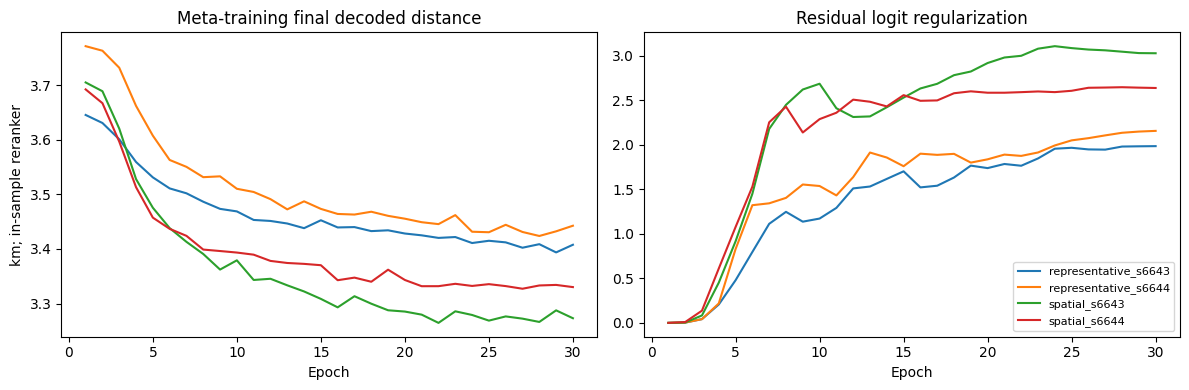

retain_original_fusion | gates: {'6643': False, '6644': True} | fit seconds: 40.23


In [36]:
# Cell 134 — Actual saved metrics and objective-alignment learning curves.
if (DECODED_RERANK_HOME/'latest.json').exists():
    decoded_link=json.loads((DECODED_RERANK_HOME/'latest.json').read_text())
    require(sha256(ROOT/decoded_link['decision'])==decoded_link['sha256'],'Decoded decision checksum changed.')
    decoded_report=json.loads((ROOT/decoded_link['decision']).read_text())
    display(pd.DataFrame(decoded_report['records'])[['method','split','seed','score','mean_km','median_km','p90_km','fraction_over_10km','worst_decile_error_share']])
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for run in sorted((ROOT/decoded_report['directory']).glob('*_s*')):
        history=json.loads((run/'history.json').read_text())
        axes[0].plot([h['epoch'] for h in history],[h['decoded_training_km'] for h in history],label=run.name)
        axes[1].plot([h['epoch'] for h in history],[h['residual_square'] for h in history],label=run.name)
    axes[0].set(title='Meta-training final decoded distance',xlabel='Epoch',ylabel='km; in-sample reranker')
    axes[1].set(title='Residual logit regularization',xlabel='Epoch');axes[1].legend(fontsize=8);fig.tight_layout();plt.show()
    print(decoded_report['decision'],'| gates:',decoded_report['seed_pass'],'| fit seconds:',round(decoded_report['fit_seconds'],2))
else:print('No completed decoded-distance study yet.')


## Learned cell/neighbor trust — one bounded follow-up, 2026-11-18

The loss-only trial improves representative scores at both seeds (.346004→.378118 and .351532→.382888), but its spatial gate passes only seed6644. Keep it as a rejected production candidate, preserve its measured gains, and do not weaken the both-seed rule. Test one specific remaining restriction: the decoder trusts geographic-cell and neighbor candidates equally for every query.

Freeze each fitted decoded-loss residual MLP exactly. Add a39→16→1 query gate from the mean standardized pair features, initialized to neutral50/50mix, bounded to10–90%cell mass. Fit only the gate on the exact same2,048 meta-query examples using final Haversine loss plus .001(mix−.5)². Its source residual is in-sample on these training queries; all outer validation remains excluded. This is a controlled learned-mixture follow-up, not a new encoder or a coefficient sweep.30fixed epochs, same optimizer/batch/schedule,180s per gate and720s cumulative across fixed-loss plus gated fits. Same selection criteria/folds/seeds; no validation epoch selection, test predictions or upload.


In [37]:
# Cell 136 — Query-specific cell/neighbor trust; previous residual reranker frozen.
GATED_RERANK_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'epochs':30,'batch_queries':128,
    'learning_rate':.001,'weight_decay':.01,'mixture_bounds':[.1,.9],'mixture_penalty':.001,
    'fit_seconds':180.,'aggregate_phase_fit_seconds':720.,'seeds':[6643,6644],
    'tag':'frozen_decoded_residual_learned_mixture_v1'}

class GatedPairReranker(PairResidualReranker):
    def __init__(self,mean,std):
        super().__init__(mean,std)
        state=torch.get_rng_state()
        self.gate=nn.Sequential(nn.Linear(len(mean),16),nn.GELU(),nn.Linear(16,1))
        nn.init.zeros_(self.gate[-1].weight);nn.init.zeros_(self.gate[-1].bias)
        torch.set_rng_state(state)
        for parameter in self.net.parameters():parameter.requires_grad_(False)
    def cell_mix(self,features):
        x=((features-self.feature_mean)/self.feature_std).clamp(-8,8).mean(1)
        return .1+.8*torch.sigmoid(self.gate(x).squeeze(-1))

@torch.inference_mode()
def decode_gated_bundle(training,bundle,model,device):
    require(training.sample_id.tolist()==bundle['reference_ids'].tolist(),'Gated gallery identity.')
    require(not set(training.sample_id)&set(bundle['query_ids']),'Gated gallery/query overlap.')
    model.eval();geo=bundle['geography'];xy,origin,scales=coordinates_xy(training[['latitude','longitude']],geo['origin'])
    centers=np.asarray(geo['centers']);result=[]
    for start in range(0,len(bundle['query_ids']),128):
        features=torch.as_tensor(bundle['features'][start:start+128],device=device)
        cosine=bundle['cosine'][start:start+128];logits=(cosine-cosine.max(1,keepdims=True))/.05+model(features).cpu().numpy()
        neighbor=np.exp(logits-logits.max(1,keepdims=True));neighbor/=neighbor.sum(1,keepdims=True)
        mix=model.cell_mix(features).cpu().numpy()[:,None]
        p=bundle['probability'][start:start+len(neighbor)];top=np.argsort(-p,axis=1,kind='stable')[:,:30]
        mass=np.take_along_axis(p,top,1);mass/=mass.sum(1,keepdims=True)
        candidates=np.concatenate([centers[top],xy[bundle['neighbors'][start:start+len(neighbor)]]],1)
        weights=np.concatenate([mix*mass,(1-mix)*neighbor],1)
        gps=bounded_geometric_median(candidates,weights)/scales+origin
        result.append(pd.DataFrame({'sample_id':bundle['query_ids'][start:start+len(neighbor)],
            'borough':np.asarray(BOROUGHS)[bundle['borough'][start:start+len(neighbor)]],'latitude':gps[:,0],'longitude':gps[:,1]}))
    prediction=pd.concat(result,ignore_index=True);validate_predictions(prediction,bundle['query_ids']);return prediction

def gated_rerank_identity():
    link=json.loads((DECODED_RERANK_HOME/'latest.json').read_text())
    require(sha256(ROOT/link['decision'])==link['sha256'],'Fixed-decoder trial changed.')
    return {'config':GATED_RERANK_CONFIG,'source_decoded_decision_sha256':link['sha256'],
        'data_fingerprint':data_fingerprint(ROOT),'split_sha256':sha256(ROOT/'outputs/splits.json'),
        'source':dino_definitions_hash(['GatedPairReranker','decode_gated_bundle','fit_gated_reranker',
            'run_gated_reranker','torch_weighted_median','torch_decoded_haversine_km','PairResidualReranker',
            'build_learned_pair_bundle','rerank_pair_features','FeatureLayerNorm','FusionGeoHead'])}


In [38]:
# Cell 137 — Fit only the trust gate; all residual weights remain exactly frozen.
def fit_gated_reranker(old,original_pairs,seed,directory,identity,budget):
    directory.mkdir(parents=True,exist_ok=True);path=directory/'gated.pth';status_path=directory/'status.json'
    if status_path.exists():
        status=json.loads(status_path.read_text());require(status['status']=='complete' and sha256(path)==status['sha256'],'Inspect incomplete gated run.')
        return path
    fixed=torch.load(old/'reranker.pth',map_location='cpu',weights_only=True)
    require(sha256(old/'training_geometry.npz')==fixed['training_geometry_sha256'],'Fixed training geometry drift.')
    with np.load(original_pairs) as saved:values=saved['features'];ids=saved['query_ids']
    require(hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest()==fixed['training_pair_hash'],'Gated training pair features changed.')
    require(ids.tolist()==fixed['training_query_ids'],'Gated training query IDs changed.')
    with np.load(old/'training_geometry.npz') as saved:points=saved['points'];mass=saved['cell_mass'];targets=saved['target_xy_km']
    plan=fixed['plan'];require(set(ids).isdisjoint(plan['outer_validation_ids']),'Gated validation leakage.')
    teacher=torch.load(original_pairs.parent/'teacher.pth',map_location='cpu',weights_only=True)
    with np.load(original_pairs) as saved:cosine=saved['cosine']
    seed_everything(seed);rng=np.random.default_rng(seed);device=dino_device();state=fixed['state_dict']
    model=GatedPairReranker(state['feature_mean'],state['feature_std']).to(device)
    missing=model.load_state_dict(state,strict=False)
    require(set(missing.missing_keys)=={'gate.0.weight','gate.0.bias','gate.2.weight','gate.2.bias'} and not missing.unexpected_keys,'Gated source state mismatch.')
    model.eval();x=torch.as_tensor(values,device=device);location=torch.as_tensor(points,device=device)
    cell_mass=torch.as_tensor(mass,device=device);target=torch.as_tensor(targets,device=device)
    neighbor=[]
    with torch.inference_mode():
        for start in range(0,len(values),128):
            logits=torch.as_tensor((cosine[start:start+128]-cosine[start:start+128].max(1,keepdims=True))/.05,device=device)+model(x[start:start+128])
            neighbor.append(logits.softmax(1))
    # Clone outside inference mode so the constant weights are safe in autograd.
    neighbor=torch.cat(neighbor).clone()
    optimizer=torch.optim.AdamW(model.gate.parameters(),lr=.001,weight_decay=.01)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=30,eta_min=5e-5)
    started=time.monotonic();history=[];status={'status':'running'};origin_lat=teacher['geography']['origin'][0]
    try:
        for epoch in range(1,31):
            model.eval();model.gate.train();losses=[];order=rng.permutation(len(values))
            for start in range(0,len(order),128):
                elapsed=time.monotonic()-started
                require(elapsed<180 and budget['fit_seconds']+elapsed<720,'Gated/phase fit cap exceeded.')
                index=torch.as_tensor(order[start:start+128],device=device);mix=model.cell_mix(x[index])
                weights=torch.cat([mix[:,None]*cell_mass[index],(1-mix[:,None])*neighbor[index]],1)
                point=torch_weighted_median(location[index],weights)
                km=torch_decoded_haversine_km(point,target[index],origin_lat).mean()
                loss=km/5+.001*(mix-.5).square().mean()
                require(bool(torch.isfinite(loss)),'Nonfinite gated GPS loss.')
                optimizer.zero_grad(set_to_none=True);loss.backward();nn.utils.clip_grad_norm_(model.gate.parameters(),5,error_if_nonfinite=True);optimizer.step()
                losses.append([float(loss.detach().cpu()),float(km.detach().cpu()),float(mix.detach().mean().cpu())])
            scheduler.step();mean=np.mean(losses,axis=0)
            history.append({'epoch':epoch,'loss':float(mean[0]),'decoded_training_km':float(mean[1]),'mean_cell_mix':float(mean[2]),
                'elapsed_seconds':time.monotonic()-started,'driver_bytes':dino_memory_guard(device)})
            dino_json(directory/'history.json',history)
            if epoch in (1,10,20,30):print('gate',plan['split'],seed,'epoch',epoch,'training km',round(mean[1],4),'cell mix',round(mean[2],3),flush=True)
        for key,value in fixed['state_dict'].items():require(torch.equal(model.state_dict()[key].cpu(),value),'Frozen residual/statistics changed.')
        saved={'identity':identity,'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'seed':seed,'epochs':30,
            'plan':plan,'metric_version':CURRENT_METRIC_VERSION,'source_fixed_checkpoint':str((old/'reranker.pth').relative_to(ROOT)),
            'source_fixed_sha256':sha256(old/'reranker.pth'),'source_training_geometry_sha256':fixed['training_geometry_sha256'],
            'training_pair_hash':fixed['training_pair_hash'],'only_gate_fitted':True}
        dino_torch_save(path,saved);status.update(status='complete',sha256=sha256(path))
    except BaseException as error:status.update(status='failed',error=str(error));raise
    finally:
        elapsed=time.monotonic()-started;budget['fit_seconds']+=elapsed
        status.update(elapsed_seconds=elapsed,completed_epochs=len(history));dino_json(status_path,status);dino_json(directory.parent/'fit_budget.json',budget)
        del model,optimizer,x,location,cell_mass,target,neighbor;dino_release(device)
    return path


In [39]:
# Cell 138 — Neutral trust parity and frozen-source contract.
class GatedRerankerTests(unittest.TestCase):
    def test_gate_initializes_to_half_and_only_gate_parameters_train(self):
        torch.manual_seed(7);m=GatedPairReranker(np.zeros(39,np.float32),np.ones(39,np.float32));x=torch.randn(8,32,39)
        np.testing.assert_allclose(m.cell_mix(x).detach().numpy(),.5,rtol=0,atol=1e-7)
        self.assertTrue(all(not p.requires_grad for p in m.net.parameters()))
        self.assertTrue(all(p.requires_grad for p in m.gate.parameters()))
        m.cell_mix(x).sum().backward();self.assertTrue(all(p.grad is None for p in m.net.parameters()))
        self.assertTrue(all(bool(torch.isfinite(p.grad).all()) for p in m.gate.parameters()))
    def test_half_mixture_matches_original_median_weights(self):
        rng=np.random.default_rng(7);p=rng.normal(size=(4,62,2));a=rng.uniform(size=(4,30));a/=a.sum(1,keepdims=True)
        b=rng.uniform(size=(4,32));b/=b.sum(1,keepdims=True);mix=np.full((4,1),.5)
        np.testing.assert_array_equal(bounded_geometric_median(p,np.concatenate([mix*a,(1-mix)*b],1)),bounded_geometric_median(p,np.concatenate([.5*a,.5*b],1)))

gated_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(GatedRerankerTests))
require(gated_tests.wasSuccessful(),'Resolve learned-mixture contracts before fitting.')


test_gate_initializes_to_half_and_only_gate_parameters_train (__main__.GatedRerankerTests.test_gate_initializes_to_half_and_only_gate_parameters_train) ... 

ok


test_half_mixture_matches_original_median_weights (__main__.GatedRerankerTests.test_half_mixture_matches_original_median_weights) ... 

ok


----------------------------------------------------------------------
Ran 2 tests in 0.005s

OK


In [40]:
# Cell 139 — Single learned-mixture follow-up, with both original validation folds/seeds.
def run_gated_reranker():
    frame,splits,street,dino,_,_=fusion_sources();identity=gated_rerank_identity()
    directory=DECODED_RERANK_HOME/('gated_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True)
    path=directory/'decision.json'
    if path.exists():
        result=json.loads(path.read_text());require(result['identity']==identity,'Completed gated source drift.');return result
    dino_json(directory/'identity.json',identity)
    fixed_link=json.loads((DECODED_RERANK_HOME/'latest.json').read_text());fixed=json.loads((ROOT/fixed_link['decision']).read_text())
    require(fixed['identity']==decoded_rerank_identity(),'Fixed source functions changed.')
    original_link=json.loads((FUSION_HOME/'latest.json').read_text());sources=json.loads((ROOT/original_link['decision']).read_text())
    budget_path=directory/'fit_budget.json';budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'fit_seconds':fixed['fit_seconds'],'prior_fixed_fit_seconds':fixed['fit_seconds'],'limit_seconds':720.}
    records=[];device=dino_device()
    for seed in (6643,6644):
        for split_name in ('representative','spatial'):
            name=f'{split_name}_s{seed}';run=directory/name;old=ROOT/fixed['directory']/name
            pairs=ROOT/fixed['source_previous_study']/name/'training_pairs.npz'
            checkpoint=fit_gated_reranker(old,pairs,seed,run,identity,budget)
            saved=torch.load(checkpoint,map_location='cpu',weights_only=True);plan=saved['plan'];state=saved['state_dict']
            require(plan==learned_rerank_plan(frame,splits,split_name),'Gated plan differs from original folds.')
            model=GatedPairReranker(state['feature_mean'],state['feature_std']).to(device);model.load_state_dict(state,strict=True)
            source=next(r for r in sources['records'] if r['variant']=='fusion_random' and r['seed']==seed and r['split']==split_name)
            require(sha256(ROOT/source['checkpoint'])==source['checkpoint_sha256'],'Gated evaluation source changed.')
            base,base_saved=fusion_model_load(ROOT/source['checkpoint'],sources['identity'],device)
            try:bundle=build_learned_pair_bundle(frame,street,dino,plan['outer_train_ids'],plan['outer_validation_ids'],base,base_saved['geography'],device)
            finally:del base;dino_release(device)
            truth=frame.loc[plan['outer_validation_ids']];baseline=pd.read_csv(old/'validation_original.csv')
            try:
                prediction=decode_gated_bundle(frame.loc[plan['outer_train_ids']],bundle,model,device)
                for method,csv in [('original',baseline),('fixed_decoded',pd.read_csv(old/'validation_decoded.csv')),('gated',prediction)]:
                    metrics=score_current_predictions(truth,csv);error=haversine_km(truth[['latitude','longitude']],csv[['latitude','longitude']])
                    output=run/f'validation_{method}.csv';csv.to_csv(output,index=False)
                    record={'method':method,'split':split_name,'seed':seed,**metrics,'prediction':str(output.relative_to(ROOT)),
                        'prediction_sha256':sha256(output),'checkpoint':str(checkpoint.relative_to(ROOT)),'checkpoint_sha256':sha256(checkpoint),
                        'fraction_over_5km':float((error>5).mean()),'fraction_over_10km':float((error>10).mean()),'fraction_over_20km':float((error>20).mean()),
                        'worst_decile_error_share':float(np.sort(error)[-int(np.ceil(.1*len(error))):].sum()/error.sum())}
                    if method=='gated':record['bootstrap']=current_metric_bootstrap(truth,csv,baseline,splits)
                    records.append(record);dino_json(directory/'metrics_in_progress.json',records)
                    print(method,split_name,seed,'v2',round(metrics['score'],6),'mean',round(metrics['mean_km'],4),'km',flush=True)
                model.eval();mixture=[]
                with torch.inference_mode():
                    for start in range(0,len(truth),128):mixture.extend(model.cell_mix(torch.as_tensor(bundle['features'][start:start+128],device=device)).cpu().numpy().tolist())
                pd.DataFrame({'sample_id':truth.sample_id.to_numpy(),'cell_mix':mixture}).to_csv(run/'validation_cell_mix.csv',index=False)
            finally:del model;dino_release(device)
    passed={str(seed):passes_current_development_guard(
        {r['split']:r for r in records if r['method']=='gated' and r['seed']==seed},
        {r['split']:r for r in records if r['method']=='original' and r['seed']==seed}) for seed in (6643,6644)}
    result={'identity':identity,'directory':str(directory.relative_to(ROOT)),'records':records,'seed_pass':passed,'retained':all(passed.values()),
        'decision':'retain_gated_reranker' if all(passed.values()) else 'retain_original_fusion',
        'phase_fit_seconds':budget['fit_seconds'],'new_gated_fit_seconds':budget['fit_seconds']-budget['prior_fixed_fit_seconds'],
        'source_fixed_study':fixed['directory'],'source_previous_study':fixed['source_previous_study'],
        'new_public_score':None,'test_inference':False}
    dino_json(path,result);dino_json(DECODED_RERANK_HOME/'gated_latest.json',{'decision':str(path.relative_to(ROOT)),'sha256':sha256(path)})
    record_run(ROOT,directory.name,'learned_mixture_reranker','both_original_folds',{},
        {'metric_version':CURRENT_METRIC_VERSION,'config':GATED_RERANK_CONFIG},result['new_gated_fit_seconds'],{'decision':str(path.relative_to(ROOT))},result['decision'])
    return result

RUN_GATED_RERANK=os.environ.get('NYCGUESSR_GATED_RERANK','0')=='1'
if RUN_GATED_RERANK:GATED_RERANK_RESULT=run_gated_reranker()
else:print('Learned mixture fitting/evaluation disabled by default.')


Learned mixture fitting/evaluation disabled by default.


,method,split,seed,score,mean_km,median_km,p90_km,fraction_over_10km
0,original,representative,6643,0.346004,3.543432,1.170501,10.405028,0.103288
1,fixed_decoded,representative,6643,0.378118,3.365020,1.031003,9.849963,0.099073
2,gated,representative,6643,0.380371,3.352505,1.002963,9.873517,0.099073
3,original,spatial,6643,0.077237,5.530323,2.805487,14.019978,0.154069
4,fixed_decoded,spatial,6643,0.077237,5.544105,2.725042,14.155003,0.156960
5,gated,spatial,6643,0.077237,5.582004,2.748426,14.508854,0.160677
6,original,representative,6644,0.351532,3.512208,1.197510,10.084168,0.101180
7,fixed_decoded,representative,6644,0.382888,3.338008,1.039532,9.330201,0.096543
8,gated,representative,6644,0.387659,3.311497,1.017009,9.578343,0.095700
9,original,spatial,6644,0.076302,5.645370,2.834758,14.215357,0.164808


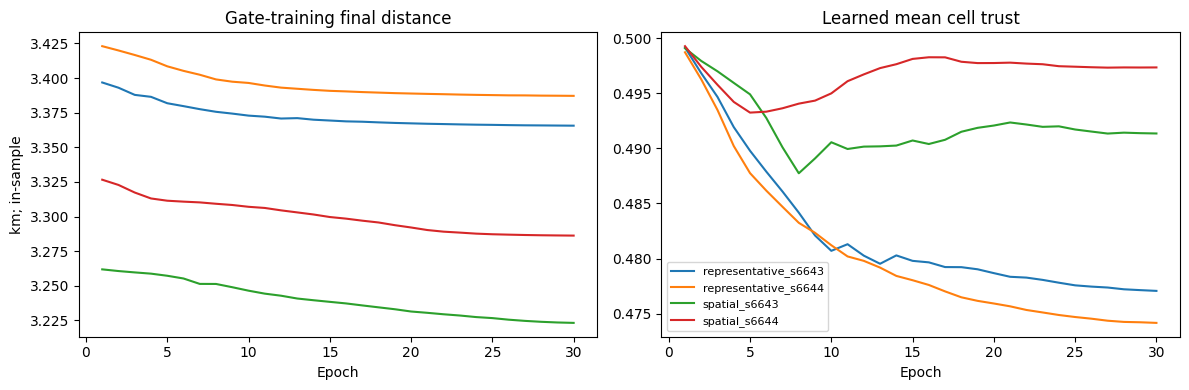

retain_original_fusion | gates: {'6643': False, '6644': True} | total phase fit seconds: 78.84


In [41]:
# Cell 140 — Actual learned-mixture results and training curves.
if (DECODED_RERANK_HOME/'gated_latest.json').exists():
    link=json.loads((DECODED_RERANK_HOME/'gated_latest.json').read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Gated decision drift.')
    report=json.loads((ROOT/link['decision']).read_text())
    display(pd.DataFrame(report['records'])[['method','split','seed','score','mean_km','median_km','p90_km','fraction_over_10km']])
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for run in sorted((ROOT/report['directory']).glob('*_s*')):
        h=json.loads((run/'history.json').read_text());axes[0].plot([r['epoch'] for r in h],[r['decoded_training_km'] for r in h],label=run.name)
        axes[1].plot([r['epoch'] for r in h],[r['mean_cell_mix'] for r in h],label=run.name)
    axes[0].set(title='Gate-training final distance',xlabel='Epoch',ylabel='km; in-sample');axes[1].set(title='Learned mean cell trust',xlabel='Epoch');axes[1].legend(fontsize=8);fig.tight_layout();plt.show()
    print(report['decision'],'| gates:',report['seed_pass'],'| total phase fit seconds:',round(report['phase_fit_seconds'],2))
else:print('No completed learned-mixture follow-up yet.')


## Training-distribution realignment — final bounded trial, 2026-11-18

The learned-mixture follow-up improves representative point estimates but still misses the seed6643 spatial guard. Both previous candidates remain rejected for production. A remaining mismatch is concrete: their meta-query training partition is random/dense, while the outer spatial test withholds1-km areas with a200-m buffer. Test a single hybrid training regime, without new features or encoder changes.

Within each original outer training fold choose1,024 meta queries from randomly selected1-km tiles (including all five boroughs), reserve whole selected tiles and a200-m buffer around those queries, then choose1,024 additional dense meta queries from the remaining area. Fit a fresh40-epoch teacher only on the remaining inner gallery. No outer validation labels enter selection/statistics/teacher/reranker. Extra reserved/buffer rows remain excluded and are logged. The new teacher gallery is smaller than the original random-meta gallery; this is part of the changed training regime, so do not attribute differences to spatial examples alone.

Train the same39-feature MLP with final-coordinate loss, fixed50/50production decoder and30fixed epochs. Compare original fusion and the loss-only random-meta control. Four teachers and four residual models, existing per-fit caps180s; the shared720s phase ledger includes earlier78.84s of fixed/gated fitting. Reserve a teacher's worst-case cap before starting it. Same both-fold/both-seed retention guard, no validation epoch selection or parameter sweep. This is the final modeling variant in this bounded run; document failure rather than extending the search. No test inference, external data/downloads or upload.


In [42]:
# Cell 142 — Mixed dense/spatial meta queries; all selection uses outer training labels.
HYBRID_RERANK_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'meta_queries':2048,
    'spatial_meta_queries':1024,'dense_meta_queries':1024,'inner_block_km':1.,'inner_buffer_km':.2,
    'teacher_epochs':40,'reranker_epochs':30,'seeds':[6643,6644],'teacher_seconds':180.,
    'reranker_seconds':180.,'phase_fit_seconds':720.,'tag':'hybrid_meta_distribution_v1'}

def hybrid_rerank_plan(frame,splits,split_name):
    outer=splits['splits'][split_name];training=frame.loc[outer['train_ids']]
    xy,origin,scales=coordinates_xy(training[['latitude','longitude']]);tiles=np.floor(xy).astype(int)
    keys=[tuple(t) for t in tiles];groups={}
    for position,key in enumerate(keys):groups.setdefault(key,[]).append(position)
    rng=np.random.default_rng(6643);selected=set()
    for borough in BOROUGHS:
        eligible=sorted({keys[i] for i in np.flatnonzero(training.borough.to_numpy()==borough)})
        selected.add(eligible[int(rng.integers(len(eligible)))])
    order=rng.permutation(len(groups));available=sorted(groups)
    pool={i for key in selected for i in groups[key]}
    for j in order:
        if len(pool)>=1024:break
        key=available[int(j)];selected.add(key);pool.update(groups[key])
    spatial=training_subset(training.iloc[sorted(pool)],limit=1024,seed=6643).sample_id.tolist()
    position=pd.Series(np.arange(len(training)),index=training.sample_id)
    spatial_positions=position.loc[spatial].to_numpy()
    near=cKDTree(xy).query_ball_point(xy[spatial_positions],r=.2)
    reserved=set(pool)|{int(i) for group in near for i in group}
    eligible=training.iloc[[i for i in range(len(training)) if i not in reserved]]
    require(len(eligible)>2048,'Insufficient gallery after inner spatial holdout.')
    dense=training_subset(eligible,limit=1024,seed=6643).sample_id.tolist();dense_set=set(dense)
    gallery=[int(i) for i in eligible.sample_id if i not in dense_set];meta=sorted(spatial+dense)
    excluded=sorted(set(outer['train_ids'])-set(gallery)-set(meta))
    require(set(gallery).isdisjoint(meta) and set(gallery+meta+excluded)==set(outer['train_ids']),'Hybrid partition overlap/coverage.')
    require(set(gallery+meta+excluded).isdisjoint(outer['validation_ids']),'Outer validation used for hybrid fitting.')
    require(set(frame.loc[gallery].borough)==set(BOROUGHS),'Teacher gallery lost a borough.')
    minimum=float(cKDTree(xy[position.loc[gallery].to_numpy()]).query(xy[spatial_positions])[0].min())
    require(minimum>=.2-1e-8,'Spatial meta/gallery buffer failed.')
    return {'split':split_name,'teacher_train_ids':gallery,'meta_query_ids':meta,'outer_train_ids':outer['train_ids'],
        'outer_validation_ids':outer['validation_ids'],'spatial_meta_ids':spatial,'dense_meta_ids':dense,
        'inner_excluded_ids':excluded,'partition_origin_deg':origin.tolist(),'partition_scales':scales.tolist(),
        'spatial_meta_minimum_gallery_distance_km':minimum,'inner_selected_tiles':[[int(v) for v in k] for k in sorted(selected)]}

def hybrid_rerank_identity():
    previous=json.loads((DECODED_RERANK_HOME/'gated_latest.json').read_text())
    require(sha256(ROOT/previous['decision'])==previous['sha256'],'Previous phase budget/decision changed.')
    return {'config':HYBRID_RERANK_CONFIG,'decoded_config':DECODED_RERANK_CONFIG,
        'previous_gated_decision_sha256':previous['sha256'],'data_fingerprint':data_fingerprint(ROOT),
        'split_sha256':sha256(ROOT/'outputs/splits.json'),
        'source':dino_definitions_hash(['hybrid_rerank_plan','hybrid_rerank_identity','run_hybrid_reranker',
            'fit_rerank_teacher','fit_decoded_reranker','decoded_training_geometry','build_learned_pair_bundle',
            'torch_weighted_median','torch_decoded_haversine_km','PairResidualReranker','decode_learned_bundle',
            'FusionGeoHead','FeatureLayerNorm','rerank_pair_features','score_current_predictions'])}


In [43]:
# Cell 143 — Role separation, exact query counts and spatial-buffer regression checks.
class HybridRerankerTests(unittest.TestCase):
    def test_inner_split_is_training_only_buffered_and_reproducible(self):
        frame,_=load_data(ROOT);splits=json.loads((ROOT/'outputs/splits.json').read_text())
        for name in ('representative','spatial'):
            p=hybrid_rerank_plan(frame,splits,name);self.assertEqual(p,hybrid_rerank_plan(frame,splits,name));json.dumps(p,allow_nan=False)
            self.assertEqual(len(p['meta_query_ids']),2048);self.assertEqual(len(p['spatial_meta_ids']),1024);self.assertEqual(len(p['dense_meta_ids']),1024)
            self.assertFalse(set(p['meta_query_ids'])&set(p['teacher_train_ids']))
            self.assertFalse(set(p['inner_excluded_ids'])&set(p['meta_query_ids']+p['teacher_train_ids']))
            self.assertEqual(set(p['teacher_train_ids']+p['meta_query_ids']+p['inner_excluded_ids']),set(p['outer_train_ids']))
            self.assertFalse(set(p['outer_train_ids'])&set(p['outer_validation_ids']))
            self.assertGreaterEqual(p['spatial_meta_minimum_gallery_distance_km'],.2-1e-8)
            self.assertEqual(set(frame.loc[p['teacher_train_ids']].borough),set(BOROUGHS))

hybrid_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(HybridRerankerTests))
require(hybrid_tests.wasSuccessful(),'Resolve hybrid role/buffer tests before fitting.')


test_inner_split_is_training_only_buffered_and_reproducible (__main__.HybridRerankerTests.test_inner_split_is_training_only_buffered_and_reproducible) ... 

ok


----------------------------------------------------------------------
Ran 1 test in 0.618s

OK


In [44]:
# Cell 144 — Final bounded distribution-matching trial; production guard unchanged.
def run_hybrid_reranker():
    frame,splits,street,dino,_,_=fusion_sources();identity=hybrid_rerank_identity()
    directory=DECODED_RERANK_HOME/('hybrid_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True);decision_path=directory/'decision.json'
    if decision_path.exists():
        result=json.loads(decision_path.read_text());require(result['identity']==identity,'Hybrid source identity drift.');return result
    dino_json(directory/'identity.json',identity)
    gated_link=json.loads((DECODED_RERANK_HOME/'gated_latest.json').read_text());gated=json.loads((ROOT/gated_link['decision']).read_text())
    fixed_link=json.loads((DECODED_RERANK_HOME/'latest.json').read_text());fixed=json.loads((ROOT/fixed_link['decision']).read_text())
    source_link=json.loads((FUSION_HOME/'latest.json').read_text());sources=json.loads((ROOT/source_link['decision']).read_text())
    require(sha256(ROOT/source_link['decision'])==source_link['sha256'],'Original fusion source drift.')
    budget_path=directory/'fit_budget.json';budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'fit_seconds':gated['phase_fit_seconds'],'prior_phase_fit_seconds':gated['phase_fit_seconds'],'limit_seconds':720.}
    records=[];device=dino_device()
    for seed in (6643,6644):
        for split_name in ('representative','spatial'):
            run=directory/f'{split_name}_s{seed}';run.mkdir(parents=True,exist_ok=True)
            plan=hybrid_rerank_plan(frame,splits,split_name);dino_json(run/'plan.json',plan)
            # Reserve the teacher's worst-case cap before starting it; no phase-budget reset.
            if not (run/'teacher_status.json').exists():require(budget['fit_seconds']+180<720,'Insufficient shared phase budget for another teacher.')
            teacher_path=fit_rerank_teacher(frame,street,dino,plan,seed,run,identity,budget)
            require(budget['fit_seconds']<720,'Shared phase budget exhausted after teacher.')
            teacher,teacher_saved=fusion_model_load(teacher_path,identity,device)
            try:training=build_learned_pair_bundle(frame,street,dino,plan['teacher_train_ids'],plan['meta_query_ids'],teacher,teacher_saved['geography'],device)
            finally:del teacher;dino_release(device)
            np.savez(run/'training_pairs.npz',features=training['features'],distance_km=training['distance_km'],cosine=training['cosine'],
                neighbors=training['neighbors'],query_ids=training['query_ids'],reference_ids=training['reference_ids'])
            checkpoint=fit_decoded_reranker(frame,training,plan,seed,run,identity,budget)
            saved=torch.load(checkpoint,map_location='cpu',weights_only=True);state=saved['state_dict']
            model=PairResidualReranker(state['feature_mean'],state['feature_std']).to(device);model.load_state_dict(state,strict=True)
            source=next(r for r in sources['records'] if r['variant']=='fusion_random' and r['seed']==seed and r['split']==split_name)
            require(sha256(ROOT/source['checkpoint'])==source['checkpoint_sha256'],'Hybrid evaluation source head changed.')
            base,base_saved=fusion_model_load(ROOT/source['checkpoint'],sources['identity'],device)
            try:bundle=build_learned_pair_bundle(frame,street,dino,plan['outer_train_ids'],plan['outer_validation_ids'],base,base_saved['geography'],device)
            finally:del base;dino_release(device)
            truth=frame.loc[plan['outer_validation_ids']];original=pd.read_csv((ROOT/source['checkpoint']).parent/'validation_best.csv')
            try:
                prediction=decode_learned_bundle(frame.loc[plan['outer_train_ids']],bundle,model,device)
                for method,pred in [('original',original),('random_meta',pd.read_csv(ROOT/fixed['directory']/run.name/'validation_decoded.csv')),('hybrid_meta',prediction)]:
                    metrics=score_current_predictions(truth,pred);error=haversine_km(truth[['latitude','longitude']],pred[['latitude','longitude']])
                    output=run/f'validation_{method}.csv';pred.to_csv(output,index=False)
                    record={'method':method,'split':split_name,'seed':seed,**metrics,'prediction':str(output.relative_to(ROOT)),
                        'prediction_sha256':sha256(output),'checkpoint':str(checkpoint.relative_to(ROOT)),'checkpoint_sha256':sha256(checkpoint),
                        'source_checkpoint':source['checkpoint'],'source_checkpoint_sha256':source['checkpoint_sha256'],
                        'fraction_over_5km':float((error>5).mean()),'fraction_over_10km':float((error>10).mean()),'fraction_over_20km':float((error>20).mean()),
                        'worst_decile_error_share':float(np.sort(error)[-int(np.ceil(.1*len(error))):].sum()/error.sum())}
                    if method=='hybrid_meta':record['bootstrap']=current_metric_bootstrap(truth,pred,original,splits)
                    records.append(record);dino_json(directory/'metrics_in_progress.json',records)
                    print(method,split_name,seed,'v2',round(metrics['score'],6),'mean',round(metrics['mean_km'],4),'km',flush=True)
                diagnostic=decode_learned_bundle(frame.loc[plan['teacher_train_ids']],training,model,device)
                per_group=[]
                for group,ids in [('all',plan['meta_query_ids']),('spatial',plan['spatial_meta_ids']),('dense',plan['dense_meta_ids'])]:
                    pred=diagnostic.set_index('sample_id',drop=False).loc[ids].reset_index(drop=True)
                    per_group.append({'group':group,'scope':'In-sample for reranker; unseen by teacher',**score_current_predictions(frame.loc[ids],pred)})
                dino_json(run/'training_diagnostics.json',per_group)
            finally:del model;dino_release(device)
    passed={str(seed):passes_current_development_guard(
        {r['split']:r for r in records if r['method']=='hybrid_meta' and r['seed']==seed},
        {r['split']:r for r in records if r['method']=='original' and r['seed']==seed}) for seed in (6643,6644)}
    result={'identity':identity,'directory':str(directory.relative_to(ROOT)),'records':records,'seed_pass':passed,'retained':all(passed.values()),
        'decision':'retain_hybrid_meta_reranker' if all(passed.values()) else 'retain_original_fusion',
        'phase_fit_seconds':budget['fit_seconds'],'new_hybrid_fit_seconds':budget['fit_seconds']-budget['prior_phase_fit_seconds'],
        'source_fixed_study':fixed['directory'],'source_gated_study':gated['directory'],
        'new_public_score':None,'test_inference':False,'encoder_extraction':False}
    dino_json(decision_path,result);dino_json(DECODED_RERANK_HOME/'hybrid_latest.json',{'decision':str(decision_path.relative_to(ROOT)),'sha256':sha256(decision_path)})
    record_run(ROOT,directory.name,'hybrid_meta_decoded_reranker','both_original_folds',{},
        {'metric_version':CURRENT_METRIC_VERSION,'config':HYBRID_RERANK_CONFIG},result['new_hybrid_fit_seconds'],{'decision':str(decision_path.relative_to(ROOT))},result['decision'])
    return result

RUN_HYBRID_RERANK=os.environ.get('NYCGUESSR_HYBRID_RERANK','0')=='1'
if RUN_HYBRID_RERANK:HYBRID_RERANK_RESULT=run_hybrid_reranker()
else:print('Hybrid spatial/dense training study disabled by default.')


Hybrid spatial/dense training study disabled by default.


In [45]:
# Cell 145 — Saved hybrid-regime metrics and training diagnostics.
if (DECODED_RERANK_HOME/'hybrid_latest.json').exists():
    link=json.loads((DECODED_RERANK_HOME/'hybrid_latest.json').read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Hybrid decision drift.')
    report=json.loads((ROOT/link['decision']).read_text());display(pd.DataFrame(report['records'])[['method','split','seed','score','mean_km','median_km','p90_km','fraction_over_10km']])
    diagnostic=[]
    for run in sorted((ROOT/report['directory']).glob('*_s*')):
        for d in json.loads((run/'training_diagnostics.json').read_text()):diagnostic.append({'run':run.name,**d})
    display(pd.DataFrame(diagnostic)[['run','group','mean_km','median_km','p90_km']])
    print(report['decision'],'| gates:',report['seed_pass'],'| shared phase fit seconds:',round(report['phase_fit_seconds'],2))
else:print('No completed hybrid-regime study yet.')


,method,split,seed,score,mean_km,median_km,p90_km,fraction_over_10km
0,original,representative,6643,0.346004,3.543432,1.170501,10.405028,0.103288
1,random_meta,representative,6643,0.378118,3.365020,1.031003,9.849963,0.099073
2,hybrid_meta,representative,6643,0.365795,3.433482,1.118250,9.963252,0.099916
3,original,spatial,6643,0.077237,5.530323,2.805487,14.019978,0.154069
4,random_meta,spatial,6643,0.077237,5.544105,2.725042,14.155003,0.156960
5,hybrid_meta,spatial,6643,0.077237,5.460754,2.705636,13.858874,0.156134
6,original,representative,6644,0.351532,3.512208,1.197510,10.084168,0.101180
7,random_meta,representative,6644,0.382888,3.338008,1.039532,9.330201,0.096543
8,hybrid_meta,representative,6644,0.385274,3.324749,1.080158,9.510876,0.094013
9,original,spatial,6644,0.076302,5.645370,2.834758,14.215357,0.164808


,run,group,mean_km,median_km,p90_km
0,representative_s6643,all,4.616244,1.819232,14.097620
1,representative_s6643,spatial,5.853730,2.574884,16.977204
2,representative_s6643,dense,3.378759,1.148858,9.423774
3,representative_s6644,all,4.578064,1.743809,14.040950
4,representative_s6644,spatial,5.793828,2.567518,17.124991
5,representative_s6644,dense,3.362300,1.074922,10.076800
6,spatial_s6643,all,4.203285,1.539480,12.271897
7,spatial_s6643,spatial,5.271473,2.197762,14.349398
8,spatial_s6643,dense,3.135098,0.942756,8.718235
9,spatial_s6644,all,4.217695,1.607652,11.876887


retain_hybrid_meta_reranker | gates: {'6643': True, '6644': True} | shared phase fit seconds: 298.93


In [46]:
# Cell 146 — Strict source/statistics/partition/budget and full validation replay audit.
def verify_decoded_phase(replay=False):
    started=time.monotonic();frame,splits,street,dino,_,_=fusion_sources();checks=[];reports={};peak=0;totals={}
    def check(condition,message):
        require(bool(condition),message);checks.append(message)
    for kind,pointer,identity_function in [('fixed','latest.json',decoded_rerank_identity),('gated','gated_latest.json',gated_rerank_identity),('hybrid','hybrid_latest.json',hybrid_rerank_identity)]:
        link=json.loads((DECODED_RERANK_HOME/pointer).read_text());check(sha256(ROOT/link['decision'])==link['sha256'],kind+': decision checksum')
        report=json.loads((ROOT/link['decision']).read_text());check(report['identity']==identity_function(),kind+': source/config/data identity')
        reports[kind]=report;check(len(report['records'])==12,kind+': twelve complete validation records')
        total=0.
        for seed in (6643,6644):
            for name in ('representative','spatial'):
                run=ROOT/report['directory']/f'{name}_s{seed}'
                head_path=run/('gated.pth' if kind=='gated' else 'reranker.pth')
                saved=torch.load(head_path,map_location='cpu',weights_only=True);plan=saved['plan']
                expected=hybrid_rerank_plan(frame,splits,name) if kind=='hybrid' else learned_rerank_plan(frame,splits,name)
                check(plan==expected,f'{kind}/{run.name}: exact inner/outer partition')
                check(set(plan['teacher_train_ids']+plan['meta_query_ids']).isdisjoint(plan['outer_validation_ids']),f'{kind}/{run.name}: validation excluded from all fitting roles')
                check(saved['identity']==report['identity'] and saved['metric_version']==CURRENT_METRIC_VERSION,f'{kind}/{run.name}: checkpoint identity/v2')
                check(all(bool(torch.isfinite(v).all()) for v in saved['state_dict'].values()),f'{kind}/{run.name}: finite saved parameters')
                status=json.loads((run/'status.json').read_text());history=json.loads((run/'history.json').read_text())
                check(status['status']=='complete' and status['sha256']==sha256(head_path),f'{kind}/{run.name}: complete checkpoint hash')
                check(status['completed_epochs']==len(history)==30 and np.isfinite([h['loss'] for h in history]).all(),f'{kind}/{run.name}: fixed30 finite epochs')
                check(status['elapsed_seconds']<=180,f'{kind}/{run.name}: per-fit budget')
                total+=status['elapsed_seconds'];peak=max(peak,max(h['driver_bytes'] for h in history))
                if kind=='gated':
                    old_path=ROOT/saved['source_fixed_checkpoint'];fixed=torch.load(old_path,map_location='cpu',weights_only=True)
                    check(sha256(old_path)==saved['source_fixed_sha256'],f'gated/{run.name}: fixed residual source checksum')
                    check(all(torch.equal(saved['state_dict'][k],v) for k,v in fixed['state_dict'].items()),f'gated/{run.name}: all residual/statistics exactly frozen')
                    mixtures=pd.read_csv(run/'validation_cell_mix.csv')
                    check(mixtures.sample_id.tolist()==plan['outer_validation_ids'] and mixtures.cell_mix.between(.1,.9).all(),f'gated/{run.name}: bounded trust values/query IDs')
                else:
                    previous=ROOT/report['source_previous_study']/run.name if kind=='fixed' else run
                    teacher_path=previous/'teacher.pth';teacher=torch.load(teacher_path,map_location='cpu',weights_only=True)
                    teacher_status=json.loads((previous/'teacher_status.json').read_text())
                    check(teacher_status['status']=='complete' and sha256(teacher_path)==teacher_status['checkpoint_sha256'],f'{kind}/{run.name}: source teacher checksum')
                    check(teacher['train_ids']==plan['teacher_train_ids'] and teacher['meta_query_ids']==plan['meta_query_ids'],f'{kind}/{run.name}: teacher query/validation exclusion')
                    with np.load(previous/'training_pairs.npz') as p:values=p['features'];neighbors=p['neighbors'];query_ids=p['query_ids'];reference_ids=p['reference_ids']
                    check(query_ids.tolist()==plan['meta_query_ids'] and reference_ids.tolist()==plan['teacher_train_ids'],f'{kind}/{run.name}: cached training pair alignment')
                    check(hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest()==saved['training_pair_hash'],f'{kind}/{run.name}: unchanged pair feature hash')
                    check(np.array_equal(saved['state_dict']['feature_mean'].numpy(),values.astype(np.float64).mean((0,1)).astype(np.float32)),f'{kind}/{run.name}: training-only feature mean')
                    check(np.array_equal(saved['state_dict']['feature_std'].numpy(),np.maximum(values.astype(np.float64).std((0,1)),.05).astype(np.float32)),f'{kind}/{run.name}: training-only feature std')
                    geometry=run/'training_geometry.npz';check(sha256(geometry)==saved['training_geometry_sha256'],f'{kind}/{run.name}: geometry/target hash')
                    with np.load(geometry) as p:points=p['points'];mass=p['cell_mass'];targets=p['target_xy_km'];probability=p['probability']
                    bundle={'query_ids':query_ids,'reference_ids':reference_ids,'neighbors':neighbors,'probability':probability,'geography':teacher['geography']}
                    expected_points,expected_mass,expected_targets=decoded_training_geometry(frame.loc[plan['teacher_train_ids']],bundle,frame.loc[plan['meta_query_ids']])
                    check(np.array_equal(points,expected_points) and np.array_equal(mass,expected_mass),f'{kind}/{run.name}: candidates/cells from inner gallery')
                    check(np.array_equal(targets,expected_targets),f'{kind}/{run.name}: target GPS only from meta training queries')
                    if kind=='hybrid':
                        h=json.loads((run/'teacher_history.json').read_text());total+=teacher_status['elapsed_seconds']
                        check(len(h)==teacher_status['completed_epochs']==40 and teacher_status['elapsed_seconds']<=180,f'hybrid/{run.name}: teacher fixed40/per-fit cap')
                        check(all(r['unique_anchor_locations']==len(plan['teacher_train_ids']) for r in h),f'hybrid/{run.name}: full teacher anchor coverage')
                        check(set(plan['inner_excluded_ids']).isdisjoint(plan['teacher_train_ids']+plan['meta_query_ids']),f'hybrid/{run.name}: reserved/buffer rows excluded')
                        positions=frame.index.get_indexer(plan['teacher_train_ids'])
                        sm,ss=dino_statistics(street[positions]);dm,ds=dino_statistics(dino[positions])
                        check(all(np.array_equal(teacher['state_dict'][k].numpy(),v) for k,v in [('street_mean',sm),('street_std',ss),('dino_mean',dm),('dino_std',ds)]),f'hybrid/{run.name}: gallery-only teacher statistics')
                        geography=fit_geography(frame.loc[plan['teacher_train_ids']],cells=512)
                        check(teacher['geography']==geography,f'hybrid/{run.name}: gallery-only teacher geography')
                        peak=max(peak,max(r['driver_bytes'] for r in h))
                for record in [r for r in report['records'] if r['seed']==seed and r['split']==name]:
                    path=ROOT/record['prediction'];pred=pd.read_csv(path);truth=frame.loc[plan['outer_validation_ids']]
                    validate_predictions(pred,truth.sample_id);check(sha256(path)==record['prediction_sha256'],f'{kind}/{run.name}/{record["method"]}: predictions checksum')
                    metrics=score_current_predictions(truth,pred)
                    check(all(np.isclose(metrics[k],record[k],rtol=0,atol=1e-10) for k in ('score','mean_km','median_km','p90_km','borough_macro_f1')),f'{kind}/{run.name}/{record["method"]}: v2 score/GPS replay')
        totals[kind]=total
        method={'fixed':'decoded','gated':'gated','hybrid':'hybrid_meta'}[kind]
        for seed in (6643,6644):
            candidate={r['split']:r for r in report['records'] if r['method']==method and r['seed']==seed}
            control={r['split']:r for r in report['records'] if r['method']=='original' and r['seed']==seed}
            check(report['seed_pass'][str(seed)]==passes_current_development_guard(candidate,control),f'{kind}: seed{seed} predeclared guard')
        check(report['retained']==all(report['seed_pass'].values()),kind+': both-seed retention decision')
    check(np.isclose(totals['fixed'],reports['fixed']['fit_seconds'],atol=1e-8,rtol=0),'Fixed fit ledger equals actual statuses')
    check(np.isclose(totals['fixed']+totals['gated'],reports['gated']['phase_fit_seconds'],atol=1e-8,rtol=0),'Gated fit ledger preserves fixed spend')
    phase_total=sum(totals.values())
    check(np.isclose(phase_total,reports['hybrid']['phase_fit_seconds'],atol=1e-8,rtol=0) and phase_total<=720,'Shared phase ledger equals all16 actual fits and stays below720s')
    if replay:
        source_link=json.loads((FUSION_HOME/'latest.json').read_text());sources=json.loads((ROOT/source_link['decision']).read_text());device=dino_device()
        for seed in (6643,6644):
            for name in ('representative','spatial'):
                source=next(r for r in sources['records'] if r['variant']=='fusion_random' and r['seed']==seed and r['split']==name)
                plan=splits['splits'][name]
                check(sha256(ROOT/source['checkpoint'])==source['checkpoint_sha256'],f'Replay/{name}/{seed}: original head preserved')
                base,saved=fusion_model_load(ROOT/source['checkpoint'],sources['identity'],device)
                try:bundle=build_learned_pair_bundle(frame,street,dino,plan['train_ids'],plan['validation_ids'],base,saved['geography'],device)
                finally:del base;dino_release(device)
                for kind,method in [('fixed','decoded'),('gated','gated'),('hybrid','hybrid_meta')]:
                    record=next(r for r in reports[kind]['records'] if r['method']==method and r['split']==name and r['seed']==seed)
                    saved=torch.load(ROOT/record['checkpoint'],map_location='cpu',weights_only=True);state=saved['state_dict']
                    cls=GatedPairReranker if kind=='gated' else PairResidualReranker
                    model=cls(state['feature_mean'],state['feature_std']).to(device);model.load_state_dict(state,strict=True)
                    try:
                        actual=decode_gated_bundle(frame.loc[plan['train_ids']],bundle,model,device) if kind=='gated' else decode_learned_bundle(frame.loc[plan['train_ids']],bundle,model,device)
                        expected=pd.read_csv(ROOT/record['prediction'])
                        check(actual.borough.tolist()==expected.borough.tolist() and np.allclose(actual[['latitude','longitude']],expected[['latitude','longitude']],rtol=0,atol=2e-7),f'{kind}/{name}/{seed}: all validation predictions replayed')
                    finally:del model;dino_release(device)
    for filename in ('nycguessr_fusion40_20261117.csv','nycguessr_fusion40_20261118.csv'):
        check(sha256(ROOT/'Kaggle Submissions'/filename)=='075d86f3a426872c50f2b970d01b6cdb51319f6f102837dbd445a1019740ed3b','Existing fusion CSV preserved: '+filename)
    check(sha256(ROOT/'Kaggle Submissions/nycguessr_streetclip40_20261116.csv')=='c065fb05a3f31c9195f4132f726c2f6c7d1b52195b831dcc59dbe877e33dc35f','Original StreetCLIP CSV preserved')
    summary={'status':'passed','metric_version':CURRENT_METRIC_VERSION,'checks_passed':len(checks),'checks':checks,
        'fit_seconds_by_stage':totals,'phase_fit_seconds':phase_total,'sampled_peak_driver_bytes':peak,
        'all_validation_predictions_replayed':bool(replay),'retained':{k:r['retained'] for k,r in reports.items()},
        'elapsed_seconds':time.monotonic()-started,'new_public_score':None,'test_inference':False}
    dino_json(DECODED_RERANK_HOME/('verification_replay.json' if replay else 'verification.json'),summary)
    print('Decoded phase artifact checks passed:',len(checks),'| full prediction replay:',replay,'| fit seconds:',round(phase_total,2))
    return summary

RUN_DECODED_AUDIT=os.environ.get('NYCGUESSR_DECODED_AUDIT','0')=='1'
if RUN_DECODED_AUDIT:DECODED_PHASE_AUDIT=verify_decoded_phase(replay=os.environ.get('NYCGUESSR_DECODED_REPLAY','0')=='1')
else:print('Decoded phase artifact/replay audit disabled by default.')


Decoded phase artifact/replay audit disabled by default.


## Selected hybrid model: full-data calibration and new CSV

The hybrid candidate passes the original representative-score/raw-distance guard on both folds at both seeds. All300 artifact/source/statistics/budget checks and all12 candidate validation prediction replays passed. Proceed within the standing request to improve the solution and produce a submission: use primary seed6643, the exact hybrid regime and selected hyperparameters, and preserve all earlier CSVs/checkpoints.

Construct the same1024spatial+1024dense meta queries within all11,864 official training locations, train the required fresh40-epoch teacher only on its inner gallery, then fit the30-epoch decoded-distance MLP. The existing all-label fusion40checkpoint is the production base; no encoder/image pass or new base fit is needed. The full calibration has no held-out score. Reserve360s for the two worst-case fitting caps; carry the298.93s development spend forward in the same720s total limit. Use complete hashed train/test caches and disjoint internal test keys; test-template placeholders never enter features or targets. Cached inference cap180s. Export a uniquely named7908-row CSV and strictly replay it before delivery. This is a new candidate with unknown public score, not a claim to exceed the user's prior≈.42 public result. No upload.


In [47]:
# Cell 148 — Guarded full-data calibration and cached test inference; no upload.
DECODED_SUBMISSION_HOME=DECODED_RERANK_HOME/'submission_20261118'
DECODED_SUBMISSION_CSV=ROOT/'Kaggle Submissions/nycguessr_decoded_hybrid_20261118.csv'

def decoded_test_bundle(training,template,geo,model,train_street,train_dino,test_street,test_dino,device):
    """No test coordinates/borough placeholders are read; internal keys are disjoint."""
    started=time.monotonic();keys=np.arange(len(template),dtype=np.int64)+int(training.sample_id.max())+1
    _,_,bank=fusion_outputs(model,train_street,train_dino,device)
    probability,borough,queries=fusion_outputs(model,test_street,test_dino,device)
    features=[];neighbors=[];cosines=[]
    for start in range(0,len(template),32):
        require(time.monotonic()-started<180,'Cached test pair-construction cap exceeded.')
        x,n,c=rerank_pair_features(training,keys[start:start+32],geo,bank,queries[start:start+32],
            probability[start:start+32],borough[start:start+32],train_street,test_street[start:start+32],train_dino,test_dino[start:start+32])
        features.append(x);neighbors.append(n);cosines.append(c)
    return {'features':np.concatenate(features),'neighbors':np.concatenate(neighbors),'cosine':np.concatenate(cosines),
        'probability':probability,'borough':borough.argmax(1),'query_ids':keys,
        'reference_ids':training.sample_id.to_numpy(),'geography':geo}

def generate_decoded_submission():
    selected_link=json.loads((DECODED_RERANK_HOME/'hybrid_latest.json').read_text())
    require(sha256(ROOT/selected_link['decision'])==selected_link['sha256'],'Selected hybrid checksum changed.')
    selected=json.loads((ROOT/selected_link['decision']).read_text())
    require(selected['retained'] and all(selected['seed_pass'].values()),'Hybrid candidate did not pass both folds/seeds.')
    audit=json.loads((DECODED_RERANK_HOME/'verification_replay.json').read_text())
    require(audit['status']=='passed' and audit['all_validation_predictions_replayed'] and audit['retained']['hybrid'],'Complete validated replay required before test inference.')
    frame,splits,street,dino,train_ledger,_=fusion_sources();_,template=load_data(ROOT)
    base_manifest=json.loads((FUSION_SUBMISSION_HOME/'manifest.json').read_text())
    base_path=ROOT/base_manifest['checkpoint'];require(sha256(base_path)==base_manifest['checkpoint_sha256'],'All-label fusion source changed.')
    source,_,_=fusion_submission_source()
    identity={'selected_hybrid_sha256':selected_link['sha256'],'config':HYBRID_RERANK_CONFIG,
        'metric_version':CURRENT_METRIC_VERSION,'data_fingerprint':data_fingerprint(ROOT),
        'base_checkpoint_sha256':base_manifest['checkpoint_sha256'],'seed':6643,
        'source':dino_definitions_hash(['hybrid_rerank_plan','fit_rerank_teacher','fit_decoded_reranker',
            'decoded_training_geometry','decoded_test_bundle','generate_decoded_submission','decode_learned_bundle',
            'torch_weighted_median','torch_decoded_haversine_km','rerank_pair_features','PairResidualReranker'])}
    DECODED_SUBMISSION_HOME.mkdir(parents=True,exist_ok=True);full=DECODED_SUBMISSION_HOME/'full'
    full_split={'splits':{'full':{'train_ids':frame.sample_id.tolist(),'validation_ids':[]}}}
    plan=hybrid_rerank_plan(frame,full_split,'full');dino_json(DECODED_SUBMISSION_HOME/'plan.json',plan)
    budget_path=DECODED_SUBMISSION_HOME/'fit_budget.json'
    budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'fit_seconds':selected['phase_fit_seconds'],
        'prior_development_fit_seconds':selected['phase_fit_seconds'],'limit_seconds':720.}
    if not (full/'teacher_status.json').exists():require(budget['fit_seconds']+360<=720,'Reserve both full-refit worst-case caps before starting.')
    teacher_path=fit_rerank_teacher(frame,street,dino,plan,6643,full,identity,budget)
    device=dino_device();teacher,teacher_saved=fusion_model_load(teacher_path,identity,device)
    try:training=build_learned_pair_bundle(frame,street,dino,plan['teacher_train_ids'],plan['meta_query_ids'],teacher,teacher_saved['geography'],device)
    finally:del teacher;dino_release(device)
    np.savez(full/'training_pairs.npz',features=training['features'],distance_km=training['distance_km'],cosine=training['cosine'],
        neighbors=training['neighbors'],query_ids=training['query_ids'],reference_ids=training['reference_ids'])
    checkpoint=fit_decoded_reranker(frame,training,plan,6643,full,identity,budget)
    require(budget['fit_seconds']<=720,'Total development plus full fitting cap exceeded.')
    benchmark=json.loads((DINO_HOME/'benchmark.json').read_text())
    test_dino,test_ledger=dino_read_cache('test',official_test_frame(template),benchmark);test_street=fusion_test_street_cache(template)
    require(test_ledger['sha256']==base_manifest['test_dino_sha256'],'Complete test DINO cache changed.')
    started=time.monotonic();base,base_saved=fusion_model_load(base_path,source['identity'],device)
    require(base_saved['fit_complete'] and base_saved['epoch']==40 and base_saved['train_ids']==frame.sample_id.tolist()
        and base_saved['validation_ids']==[],'Full-data source checkpoint scope changed.')
    try:bundle=decoded_test_bundle(frame,template,base_saved['geography'],base,street,dino,test_street,test_dino,device)
    finally:del base;dino_release(device)
    saved=torch.load(checkpoint,map_location='cpu',weights_only=True);require(saved['identity']==identity,'Full reranker identity drift.')
    state=saved['state_dict'];model=PairResidualReranker(state['feature_mean'],state['feature_std']).to(device);model.load_state_dict(state,strict=True)
    try:
        neutral=decode_learned_bundle(frame,bundle);neutral['sample_id']=template.sample_id.to_numpy()
        old=pd.read_csv(ROOT/base_manifest['csv']);require(neutral.borough.tolist()==old.borough.tolist(),'Full neutral class replay mismatch.')
        np.testing.assert_allclose(neutral[['latitude','longitude']],old[['latitude','longitude']],rtol=0,atol=2e-7)
        prediction=decode_learned_bundle(frame,bundle,model,device);prediction['sample_id']=template.sample_id.to_numpy()
        require(time.monotonic()-started<=180,'Cached test inference exceeded180s cap.')
        lower=frame[['latitude','longitude']].min().to_numpy();upper=frame[['latitude','longitude']].max().to_numpy()
        require(bool(((prediction[['latitude','longitude']].to_numpy()>=lower-1e-8)&(prediction[['latitude','longitude']].to_numpy()<=upper+1e-8)).all()),'Predictions outside training-derived candidate extents.')
        if DECODED_SUBMISSION_CSV.exists():
            restored=pd.read_csv(DECODED_SUBMISSION_CSV);validate_predictions(restored,template.sample_id)
            require(restored.borough.tolist()==prediction.borough.tolist(),'Existing new CSV class drift.')
            np.testing.assert_allclose(restored[['latitude','longitude']],prediction[['latitude','longitude']],rtol=0,atol=1e-8)
        else:export_submission(prediction,template,DECODED_SUBMISSION_CSV)
        restored=pd.read_csv(DECODED_SUBMISSION_CSV);validate_predictions(restored,template.sample_id)
        require(list(restored.columns)==list(template.columns) and restored.sample_id.tolist()==template.sample_id.tolist(),'Final official schema/order mismatch.')
        require(restored.borough.tolist()==prediction.borough.tolist(),'Final CSV class round-trip mismatch.')
        difference=float(np.abs(restored[['latitude','longitude']].to_numpy()-prediction[['latitude','longitude']].to_numpy()).max())
        require(difference<=1e-8,'Final CSV coordinate round-trip mismatch.')
        bundle_path=DECODED_SUBMISSION_HOME/'test_pairs.npz'
        np.savez(bundle_path,**{k:v for k,v in bundle.items() if k!='geography'})
        report={'status':'ready_for_manual_kaggle_upload','metric_version':CURRENT_METRIC_VERSION,
            'csv':str(DECODED_SUBMISSION_CSV.relative_to(ROOT)),'rows':len(restored),'csv_bytes':DECODED_SUBMISSION_CSV.stat().st_size,
            'csv_sha256':sha256(DECODED_SUBMISSION_CSV),'checkpoint':str(checkpoint.relative_to(ROOT)),'checkpoint_sha256':sha256(checkpoint),
            'teacher_checkpoint_sha256':sha256(teacher_path),'base_checkpoint':base_manifest['checkpoint'],'base_checkpoint_sha256':base_manifest['checkpoint_sha256'],
            'test_pairs':str(bundle_path.relative_to(ROOT)),'test_pairs_sha256':sha256(bundle_path),
            'selected_decision':selected_link['decision'],'selected_decision_sha256':selected_link['sha256'],'identity':identity,
            'validation_results':[r for r in selected['records'] if r['method']=='hybrid_meta'],
            'training_locations_base':11864,'training_locations_teacher':len(plan['teacher_train_ids']),'training_locations_reranker':2048,
            'full_data_fit_has_heldout_score':False,'total_phase_fit_seconds':budget['fit_seconds'],
            'full_refit_seconds':budget['fit_seconds']-budget['prior_development_fit_seconds'],'cached_test_inference_seconds':time.monotonic()-started,
            'maximum_serialization_difference_deg':difference,'new_public_score':None,'kaggle_uploaded':False,
            'train_cache_sha256':train_ledger['sha256'],'test_dino_sha256':test_ledger['sha256'],
            'old_fusion_csv_preserved':sha256(ROOT/base_manifest['csv'])==base_manifest['csv_sha256'],
            'prior_public_baseline':{'score':.42,'approximate':True,'source':'user_report','csv_sha256':base_manifest['csv_sha256']}}
        dino_json(DECODED_SUBMISSION_HOME/'manifest.json',report)
        record_run(ROOT,'decoded_hybrid_submission_20261118','hybrid_meta_decoded_reranker','test',{},
            {'metric_version':CURRENT_METRIC_VERSION,'identity':identity},report['full_refit_seconds'],
            {'csv':report['csv'],'manifest':str((DECODED_SUBMISSION_HOME/'manifest.json').relative_to(ROOT))},'Validated new candidate CSV; public score unknown; no upload.')
        print('Generated',report['csv'],'| rows',report['rows'],'| new public score unknown.')
        return report
    finally:del model;dino_release(device)

RUN_DECODED_SUBMISSION=os.environ.get('NYCGUESSR_DECODED_SUBMISSION','0')=='1'
if RUN_DECODED_SUBMISSION:DECODED_SUBMISSION_RESULT=generate_decoded_submission()
else:print('Selected hybrid full-data calibration/test export disabled by default.')


Selected hybrid full-data calibration/test export disabled by default.


In [48]:
# Cell 149 — Full calibration provenance, training scope, budget and all-row CSV replay.
def verify_decoded_submission():
    manifest=DECODED_SUBMISSION_HOME/'manifest.json'
    require(manifest.exists(),'Generate selected hybrid CSV before verification.')
    report=json.loads(manifest.read_text());checks=[]
    def check(condition,message):require(bool(condition),message);checks.append(message)
    frame,_,street,dino,_,_=fusion_sources();_,template=load_data(ROOT);full=DECODED_SUBMISSION_HOME/'full'
    plan=hybrid_rerank_plan(frame,{'splits':{'full':{'train_ids':frame.sample_id.tolist(),'validation_ids':[]}}},'full')
    check(plan==json.loads((DECODED_SUBMISSION_HOME/'plan.json').read_text()),'Full calibration uses the exact selected hybrid training regime')
    check(sha256(ROOT/report['selected_decision'])==report['selected_decision_sha256'],'Selected development decision preserved')
    selected=json.loads((ROOT/report['selected_decision']).read_text());check(selected['retained'] and all(selected['seed_pass'].values()),'Both development folds/seeds passed before production')
    check(sha256(ROOT/report['checkpoint'])==report['checkpoint_sha256'],'Final reranker checkpoint checksum')
    check(sha256(ROOT/report['base_checkpoint'])==report['base_checkpoint_sha256'],'Original all-label fusion checkpoint checksum')
    teacher=torch.load(full/'teacher.pth',map_location='cpu',weights_only=True)
    saved=torch.load(ROOT/report['checkpoint'],map_location='cpu',weights_only=True)
    check(sha256(full/'teacher.pth')==report['teacher_checkpoint_sha256'],'Full inner teacher checksum')
    check(teacher['identity']==saved['identity']==report['identity'],'Full teacher/reranker/source identities agree')
    check(teacher['train_ids']==plan['teacher_train_ids'] and teacher['meta_query_ids']==plan['meta_query_ids'],'Teacher excludes all meta query labels')
    check(saved['plan']==plan and saved['training_query_ids']==plan['meta_query_ids'] and saved['training_reference_ids']==plan['teacher_train_ids'],'Reranker training queries/gallery match declared roles')
    check(set(plan['inner_excluded_ids']).isdisjoint(plan['teacher_train_ids']+plan['meta_query_ids']),'Whole-tile/buffer exclusions preserved')
    check(saved['metric_version']==CURRENT_METRIC_VERSION and saved['epochs']==30 and teacher['epoch']==40,'Current metric and fixed full calibration epochs')
    positions=frame.index.get_indexer(plan['teacher_train_ids'])
    sm,ss=dino_statistics(street[positions]);dm,ds=dino_statistics(dino[positions])
    check(all(np.array_equal(teacher['state_dict'][k].numpy(),v) for k,v in [('street_mean',sm),('street_std',ss),('dino_mean',dm),('dino_std',ds)]),'Teacher normalization fitted on inner gallery only')
    check(teacher['geography']==fit_geography(frame.loc[plan['teacher_train_ids']],cells=512),'Teacher geography fitted on inner gallery only')
    with np.load(full/'training_pairs.npz') as p:values=p['features'];neighbors=p['neighbors'];query=p['query_ids'];reference=p['reference_ids']
    check(query.tolist()==plan['meta_query_ids'] and reference.tolist()==plan['teacher_train_ids'],'Full cached pair alignment')
    check(hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest()==saved['training_pair_hash'],'Full cached training feature hash')
    check(np.array_equal(saved['state_dict']['feature_mean'].numpy(),values.astype(np.float64).mean((0,1)).astype(np.float32)),'Reranker training-only feature mean')
    check(np.array_equal(saved['state_dict']['feature_std'].numpy(),np.maximum(values.astype(np.float64).std((0,1)),.05).astype(np.float32)),'Reranker training-only feature std')
    check(sha256(full/'training_geometry.npz')==saved['training_geometry_sha256'],'Full training geometry/target checksum')
    with np.load(full/'training_geometry.npz') as p:points=p['points'];mass=p['cell_mass'];targets=p['target_xy_km'];prob=p['probability']
    training_bundle={'reference_ids':reference,'query_ids':query,'neighbors':neighbors,'geography':teacher['geography'],'probability':prob}
    expected=decoded_training_geometry(frame.loc[plan['teacher_train_ids']],training_bundle,frame.loc[plan['meta_query_ids']])
    check(all(np.array_equal(a,b) for a,b in zip((points,mass,targets),expected)),'Training candidate coordinates and query targets derive only from official train labels')
    added=0.;peak=0
    for kind,status_file,history_file,epochs,key in [('teacher','teacher_status.json','teacher_history.json',40,'checkpoint_sha256'),('reranker','status.json','history.json',30,'sha256')]:
        status=json.loads((full/status_file).read_text());history=json.loads((full/history_file).read_text())
        checkpoint=full/('teacher.pth' if kind=='teacher' else 'reranker.pth')
        check(status['status']=='complete' and status[key]==sha256(checkpoint),kind+': complete checksum')
        check(status['completed_epochs']==len(history)==epochs and np.isfinite([h['loss'] for h in history]).all(),kind+': fixed finite epochs')
        check(status['elapsed_seconds']<=180,kind+': per-fit cap');added+=status['elapsed_seconds'];peak=max(peak,max(h['driver_bytes'] for h in history))
        if kind=='teacher':check(all(h['unique_anchor_locations']==len(plan['teacher_train_ids']) for h in history),'Teacher all inner-gallery anchors covered every epoch')
    ledger=json.loads((DECODED_SUBMISSION_HOME/'fit_budget.json').read_text())
    check(np.isclose(selected['phase_fit_seconds']+added,ledger['fit_seconds'],atol=1e-8,rtol=0) and ledger['fit_seconds']<=720,'All development plus production fitting charged under shared720s cap')
    check(np.isclose(ledger['fit_seconds'],report['total_phase_fit_seconds'],atol=1e-8,rtol=0),'Final manifest/ledger budget agreement')
    benchmark=json.loads((DINO_HOME/'benchmark.json').read_text())
    _,test_ledger=dino_read_cache('test',official_test_frame(template),benchmark);fusion_test_street_cache(template)
    check(test_ledger['sha256']==report['test_dino_sha256'],'Test encoder cache checksum/coverage/namespace verified')
    bundle_path=ROOT/report['test_pairs'];check(sha256(bundle_path)==report['test_pairs_sha256'],'Complete test candidate-feature cache checksum')
    with np.load(bundle_path) as p:bundle={k:p[k] for k in p.files}
    check(set(bundle)=={'features','neighbors','cosine','probability','borough','query_ids','reference_ids'},'Test bundle contains no target coordinates or template labels')
    check(bundle['features'].shape==(7908,32,39) and np.isfinite(bundle['features']).all(),'Complete finite cached test pair features')
    keys=np.arange(7908)+int(frame.sample_id.max())+1
    check(np.array_equal(bundle['query_ids'],keys) and np.array_equal(bundle['reference_ids'],frame.sample_id.to_numpy()),'Strict disjoint train/test internal namespace')
    device=dino_device();base=torch.load(ROOT/report['base_checkpoint'],map_location='cpu',weights_only=True)
    check(base['fit_complete'] and base['epoch']==40 and base['train_ids']==frame.sample_id.tolist() and base['validation_ids']==[] and base['metrics']=={},'Production base trained on all11864 with no held-out score claim')
    bundle['geography']=base['geography'];state=saved['state_dict']
    model=PairResidualReranker(state['feature_mean'],state['feature_std']).to(device);model.load_state_dict(state,strict=True)
    try:prediction=decode_learned_bundle(frame,bundle,model,device);prediction['sample_id']=template.sample_id.to_numpy()
    finally:del model;dino_release(device)
    path=ROOT/report['csv'];restored=pd.read_csv(path);validate_predictions(restored,template.sample_id)
    check(sha256(path)==report['csv_sha256'] and len(restored)==7908,'CSV checksum and7908valid rows')
    check(list(restored.columns)==list(template.columns) and restored.sample_id.tolist()==template.sample_id.tolist(),'Exact official header and unique ID order')
    check(restored.borough.tolist()==prediction.borough.tolist(),'All7908boroughs replayed from strict final checkpoint')
    difference=float(np.abs(restored[['latitude','longitude']].to_numpy()-prediction[['latitude','longitude']].to_numpy()).max())
    check(difference<=1e-8,'All7908GPS outputs replayed within CSV precision')
    old_path=ROOT/'Kaggle Submissions/nycguessr_fusion40_20261118.csv'
    check(sha256(old_path)=='075d86f3a426872c50f2b970d01b6cdb51319f6f102837dbd445a1019740ed3b','Previous fusion CSV unchanged')
    old=pd.read_csv(old_path);changed=int((np.abs(old[['latitude','longitude']].to_numpy()-restored[['latitude','longitude']].to_numpy()).max(1)>1e-7).sum())
    check(changed>0,'New CSV contains changed GPS predictions, not a renamed baseline')
    summary={'status':'passed','checks_passed':len(checks),'checks':checks,'csv':report['csv'],'csv_sha256':report['csv_sha256'],
        'rows':7908,'all_predictions_replayed':True,'maximum_serialization_difference_deg':difference,
        'changed_GPS_predictions_vs_fusion':changed,'total_phase_fit_seconds':ledger['fit_seconds'],
        'sampled_peak_full_calibration_driver_bytes':peak,'new_public_score':None,'kaggle_uploaded':False}
    dino_json(DECODED_SUBMISSION_HOME/'verification.json',summary)
    print('Selected hybrid CSV verification passed:',len(checks),'checks; all7908predictions replayed. Changed GPS rows:',changed)
    return summary

RUN_VERIFY_DECODED_SUBMISSION=os.environ.get('NYCGUESSR_VERIFY_DECODED_SUBMISSION','0')=='1'
if RUN_VERIFY_DECODED_SUBMISSION:DECODED_SUBMISSION_AUDIT=verify_decoded_submission()
else:print('Selected hybrid submission artifact/replay audit disabled by default.')


Selected hybrid submission artifact/replay audit disabled by default.


## Improvement retained and new submission verified — 2026-11-18

**Select the hybrid-meta decoded-distance reranker on the original StreetCLIP/DINO fusion base.** It passes the original representative score and both-fold raw-distance guard at both seeds. This is a modest local development gain, not a public score claim. Borough predictions remain fixed; spatial GPS scores remain zero above5km.

| Seed | Split | Original v2 | Selected v2 | Original mean km | Selected mean km |
|---|---|---:|---:|---:|---:|
| 6643 | Representative | .346004 | **.365795** | 3.543432 | **3.433482** |
| 6643 | Spatial | .077237 | .077237 | 5.530323 | **5.460754** |
| 6644 | Representative | .351532 | **.385274** | 3.512208 | **3.324749** |
| 6644 | Spatial | .076302 | .076302 | 5.645370 | **5.574773** |

The loss-only control improves representative scores (.378118/.382888) but fails the spatial seed6643 guard. A frozen-residual learned trust gate (.380371/.387659 representative) also fails it. Preserve those useful negative results; do not select the largest representative score alone. The selected hybrid regime changes teacher/meta data composition, including291/366 extra inner exclusions depending on the outer fold (see exact saved plans); it does not isolate the effect of spatial examples independently of teacher-gallery size.

Primary representative median/p90 improves1.1705/10.4050→1.1182/9.9633km; >10km fraction10.33%→9.99%. Primary spatial median/p90 improves2.8055/14.0200→2.7056/13.8589km, while >10km fraction15.41%→15.61% worsens slightly. Tail failures remain. Mean-error reduction paired block-bootstrap95% intervals: representative [.0331,.1751]km / [.1153,.2802]km at the two seeds; spatial [−.0131,.1359]km / [−.0150,.1688]km. Spatial intervals cross zero. These are reused-development diagnostics, not independent test guarantees. The .80/.90 goals remain unmet.

Generated **`Kaggle Submissions/nycguessr_decoded_hybrid_20261118.csv`**,7,908rows,302,110bytes, SHA-256 **`01ac13ccb5dd05c638cf17e372a77ba62b8dc91ed3f724f352857e71c04f9777`**. It changes **7,738 GPS rows** relative to the old fusion CSV; boroughs remain unchanged. Strict checkpoint reload replayed all7,908 predictions within **4.9999e−9degrees** serialization error. Exact official headers/IDs, finite coordinates, training-only statistics/targets, complete test caches and disjoint internal namespaces passed. No template targets or external data were used.

Full-data calibration: fresh40-epoch teacher on9,449inner-gallery labels;30-epoch reranker on2,048teacher-unseen meta queries;367other train rows reserved/buffered. The production fusion base was already trained on all11,864official labels. Full calibration has no held-out score. New full fitting74.3734s; entire18-fit phase373.3059s (**6.22min**) under720s. Cached test construction/inference22.1983s. No encoder pass, weights/data downloads, new dependencies, HPC or upload. Previous CSVs/checkpoints and all128original source cells remain intact.

**11 inline tests +340 artifact checks passed** (300development,40production). All12candidate validation prediction sets and alltest predictions replayed. These were targeted fresh-kernel executions, not a historical Run All. Active study/progress code is in cells129–149; saved final summary below. All real fitting/inference/export/audit flags default off. Evidence: `outputs/decoded_rerank/` pointers/reports, per-run roles/configs/histories/weights, `verification_replay.json`, and `submission_20261118/manifest.json`, `verification.json` and execution records.

The user-reported **about0.42 public** belongs to the previous fusion CSV under the5-km metric. This new candidate's public/private scores are **unknown**. Next single action: manually submit this new CSV and record the exact current-metric public result and filename. Do not auto-upload, infer a leaderboard gain from local validation, or compare local scores to public scores as if they were successive submissions.

Final training/export/audit-disabled fresh-kernel check: **49 code cells,11inline tests,zero errors,3.45s**. This is targeted verification, not a historical Run All.


In [49]:
# Cell 151 — Current selected candidate and persisted audit evidence; read-only.
if (DECODED_SUBMISSION_HOME/'manifest.json').exists():
    current=json.loads((DECODED_SUBMISSION_HOME/'manifest.json').read_text())
    checked=json.loads((DECODED_SUBMISSION_HOME/'verification.json').read_text())
    phase=json.loads((DECODED_RERANK_HOME/'verification_replay.json').read_text())
    require(checked['status']=='passed' and phase['status']=='passed','Resolve saved verification before using the candidate.')
    require(sha256(ROOT/current['csv'])==current['csv_sha256']==checked['csv_sha256'],'Selected CSV checksum changed.')
    display(pd.DataFrame(current['validation_results'])[['split','seed','score','mean_km','median_km','p90_km']])
    print('Selected new CSV:',current['csv'],'| rows:',checked['rows'],'| changed GPS rows:',checked['changed_GPS_predictions_vs_fusion'])
    print('Artifact checks:',phase['checks_passed']+checked['checks_passed'],'| total new fitting:',round(current['total_phase_fit_seconds']/60,2),'minutes')
    print('New public score unknown. Prior fusion baseline about0.42 is a user report for a different CSV.')


,split,seed,score,mean_km,median_km,p90_km
0,representative,6643,0.365795,3.433482,1.118250,9.963252
1,spatial,6643,0.077237,5.460754,2.705636,13.858874
2,representative,6644,0.385274,3.324749,1.080158,9.510876
3,spatial,6644,0.076302,5.574773,2.808453,14.085250


Selected new CSV: Kaggle Submissions/nycguessr_decoded_hybrid_20261118.csv | rows: 7908 | changed GPS rows: 7738
Artifact checks: 340 | total new fitting: 6.22 minutes
New public score unknown. Prior fusion baseline about0.42 is a user report for a different CSV.


## Spatial target: below5km, stretch below4km — 2026-11-18

The user explicitly requires spatial mean GPS error below5km, ideally below4km. Current selected hybrid achieves5.460754/5.574773km at seeds6643/6644; the target is unmet. Keep original outer folds,200m spatial buffer, all four views grouped, raw mean Haversine scoring and representative-performance protection. Do not clip individual errors or filter difficult boroughs to meet the goal.

First bounded diagnostic: one fixed50/50spherical-coordinate average of the current hybrid prediction and the earlier equal-candidate StreetCLIP/DINO expert. Keep the hybrid's borough predictions. No weight search, fitting or new data. The auxiliary expert uses its original seed6643 heads at both primary/repeat comparisons, so the repeat varies the hybrid component only; do not claim fully independent ensemble seeds. Evaluate complete original folds and show paired block intervals, borough means and tails. This tests error complementarity before investing in more training; a positive diagnostic still needs production/source verification and repeat qualification.


In [50]:
# Cell 153 — Fixed spherical blend and matched current-model control.
SPATIAL_TARGET_HOME=ROOT/'outputs/spatial_target'
SPATIAL_TARGET_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'target_spatial_mean_km':5.,'stretch_spatial_mean_km':4.,
    'hybrid_weight':.5,'auxiliary_weight':.5,'tag':'fixed_equal_saved_prediction_blend_v1'}

def spherical_prediction_blend(primary,auxiliary):
    require(primary.sample_id.tolist()==auxiliary.sample_id.tolist(),'Spherical blend ID alignment differs.')
    a=np.deg2rad(primary[['latitude','longitude']].to_numpy());b=np.deg2rad(auxiliary[['latitude','longitude']].to_numpy())
    def unit(x):return np.stack([np.cos(x[:,0])*np.cos(x[:,1]),np.cos(x[:,0])*np.sin(x[:,1]),np.sin(x[:,0])],axis=1)
    vector=.5*unit(a)+.5*unit(b);length=np.linalg.norm(vector,axis=1)
    require(bool((length>1e-8).all()),'Antipodal spherical predictions cannot be averaged.')
    vector/=length[:,None];gps=np.rad2deg(np.stack([np.arctan2(vector[:,2],np.linalg.norm(vector[:,:2],axis=1)),np.arctan2(vector[:,1],vector[:,0])],axis=1))
    result=primary.copy();result[['latitude','longitude']]=gps;validate_predictions(result,primary.sample_id);return result

class SphericalBlendTests(unittest.TestCase):
    def test_identical_predictions_and_strict_ids(self):
        frame=example_frame(10)[COLUMNS].reset_index(drop=True);result=spherical_prediction_blend(frame,frame)
        np.testing.assert_allclose(result[['latitude','longitude']],frame[['latitude','longitude']],rtol=0,atol=1e-12)
        self.assertEqual(result.borough.tolist(),frame.borough.tolist())
        with self.assertRaises(ValueError):spherical_prediction_blend(frame,frame.iloc[::-1])
    def test_dateline_wrap_and_antipodal_rejection(self):
        a=example_frame(5)[COLUMNS].reset_index(drop=True);b=a.copy();a['latitude']=0.;b['latitude']=0.;a['longitude']=179.;b['longitude']=-179.
        result=spherical_prediction_blend(a,b);np.testing.assert_allclose(np.abs(result.longitude),180.,rtol=0,atol=1e-10)
        b['longitude']=-1.
        with self.assertRaises(ValueError):spherical_prediction_blend(a,b)

blend_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(SphericalBlendTests))
require(blend_tests.wasSuccessful(),'Resolve spherical blend tests before comparison.')

def run_spatial_blend_diagnostic():
    frame,_=load_data(ROOT);splits=json.loads((ROOT/'outputs/splits.json').read_text())
    link=json.loads((ROOT/'outputs/decoded_rerank/hybrid_latest.json').read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Current hybrid selection drift.')
    current=json.loads((ROOT/link['decision']).read_text());fusion_link=json.loads((ROOT/'outputs/fusion/latest.json').read_text())
    require(sha256(ROOT/fusion_link['decision'])==fusion_link['sha256'],'Auxiliary study drift.');fusion=json.loads((ROOT/fusion_link['decision']).read_text())
    identity={'config':SPATIAL_TARGET_CONFIG,'current_decision_sha256':link['sha256'],'auxiliary_decision_sha256':fusion_link['sha256'],
        'split_sha256':sha256(ROOT/'outputs/splits.json'),'source':dino_definitions_hash(['spherical_prediction_blend','run_spatial_blend_diagnostic'])}
    directory=SPATIAL_TARGET_HOME/('blend_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True)
    records=[]
    for seed in (6643,6644):
        for name in ('representative','spatial'):
            reference=next(r for r in current['records'] if r['method']=='hybrid_meta' and r['seed']==seed and r['split']==name)
            require(sha256(ROOT/reference['prediction'])==reference['prediction_sha256'],'Hybrid prediction drift.')
            primary=pd.read_csv(ROOT/reference['prediction']);auxiliary=pd.read_csv(ROOT/fusion['directory']/f'candidate_equal_{name}.csv')
            truth=frame.loc[splits['splits'][name]['validation_ids']];require(primary.sample_id.tolist()==truth.sample_id.tolist(),'Validation alignment drift.')
            predictions={'current':primary,'auxiliary':auxiliary,'equal_blend':spherical_prediction_blend(primary,auxiliary)}
            for method,prediction in predictions.items():
                metrics=score_current_predictions(truth,prediction);error=haversine_km(truth[['latitude','longitude']],prediction[['latitude','longitude']])
                path=directory/f'{method}_{name}_s{seed}.csv';prediction.to_csv(path,index=False)
                record={'method':method,'split':name,'seed':seed,**metrics,'prediction':str(path.relative_to(ROOT)),
                    'prediction_sha256':sha256(path),'fraction_over_10km':float((error>10).mean()),'fraction_over_20km':float((error>20).mean())}
                if method=='equal_blend':record['bootstrap']=current_metric_bootstrap(truth,prediction,primary,splits)
                records.append(record)
    candidate={seed:{r['split']:r for r in records if r['method']=='equal_blend' and r['seed']==seed} for seed in (6643,6644)}
    control={seed:{r['split']:r for r in records if r['method']=='current' and r['seed']==seed} for seed in (6643,6644)}
    result={'identity':identity,'records':records,'below5_both_comparisons':all(candidate[s]['spatial']['mean_km']<5 for s in candidate),
        'below4_both_comparisons':all(candidate[s]['spatial']['mean_km']<4 for s in candidate),
        'prior_improvement_guard':{str(s):passes_current_development_guard(candidate[s],control[s]) for s in candidate},
        'repeat_limitation':'Only hybrid seed varies; auxiliary experts stay at6643. Diagnostic, not complete independent ensemble repeat.',
        'training':False,'test_inference':False,'new_public_score':None,'directory':str(directory.relative_to(ROOT))}
    dino_json(directory/'comparison.json',result);dino_json(SPATIAL_TARGET_HOME/'latest_blend.json',{'report':str((directory/'comparison.json').relative_to(ROOT)),'sha256':sha256(directory/'comparison.json')})
    display(pd.DataFrame(records)[['method','split','seed','score','mean_km','median_km','p90_km','fraction_over_10km']])
    print('Spatial below5:',result['below5_both_comparisons'],'| below4:',result['below4_both_comparisons'],'| improvement guard:',result['prior_improvement_guard'])
    return result

SPATIAL_BLEND_DIAGNOSTIC=run_spatial_blend_diagnostic()


test_dateline_wrap_and_antipodal_rejection (__main__.SphericalBlendTests.test_dateline_wrap_and_antipodal_rejection) ... 

ok


test_identical_predictions_and_strict_ids (__main__.SphericalBlendTests.test_identical_predictions_and_strict_ids) ... 

ok


----------------------------------------------------------------------
Ran 2 tests in 0.008s

OK


,method,split,seed,score,mean_km,median_km,p90_km,fraction_over_10km
0,current,representative,6643,0.365795,3.433482,1.118250,9.963252,0.099916
1,auxiliary,representative,6643,0.315404,3.692175,1.509198,10.009037,0.100759
2,equal_blend,representative,6643,0.359571,3.468060,1.407167,9.389719,0.092749
3,current,spatial,6643,0.077237,5.460754,2.705636,13.858874,0.156134
4,auxiliary,spatial,6643,0.075414,5.337459,2.900721,12.715906,0.148699
5,equal_blend,spatial,6643,0.077237,5.227234,2.919005,12.988094,0.148286
6,current,representative,6644,0.385274,3.324749,1.080158,9.510876,0.094013
7,auxiliary,representative,6644,0.315404,3.692175,1.509198,10.009037,0.100759
8,equal_blend,representative,6644,0.370131,3.408877,1.426079,9.439363,0.093592
9,current,spatial,6644,0.076302,5.574773,2.808453,14.085250,0.161917


Spatial below5: False | below4: False | improvement guard: {'6643': False, '6644': False}


## Spatial-first expert arbitration — bounded15-minute local study

The fixed blend lowers spatial mean to5.227/5.280km but worsens representative performance and misses the target. Test a learned query-specific convex combination of three distinct experts: current hybrid fusion, StreetCLIP, and spatial DINO. All image encoders remain frozen and existing complete caches are reused.

Fit48-feature confidence/consensus MLP48→32→3 using final Haversine loss, prior weights.5/.25/.25 and bounded residual logits±4. Features contain head entropy/max probability, borough probabilities, nearest-neighbor similarity/margin, gallery support around each predicted point, and inter-expert disagreement. They contain no true query coordinates/boroughs, absolute GPS or IDs. Coordinate hypotheses are expert outputs; training GPS is only a target.

Make stacking honest: within each original hybrid training partition, train fresh StreetCLIP/DINO teachers on the same inner gallery. Their2048meta queries are entirely unseen. For fusion, fit two1024-query residual rerankers and predict only the opposite half, preserving512dense+512spatial per half. Every combiner training row therefore has a fusion residual prediction from a model that did not fit that row. The underlying fusion teacher also excluded all2048queries. Fit the combiner on these2048OOF rows; production/outer evaluation uses the existing all-meta-fitted fusion reranker, standard OOF/refit stacking. This larger-refit distribution difference remains a limitation to measure.

For outer validation, train fresh40-epoch StreetCLIP/DINO heads on original outer training only at BOTH seeds, with fixed epochs and no validation selection. All current fusion/validation buffers remain unchanged. Four cases ×(4expert heads +2OOF rerankers +1combiner)=28new fits. Expert cap180s, small-model cap90s, persistent new-phase aggregate900s; previous closed phase373.31s remains recorded separately, never reset. No new data/weights/dependencies/encoder passes/test predictions/uploads. Final epochs30 for small models; no coefficient/epoch sweep.

Prospective acceptance for this new spatial-priority request: spatial mean **<5km at both seeds**, and **no representative mean regression** at either seed. Below4km is stretch. This replaces the earlier demand for an additional.002representative score gain; it is declared before fitting to prioritize the user's spatial goal, and does not relax the split or raw-error metric. Keep the current selected model/CSV unless these new checks pass. Report paired block uncertainty and all five boroughs. Validation remains reused development data.


In [51]:
# Cell 155 — Training-only expert heads; frozen image caches, fixed40 epochs.
ARBITRATION_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'teacher_epochs':40,'oof_reranker_epochs':30,
    'combiner_epochs':30,'head_seconds':180.,'small_fit_seconds':90.,'aggregate_fit_seconds':900.,
    'seeds':[6643,6644],'features':48,'prior':[.5,.25,.25],'residual_bound':4.,
    'spatial_target_km':5.,'spatial_stretch_km':4.,'representative_policy':'no mean regression at either seed; spatial-first stage','tag':'honest_oof_expert_arbitration_v1'}

def arbitration_identity():
    link=json.loads((DECODED_RERANK_HOME/'hybrid_latest.json').read_text())
    require(sha256(ROOT/link['decision'])==link['sha256'],'Current hybrid source drift.')
    return {'config':ARBITRATION_CONFIG,'hybrid_decision_sha256':link['sha256'],'data_fingerprint':data_fingerprint(ROOT),
        'split_sha256':sha256(ROOT/'outputs/splits.json'),
        'source':dino_definitions_hash(['fit_arbitration_expert','arbitration_outputs','arbitration_context','arbitration_features',
            'fit_arbitration_oof','ExpertArbitrator','run_expert_arbitration','arbitration_oof_partition','predict_expert_arbitration','load_arbitration_model',
            'CompassGeoHead','DinoGeoHead','PairResidualReranker','torch_weighted_median','torch_decoded_haversine_km',
            'arbitration_identity','arbitration_sub_bundle'])}

def fit_arbitration_expert(frame,features,train_ids,query_ids,kind,seed,directory,identity,budget):
    directory.mkdir(parents=True,exist_ok=True);path=directory/'expert.pth';status_path=directory/'status.json'
    if status_path.exists():
        status=json.loads(status_path.read_text());require(status['status']=='complete' and sha256(path)==status['sha256'],'Inspect interrupted/changed expert before retry.');return path
    require(set(train_ids).isdisjoint(query_ids),'Expert query labels in gallery.')
    require(budget['fit_seconds']+180<900,'Reserve a full head cap before starting.')
    training=frame.loc[train_ids];positions=frame.index.get_indexer(train_ids);values=np.array(features[positions],copy=True)
    mean,std=dino_statistics(values);geo=fit_geography(training,cells=512);seed_everything(seed);rng=np.random.default_rng(seed);device=dino_device()
    cls=CompassGeoHead if kind=='street' else DinoGeoHead;model=cls(geo,mean,std).to(device)
    xy=((training[['latitude','longitude']].to_numpy()-geo['origin'])*geo['scales']).astype(np.float32)
    distance=np.linalg.norm(xy[:,None]-np.asarray(geo['centers'],np.float32)[None],axis=-1)
    target=np.exp(-(distance-distance.min(1,keepdims=True)));target/=target.sum(1,keepdims=True)
    near=cKDTree(xy).query_ball_point(xy,.15);near=[np.asarray([j for j in g if j!=i],int) for i,g in enumerate(near)]
    x=torch.as_tensor(values,device=device);loc=torch.as_tensor(xy,device=device);soft=torch.as_tensor(target,device=device)
    labels=torch.tensor([BOROUGHS.index(b) for b in training.borough],device=device);ids=torch.as_tensor(training.sample_id.to_numpy(copy=True),device=device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.05)
    scheduler=torch.optim.lr_scheduler.OneCycleLR(optimizer,max_lr=.001,total_steps=40*int(np.ceil(len(training)/128)),pct_start=.1)
    started=time.monotonic();history=[];status={'status':'running'}
    try:
        for epoch in range(1,41):
            model.train();losses=[];anchors=rng.permutation(len(training))
            for start in range(0,len(training),128):
                elapsed=time.monotonic()-started;require(elapsed<180 and budget['fit_seconds']+elapsed<900,'Expert/phase fit cap exceeded.')
                a=anchors[start:start+128];paired=np.array([rng.choice(near[i]) if len(near[i]) else (i+rng.integers(1,len(training)))%len(training) for i in a])
                index=torch.as_tensor(np.concatenate([a,paired]),device=device);out=model(x[index])
                loss=-(soft[index]*out['cell_logits'].log_softmax(1)).sum(1).mean()+.3*F.cross_entropy(out['borough_logits'],labels[index],weight=model.borough_weights)
                loss+=geographic_contrastive_loss(out['embedding'],loc[index],ids[index])
                require(bool(torch.isfinite(loss)),'Nonfinite expert loss.');optimizer.zero_grad(set_to_none=True);loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True);optimizer.step();scheduler.step();losses.append(float(loss.detach().cpu()))
            history.append({'epoch':epoch,'loss':float(np.mean(losses)),'anchors':len(anchors),'elapsed_seconds':time.monotonic()-started,'driver_bytes':dino_memory_guard(device)})
            dino_json(directory/'history.json',history)
            if epoch in (1,20,40):print(kind,directory.name,'epoch',epoch,'loss',round(history[-1]['loss'],3),flush=True)
        dino_torch_save(path,{'identity':identity,'kind':kind,'seed':seed,'epoch':40,'geography':geo,'train_ids':train_ids,
            'query_ids':query_ids,'metric_version':CURRENT_METRIC_VERSION,'metrics':{},'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()}})
        status.update(status='complete',sha256=sha256(path))
    except BaseException as error:status.update(status='failed',error=str(error));raise
    finally:
        elapsed=time.monotonic()-started;budget['fit_seconds']+=elapsed;status.update(elapsed_seconds=elapsed,completed_epochs=len(history))
        dino_json(status_path,status);dino_json(directory.parent/'fit_budget.json',budget);del model,optimizer,x,loc,soft,labels,ids;dino_release(device)
    return path

@torch.inference_mode()
def arbitration_outputs(model,features,device):
    model.eval();p=[];b=[];e=[]
    for start in range(0,len(features),256):
        out=model(torch.as_tensor(np.array(features[start:start+256],copy=True),device=device))
        p.append(out['cell_logits'].softmax(1).cpu().numpy());b.append(out['borough_logits'].softmax(1).cpu().numpy());e.append(out['embedding'].cpu().numpy())
    return np.concatenate(p),np.concatenate(b),np.concatenate(e)

def arbitration_context(frame,train_ids,query_ids,model,geo,features,device,kind='single',dino=None):
    require(not set(train_ids)&set(query_ids),'Arbitration context self-match.')
    tr=frame.index.get_indexer(train_ids);q=frame.index.get_indexer(query_ids)
    if kind=='fusion':
        _,_,bank=fusion_outputs(model,features[tr],dino[tr],device);p,b,query=fusion_outputs(model,features[q],dino[q],device)
    else:
        _,_,bank=arbitration_outputs(model,features[tr],device);p,b,query=arbitration_outputs(model,features[q],device)
    prediction=compass_decoders(frame.loc[train_ids],np.asarray(query_ids),geo,bank,query,p,b.argmax(1))['mixed_median']
    return {'probability':p,'borough_probability':b,'bank':unit_features(bank),'query':unit_features(query),
        'geography':geo,'prediction':prediction,'train_ids':train_ids,'query_ids':query_ids}

def arbitration_features(frame,contexts,predictions):
    """Only expert outputs/gallery labels; no query truth or absolute GPS features."""
    require(len(contexts)==len(predictions)==3,'Three expert contexts required.');n=len(predictions[0]);parts=[]
    for context,pred in zip(contexts,predictions):
        require(pred.sample_id.tolist()==contexts[0]['query_ids'],'Arbitration query alignment.')
        p=context['probability'];b=context['borough_probability'];gallery=frame.loc[context['train_ids']]
        per=[]
        for start in range(0,n,128):
            similarity=context['query'][start:start+128]@context['bank'].T
            neighbors=np.argsort(-similarity,axis=1,kind='stable')[:,:32];score=np.take_along_axis(similarity,neighbors,1)
            weight=np.exp((score-score[:,:1])/.05);weight/=weight.sum(1,keepdims=True)
            gps=pred[['latitude','longitude']].to_numpy()[start:start+len(score)];candidate=gallery[['latitude','longitude']].to_numpy()[neighbors]
            distance=haversine_km(np.repeat(gps,32,axis=0),candidate.reshape(-1,2)).reshape(len(score),32)
            geo=context['geography'];point=(gps-np.asarray(geo['origin']))*np.asarray(geo['scales'])
            center_distance=np.linalg.norm(point[:,None]-np.asarray(geo['centers'])[None],axis=-1)
            pp=p[start:start+len(score)];bb=b[start:start+len(score)]
            per.append(np.concatenate([(-(pp*np.log(np.maximum(pp,1e-12))).sum(1)/np.log(pp.shape[1]))[:,None],pp.max(1)[:,None],bb,
                score[:,:1],(score[:,0]-score[:,1])[:,None],score[:,:5].mean(1)[:,None],score.mean(1)[:,None],
                ((distance<=1)*weight).sum(1)[:,None],(np.log1p((distance*weight).sum(1))/np.log(51))[:,None],
                ((center_distance<=1)*pp).sum(1)[:,None]],1))
        parts.append(np.concatenate(per))
    for a,b in ((0,1),(0,2),(1,2)):
        d=haversine_km(predictions[a][['latitude','longitude']],predictions[b][['latitude','longitude']])
        parts.append((np.log1p(d)/np.log(51))[:,None])
        parts.append((contexts[a]['borough_probability'].argmax(1)==contexts[b]['borough_probability'].argmax(1))[:,None])
    result=np.concatenate(parts,1).astype(np.float32);require(result.shape==(n,48) and np.isfinite(result).all(),'Arbitration feature schema/finite mismatch.');return result


In [52]:
# Cell 156 — Honest out-of-fold residual models and a48-feature expert combiner.
class ExpertArbitrator(nn.Module):
    def __init__(self,mean,std):
        super().__init__();self.register_buffer('feature_mean',torch.as_tensor(mean,dtype=torch.float32));self.register_buffer('feature_std',torch.as_tensor(std,dtype=torch.float32))
        self.net=nn.Sequential(nn.Linear(len(mean),32),nn.GELU(),nn.Dropout(.1),nn.Linear(32,3))
        nn.init.zeros_(self.net[-1].weight);nn.init.zeros_(self.net[-1].bias)
    def forward(self,x):return 4*torch.tanh(self.net(((x-self.feature_mean)/self.feature_std).clamp(-8,8))/4)

def fit_arbitration_oof(values,points,targets,query_ids,origin_lat,seed,directory,identity,budget,kind,base=None,mass=None):
    """Only the supplied training rows determine normalization and all fitted parameters."""
    directory.mkdir(parents=True,exist_ok=True);path=directory/'model.pth';status_path=directory/'status.json'
    if status_path.exists():
        status=json.loads(status_path.read_text());require(status['status']=='complete' and sha256(path)==status['sha256'],'Inspect incomplete small arbitration model.');return path
    axes=(0,1) if kind=='oof' else 0;mean=values.astype(np.float64).mean(axes).astype(np.float32);std=np.maximum(values.astype(np.float64).std(axes),.05).astype(np.float32)
    seed_everything(seed);rng=np.random.default_rng(seed);device=dino_device();cls=PairResidualReranker if kind=='oof' else ExpertArbitrator
    model=cls(mean,std).to(device);x=torch.as_tensor(values,device=device);loc=torch.as_tensor(points,device=device);target=torch.as_tensor(targets,device=device)
    prior=torch.as_tensor((base-base.max(1,keepdims=True))/.05,device=device) if kind=='oof' else torch.log(torch.tensor([.5,.25,.25],device=device))
    cells=torch.as_tensor(mass,device=device) if kind=='oof' else None
    optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.01);scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=30,eta_min=5e-5)
    history=[];started=time.monotonic();status={'status':'running'}
    try:
        for epoch in range(1,31):
            model.train();losses=[];order=rng.permutation(len(values))
            for start in range(0,len(order),128):
                elapsed=time.monotonic()-started;require(elapsed<90 and budget['fit_seconds']+elapsed<900,'Small model/phase budget exceeded.')
                index=torch.as_tensor(order[start:start+128],device=device);residual=model(x[index])
                if kind=='oof':
                    weights=torch.cat([.5*cells[index],.5*F.softmax(prior[index]+residual,1)],1);point=torch_weighted_median(loc[index],weights)
                else:point=(loc[index]*F.softmax(prior+residual,1).unsqueeze(-1)).sum(1)
                km=torch_decoded_haversine_km(point,target[index],origin_lat).mean();loss=km/5+.001*residual.square().mean()
                require(bool(torch.isfinite(loss)),'Nonfinite arbitration model loss.');optimizer.zero_grad(set_to_none=True);loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(),5,error_if_nonfinite=True);optimizer.step();losses.append([float(loss.detach().cpu()),float(km.detach().cpu())])
            scheduler.step();average=np.mean(losses,0);history.append({'epoch':epoch,'loss':float(average[0]),'training_km':float(average[1]),'elapsed_seconds':time.monotonic()-started,'driver_bytes':dino_memory_guard(device)})
            dino_json(directory/'history.json',history)
        dino_torch_save(path,{'identity':identity,'kind':kind,'seed':seed,'epoch':30,'query_ids':list(map(int,query_ids)),
            'feature_sha256':hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest(),
            'target_sha256':hashlib.sha256(np.ascontiguousarray(targets).tobytes()).hexdigest(),
            'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'metric_version':CURRENT_METRIC_VERSION})
        status.update(status='complete',sha256=sha256(path))
    except BaseException as error:status.update(status='failed',error=str(error));raise
    finally:
        elapsed=time.monotonic()-started;budget['fit_seconds']+=elapsed;status.update(elapsed_seconds=elapsed,completed_epochs=len(history))
        dino_json(status_path,status);dino_json(directory.parent/'fit_budget.json',budget);del model,optimizer,x,loc,target,prior,cells;dino_release(device)
    return path

def load_arbitration_model(path,device,expected_identity=None):
    saved=torch.load(path,map_location='cpu',weights_only=True)
    if expected_identity is not None:require(saved['identity']==expected_identity,'Arbitration source identity changed.')
    state=saved['state_dict']
    if saved['kind'] in ('street','dino'):
        cls=CompassGeoHead if saved['kind']=='street' else DinoGeoHead
        mean=state['feature_mean'].numpy();std=state['feature_std'].numpy();model=cls(saved['geography'],mean,std)
    else:
        cls=PairResidualReranker if saved['kind']=='oof' else ExpertArbitrator;model=cls(state['feature_mean'],state['feature_std'])
    model.load_state_dict(state,strict=True);return model.to(device),saved

@torch.inference_mode()
def predict_expert_arbitration(model,features,points,origin,scales,template,device):
    model.eval();weights=[]
    prior=torch.log(torch.tensor([.5,.25,.25],device=device))
    for start in range(0,len(features),128):weights.append((prior+model(torch.as_tensor(features[start:start+128],device=device))).softmax(1).cpu().numpy())
    weight=np.concatenate(weights);gps=(points*weight[:,:,None]).sum(1)/scales+origin
    result=template[COLUMNS].copy();result[['latitude','longitude']]=gps;validate_predictions(result,template.sample_id)
    return result,weight


def arbitration_sub_bundle(bundle,positions):
    result={k:bundle[k][positions] for k in ('features','neighbors','cosine','probability','borough','query_ids')}
    result.update(reference_ids=bundle['reference_ids'],geography=bundle['geography']);return result


def arbitration_oof_partition(frame,plan):
    first=[]
    for key in ('spatial_meta_ids','dense_meta_ids'):first.extend(training_subset(frame.loc[plan[key]],limit=512,seed=6643).sample_id.tolist())
    selected=set(first);folds=[sorted(first),[i for i in plan['meta_query_ids'] if i not in selected]]
    require(len(folds[0])==len(folds[1])==1024 and set(folds[0]).isdisjoint(folds[1]),'OOF query partition size/overlap.')
    require(set(folds[0]+folds[1])==set(plan['meta_query_ids']),'OOF partition incomplete.')
    return folds


In [53]:
# Cell 157 — Confidence feature isolation, neutral weights, OOF roles and MPS gradients.
class ExpertArbitrationTests(unittest.TestCase):
    def test_neutral_prior_and_mps_gradients(self):
        device=dino_device();model=ExpertArbitrator(np.zeros(48,np.float32),np.ones(48,np.float32)).to(device)
        x=torch.randn(8,48,device=device);weights=(torch.log(torch.tensor([.5,.25,.25],device=device))+model(x)).softmax(1)
        np.testing.assert_allclose(weights.detach().cpu().numpy(),np.tile([.5,.25,.25],(8,1)),atol=1e-7,rtol=0)
        point=(torch.randn(8,3,2,device=device)*weights[:,:,None]).sum(1)
        loss=torch_decoded_haversine_km(point,torch.zeros(8,2,device=device),40.75).mean();loss.backward()
        self.assertTrue(all(bool(torch.isfinite(p.grad).all()) for p in model.parameters()))
        del model,point,loss,weights,x;dino_release(device)
    def test_features_ignore_query_truth(self):
        frame=example_frame(42);rng=np.random.default_rng(7);train=list(range(40));query=[40,41];geo=fit_geography(frame.loc[train],cells=32)
        contexts=[];predictions=[]
        for _ in range(3):
            p=rng.uniform(size=(2,32)).astype(np.float32);p/=p.sum(1,keepdims=True);b=rng.uniform(size=(2,5)).astype(np.float32);b/=b.sum(1,keepdims=True)
            pred=frame.loc[query,COLUMNS].copy();pred[['latitude','longitude']]=np.array([[40.72,-73.9],[40.8,-74.1]])
            contexts.append({'probability':p,'borough_probability':b,'bank':unit_features(rng.normal(size=(40,12))),
                'query':unit_features(rng.normal(size=(2,12))),'geography':geo,'train_ids':train,'query_ids':query});predictions.append(pred)
        features=arbitration_features(frame,contexts,predictions);changed=frame.copy();changed.loc[query,'latitude']=-10.;changed.loc[query,'longitude']=100.;changed.loc[query,'borough']='Queens'
        np.testing.assert_array_equal(features,arbitration_features(changed,contexts,predictions));self.assertEqual(features.shape,(2,48))
    def test_oof_partition_has_both_regimes_and_no_outer_validation(self):
        frame,_=load_data(ROOT);splits=json.loads((ROOT/'outputs/splits.json').read_text())
        for name in ('representative','spatial'):
            plan=hybrid_rerank_plan(frame,splits,name);folds=arbitration_oof_partition(frame,plan)
            for fold in folds:
                self.assertEqual(len(set(fold)&set(plan['spatial_meta_ids'])),512)
                self.assertEqual(len(set(fold)&set(plan['dense_meta_ids'])),512)
                self.assertFalse(set(fold)&set(plan['outer_validation_ids']+plan['teacher_train_ids']))

arbitration_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(ExpertArbitrationTests))
require(arbitration_tests.wasSuccessful(),'Resolve expert arbitration contracts before fitting.')


test_features_ignore_query_truth (__main__.ExpertArbitrationTests.test_features_ignore_query_truth) ... 

ok


test_neutral_prior_and_mps_gradients (__main__.ExpertArbitrationTests.test_neutral_prior_and_mps_gradients) ... 

ok


test_oof_partition_has_both_regimes_and_no_outer_validation (__main__.ExpertArbitrationTests.test_oof_partition_has_both_regimes_and_no_outer_validation) ... 

ok


----------------------------------------------------------------------
Ran 3 tests in 0.729s

OK


In [54]:
# Cell 158 — Explicit new-phase configuration; all real actions remain off by default.
print(ARBITRATION_CONFIG)


{'metric_version': 'mean_haversine_5km_v2', 'teacher_epochs': 40, 'oof_reranker_epochs': 30, 'combiner_epochs': 30, 'head_seconds': 180.0, 'small_fit_seconds': 90.0, 'aggregate_fit_seconds': 900.0, 'seeds': [6643, 6644], 'features': 48, 'prior': [0.5, 0.25, 0.25], 'residual_bound': 4.0, 'spatial_target_km': 5.0, 'spatial_stretch_km': 4.0, 'representative_policy': 'no mean regression at either seed; spatial-first stage', 'tag': 'honest_oof_expert_arbitration_v1'}


In [55]:
# Cell 159 — Fully training-only stacking; new outer expert heads at both seeds.
def run_expert_arbitration():
    frame,splits,street,dino,_,_=fusion_sources();identity=arbitration_identity()
    directory=SPATIAL_TARGET_HOME/('arbitration_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True);decision_path=directory/'decision.json'
    if decision_path.exists():
        result=json.loads(decision_path.read_text());require(result['identity']==identity,'Completed arbitration identity drift.');return result
    dino_json(directory/'identity.json',identity)
    current_link=json.loads((DECODED_RERANK_HOME/'hybrid_latest.json').read_text());current=json.loads((ROOT/current_link['decision']).read_text())
    fusion_link=json.loads((FUSION_HOME/'latest.json').read_text());fusion=json.loads((ROOT/fusion_link['decision']).read_text())
    budget_path=directory/'fit_budget.json';budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'fit_seconds':0.,'limit_seconds':900.,'prior_closed_phase_fit_seconds':373.30587095569354}
    records=[];device=dino_device()
    for seed in (6643,6644):
        for name in ('representative','spatial'):
            case=f'{name}_s{seed}';run=directory/case;run.mkdir(parents=True,exist_ok=True)
            old=ROOT/current['directory']/case;plan=json.loads((old/'plan.json').read_text());meta=plan['meta_query_ids'];gallery=plan['teacher_train_ids']
            require(plan==hybrid_rerank_plan(frame,splits,name),'Hybrid training roles changed.')
            teacher_status=json.loads((old/'teacher_status.json').read_text());require(sha256(old/'teacher.pth')==teacher_status['checkpoint_sha256'],'Source fusion teacher changed.')
            teacher,teacher_saved=fusion_model_load(old/'teacher.pth',current['identity'],device)
            try:inner_context=arbitration_context(frame,gallery,meta,teacher,teacher_saved['geography'],street,device,'fusion',dino)
            finally:del teacher;dino_release(device)
            with np.load(old/'training_pairs.npz') as p:training_bundle={k:p[k] for k in p.files}
            training_bundle.update(probability=inner_context['probability'],borough=inner_context['borough_probability'].argmax(1),geography=teacher_saved['geography'])
            require(training_bundle['query_ids'].tolist()==meta and training_bundle['reference_ids'].tolist()==gallery,'Source pair IDs changed.')
            with np.load(old/'training_geometry.npz') as p:points=p['points'];mass=p['cell_mass'];target=p['target_xy_km']
            folds=arbitration_oof_partition(frame,plan);position={v:i for i,v in enumerate(meta)}
            oof_gps=np.full((len(meta),2),np.nan);coverage=np.zeros(len(meta),int);roles=[]
            for fold in (0,1):
                train_q=folds[fold];held_q=folds[1-fold];tr=np.array([position[i] for i in train_q]);q=np.array([position[i] for i in held_q])
                require(set(train_q).isdisjoint(held_q) and set(train_q+held_q)==set(meta),'OOF residual split overlap/coverage.')
                model_path=fit_arbitration_oof(training_bundle['features'][tr],points[tr],target[tr],train_q,teacher_saved['geography']['origin'][0],seed+fold,
                    directory/f'oof_{case}_f{fold}',identity,budget,'oof',training_bundle['cosine'][tr],mass[tr])
                model,saved=load_arbitration_model(model_path,device,identity)
                require(saved['query_ids']==train_q and set(saved['query_ids']).isdisjoint(held_q),'OOF calibration leakage.')
                try:pred=decode_learned_bundle(frame.loc[gallery],arbitration_sub_bundle(training_bundle,q),model,device)
                finally:del model;dino_release(device)
                require(pred.sample_id.tolist()==held_q,'OOF residual output IDs changed.')
                oof_gps[q]=pred[['latitude','longitude']].to_numpy();coverage[q]+=1
                roles.append({'fold':fold,'train_query_ids':train_q,'heldout_query_ids':held_q,'checkpoint':str(model_path.relative_to(ROOT)),'checkpoint_sha256':sha256(model_path)})
            require(np.isfinite(oof_gps).all() and bool((coverage==1).all()),'Every combiner row needs exactly one honest residual prediction.')
            dino_json(run/'oof_roles.json',roles)
            inner_fusion=inner_context['prediction'].copy();inner_fusion[['latitude','longitude']]=oof_gps
            inner_contexts=[inner_context];inner_predictions=[inner_fusion]
            outer_ids=splits['splits'][name]['train_ids'];valid_ids=splits['splits'][name]['validation_ids']
            baseline_record=next(r for r in current['records'] if r['method']=='hybrid_meta' and r['seed']==seed and r['split']==name)
            require(sha256(ROOT/baseline_record['prediction'])==baseline_record['prediction_sha256'],'Current baseline prediction drift.')
            baseline=pd.read_csv(ROOT/baseline_record['prediction']);base_record=next(r for r in fusion['records'] if r['variant']=='fusion_random' and r['seed']==seed and r['split']==name)
            require(sha256(ROOT/base_record['checkpoint'])==base_record['checkpoint_sha256'],'Outer fusion head changed.')
            base,base_saved=fusion_model_load(ROOT/base_record['checkpoint'],fusion['identity'],device)
            try:outer_context=arbitration_context(frame,outer_ids,valid_ids,base,base_saved['geography'],street,device,'fusion',dino)
            finally:del base;dino_release(device)
            outer_contexts=[outer_context];outer_predictions=[baseline];expert_paths={}
            for kind,features in [('street',street),('dino',dino)]:
                for role,train_ids,query_ids,contexts,predictions in [('inner',gallery,meta,inner_contexts,inner_predictions),('outer',outer_ids,valid_ids,outer_contexts,outer_predictions)]:
                    path=fit_arbitration_expert(frame,features,train_ids,query_ids,kind,seed,directory/f'{kind}_{role}_{case}',identity,budget)
                    model,saved=load_arbitration_model(path,device,identity)
                    require(saved['train_ids']==train_ids and saved['query_ids']==query_ids,'Expert role data drift.')
                    try:context=arbitration_context(frame,train_ids,query_ids,model,saved['geography'],features,device)
                    finally:del model;dino_release(device)
                    contexts.append(context);predictions.append(context['prediction']);expert_paths[kind+'_'+role]={'checkpoint':str(path.relative_to(ROOT)),'sha256':sha256(path)}
            train_features=arbitration_features(frame,inner_contexts,inner_predictions)
            origin=np.asarray(teacher_saved['geography']['origin']);scales=np.asarray(teacher_saved['geography']['scales'])
            expert_points=np.stack([(p[['latitude','longitude']].to_numpy()-origin)*scales for p in inner_predictions],1).astype(np.float32)
            targets=((frame.loc[meta,['latitude','longitude']].to_numpy()-origin)*scales).astype(np.float32)
            np.savez(run/'combiner_training.npz',features=train_features,points=expert_points,targets=targets,query_ids=meta,origin=origin,scales=scales)
            combiner_path=fit_arbitration_oof(train_features,expert_points,targets,meta,float(origin[0]),seed,
                directory/f'combiner_{case}',identity,budget,'gate')
            model,saved=load_arbitration_model(combiner_path,device,identity)
            valid_features=arbitration_features(frame,outer_contexts,outer_predictions)
            valid_points=np.stack([(p[['latitude','longitude']].to_numpy()-origin)*scales for p in outer_predictions],1).astype(np.float32)
            try:prediction,weight=predict_expert_arbitration(model,valid_features,valid_points,origin,scales,baseline,device)
            finally:del model;dino_release(device)
            np.savez(run/'validation_inputs.npz',features=valid_features,points=valid_points,query_ids=valid_ids,origin=origin,scales=scales,weights=weight)
            truth=frame.loc[valid_ids]
            prior_prediction=baseline.copy();prior_prediction[['latitude','longitude']]=(valid_points*np.array([.5,.25,.25])[None,:,None]).sum(1)/scales+origin
            for method,pred in [('current',baseline),('street',outer_predictions[1]),('dino',outer_predictions[2]),('fixed_prior',prior_prediction),('arbitration',prediction)]:
                metrics=score_current_predictions(truth,pred);error=haversine_km(truth[['latitude','longitude']],pred[['latitude','longitude']])
                path=run/f'validation_{method}.csv';pred.to_csv(path,index=False)
                record={'method':method,'split':name,'seed':seed,**metrics,'prediction':str(path.relative_to(ROOT)),'prediction_sha256':sha256(path),
                    'checkpoint':str(combiner_path.relative_to(ROOT)),'checkpoint_sha256':sha256(combiner_path),
                    'fraction_over_10km':float((error>10).mean()),'fraction_over_20km':float((error>20).mean())}
                if method=='arbitration':record['bootstrap']=current_metric_bootstrap(truth,pred,baseline,splits)
                records.append(record);dino_json(directory/'metrics_in_progress.json',records)
                print(method,name,seed,'mean',round(metrics['mean_km'],4),'km','v2',round(metrics['score'],6),flush=True)
            dino_json(run/'provenance.json',{'plan':plan,'expert_paths':expert_paths,'combiner':str(combiner_path.relative_to(ROOT)),
                'source_fusion_teacher_sha256':teacher_status['checkpoint_sha256'],'current_prediction_sha256':baseline_record['prediction_sha256'],
                'source_fusion_outer_checkpoint':base_record['checkpoint'],'source_fusion_outer_sha256':base_record['checkpoint_sha256']})
    passed={};below4=True
    for seed in (6643,6644):
        candidate={r['split']:r for r in records if r['method']=='arbitration' and r['seed']==seed}
        control={r['split']:r for r in records if r['method']=='current' and r['seed']==seed}
        passed[str(seed)]=bool(candidate['spatial']['mean_km']<5 and candidate['representative']['mean_km']<=control['representative']['mean_km'])
        below4 &= candidate['spatial']['mean_km']<4
    report={'identity':identity,'directory':str(directory.relative_to(ROOT)),'records':records,'target_pass':passed,'below5_both_seeds':all(r['mean_km']<5 for r in records if r['method']=='arbitration' and r['split']=='spatial'),
        'below4_both_seeds':bool(below4),'retained':all(passed.values()),'fit_seconds':budget['fit_seconds'],
        'decision':'retain_expert_arbitration' if all(passed.values()) else 'retain_current_hybrid','new_public_score':None,'test_inference':False,
        'selection_scope':'Reused development. Spatial target<5 at both seeds and no representative mean regression; no validation epoch/weight search.'}
    dino_json(decision_path,report);dino_json(SPATIAL_TARGET_HOME/'latest_arbitration.json',{'decision':str(decision_path.relative_to(ROOT)),'sha256':sha256(decision_path)})
    record_run(ROOT,directory.name,'oof_expert_arbitration','both_original_folds',{},
        {'metric_version':CURRENT_METRIC_VERSION,'config':ARBITRATION_CONFIG},budget['fit_seconds'],{'decision':str(decision_path.relative_to(ROOT))},report['decision'])
    return report

RUN_EXPERT_ARBITRATION=os.environ.get('NYCGUESSR_EXPERT_ARBITRATION','0')=='1'
if RUN_EXPERT_ARBITRATION:EXPERT_ARBITRATION_RESULT=run_expert_arbitration()
else:print('Expert arbitration fitting/evaluation disabled by default.')


Expert arbitration fitting/evaluation disabled by default.


In [56]:
# Cell160 — Saved spatial-goal results and transparent target attainment.
if (SPATIAL_TARGET_HOME/'latest_arbitration.json').exists():
    link=json.loads((SPATIAL_TARGET_HOME/'latest_arbitration.json').read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Arbitration decision drift.')
    report=json.loads((ROOT/link['decision']).read_text());display(pd.DataFrame(report['records'])[['method','split','seed','score','mean_km','median_km','p90_km','fraction_over_10km']])
    print(report['decision'],'| spatial<5:',report['below5_both_seeds'],'| spatial<4:',report['below4_both_seeds'],'| both conditions:',report['target_pass'])
    print('New phase fit seconds:',round(report['fit_seconds'],2),'of900; no test inference/upload.')
else:print('No completed expert arbitration study yet.')


,method,split,seed,score,mean_km,median_km,p90_km,fraction_over_10km
0,current,representative,6643,0.365795,3.433482,1.118250,9.963252,0.099916
1,street,representative,6643,0.185297,4.414989,1.874954,12.469612,0.128583
2,dino,representative,6643,0.217639,4.227581,1.534490,12.648353,0.128162
3,fixed_prior,representative,6643,0.329224,3.636653,1.632288,9.800382,0.096543
4,arbitration,representative,6643,0.380836,3.349920,1.272733,9.204295,0.091484
5,current,spatial,6643,0.077237,5.460754,2.705636,13.858874,0.156134
6,street,spatial,6643,0.075700,6.002810,3.355330,14.508947,0.180091
7,dino,spatial,6643,0.072314,6.230048,3.234397,15.657004,0.191656
8,fixed_prior,spatial,6643,0.077237,5.329623,3.179067,12.572886,0.144568
9,arbitration,spatial,6643,0.077237,5.267699,2.813663,12.574582,0.144981


retain_current_hybrid | spatial<5: False | spatial<4: False | both conditions: {'6643': False, '6644': False}
New phase fit seconds: 659.09 of900; no test inference/upload.


## Candidate-cloud follow-up within the same900-second fitting cap

Coordinate arbitration reaches5.2677/5.3360km spatial and regresses representative seed6644, so it fails the new target. Reuse all fitted expert heads; do not train more heads or encoders. Test the information lost by collapsing each model to one coordinate: keep32neighbors from EACH of fusion/StreetCLIP/DINO (96candidate entries) plus30primary-fusion cells,126total points within the existing128point decoder cap. Duplicate gallery IDs across experts are explicit votes, not query self-matches.

Per candidate47features extend the original compass/region evidence with cross-expert cosine scores, class compatibility and source indicators. Candidate coordinates/boroughs come only from the gallery. No true query GPS/borough, absolute GPS features or IDs are input. Expert priors.5/.25/.25, within-expert temperature.05, fixed initial cell/neighbor mass.5/.5. Train the same residual MLP with final decoded GPS loss for30fixed epochs on all2048teacher-unseen hybrid queries. No OOF residual stage is needed here: all three image heads excluded these queries and this is a single downstream learned model.

First evaluate fixed cell mass. If it fails the below5/no-representative-regression rule, run one predeclared follow-up: freeze its residual ranks and fit only a query cell/neighbor trust gate, initialized.5 and bounded.1–.9, on the same hybrid training examples. This differs from the earlier failed dense-only trust experiment. No coefficient/epoch sweep. Each small model≤90s; existing659.09s expert-stage spend carries into the same900s fitting ledger. Feature construction capped600s per bundle with16query chunks, no full-image memory. Same outer splits/seeds and acceptance rule; this is the final model variant in this bounded run. No new test predictions/CSV/upload while target remains unmet.


In [57]:
# Cell162 — Three-expert candidate clouds, not just three collapsed coordinates.
POOLED_SPATIAL_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'neighbors_per_expert':32,'neighbor_candidates':96,
    'cell_candidates':30,'features':47,'expert_priors':[.5,.25,.25],'epochs':30,
    'shared_fit_seconds':900.,'small_fit_seconds':90.,'tag':'pooled_expert_candidate_distance_v1'}

def pooled_spatial_features(training,query_ids,contexts,gallery_street,query_street,gallery_dino,query_dino):
    """Query truth absent. Duplicate gallery IDs across expert lists are explicit votes."""
    require(len(query_ids)<=16 and len(contexts)==3,'Pooled feature query/expert cap.')
    require(set(training.sample_id).isdisjoint(query_ids),'Pooled candidate self-match.')
    require(all(c['train_ids']==training.sample_id.tolist() and c['query_ids']==list(query_ids) for c in contexts),'Pooled expert/ID alignment.')
    neighbors=[];scores=[];priors=[]
    for expert,prior in zip(contexts,[.5,.25,.25]):
        cosine=expert['query']@expert['bank'].T;idx=np.argsort(-cosine,axis=1,kind='stable')[:,:32]
        score=np.take_along_axis(cosine,idx,1);weight=np.exp((score-score[:,:1])/.05);weight/=weight.sum(1,keepdims=True)
        neighbors.append(idx);scores.append(score);priors.append(prior*weight)
    neighbors=np.concatenate(neighbors,1);score=np.concatenate(scores,1);weight=np.concatenate(priors,1)
    difference=np.concatenate([s-s[:,:1] for s in scores],1);rank=np.tile(np.log1p(np.arange(32))/np.log(33),3)
    features=[score[:,:,None],difference[:,:,None],np.broadcast_to(rank[None,:,None],(len(query_ids),96,1))]
    s=unit_features(np.array(gallery_street[neighbors],copy=True));qs=unit_features(query_street)
    d=unit_features(np.array(gallery_dino[neighbors],copy=True));qd=unit_features(query_dino)
    features.append(np.einsum('qvc,qkvc->qkv',qs,s,optimize=True))
    features.append(np.einsum('qvc,qkvc->qkv',qd[:,:,0],d[:,:,:,0],optimize=True))
    features.append(np.einsum('qvrc,qkvrc->qkvr',qd[:,:,1:],d[:,:,:,1:],optimize=True).reshape(len(query_ids),96,16))
    matching=np.einsum('qvrc,qkvsc->qkvrs',qd[:,:,1:],d[:,:,:,1:],optimize=True)
    features.append(.5*(matching.max(-1).mean(-1)+matching.max(-2).mean(-1)))
    labels=np.array([BOROUGHS.index(b) for b in training.borough])[neighbors]
    features.append(np.take_along_axis(contexts[0]['borough_probability'][:,None,:],labels[:,:,None],2))
    geo=contexts[0]['geography'];xy,_,_=coordinates_xy(training[['latitude','longitude']],geo['origin']);points=xy[neighbors]
    distance=np.linalg.norm(points[:,:,None]-points[:,None,:],axis=-1);off_diagonal=~np.eye(96,dtype=bool)[None]
    for radius in (.5,1.,2.):features.append((((distance<=radius)*off_diagonal*weight[:,None,:]).sum(2)/np.maximum(1-weight,1e-6))[:,:,None])
    features.append((np.log1p((distance*weight[:,None,:]).sum(2))/np.log(51))[:,:,None])
    p=contexts[0]['probability'];center_distance=np.linalg.norm(points[:,:,None]-np.asarray(geo['centers'])[None,None],axis=-1)
    features.append(((center_distance<=1)*p[:,None,:]).sum(2)[:,:,None])
    entropy=-(p*np.log(np.maximum(p,1e-12))).sum(1)/np.log(p.shape[1]);nn_entropy=-(weight*np.log(np.maximum(weight,1e-12))).sum(1)/np.log(96)
    for value in (entropy,nn_entropy):features.append(np.broadcast_to(value[:,None,None],(len(query_ids),96,1)))
    # Cross-expert class agreement and cosine evidence use fixed semantic indices.
    for expert in contexts[1:]:features.append(np.take_along_axis(expert['borough_probability'][:,None,:],labels[:,:,None],2))
    for expert in contexts:features.append(np.einsum('qd,qkd->qk',expert['query'],expert['bank'][neighbors],optimize=True)[:,:,None])
    source=np.repeat(np.arange(3),32);features.append(np.broadcast_to(np.eye(3)[source][None],(len(query_ids),96,3)))
    result=np.concatenate(features,-1).astype(np.float32)
    require(result.shape==(len(query_ids),96,47) and np.isfinite(result).all(),'Pooled candidate feature schema/finite mismatch.')
    # Existing residual fitter divides by.05: encode exact log prior as pseudo-cosine.
    return result,neighbors,(.05*np.log(np.maximum(weight,1e-12))).astype(np.float32)

def build_pooled_spatial_bundle(frame,street,dino,contexts):
    started=time.monotonic();ids=contexts[0]['query_ids'];gallery=contexts[0]['train_ids'];tr=frame.index.get_indexer(gallery);q=frame.index.get_indexer(ids)
    gs=np.array(street[tr],copy=True);gd=np.array(dino[tr],copy=True);qs=np.array(street[q],copy=True);qd=np.array(dino[q],copy=True)
    arrays=[];neighbors=[];cosines=[]
    for start in range(0,len(ids),16):
        require(time.monotonic()-started<600,'Pooled feature construction cap exceeded.')
        mini=[]
        for context in contexts:
            mini.append({**context,'query_ids':ids[start:start+16],
                'query':context['query'][start:start+16],'probability':context['probability'][start:start+16],
                'borough_probability':context['borough_probability'][start:start+16]})
        x,n,c=pooled_spatial_features(frame.loc[gallery],ids[start:start+16],mini,gs,qs[start:start+16],gd,qd[start:start+16])
        arrays.append(x);neighbors.append(n);cosines.append(c)
    return {'features':np.concatenate(arrays),'neighbors':np.concatenate(neighbors),'cosine':np.concatenate(cosines),
        'probability':contexts[0]['probability'],'borough':contexts[0]['borough_probability'].argmax(1),
        'query_ids':np.asarray(ids),'reference_ids':np.asarray(gallery),'geography':contexts[0]['geography']}


def pooled_spatial_contexts(frame,street,dino,case,parent,role,device):
    provenance=json.loads((ROOT/parent['directory']/case/'provenance.json').read_text());plan=provenance['plan']
    current=json.loads((ROOT/json.loads((DECODED_RERANK_HOME/'hybrid_latest.json').read_text())['decision']).read_text())
    if role=='inner':
        path=ROOT/current['directory']/case/'teacher.pth';expected=provenance['source_fusion_teacher_sha256'];model_identity=current['identity'];train=plan['teacher_train_ids'];query=plan['meta_query_ids']
    else:
        path=ROOT/provenance['source_fusion_outer_checkpoint'];expected=provenance['source_fusion_outer_sha256']
        source=json.loads((ROOT/json.loads((FUSION_HOME/'latest.json').read_text())['decision']).read_text());model_identity=source['identity'];train=plan['outer_train_ids'];query=plan['outer_validation_ids']
    require(sha256(path)==expected,'Pooled fusion source changed.');model,saved=fusion_model_load(path,model_identity,device)
    try:contexts=[arbitration_context(frame,train,query,model,saved['geography'],street,device,'fusion',dino)]
    finally:del model;dino_release(device)
    for kind,values in [('street',street),('dino',dino)]:
        ref=provenance['expert_paths'][kind+'_'+role];path=ROOT/ref['checkpoint'];require(sha256(path)==ref['sha256'],'Pooled auxiliary source changed.')
        model,saved=load_arbitration_model(path,device,parent['identity']);require(saved['train_ids']==train and saved['query_ids']==query,'Pooled expert scope changed.')
        try:contexts.append(arbitration_context(frame,train,query,model,saved['geography'],values,device))
        finally:del model;dino_release(device)
    return contexts,plan

def pooled_spatial_geometry(frame,bundle):
    geo=bundle['geography'];training=frame.loc[bundle['reference_ids']]
    xy,origin,scales=coordinates_xy(training[['latitude','longitude']],geo['origin']);p=bundle['probability']
    top=np.argsort(-p,axis=1,kind='stable')[:,:30];mass=np.take_along_axis(p,top,1).copy();mass/=mass.sum(1,keepdims=True)
    points=np.concatenate([np.asarray(geo['centers'])[top],xy[bundle['neighbors']]],1).astype(np.float32)
    target=((frame.loc[bundle['query_ids'],['latitude','longitude']].to_numpy()-origin)*scales).astype(np.float32)
    require(points.shape==(len(bundle['query_ids']),126,2),'Pooled decoder point cap/schema.')
    return points,mass.astype(np.float32),target


def pooled_spatial_identity():
    link=json.loads((SPATIAL_TARGET_HOME/'latest_arbitration.json').read_text())
    require(sha256(ROOT/link['decision'])==link['sha256'],'Source expert arbitration changed.')
    return {'config':POOLED_SPATIAL_CONFIG,'source_expert_decision_sha256':link['sha256'],
        'split_sha256':sha256(ROOT/'outputs/splits.json'),'data_fingerprint':data_fingerprint(ROOT),
        'source':dino_definitions_hash(['pooled_spatial_identity','pooled_spatial_features','pooled_spatial_geometry',
            'build_pooled_spatial_bundle','pooled_spatial_contexts','fit_pooled_spatial_ranker','load_pooled_spatial_model','run_pooled_spatial',
            'PairResidualReranker','GatedPairReranker','decode_learned_bundle','decode_gated_bundle','torch_weighted_median','torch_decoded_haversine_km'])}


def fit_pooled_spatial_ranker(frame,bundle,plan,seed,directory,identity,budget,fixed_checkpoint=None):
    directory.mkdir(parents=True,exist_ok=True);path=directory/'model.pth';status_path=directory/'status.json'
    if status_path.exists():
        status=json.loads(status_path.read_text());require(status['status']=='complete' and sha256(path)==status['sha256'],'Inspect incomplete pooled model.');return path
    gated=fixed_checkpoint is not None;values=bundle['features'];points,mass,targets=pooled_spatial_geometry(frame,bundle)
    mean=values.astype(np.float64).mean((0,1)).astype(np.float32);std=np.maximum(values.astype(np.float64).std((0,1)),.05).astype(np.float32)
    seed_everything(seed);rng=np.random.default_rng(seed);device=dino_device();model=(GatedPairReranker if gated else PairResidualReranker)(mean,std).to(device)
    if gated:
        fixed=torch.load(fixed_checkpoint,map_location='cpu',weights_only=True);missing=model.load_state_dict(fixed['state_dict'],strict=False)
        require(set(missing.missing_keys)=={'gate.0.weight','gate.0.bias','gate.2.weight','gate.2.bias'} and not missing.unexpected_keys,'Pooled fixed/gated state mismatch.')
    x=torch.as_tensor(values,device=device);loc=torch.as_tensor(points,device=device);cell_mass=torch.as_tensor(mass,device=device);target=torch.as_tensor(targets,device=device)
    prior=torch.as_tensor((bundle['cosine']-bundle['cosine'].max(1,keepdims=True))/.05,device=device)
    constant_neighbor=None
    if gated:
        model.eval();chunks=[]
        with torch.no_grad():
            for start in range(0,len(values),128):chunks.append((prior[start:start+128]+model(x[start:start+128])).softmax(1))
        constant_neighbor=torch.cat(chunks)
    parameters=model.gate.parameters() if gated else model.parameters()
    optimizer=torch.optim.AdamW(parameters,lr=.001,weight_decay=.01);scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=30,eta_min=5e-5)
    started=time.monotonic();history=[];status={'status':'running'}
    try:
        for epoch in range(1,31):
            if gated:model.eval();model.gate.train()
            else:model.train()
            losses=[];order=rng.permutation(len(values))
            for start in range(0,len(order),128):
                elapsed=time.monotonic()-started;require(elapsed<90 and budget['fit_seconds']+elapsed<900,'Pooled per-model/shared fit cap exceeded.')
                index=torch.as_tensor(order[start:start+128],device=device)
                if gated:
                    mix=model.cell_mix(x[index]);neighbor=constant_neighbor[index];penalty=(mix-.5).square().mean()
                else:
                    residual=model(x[index]);neighbor=(prior[index]+residual).softmax(1);mix=torch.full((len(index),),.5,device=device);penalty=residual.square().mean()
                weights=torch.cat([mix[:,None]*cell_mass[index],(1-mix[:,None])*neighbor],1)
                prediction=torch_weighted_median(loc[index],weights);km=torch_decoded_haversine_km(prediction,target[index],bundle['geography']['origin'][0]).mean()
                loss=km/5+.001*penalty;require(bool(torch.isfinite(loss)),'Nonfinite pooled decoder loss.')
                optimizer.zero_grad(set_to_none=True);loss.backward();nn.utils.clip_grad_norm_(model.gate.parameters() if gated else model.parameters(),5,error_if_nonfinite=True)
                optimizer.step();losses.append([float(loss.detach().cpu()),float(km.detach().cpu()),float(mix.detach().mean().cpu())])
            scheduler.step();average=np.mean(losses,0);history.append({'epoch':epoch,'loss':float(average[0]),'training_km':float(average[1]),'mean_cell_mix':float(average[2]),'elapsed_seconds':time.monotonic()-started,'driver_bytes':dino_memory_guard(device)})
            dino_json(directory/'history.json',history)
            if epoch in (1,10,30):print('pooled',directory.name,'epoch',epoch,'train km',round(average[1],4),'cell mix',round(average[2],3),flush=True)
        if gated:require(all(torch.equal(model.state_dict()[k].cpu(),v) for k,v in fixed['state_dict'].items()),'Pooled residual changed during gate fit.')
        dino_torch_save(path,{'identity':identity,'kind':'pooled_gate' if gated else 'pooled_fixed','learned_cell_mix':gated,
            'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'plan':plan,'seed':seed,'epochs':30,
            'training_query_ids':bundle['query_ids'].tolist(),'training_reference_ids':bundle['reference_ids'].tolist(),
            'feature_sha256':hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest(),
            'target_sha256':hashlib.sha256(np.ascontiguousarray(targets).tobytes()).hexdigest(),'metric_version':CURRENT_METRIC_VERSION,
            'source_fixed_checkpoint':str(fixed_checkpoint.relative_to(ROOT)) if gated else None,'source_fixed_sha256':sha256(fixed_checkpoint) if gated else None})
        status.update(status='complete',sha256=sha256(path))
    except BaseException as error:status.update(status='failed',error=str(error));raise
    finally:
        elapsed=time.monotonic()-started;budget['fit_seconds']+=elapsed;status.update(elapsed_seconds=elapsed,completed_epochs=len(history))
        dino_json(status_path,status);dino_json(directory.parent/'fit_budget.json',budget);del model,optimizer,x,loc,cell_mass,target,prior,constant_neighbor;dino_release(device)
    return path


def load_pooled_spatial_model(path,identity,device):
    saved=torch.load(path,map_location='cpu',weights_only=True);require(saved['identity']==identity,'Pooled checkpoint identity drift.')
    state=saved['state_dict'];cls=GatedPairReranker if saved['learned_cell_mix'] else PairResidualReranker
    model=cls(state['feature_mean'],state['feature_std']).to(device);model.load_state_dict(state,strict=True);return model,saved


In [58]:
# Cell163 — Pool schema, target isolation and decoder-cap parity.
class PooledSpatialTests(unittest.TestCase):
    def make_inputs(self):
        frame=example_frame(42);rng=np.random.default_rng(7);train=list(range(40));query=[40,41];geo=fit_geography(frame.loc[train],cells=32)
        contexts=[]
        for _ in range(3):
            p=rng.uniform(size=(2,32)).astype(np.float32);p/=p.sum(1,keepdims=True);b=rng.uniform(size=(2,5)).astype(np.float32);b/=b.sum(1,keepdims=True)
            contexts.append({'probability':p,'borough_probability':b,'bank':unit_features(rng.normal(size=(40,12))),
                'query':unit_features(rng.normal(size=(2,12))),'geography':geo,'train_ids':train,'query_ids':query})
        return frame,contexts,rng.normal(size=(42,4,16)).astype(np.float16),rng.normal(size=(42,4,5,8)).astype(np.float16)
    def test_schema_prior_votes_and_query_truth_isolation(self):
        frame,contexts,street,dino=self.make_inputs();bundle=build_pooled_spatial_bundle(frame,street,dino,contexts)
        self.assertEqual(bundle['features'].shape,(2,96,47));self.assertEqual(bundle['neighbors'].shape,(2,96))
        weights=np.exp(bundle['cosine']/.05);np.testing.assert_allclose(weights.sum(1),1,atol=1e-6)
        for j,prior in enumerate((.5,.25,.25)):np.testing.assert_allclose(weights[:,j*32:(j+1)*32].sum(1),prior,atol=1e-6)
        changed=frame.copy();changed.loc[[40,41],'latitude']=-10.;changed.loc[[40,41],'longitude']=100.;changed.loc[[40,41],'borough']='Queens'
        altered=build_pooled_spatial_bundle(changed,street,dino,contexts);np.testing.assert_array_equal(bundle['features'],altered['features'])
    def test126point_decoder_and_zero_residual_parity(self):
        frame,contexts,street,dino=self.make_inputs();bundle=build_pooled_spatial_bundle(frame,street,dino,contexts)
        points,mass,target=pooled_spatial_geometry(frame,bundle);self.assertEqual(points.shape,(2,126,2))
        model=PairResidualReranker(np.zeros(47,np.float32),np.ones(47,np.float32));model.eval()
        a=decode_learned_bundle(frame.loc[list(range(40))],bundle)
        b=decode_learned_bundle(frame.loc[list(range(40))],bundle,model,torch.device('cpu'))
        np.testing.assert_array_equal(a[['latitude','longitude']],b[['latitude','longitude']])

pooled_tests=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(PooledSpatialTests))
require(pooled_tests.wasSuccessful(),'Resolve pooled-candidate contracts before fitting.')


test126point_decoder_and_zero_residual_parity (__main__.PooledSpatialTests.test126point_decoder_and_zero_residual_parity) ... 

ok


test_schema_prior_votes_and_query_truth_isolation (__main__.PooledSpatialTests.test_schema_prior_votes_and_query_truth_isolation) ... 

ok


----------------------------------------------------------------------
Ran 2 tests in 0.024s

OK


In [59]:
# Cell164 — Final candidate-cloud follow-up, sharing the900-second phase ledger.
def run_pooled_spatial():
    frame,splits,street,dino,_,_=fusion_sources();identity=pooled_spatial_identity()
    parent_link=json.loads((SPATIAL_TARGET_HOME/'latest_arbitration.json').read_text());parent=json.loads((ROOT/parent_link['decision']).read_text())
    require(not parent['retained'],'Coordinate arbitration already met the target; review before more fitting.')
    directory=SPATIAL_TARGET_HOME/('pooled_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True);decision_path=directory/'decision.json'
    if decision_path.exists():
        report=json.loads(decision_path.read_text());require(report['identity']==identity,'Completed pooled identity drift.');return report
    dino_json(directory/'identity.json',identity)
    budget_path=directory/'fit_budget.json';budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'fit_seconds':parent['fit_seconds'],'prior_expert_fit_seconds':parent['fit_seconds'],'limit_seconds':900.}
    records=[];device=dino_device();plans={}
    def save_bundle(path,bundle):
        np.savez(path,**{k:v for k,v in bundle.items() if k!='geography'})
        dino_json(path.with_suffix('.json'),{'identity':identity,'geography':bundle['geography'],'sha256':sha256(path)})
    def read_bundle(path):
        metadata=json.loads(path.with_suffix('.json').read_text());require(metadata['identity']==identity and sha256(path)==metadata['sha256'],'Pooled input cache changed.')
        with np.load(path) as p:bundle={k:p[k] for k in p.files}
        bundle['geography']=metadata['geography'];return bundle
    def evaluate(method,seed,name,bundle,plan,checkpoint=None):
        run=directory/f'{name}_s{seed}';truth=frame.loc[plan['outer_validation_ids']]
        baseline_path=next(r['prediction'] for r in parent['records'] if r['method']=='current' and r['seed']==seed and r['split']==name)
        baseline=pd.read_csv(ROOT/baseline_path)
        if method=='current':prediction=baseline
        elif method=='coordinate_arbitration':prediction=pd.read_csv(ROOT/next(r['prediction'] for r in parent['records'] if r['method']=='arbitration' and r['seed']==seed and r['split']==name))
        elif method=='pooled_prior':prediction=decode_learned_bundle(frame.loc[plan['outer_train_ids']],bundle)
        else:
            model,saved=load_pooled_spatial_model(checkpoint,identity,device)
            try:prediction=decode_gated_bundle(frame.loc[plan['outer_train_ids']],bundle,model,device) if saved['learned_cell_mix'] else decode_learned_bundle(frame.loc[plan['outer_train_ids']],bundle,model,device)
            finally:del model;dino_release(device)
        metrics=score_current_predictions(truth,prediction);error=haversine_km(truth[['latitude','longitude']],prediction[['latitude','longitude']])
        path=run/f'validation_{method}.csv';prediction.to_csv(path,index=False)
        record={'method':method,'split':name,'seed':seed,**metrics,'prediction':str(path.relative_to(ROOT)),'prediction_sha256':sha256(path),
            'checkpoint':str(checkpoint.relative_to(ROOT)) if checkpoint else None,'checkpoint_sha256':sha256(checkpoint) if checkpoint else None,
            'fraction_over_10km':float((error>10).mean()),'fraction_over_20km':float((error>20).mean())}
        if checkpoint:record['bootstrap']=current_metric_bootstrap(truth,prediction,baseline,splits)
        records.append(record);dino_json(directory/'metrics_in_progress.json',records)
        print(method,name,seed,'mean',round(metrics['mean_km'],4),'km','v2',round(metrics['score'],6),flush=True)
    for seed in (6643,6644):
        for name in ('representative','spatial'):
            case=f'{name}_s{seed}';run=directory/case;run.mkdir(parents=True,exist_ok=True)
            inner_contexts,plan=pooled_spatial_contexts(frame,street,dino,case,parent,'inner',device);plans[case]=plan;dino_json(run/'plan.json',plan)
            train_path=run/'training_bundle.npz'
            if not train_path.exists():save_bundle(train_path,build_pooled_spatial_bundle(frame,street,dino,inner_contexts))
            training=read_bundle(train_path);del inner_contexts
            checkpoint=fit_pooled_spatial_ranker(frame,training,plan,seed,directory/f'fixed_{case}',identity,budget)
            outer_contexts,_=pooled_spatial_contexts(frame,street,dino,case,parent,'outer',device)
            valid_path=run/'validation_bundle.npz'
            if not valid_path.exists():save_bundle(valid_path,build_pooled_spatial_bundle(frame,street,dino,outer_contexts))
            validation=read_bundle(valid_path);del outer_contexts
            for method in ('current','coordinate_arbitration','pooled_prior','pooled_fixed'):evaluate(method,seed,name,validation,plan,checkpoint if method=='pooled_fixed' else None)
    def acceptance(method):
        passed={};below5={};below4={}
        for seed in (6643,6644):
            candidate={r['split']:r for r in records if r['method']==method and r['seed']==seed};control={r['split']:r for r in records if r['method']=='current' and r['seed']==seed}
            below5[str(seed)]=candidate['spatial']['mean_km']<5;below4[str(seed)]=candidate['spatial']['mean_km']<4
            passed[str(seed)]=bool(below5[str(seed)] and candidate['representative']['mean_km']<=control['representative']['mean_km'])
        return {'passed':passed,'below5':below5,'below4':below4,'retained':all(passed.values())}
    decisions={'pooled_fixed':acceptance('pooled_fixed')}
    if not decisions['pooled_fixed']['retained']:
        # One predeclared follow-up: freeze ranks and fit only cell/neighbor trust.
        for seed in (6643,6644):
            for name in ('representative','spatial'):
                case=f'{name}_s{seed}';run=directory/case;training=read_bundle(run/'training_bundle.npz');plan=plans[case]
                fixed=directory/f'fixed_{case}/model.pth'
                checkpoint=fit_pooled_spatial_ranker(frame,training,plan,seed,directory/f'gated_{case}',identity,budget,fixed_checkpoint=fixed)
                evaluate('pooled_gate',seed,name,read_bundle(run/'validation_bundle.npz'),plan,checkpoint)
        decisions['pooled_gate']=acceptance('pooled_gate')
    selected=next((m for m in ('pooled_fixed','pooled_gate') if m in decisions and decisions[m]['retained']),None)
    report={'identity':identity,'directory':str(directory.relative_to(ROOT)),'source_arbitration_directory':parent['directory'],
        'records':records,'decisions':decisions,'selected_method':selected,'retained':selected is not None,
        'decision':'retain_'+selected if selected else 'retain_current_hybrid','phase_fit_seconds':budget['fit_seconds'],
        'new_pooled_fit_seconds':budget['fit_seconds']-budget['prior_expert_fit_seconds'],
        'new_public_score':None,'test_inference':False,'encoder_extraction':False}
    dino_json(decision_path,report);dino_json(SPATIAL_TARGET_HOME/'latest_pooled.json',{'decision':str(decision_path.relative_to(ROOT)),'sha256':sha256(decision_path)})
    record_run(ROOT,directory.name,'pooled_expert_candidate_reranker','both_original_folds',{},
        {'metric_version':CURRENT_METRIC_VERSION,'config':POOLED_SPATIAL_CONFIG},report['new_pooled_fit_seconds'],{'decision':str(decision_path.relative_to(ROOT))},report['decision'])
    return report

RUN_POOLED_SPATIAL=os.environ.get('NYCGUESSR_POOLED_SPATIAL','0')=='1'
if RUN_POOLED_SPATIAL:POOLED_SPATIAL_RESULT=run_pooled_spatial()
else:print('Pooled candidate spatial-target study disabled by default.')


Pooled candidate spatial-target study disabled by default.


In [60]:
# Cell165 — Spatial target attainment, including negative results.
if (SPATIAL_TARGET_HOME/'latest_pooled.json').exists():
    link=json.loads((SPATIAL_TARGET_HOME/'latest_pooled.json').read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Pooled decision checksum changed.')
    report=json.loads((ROOT/link['decision']).read_text());display(pd.DataFrame(report['records'])[['method','split','seed','score','mean_km','median_km','p90_km','fraction_over_10km']])
    print(report['decision'],'| acceptance:',report['decisions'],'| phase fitting seconds:',round(report['phase_fit_seconds'],2))
else:print('No completed pooled-candidate spatial-target trial yet.')


,method,split,seed,score,mean_km,median_km,p90_km,fraction_over_10km
0,current,representative,6643,0.365795,3.433482,1.118250,9.963252,0.099916
1,coordinate_arbitration,representative,6643,0.380836,3.349920,1.272733,9.204295,0.091484
2,pooled_prior,representative,6643,0.351611,3.512283,1.247416,10.139134,0.101180
3,pooled_fixed,representative,6643,0.408533,3.196046,0.998231,8.865447,0.089798
4,current,spatial,6643,0.077237,5.460754,2.705636,13.858874,0.156134
5,coordinate_arbitration,spatial,6643,0.077237,5.267699,2.813663,12.574582,0.144981
6,pooled_prior,spatial,6643,0.077237,5.441304,2.787422,13.529049,0.156134
7,pooled_fixed,spatial,6643,0.077237,5.246467,2.656824,12.888343,0.147873
8,current,representative,6644,0.385274,3.324749,1.080158,9.510876,0.094013
9,coordinate_arbitration,representative,6644,0.372046,3.398236,1.274876,9.505162,0.094857


retain_current_hybrid | acceptance: {'pooled_fixed': {'passed': {'6643': False, '6644': False}, 'below5': {'6643': False, '6644': False}, 'below4': {'6643': False, '6644': False}, 'retained': False}, 'pooled_gate': {'passed': {'6643': False, '6644': False}, 'below5': {'6643': False, '6644': False}, 'below4': {'6643': False, '6644': False}, 'retained': False}} | phase fitting seconds: 728.37


In [61]:
# Cell166 — Spatial-target study audit: honest roles, budgets, source hashes and replay.
def verify_spatial_target(replay=True):
    started=time.monotonic();frame,splits,street,dino,_,_=fusion_sources();checks=[];totals={};peak=0
    def check(condition,message):require(bool(condition),message);checks.append(message)
    a_link=json.loads((SPATIAL_TARGET_HOME/'latest_arbitration.json').read_text());p_link=json.loads((SPATIAL_TARGET_HOME/'latest_pooled.json').read_text())
    check(sha256(ROOT/a_link['decision'])==a_link['sha256'],'Arbitration decision checksum')
    check(sha256(ROOT/p_link['decision'])==p_link['sha256'],'Pooled decision checksum')
    parent=json.loads((ROOT/a_link['decision']).read_text());pooled=json.loads((ROOT/p_link['decision']).read_text())
    check(parent['identity']==arbitration_identity(),'Arbitration source/config/data identity')
    check(pooled['identity']==pooled_spatial_identity(),'Pooled source/config/data identity')
    geographies={};moments={}
    for label,report in [('arbitration',parent),('pooled',pooled)]:
        directory=ROOT/report['directory'];total=0.;fits=0
        for status_path in sorted(directory.glob('*/status.json')):
            run=status_path.parent;status=json.loads(status_path.read_text());history=json.loads((run/'history.json').read_text())
            path=run/('expert.pth' if (run/'expert.pth').exists() else 'model.pth')
            saved=torch.load(path,map_location='cpu',weights_only=True);kind=saved['kind'];head=kind in ('street','dino');epochs=40 if head else 30;cap=180 if head else 90
            check(saved['identity']==report['identity'] and saved['metric_version']==CURRENT_METRIC_VERSION,f'{run.name}: checkpoint identity/current metric')
            check(status['status']=='complete' and sha256(path)==status['sha256'],f'{run.name}: completed checkpoint checksum')
            check(status['completed_epochs']==len(history)==epochs and np.isfinite([h['loss'] for h in history]).all(),f'{run.name}: fixed finite epochs')
            check(status['elapsed_seconds']<=cap,f'{run.name}: per-model fitting cap');total+=status['elapsed_seconds'];fits+=1
            peak=max(peak,max(h['driver_bytes'] for h in history))
            check(all(bool(torch.isfinite(v).all()) for v in saved['state_dict'].values()),f'{run.name}: all finite parameters')
            if head:
                ids=saved['train_ids'];query=saved['query_ids'];check(set(ids).isdisjoint(query),f'{run.name}: expert excludes query labels')
                key=(kind,tuple(ids));values=street if kind=='street' else dino
                if key not in moments:moments[key]=dino_statistics(values[frame.index.get_indexer(ids)])
                check(all(np.array_equal(saved['state_dict'][k].numpy(),v) for k,v in zip(('feature_mean','feature_std'),moments[key])),f'{run.name}: normalization uses gallery only')
                geo_key=tuple(ids)
                if geo_key not in geographies:geographies[geo_key]=fit_geography(frame.loc[ids],cells=512)
                check(saved['geography']==geographies[geo_key],f'{run.name}: geography uses gallery only')
                check(all(h['anchors']==len(ids) for h in history),f'{run.name}: complete epoch anchor coverage')
            if saved.get('learned_cell_mix'):
                old=ROOT/saved['source_fixed_checkpoint'];fixed=torch.load(old,map_location='cpu',weights_only=True)
                check(sha256(old)==saved['source_fixed_sha256'],f'{run.name}: frozen rank source checksum')
                check(all(torch.equal(saved['state_dict'][k],v) for k,v in fixed['state_dict'].items()),f'{run.name}: residual/normalization exactly frozen')
        totals[label]=total
        if label=='arbitration':check(fits==28,'All28 arbitration fits complete')
        else:check(fits in (4,8),'Exactly4or8 predeclared pooled fits complete')
    check(np.isclose(totals['arbitration'],parent['fit_seconds'],atol=1e-8,rtol=0),'Expert phase budget equals actual statuses')
    check(np.isclose(sum(totals.values()),pooled['phase_fit_seconds'],atol=1e-8,rtol=0) and pooled['phase_fit_seconds']<=900,'Shared900s ledger includes all expert/pool fitting without reset')
    current_link=json.loads((DECODED_RERANK_HOME/'hybrid_latest.json').read_text());current=json.loads((ROOT/current_link['decision']).read_text())
    for seed in (6643,6644):
        for name in ('representative','spatial'):
            case=f'{name}_s{seed}';run=ROOT/parent['directory']/case;provenance=json.loads((run/'provenance.json').read_text());plan=provenance['plan']
            check(plan==hybrid_rerank_plan(frame,splits,name),case+': original hybrid/outer split/buffer roles')
            roles=json.loads((run/'oof_roles.json').read_text());coverage=[];old=ROOT/current['directory']/case
            with np.load(old/'training_pairs.npz') as source:features=source['features'];ids=source['query_ids']
            with np.load(old/'training_geometry.npz') as source:targets=source['target_xy_km']
            position={int(v):i for i,v in enumerate(ids)}
            for role in roles:
                model_path=ROOT/role['checkpoint'];saved=torch.load(model_path,map_location='cpu',weights_only=True)
                tr=role['train_query_ids'];q=role['heldout_query_ids'];index=[position[i] for i in tr]
                check(sha256(model_path)==role['checkpoint_sha256'] and saved['query_ids']==tr,case+f': OOF{role["fold"]} source/training IDs')
                check(set(tr).isdisjoint(q) and set(tr+q)==set(plan['meta_query_ids']),case+f': OOF{role["fold"]} honest held-out predictions')
                check(hashlib.sha256(np.ascontiguousarray(features[index]).tobytes()).hexdigest()==saved['feature_sha256'] and hashlib.sha256(np.ascontiguousarray(targets[index]).tobytes()).hexdigest()==saved['target_sha256'],case+f': OOF{role["fold"]} training-only features/targets')
                coverage.extend(q)
            check(len(coverage)==len(set(coverage))==2048 and set(coverage)==set(plan['meta_query_ids']),case+': each combiner row predicted exactly once out of fold')
            for key,ref in provenance['expert_paths'].items():
                saved=torch.load(ROOT/ref['checkpoint'],map_location='cpu',weights_only=True);role=key.split('_')[1]
                expected=plan['teacher_train_ids'] if role=='inner' else plan['outer_train_ids'];query=plan['meta_query_ids'] if role=='inner' else plan['outer_validation_ids']
                check(sha256(ROOT/ref['checkpoint'])==ref['sha256'] and saved['train_ids']==expected and saved['query_ids']==query,case+': '+key+' exact exclusion/identity')
                check(set(saved['train_ids']).isdisjoint(plan['outer_validation_ids']),case+': '+key+' never fits outer validation')
            with np.load(run/'combiner_training.npz') as data:train_x=data['features'];train_targets=data['targets'];train_ids=data['query_ids'];origin=data['origin'];scales=data['scales']
            combiner=torch.load(ROOT/provenance['combiner'],map_location='cpu',weights_only=True)
            check(train_ids.tolist()==plan['meta_query_ids']==combiner['query_ids'],case+': combiner train query IDs')
            expected_target=((frame.loc[plan['meta_query_ids'],['latitude','longitude']].to_numpy()-origin)*scales).astype(np.float32)
            check(np.array_equal(train_targets,expected_target),case+': combiner targets from allowed training labels')
            check(hashlib.sha256(np.ascontiguousarray(train_x).tobytes()).hexdigest()==combiner['feature_sha256'] and hashlib.sha256(np.ascontiguousarray(train_targets).tobytes()).hexdigest()==combiner['target_sha256'],case+': combiner feature/target hashes')
            check(np.array_equal(combiner['state_dict']['feature_mean'].numpy(),train_x.astype(np.float64).mean(0).astype(np.float32)) and np.array_equal(combiner['state_dict']['feature_std'].numpy(),np.maximum(train_x.astype(np.float64).std(0),.05).astype(np.float32)),case+': combiner normalization is training-only')
            p_run=ROOT/pooled['directory']/case
            for role in ('training','validation'):
                path=p_run/f'{role}_bundle.npz';metadata=json.loads(path.with_suffix('.json').read_text())
                check(metadata['identity']==pooled['identity'] and sha256(path)==metadata['sha256'],case+': '+role+' pool cache provenance')
                with np.load(path) as data:bundle={k:data[k] for k in data.files}
                bundle['geography']=metadata['geography'];expected_q=plan['meta_query_ids'] if role=='training' else plan['outer_validation_ids'];expected_r=plan['teacher_train_ids'] if role=='training' else plan['outer_train_ids']
                check(bundle['query_ids'].tolist()==expected_q and bundle['reference_ids'].tolist()==expected_r and set(expected_q).isdisjoint(expected_r),case+': '+role+' pool query/gallery separation')
                check(bundle['features'].shape==(len(expected_q),96,47) and np.isfinite(bundle['features']).all() and bundle['neighbors'].min()>=0 and bundle['neighbors'].max()<len(expected_r),case+': '+role+' finite bounded pool schema')
                weight=np.exp(bundle['cosine']/.05)
                check(all(np.allclose(weight[:,j*32:(j+1)*32].sum(1),prior,rtol=0,atol=1e-5) for j,prior in enumerate((.5,.25,.25))),case+': '+role+' exact expert priors')
                if role=='training':
                    _,_,target=pooled_spatial_geometry(frame,bundle)
                    for method in ('pooled_fixed','pooled_gate'):
                        matches=[r for r in pooled['records'] if r['method']==method and r['seed']==seed and r['split']==name]
                        if not matches:continue
                        saved=torch.load(ROOT/matches[0]['checkpoint'],map_location='cpu',weights_only=True)
                        check(saved['training_query_ids']==expected_q and saved['training_reference_ids']==expected_r,case+': '+method+' training roles')
                        check(hashlib.sha256(np.ascontiguousarray(bundle['features']).tobytes()).hexdigest()==saved['feature_sha256'] and hashlib.sha256(np.ascontiguousarray(target).tobytes()).hexdigest()==saved['target_sha256'],case+': '+method+' feature/target hash')
                elif replay:
                    device=dino_device()
                    for record in [r for r in pooled['records'] if r['checkpoint'] and r['seed']==seed and r['split']==name]:
                        model,saved=load_pooled_spatial_model(ROOT/record['checkpoint'],pooled['identity'],device)
                        try:prediction=decode_gated_bundle(frame.loc[expected_r],bundle,model,device) if saved['learned_cell_mix'] else decode_learned_bundle(frame.loc[expected_r],bundle,model,device)
                        finally:del model;dino_release(device)
                        expected=pd.read_csv(ROOT/record['prediction'])
                        check(prediction.borough.tolist()==expected.borough.tolist() and np.allclose(prediction[['latitude','longitude']],expected[['latitude','longitude']],rtol=0,atol=2e-7),case+': '+record['method']+' all validation predictions replayed')
            if replay:
                device=dino_device()
                with np.load(run/'validation_inputs.npz') as data:x=data['features'];points=data['points'];ids=data['query_ids'];origin=data['origin'];scales=data['scales']
                baseline=pd.read_csv(ROOT/next(r['prediction'] for r in parent['records'] if r['method']=='current' and r['seed']==seed and r['split']==name))
                model,_=load_arbitration_model(ROOT/provenance['combiner'],device,parent['identity'])
                try:prediction,_=predict_expert_arbitration(model,x,points,origin,scales,baseline,device)
                finally:del model;dino_release(device)
                expected=pd.read_csv(run/'validation_arbitration.csv')
                check(ids.tolist()==plan['outer_validation_ids'] and prediction.borough.tolist()==expected.borough.tolist() and np.allclose(prediction[['latitude','longitude']],expected[['latitude','longitude']],rtol=0,atol=2e-7),case+': coordinate arbitration all predictions replayed')
    for label,report in [('arbitration',parent),('pooled',pooled)]:
        for record in report['records']:
            path=ROOT/record['prediction'];prediction=pd.read_csv(path);truth=frame.loc[splits['splits'][record['split']]['validation_ids']]
            check(sha256(path)==record['prediction_sha256'],label+': '+record['method']+'/'+record['split']+'/'+str(record['seed'])+' prediction checksum')
            metric=score_current_predictions(truth,prediction)
            check(all(np.isclose(metric[k],record[k],atol=1e-10,rtol=0) for k in ('score','mean_km','median_km','p90_km','borough_macro_f1')),label+': '+record['method']+'/'+record['split']+'/'+str(record['seed'])+' metric replay')
    check(not parent['retained'],'Coordinate arbitration rejection preserved')
    for method,decision in pooled['decisions'].items():
        for seed in (6643,6644):
            candidate={r['split']:r for r in pooled['records'] if r['method']==method and r['seed']==seed};control={r['split']:r for r in pooled['records'] if r['method']=='current' and r['seed']==seed}
            passed=candidate['spatial']['mean_km']<5 and candidate['representative']['mean_km']<=control['representative']['mean_km']
            check(decision['passed'][str(seed)]==bool(passed),method+': seed'+str(seed)+' prospective spatial/representative acceptance')
    check(pooled['retained']==(pooled['selected_method'] is not None),'Final selected-method decision consistent')
    for filename,digest in [('nycguessr_decoded_hybrid_20261118.csv','01ac13ccb5dd05c638cf17e372a77ba62b8dc91ed3f724f352857e71c04f9777'),('nycguessr_fusion40_20261118.csv','075d86f3a426872c50f2b970d01b6cdb51319f6f102837dbd445a1019740ed3b')]:
        check(sha256(ROOT/'Kaggle Submissions'/filename)==digest,'Existing submission preserved: '+filename)
    result={'status':'passed','checks_passed':len(checks),'checks':checks,'fit_seconds':sum(totals.values()),'fit_seconds_by_stage':totals,
        'sampled_peak_driver_bytes':peak,'all_candidate_predictions_replayed':bool(replay),'target_met':pooled['retained'],
        'selected_method':pooled['selected_method'],'elapsed_seconds':time.monotonic()-started,'test_inference':False,'new_public_score':None}
    dino_json(SPATIAL_TARGET_HOME/'verification.json',result);print('Spatial-target audit passed:',len(checks),'checks; target met:',result['target_met']);return result

RUN_VERIFY_SPATIAL_TARGET=os.environ.get('NYCGUESSR_VERIFY_SPATIAL_TARGET','0')=='1'
if RUN_VERIFY_SPATIAL_TARGET:SPATIAL_TARGET_AUDIT=verify_spatial_target(replay=True)
else:print('Spatial-target artifact/validation replay audit disabled by default.')


Spatial-target artifact/validation replay audit disabled by default.


## Final sampling-risk check within remaining shared budget

Both pooled variants improve the two spatial means but miss5km: best5.2121/5.2350km. Representative means also improve to3.1444/3.2444km, so useful progress is preserved as an experimental candidate, without claiming the target is met or changing the production selection rule.

The standing user request includes realignment when an approach fails. With about172s fitting budget still available, preregister one final **training-risk sensitivity** using existing inputs/experts/architecture only: supervise the ranker on the1,024 buffered spatial meta queries, exclude dense-query targets, and repeat those rows twice to preserve the original2,048-row/30epoch/480-update optimizer budget. This changes supervision distribution and normalization; it does not create new unique data. All four views remain together, replicas stay solely in training, and validation is never repeated/filtered. Image teachers excluded all2,048original meta queries, hence also these1,024. Fit fresh fixed-mass rankers at both folds/seeds; if target fails, fit only the same bounded trust gate with ranks frozen. Same<5both-seeds/no-representative-regression criterion. Shared900s ledger carries728.37s forward, each fit≤90s with a reserved full cap before starting. No new heads, encoder passes, data, weights, test predictions or upload. No further modeling variants in this phase; report the remaining gap if this fails.


In [62]:
# Cell168 — Same pooled model, buffered-query supervision only, matched update count.
BLOCKED_SUPERVISION_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'unique_training_queries':1024,
    'repeats':2,'weighted_training_rows':2048,'epochs':30,'shared_phase_fit_seconds':900.,
    'tag':'blocked_supervision_matched_updates_v1'}

def blocked_supervision_identity():
    link=json.loads((SPATIAL_TARGET_HOME/'latest_pooled.json').read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Pooled control changed.')
    return {'config':BLOCKED_SUPERVISION_CONFIG,'source_pooled_decision_sha256':link['sha256'],
        'split_sha256':sha256(ROOT/'outputs/splits.json'),'data_fingerprint':data_fingerprint(ROOT),
        'source':dino_definitions_hash(['blocked_supervision_identity','run_blocked_supervision',
            'fit_pooled_spatial_ranker','load_pooled_spatial_model','pooled_spatial_geometry','arbitration_sub_bundle',
            'PairResidualReranker','GatedPairReranker','decode_learned_bundle','decode_gated_bundle'])}

def run_blocked_supervision():
    frame,splits,_,_,_,_=fusion_sources();identity=blocked_supervision_identity()
    link=json.loads((SPATIAL_TARGET_HOME/'latest_pooled.json').read_text());source=json.loads((ROOT/link['decision']).read_text())
    require(not source['retained'],'Pooled control already met target; do not expand fitting unnecessarily.')
    directory=SPATIAL_TARGET_HOME/('blocked_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True);path=directory/'decision.json'
    if path.exists():
        result=json.loads(path.read_text());require(result['identity']==identity,'Blocked-supervision identity drift.');return result
    dino_json(directory/'identity.json',identity)
    budget_path=directory/'fit_budget.json';budget=json.loads(budget_path.read_text()) if budget_path.exists() else {'fit_seconds':source['phase_fit_seconds'],'prior_phase_fit_seconds':source['phase_fit_seconds'],'limit_seconds':900.}
    device=dino_device();records=[];sources={}
    def read_bundle(case,role):
        p=ROOT/source['directory']/case/f'{role}_bundle.npz';metadata=json.loads(p.with_suffix('.json').read_text())
        require(sha256(p)==metadata['sha256'] and metadata['identity']==source['identity'],'Source candidate pool changed.')
        with np.load(p) as values:bundle={k:values[k] for k in values.files}
        bundle['geography']=metadata['geography'];return bundle
    def evaluate(method,seed,name,checkpoint=None):
        case=f'{name}_s{seed}';plan=sources[case]['plan'];bundle=read_bundle(case,'validation');truth=frame.loc[plan['outer_validation_ids']]
        control=next(r for r in source['records'] if r['method']=='current' and r['seed']==seed and r['split']==name)
        baseline=pd.read_csv(ROOT/control['prediction'])
        if method=='current':prediction=baseline
        else:
            model,saved=load_pooled_spatial_model(checkpoint,identity,device)
            try:prediction=decode_gated_bundle(frame.loc[plan['outer_train_ids']],bundle,model,device) if saved['learned_cell_mix'] else decode_learned_bundle(frame.loc[plan['outer_train_ids']],bundle,model,device)
            finally:del model;dino_release(device)
        metrics=score_current_predictions(truth,prediction);error=haversine_km(truth[['latitude','longitude']],prediction[['latitude','longitude']])
        output=directory/f'{method}_{case}.csv';prediction.to_csv(output,index=False)
        record={'method':method,'split':name,'seed':seed,**metrics,'prediction':str(output.relative_to(ROOT)),'prediction_sha256':sha256(output),
            'checkpoint':str(checkpoint.relative_to(ROOT)) if checkpoint else None,'checkpoint_sha256':sha256(checkpoint) if checkpoint else None,
            'fraction_over_10km':float((error>10).mean()),'fraction_over_20km':float((error>20).mean())}
        if checkpoint:record['bootstrap']=current_metric_bootstrap(truth,prediction,baseline,splits)
        records.append(record);dino_json(directory/'metrics_in_progress.json',records)
        print(method,name,seed,'mean',round(metrics['mean_km'],4),'km','v2',round(metrics['score'],6),flush=True)
    for seed in (6643,6644):
        for name in ('representative','spatial'):
            case=f'{name}_s{seed}';plan=json.loads((ROOT/source['directory']/case/'plan.json').read_text());training=read_bundle(case,'training')
            positions={int(v):i for i,v in enumerate(training['query_ids'])};single=[positions[i] for i in plan['spatial_meta_ids']]
            index=np.asarray(single+single);subset=arbitration_sub_bundle(training,index)
            require(len(index)==2048 and len(set(subset['query_ids']))==1024 and set(subset['query_ids'])==set(plan['spatial_meta_ids']),'Blocked supervised rows must be exactly two copies of1024spatial queries.')
            sources[case]={'plan':plan,'training_positions':index.tolist(),'unique_training_query_ids':plan['spatial_meta_ids'],
                'image_teacher_excluded_query_ids':plan['meta_query_ids'],'dense_queries_excluded_from_reranker_loss':plan['dense_meta_ids']}
            dino_json(directory/f'roles_{case}.json',sources[case])
            require(budget['fit_seconds']+90<900,'Reserve small-fit cap within unchanged shared budget.')
            checkpoint=fit_pooled_spatial_ranker(frame,subset,plan,seed,directory/f'fixed_{case}',identity,budget)
            evaluate('current',seed,name);evaluate('blocked_fixed',seed,name,checkpoint)
    def acceptance(method):
        decisions={};means={}
        for seed in (6643,6644):
            candidate={r['split']:r for r in records if r['method']==method and r['seed']==seed};control={r['split']:r for r in records if r['method']=='current' and r['seed']==seed}
            decisions[str(seed)]=bool(candidate['spatial']['mean_km']<5 and candidate['representative']['mean_km']<=control['representative']['mean_km'])
            means[str(seed)]=candidate['spatial']['mean_km']
        return {'passed':decisions,'spatial_means_km':means,'below5':all(v<5 for v in means.values()),'below4':all(v<4 for v in means.values()),'retained':all(decisions.values())}
    decisions={'blocked_fixed':acceptance('blocked_fixed')}
    if not decisions['blocked_fixed']['retained']:
        for seed in (6643,6644):
            for name in ('representative','spatial'):
                case=f'{name}_s{seed}';training=read_bundle(case,'training');index=np.asarray(sources[case]['training_positions']);subset=arbitration_sub_bundle(training,index)
                require(budget['fit_seconds']+90<900,'Reserve final gate-fit cap within unchanged shared budget.')
                checkpoint=fit_pooled_spatial_ranker(frame,subset,sources[case]['plan'],seed,directory/f'gated_{case}',identity,budget,directory/f'fixed_{case}/model.pth')
                evaluate('blocked_gate',seed,name,checkpoint)
        decisions['blocked_gate']=acceptance('blocked_gate')
    selected=next((m for m in ('blocked_fixed','blocked_gate') if m in decisions and decisions[m]['retained']),None)
    result={'identity':identity,'directory':str(directory.relative_to(ROOT)),'source_pooled_directory':source['directory'],'records':records,
        'decisions':decisions,'selected_method':selected,'retained':selected is not None,'decision':'retain_'+selected if selected else 'retain_current_hybrid',
        'phase_fit_seconds':budget['fit_seconds'],'new_blocked_fit_seconds':budget['fit_seconds']-budget['prior_phase_fit_seconds'],
        'test_inference':False,'new_public_score':None,'sampling_scope':'Spatial training queries repeated twice for matched optimizer steps; validation queries are unique and never repeated/filtered.'}
    dino_json(path,result);dino_json(SPATIAL_TARGET_HOME/'latest_blocked.json',{'decision':str(path.relative_to(ROOT)),'sha256':sha256(path)})
    record_run(ROOT,directory.name,'blocked_query_supervision','both_original_folds',{},
        {'metric_version':CURRENT_METRIC_VERSION,'config':BLOCKED_SUPERVISION_CONFIG},result['new_blocked_fit_seconds'],{'decision':str(path.relative_to(ROOT))},result['decision'])
    return result

RUN_BLOCKED_SUPERVISION=os.environ.get('NYCGUESSR_BLOCKED_SUPERVISION','0')=='1'
if RUN_BLOCKED_SUPERVISION:BLOCKED_SUPERVISION_RESULT=run_blocked_supervision()
else:print('Blocked-only supervision sensitivity fitting disabled by default.')


Blocked-only supervision sensitivity fitting disabled by default.


In [63]:
# Cell169 — Actual buffered-supervision result; never relabel an unmet target.
if (SPATIAL_TARGET_HOME/'latest_blocked.json').exists():
    link=json.loads((SPATIAL_TARGET_HOME/'latest_blocked.json').read_text());require(sha256(ROOT/link['decision'])==link['sha256'],'Blocked-supervision decision drift.')
    report=json.loads((ROOT/link['decision']).read_text());display(pd.DataFrame(report['records'])[['method','split','seed','score','mean_km','median_km','p90_km']])
    print(report['decision'],'| acceptance:',report['decisions'],'| shared fitting seconds:',round(report['phase_fit_seconds'],2))
else:print('No completed blocked-only supervision check yet.')


,method,split,seed,score,mean_km,median_km,p90_km
0,current,representative,6643,0.365795,3.433482,1.118250,9.963252
1,blocked_fixed,representative,6643,0.347568,3.534743,1.365173,9.420813
2,current,spatial,6643,0.077237,5.460754,2.705636,13.858874
3,blocked_fixed,spatial,6643,0.077237,5.254795,2.748166,12.977045
4,current,representative,6644,0.385274,3.324749,1.080158,9.510876
5,blocked_fixed,representative,6644,0.380364,3.352028,1.184693,9.306366
6,current,spatial,6644,0.076302,5.574773,2.808453,14.085250
7,blocked_fixed,spatial,6644,0.076302,5.322455,2.775765,12.828118
8,blocked_gate,representative,6643,0.346765,3.539203,1.350594,9.535670
9,blocked_gate,spatial,6643,0.077237,5.233025,2.704045,12.958660


retain_current_hybrid | acceptance: {'blocked_fixed': {'passed': {'6643': False, '6644': False}, 'spatial_means_km': {'6643': 5.254794715746486, '6644': 5.322454984614419}, 'completed_seeds': [6643, 6644], 'retained': False, 'rejection_established': True, 'repeat_complete': True}, 'blocked_gate': {'passed': {'6643': False, '6644': None}, 'spatial_means_km': {'6643': 5.23302537030909, '6644': None}, 'completed_seeds': [6643], 'retained': False, 'rejection_established': True, 'repeat_complete': False}} | shared fitting seconds: 814.54


In [64]:
# Cell170 — Finalize an already rejected sensitivity after its budget-reservation stop.
def finalize_blocked_budget_stop():
    identity=blocked_supervision_identity();directory=SPATIAL_TARGET_HOME/('blocked_'+dino_hash(identity)[:16])
    result_path=directory/'decision.json'
    if result_path.exists():
        report=json.loads(result_path.read_text());require(report['identity']==identity,'Blocked finalization source drift.');return report
    records=json.loads((directory/'metrics_in_progress.json').read_text());budget=json.loads((directory/'fit_budget.json').read_text())
    require(budget['fit_seconds']<900 and budget['fit_seconds']+90>=900,'Expected the conservative90s reservation stop, not a reset/extension.')
    decisions={}
    for method in ('blocked_fixed','blocked_gate'):
        passed={};means={};complete=[]
        for seed in (6643,6644):
            candidate={r['split']:r for r in records if r['method']==method and r['seed']==seed}
            control={r['split']:r for r in records if r['method']=='current' and r['seed']==seed}
            if set(candidate)=={'representative','spatial'}:
                passed[str(seed)]=bool(candidate['spatial']['mean_km']<5 and candidate['representative']['mean_km']<=control['representative']['mean_km'])
                means[str(seed)]=candidate['spatial']['mean_km'];complete.append(seed)
            else:passed[str(seed)]=None;means[str(seed)]=None
        require(any(value is False for value in passed.values()),'Cannot reject an incomplete candidate without a completed failing seed.')
        decisions[method]={'passed':passed,'spatial_means_km':means,'completed_seeds':complete,'retained':False,
            'rejection_established':True,'repeat_complete':len(complete)==2}
    require(decisions['blocked_fixed']['repeat_complete'] and decisions['blocked_gate']['completed_seeds']==[6643],'Unexpected completed-fit scope.')
    report={'identity':identity,'directory':str(directory.relative_to(ROOT)),
        'source_pooled_directory':json.loads((ROOT/json.loads((SPATIAL_TARGET_HOME/'latest_pooled.json').read_text())['decision']).read_text())['directory'],
        'records':records,'decisions':decisions,'selected_method':None,'retained':False,'decision':'retain_current_hybrid',
        'phase_fit_seconds':budget['fit_seconds'],'new_blocked_fit_seconds':budget['fit_seconds']-budget['prior_phase_fit_seconds'],
        'study_scope':'Both fixed-model seeds complete; gate rejected on6643; gate6644not started due90s budget reservation.',
        'fitting_complete':False,'rejection_complete':True,'budget_stop':True,'test_inference':False,'new_public_score':None}
    dino_json(result_path,report);dino_json(SPATIAL_TARGET_HOME/'latest_blocked.json',{'decision':str(result_path.relative_to(ROOT)),'sha256':sha256(result_path)})
    record_run(ROOT,directory.name,'blocked_supervision_budget_stop','both_original_folds',{},
        {'metric_version':CURRENT_METRIC_VERSION,'config':BLOCKED_SUPERVISION_CONFIG},report['new_blocked_fit_seconds'],
        {'decision':str(result_path.relative_to(ROOT))},'Reject: completed primary gate already fails; remaining repeat not fitted; no budget extension.')
    print('Blocked sensitivity rejected; fixed repeats complete, gate only6643. Shared fitting:',round(budget['fit_seconds'],2),'seconds.');return report

RUN_FINALIZE_BLOCKED=os.environ.get('NYCGUESSR_FINALIZE_BLOCKED','0')=='1'
if RUN_FINALIZE_BLOCKED:BLOCKED_FINALIZATION=finalize_blocked_budget_stop()
else:print('Blocked budget-stop finalization disabled by default.')


Blocked budget-stop finalization disabled by default.


In [65]:
# Cell171 — Verify completed spatial-only fits and preserve the incomplete-repeat scope.
def verify_blocked_supervision():
    frame,splits,_,_,_,_=fusion_sources();checks=[];fit_seconds=0.;replayed=0
    def check(condition,message):require(bool(condition),message);checks.append(message)
    link=json.loads((SPATIAL_TARGET_HOME/'latest_blocked.json').read_text());check(sha256(ROOT/link['decision'])==link['sha256'],'Blocked decision checksum')
    report=json.loads((ROOT/link['decision']).read_text());check(report['identity']==blocked_supervision_identity(),'Blocked code/config identity')
    source=json.loads((ROOT/json.loads((SPATIAL_TARGET_HOME/'latest_pooled.json').read_text())['decision']).read_text())
    directory=ROOT/report['directory'];device=dino_device()
    for status_path in sorted(directory.glob('*/status.json')):
        run=status_path.parent;status=json.loads(status_path.read_text());saved=torch.load(run/'model.pth',map_location='cpu',weights_only=True)
        case=run.name.split('_',1)[1];seed=saved['seed'];name=saved['plan']['split']
        roles=json.loads((directory/f'roles_{case}.json').read_text());plan=roles['plan']
        check(saved['identity']==report['identity'] and saved['plan']==hybrid_rerank_plan(frame,splits,name),run.name+': identity/source partition')
        check(status['status']=='complete' and sha256(run/'model.pth')==status['sha256'],run.name+': completed checkpoint hash')
        history=json.loads((run/'history.json').read_text());check(status['completed_epochs']==len(history)==30 and np.isfinite([h['loss'] for h in history]).all(),run.name+': fixed finite epochs')
        check(status['elapsed_seconds']<=90,run.name+':90s model cap');fit_seconds+=status['elapsed_seconds']
        path=ROOT/source['directory']/case/'training_bundle.npz';meta=json.loads(path.with_suffix('.json').read_text());check(sha256(path)==meta['sha256'],run.name+': source candidate cache hash')
        with np.load(path) as p:bundle={k:p[k] for k in p.files}
        bundle['geography']=meta['geography'];index=np.asarray(roles['training_positions']);subset=arbitration_sub_bundle(bundle,index)
        from collections import Counter
        counts=Counter(map(int,subset['query_ids']))
        check(len(subset['query_ids'])==2048 and len(counts)==1024 and set(counts.values())=={2},run.name+': exactly two training copies of1024locations')
        check(set(counts)==set(plan['spatial_meta_ids']) and set(counts).isdisjoint(plan['dense_meta_ids']+plan['outer_validation_ids']+plan['teacher_train_ids']),run.name+': only buffered training queries supervised')
        check(saved['training_query_ids']==subset['query_ids'].tolist() and saved['training_reference_ids']==plan['teacher_train_ids'],run.name+': declared training/reference IDs')
        _,_,target=pooled_spatial_geometry(frame,subset);values=subset['features']
        check(hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest()==saved['feature_sha256'] and hashlib.sha256(np.ascontiguousarray(target).tobytes()).hexdigest()==saved['target_sha256'],run.name+': features/targets from training-only rows')
        check(np.array_equal(saved['state_dict']['feature_mean'].numpy(),values.astype(np.float64).mean((0,1)).astype(np.float32)) and np.array_equal(saved['state_dict']['feature_std'].numpy(),np.maximum(values.astype(np.float64).std((0,1)),.05).astype(np.float32)),run.name+': spatial-training-only normalization')
        if saved['learned_cell_mix']:
            fixed=torch.load(ROOT/saved['source_fixed_checkpoint'],map_location='cpu',weights_only=True)
            check(sha256(ROOT/saved['source_fixed_checkpoint'])==saved['source_fixed_sha256'] and all(torch.equal(saved['state_dict'][k],v) for k,v in fixed['state_dict'].items()),run.name+': residual model exactly frozen')
        p=ROOT/source['directory']/case/'validation_bundle.npz';metadata=json.loads(p.with_suffix('.json').read_text())
        check(sha256(p)==metadata['sha256'],run.name+': validation input checksum')
        with np.load(p) as data:validation={k:data[k] for k in data.files}
        validation['geography']=metadata['geography'];check(validation['query_ids'].tolist()==plan['outer_validation_ids'] and len(set(validation['query_ids']))==len(validation['query_ids']),run.name+': all original validation rows unique/unfiltered')
        model,_=load_pooled_spatial_model(run/'model.pth',report['identity'],device)
        try:prediction=decode_gated_bundle(frame.loc[plan['outer_train_ids']],validation,model,device) if saved['learned_cell_mix'] else decode_learned_bundle(frame.loc[plan['outer_train_ids']],validation,model,device)
        finally:del model;dino_release(device)
        method='blocked_gate' if saved['learned_cell_mix'] else 'blocked_fixed'
        record=next(r for r in report['records'] if r['method']==method and r['seed']==seed and r['split']==name)
        expected=pd.read_csv(ROOT/record['prediction']);check(sha256(ROOT/record['prediction'])==record['prediction_sha256'],run.name+': saved prediction checksum')
        check(prediction.borough.tolist()==expected.borough.tolist() and np.allclose(prediction[['latitude','longitude']],expected[['latitude','longitude']],rtol=0,atol=2e-7),run.name+': all validation predictions replayed');replayed+=1
        metrics=score_current_predictions(frame.loc[plan['outer_validation_ids']],expected)
        check(all(np.isclose(metrics[k],record[k],rtol=0,atol=1e-10) for k in ('score','mean_km','median_km','p90_km','borough_macro_f1')),run.name+': v2 metric replay')
    check(replayed==6,'Six completed fits replayed; two gate repeats never started')
    ledger=json.loads((directory/'fit_budget.json').read_text())
    check(np.isclose(source['phase_fit_seconds']+fit_seconds,report['phase_fit_seconds'],atol=1e-8,rtol=0) and np.isclose(ledger['fit_seconds'],report['phase_fit_seconds'],atol=1e-8,rtol=0), 'Shared ledger includes all six additional fits without reset')
    check(report['phase_fit_seconds']<900 and report['phase_fit_seconds']+90>=900,'Conservative90s reserve explains stopped repeat')
    check(not report['fitting_complete'] and report['rejection_complete'] and not report['retained'],'Partial fitting scope and complete rejection stated explicitly')
    for method,decision in report['decisions'].items():
        for seed in decision['completed_seeds']:
            candidate={r['split']:r for r in report['records'] if r['method']==method and r['seed']==seed};control={r['split']:r for r in report['records'] if r['method']=='current' and r['seed']==seed}
            actual=candidate['spatial']['mean_km']<5 and candidate['representative']['mean_km']<=control['representative']['mean_km']
            check(decision['passed'][str(seed)]==bool(actual),method+': completed seed'+str(seed)+' acceptance checked')
    check(not (directory/'gated_representative_s6644').exists() and not (directory/'gated_spatial_s6644').exists(),'Unrun repeats are not represented as measured results')
    parent_audit=json.loads((SPATIAL_TARGET_HOME/'verification.json').read_text())
    summary={'status':'passed','checks_passed':len(checks),'checks':checks,'replayed_sets':replayed,
        'total_artifact_checks':parent_audit['checks_passed']+len(checks),'total_phase_fit_seconds':report['phase_fit_seconds'],
        'target_met':False,'fitting_scope':'42completedfits:28expert/OOFcombiner+8pooled+6blocked; two gate repeats not started',
        'production_selection_changed':False,'test_inference':False,'new_public_score':None}
    dino_json(SPATIAL_TARGET_HOME/'blocked_verification.json',summary)
    print('Blocked audit passed:',len(checks),'checks;',summary['total_artifact_checks'],'combined. Spatial target remains unmet.');return summary

RUN_VERIFY_BLOCKED=os.environ.get('NYCGUESSR_VERIFY_BLOCKED','0')=='1'
if RUN_VERIFY_BLOCKED:BLOCKED_SUPERVISION_AUDIT=verify_blocked_supervision()
else:print('Blocked supervision artifact/replay audit disabled by default.')


Blocked supervision artifact/replay audit disabled by default.


## Spatial target result — completed2026-11-19; target still unmet

The best matched experimental model is the47-feature pooled three-expert candidate ranker with learned cell/neighbor trust. It improves both raw GPS means and representative scores, but **does not reach below5km**, so it is not promoted under the preregistered spatial-target rule. Below4km remains farther away. The prior hybrid production checkpoint and CSV remain unchanged.

| Seed | Validation | Production hybrid mean km | Best experimental mean km | Experimental v2 score |
|---|---|---:|---:|---:|
| 6643 | Representative | 3.433482 | **3.144363** | .417836 |
| 6643 | Spatial | 5.460754 | **5.212053** | .077237 |
| 6644 | Representative | 3.324749 | **3.244380** | .399741 |
| 6644 | Spatial | 5.574773 | **5.234967** | .076302 |

Remaining gap to5km: **212m /235m** at the two seeds; to4km:1.212/1.235km. Spatial GPS score is still clipped to zero. Paired reused-development mean-reduction95% intervals versus the production hybrid: [.1165,.3898]km / [.2096,.4626]km spatial; representative [.1681,.4009] / [−.0131,.1750]km. This is local experimental evidence, not an independent test/public guarantee. Do not confuse local representative .417836 with the user's unrelated≈.42 public score for the older fusion CSV.

Fixed saved-prediction blending gives5.227/5.280km spatial but worsens representative GPS. Learned coordinate arbitration gives5.268/5.336km and regresses representative seed6644. Preserving126candidate points (96neighbors +30fusion cells) improves both folds more than collapsing experts to3coordinates. Its fixed-mass variant gives5.246/5.253km; learned trust gives5.212/5.235km. All fail the below5criterion; no threshold, split, borough coverage or mean aggregation was weakened.

The final spatial-only supervision sensitivity also fails: fixed-cell spatial5.254795/5.322455km, with representative3.534743/3.352028km. Its primary-seed trust gate gives spatial5.233025km and representative3.539203km. The exact representative values are in the saved report. It has only1024unique training queries repeated twice, not2048new independent examples. The conservative90s fit-reservation guard stopped before either seed6644gate began at814.5375s shared fitting. The already completed primary gate fails both requirements, so rejection is established without spending beyond the reservation limit. Fixed repeats are complete; gate repeat is explicitly incomplete. Original failed/budget-stop execution is preserved, and a separate no-fit finalization records this scope. No budget reset/extension or implicit retry.

**42completed new fits,814.5375s (13.58min), under900s**, separate from the prior closed373.3059s phase. **18inline tests and590artifact checks passed.** The audit verifies gallery-only head statistics/geography, honest two-fold residual predictions, training-only confidence features/normalization/targets, candidate-cache hashes, every original validation ID, budgets and source weights. All18learned calibration validation sets (4coordinate combiners,8pooled,6blocked) replayed from strict checkpoints and saved candidate/confidence inputs. Expert output/source hashes/statistics and all saved metrics were checked; this is not a raw-image Run All. Earlier151source cells and all existing CSVs remain intact. No new encoders/data/downloads/dependencies, test predictions, new submission or Kaggle upload.

Evidence: `outputs/spatial_target/` comparison/decision pointers, roles, caches, histories/checkpoints, `verification.json` (488checks), `blocked_verification.json` (102checks), original budget-stop execution and successful replay execution records. All fitting/audit/finalization flags default off; the summary below is read-only apart from its derived JSON.

**Single next proposed task:** expand unique, geographically cross-fitted calibration queries beyond2048 using existing image caches and unchanged outer validation. Pure spatial reweighting/replication did not solve the error, so additional unique query contexts are a more informative next test than repeating the same weights or declaring the goal met. This next phase has not been run.

Post-prediction oracle diagnosis: the96candidate entries contain a gallery location within1km for about78% of spatial queries; their oracle nearest-candidate mean is .931–.934km, versus .432km for the closest allowed gallery location. These use validation truth only for diagnosis, are not usable predictions or interpolation bounds, and do not establish an achievable score. They leave room for better candidate selection.

Final all-action-disabled targeted fresh-kernel execution: **66code cells,18inline tests,zero errors,8.83s**. Historical Run All was not performed.


In [66]:
# Cell173 — Read-only candidate coverage and current goal gap; oracle diagnostics only.
def spatial_target_summary():
    frame,_=load_data(ROOT);link=json.loads((SPATIAL_TARGET_HOME/'latest_pooled.json').read_text())
    require(sha256(ROOT/link['decision'])==link['sha256'],'Best experimental source changed.')
    pooled=json.loads((ROOT/link['decision']).read_text());coverage=[]
    for seed in (6643,6644):
        for name in ('representative','spatial'):
            case=f'{name}_s{seed}';path=ROOT/pooled['directory']/case/'validation_bundle.npz'
            metadata=json.loads(path.with_suffix('.json').read_text());require(sha256(path)==metadata['sha256'],'Diagnostic source cache changed.')
            with np.load(path) as p:neighbors=p['neighbors'];queries=p['query_ids'];references=p['reference_ids']
            actual=frame.loc[queries,['latitude','longitude']].to_numpy();gallery=frame.loc[references,['latitude','longitude']].to_numpy()
            candidate=gallery[neighbors]
            distance=haversine_km(np.repeat(actual,96,axis=0),candidate.reshape(-1,2)).reshape(len(actual),96)
            nearest=distance.min(1);xy,origin,scales=coordinates_xy(gallery,metadata['geography']['origin'])
            closest=cKDTree(xy).query((actual-origin)*scales)[1]
            floor=haversine_km(actual,gallery[closest])
            coverage.append({'split':name,'seed':seed,'oracle_min_top96_mean_km':float(nearest.mean()),
                'oracle_min_top96_median_km':float(np.median(nearest)),'recall96_within1km':float((nearest<=1).mean()),
                'oracle_nearest_gallery_mean_km':float(floor.mean()),
                'scope':'Uses validation truth only after prediction; not a usable predictor or an interpolated-decoder bound.'})
    audit=json.loads((SPATIAL_TARGET_HOME/'blocked_verification.json').read_text())
    best=[r for r in pooled['records'] if r['method']=='pooled_gate']
    status={'goal_spatial_mean_km':5.,'stretch_spatial_mean_km':4.,'target_met':False,'stretch_met':False,
        'best_experimental_method':'pooled_gate','best_experimental_results':best,'candidate_coverage':coverage,
        'production_selection_changed':False,'new_submission_generated':False,'new_public_score':None,
        'total_phase_fit_seconds':audit['total_phase_fit_seconds'],'artifact_checks_passed':audit['total_artifact_checks'],
        'inline_tests_passed':18,'next_proposed_task':'Expand unique geographically cross-fitted calibration queries beyond2048 using the existing image caches; keep original validation untouched.'}
    dino_json(SPATIAL_TARGET_HOME/'summary.json',status)
    display(pd.DataFrame(best)[['split','seed','score','mean_km','median_km','p90_km']]);display(pd.DataFrame(coverage))
    print('Spatial<5km: NOT MET. Spatial<4km: NOT MET. No new production model/CSV or upload.')
    print('Verified:',audit['total_artifact_checks'],'artifact checks;18inline tests. Shared fitting:',round(audit['total_phase_fit_seconds'],2),'seconds.')
    return status

SPATIAL_TARGET_SUMMARY=spatial_target_summary()


,split,seed,score,mean_km,median_km,p90_km
0,representative,6643,0.417836,3.144363,0.976551,8.782166
1,spatial,6643,0.077237,5.212053,2.649609,12.855300
2,representative,6644,0.399741,3.244380,1.053005,9.071729
3,spatial,6644,0.076302,5.234967,2.681681,12.877203


,split,seed,oracle_min_top96_mean_km,oracle_min_top96_median_km,recall96_within1km,oracle_nearest_gallery_mean_km,scope
0,representative,6643,0.259383,0.099893,0.969224,0.125626,Uses validation truth only after prediction; n...
1,spatial,6643,0.933870,0.581585,0.780256,0.431904,Uses validation truth only after prediction; n...
2,representative,6644,0.262990,0.099898,0.968381,0.125626,Uses validation truth only after prediction; n...
3,spatial,6644,0.930767,0.581993,0.778604,0.431904,Uses validation truth only after prediction; n...


Spatial<5km: NOT MET. Spatial<4km: NOT MET. No new production model/CSV or upload.
Verified: 590 artifact checks;18inline tests. Shared fitting: 814.54 seconds.


## GeoGuessr evidence reasoning — research and preregistration (2026-11-19)

The user requested internet research, a formal method, implementation with the existing ViTs, and monitored validation. External pages inform algorithms only; their images, geographic facts, clue tables, coordinates and gameplay answers never enter the model.

**Observed plays ([WIRED transcript](https://www.wired.com/video/watch/wired-news-and-science-how-a-pro-geoguessr-guesses-in-0-dot-1-seconds), not frame review).** Rainbolt combines plate, pole and language cues in one guess. Another resolves a bollard ambiguity with driving side. These illustrate cue combination and contradiction checks. Country-specific facts are excluded.

[PlonkIt's practitioner guide](https://www.plonkit.net/beginners-guide) recommends matching road geometry and recognizable junctions and using written clues for pinpointing. Its full page was not readable through the browser extractor; only indexed guide excerpts were available. No claim of reviewing complete gameplay recordings or all guide content is made. Moving around, external maps, geocoding, coverage databases and memorized location tables are unavailable under this competition contract.

**Formalization (our adaptation, not a claim about players' internal algorithm).** For four images I, keep a visual candidate prior p_V(l|I). Extract recognized text c and form training-gallery-only evidence E(c,l), weighted by rarity, OCR confidence and geographic concentration. Combine evidence conservatively: p(l|I,c) ∝ p_V(l|I) exp(λ E(c,l)); optionally allocate a bounded mass to a separate text-supported candidate set so a visual retrieval miss is recoverable. Cross-view agreement and visual compatibility determine trust; contradictory or absent text must permit exactly the visual fallback. Decode coordinates by minimizing weighted distance rather than choosing the mean between incompatible hypotheses. Borough prediction stays with the frozen visual classifier in this GPS ablation.

**Hypothesis.** Generic scene embeddings can miss small signs. Training-only text matches add independent local evidence and reduce large GPS errors. We will first benchmark native on-device OCR; no packages, external data or model downloads. Apple Vision text recognition is ordinary pretrained perception, used under the user's all-pretrained-encoders permission; language correction and custom vocabulary are disabled. Record OS/framework/request revision because the built-in model is not portable or independently version-pinned. [Apple's API documentation](https://developer.apple.com/documentation/vision/recognizing-text-in-images?changes=_7) describes text recognition and optional correction.

**Bounded protocol.** OCR benchmark64 images serial, then256 images with two workers, at most30 minutes total extraction including benchmark, one process with at most two workers and lazy image reads; refuse a projected over-budget full pass. Compile a small Swift bridge from the inline notebook source into a temporary directory. GPU/ANE dispatch is managed by Vision, not falsely reported as PyTorch MPS utilization. Cache recognized text/bounds/confidence only for the11,864 labeled locations. Fit any vocabulary, IDF, geographic reliability or trust calibration strictly on the matching inner training gallery; query labels enter only calibration loss or final evaluation. Use the original representative/spatial splits, both seeds, no outer-validation coefficient sweep. Keep prior completed budgets closed. New trust fitting capped300 seconds, fixed30 epochs. Acceptance remains spatial<5km at both seeds with no representative mean regression; report incremental improvements separately. No test pass, new submission CSV or upload is part of this phase.


**Benchmark realignment before validation:** serial64 images took3.6295s (projected2687.7s remaining), above30-minute cap. Test two workers without increasing that cap; charge the original benchmark to the new ledger. Reject full extraction if the measured revised projection remains too large. OCR reads readable signs but also Google/copyright watermarks; exclude bottom overlay regions and corpus-common text before geographic matching.

**Resource result:** two-worker accurate256-image benchmark took11.456s, still projecting2112.2s remaining. No accurate full pass was started. Benchmark the native fast path once before any accuracy evaluation; carry all15.0855s spent into the same30-minute extraction ledger. This changes OCR perception accuracy and is documented, not presented as equivalent to the accurate path.


**Refinement decision before model evaluation:** fast OCR finished all47,456 training images in454.867s including all benchmarks. In a30,000-image coverage check, only12.4% contained nonoverlay detections. Spend part of the remaining SAME1800s ledger on accurate OCR only for images whose fast detections have >=3letters, confidence>=.3 and bbox.minY>=.10. This label-free selection mimics inspecting a detected sign more carefully. Replace that image's fast result with its accurate result; preserve both raw caches. No validation metrics have been read for choosing this policy.

| Human reasoning stage | Implemented analogue | Boundary |
|---|---|---|
| Broad scene hypothesis | Frozen StreetCLIP/DINO three-expert candidate prior | Existing trained visual method |
| Read distinctive clue | Native OCR, words and short phrases | Supplied images only; no text geocoding |
| Assess clue specificity | Gallery IDF and training-coordinate dispersion | Fit separately on each fold's gallery |
| Check corroboration | Distinct-line support, shared geographic mode, directional visual similarity | Repeated text across views counts once |
| Refine location | Reweight visual candidates and optionally recover32text candidates | At most158points, bounded60-step local-plane geometric median |
| Remain uncertain | Exact visual fallback for absent evidence, bounded clue mass | Evidence weights are heuristic, not calibrated posterior probabilities |
| Review mistakes | Fixed-fold score, tails, per-borough errors, paired bootstrap, helped/harmed cases | Reused development evidence; public result unknown |

**Fixed ablations before validation:** visual-only replay; rarity/locality-weighted reranking (likelihood strength2, same cell mass); reranking plus geographically clustered32-candidate text recovery. Max recovery mass.75 requires >=2distinct matched lines, otherwise max.35 for a phrase; isolated-word recovery mass0. Cluster radius2km, support mass>=.6; corroboration scales down when raw Street/DINO similarity is weaker than the best visual neighbor. No coefficient sweep or new learned head/trust fit; the earlier300s fitting allowance is unused. GPS evaluated with actual Haversine and v2 mean-then-clip scoring.

**Perception stage complete before GPS evaluation:**47,456fast image requests,3,703label-free accurate refinements;617.6759s combined OCR/benchmark execution (<1800s). No geolocation head fitting. Six new synthetic contracts passed. These are recognition/runtime facts, not accuracy gains.


In [67]:
# Cell175 — Native OCR bridge; source stays inline, generated executable is temporary.
import subprocess, tempfile, platform, re, unicodedata
GEOSKILLS_HOME=ROOT/'outputs/geoskills'
GEOSKILLS_CONFIG={'metric_version':CURRENT_METRIC_VERSION,'ocr_seconds':1800.,'benchmark_images':256,'workers':2,
    'recognition_level':'fast','minimum_text_height':.008,'recognition_languages':['en-US'],
    'language_correction':False,'custom_words':[],'max_observations':64,'confidence_min':.3,
    'fit_seconds':300.,'epochs':30,'seed':6643,'tag':'training_only_text_evidence_v1'}
GEOSKILLS_SWIFT=r"""
import Foundation
import Vision
struct Item: Codable { let key: String; let path: String }
let args=CommandLine.arguments
let items=try JSONDecoder().decode([Item].self,from:Data(contentsOf:URL(fileURLWithPath:args[1])))
let output=URL(fileURLWithPath:args[2]); FileManager.default.createFile(atPath:output.path,contents:nil)
let handle=try FileHandle(forWritingTo:output)
let lock=NSLock()
var failures=[String]()
DispatchQueue.concurrentPerform(iterations:2) { worker in
 for index in stride(from:worker,to:items.count,by:2) {
  let item=items[index]
  do { try autoreleasepool {
        let request=VNRecognizeTextRequest()
        request.recognitionLevel = .fast
        request.recognitionLanguages=["en-US"]
        request.usesLanguageCorrection=false
        request.customWords=[]
        request.minimumTextHeight=0.008
        let handler=VNImageRequestHandler(url:URL(fileURLWithPath:item.path),options:[:])
        let start=Date()
        try handler.perform([request])
        let observations=(request.results ?? []).prefix(64).compactMap { observation -> [String:Any]? in
            guard let text=observation.topCandidates(1).first else {return nil}
            let b=observation.boundingBox
            return ["text":text.string,"confidence":text.confidence,"bbox":[b.minX,b.minY,b.width,b.height]]
        }
        let record:[String:Any]=["key":item.key,"observations":observations,"seconds":Date().timeIntervalSince(start),"revision":request.revision]
        var data=try JSONSerialization.data(withJSONObject:record,options:[.sortedKeys]);data.append(10)
        lock.lock(); defer { lock.unlock() }; try handle.write(contentsOf:data)
    } } catch { lock.lock(); failures.append(String(describing:error)); lock.unlock() }
 }
}
try handle.close()
if !failures.isEmpty { fatalError(failures.joined(separator:"; ")) }
"""

def geoskills_bridge(directory: Path) -> Path:
    """Compile the exact inline source; no download, package installation or persistent helper."""
    require(platform.system()=='Darwin','Native OCR requires macOS; use a recorded OCR cache on HPC.')
    source=directory/'recognize.swift';source.write_text(GEOSKILLS_SWIFT);binary=directory/'recognize'
    result=subprocess.run(['swiftc','-O',str(source),'-o',str(binary)],capture_output=True,text=True,timeout=120)
    require(result.returncode==0,'Swift OCR compilation failed: '+result.stderr[-4000:])
    return binary

def geoskills_ocr_identity():
    return {'config':GEOSKILLS_CONFIG,'train_sha256':sha256(ROOT/'Data/train.csv'),
        'input_manifest_sha256':sha256(ROOT/'outputs/data_manifest.json') if (ROOT/'outputs/data_manifest.json').exists() else data_fingerprint(ROOT),
        'swift_sha256':hashlib.sha256(GEOSKILLS_SWIFT.encode()).hexdigest(),
        'platform':platform.platform(),'mac_version':platform.mac_ver()[0]}

def geoskills_ocr_items(frame,ids):
    return [{'key':f'{int(i)}:{d}','path':str(ROOT/'Data/train'/frame.loc[i,f'image_{d}'])}
        for i in ids for d in DIRECTIONS]

def geoskills_read_ocr(path,expected_keys=None):
    records={}
    if path.exists():
        for line in path.read_text().splitlines():
            record=json.loads(line);key=record['key']
            require(key not in records,'Duplicate OCR cache key: '+key)
            require(len(record['observations'])<=64,'OCR observation cap.')
            for item in record['observations']:
                require(isinstance(item['text'],str) and 0<=item['confidence']<=1,'Invalid OCR output.')
                require(len(item['bbox'])==4 and np.isfinite(item['bbox']).all(),'Invalid OCR bounds.')
            records[key]=record
    if expected_keys is not None:require(set(records)==set(expected_keys),'Incomplete or extra OCR cache keys.')
    return records

def run_geoskills_ocr(benchmark_only=False):
    frame,_=load_data(ROOT);identity=geoskills_ocr_identity();home=GEOSKILLS_HOME/('ocr_'+dino_hash(identity)[:16]);home.mkdir(parents=True,exist_ok=True)
    identity_path=home/'identity.json'
    if identity_path.exists():require(json.loads(identity_path.read_text())==identity,'OCR identity mismatch.')
    else:dino_json(identity_path,identity)
    cache=home/'text.jsonl';items=geoskills_ocr_items(frame,frame.sample_id.tolist())
    existing=geoskills_read_ocr(cache);require(set(existing)<=set(x['key'] for x in items),'OCR key outside train scope.')
    budget_path=home/'progress.json';progress=json.loads(budget_path.read_text()) if budget_path.exists() else {'elapsed_seconds':15.085518832900561,'prior_accurate_benchmark_seconds':15.085518832900561,'complete':False}
    if progress['complete']:
        geoskills_read_ocr(cache,[x['key'] for x in items]);return progress
    with tempfile.TemporaryDirectory(prefix='nycguessr_ocr_') as temporary:
        tmp=Path(temporary);binary=geoskills_bridge(tmp)
        def extract(part,seconds):
            manifest=tmp/'items.json';partfile=tmp/'part.jsonl';manifest.write_text(json.dumps(part))
            start=time.monotonic()
            try:
                result=subprocess.run([str(binary),str(manifest),str(partfile)],capture_output=True,text=True,timeout=seconds)
            except subprocess.TimeoutExpired:
                progress['elapsed_seconds']+=time.monotonic()-start;dino_json(budget_path,progress)
                raise RuntimeError('OCR chunk exceeded remaining extraction budget; existing complete chunks preserved.')
            progress['elapsed_seconds']+=time.monotonic()-start
            require(result.returncode==0,'Native OCR failed: '+result.stderr[-4000:])
            chunk=geoskills_read_ocr(partfile,[x['key'] for x in part])
            with cache.open('a') as output:output.write(partfile.read_text())
            existing.update(chunk);progress.update(images=len(existing),remaining_images=len(items)-len(existing),cache=str(cache.relative_to(ROOT)))
            dino_json(budget_path,progress)
        if not (home/'benchmark.json').exists():
            rng=np.random.default_rng(6643);ids=sorted(rng.choice(frame.sample_id,GEOSKILLS_CONFIG['benchmark_images']//4,replace=False).tolist())
            part=[x for x in geoskills_ocr_items(frame,ids) if x['key'] not in existing];start=progress['elapsed_seconds']
            if part:extract(part,min(180.,GEOSKILLS_CONFIG['ocr_seconds']-progress['elapsed_seconds']))
            elapsed=progress['elapsed_seconds']-start;rate=elapsed/max(1,len(part))
            benchmark={'images':len(part),'seconds':elapsed,'seconds_per_image':rate,'projected_remaining_seconds':rate*(len(items)-len(existing)),
                'native_request_revisions':sorted(set(x['revision'] for x in existing.values())),
                'images_with_text':sum(bool(x['observations']) for x in existing.values()),'sample_ids':ids}
            dino_json(home/'benchmark.json',benchmark);print('Native OCR benchmark',benchmark,flush=True)
        benchmark=json.loads((home/'benchmark.json').read_text())
        if benchmark_only:return {'directory':str(home.relative_to(ROOT)),'benchmark':benchmark,**progress}
        require(benchmark['projected_remaining_seconds']+progress['elapsed_seconds']<GEOSKILLS_CONFIG['ocr_seconds'],
            'Measured OCR projection exceeds30-minute phase cap; benchmark retained, no full pass started.')
        pending=[x for x in items if x['key'] not in existing]
        for start in range(0,len(pending),256):
            remaining=GEOSKILLS_CONFIG['ocr_seconds']-progress['elapsed_seconds']
            require(remaining>5,'OCR extraction budget exhausted; resume requires a newly authorized budget.')
            extract(pending[start:start+256],min(180.,remaining))
            if start%1024==0:print('OCR',len(existing),'/',len(items),'seconds',round(progress['elapsed_seconds'],1),flush=True)
    records=geoskills_read_ocr(cache,[x['key'] for x in items]);progress.update(complete=True,sha256=sha256(cache),
        identity_sha256=sha256(identity_path),directory=str(home.relative_to(ROOT)),
        images_with_text=sum(bool(x['observations']) for x in records.values()))
    dino_json(budget_path,progress);dino_json(GEOSKILLS_HOME/'latest_ocr.json',{'progress':str(budget_path.relative_to(ROOT)),'sha256':sha256(budget_path)})
    return progress


In [68]:
# Cell176 — Explicit bounded OCR entry point; no real extraction on ordinary run-all.
GEOSKILLS_OCR_MODE=os.environ.get('NYCGUESSR_GEOSKILLS_OCR','off')
require(GEOSKILLS_OCR_MODE in ('off','benchmark','extract'),'Unknown OCR action.')
if GEOSKILLS_OCR_MODE!='off':
    GEOSKILLS_OCR_RESULT=run_geoskills_ocr(benchmark_only=GEOSKILLS_OCR_MODE=='benchmark')
    print(json.dumps(GEOSKILLS_OCR_RESULT,indent=2))
else:print('GeoGuessr OCR extraction disabled; completed caches remain available for replay.')


GeoGuessr OCR extraction disabled; completed caches remain available for replay.


In [69]:
# Cell177 — Accurate second pass only where fast OCR detected nonoverlay text.
def run_geoskills_refinement():
    """Label-free region selection; carry fast/benchmark spend into SAME30-minute cap."""
    frame,_=load_data(ROOT);fast_home=GEOSKILLS_HOME/('ocr_'+dino_hash(geoskills_ocr_identity())[:16])
    fast_progress=json.loads((fast_home/'progress.json').read_text());require(fast_progress['complete'],'Finish the fast pass first.')
    fast_path=ROOT/fast_progress['cache'];require(sha256(fast_path)==fast_progress['sha256'],'Fast OCR source drift.')
    items=geoskills_ocr_items(frame,frame.sample_id);records=geoskills_read_ocr(fast_path,[x['key'] for x in items])
    selected={key for key,value in records.items() if any(x['bbox'][1]>=.10 and x['confidence']>=.3
        and sum(c.isalpha() for c in x['text'])>=3 for x in value['observations'])}
    source=GEOSKILLS_SWIFT.replace('request.recognitionLevel = .fast','request.recognitionLevel = .accurate')
    identity={'source_fast_cache_sha256':sha256(fast_path),'source_fast_identity_sha256':fast_progress['identity_sha256'],
        'rule':'fast detection has >=3 letters, confidence>=.3 and bbox.minY>=.10; no query labels',
        'selected_keys':sorted(selected),'swift_sha256':hashlib.sha256(source.encode()).hexdigest(),
        'mac_version':platform.mac_ver()[0],'ocr_limit_seconds':1800.,'minimum_text_height':.008,
        'recognition_languages':['en-US'],'language_correction':False,'custom_words':[],'workers':2}
    home=GEOSKILLS_HOME/('refined_'+dino_hash(identity)[:16]);home.mkdir(parents=True,exist_ok=True)
    identity_path=home/'identity.json';dino_json(identity_path,identity)
    progress_path=home/'progress.json';progress=json.loads(progress_path.read_text()) if progress_path.exists() else {
        'elapsed_seconds':fast_progress['elapsed_seconds'],'prior_fast_and_benchmark_seconds':fast_progress['elapsed_seconds'],'complete':False}
    if progress['complete']:
        require(sha256(ROOT/progress['cache'])==progress['sha256'],'Refined cache drift.');return progress
    cache=home/'accurate.jsonl';existing=geoskills_read_ocr(cache);pending=[x for x in items if x['key'] in selected and x['key'] not in existing]
    # Accuracy-policy choice fixed before outer validation. Conservative measured accurate benchmark projection.
    accurate_identity=geoskills_ocr_identity()
    accurate_identity['config']={**accurate_identity['config'],'recognition_level':'accurate'}
    accurate_identity['swift_sha256']=hashlib.sha256(source.encode()).hexdigest()
    accurate_home=GEOSKILLS_HOME/('ocr_'+dino_hash(accurate_identity)[:16])
    accurate_benchmark=json.loads((accurate_home/'benchmark.json').read_text())
    projected=accurate_benchmark['seconds_per_image']*len(pending)
    require(projected+progress['elapsed_seconds']<1800.,'Selected accurate OCR would exceed the unchanged30-minute cap.')
    print('Refining',len(selected),'text-bearing images; projected additional seconds',round(projected,1),flush=True)
    with tempfile.TemporaryDirectory(prefix='nycguessr_refine_') as temporary:
        tmp=Path(temporary);swift=tmp/'recognize.swift';binary=tmp/'recognize';swift.write_text(source)
        result=subprocess.run(['swiftc','-O',str(swift),'-o',str(binary)],capture_output=True,text=True,timeout=120)
        require(result.returncode==0,'Accurate OCR bridge compilation: '+result.stderr[-3000:])
        for start in range(0,len(pending),256):
            part=pending[start:start+256];manifest=tmp/'items.json';output=tmp/'part.jsonl';manifest.write_text(json.dumps(part))
            remaining=1800.-progress['elapsed_seconds'];require(remaining>5,'Combined OCR budget exhausted.')
            begin=time.monotonic()
            try:result=subprocess.run([str(binary),str(manifest),str(output)],capture_output=True,text=True,timeout=min(180.,remaining))
            finally:
                progress['elapsed_seconds']+=time.monotonic()-begin;dino_json(progress_path,progress)
            require(result.returncode==0,'Accurate OCR request failed: '+result.stderr[-3000:])
            chunk=geoskills_read_ocr(output,[x['key'] for x in part]);existing.update(chunk)
            with cache.open('a') as stream:stream.write(output.read_text())
            progress.update(refined_images=len(existing),selected_images=len(selected));dino_json(progress_path,progress)
            if start%1024==0:print('Accurate refinement',len(existing),'/',len(selected),'combined seconds',round(progress['elapsed_seconds'],1),flush=True)
    require(set(existing)==selected,'Incomplete accurate selected subset.')
    records.update(existing);merged=home/'text.jsonl'
    with merged.open('w') as stream:
        for key in sorted(records):stream.write(json.dumps(records[key],sort_keys=True)+'\n')
    geoskills_read_ocr(merged,[x['key'] for x in items])
    progress.update(complete=True,images=len(records),cache=str(merged.relative_to(ROOT)),sha256=sha256(merged),
        identity_sha256=sha256(identity_path),directory=str(home.relative_to(ROOT)),
        recognition_policy='fast all images; accurate replacement only for detected nonoverlay text',
        images_with_text=sum(bool(x['observations']) for x in records.values()))
    dino_json(progress_path,progress);dino_json(GEOSKILLS_HOME/'latest_ocr.json',{'progress':str(progress_path.relative_to(ROOT)),'sha256':sha256(progress_path)})
    return progress

RUN_GEOSKILLS_REFINE=os.environ.get('NYCGUESSR_GEOSKILLS_REFINE','0')=='1'
if RUN_GEOSKILLS_REFINE:
    GEOSKILLS_REFINEMENT_RESULT=run_geoskills_refinement();print(json.dumps(GEOSKILLS_REFINEMENT_RESULT,indent=2))
else:print('Accurate selected-image OCR refinement disabled by default.')


Accurate selected-image OCR refinement disabled by default.


In [70]:
# Cell178 — Training-only clue vocabulary and interpretable evidence, no gazetteer.
GEOSKILLS_EVIDENCE_CONFIG={'minimum_confidence':.3,'overlay_bottom_fraction':.10,
    'min_document_frequency':2,'max_document_fraction':.02,'max_groups_per_location':64,
    'max_clues_per_line':32,'geographic_scale_km':2.,'text_neighbors':32,
    'likelihood_strength':2.,'max_text_mass':.75,'single_line_max_mass':.35,
    'cluster_radius_km':2.,'minimum_cluster_mass':.6,'visual_corroboration_temperature':.1,
    'max_seconds_per_case':180.,'tag':'rare_text_multicue_v1'}

def geoskills_normalize_text(text: str) -> str:
    text=unicodedata.normalize('NFKD',text).encode('ascii','ignore').decode().upper()
    return ' '.join(re.findall(r'[A-Z]+|[0-9]+',text))

def geoskills_clues(line: str) -> list[str]:
    words=line.split();keys=[]
    for word in words:
        if word.isalpha() and len(word)>=3:keys.append('w:'+word)
    for first,second in zip(words,words[1:]):
        if any(x.isalpha() and len(x)>=3 for x in (first,second)):keys.append('p:'+first+' '+second)
    if 2<=len(words)<=8 and sum(c.isalpha() for c in line)>=4:keys.append('l:'+line)
    return sorted(set(keys))[:GEOSKILLS_EVIDENCE_CONFIG['max_clues_per_line']]

def geoskills_documents(records: dict, ids) -> dict:
    """No coordinates/boroughs. Repeated text across views is one evidence group."""
    documents={};cfg=GEOSKILLS_EVIDENCE_CONFIG
    for i in ids:
        groups={}
        for direction in DIRECTIONS:
            record=records[f'{int(i)}:{direction}']
            for item in record['observations']:
                if item['confidence']<cfg['minimum_confidence'] or item['bbox'][1]<cfg['overlay_bottom_fraction']:continue
                line=geoskills_normalize_text(item['text']);clues=geoskills_clues(line)
                if not clues:continue
                group=groups.setdefault(line,{'clues':clues,'confidence':0.,'views':[]})
                group['confidence']=max(group['confidence'],float(item['confidence']))
                if direction not in group['views']:group['views'].append(direction)
        documents[int(i)]=dict(sorted(groups.items(),key=lambda x:(-x[1]['confidence'],x[0]))[:cfg['max_groups_per_location']])
    return documents

def geoskills_fit_index(gallery: pd.DataFrame, documents: dict, origin) -> dict:
    """Vocabulary/IDF and geographic specificity fit ONLY these labeled gallery IDs."""
    require(gallery.sample_id.is_unique and len(gallery)>0,'Invalid clue gallery.')
    cfg=GEOSKILLS_EVIDENCE_CONFIG;ids=gallery.sample_id.to_numpy(dtype=np.int64)
    xy,_,_=coordinates_xy(gallery[['latitude','longitude']],origin);postings=defaultdict(dict)
    for position,i in enumerate(ids):
        for group in documents[int(i)].values():
            for clue in group['clues']:
                postings[clue][position]=max(postings[clue].get(position,0.),group['confidence'])
    vocabulary={};maximum=max(4,int(len(ids)*cfg['max_document_fraction']))
    for clue,positions in sorted(postings.items()):
        count=len(positions)
        if not cfg['min_document_frequency']<=count<=maximum:continue
        pos=np.asarray(sorted(positions),dtype=np.int64);points=xy[pos]
        center=np.median(points,axis=0);dispersion=float(np.median(np.linalg.norm(points-center,axis=1)))
        idf=float(np.log((len(ids)+1)/(count+1))/np.log(len(ids)+1))
        specificity=1/(1+(dispersion/cfg['geographic_scale_km'])**2)
        reliability=idf*specificity*(.7 if clue.startswith('w:') else 1.)
        if reliability<.05:continue
        vocabulary[clue]={'positions':pos,'confidence':np.asarray([positions[int(j)] for j in pos]),
            'weight':reliability,'document_frequency':count,'dispersion_km':dispersion}
    return {'reference_ids':ids,'reference_id_set':frozenset(ids.tolist()),'xy':xy,'vocabulary':vocabulary,'origin':list(origin)}

def geoskills_query_evidence(index: dict, query_id: int, groups: dict):
    """Bounded inverted-index lookup; max evidence per line avoids correlated-word inflation."""
    require(query_id not in index['reference_id_set'],'Text gallery/query self-match.')
    n=len(index['reference_ids']);score=np.zeros(n);support=np.zeros(n,dtype=np.int64);phrase=np.zeros(n,dtype=bool)
    explanations=[]
    for line,group in groups.items():
        line_score=np.zeros(n);line_phrase=np.zeros(n,dtype=bool);matched=[]
        for clue in group['clues']:
            info=index['vocabulary'].get(clue)
            if info is None:continue
            pos=info['positions'];value=info['weight']*group['confidence']*info['confidence']
            line_score[pos]=np.maximum(line_score[pos],value)
            if not clue.startswith('w:'):line_phrase[pos]=True
            matched.append({'clue':clue,'gallery_frequency':info['document_frequency'],
                'gallery_dispersion_km':info['dispersion_km'],'weight':info['weight']})
        score+=line_score;support+=(line_score>.05);phrase|=line_phrase
        if matched:explanations.append({'recognized_line':line,'views':group['views'],'matched':matched[:32]})
    require(np.isfinite(score).all(),'Nonfinite text evidence.')
    return score,support,phrase,explanations


def geoskills_median(points,weights):
    """Bounded60-step Weiszfeld decoder; at most158 points and128 queries, no recursion."""
    require(points.ndim==3 and points.shape[-1]==2 and points.shape[1]<=158 and len(points)<=128,'Clue decoder memory cap.')
    require(weights.shape==points.shape[:2] and (weights>=0).all() and np.isfinite(points).all() and np.isfinite(weights).all(),'Invalid clue cloud.')
    require((weights.sum(1)>0).all(),'Empty clue cloud.')
    weights=weights/weights.sum(1,keepdims=True);center=(points*weights[...,None]).sum(1)
    for _ in range(60):
        distance=np.maximum(np.linalg.norm(points-center[:,None],axis=-1),1e-5);scaled=weights/distance
        updated=(points*scaled[...,None]).sum(1)/scaled.sum(1,keepdims=True)
        if np.max(np.linalg.norm(updated-center,axis=1))<1e-6:return updated
        center=updated
    return center

@torch.inference_mode()
def geoskills_visual_cloud(bundle,model,device):
    model.eval();geo=bundle['geography'];n=len(bundle['query_ids']);out=[]
    for start in range(0,n,128):
        x=torch.as_tensor(bundle['features'][start:start+128],device=device)
        cosine=bundle['cosine'][start:start+128]
        logits=(cosine-cosine.max(1,keepdims=True))/.05+model(x).cpu().numpy()
        neighbors=np.exp(logits-logits.max(1,keepdims=True));neighbors/=neighbors.sum(1,keepdims=True)
        mix=model.cell_mix(x).cpu().numpy()
        p=bundle['probability'][start:start+128];top=np.argsort(-p,axis=1,kind='stable')[:,:30]
        mass=np.take_along_axis(p,top,1);mass/=mass.sum(1,keepdims=True)
        out.append(np.concatenate([mix[:,None]*mass,(1-mix[:,None])*neighbors],1))
    return np.concatenate(out)

def geoskills_visual_similarity(street,dino,frame,query_id,reference_ids):
    q=frame.index.get_loc(query_id);positions=frame.index.get_indexer(reference_ids)
    require((positions>=0).all() and len(positions)<=32,'Clue visual comparison bounds.')
    a=unit_features(np.asarray(street[positions],dtype=np.float32));b=unit_features(np.asarray(street[q],dtype=np.float32))
    c=unit_features(np.asarray(dino[positions,:,0,:],dtype=np.float32));d=unit_features(np.asarray(dino[q,:,0,:],dtype=np.float32))
    return .5*(np.einsum('nvd,vd->nv',a,b).mean(1)+np.einsum('nvd,vd->nv',c,d).mean(1))


def geoskills_predict(frame,bundle,weights,documents,street,dino,method):
    """No query targets are read. Gallery labels alone provide candidate GPS coordinates."""
    require(method in ('visual','rerank','rescue'),'Unknown clue fusion ablation.')
    ids=bundle['query_ids'];ref=bundle['reference_ids'];require(set(ids).isdisjoint(ref),'Clue prediction leakage.')
    geo=bundle['geography'];index=geoskills_fit_index(frame.loc[ref],documents,geo['origin'])
    xy=index['xy'];origin=np.asarray(geo['origin']);scales=np.asarray(geo['scales']);predictions=[];diagnostics=[]
    started=time.monotonic();cfg=GEOSKILLS_EVIDENCE_CONFIG
    for row,q in enumerate(ids):
        require(time.monotonic()-started<cfg['max_seconds_per_case'],'Clue fusion case runtime cap.')
        top=np.argsort(-bundle['probability'][row],kind='stable')[:30]
        points=np.concatenate([np.asarray(geo['centers'])[top],xy[bundle['neighbors'][row]]],0)
        base=weights[row].astype(np.float64);baseline=geoskills_median(points[None],base[None])[0]
        scores,support,phrase,explanations=geoskills_query_evidence(index,int(q),documents[int(q)])
        candidate_evidence=np.concatenate([np.zeros(30),scores[bundle['neighbors'][row]]])
        maximum=float(scores.max(initial=0));alpha=0.;cluster_mass=0.;visual_support=0.;text_count=0
        fused=baseline.copy();best_ids=[]
        if method!='visual' and maximum>.05:
            # Rerank existing retrieval entries; geocell mass is preserved as a conservative prior.
            adjusted=base.copy();adjusted[30:]*=np.exp(cfg['likelihood_strength']*np.clip(candidate_evidence[30:],0,2))
            adjusted[30:]*=base[30:].sum()/adjusted[30:].sum();adjusted/=adjusted.sum()
            fused=geoskills_median(points[None],adjusted[None])[0]
            if method=='rescue':
                order=np.argsort(-scores,kind='stable');order=order[scores[order]>.05][:cfg['text_neighbors']]
                text_count=len(order)
                if text_count>=2:
                    probability=scores[order]**2;probability/=probability.sum()
                    # Candidate clustering prevents mixing incompatible place hypotheses.
                    distance=np.linalg.norm(xy[order]-xy[order[0]],axis=1)
                    cluster=distance<=cfg['cluster_radius_km'];cluster_mass=float(probability[cluster].sum())
                    if cluster_mass>=cfg['minimum_cluster_mass']:
                        probability*=cluster;probability/=probability.sum()
                        best_ref=int(ref[bundle['neighbors'][row,int(base[30:].argmax())]])
                        visual_top=float(geoskills_visual_similarity(street,dino,frame,int(q),[best_ref])[0])
                        visual_text=geoskills_visual_similarity(street,dino,frame,int(q),ref[order])
                        visual_support=float(np.exp(np.clip((float(probability@visual_text)-visual_top)/cfg['visual_corroboration_temperature'],-4,0)))
                        # One line repeated in multiple directions is still ONE cue, not independent votes.
                        cap=cfg['max_text_mass'] if int(support[order[0]])>=2 else (cfg['single_line_max_mass'] if phrase[order[0]] else 0.)
                        alpha=cap*min(1.,maximum)*cluster_mass*visual_support
                        if alpha>0:
                            expanded_points=np.concatenate([points,xy[order]],0);expanded_weights=np.concatenate([(1-alpha)*adjusted,alpha*probability])
                            fused=geoskills_median(expanded_points[None],expanded_weights[None])[0]
                        best_ids=ref[order[:5]].tolist()
        gps=fused/scales+origin
        predictions.append({'sample_id':int(q),'borough':BOROUGHS[int(bundle['borough'][row])],'latitude':float(gps[0]),'longitude':float(gps[1])})
        diagnostics.append({'sample_id':int(q),'recognized_groups':len(documents[int(q)]),'matched_lines':len(explanations),
            'maximum_text_evidence':maximum,'text_candidate_count':text_count,'text_mass':alpha,
            'cluster_mass':cluster_mass,'visual_support':visual_support,'shift_km':float(np.linalg.norm(fused-baseline)),
            'top_gallery_ids':best_ids,'evidence':explanations[:16]})
    prediction=pd.DataFrame(predictions);validate_predictions(prediction,ids)
    summary={'gallery_size':len(ref),'vocabulary_size':len(index['vocabulary']),'query_count':len(ids),
        'queries_with_text':sum(bool(documents[int(i)]) for i in ids),'queries_with_matches':sum(d['maximum_text_evidence']>.05 for d in diagnostics),
        'queries_with_text_mass':sum(d['text_mass']>0 for d in diagnostics),'runtime_seconds':time.monotonic()-started}
    return prediction,diagnostics,summary


In [71]:
# Cell179 — Synthetic isolation/contracts before any accuracy evaluation.
class GeoSkillsTests(unittest.TestCase):
    def record(self,text='RARE STREET',y=.4):
        return {'observations':[{'text':text,'confidence':.9,'bbox':[.1,y,.4,.05]}]}
    def test_overlay_and_repetition(self):
        records={f'7:{d}':self.record() for d in DIRECTIONS}
        records['7:west']['observations'].append({'text':'WATERMARK','confidence':1.,'bbox':[0,.01,.1,.02]})
        docs=geoskills_documents(records,[7]);self.assertEqual(len(docs[7]),1)
        self.assertEqual(docs[7]['RARE STREET']['views'],list(DIRECTIONS))
        self.assertFalse(any('WATERMARK' in c for g in docs[7].values() for c in g['clues']))
    def test_no_numeric_identifier_clue(self):
        self.assertEqual(geoskills_clues('123456'),[])
        self.assertIn('p:123 STREET',geoskills_clues('123 STREET'))
    def make_gallery(self):
        frame=example_frame(5);frame['latitude']=40+np.arange(5)*.001;frame['longitude']=-74.
        docs={i:{'RARE STREET':{'clues':geoskills_clues('RARE STREET'),'confidence':1.,'views':['north','east']}}
              if i<2 else {} for i in range(5)}
        return frame,docs
    def test_gallery_only_and_no_self_match(self):
        frame,docs=self.make_gallery();index=geoskills_fit_index(frame,docs,[40.,-74.])
        self.assertTrue(index['vocabulary']);self.assertEqual(index['reference_ids'].tolist(),list(range(5)))
        with self.assertRaises(ValueError):geoskills_query_evidence(index,0,docs[0])
        scores,support,phrase,_=geoskills_query_evidence(index,7,docs[0])
        np.testing.assert_array_equal(support,[1,1,0,0,0]);self.assertTrue(phrase[:2].all())
        self.assertEqual(float(scores[2:].sum()),0.)
    def test_uncorrelated_line_votes(self):
        frame,docs=self.make_gallery();index=geoskills_fit_index(frame,docs,[40.,-74.])
        scores,support,_,_=geoskills_query_evidence(index,7,docs[0])
        self.assertEqual(int(support.max()),1)
        self.assertLessEqual(float(scores.max()),max(v['weight'] for v in index['vocabulary'].values()))
    def test_decoder_and_memory_bounds(self):
        points=np.asarray([[[0.,0.],[2.,0.],[4.,0.]]]);w=np.array([[.1,.8,.1]])
        np.testing.assert_allclose(geoskills_median(points,w),[[2.,0.]],atol=1e-4)
        with self.assertRaises(ValueError):geoskills_median(np.zeros((1,159,2)),np.ones((1,159)))
    def test_empty_evidence(self):
        frame,docs=self.make_gallery();index=geoskills_fit_index(frame,docs,[40.,-74.])
        score,support,phrase,explanations=geoskills_query_evidence(index,7,{})
        self.assertEqual(float(score.sum()),0.);self.assertEqual(int(support.sum()),0);self.assertEqual(explanations,[])

geoskills_test_result=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromTestCase(GeoSkillsTests))
require(geoskills_test_result.wasSuccessful(),'GeoGuessr evidence contracts failed.')




test_decoder_and_memory_bounds (__main__.GeoSkillsTests.test_decoder_and_memory_bounds) ... 

ok


test_empty_evidence (__main__.GeoSkillsTests.test_empty_evidence) ... 

ok


test_gallery_only_and_no_self_match (__main__.GeoSkillsTests.test_gallery_only_and_no_self_match) ... 

ok


... (3 outputs left out)

ok


test_uncorrelated_line_votes (__main__.GeoSkillsTests.test_uncorrelated_line_votes) ... 

ok


----------------------------------------------------------------------
Ran 6 tests in 0.008s

OK


In [72]:
# Cell180 — Prespecified visual/text ablations, fixed original folds and both seeds.
def geoskills_sources():
    link=json.loads((GEOSKILLS_HOME/'latest_ocr.json').read_text());progress_path=ROOT/link['progress']
    require(sha256(progress_path)==link['sha256'],'OCR progress changed.')
    progress=json.loads(progress_path.read_text());require(progress['complete'],'OCR cache is incomplete.')
    path=ROOT/progress['cache'];require(sha256(path)==progress['sha256'],'OCR cache hash drift.')
    frame,template=load_data(ROOT);records=geoskills_read_ocr(path,[x['key'] for x in geoskills_ocr_items(frame,frame.sample_id)])
    docs=geoskills_documents(records,frame.sample_id)
    pool_link=json.loads((SPATIAL_TARGET_HOME/'latest_pooled.json').read_text());pool_path=ROOT/pool_link['decision']
    require(sha256(pool_path)==pool_link['sha256'],'Pooled visual baseline changed.')
    pool=json.loads(pool_path.read_text())
    identity={'evidence_config':GEOSKILLS_EVIDENCE_CONFIG,'metric_version':CURRENT_METRIC_VERSION,
        'ocr_sha256':progress['sha256'],'ocr_identity_sha256':progress['identity_sha256'],
        'pooled_decision_sha256':sha256(pool_path),'split_sha256':sha256(ROOT/'outputs/splits.json'),
        'source':dino_definitions_hash(['geoskills_normalize_text','geoskills_clues','geoskills_documents','geoskills_fit_index',
            'geoskills_query_evidence','geoskills_median','geoskills_visual_cloud','geoskills_visual_similarity','geoskills_predict'])}
    return frame,docs,pool,identity,progress

def geoskills_load_bundle(pool,case):
    path=ROOT/pool['directory']/case/'validation_bundle.npz';metadata=json.loads(path.with_suffix('.json').read_text())
    require(metadata['identity']==pool['identity'] and sha256(path)==metadata['sha256'],'Clue baseline bundle drift.')
    with np.load(path) as arrays:bundle={k:arrays[k] for k in arrays.files}
    bundle['geography']=metadata['geography'];return bundle,path

def run_geoskills_study():
    started=time.monotonic();frame,docs,pool,identity,ocr=geoskills_sources()
    _,splits,street,dino,_,_=fusion_sources();device=dino_device()
    directory=GEOSKILLS_HOME/('study_'+dino_hash(identity)[:16]);directory.mkdir(parents=True,exist_ok=True)
    decision_path=directory/'decision.json'
    if decision_path.exists():
        report=json.loads(decision_path.read_text());require(report['identity']==identity,'Clue study identity drift.');return report
    dino_json(directory/'identity.json',identity)
    dino_json(directory/'documents.json',{str(k):v for k,v in docs.items()})
    stats={'locations':len(docs),'locations_with_nonoverlay_text':sum(bool(v) for v in docs.values()),
        'distinct_recognized_lines':len({line for document in docs.values() for line in document}),
        'groups':sum(len(v) for v in docs.values()),'ocr_seconds_including_benchmarks':ocr['elapsed_seconds'],
        'ocr_request_revision':3,'native_ocr_level':'fast_then_selected_accurate','new_head_fit_seconds':0.,'test_inference':False}
    dino_json(directory/'text_coverage.json',stats);print('Clue coverage',stats,flush=True)
    rows=[];provenance={}
    for seed in (6643,6644):
        for name in ('representative','spatial'):
            case=f'{name}_s{seed}';run=directory/case;run.mkdir(parents=True,exist_ok=True)
            bundle,bundle_path=geoskills_load_bundle(pool,case);ids=bundle['query_ids'];ref=bundle['reference_ids']
            checkpoint=ROOT/pool['directory']/f'gated_{case}/model.pth'
            reference=next(r for r in pool['records'] if r['method']=='pooled_gate' and r['split']==name and r['seed']==seed)
            require(sha256(checkpoint)==reference['checkpoint_sha256'],'Clue visual model drift.')
            model,saved=load_pooled_spatial_model(checkpoint,pool['identity'],device)
            try:weights=geoskills_visual_cloud(bundle,model,device)
            finally:del model;dino_release(device)
            np.save(run/'visual_weights.npy',weights)
            visual=pd.read_csv(ROOT/reference['prediction']);require(sha256(ROOT/reference['prediction'])==reference['prediction_sha256'],'Visual reference CSV drift.')
            truth=frame.loc[ids];source_current=next(r for r in pool['records'] if r['method']=='current' and r['split']==name and r['seed']==seed)
            provenance[case]={'query_ids':ids.tolist(),'reference_ids':ref.tolist(),'bundle':str(bundle_path.relative_to(ROOT)),
                'bundle_sha256':sha256(bundle_path),'checkpoint':str(checkpoint.relative_to(ROOT)),'checkpoint_sha256':sha256(checkpoint),
                'visual_weights_sha256':sha256(run/'visual_weights.npy'),'visual_prediction':reference['prediction'],
                'visual_prediction_sha256':reference['prediction_sha256'],'production_prediction':source_current['prediction']}
            for method in ('visual','rerank','rescue'):
                prediction,diagnostics,coverage=geoskills_predict(frame,bundle,weights,docs,street,dino,method)
                if method=='visual':
                    require(np.max(np.abs(prediction[['latitude','longitude']].to_numpy()-visual[['latitude','longitude']].to_numpy()))<2e-6,
                        'Visual-only clue replay differs from the frozen pooled baseline.')
                path=run/f'validation_{method}.csv';prediction.to_csv(path,index=False)
                dino_json(run/f'diagnostics_{method}.json',diagnostics)
                metrics=score_current_predictions(truth,prediction)
                before=haversine_km(truth[['latitude','longitude']],visual[['latitude','longitude']])
                after=haversine_km(truth[['latitude','longitude']],prediction[['latitude','longitude']])
                shift=np.asarray([d['shift_km'] for d in diagnostics]);changed=shift>.01
                effects={'changed_over_10m':int(changed.sum()),'helped_over_10m':int((after<before-.01).sum()),
                    'harmed_over_10m':int((after>before+.01).sum()),'fraction_over_10km':float((after>10).mean()),
                    'mean_change_among_changed_km':float((after[changed]-before[changed]).mean()) if changed.any() else 0.}
                row={'method':method,'split':name,'seed':seed,**metrics,**effects,'coverage':coverage,
                    'prediction':str(path.relative_to(ROOT)),'prediction_sha256':sha256(path),
                    'bootstrap_vs_visual':current_metric_bootstrap(truth,prediction,visual,splits)}
                rows.append(row);dino_json(directory/'metrics_in_progress.json',rows)
                print('geoskills',method,case,'mean km',round(metrics['mean_km'],6),'v2',round(metrics['score'],6),'changed',int(changed.sum()),flush=True)
    decisions={}
    for method in ('rerank','rescue'):
        records=[r for r in rows if r['method']==method]
        spatial=[r for r in records if r['split']=='spatial'];rep=[r for r in records if r['split']=='representative']
        below5=all(r['mean_km']<5 for r in spatial);below4=all(r['mean_km']<4 for r in spatial)
        no_regression=all(r['mean_km']<=next(v['mean_km'] for v in rows if v['method']=='visual' and v['split']==r['split'] and v['seed']==r['seed']) for r in rep)
        improved_both_spatial=all(r['mean_km']<next(v['mean_km'] for v in rows if v['method']=='visual' and v['split']==r['split'] and v['seed']==r['seed']) for r in spatial)
        decisions[method]={'below5_both':below5,'below4_both':below4,'no_representative_regression':no_regression,
            'improved_both_spatial':improved_both_spatial,'eligible':below5 and no_regression}
    report={'identity':identity,'directory':str(directory.relative_to(ROOT)),'records':rows,'decisions':decisions,
        'elapsed_seconds':time.monotonic()-started,'new_fit_seconds':0.,'coverage':stats,'provenance':provenance,
        'selected_production_changed':False,'new_public_score':None,'test_inference':False,
        'evidence_scope':'Reused development folds; no independent test or leaderboard measurement.'}
    dino_json(decision_path,report);dino_json(GEOSKILLS_HOME/'latest_study.json',{'decision':str(decision_path.relative_to(ROOT)),'sha256':sha256(decision_path)})
    record_run(ROOT,directory.name,'geoguessr_training_only_text_evidence','both_original_folds',{},
        {'metric_version':CURRENT_METRIC_VERSION,'identity':identity},report['elapsed_seconds'],
        {'decision':str(decision_path.relative_to(ROOT))},'retain_existing_production_pending_acceptance')
    return report

RUN_GEOSKILLS_STUDY=os.environ.get('NYCGUESSR_GEOSKILLS_STUDY','0')=='1'
if RUN_GEOSKILLS_STUDY:GEOSKILLS_STUDY_RESULT=run_geoskills_study()
else:print('GeoGuessr visual/text study disabled by default.')


GeoGuessr visual/text study disabled by default.


In [73]:
# Cell181 — Saved-artifact replay, input isolation, source and budget verification.
def verify_geoskills_study(replay=True):
    started=time.monotonic();frame,docs,pool,identity,ocr=geoskills_sources()
    link=json.loads((GEOSKILLS_HOME/'latest_study.json').read_text());path=ROOT/link['decision']
    require(sha256(path)==link['sha256'],'Clue decision hash changed.');report=json.loads(path.read_text())
    require(report['identity']==identity,'Clue executable source changed since evaluation.')
    _,splits,street,dino,_,_=fusion_sources();directory=ROOT/report['directory'];checks=[]
    def check(value,label):require(bool(value),label);checks.append(label)
    check(ocr['images']==47456 and ocr['complete'],'All47,456 train images recognized exactly once in final cache')
    check(ocr['elapsed_seconds']<=1800,'Combined benchmark/extraction ledger under30 minutes')
    check(report['new_fit_seconds']==0,'No additional fitted geolocation weights')
    check(report['selected_production_changed'] is False and not report['test_inference'],'Production/test namespace preserved')
    for case,source in report['provenance'].items():
        bundle,bundle_path=geoskills_load_bundle(pool,case);run=directory/case
        check(sha256(bundle_path)==source['bundle_sha256'],case+' source candidate bundle')
        check(sha256(ROOT/source['checkpoint'])==source['checkpoint_sha256'],case+' source visual checkpoint')
        check(sha256(run/'visual_weights.npy')==source['visual_weights_sha256'],case+' visual candidate weights')
        check(bundle['query_ids'].tolist()==source['query_ids'],case+' exact full validation IDs')
        check(bundle['reference_ids'].tolist()==source['reference_ids'],case+' exact reference IDs')
        check(set(source['query_ids']).isdisjoint(source['reference_ids']),case+' gallery/query exclusion')
        split_name=case.rsplit('_s',1)[0];original=splits['splits'][split_name]
        check(set(source['query_ids'])==set(original['validation_ids']),case+' original validation fold')
        check(set(source['reference_ids'])==set(original['train_ids']),case+' original training fold')
        if split_name=='spatial':
            tr,origin,scales=coordinates_xy(frame.loc[source['reference_ids'],['latitude','longitude']],splits['spatial_origin_deg'])
            q=(frame.loc[source['query_ids'],['latitude','longitude']].to_numpy()-origin)*scales
            check(float(cKDTree(tr).query(q,k=1)[0].min())>=.2-1e-9,case+' original200m geographic buffer')
        weights=np.load(run/'visual_weights.npy');visual=pd.read_csv(ROOT/source['visual_prediction'])
        for method in ('visual','rerank','rescue'):
            record=next(r for r in report['records'] if r['method']==method and f"{r['split']}_s{r['seed']}"==case)
            prediction_path=ROOT/record['prediction'];prediction=pd.read_csv(prediction_path)
            check(sha256(prediction_path)==record['prediction_sha256'],case+' '+method+' prediction hash')
            validate_predictions(prediction,bundle['query_ids'])
            metrics=score_current_predictions(frame.loc[bundle['query_ids']],prediction)
            for key in ('score','mean_km','median_km','p90_km','borough_macro_f1','gps_score'):
                check(abs(metrics[key]-record[key])<1e-9,case+' '+method+' metric '+key)
            if replay:
                actual,diagnostics,coverage=geoskills_predict(frame,bundle,weights,docs,street,dino,method)
                check(np.max(np.abs(actual[['latitude','longitude']].to_numpy()-prediction[['latitude','longitude']].to_numpy()))<1e-10,case+' '+method+' exact prediction replay')
                check(actual.borough.tolist()==prediction.borough.tolist(),case+' '+method+' borough replay')
                saved=json.loads((run/f'diagnostics_{method}.json').read_text())
                check(all(abs(a['text_mass']-b['text_mass'])<1e-12 for a,b in zip(diagnostics,saved)),case+' '+method+' text trust replay')
                if method!='visual':
                    absent=np.array([d['maximum_text_evidence']<=.05 for d in diagnostics])
                    check(np.max(np.abs(actual.loc[absent,['latitude','longitude']].to_numpy()-visual.loc[absent,['latitude','longitude']].to_numpy()),initial=0)<2e-6,case+' '+method+' absent-text visual fallback')
        # Real-data counterfactual: mutate query labels only; all predictions/evidence must agree.
        diagnostics=json.loads((run/'diagnostics_rescue.json').read_text());positions=[i for i,d in enumerate(diagnostics) if d['text_mass']>0][:2]
        positions+=list(i for i,d in enumerate(diagnostics) if d['maximum_text_evidence']<=.05)[:2]
        positions=np.asarray(sorted(set(positions)),dtype=np.int64)
        small=arbitration_sub_bundle(bundle,positions);altered=frame.copy()
        altered.loc[small['query_ids'],'latitude']+=.25;altered.loc[small['query_ids'],'longitude']-=.25
        altered.loc[small['query_ids'],'borough']='Queens'
        first,_,_=geoskills_predict(frame,small,weights[positions],docs,street,dino,'rescue')
        second,_,_=geoskills_predict(altered,small,weights[positions],docs,street,dino,'rescue')
        check(first.equals(second),case+' real query-label counterfactual isolation')
    submission=ROOT/'Kaggle Submissions/nycguessr_decoded_hybrid_20261118.csv'
    check(sha256(submission)=='01ac13ccb5dd05c638cf17e372a77ba62b8dc91ed3f724f352857e71c04f9777','Selected production CSV unchanged')
    check(sha256(ROOT/'Data/train.csv')=='ad1de9fda09d83ab41e4879f5738e40956ea02aee0d5072b630a1fbd3d5e069b','Train labels unchanged')
    check(sha256(ROOT/'outputs/splits.json')=='01edd72611d17b928f7d5b835e2ee26c8ec2848652b3065ced9abc06102a509d','Original splits unchanged')
    result={'passed':True,'checks':len(checks),'details':checks,'replayed_validation_sets':12 if replay else 0,
        'source_sha256':identity['source'],'decision_sha256':sha256(path),'elapsed_seconds':time.monotonic()-started,
        'scope':'Targeted fresh-kernel verification; not whole-notebook restart-and-run-all.'}
    dino_json(directory/'verification.json',result);dino_json(GEOSKILLS_HOME/'verification.json',result)
    print('GeoGuessr evidence verified',len(checks),'checks, replay sets',result['replayed_validation_sets'],flush=True)
    return result

RUN_VERIFY_GEOSKILLS=os.environ.get('NYCGUESSR_GEOSKILLS_VERIFY','0')=='1'
if RUN_VERIFY_GEOSKILLS:GEOSKILLS_VERIFICATION=verify_geoskills_study()
else:print('Full GeoGuessr artifact replay disabled by default.')




Full GeoGuessr artifact replay disabled by default.


,method,split,seed,score,mean_km,median_km,p90_km,borough_macro_f1,changed_over_10m,helped_over_10m,harmed_over_10m
0,visual,representative,6643,0.417836,3.144364,0.976551,8.782164,0.838217,0,0,0
1,rerank,representative,6643,0.417837,3.144358,0.976551,8.782164,0.838217,5,2,2
2,rescue,representative,6643,0.417837,3.144358,0.976551,8.782164,0.838217,5,2,2
3,visual,spatial,6643,0.077237,5.212053,2.649609,12.855300,0.772372,0,0,0
4,rerank,spatial,6643,0.077237,5.212067,2.649609,12.855300,0.772372,3,2,1
5,rescue,spatial,6643,0.077237,5.212017,2.649609,12.855300,0.772372,4,3,1
6,visual,representative,6644,0.399741,3.244380,1.053007,9.071729,0.837290,0,0,0
7,rerank,representative,6644,0.399733,3.244423,1.053007,9.071729,0.837290,5,1,2
8,rescue,representative,6644,0.399733,3.244423,1.053007,9.071729,0.837290,5,1,2
9,visual,spatial,6644,0.076302,5.234966,2.681680,12.877202,0.763019,0,0,0


Acceptance: {"rerank": {"below5_both": false, "below4_both": false, "no_representative_regression": false, "improved_both_spatial": false, "eligible": false}, "rescue": {"below5_both": false, "below4_both": false, "no_representative_regression": false, "improved_both_spatial": true, "eligible": false}} Public score: unknown


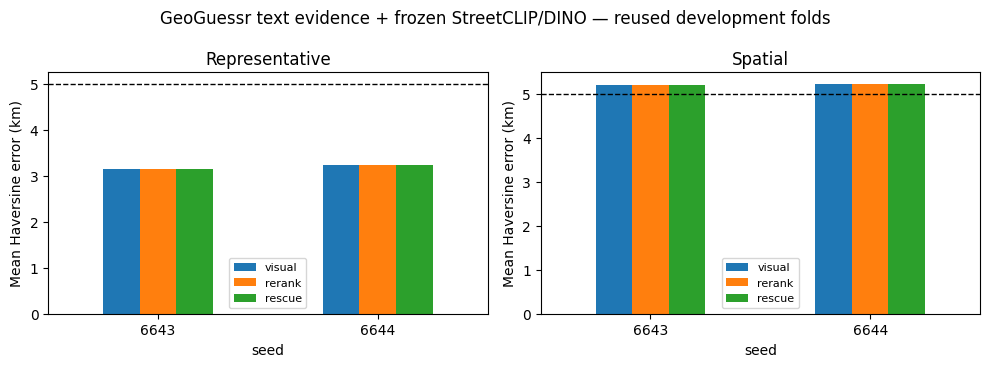

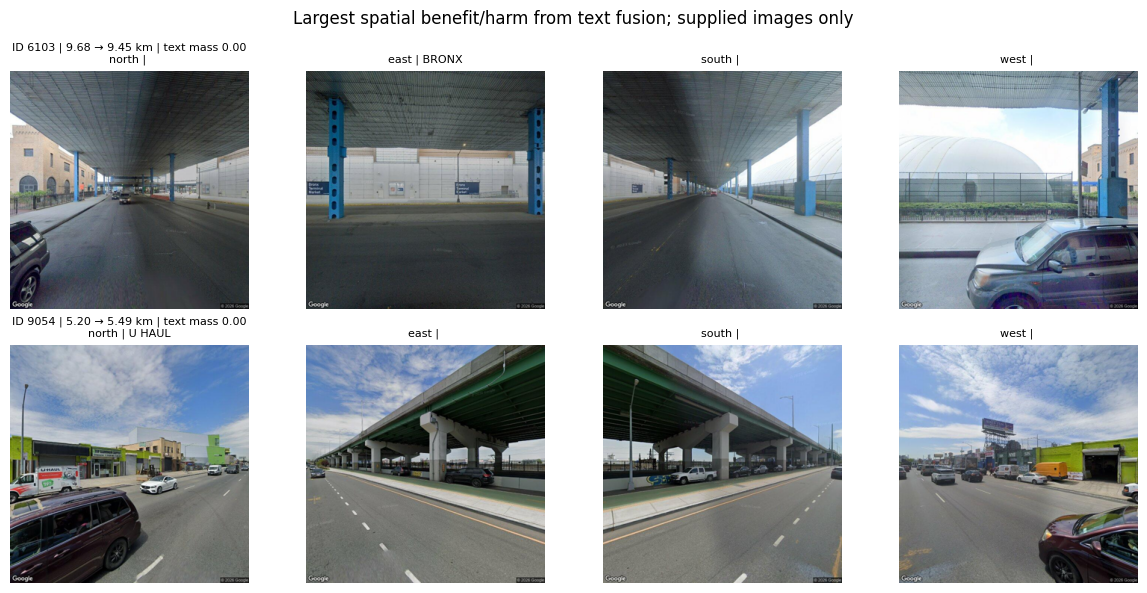

In [74]:
# Cell182 — Progress dashboard, ablations, tail risk and concrete clue successes/failures.
if (GEOSKILLS_HOME/'latest_study.json').exists():
    pointer=json.loads((GEOSKILLS_HOME/'latest_study.json').read_text());report=json.loads((ROOT/pointer['decision']).read_text())
    metrics=pd.DataFrame([{k:r[k] for k in ('method','split','seed','score','mean_km','median_km','p90_km','borough_macro_f1','changed_over_10m','helped_over_10m','harmed_over_10m')} for r in report['records']])
    display(metrics);print('Acceptance:',json.dumps(report['decisions']),'Public score: unknown')
    fig,axes=plt.subplots(1,2,figsize=(10,3.7))
    for ax,split in zip(axes,('representative','spatial')):
        table=metrics[metrics.split==split].pivot(index='seed',columns='method',values='mean_km')
        table[['visual','rerank','rescue']].plot.bar(ax=ax)
        ax.axhline(5,color='black',linestyle='--',linewidth=1);ax.set_title(split.capitalize());ax.set_ylabel('Mean Haversine error (km)');ax.tick_params(axis='x',rotation=0)
        ax.legend(fontsize=8)
    fig.suptitle('GeoGuessr text evidence + frozen StreetCLIP/DINO — reused development folds')
    fig.tight_layout();display(fig);plt.close(fig)
    # Show actual largest benefit and harm after predictions are frozen; no manual corrections.
    frame,_=load_data(ROOT);directory=ROOT/report['directory'];case='spatial_s6643';run=directory/case
    visual=pd.read_csv(run/'validation_visual.csv');rescue=pd.read_csv(run/'validation_rescue.csv');truth=frame.loc[rescue.sample_id]
    before=haversine_km(truth[['latitude','longitude']],visual[['latitude','longitude']]);after=haversine_km(truth[['latitude','longitude']],rescue[['latitude','longitude']])
    evidence=json.loads((run/'diagnostics_rescue.json').read_text());difference=after-before
    sample_positions=sorted(set([int(difference.argmin()),int(difference.argmax())]))
    fig,axes=plt.subplots(len(sample_positions),4,figsize=(12,3*len(sample_positions)),squeeze=False)
    for line,position in enumerate(sample_positions):
        i=int(rescue.sample_id.iloc[position]);example=evidence[position]
        for column,direction in enumerate(DIRECTIONS):
            ax=axes[line,column]
            with Image.open(ROOT/'Data/train'/frame.loc[i,f'image_{direction}']) as image:ax.imshow(image.resize((320,320)))
            lines=[x['recognized_line'] for x in example['evidence'] if direction in x['views']]
            ax.set_title(direction+' | '+', '.join(lines)[:48],fontsize=8);ax.axis('off')
        axes[line,0].set_title(f'ID {i} | {before[position]:.2f} → {after[position]:.2f} km | text mass {example["text_mass"]:.2f}\n'+axes[line,0].get_title(),fontsize=8)
    fig.suptitle('Largest spatial benefit/harm from text fusion; supplied images only')
    fig.tight_layout();display(fig);plt.close(fig)
else:print('No completed GeoGuessr evidence study yet.')


## GeoGuessr evidence study complete — no material accuracy gain

Research/formal method, perception, ablations and replay are complete. All active code stays in this notebook, cells174–184. Broad scene priors and directional visual comparison were already implemented; the new component is fold-local written-clue evidence and corroboration. It does **not** automate every skill used by human players.

47,456fast OCR requests +3,703label-free accurate refinements cost617.6759s including benchmarks (30-minute cap). Usable nonoverlay text survives at1,379/11,864locations (**11.62%**). Representative/spatial validation has299/301locations with text, but only80/61 with reliable gallery matches (**3.37%/2.52%**). No new head training, external data, package install or model download.

| Method | Rep6643 mean km | Spatial6643 mean km | Rep6644 mean km | Spatial6644 mean km |
|---|---:|---:|---:|---:|
| Frozen pooled ViT visual replay |3.144364|5.212053|3.244380|5.234966|
| Training-only text rerank |3.144358|5.212067|3.244423|5.234953|
| Rerank +corroborated text recovery |3.144358|5.212017|3.244423|5.234825|

Text recovery changes>10m for only5/4/5/5queries respectively; at seed6643spatial,3help and1hurts. Its paired spatial error-reduction95%intervals are[-.000332,.000317]km and[-.000025,.000448]km. Both contain zero. Representative6644regresses slightly; neither spatial mean reaches5km. The microscopic changes are not a meaningful score gain. Representative v2 scores stay about.41784/.39973; spatial.07724/.07630 (GPS term0). These describe the experimental pooled baseline, **not** a changed production model or public result.

**Decision:** reject this conservative text addition as a score improvement. Preserve code, negative evidence and all caches; selected production hybrid/CSV are unchanged. The assumption that sparse exact text matches would address the main tail was not supported. One-word matches and repeated business/destination signs can be ambiguous; visual inspection of largest changes includes a borough word and a repeated commercial name. Do not loosen thresholds after viewing outer validation or turn online clues into outside location data. A separate read-only diagnostic below quantifies text-candidate quality using held-out GPS strictly after predictions are frozen.

Verification:6new synthetic tests;173saved-artifact checks including12full validation-set replays, original fold/buffer membership, real query-label perturbation invariance, exact absent-text fallback (within numerical tolerance), hashes and unchanged production CSV. Targeted fresh-kernel execution passed; this is not an entire historical-notebook restart-and-run-all. The native OCR cache is reproducible from recorded OS/request revision/source/inputs, but Apple's built-in weights are not independently hash-addressable and extraction is macOS-only. HPC can consume the recorded text cache.

**Single next proposed experiment:** dense local ViT patch matching of architecture, road structure and signs with rarity learned from training galleries. This would test a broader human-style visual clue mechanism. Existing DINO caches hold only CLS+4coarse pooled regions per view; they are not dense patch grids. Benchmark runtime/storage on a small batch first; no new extraction or model experiment is authorized by merely recording this recommendation. Public score for the selected hybrid CSV remains unknown.

**Postprediction candidate diagnosis (seed6643):** among only80representative/61spatial queries with a reliable text match, text top1 mean error is10.858/10.273km; just2/80 and1/61 are within1km. Even a true-label oracle choosing among32text candidates finds a within1km match for only10/80 and1/61. These are conditional diagnostic statistics, not full-fold model scores or an inference mechanism. The text candidates themselves have poor location specificity; simply increasing text mass is unsupported.


In [75]:
# Cell184 — Postprediction text-candidate audit; query GPS is diagnostic ONLY.
def geoskills_diagnosis():
    """Never called from inference/calibration. Oracle distances must not become features."""
    frame,docs,pool,identity,ocr=geoskills_sources();pointer=json.loads((GEOSKILLS_HOME/'latest_study.json').read_text())
    report=json.loads((ROOT/pointer['decision']).read_text());directory=ROOT/report['directory'];rows=[]
    for name in ('representative','spatial'):
        case=f'{name}_s6643';bundle,_=geoskills_load_bundle(pool,case)
        index=geoskills_fit_index(frame.loc[bundle['reference_ids']],docs,bundle['geography']['origin'])
        top_error=[];best_error=[];eligible=0
        for q in bundle['query_ids']:
            score,support,phrase,_=geoskills_query_evidence(index,int(q),docs[int(q)])
            order=np.argsort(-score,kind='stable');order=order[score[order]>.05][:32]
            if len(order)==0:continue
            ids=index['reference_ids'][order];truth=np.repeat(frame.loc[[q],['latitude','longitude']].to_numpy(),len(ids),axis=0)
            distances=haversine_km(truth,frame.loc[ids,['latitude','longitude']].to_numpy())
            top_error.append(float(distances[0]));best_error.append(float(distances.min()))
            eligible+=int(len(order)>=2 and (support[order[0]]>=2 or phrase[order[0]]))
        row={'split':name,'seed':6643,'query_count':len(bundle['query_ids']),'text_matched_queries':len(top_error),
            'text_top1_mean_km':float(np.mean(top_error)) if top_error else None,
            'text_top1_within1km_fraction':float((np.asarray(top_error)<1).mean()) if top_error else None,
            'text_top32_oracle_within1km_fraction':float((np.asarray(best_error)<1).mean()) if top_error else None,
            'at_least2gallery_candidates_with_phrase_or_multiline':eligible,
            'scope':'Conditioned on matched text only; postprediction oracle, NOT a usable prediction or full-validation metric.'}
        rows.append(row)
    result={'diagnostics':rows,'inference_uses_query_labels':False,'production_changed':False,
        'interpretation':'Measured usable-text coverage and exact-gallery match coverage are sparse. This experiment cannot establish that broader human clue reasoning is ineffective.',
        'next_single_proposed_experiment':'Dense local DINO patch matching for buildings, road geometry and signs, with discriminativeness learned from training galleries; benchmark memory/runtime before any extraction.'}
    dino_json(directory/'diagnosis.json',result);display(pd.DataFrame(rows));return result

if (GEOSKILLS_HOME/'latest_study.json').exists():GEOSKILLS_DIAGNOSIS=geoskills_diagnosis()
else:print('Text-candidate diagnosis awaits frozen validation predictions.')


,split,seed,query_count,text_matched_queries,text_top1_mean_km,text_top1_within1km_fraction,text_top32_oracle_within1km_fraction,at_least2gallery_candidates_with_phrase_or_multiline,scope
0,representative,6643,2372,80,10.858197,0.025000,0.125000,16,Conditioned on matched text only; postpredicti...
1,spatial,6643,2421,61,10.272640,0.016393,0.016393,11,Conditioned on matched text only; postpredicti...
